# Moneyball — Player Value Forecasts & Roster Decisions

**Research appendix · data-to-decision study**  
Start with [`01_Moneyball_Main_Research.ipynb`](01_Moneyball_Main_Research.ipynb) and the [repository README](../README.md). This technical notebook preserves the original model/solver execution order; it is not a standalone collection of independently runnable cells.

**Question:** Does lower next-season WAR forecast error translate into higher realized WAR for historical eight-hitter rosters under salary and defensive-position constraints?

**Scope:** Retrospective historical simulation, not verified acquisition advice. The selected players were not certified to be available for purchase at their observed target-season salaries.

**Reproducibility:** Stored figures and tables are **archived original-run outputs**; the edited notebook has not been independently rerun with authenticated MLB inputs. Changing a source cell does not turn downstream cached outputs into new results. See [`docs/VALIDATION.md`](../docs/VALIDATION.md).


## Evidence status

| Component | Existing research evidence | Verification boundary |
|---|---|---|
| Forecast comparison | Cached 2013–2025 observable next-WAR results (4,061 of 4,377) | Development-informed historical evaluation; not a newly untouched holdout |
| Roster decisions | Cached eight-season spend-matched comparisons | Retrospective player pool; acquisition feasible status unknown |
| Position sensitivity | Section 168 cached 144-grid / 12-DH aggregate outputs | Full physical detail CSVs not provided with this notebook |
| Audit A–D | Original-run audit outputs retained | Internal checks; not publisher source certification |
| Utility C | Input and arithmetic validation code strengthened in this GitHub edition | Needs actual MLB rerun; prior cache removed for modified cell |
| Utility E | `OPTIONAL_NOT_RUN` | Fresh 156-scenario role replay still pending |
| R parity / 2026 outcomes / contract status | Code and audit gates exist | Not independently verified |

**Data:** Raw MLB files, source URLs, access dates and trusted reference hashes must be supplied separately. The repository does **not** include proprietary or large MLB data.


## Execution order

The cells share data, variables, forecasts, optimization objects, and prior-year eligibility rules. **Run top to bottom** after placing data in `data/raw/` or setting `MONEYBALL_DATA_DIR`. Caching of results from past research does not certify a new execution. Outputs go to `outputs/` or `MONEYBALL_OUTPUT_DIR`.

The default pipeline is computationally expensive (including optional Retrosheet play-by-play). Do not run the extra 156-scenario Utility E solver replay unless needed; set `MONEYBALL_RUN_ROLE_REPLAY=1` explicitly. Review `docs/RUN_GUIDE.md` for data dependencies and reproducibility boundaries.


In [1]:
# --- Configuration: local sources, plain CSV preferred to older ZIP snapshots ---
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Embed plots in the saved Notebook and keep notebook images visible on GitHub.
from IPython import get_ipython
_ipy = get_ipython()
if _ipy is not None:
    _ipy.run_line_magic("matplotlib", "inline")

# Portable repository paths. Override with absolute paths when data lives elsewhere.
# Start Jupyter at the repository root (recommended) or from notebooks/.
_WORKDIR = Path.cwd().resolve()
_PROJECT_ROOT = _WORKDIR.parent if _WORKDIR.name == "notebooks" else _WORKDIR
DATA_DIR = Path(os.environ.get("MONEYBALL_DATA_DIR", str(_PROJECT_ROOT / "data" / "raw"))).expanduser()
OUTPUT_ROOT = Path(os.environ.get("MONEYBALL_OUTPUT_DIR", str(_PROJECT_ROOT / "outputs"))).expanduser()
PROCESSED = OUTPUT_ROOT / "processed"
VISUALS = OUTPUT_ROOT / "visuals"

FEATURES = ['OBP', 'SLG', 'ISO', 'BB_rate', 'SO_rate', 'PA', 'age']
SIMILARITY_FEATURES = ['OBP', 'SLG', 'ISO', 'BB_rate', 'SO_rate']

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 170,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titleweight": "bold",
    "axes.labelcolor": "#273547",
})


def load_raw():
    """Load all 4 original sources from DATA_DIR, accepting zipped or plain CSVs."""
    if not DATA_DIR.is_dir():
        raise FileNotFoundError(
            f"Data directory not found: {DATA_DIR}\n"
            "Set MONEYBALL_DATA_DIR or place the source files under data/raw/."
        )

    def csv(name, encoding="utf-8"):
        candidates = (DATA_DIR / f"{name}.csv", DATA_DIR / f"{name}.csv.zip")
        selected = next((p for p in candidates if p.is_file()), None)
        if selected is None:
            raise FileNotFoundError(
                f"Missing {name} data in {DATA_DIR}. Expected one of: "
                + ", ".join(p.name for p in candidates)
            )
        return pd.read_csv(selected, encoding=encoding, low_memory=False)

    master = csv('Master', encoding='latin1')
    people_path = DATA_DIR / 'People.csv'
    if people_path.is_file():
        newer_people = pd.read_csv(people_path, low_memory=False, encoding='utf-8-sig')
        newer_people.columns = newer_people.columns.str.replace('\ufeff','',regex=False).str.strip()
        if {'playerID', 'nameFirst', 'nameLast', 'birthYear', 'bats'}.issubset(newer_people.columns):
            # Keep historical Master identity and add genuinely new player IDs.
            # This can support post-2012 Batting coverage without inventing ages.
            additional = newer_people.loc[~newer_people.playerID.isin(master.playerID)]
            master = pd.concat([master, additional.reindex(columns=master.columns)], ignore_index=True)
    return {
        'batting': csv('Batting'),
        'master': master,
        'salaries': csv('Salaries'),
        'teams': csv('Teams'),
    }


### Output location

New output tables and figures are written outside the tracked notebooks under `outputs/`. Set `MONEYBALL_OUTPUT_DIR` or `MONEYBALL_EVIDENCE_EXPORT_DIR` to override. Raw source files are never committed to this repository.


In [2]:
# Centralize newly generated evidence, not historical source files.
from pathlib import Path
import os
if 'OUTPUT_ROOT' not in globals():
    raise RuntimeError('Run the original configuration cell before setting output defaults')
EVIDENCE_EXPORT_ROOT = Path(os.environ.get(
    'MONEYBALL_EVIDENCE_EXPORT_DIR', str(Path(OUTPUT_ROOT) / 'evidence_audit'))).expanduser()
os.environ.setdefault('MONEYBALL_EVIDENCE_EXPORT_DIR', str(EVIDENCE_EXPORT_ROOT))
# This cell deliberately creates no output or files until a requested export runs.


'C:\\Users\\htpar\\Downloads\\outputs\\evidence_audit'

## Reading tables and figures

Prediction errors are reported in their original units, with **lower values indicating more accurate forecasts**. When model scores are close, signed differences and precise labels are provided; a zero reference line means no improvement. Graphs using a restricted axis explicitly identify the expanded scale. The zero baseline is retained for counts, probabilities and other measures where the absolute level matters.

Prediction-interval coverage is the share of *observed* outcomes inside the interval; width is the span of that interval in bWAR. Higher coverage can result simply from a wider interval, so the two must be interpreted together. Uncertainty estimates depend on their sampling assumptions, and season-level comparisons are particularly relevant when players face the same annual conditions.

Figures and CSV exports are generated from the underlying analysis when the Notebook runs. The final status table distinguishes executed code from completed, data-supported evaluations.


## Reusable data preparation functions

The functions below are included in this notebook so the analysis runs independently of the earlier five notebooks or the `src/` folder.


In [3]:
from pathlib import Path
import numpy as np


# Original Moneyball dataset location
DATA_DIR = Path(r"I:\Dataset\Moneyball Analysis")

# Required source files
REQUIRED_FILES = [
    "Batting.csv",
    "Master.csv",
    "Salaries.csv",
    "Teams.csv",
]

# Verify dataset directory
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Dataset directory not found: {DATA_DIR}"
    )

# Verify required files
missing_files = [
    name for name in REQUIRED_FILES
    if not (DATA_DIR / name).is_file()
]

if missing_files:
    raise FileNotFoundError(
        f"Missing source files: {missing_files}\n"
        f"Expected directory: {DATA_DIR}"
    )

print(f"Dataset directory: {DATA_DIR}")
print("All required source files found.")

# Preserve existing output locations when configured earlier
PROCESSED = Path(
    globals().get(
        "PROCESSED",
        Path.cwd() / "data" / "processed"
    )
)

VISUALS = Path(
    globals().get(
        "VISUALS",
        Path.cwd() / "outputs" / "visuals"
    )
)

def safe_div(numerator, denominator):
    """Divide safely, returning NaN for zero denominators."""
    return numerator / denominator.replace(0, np.nan)

def player_seasons(raw):
    """
    Aggregate batting statistics by player and season.

    Multiple stints are combined before calculating rates.
    Missing HBP, SF, and SH counts are treated as zero.
    Plate appearances are approximated as AB + BB + HBP + SF + SH.
    """

    b = raw["batting"].copy()

    numeric = [
        "AB", "H", "2B", "3B", "HR",
        "BB", "SO", "HBP", "SF", "SH",
        "SB", "CS", "G", "R"
    ]

    b[numeric] = b[numeric].fillna(0)

    season = (
        b.groupby(
            ["playerID", "yearID"],
            as_index=False
        )[numeric]
        .sum()
    )

    # Plate appearances
    season["PA"] = season[
        ["AB", "BB", "HBP", "SF", "SH"]
    ].sum(axis=1)

    # On-base percentage
    season["OBP"] = safe_div(
        season["H"] + season["BB"] + season["HBP"],
        season["AB"] + season["BB"] +
        season["HBP"] + season["SF"]
    )

    # Singles
    singles = (
        season["H"]
        - season["2B"]
        - season["3B"]
        - season["HR"]
    )

    # Slugging percentage
    season["SLG"] = safe_div(
        singles
        + 2 * season["2B"]
        + 3 * season["3B"]
        + 4 * season["HR"],
        season["AB"]
    )

    # Batting average and isolated power
    season["AVG"] = safe_div(
        season["H"],
        season["AB"]
    )

    season["ISO"] = season["SLG"] - season["AVG"]

    # Walk and strikeout rates
    season["BB_rate"] = safe_div(
        season["BB"],
        season["PA"]
    )

    season["SO_rate"] = safe_div(
        season["SO"],
        season["PA"]
    )

    # Player information
    names = (
        raw["master"][
            [
                "playerID",
                "nameFirst",
                "nameLast",
                "birthYear",
                "bats"
            ]
        ]
        .drop_duplicates("playerID")
    )

    season = season.merge(
        names,
        on="playerID",
        how="left",
        validate="many_to_one"
    )

    season["name"] = (
        season["nameFirst"].fillna("")
        + " "
        + season["nameLast"].fillna("")
    ).str.strip()

    season["age"] = (
        season["yearID"] - season["birthYear"]
    )

    return season

def player_salaries(raw):
    """
    Use the maximum recorded salary per player-year.

    This is a historical salary proxy, not necessarily
    the player's actual annual cash compensation.
    """

    return (
        raw["salaries"]
        .groupby(
            ["playerID", "yearID"],
            as_index=False
        )["salary"]
        .max()
        .rename(
            columns={"salary": "player_salary"}
        )
    )

def team_seasons(raw):
    """
    Construct team-year payroll and performance measures.

    Missing team HBP/SF values are not replaced with zero.
    Payroll reflects recorded salaries, not total labor cost.
    """

    t = raw["teams"].copy()

    payroll = (
        raw["salaries"]
        .groupby(
            ["yearID", "teamID"],
            as_index=False
        )["salary"]
        .sum()
        .rename(
            columns={"salary": "payroll"}
        )
    )

    t = t.merge(
        payroll,
        on=["yearID", "teamID"],
        how="left",
        validate="one_to_one"
    )

    # Team on-base percentage
    t["OBP"] = safe_div(
        t["H"] + t["BB"] + t["HBP"],
        t["AB"] + t["BB"] + t["HBP"] + t["SF"]
    )

    # Winning percentage
    t["win_pct"] = safe_div(
        t["W"],
        t["W"] + t["L"]
    )

    # Payroll efficiency
    t["wins_per_million"] = safe_div(
        t["W"],
        t["payroll"] / 1e6
    )

    t["payroll_millions"] = t["payroll"] / 1e6

    return t

def eligible_player_pool(
    raw,
    historical_year=2001,
    salary_year=2002,
    min_pa=300
):
    """
    Select players based on historical batting performance
    and recorded salary in the target year.

    Target-year salary is used for historical simulation;
    it does not establish real-world acquisition availability.
    """

    p = player_seasons(raw)
    s = player_salaries(raw)

    pool = (
        p[
            p["yearID"].eq(historical_year)
            & p["PA"].ge(min_pa)
        ]
        .merge(
            s[
                s["yearID"].eq(salary_year)
            ][["playerID", "player_salary"]],
            on="playerID",
            how="inner",
            validate="one_to_one"
        )
    )

    return pool.dropna(
        subset=SIMILARITY_FEATURES
    ).copy()

def future_panel(
    raw,
    first_feature_year=2000,
    last_feature_year=2011,
    min_pa=300
):
    """
    Construct one-year-ahead OBP evaluation data.

    Both feature-year and target-year PA must meet min_pa.
    This introduces a documented survivorship bias.
    Salary is not used as a performance prediction feature.
    """

    p = player_seasons(raw)
    s = player_salaries(raw)

    # Current-season features
    current = p.loc[
        p["yearID"].between(
            first_feature_year,
            last_feature_year
        )
        & p["PA"].ge(min_pa),
        ["playerID", "yearID", "name"] + FEATURES
    ].copy()

    # Next-season outcomes
    target = p[
        [
            "playerID",
            "yearID",
            "PA",
            "OBP",
            "SLG"
        ]
    ].copy()

    target["yearID"] -= 1

    target = target.rename(
        columns={
            "PA": "next_PA",
            "OBP": "next_OBP",
            "SLG": "next_SLG"
        }
    )

    panel = current.merge(
        target,
        on=["playerID", "yearID"],
        how="inner",
        validate="one_to_one"
    )

    # Require sufficient playing time next season
    panel = panel[
        panel["next_PA"].ge(min_pa)
    ].copy()

    # Align next-season salary
    sal = s.copy()
    sal["yearID"] -= 1

    panel = panel.merge(
        sal,
        on=["playerID", "yearID"],
        how="inner",
        validate="one_to_one"
    )

    return (
        panel
        .dropna(
            subset=FEATURES + [
                "next_OBP",
                "player_salary"
            ]
        )
        .reset_index(drop=True)
    )

def save_frame(df, name):
    """Save a DataFrame to the processed-data directory."""

    PROCESSED.mkdir(
        parents=True,
        exist_ok=True
    )

    dest = PROCESSED / name

    df.to_csv(
        dest,
        index=False
    )

    return dest

# load_raw() is defined in the earlier setup cell.
raw = load_raw()

# Create output directories
PROCESSED.mkdir(
    parents=True,
    exist_ok=True
)

VISUALS.mkdir(
    parents=True,
    exist_ok=True
)

print("\nMoneyball data loaded successfully.")
print(f"Processed data directory: {PROCESSED}")
print(f"Visual output directory: {VISUALS}")

print("\nLoaded datasets:")

for name, df in raw.items():
    print(f"  {name}: {len(df):,} rows")


Dataset directory: I:\Dataset\Moneyball Analysis
All required source files found.

Moneyball data loaded successfully.
Processed data directory: C:\Users\htpar\Downloads\outputs\processed
Visual output directory: C:\Users\htpar\Downloads\outputs\visuals

Loaded datasets:
  batting: 96,600 rows
  master: 24,453 rows
  salaries: 23,141 rows
  teams: 2,715 rows


## 1. Data preparation and quality audit


**Question:** Can season-level records link season batting, roster salary and team performance?  
**Source:** Four supplied Lahman snapshot files through 2012.  
**Output:** normalized team-year and player-year CSVs; reproducible data-quality checks.  
**Important:** team OBP before 2000 is unavailable from the `Teams` source because HBP and SF are missing; missing values are not filled missing season components with zero.


# Part 01 · Historical data, team context and Moneyball baseline

*Technical execution sequence is unchanged. See `01_Moneyball_Main_Research.ipynb` for a topical, reduced presentation.*


## Source coverage and join keys

- `Batting`: multiple player–season rows for trades; aggregate all batting counts **before** computing rates.
- `Master`: lookup by `playerID`; source CSV requires `latin1` decoding.
- `Salaries`: salary by team–player–season; trade-years can have multiple rows. Team payroll sums recorded rows; individual salary uses maximum recorded row as a **proxy**, not actual total compensation.
- `Teams`: one row per `teamID` and `yearID`; seasons through 2012.


In [4]:
for name, frame in raw.items():
    print(f"{name:<9} {len(frame):>7,} rows | {len(frame.columns):>2} cols")
    if 'yearID' in frame.columns:
        print(f"    Years: {frame.yearID.min()}–{frame.yearID.max()}")
print("Player/year duplicates in raw batting:", raw['batting'].duplicated(['playerID','yearID']).sum())
print("Player/year duplicates in salaries:", raw['salaries'].duplicated(['playerID','yearID']).sum())
print("Missing TEAM HBP/SF before 2000:")
print(raw['teams'].loc[raw['teams'].yearID.between(1985,1999), ['HBP','SF']].isna().mean().to_string())

batting    96,600 rows | 24 cols
    Years: 1871–2012
master     24,453 rows | 33 cols
salaries   23,141 rows |  5 cols
    Years: 1985–2012
teams       2,715 rows | 48 cols
    Years: 1871–2012
Player/year duplicates in raw batting: 7000
Player/year duplicates in salaries: 103
Missing TEAM HBP/SF before 2000:
HBP    1.0
SF     1.0


In [5]:
players = player_seasons(raw)
player_salary = player_salaries(raw)
teams = team_seasons(raw)
assert not players.duplicated(['playerID','yearID']).any()
assert not teams.duplicated(['teamID','yearID']).any()
assert raw['salaries']['yearID'].max() == 2012
assert teams.loc[teams.yearID==2002, 'OBP'].notna().all()
assert teams.loc[teams.yearID==1995, 'OBP'].isna().all()
print('Prepared player-seasons:',players.shape)
print('Prepared team-seasons:',teams.shape)
print('Player salary year rows:',player_salary.shape)
print('2002 team salaries present:',teams.loc[teams.yearID.eq(2002),'payroll'].notna().sum())

Prepared player-seasons: (89600, 29)
Prepared team-seasons: (2715, 53)
Player salary year rows: (23038, 3)
2002 team salaries present: 30


In [6]:
save_frame(teams, 'team_seasons.csv')
save_frame(players, 'player_seasons.csv')
save_frame(player_salary, 'player_salaries.csv')
quality = pd.DataFrame([
    {'table':name,'rows':len(f),'columns':len(f.columns),'year_min':f.yearID.min() if 'yearID' in f else np.nan,
     'year_max':f.yearID.max() if 'yearID' in f else np.nan}
    for name,f in raw.items()
])
save_frame(quality, 'data_profile.csv')
print('Processed files exported to data/processed/')
display(quality)

Processed files exported to data/processed/


,table,rows,columns,year_min,year_max
0,batting,96600,24,1871.0,2012.0
1,master,24453,33,NaN,NaN
2,salaries,23141,5,1985.0,2012.0
3,teams,2715,48,1871.0,2012.0


### Interpretation

A player can appear in multiple team rows per season. This is not an erroneous duplicate. Collapsing player stints before computing OBP/SLG avoids double-counting rates. Retain raw input files so each transformation is auditable. Historical data and approximate PA do not include every MLB scoring nuance.


## 2. OBP, runs scored, and wins


**Question:** Was on-base percentage associated with run scoring and wins in the 2000–2012 sample?  
**Method:** cross-sectional correlations, 2002 scatter, and season-by-season robustness checks.  
**Restriction:** use 2000–2012 because team-level HBP/SF are not complete prior to 2000.


In [7]:
from scipy.stats import pearsonr
teams = team_seasons(raw)
t = teams[teams.yearID.between(2000,2012) & teams.OBP.notna()].copy()
o = t[t.yearID==2002].copy()
r_runs, p_runs = pearsonr(o.OBP,o.R)
r_win, p_win = pearsonr(o.OBP,o.win_pct)
print(f"2002 OBP–runs: Pearson r={r_runs:.3f}, p={p_runs:.4g}, n={len(o)}")
print(f"2002 OBP–win%: Pearson r={r_win:.3f}, p={p_win:.4g}, n={len(o)}")
display(o.loc[o.teamID=='OAK',['name','W','R','OBP','win_pct','payroll']])

2002 OBP–runs: Pearson r=0.832, p=1.217e-08, n=30
2002 OBP–win%: Pearson r=0.763, p=9.707e-07, n=30


,name,W,R,OBP,win_pct,payroll
2394,Oakland Athletics,103,800,0.33918,0.635802,40004167.0


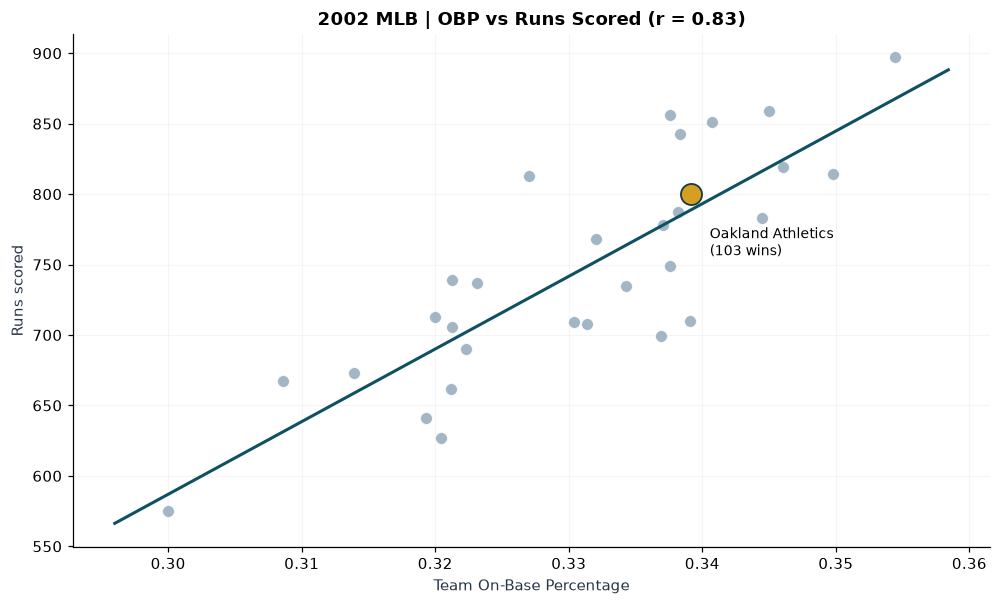

In [8]:
fig,ax=plt.subplots(figsize=(9.2,5.6))
ax.scatter(o.OBP,o.R, s=60, color='#92a9bc',alpha=.85,edgecolor='white',linewidth=.5)
m,b=np.polyfit(o.OBP,o.R,1)
xs=np.linspace(o.OBP.min()-.004,o.OBP.max()+.004,100)
ax.plot(xs,m*xs+b,color='#0f5063',lw=2)
a=o[o.teamID=='OAK'].iloc[0]
ax.scatter(a.OBP,a.R,s=190,color='#d5a021',edgecolor='#183b40',linewidth=1.2,zorder=4)
ax.annotate('Oakland Athletics\n(103 wins)',(a.OBP,a.R),xytext=(12,-40),textcoords='offset points',fontsize=9)
ax.set(title=f'2002 MLB | OBP vs Runs Scored (r = {r_runs:.2f})',xlabel='Team On-Base Percentage',ylabel='Runs scored')
ax.grid(alpha=.12)
fig.tight_layout()
fig.savefig(VISUALS/'obp_vs_runs.png',bbox_inches='tight')
plt.show()

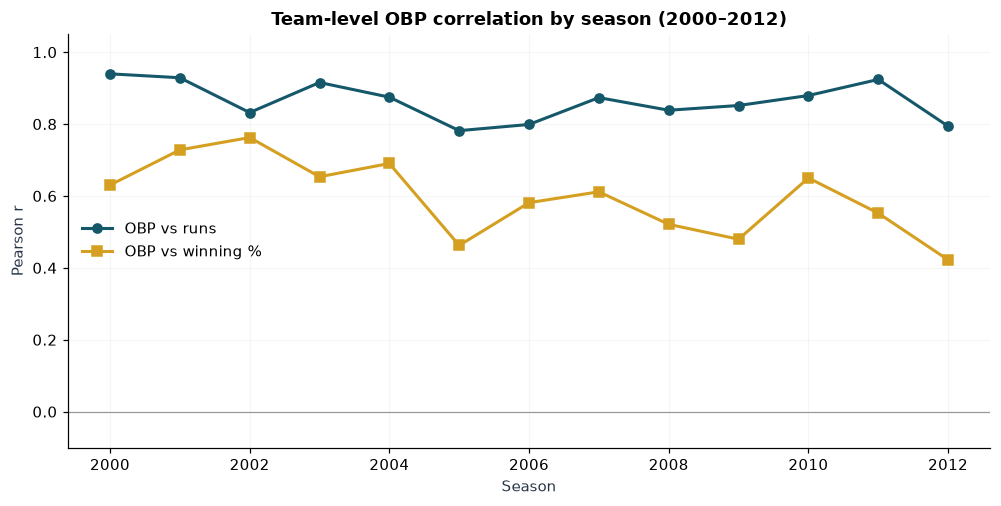

Median annual r for OBP / runs: 0.874


WindowsPath('C:/Users/htpar/Downloads/outputs/processed/yearly_obp_correlations.csv')

In [9]:
by_year=[]
for year,g in t.groupby('yearID'):
    if len(g)>=20:
        by_year.append({'yearID':year,'r_OBP_runs':pearsonr(g.OBP,g.R).statistic,
                        'r_OBP_wins':pearsonr(g.OBP,g.win_pct).statistic,'teams':len(g)})
yr=pd.DataFrame(by_year)
fig,ax=plt.subplots(figsize=(9.2,4.7))
ax.plot(yr.yearID,yr.r_OBP_runs,marker='o',lw=2,label='OBP vs runs',color='#14586a')
ax.plot(yr.yearID,yr.r_OBP_wins,marker='s',lw=2,label='OBP vs winning %',color='#d5a021')
ax.axhline(0,color='#999',lw=.8)
ax.set(xlabel='Season',ylabel='Pearson r',title='Team-level OBP correlation by season (2000–2012)',ylim=(-.1,1.05))
ax.set_xticks(yr.yearID[::2]);ax.legend(frameon=False);ax.grid(alpha=.12)
fig.tight_layout();fig.savefig(VISUALS/'obp_correlations_by_year.png',bbox_inches='tight');plt.show()
print('Median annual r for OBP / runs:',round(yr.r_OBP_runs.median(),3))
save_frame(yr,'yearly_obp_correlations.csv')

### Limitations

Correlation does not prove OBP *causes* wins. Runs involve slugging, pitching, defense, ballparks and schedule strength. Only a 2000–2012 historical snapshot is available; this does not establish whether Moneyball still works today.


## 3. Team payroll efficiency


**Question:** How much team performance did clubs record per payroll dollar in 2002?  
**Method:** 2002 payroll–wins scatter, labeled outliers and a simple efficiency ratio.  
**Caution:** wins per $1M is descriptive, not causal ROI; salary coverage is historical, non-inflation-adjusted and excludes many organizational costs.


In [10]:
from scipy.stats import pearsonr
team=team_seasons(raw)
o=team[(team.yearID==2002)&team.payroll.notna()].copy()
o['payroll_rank_low_to_high']=o.payroll.rank(method='min').astype(int)
o['efficiency_rank_high_to_low']=o.wins_per_million.rank(ascending=False,method='min').astype(int)
o=o.sort_values('wins_per_million',ascending=False)
a=o[o.teamID=='OAK'].iloc[0]
print(f"Oakland: {int(a.W)} wins; ${a.payroll:,.0f} payroll; {a.wins_per_million:.3f} wins per $1M")
print(f"2002 lowest-payroll rank: {int(a.payroll_rank_low_to_high)} of {len(o)}")
print(f"2002 efficiency rank: {int(a.efficiency_rank_high_to_low)} of {len(o)}")
display(o[['name','W','payroll_millions','wins_per_million','payroll_rank_low_to_high']].head(10).round(2))

Oakland: 103 wins; $40,004,167 payroll; 2.575 wins per $1M
2002 lowest-payroll rank: 3 of 30
2002 efficiency rank: 1 of 30


,name,W,payroll_millions,wins_per_million,payroll_rank_low_to_high
2394,Oakland Athletics,103,40.00,2.57,3
2392,Minnesota Twins,94,40.42,2.33,4
2408,Montreal Expos,83,38.67,2.15,2
2404,Florida Marlins,79,41.98,1.88,6
2402,Cincinnati Reds,78,45.05,1.73,8
2411,Pittsburgh Pirates,72,42.32,1.70,7
2385,Anaheim Angels,99,61.72,1.60,16
2396,Tampa Bay Devil Rays,55,34.38,1.60,1
2412,San Diego Padres,66,41.42,1.59,5
2388,Chicago White Sox,81,57.05,1.42,13


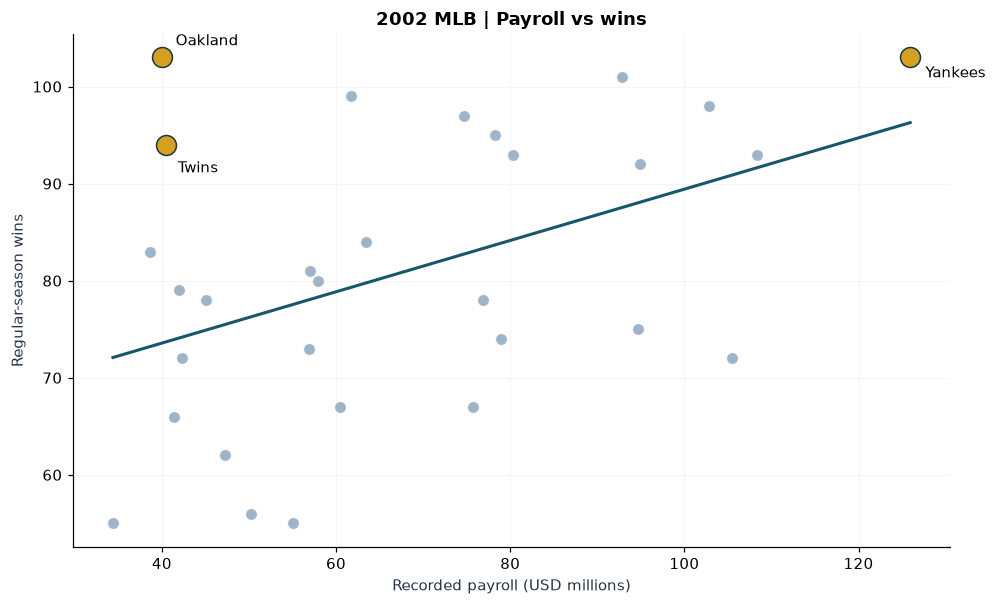

In [11]:
fig,ax=plt.subplots(figsize=(9.2,5.6))
ax.scatter(o.payroll_millions,o.W,color='#8ea8bd',alpha=.85,s=65,edgecolors='white')
coef=np.polyfit(o.payroll_millions,o.W,1)
x=np.linspace(o.payroll_millions.min(),o.payroll_millions.max(),100)
ax.plot(x,coef[0]*x+coef[1],color='#14586a',lw=2)
for club,label,offset in [('OAK','Oakland', (9,8)),('NYA','Yankees',(10,-13)),('MIN','Twins',(8,-18))]:
    g=o[o.teamID==club]
    if len(g):
        p=g.iloc[0]
        ax.scatter(p.payroll_millions,p.W,color='#d5a021',s=170,edgecolor='#183b40',zorder=5)
        ax.annotate(label,(p.payroll_millions,p.W),xytext=offset,textcoords='offset points')
ax.set(xlabel='Recorded payroll (USD millions)',ylabel='Regular-season wins',title='2002 MLB | Payroll vs wins')
ax.grid(alpha=.12)
fig.tight_layout();fig.savefig(VISUALS/'payroll_vs_wins.png',bbox_inches='tight');plt.show()

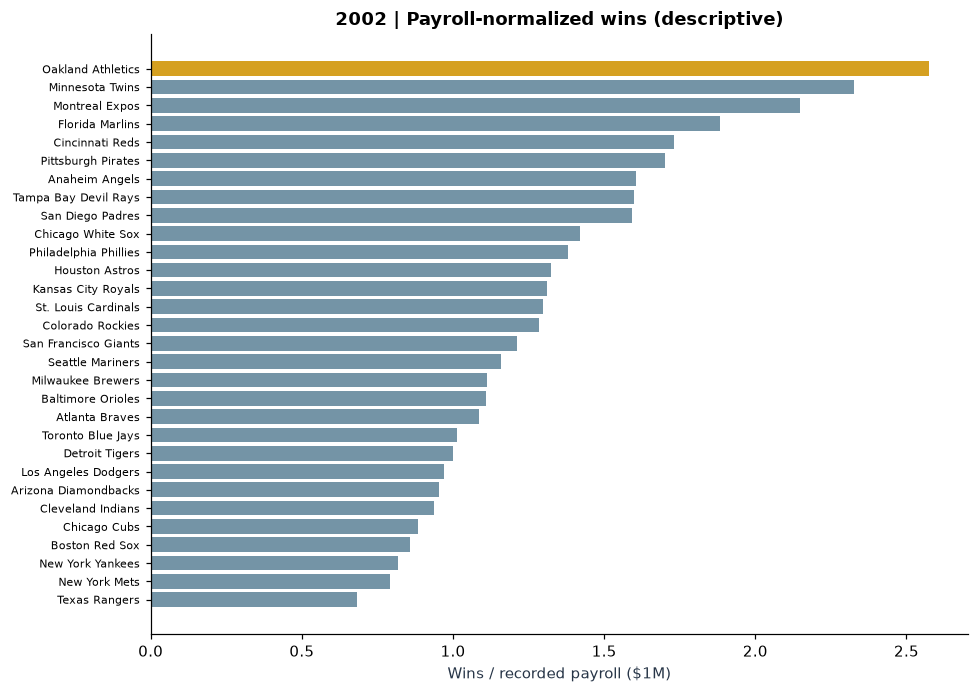

WindowsPath('C:/Users/htpar/Downloads/outputs/processed/team_salary_efficiency_2002.csv')

In [12]:
show=o.sort_values('wins_per_million',ascending=True)
fig,ax=plt.subplots(figsize=(9,6.4))
colors=['#d5a021' if x=='OAK' else '#7494a6' for x in show.teamID]
ax.barh(show.name,show.wins_per_million,color=colors)
ax.set(xlabel='Wins / recorded payroll ($1M)',title='2002 | Payroll-normalized wins (descriptive)')
ax.tick_params(axis='y',labelsize=7)
fig.tight_layout();fig.savefig(VISUALS/'salary_efficiency_2002.png',bbox_inches='tight');plt.show()
save_frame(o[['yearID','teamID','name','W','payroll','wins_per_million','payroll_rank_low_to_high','efficiency_rank_high_to_low']],
           'team_salary_efficiency_2002.csv')

### Interpretation

A team with inexpensive players and many wins has a high *observed* salary-efficiency ratio. It does not prove that the general manager could freely acquire another team's players, or that this metric alone describes roster quality, team chemistry or front-office skill.


## 4. Player similarity and salary dispersion


**Question:** Can the data identify batters with statistically similar offensive production but different listed salaries?  
**Historical decision frame:** 2001 batting features + 2002 salary rows only.  

**Retrospective price-information limitation:** the 2002 salary entries are realized *recorded salaries*, not documented offers available at the end of 2001. This exercise ranks historical combinations of earlier batting statistics and later listed compensation; it does not reconstruct what a club could actually have known, offered, or acquired before the 2002 season.

**Methods:** standardized features, K-Means clusters, nearest neighbors and MDS visualization (120 highest-PA players for legibility).


In [13]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.neighbors import NearestNeighbors
from sklearn.manifold import MDS
pool=eligible_player_pool(raw,2001,2002,min_pa=300)
print(f'Eligible 2001 regular hitters with 2002 salaries: {len(pool)}')
scaler=StandardScaler()
X=scaler.fit_transform(pool[SIMILARITY_FEATURES])
km=KMeans(n_clusters=4,random_state=42,n_init=10)
pool['cluster']=km.fit_predict(X)
display(pool.groupby('cluster').agg(players=('playerID','size'),median_OBP=('OBP','median'),median_salary=('player_salary','median')).round(3))

Eligible 2001 regular hitters with 2002 salaries: 249


,players,median_OBP,median_salary
cluster,,,
0,58,0.369,4125000.0
1,106,0.318,1514583.5
2,59,0.342,3000000.0
3,26,0.409,8387994.5


In [14]:
nn=NearestNeighbors(n_neighbors=min(6,len(pool)),metric='euclidean').fit(X)
# Use a named anchor if available; otherwise the highest-OBP eligible hitter.
anchor_id='eckstda01'
anchor_pos=np.flatnonzero(pool.playerID.to_numpy()==anchor_id)
if len(anchor_pos)==0:
    anchor_pos=np.array([int(np.argmax(pool.OBP.to_numpy()))])
anchor_pos=int(anchor_pos[0])
dist,idx=nn.kneighbors(X[anchor_pos].reshape(1,-1))
matched=pool.iloc[idx[0]][['name','OBP','SLG','BB_rate','SO_rate','player_salary']].copy()
matched['distance']=dist[0]
print('Anchor:',pool.iloc[anchor_pos]['name'])
display(matched.round(3))
save_frame(matched,'player_similarity_neighbors_2002.csv')

Anchor: David Eckstein


,name,OBP,SLG,BB_rate,SO_rate,player_salary,distance
63,David Eckstein,0.355,0.357,0.065,0.090,280000,0.000
141,Mark Loretta,0.346,0.352,0.065,0.107,5000000,0.437
123,Jason Kendall,0.335,0.358,0.065,0.071,6571429,0.705
150,Brent Mayne,0.334,0.344,0.072,0.114,2500000,0.789
96,Ricky Gutierrez,0.345,0.402,0.066,0.092,2166667,0.811
180,Placido Polanco,0.342,0.383,0.041,0.070,1750000,0.897


WindowsPath('C:/Users/htpar/Downloads/outputs/processed/player_similarity_neighbors_2002.csv')

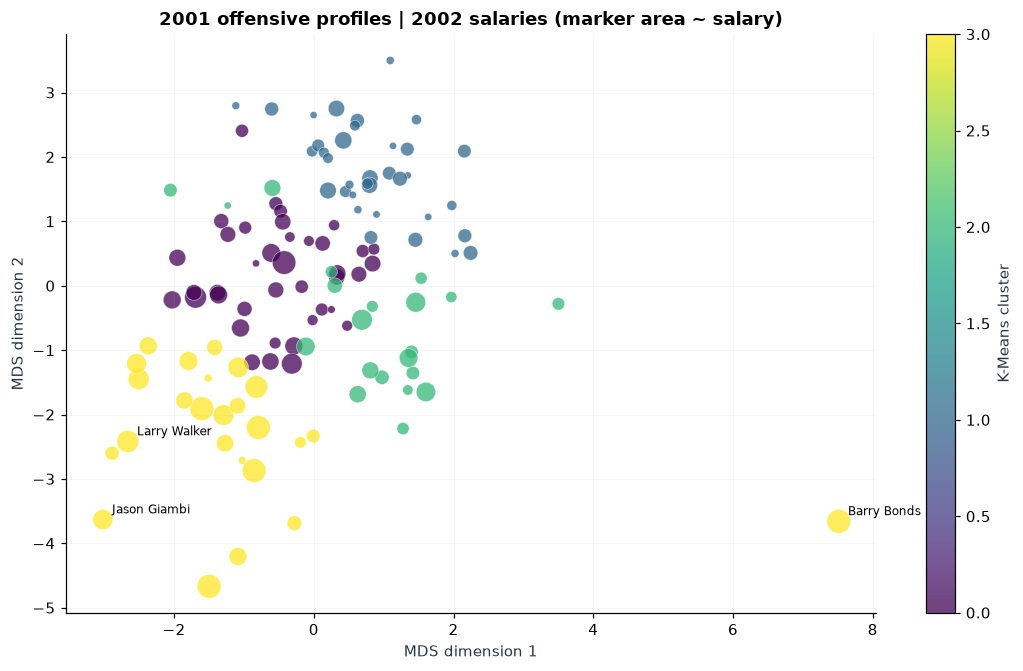

WindowsPath('C:/Users/htpar/Downloads/outputs/processed/player_similarity_mds_2002.csv')

In [15]:
# Fit MDS to 120 selected players for a readable 2D example; use all players for nearest-neighbor comparisons.
sub=pool.sort_values('PA',ascending=False).head(120).copy()
scaled=StandardScaler().fit_transform(sub[SIMILARITY_FEATURES])
coords=MDS(n_components=2,metric='euclidean',random_state=42,n_init=1,max_iter=200,init="random",eps=1e-3).fit_transform(scaled)
sub['mds_x']=coords[:,0];sub['mds_y']=coords[:,1]
fig,ax=plt.subplots(figsize=(10,6.2))
sc=ax.scatter(sub.mds_x,sub.mds_y,c=sub.cluster,cmap='viridis',alpha=.75,
              s=18+45*np.clip(sub.player_salary/3_000_000,0,5),edgecolor='white',linewidth=.35)
for _,r in sub.nlargest(3,'OBP').iterrows():
    ax.annotate(r['name'],(r.mds_x,r.mds_y),xytext=(6,4),textcoords='offset points',fontsize=8)
ax.set(xlabel='MDS dimension 1',ylabel='MDS dimension 2',title='2001 offensive profiles | 2002 salaries (marker area ~ salary)')
ax.grid(alpha=.1);fig.colorbar(sc,ax=ax,label='K-Means cluster')
fig.tight_layout();fig.savefig(VISUALS/'player_similarity.png',bbox_inches='tight');plt.show()
save_frame(sub[['playerID','name','PA','OBP','SLG','ISO','BB_rate','SO_rate','player_salary','cluster','mds_x','mds_y']],
           'player_similarity_mds_2002.csv')

### Reading the map

Proximity indicates similarity on **standardized selected batting metrics**, not identical player value. MDS axes have no direct baseball meaning. Clusters and chart coordinates describe the 2001 sample, not stable career archetypes. Salary circles represent recorded 2002 salary proxies; defense, injuries, position, service time and acquisition feasibility are not measured.


# Part 02 · Player WAR forecasting and uncertainty foundations

*Technical execution sequence is unchanged. See `01_Moneyball_Main_Research.ipynb` for a topical, reduced presentation.*


## 5. Value screening and out-of-time validation


**Question:** Which 2001 productive batters had modest listed 2002 salaries, and how well can year-*t* statistics anticipate year-*t+1* OBP?  
**Part A:** 2002 historical shortlist based on 2001 outcomes and 2002 salary only; 2002 batting appears **only** during hindsight evaluation.  

**Historical pricing caveat:** 2002 salaries are observed compensation records and may not have been known or negotiable at the 2001 decision date. The shortlist is a **retrospective descriptive screen**, not a point-in-time validated signing strategy. Recorded pay does not prove player availability, trade rights, acquisition cost, or contract terms.

**Part B:** out-of-time Ridge benchmark evaluated in 2011–2012 (train through 2010). The predictive model is **not** used to backfill a falsely contemporaneous 2002 model.


In [16]:
pool=eligible_player_pool(raw,2001,2002,min_pa=300)
shortlist=pool[(pool.OBP>.350)&(pool.player_salary<1_000_000)].copy()
# A transparent screening heuristic; not a probabilistic performance prediction.
shortlist['screen_score']=shortlist.OBP+0.4*shortlist.ISO
shortlist=shortlist.sort_values(['screen_score','OBP'],ascending=False)
print(f'2002 pool size: {len(pool)}; shortlisted: {len(shortlist)}')
display(shortlist[['name','PA','OBP','SLG','ISO','player_salary','screen_score']].head(20).round(3))
save_frame(shortlist[['playerID','name','PA','OBP','SLG','ISO','BB_rate','player_salary','screen_score']],
           'candidate_screen_2002.csv')

2002 pool size: 249; shortlisted: 13


,name,PA,OBP,SLG,ISO,player_salary,screen_score
22,Lance Berkman,688.0,0.430,0.620,0.289,500000,0.546
182,Albert Pujols,676.0,0.403,0.610,0.281,600000,0.516
156,Kevin Millar,495.0,0.374,0.557,0.243,900000,0.471
137,Paul Lo Duca,519.0,0.374,0.543,0.224,546667,0.463
155,Doug Mientkiewicz,626.0,0.387,0.464,0.158,285000,0.450
213,Matt Stairs,403.0,0.358,0.462,0.212,500000,0.443
110,Raul Ibanez,312.0,0.353,0.495,0.215,800000,0.439
154,Frank Menechino,578.0,0.369,0.374,0.132,295000,0.421
102,Rickey Henderson,465.0,0.366,0.351,0.124,350000,0.415
178,Juan Pierre,683.0,0.378,0.415,0.088,600000,0.413


WindowsPath('C:/Users/htpar/Downloads/outputs/processed/candidate_screen_2002.csv')

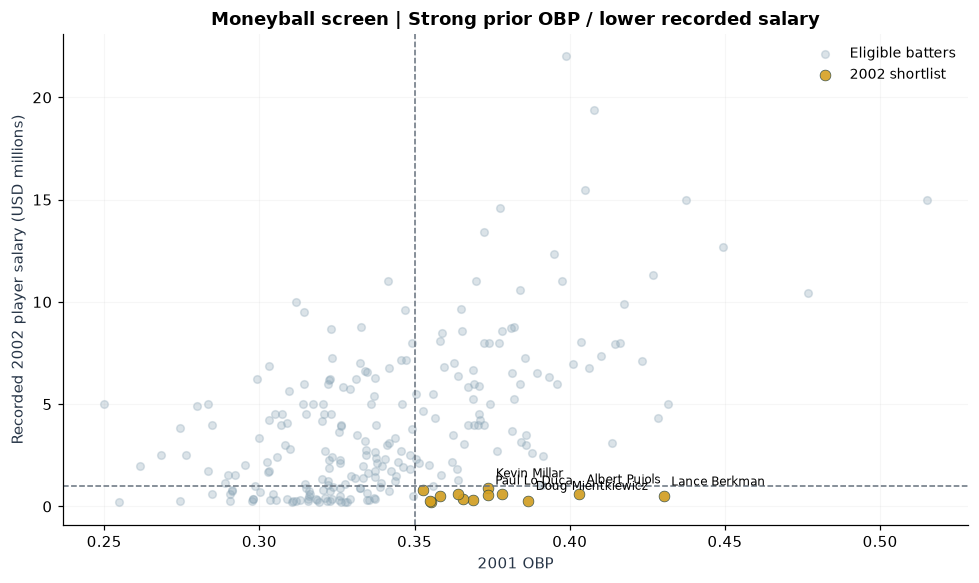

In [17]:
from matplotlib.ticker import FuncFormatter
fig,ax=plt.subplots(figsize=(9,5.4))
q=pool[pool.player_salary>0].copy()
ax.scatter(q.OBP,q.player_salary/1e6,s=25,alpha=.3,color='#88a3b4',label='Eligible batters')
ax.scatter(shortlist.OBP,shortlist.player_salary/1e6,color='#d5a021',s=50,alpha=.9,
           edgecolor='#183b40',linewidth=.4,label='2002 shortlist')
for _,r in shortlist.sort_values('screen_score',ascending=False).head(5).iterrows():
    ax.annotate(r['name'],(r.OBP,r.player_salary/1e6),xytext=(5,7),textcoords='offset points',fontsize=8)
ax.axvline(.350,linestyle='--',color='#66717d',lw=1)
ax.axhline(1.0,linestyle='--',color='#66717d',lw=1)
ax.set(xlabel='2001 OBP',ylabel='Recorded 2002 player salary (USD millions)',
       title='Moneyball screen | Strong prior OBP / lower recorded salary')
ax.legend(frameon=False,fontsize=9);ax.grid(alpha=.1)
fig.tight_layout();fig.savefig(VISUALS/'undervalued_players_2002.png',bbox_inches='tight');plt.show()

In [18]:
# Hindsight evaluation uses 2002 batting AFTER the 2001/2002 salary screen is frozen.
future=player_seasons(raw)
future=future[future.yearID.eq(2002)][['playerID','OBP','PA','SLG']].rename(columns={
    'OBP':'actual_2002_OBP','PA':'actual_2002_PA','SLG':'actual_2002_SLG'})
follow=shortlist.merge(future,on='playerID',how='left',validate='one_to_one')
follow['OBP_change']=follow.actual_2002_OBP-follow.OBP
print('2002 follow-up (not an input to the screen):')
display(follow[['name','OBP','actual_2002_OBP','actual_2002_PA','OBP_change','player_salary']].round(3))
print('Players with >=300 PA in 2002:',int((follow.actual_2002_PA>=300).sum()),'of',len(follow))
save_frame(follow[['playerID','name','OBP','actual_2002_OBP','actual_2002_PA','OBP_change','player_salary']],
           'candidate_followup_2002.csv')

2002 follow-up (not an input to the screen):


,name,OBP,actual_2002_OBP,actual_2002_PA,OBP_change,player_salary
0,Lance Berkman,0.430,0.405,692.0,-0.026,500000
1,Albert Pujols,0.403,0.394,675.0,-0.009,600000
2,Kevin Millar,0.374,0.366,489.0,-0.008,900000
3,Paul Lo Duca,0.374,0.330,632.0,-0.044,546667
4,Doug Mientkiewicz,0.387,0.365,554.0,-0.022,285000
5,Matt Stairs,0.358,0.349,315.0,-0.009,500000
6,Raul Ibanez,0.353,0.346,544.0,-0.006,800000
7,Frank Menechino,0.369,0.312,154.0,-0.057,295000
8,Rickey Henderson,0.366,0.369,222.0,0.004,350000
9,Juan Pierre,0.378,0.332,640.0,-0.046,600000


Players with >=300 PA in 2002: 10 of 13


WindowsPath('C:/Users/htpar/Downloads/outputs/processed/candidate_followup_2002.csv')

## Out-of-time model test (separate from the 2002 shortlist)

Every row contains batting information from season **t**, a listed salary from **t+1** for filtering and a next-season outcome used **only as target**. Modeling columns explicitly exclude next-season salary and outcomes. Train on target seasons 2001–2010, then test on target seasons 2011–2012. This tests predictability, not player-acquisition feasibility. Evaluating only hitters who appear in both seasons with 300 PA introduces survivorship selection.


In [19]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error,mean_squared_error
panel=future_panel(raw,first_feature_year=2000,last_feature_year=2011,min_pa=300)
train=panel[panel.yearID<=2009].copy()  # target year <= 2010
test=panel[panel.yearID>=2010].copy()   # target year >= 2011
assert train.yearID.max()<test.yearID.min()
assert panel.yearID.max()==2011
model=Pipeline([('scale',StandardScaler()),('ridge',Ridge(alpha=10.0))])
model.fit(train[FEATURES],train.next_OBP)
test['predicted_next_OBP']=model.predict(test[FEATURES]).clip(0,1)
test['baseline_next_OBP']=test.OBP
metrics={
 'train_rows':len(train),'test_rows':len(test),
 'test_first_target_year':int(test.yearID.min()+1),
 'test_last_target_year':int(test.yearID.max()+1),
 'ridge_MAE':mean_absolute_error(test.next_OBP,test.predicted_next_OBP),
 'baseline_MAE':mean_absolute_error(test.next_OBP,test.baseline_next_OBP),
 'ridge_RMSE':np.sqrt(mean_squared_error(test.next_OBP,test.predicted_next_OBP)),
 'baseline_RMSE':np.sqrt(mean_squared_error(test.next_OBP,test.baseline_next_OBP)),
}
print(pd.Series(metrics).to_string())
save_frame(test[['playerID','name','yearID','OBP','next_OBP','predicted_next_OBP','baseline_next_OBP','player_salary']],
           'holdout_predictions_2011_2012.csv')

train_rows                2063.000000
test_rows                  396.000000
test_first_target_year    2011.000000
test_last_target_year     2012.000000
ridge_MAE                    0.024797
baseline_MAE                 0.027988
ridge_RMSE                   0.030844
baseline_RMSE                0.034877


WindowsPath('C:/Users/htpar/Downloads/outputs/processed/holdout_predictions_2011_2012.csv')

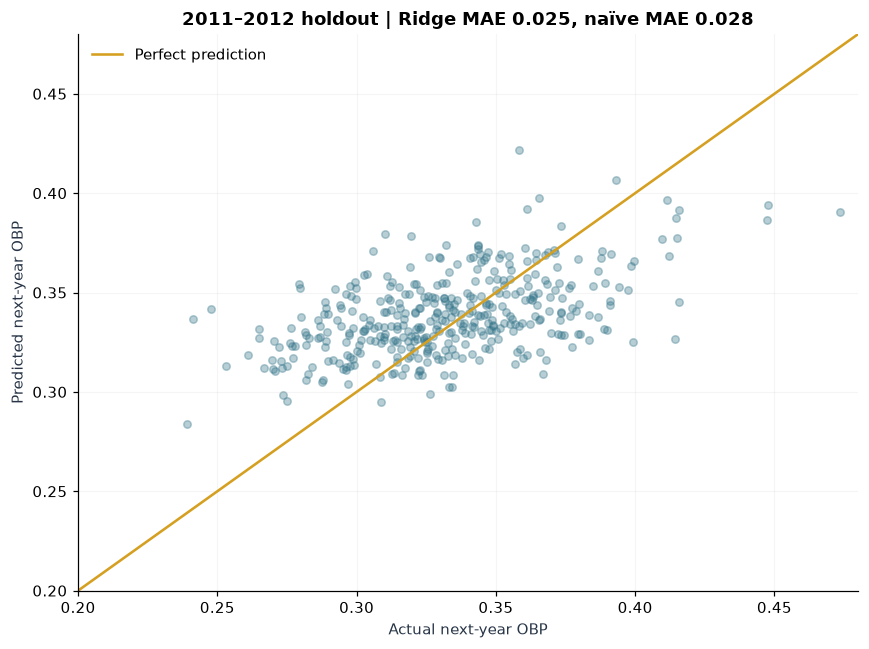

WindowsPath('C:/Users/htpar/Downloads/outputs/processed/holdout_metrics.csv')

In [20]:
fig,ax=plt.subplots(figsize=(8,6))
ax.scatter(test.next_OBP,test.predicted_next_OBP,alpha=.35,s=24,color='#337489')
lo,hi=.20,.48
ax.plot([lo,hi],[lo,hi],color='#d5a021',lw=1.7,label='Perfect prediction')
ax.set(xlim=(lo,hi),ylim=(lo,hi),xlabel='Actual next-year OBP',ylabel='Predicted next-year OBP',
       title=f'2011–2012 holdout | Ridge MAE {metrics["ridge_MAE"]:.3f}, naïve MAE {metrics["baseline_MAE"]:.3f}')
ax.legend(frameon=False);ax.grid(alpha=.12)
fig.tight_layout();fig.savefig(VISUALS/'model_validation.png',bbox_inches='tight');plt.show()
save_frame(pd.DataFrame([metrics]),'holdout_metrics.csv')

### Decision rule and important caveats

This is a **candidate screening** tool, not a complete roster optimizer. The four inputs do not contain fielding, injuries, contract availability, acquisition cost, minor league options, position fit or current market salaries. A true GM recommendation would need those variables and current data. Do not interpret a high historical score as evidence that a player was freely available at the listed salary.


## 6. Multivariate run production and wins modeling

**Question:** Is OBP still associated with runs when slugging and an available park-factor proxy are included? Does runs scored and runs allowed jointly explain team winning percentage?

This analysis uses 2000–2012 team-seasons only because historical team HBP/SF were missing before 2000. The analysis fits year-fixed-effect OLS with heteroskedasticity-robust (HC3) standard errors and compare explanatory fit. Coefficients are **associations, not causal estimates**. `BPF` is a historic batting park-factor index, not an observed causal treatment.


,model,n,R_squared,adj_R_squared
0,OBP + year,390,0.8081,0.8014
1,SLG + year,390,0.8458,0.8404
2,OBP + SLG + park + year,390,0.9192,0.9159
3,Runs + RA + year -> wins,390,0.8814,0.8770


,model,predictor,coefficient,robust_p_value,ci_low,ci_high
0,Runs model,OBP,17.20257,0.0000,15.25033,19.15481
1,Runs model,SLG,10.57938,0.0000,9.53026,11.62850
2,Runs model,park_factor,0.09255,0.6195,-0.27276,0.45786
3,Win% model,runs_per_game,0.09686,0.0000,0.09113,0.10259
4,Win% model,allowed_per_game,-0.10474,0.0000,-0.11016,-0.09933


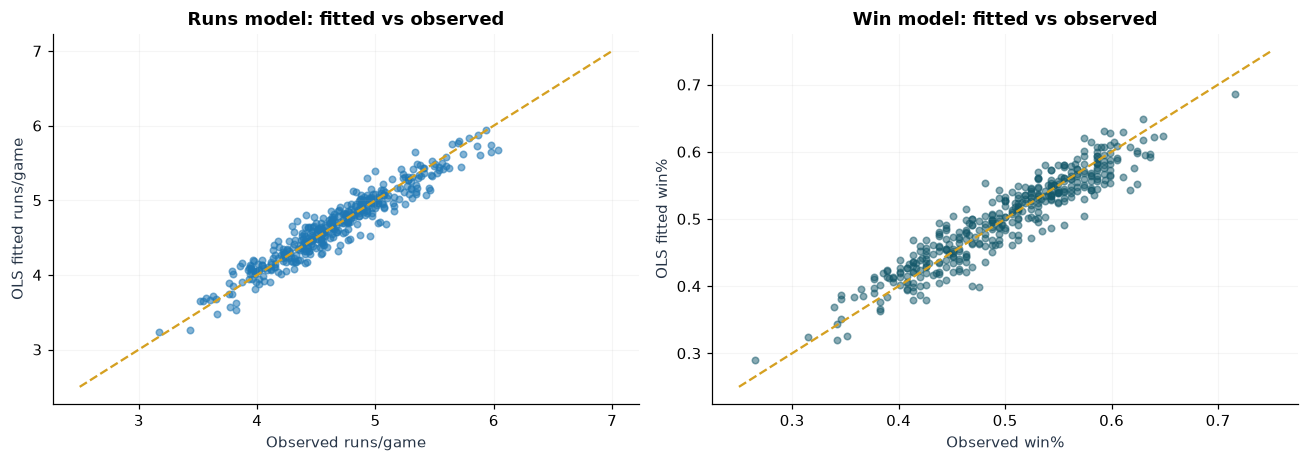

In [21]:
import statsmodels.formula.api as smf
from sklearn.metrics import r2_score
team_reg = team_seasons(raw)
team_reg = team_reg[team_reg.yearID.between(2000, 2012)].copy()
team_reg['runs_per_game'] = safe_div(team_reg['R'], team_reg['G'])
team_reg['allowed_per_game'] = safe_div(team_reg['RA'], team_reg['G'])
# Team source contains AB,H,2B,3B,HR: calculate team SLG directly from count statistics.
team_reg['SLG'] = safe_div(team_reg.H + team_reg['2B'] + 2*team_reg['3B'] + 3*team_reg.HR, team_reg.AB)
team_reg = team_reg.dropna(subset=['OBP','SLG','BPF','runs_per_game','allowed_per_game','win_pct']).copy()
team_reg['park_factor'] = team_reg.BPF / 100.0
model_obp = smf.ols('runs_per_game ~ OBP + C(yearID)', data=team_reg).fit(cov_type='HC3')
model_slg = smf.ols('runs_per_game ~ SLG + C(yearID)', data=team_reg).fit(cov_type='HC3')
model_combined = smf.ols('runs_per_game ~ OBP + SLG + park_factor + C(yearID)', data=team_reg).fit(cov_type='HC3')
model_wins = smf.ols('win_pct ~ runs_per_game + allowed_per_game + C(yearID)', data=team_reg).fit(cov_type='HC3')
reg_compare = pd.DataFrame([{'model':n,'n':int(m.nobs),'R_squared':m.rsquared,'adj_R_squared':m.rsquared_adj}
                            for n,m in [('OBP + year',model_obp),('SLG + year',model_slg),
                                        ('OBP + SLG + park + year',model_combined),('Runs + RA + year -> wins',model_wins)]])
coef_table=pd.DataFrame([
 {'model':label,'predictor':k,'coefficient':m.params[k], 'robust_p_value':m.pvalues[k],
  'ci_low':m.conf_int().loc[k,0], 'ci_high':m.conf_int().loc[k,1]}
 for label,m,keys in [('Runs model',model_combined,['OBP','SLG','park_factor']),
                      ('Win% model',model_wins,['runs_per_game','allowed_per_game'])] for k in keys
])
display(reg_compare.round(4));display(coef_table.round(5))
save_frame(reg_compare,'multivariate_model_comparison.csv')
save_frame(coef_table,'multivariate_model_coefficients.csv')
fig,axs=plt.subplots(1,2,figsize=(12,4.3))
axs[0].scatter(team_reg.runs_per_game,model_combined.predict(team_reg),alpha=.55,s=18)
axs[0].plot([2.5,7],[2.5,7],'--',color='#d5a021');axs[0].set(xlabel='Observed runs/game',ylabel='OLS fitted runs/game',title='Runs model: fitted vs observed')
axs[1].scatter(team_reg.win_pct,model_wins.predict(team_reg),alpha=.5,s=18,color='#14586a')
axs[1].plot([.25,.75],[.25,.75],'--',color='#d5a021');axs[1].set(xlabel='Observed win%',ylabel='OLS fitted win%',title='Win model: fitted vs observed')
for ax in axs: ax.grid(alpha=.12)
fig.tight_layout();fig.savefig(VISUALS/'multivariate_team_models.png',bbox_inches='tight');plt.show()


**Interpretation:** The regression table reports coefficient uncertainty as well as goodness of fit. Because season fixed effects and explanatory metrics share information, coefficients must be interpreted jointly rather than as independent sources of wins. These fits are *in-sample* explanations, not forecasts of future MLB seasons.


## 7. Cluster quality and PCA diagnostics

The original notebook fixed K-Means at **k=4** and visualized a subset through MDS. The analysis evaluates **k = 2–8** using silhouette score, shows the selected `k` and clusters on PCA coordinates for **all eligible players**, and exports standardized component loadings. PCA axes are interpretable weighted combinations of batting inputs; they do not measure defensive value.


Best k (highest silhouette): 2
Explained variance: [0.622 0.213]


,k,silhouette,davies_bouldin
0,2,0.343,1.154
1,3,0.278,1.286
2,4,0.282,1.200
3,5,0.247,1.224
4,6,0.253,1.121
5,7,0.244,1.134
6,8,0.230,1.034


,validated_cluster,count,OBP_median,SLG_median,BB_rate_median,salary_median
0,0,154,0.323,0.399,0.067,1925000.0
1,1,95,0.374,0.529,0.114,5850000.0


,PC1,PC2
OBP,0.499,-0.315
SLG,0.522,-0.111
ISO,0.517,0.094
BB_rate,0.439,0.091
SO_rate,0.136,0.933


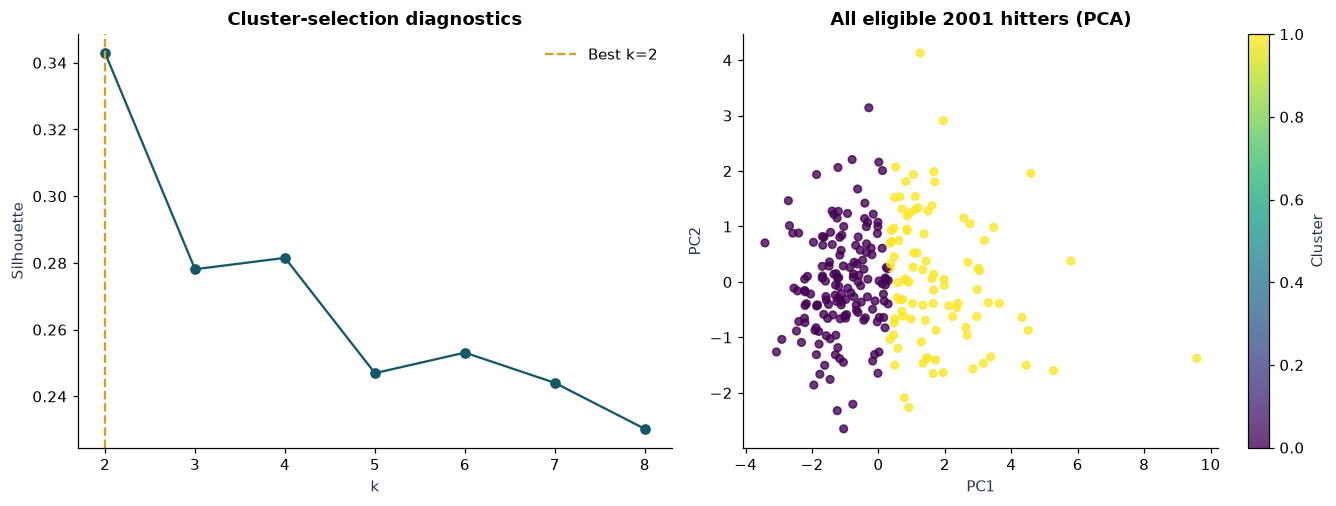

In [22]:
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA
# Keep the same 2001-performance / 2002-salary pool as original sections.
cluster_pool=eligible_player_pool(raw,2001,2002,min_pa=300).copy()
cluster_features=StandardScaler().fit_transform(cluster_pool[SIMILARITY_FEATURES])
cluster_scores=[]
for k in range(2,9):
    fit=KMeans(n_clusters=k,random_state=42,n_init=10).fit(cluster_features)
    cluster_scores.append({'k':k,'silhouette':silhouette_score(cluster_features,fit.labels_),
                           'davies_bouldin':davies_bouldin_score(cluster_features,fit.labels_)})
cluster_scores=pd.DataFrame(cluster_scores)
best_k=int(cluster_scores.sort_values(['silhouette','k'],ascending=[False,True]).iloc[0]['k'])
selected_kmeans=KMeans(n_clusters=best_k,random_state=42,n_init=10)
cluster_pool['validated_cluster']=selected_kmeans.fit_predict(cluster_features)
pca=PCA(n_components=2).fit(cluster_features)
coords=pca.transform(cluster_features)
cluster_pool[['pc1','pc2']]=coords
cluster_summary=cluster_pool.groupby('validated_cluster').agg(
    count=('playerID','size'),OBP_median=('OBP','median'),SLG_median=('SLG','median'),
    BB_rate_median=('BB_rate','median'),salary_median=('player_salary','median')).reset_index()
loadings=pd.DataFrame(pca.components_.T, index=SIMILARITY_FEATURES,columns=['PC1','PC2'])
print('Best k (highest silhouette):',best_k)
print('Explained variance:',np.round(pca.explained_variance_ratio_,3))
display(cluster_scores.round(3));display(cluster_summary.round(3));display(loadings.round(3))
save_frame(cluster_scores,'cluster_validation.csv')
save_frame(cluster_summary,'validated_cluster_profiles.csv')
save_frame(cluster_pool[['playerID','name','validated_cluster','pc1','pc2','OBP','SLG','player_salary']],
           'player_similarity_pca.csv')
fig,axes=plt.subplots(1,2,figsize=(12.4,4.7))
axes[0].plot(cluster_scores.k,cluster_scores.silhouette,'o-',color='#14586a');axes[0].axvline(best_k,color='#d5a021',ls='--',label=f'Best k={best_k}');axes[0].set(xlabel='k',ylabel='Silhouette',title='Cluster-selection diagnostics');axes[0].legend(frameon=False)
pts=axes[1].scatter(coords[:,0],coords[:,1],c=cluster_pool.validated_cluster,cmap='viridis',alpha=.78,s=25)
axes[1].set(xlabel='PC1',ylabel='PC2',title='All eligible 2001 hitters (PCA)');fig.colorbar(pts,ax=axes[1],label='Cluster')
fig.tight_layout();fig.savefig(VISUALS/'cluster_validation_pca.png',bbox_inches='tight');plt.show()


## 8. Decision-year panel, attrition and risk modeling

**Critical design fix:** Avoid evaluating only hitters who later receive at least 300 PA. The new decision panel includes every batter meeting the **prior-year 300-PA criterion** with a listed **following-year salary**, then records future playing time **only as an evaluation outcome**. No next-year performance, salary outcome proxy, or playing-time status is included among model features. The following two outcomes are modeled separately:

1. `P(next-year PA >= 300)` — probability of being a regular hitter, labeled **participation risk**.
2. `next-year OBP | next-year PA >= 300` — conditional rate prediction, requiring a separate evaluation cohort.

**Residual limitation:** conditioning on having a recorded next-year MLB salary still omits players without such a salary row and so does not represent all potentially available players. A salary in the historical database is not an actual offseason quote or proof of trade/signing availability.


Decision panel: 4333 player-season entries, target seasons 1996 through 2012
2002 candidates: 249
Holdout 2011–2012: 504 | retained >=300 PA: 396


,cohort,n,actual_regular_rate,predicted_regular_rate,brier_model,brier_constant_baseline,ROC_AUC
0,2011–2012 holdout (all salary-listed candidates),504,0.7857,0.7694,0.1415,0.1686,0.7723


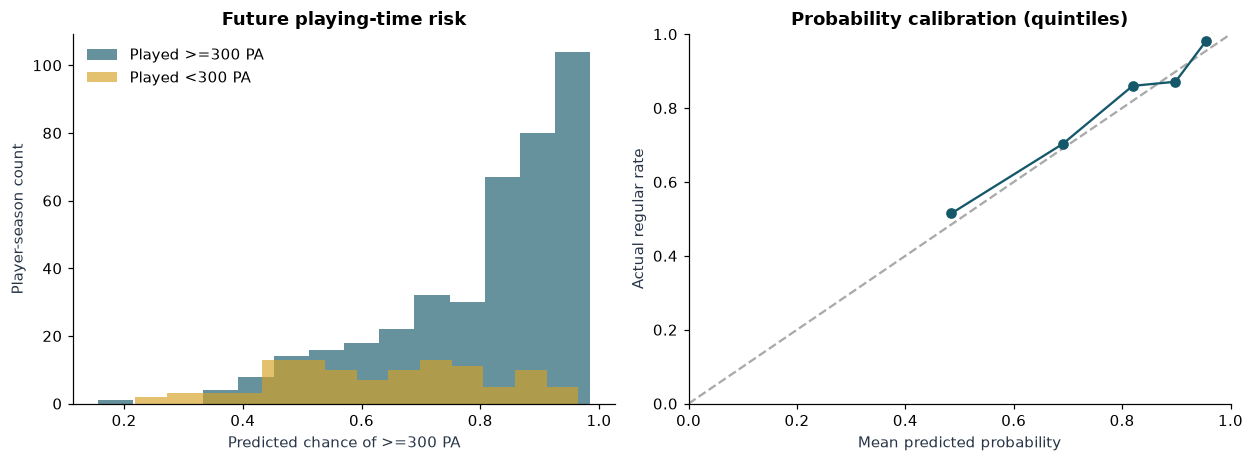

WindowsPath('C:/Users/htpar/Downloads/outputs/processed/participation_calibration.csv')

In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, roc_auc_score
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

# Build yearly league-obp context from the FULL batter population (including small samples).
p_all=player_seasons(raw)
p_all['onbase_num']=p_all['H']+p_all['BB']+p_all['HBP']
p_all['onbase_denom']=p_all['AB']+p_all['BB']+p_all['HBP']+p_all['SF']
league_by_year=p_all.groupby('yearID').agg(onbase_num=('onbase_num','sum'),onbase_denom=('onbase_denom','sum'))
league_by_year['league_OBP']=league_by_year.onbase_num/league_by_year.onbase_denom

def build_decision_panel(p=p_all, salary_table=player_salary, feature_first=1995,feature_last=2011,min_pa=300):
    base=p.loc[p.yearID.between(feature_first,feature_last)&p.PA.ge(min_pa),
               ['playerID','yearID','name']+FEATURES].copy()
    next_values=p[['playerID','yearID','PA','OBP','SLG','onbase_num','onbase_denom']].copy()
    next_values['yearID']-=1
    next_values=next_values.rename(columns={'PA':'next_PA','OBP':'next_OBP','SLG':'next_SLG',
                                              'onbase_num':'next_onbase_num','onbase_denom':'next_onbase_denom'})
    panel=base.merge(next_values,on=['playerID','yearID'],how='left',validate='one_to_one')
    listed=salary_table[['playerID','yearID','player_salary']].copy()
    listed['yearID']-=1
    panel=panel.merge(listed,on=['playerID','yearID'],how='left',validate='one_to_one')
    panel['target_year']=panel.yearID+1
    panel['next_PA']=panel.next_PA.fillna(0)
    panel['next_onbase_num']=panel.next_onbase_num.fillna(0)
    panel['next_onbase_denom']=panel.next_onbase_denom.fillna(0)
    panel['next_regular']=(panel.next_PA>=min_pa).astype(int)
    panel=panel.merge(league_by_year[['league_OBP']],left_on='target_year',right_index=True,how='left',validate='many_to_one')
    panel['onbase_above_league']=panel.next_onbase_num-panel.league_OBP*panel.next_onbase_denom
    panel=panel.dropna(subset=FEATURES+['league_OBP'])
    panel=panel[(panel.player_salary>0)&panel.player_salary.notna()].copy().reset_index(drop=True)
    return panel

decisions=build_decision_panel()
assert not decisions.duplicated(['playerID','yearID']).any()
assert decisions['next_regular'].eq(decisions.next_PA>=300).all()
print('Decision panel:',len(decisions),'player-season entries, target seasons',
      decisions.target_year.min(),'through',decisions.target_year.max())
print('2002 candidates:',len(decisions[decisions.target_year==2002]))
print('Holdout 2011–2012:',len(decisions[decisions.target_year.isin([2011,2012])]),
      '| retained >=300 PA:',decisions.loc[decisions.target_year.isin([2011,2012]),'next_regular'].sum())
save_frame(decisions[['playerID','yearID','target_year','name','PA','OBP','next_PA',
                      'next_OBP','next_regular','player_salary','onbase_above_league']],
           'decision_panel_audit.csv')

# Chronological risk-model holdout: train only on target seasons <= 2010.
risk_train=decisions[decisions.target_year<=2010].copy()
risk_test=decisions[decisions.target_year>=2011].copy()
risk_model=Pipeline([('scale',StandardScaler()),('logit',LogisticRegression(max_iter=1500,random_state=42))])
risk_model.fit(risk_train[FEATURES],risk_train.next_regular)
risk_test['p_regular']=risk_model.predict_proba(risk_test[FEATURES])[:,1]
risk_metrics=pd.DataFrame([{'cohort':'2011–2012 holdout (all salary-listed candidates)',
                            'n':len(risk_test),'actual_regular_rate':risk_test.next_regular.mean(),
                            'predicted_regular_rate':risk_test.p_regular.mean(),
                            'brier_model':brier_score_loss(risk_test.next_regular,risk_test.p_regular),
                            'brier_constant_baseline':brier_score_loss(risk_test.next_regular,np.repeat(risk_train.next_regular.mean(),len(risk_test))),
                            'ROC_AUC':roc_auc_score(risk_test.next_regular,risk_test.p_regular)}])
display(risk_metrics.round(4));save_frame(risk_metrics,'attrition_model_holdout.csv')
# Do NOT conflate rate accuracy for survivors with total screening success.
fig,axes=plt.subplots(1,2,figsize=(11.5,4.3))
axes[0].hist(risk_test.loc[risk_test.next_regular==1,'p_regular'],bins=14,alpha=.65,label='Played >=300 PA',color='#14586a')
axes[0].hist(risk_test.loc[risk_test.next_regular==0,'p_regular'],bins=14,alpha=.65,label='Played <300 PA',color='#d5a021')
axes[0].set(xlabel='Predicted chance of >=300 PA',ylabel='Player-season count',title='Future playing-time risk');axes[0].legend(frameon=False)
risk_test['prob_bin']=pd.qcut(risk_test.p_regular,5,duplicates='drop')
calibration=risk_test.groupby('prob_bin',observed=True).agg(predicted=('p_regular','mean'),actual=('next_regular','mean'),n=('playerID','size')).reset_index()
axes[1].plot([0,1],[0,1],'--',color='#aaa');axes[1].plot(calibration.predicted,calibration.actual,'o-',color='#14586a')
axes[1].set(xlim=(0,1),ylim=(0,1),xlabel='Mean predicted probability',ylabel='Actual regular rate',title='Probability calibration (quintiles)')
fig.tight_layout();fig.savefig(VISUALS/'participation_risk.png',bbox_inches='tight');plt.show()
save_frame(calibration.assign(prob_bin=lambda d:d.prob_bin.astype(str)),'participation_calibration.csv')


# Part 03 · Salary, undervaluation and economic comparisons

*Technical execution sequence is unchanged. See `01_Moneyball_Main_Research.ipynb` for a topical, reduced presentation.*


## 9. Player salary benchmarks and value estimates

For the historical **2002** decision, train the predictive model on seasons whose outcomes occurred no later than **2001**. Compare batters with actual listed 2002 salaries. A contemporaneous `log(salary)` Ridge model produces a **salary residual**: `predicted log salary − observed log salary`; positive means relatively cheaper than similarly measured teammates/opponents in the **2002 cohort**, not truly underpaid given contracts, service time, position or defense.

The **screening score** below combines prior-year features, a pre-2002 predictive model, participation likelihood and salary. It is a transparent heuristic, **not an estimate of WAR, revenue, or projected runs/wins**.


2002 decision cohort: 249


,name,OBP,projected_OBP,p_300_PA,PA,player_salary,peer_implied_salary,salary_log_gap,value_score,value_rank
319,Lance Berkman,0.430,0.403,0.990,688.0,500000.0,4718656.633,2.245,109.727,1
3210,Albert Pujols,0.403,0.388,0.993,676.0,600000.0,2822659.278,1.549,82.532,2
2744,Doug Mientkiewicz,0.387,0.369,0.954,626.0,285000.0,2567662.041,2.198,78.113,3
2735,Frank Menechino,0.369,0.366,0.852,578.0,295000.0,2226819.090,2.021,60.559,4
1082,David Eckstein,0.355,0.343,0.950,664.0,280000.0,1702729.286,1.805,50.502,7
3150,Juan Pierre,0.378,0.356,0.981,683.0,600000.0,1778597.118,1.087,50.075,8
3241,Aramis Ramirez,0.350,0.350,0.980,655.0,500000.0,2366841.595,1.555,47.505,9
2455,Paul Lo Duca,0.374,0.364,0.952,519.0,546667.0,2637923.782,1.574,45.670,11
3433,Jimmy Rollins,0.323,0.336,0.973,720.0,355000.0,1996398.961,1.727,41.855,12
3336,Chris Richard,0.335,0.340,0.873,542.0,300000.0,1725286.224,1.749,34.087,15


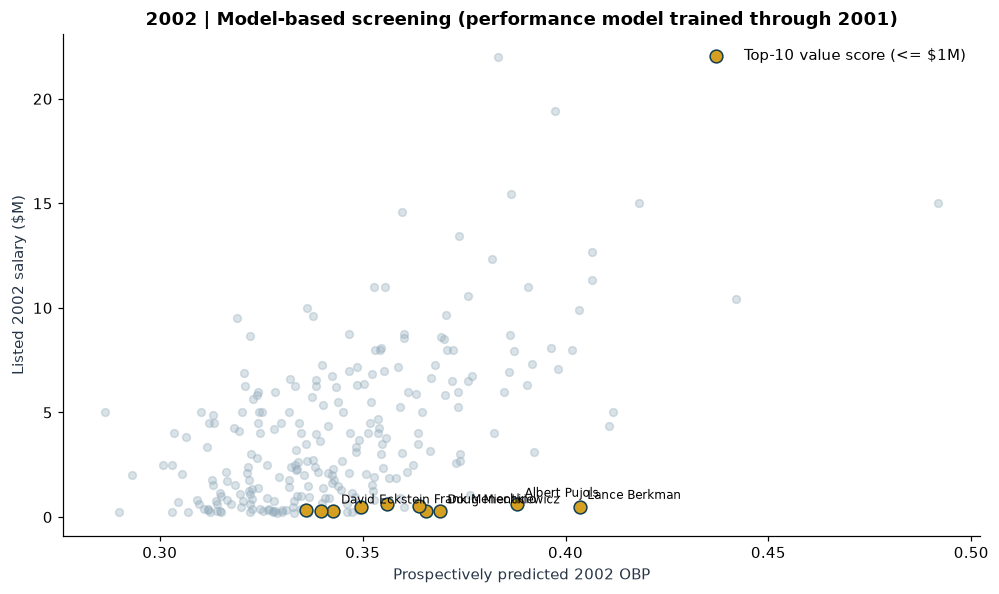

In [24]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Models are fitted with complete prior observed training outcomes ONLY.
def fit_prospective_models(history):
    eligible_rate=history[history.next_regular.eq(1)&history.next_OBP.notna()].copy()
    if len(eligible_rate)<150 or history.next_regular.nunique()<2:
        raise ValueError('Insufficient historical training data')
    rate_model=Pipeline([('scale',StandardScaler()),('ridge',Ridge(alpha=10.0))])
    rate_model.fit(eligible_rate[FEATURES],eligible_rate.next_OBP)
    play_model=Pipeline([('scale',StandardScaler()),('logit',LogisticRegression(max_iter=1500,random_state=42))])
    play_model.fit(history[FEATURES],history.next_regular)
    return rate_model,play_model

SALARY_FEATURES=['OBP','SLG','BB_rate','SO_rate','PA','age']

def score_candidates(hist,candidates):
    # hist has target years strictly before candidates' target year.
    rate_model,play_model=fit_prospective_models(hist)
    d=candidates.copy()
    d['projected_OBP']=np.clip(rate_model.predict(d[FEATURES]),0,1)
    d['p_300_PA']=play_model.predict_proba(d[FEATURES])[:,1]
    salary_model=Pipeline([('scale',StandardScaler()),('ridge',Ridge(alpha=30.0))])
    salary_model.fit(d[SALARY_FEATURES],np.log(d.player_salary))
    d['peer_implied_salary']=np.exp(salary_model.predict(d[SALARY_FEATURES]))
    d['salary_log_gap']=np.log(d.peer_implied_salary)-np.log(d.player_salary)
    d['performance_index']=np.maximum(d.projected_OBP-0.300,0)*np.minimum(d.PA,700)*d.p_300_PA
    d['value_score']=d.performance_index/(d.player_salary/1e6)**.35 * np.exp(.1*np.clip(d.salary_log_gap,-2,2))
    return d

case2002=decisions[decisions.target_year.eq(2002)].copy()
past2002=decisions[decisions.target_year.lt(2002)].copy()
assert past2002.target_year.max()<case2002.target_year.min()
scored_2002=score_candidates(past2002,case2002)
scored_2002=scored_2002.sort_values('value_score',ascending=False)
scored_2002['value_rank']=np.arange(1,len(scored_2002)+1)
cols2002=['playerID','name','OBP','projected_OBP','p_300_PA','PA','player_salary',
          'peer_implied_salary','salary_log_gap','value_score','value_rank','next_PA','next_OBP','onbase_above_league']
print('2002 decision cohort:',len(scored_2002))
display(scored_2002[scored_2002.player_salary<=1_000_000][cols2002[1:11]].head(15).round(3))
save_frame(scored_2002[cols2002],'2002_model_based_value_candidates.csv')
fig,ax=plt.subplots(figsize=(9.2,5.5))
plot_v=scored_2002.copy()
ax.scatter(plot_v.projected_OBP,plot_v.player_salary/1e6,s=26,alpha=.34,color='#91aaba')
cheap_v=plot_v[plot_v.player_salary<=1e6].nlargest(10,'value_score')
ax.scatter(cheap_v.projected_OBP,cheap_v.player_salary/1e6,s=70,color='#d5a021',edgecolor='#123e50',label='Top-10 value score (<= $1M)')
for _,r in cheap_v.head(5).iterrows():
    ax.annotate(r['name'],(r.projected_OBP,r.player_salary/1e6),xytext=(5,5),textcoords='offset points',fontsize=8)
ax.set(xlabel='Prospectively predicted 2002 OBP',ylabel='Listed 2002 salary ($M)',
       title='2002 | Model-based screening (performance model trained through 2001)')
ax.legend(frameon=False);fig.tight_layout();fig.savefig(VISUALS/'prospective_value_2002.png',bbox_inches='tight');plt.show()


## 10. Walk-forward model comparison and historical recommendation backtests

**No future performance at selection time.** For each test season **2002–2012**, train only on **earlier outcome seasons**, predict from previous-year batting inputs, then evaluate observed next-season playing time and on-base production. Compare:

- **Model value score**: forward OBP × probability of substantial playing time, discounted by salary with a peer-pay adjustment.
- **Previous OBP**: top previous-season OBP among the *same* low-pay cohort.
- **Cheapest**: cheapest recorded next-season salaries in that cohort.
- **Random low-pay**: average of 100 deterministic random picks from the same cohort.

For fairness, the eligible pool each year is restricted to its **lower 40% salary percentile**, and each method chooses the same number of players (up to ten). Scores are not dollar returns. Evaluation reports *all selected players*, including those who do not appear next season: **rate of 300+ PA**, conditional next-season OBP for those who play, and `onbase_above_league` = actual on-base events − contemporaneous league OBP × actual OBP denominator. This latter volume-sensitive proxy gives zero contribution to nonparticipants and is not WAR or runs created.


Walk-forward forecasting, same regular-hitter evaluation cohort:


,model,years,avg_MAE,avg_RMSE
0,Previous season OBP,11,0.0265,0.0329
1,Ridge,11,0.0232,0.0291


Equal-season-weighted annual top-10 recommendation results (historical):


,method,seasons,avg_listed_salary_total,avg_regular_share,avg_onbase_above_league_per_year,avg_OBP_of_regular
0,Cheapest salary,11,3.654721e+06,0.7182,0.7495,0.3298
1,Model value score,11,4.983441e+06,0.9364,153.5414,0.3552
2,Previous OBP,11,8.119649e+06,0.8273,140.9901,0.3584
3,Random low-pay,11,8.758638e+06,0.6845,6.3302,0.3339


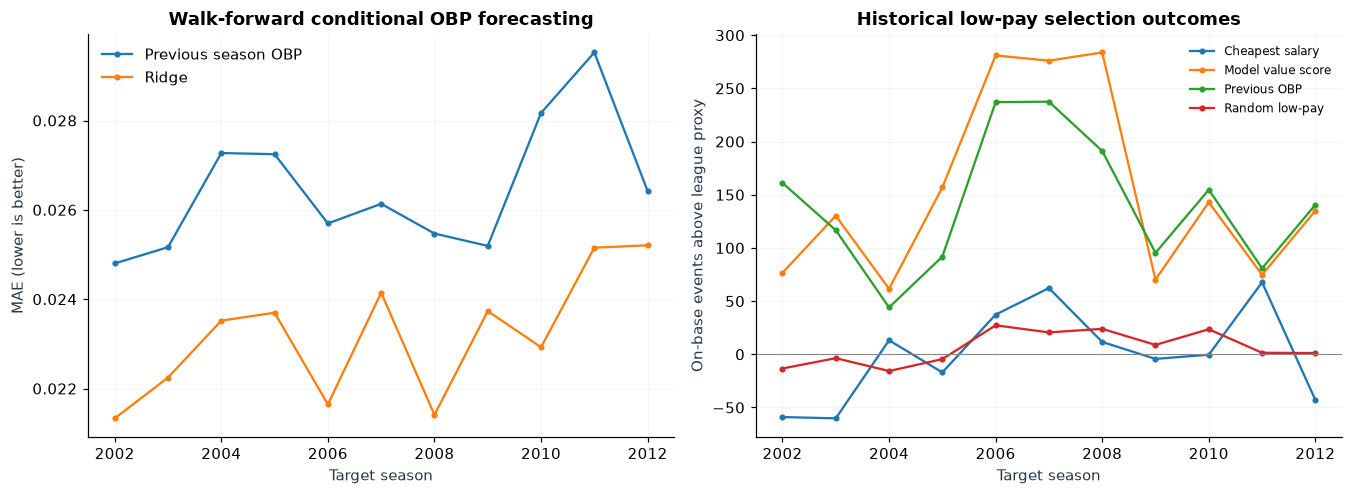

In [25]:
from sklearn.metrics import mean_absolute_error,mean_squared_error
backtest_metrics=[]
backtest_players=[]
method_year=[]
random_engine=np.random.default_rng(42)
N_PICKS=10

for target_year in range(2002,2013):
    history=decisions[decisions.target_year<target_year]
    candidates=decisions[decisions.target_year==target_year]
    if len(candidates)<N_PICKS or len(history)<150: continue
    scored=score_candidates(history,candidates)
    # Purely model-driven numerical forecast tests evaluated on next-year regular hitters.
    regular=scored[scored.next_regular.eq(1)&scored.next_OBP.notna()].copy()
    if len(regular):
        for method,pred in [('Ridge',regular.projected_OBP),('Previous season OBP',regular.OBP)]:
            backtest_metrics.append({'target_year':target_year,'model':method,'n_regular':len(regular),
                                     'MAE':mean_absolute_error(regular.next_OBP,pred),
                                     'RMSE':np.sqrt(mean_squared_error(regular.next_OBP,pred))})
    # Pre-decision filter based only on known salary ranking.
    pay_cutoff=scored.player_salary.quantile(.40)
    eligible=scored[scored.player_salary<=pay_cutoff].copy()
    n=min(N_PICKS,len(eligible))
    if n<5: continue
    selections={
        'Model value score':eligible.nlargest(n,'value_score'),
        'Previous OBP':eligible.nlargest(n,'OBP'),
        'Cheapest salary':eligible.nsmallest(n,'player_salary'),
    }
    # Evaluate random baseline at the same sample size without cherry-picking a draw.
    rng_year=np.random.default_rng(10_000+target_year)
    for iteration in range(100):
        drawn=eligible.iloc[rng_year.choice(len(eligible),size=n,replace=False)]
        method_year.append({'target_year':target_year,'method':'Random low-pay', 'iteration':iteration,
                            'n':n,'total_salary':drawn.player_salary.sum(),
                            'regular_share':drawn.next_regular.mean(),
                            'onbase_above_league_sum':drawn.onbase_above_league.sum(),
                            'regular_next_OBP':drawn.loc[drawn.next_regular.eq(1),'next_OBP'].mean()})
    for method,sel in selections.items():
        method_year.append({'target_year':target_year,'method':method,'iteration':0,'n':n,
                            'total_salary':sel.player_salary.sum(),
                            'regular_share':sel.next_regular.mean(),
                            'onbase_above_league_sum':sel.onbase_above_league.sum(),
                            'regular_next_OBP':sel.loc[sel.next_regular.eq(1),'next_OBP'].mean()})
        for _,r in sel.iterrows():
            backtest_players.append({'target_year':target_year,'method':method,'playerID':r.playerID,
                                     'name':r['name'],'listed_salary':r.player_salary,'previous_OBP':r.OBP,
                                     'projected_OBP':r.projected_OBP,'p_300_PA':r.p_300_PA,
                                     'next_PA':r.next_PA,'next_regular':r.next_regular,'next_OBP':r.next_OBP,
                                     'onbase_above_league':r.onbase_above_league})

model_year=pd.DataFrame(backtest_metrics)
selection_detail=pd.DataFrame(backtest_players)
selection_year=pd.DataFrame(method_year)
# Average random trials within each year FIRST, ensuring each season has equal weight.
selection_by_year=selection_year.groupby(['target_year','method'],as_index=False).agg(
    n=('n','mean'),mean_salary=('total_salary','mean'),regular_share=('regular_share','mean'),
    onbase_above_league_sum=('onbase_above_league_sum','mean'),regular_next_OBP=('regular_next_OBP','mean'))
selection_overall=selection_by_year.groupby('method',as_index=False).agg(
    seasons=('target_year','nunique'),avg_listed_salary_total=('mean_salary','mean'),
    avg_regular_share=('regular_share','mean'),avg_onbase_above_league_per_year=('onbase_above_league_sum','mean'),
    avg_OBP_of_regular=('regular_next_OBP','mean'))
model_summary=model_year.groupby('model',as_index=False).agg(
    years=('target_year','nunique'),avg_MAE=('MAE','mean'),avg_RMSE=('RMSE','mean'))
print('Walk-forward forecasting, same regular-hitter evaluation cohort:')
display(model_summary.round(4))
print('Equal-season-weighted annual top-10 recommendation results (historical):')
display(selection_overall.round(4))
save_frame(model_year,'walk_forward_obp_metrics_by_year.csv')
save_frame(model_summary,'walk_forward_obp_model_summary.csv')
save_frame(selection_by_year,'annual_player_strategy_results.csv')
save_frame(selection_overall,'player_strategy_backtest_summary.csv')
save_frame(selection_detail,'historical_recommendation_audit.csv')
fig,axes=plt.subplots(1,2,figsize=(12.4,4.6))
for method,subset in model_year.groupby('model'):
    axes[0].plot(subset.target_year,subset.MAE,marker='o',ms=3,label=method)
axes[0].set(xlabel='Target season',ylabel='MAE (lower is better)',title='Walk-forward conditional OBP forecasting');axes[0].legend(frameon=False)
for method,subset in selection_by_year.groupby('method'):
    axes[1].plot(subset.target_year,subset.onbase_above_league_sum,marker='o',ms=3,label=method)
axes[1].axhline(0,color='#888',lw=.7)
axes[1].set(xlabel='Target season',ylabel='On-base events above league proxy',title='Historical low-pay selection outcomes')
axes[1].legend(frameon=False,fontsize=8)
for ax in axes: ax.grid(alpha=.12)
fig.tight_layout();fig.savefig(VISUALS/'walk_forward_strategy_validation.png',bbox_inches='tight');plt.show()


### Backtest uncertainty and salary-cost normalization

The model's average strategy outcome can exceed a baseline without being a statistically reliable improvement. A **paired-by-year bootstrap** provides an interval (11 independent season blocks; percentile 95% interval with 10,000 replicates) for the annual difference. This is approximate because seasons and MLB player populations are dependent. Annual values are also reported for on-base surplus **per $1 million recorded salary**; these ratios are illustrative rather than financial return on investment. All strategies start in the same bottom-40% pay cohort, but their *selected total salaries differ*, so treating the raw totals as an equal-budget trial would be misleading.


Paired season bootstrap — a 95% interval spanning zero is inconclusive:


,comparison,target_seasons,mean_yearly_difference,bootstrap_95_low,bootstrap_95_high,CI_crosses_zero
0,Model minus previous-OBP shortlist,11,12.55,-14.93,38.88,True
1,Model minus cheapest-players shortlist,11,152.79,105.52,196.76,False
2,Model minus random low-pay shortlist,11,147.21,105.03,190.99,False


Different strategies can spend different amounts (reported rather than ignored):


,method,avg_events_above_league_per_salary_million,avg_cost_per_10
0,Cheapest salary,-0.89,3654720.73
1,Model value score,30.98,4983440.64
2,Previous OBP,18.36,8119648.91
3,Random low-pay,0.61,8758638.25


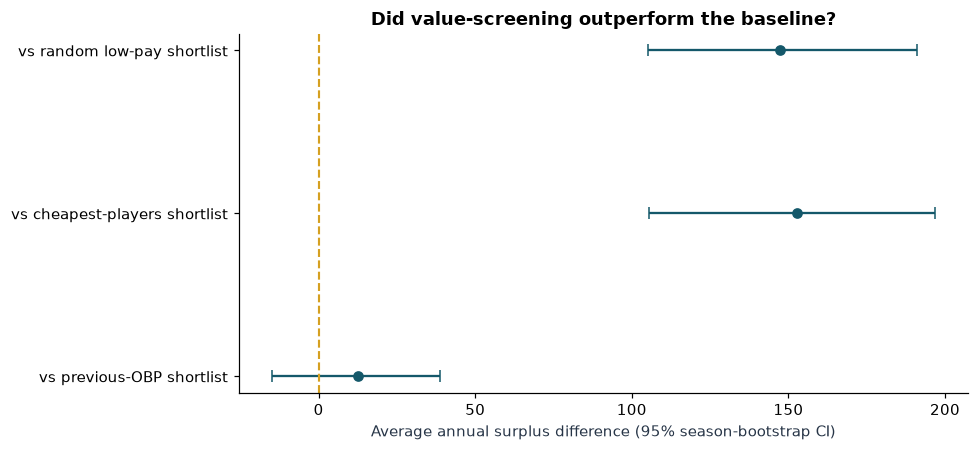

In [26]:
# Paired differences are computed using the SAME target years for both strategies.
strategy_wide=selection_by_year.pivot(index='target_year',columns='method',values='onbase_above_league_sum')
comparisons={'Previous OBP':'Model minus previous-OBP shortlist',
             'Cheapest salary':'Model minus cheapest-players shortlist',
             'Random low-pay':'Model minus random low-pay shortlist'}
boot_rng=np.random.default_rng(2504)
comparison_rows=[]
for reference,label in comparisons.items():
    differences=(strategy_wide['Model value score']-strategy_wide[reference]).dropna().to_numpy()
    boot=boot_rng.choice(differences,size=(10_000,len(differences)),replace=True).mean(axis=1)
    lo,hi=np.percentile(boot,[2.5,97.5])
    comparison_rows.append({'comparison':label,'target_seasons':len(differences),'mean_yearly_difference':differences.mean(),
                            'bootstrap_95_low':lo,'bootstrap_95_high':hi,
                            'CI_crosses_zero':bool(lo<=0<=hi)})
paired_uncertainty=pd.DataFrame(comparison_rows)
selection_by_year['event_surplus_per_salary_million']=(selection_by_year.onbase_above_league_sum/
                                                       (selection_by_year.mean_salary/1e6))
cost_normalized=selection_by_year.groupby('method',as_index=False).agg(
    avg_events_above_league_per_salary_million=('event_surplus_per_salary_million','mean'),
    avg_cost_per_10=('mean_salary','mean'))
print('Paired season bootstrap — a 95% interval spanning zero is inconclusive:')
display(paired_uncertainty.round(2))
print('Different strategies can spend different amounts (reported rather than ignored):')
display(cost_normalized.round(2))
save_frame(paired_uncertainty,'strategy_paired_uncertainty.csv')
save_frame(cost_normalized,'strategy_cost_normalization.csv')
fig,ax=plt.subplots(figsize=(9,4.2))
labels=paired_uncertainty.comparison.str.replace('Model minus ','vs ',regex=False)
means=paired_uncertainty.mean_yearly_difference.to_numpy()
yerr=np.vstack([means-paired_uncertainty.bootstrap_95_low.to_numpy(),
                 paired_uncertainty.bootstrap_95_high.to_numpy()-means])
ax.errorbar(means,labels,xerr=yerr,fmt='o',capsize=4,color='#14586a')
ax.axvline(0,color='#d5a021',ls='--',lw=1.4)
ax.set(xlabel='Average annual surplus difference (95% season-bootstrap CI)',
       title='Did value-screening outperform the baseline?')
fig.tight_layout();fig.savefig(VISUALS/'strategy_uncertainty.png',bbox_inches='tight');plt.show()


### Additional baseline models (same 2011–2012 conditional test)

Compare a regularized linear estimator to Random Forest and Gradient Boosting without hyperparameter cherry-picking. These are **diagnostic baselines**, not proof that a particular estimator always wins. Train and test periods match the original out-of-time evaluation; only actual next-season regular hitters appear in the conditional OBP error calculation.


,model,n_train,n_test,test_MAE,test_RMSE
0,Ridge,3063,396,0.0252,0.0313
1,Random Forest,3063,396,0.0256,0.0319
2,Gradient Boosting,3063,396,0.0257,0.0319
3,Previous-season OBP,3063,396,0.0280,0.0349


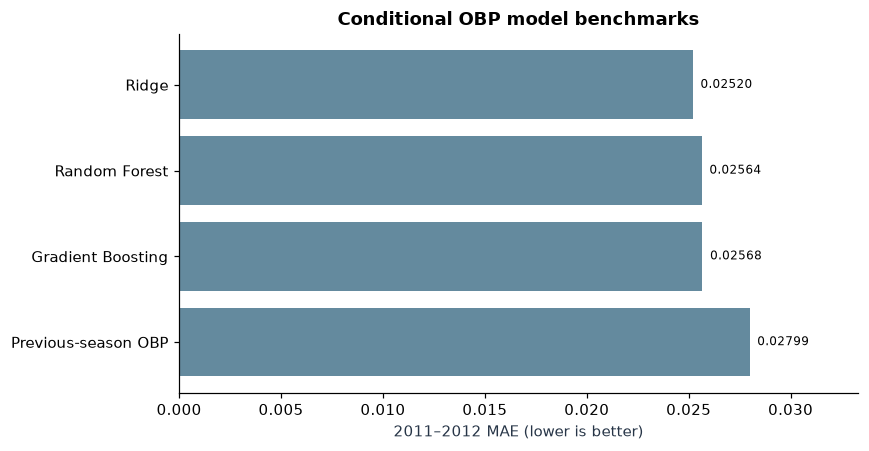

In [27]:
from sklearn.ensemble import RandomForestRegressor,GradientBoostingRegressor
regular_train=decisions[(decisions.target_year<=2010)&(decisions.next_regular==1)].copy()
regular_test=decisions[(decisions.target_year>=2011)&(decisions.next_regular==1)].copy()
extra_models={
    'Ridge':Pipeline([('scale',StandardScaler()),('ridge',Ridge(alpha=10.0))]),
    'Random Forest':RandomForestRegressor(n_estimators=200,max_depth=7,min_samples_leaf=5,
                                          random_state=42,n_jobs=-1),
    'Gradient Boosting':GradientBoostingRegressor(n_estimators=140,learning_rate=.04,
                                                   max_depth=2,random_state=42),
}
extra_bench=[]
for name,est in extra_models.items():
    est.fit(regular_train[FEATURES],regular_train.next_OBP)
    yhat=np.clip(est.predict(regular_test[FEATURES]),0,1)
    extra_bench.append({'model':name,'n_train':len(regular_train),'n_test':len(regular_test),
                        'test_MAE':mean_absolute_error(regular_test.next_OBP,yhat),
                        'test_RMSE':np.sqrt(mean_squared_error(regular_test.next_OBP,yhat))})
extra_bench.append({'model':'Previous-season OBP','n_train':len(regular_train),'n_test':len(regular_test),
                    'test_MAE':mean_absolute_error(regular_test.next_OBP,regular_test.OBP),
                    'test_RMSE':np.sqrt(mean_squared_error(regular_test.next_OBP,regular_test.OBP))})
extra_bench=pd.DataFrame(extra_bench).sort_values('test_MAE')
display(extra_bench.round(4));save_frame(extra_bench,'alternative_model_benchmarks.csv')
fig,ax=plt.subplots(figsize=(8,4.2))
ax.barh(extra_bench.model[::-1],extra_bench.test_MAE[::-1],color='#648a9e')
ax.set(xlabel='2011–2012 MAE (lower is better)',title='Conditional OBP model benchmarks')
# Absolute bars start at zero; precise labels reveal small differences without exaggerating them.
for bar in ax.patches:
    ax.annotate(f'{bar.get_width():.5f}',(bar.get_width(),bar.get_y()+bar.get_height()/2),
                xytext=(5,0),textcoords='offset points',va='center',fontsize=8)
ax.set_xlim(0,float(extra_bench.test_MAE.max())*1.19)
fig.tight_layout();fig.savefig(VISUALS/'obp_model_benchmarks.png',bbox_inches='tight');plt.show()


## 11. Model diagnostics and player-performance uncertainty

**Regression to the mean:** Which previous-year OBP quartiles are systematically over/under-predicted in the actual 2011–2012 holdout? A low or high previous OBP can regress toward league averages. Compare error by previous-OBP quartile, player age, and prior plate-appearance volume. Quantify persistence with a recent three-season form measure and variance for players with available history (without touching future-season information). The 3-year summary below is explanatory; it does not refit the saved Ridge unless explicitly stated.


Previous-season OBP quartile diagnostics:


,prior_obp_q,n,observed_OBP,predicted_OBP,bias,MAE
0,Q1 (low),99,0.3144,0.3166,0.0022,0.0244
1,Q2,99,0.3257,0.3318,0.0060,0.0242
2,Q3,99,0.3339,0.3423,0.0085,0.0238
3,Q4 (high),99,0.3562,0.3636,0.0075,0.0268


Age / prior PA diagnostics:


,age_band,n,bias,MAE
0,<=24,42,0.0040,0.0200
1,25–29,190,0.0045,0.0254
2,30–34,126,0.0089,0.0261
3,35+,38,0.0067,0.0228


,prior_pa_band,n,bias,MAE
0,300–450,100,0.0074,0.0237
1,451–600,151,0.0066,0.0241
2,601+,145,0.0046,0.0263


2002 candidate historical OBP stability (for players with >=2 prior seasons):


,name,OBP,three_year_OBP_mean,three_year_OBP_sd,prior_seasons
0,Lance Berkman,0.430,0.409,0.030,2.0
1,Albert Pujols,0.403,NaN,NaN,NaN
2,Doug Mientkiewicz,0.387,0.356,0.044,2.0
3,Frank Menechino,0.369,0.357,0.017,2.0
4,Barry Bonds,0.515,0.448,0.063,3.0
5,Luis Gonzalez,0.429,0.408,0.019,3.0
6,David Eckstein,0.355,NaN,NaN,NaN
7,Juan Pierre,0.378,0.366,0.017,2.0
8,Aramis Ramirez,0.350,0.321,0.040,2.0
9,Todd Helton,0.432,0.430,0.034,3.0


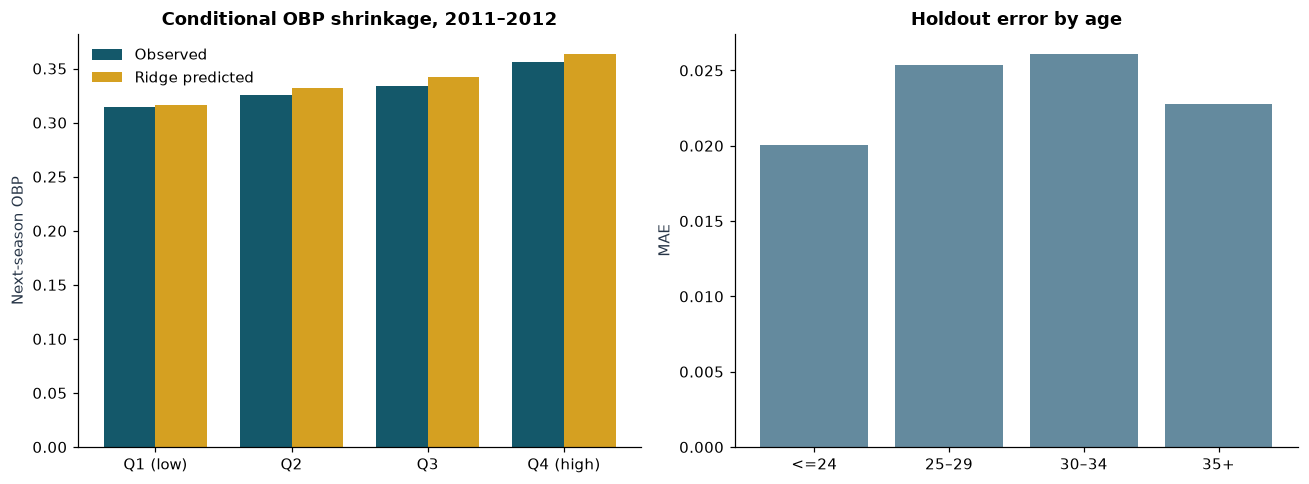

In [28]:
# Use the Ridge already trained above on the original chronological holdout.
diag=test.copy()
diag['obp_error']=diag.predicted_next_OBP-diag.next_OBP
diag['abs_error']=diag.obp_error.abs()
diag['prior_obp_q']=pd.qcut(diag.OBP,4,labels=['Q1 (low)','Q2','Q3','Q4 (high)'])
diag['age_band']=pd.cut(diag.age,bins=[0,24,29,34,65],labels=['<=24','25–29','30–34','35+'])
diag['prior_pa_band']=pd.cut(diag.PA,bins=[299,450,600,2000],labels=['300–450','451–600','601+'])
obp_diag=diag.groupby('prior_obp_q',observed=True).agg(
    n=('playerID','size'),observed_OBP=('next_OBP','mean'),predicted_OBP=('predicted_next_OBP','mean'),
    bias=('obp_error','mean'),MAE=('abs_error','mean')).reset_index()
age_diag=diag.groupby('age_band',observed=True).agg(n=('playerID','size'),bias=('obp_error','mean'),MAE=('abs_error','mean')).reset_index()
pa_diag=diag.groupby('prior_pa_band',observed=True).agg(n=('playerID','size'),bias=('obp_error','mean'),MAE=('abs_error','mean')).reset_index()
print('Previous-season OBP quartile diagnostics:');display(obp_diag.round(4))
print('Age / prior PA diagnostics:');display(age_diag.round(4));display(pa_diag.round(4))
save_frame(obp_diag,'obp_quartile_error_diagnostics.csv')
save_frame(age_diag,'age_error_diagnostics.csv')
save_frame(pa_diag,'playing_time_error_diagnostics.csv')
# Historical stability available at decision time: look back 3 batting seasons.
three=p_all.loc[p_all.yearID.between(1999,2001)&p_all.PA.ge(150),
                ['playerID','yearID','OBP']].copy()
three_form=three.groupby('playerID').agg(prior_seasons=('OBP','size'),three_year_OBP_mean=('OBP','mean'),
                                            three_year_OBP_sd=('OBP','std')).reset_index()
three_form=three_form[three_form.prior_seasons.ge(2)].copy()
stability_2002=scored_2002.merge(three_form,on='playerID',how='left',validate='one_to_one')
stability_2002['three_year_OBP_sd']=stability_2002.three_year_OBP_sd.fillna(np.nan)
print('2002 candidate historical OBP stability (for players with >=2 prior seasons):')
display(stability_2002.sort_values('value_score',ascending=False)[['name','OBP','three_year_OBP_mean','three_year_OBP_sd','prior_seasons']].head(12).round(3))
save_frame(stability_2002[['playerID','name','value_score','prior_seasons','three_year_OBP_mean','three_year_OBP_sd']],
           '2002_prior_three_year_stability.csv')
fig,axs=plt.subplots(1,2,figsize=(12,4.5))
x=np.arange(len(obp_diag));w=.38
axs[0].bar(x-w/2,obp_diag.observed_OBP,width=w,label='Observed',color='#14586a')
axs[0].bar(x+w/2,obp_diag.predicted_OBP,width=w,label='Ridge predicted',color='#d5a021')
axs[0].set_xticks(x,obp_diag.prior_obp_q.astype(str));axs[0].set(ylabel='Next-season OBP',title='Conditional OBP shrinkage, 2011–2012');axs[0].legend(frameon=False)
axs[1].bar(age_diag.age_band.astype(str),age_diag.MAE,color='#648a9e');axs[1].set(ylabel='MAE',title='Holdout error by age')
fig.tight_layout();fig.savefig(VISUALS/'model_bias_risk_diagnostics.png',bbox_inches='tight');plt.show()


# Part 04 · Candidate models, roster construction and selection risk

*Technical execution sequence is unchanged. See `01_Moneyball_Main_Research.ipynb` for a topical, reduced presentation.*


## 12. Illustrative payroll-constrained selection

**Question:** If a hypothetical analyst must select exactly **10** batters under a **$5 million combined listed-salary ceiling** from the retrospective 2002 candidate pool, which set maximizes a *projected offensive index*?

Use integer programming (`scipy.optimize.milp`) with binary choices, 10 selections and salary budget. The score is `max(predicted OBP − .320, 0) × min(previous PA, 700) × P(next year >=300 PA)`. This exercise ignores fielding, roster positions, contract/control rights, availability, transaction costs, pitching, and budget inflation; **it is not a feasible major-league roster recommendation**. The projected score is not expected WAR or wins. Importantly, selection does NOT use actual 2002 performance.


2002 illustrative plan: 10 hitters, listed salary total $4,856,667 of $5,000,000


,name,player_salary,projected_OBP,p_300_PA,projected_index,next_PA,next_OBP
0,Lance Berkman,500000.0,0.403,0.990,56.862,692.0,0.405
1,Albert Pujols,600000.0,0.388,0.993,45.692,675.0,0.394
2,Doug Mientkiewicz,285000.0,0.369,0.954,29.270,554.0,0.365
7,Juan Pierre,600000.0,0.356,0.981,24.168,640.0,0.332
3,Frank Menechino,295000.0,0.366,0.852,22.494,154.0,0.312
10,Paul Lo Duca,546667.0,0.364,0.952,21.699,632.0,0.330
8,Aramis Ramirez,500000.0,0.350,0.980,19.065,570.0,0.279
21,Kevin Millar,900000.0,0.359,0.914,17.717,489.0,0.366
6,David Eckstein,280000.0,0.343,0.950,14.386,702.0,0.363
16,Ben Davis,350000.0,0.349,0.824,12.460,253.0,0.313


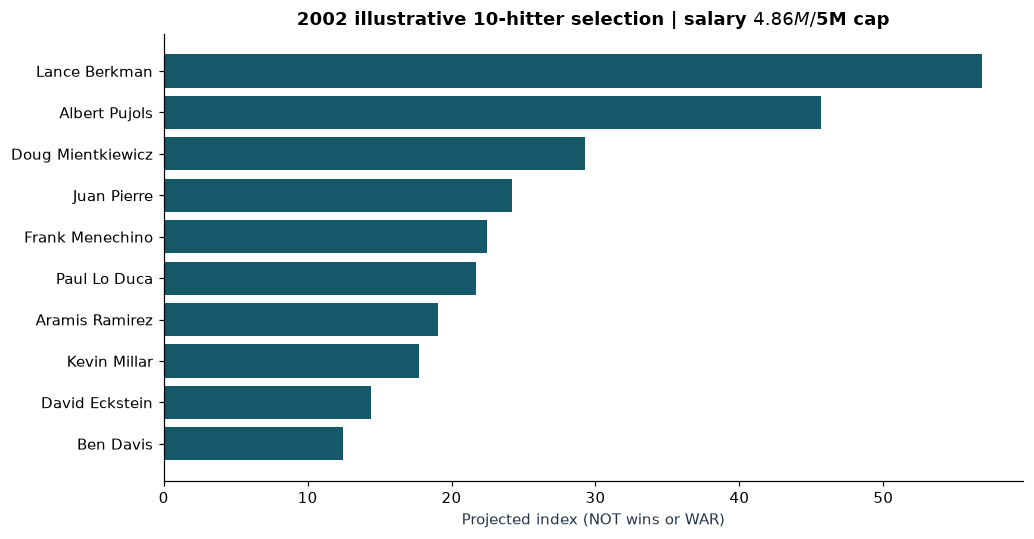

In [29]:
from scipy.optimize import milp,Bounds,LinearConstraint
from scipy.sparse import csc_matrix

budget2002=5_000_000.0
slots2002=10
opt_pool=scored_2002[scored_2002.player_salary>0].copy().reset_index(drop=True)
opt_pool['projected_index']=(np.maximum(opt_pool.projected_OBP-0.320,0)
                             *np.minimum(opt_pool.PA,700)*opt_pool.p_300_PA)
values=opt_pool.projected_index.to_numpy(dtype=float)
costs=opt_pool.player_salary.to_numpy(dtype=float)
n_opt=len(opt_pool)
# Equality: choose exactly ten; inequality: total listed salaries <= $5M.
constraints=LinearConstraint(csc_matrix(np.vstack([np.ones(n_opt),costs/1_000_000])),
                             lb=np.array([slots2002,-np.inf]),
                             ub=np.array([slots2002,budget2002/1_000_000]))
sol=milp(c=-values,integrality=np.ones(n_opt),bounds=Bounds(np.zeros(n_opt),np.ones(n_opt)),
         constraints=constraints,options={'time_limit':45})
if sol.x is None or not sol.success:
    raise RuntimeError(f'Budget optimizer could not find an optimal solution: {sol.message}')
opt_chosen=opt_pool.loc[sol.x>.5].copy().sort_values('projected_index',ascending=False)
assert len(opt_chosen)==slots2002
assert opt_chosen.player_salary.sum() <= budget2002+1
print(f'2002 illustrative plan: {len(opt_chosen)} hitters, listed salary total ${opt_chosen.player_salary.sum():,.0f} of ${budget2002:,.0f}')
display(opt_chosen[['name','player_salary','projected_OBP','p_300_PA','projected_index','next_PA','next_OBP']].round(3))
save_frame(opt_chosen[['playerID','name','player_salary','OBP','projected_OBP','p_300_PA',
                       'projected_index','next_PA','next_OBP','onbase_above_league']],
           '2002_budget_optimized_batters.csv')
fig,ax=plt.subplots(figsize=(9.5,5))
ordered=opt_chosen.sort_values('projected_index')
ax.barh(ordered['name'],ordered.projected_index,color='#14586a');ax.set(xlabel='Projected index (NOT wins or WAR)',
     title=f'2002 illustrative 10-hitter selection | salary ${opt_chosen.player_salary.sum()/1e6:.2f}M / $5M cap')
fig.tight_layout();fig.savefig(VISUALS/'illustrative_budget_optimization.png',bbox_inches='tight');plt.show()


## 13. Advanced team efficiency — expected wins vs observed wins

**Questions:** How many wins did runs scored and runs allowed predict? Is a high observed wins-per-payroll ratio evidence of an unusually effective roster or merely run-differential conversion?

**Methods:** Pythagorean expectation (fixed 1.83 exponent), actual-minus-expected wins residuals, within-season payroll-percentile comparisons, and year-fixed-effect explanatory regressions. All variables are **season outcomes**; these are descriptive diagnostics, *not* features available when constructing a preseason roster. This is not a causal study of payroll decisions.


2002 Oakland | observed W, expected W, residual W, payroll rank percentile:


,name,W,expected_wins,wins_minus_expected,payroll_pct_within_year,wins_rank_minus_payroll_rank
2394,Oakland Athletics,103,95.768,7.232,0.1,0.883


Year-fixed-effect descriptive regressions:


,specification,n,R2_in_sample,payroll_coefficient,payroll_HC3_p
0,Payroll percentile + year,389,0.1599,0.0991,0.0000
1,Payroll percentile + run differential + year,389,0.8806,0.0062,0.2194


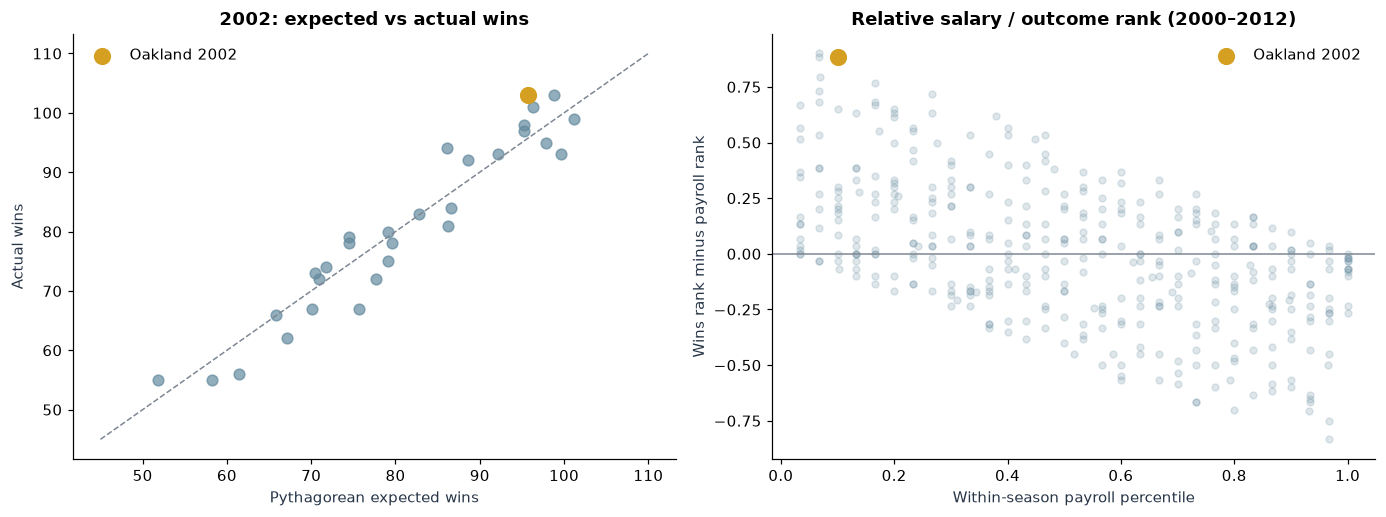

In [30]:
from scipy.stats import pearsonr
import statsmodels.formula.api as smf

advanced_team = team_seasons(raw)
advanced_team = advanced_team[advanced_team.yearID.between(2000, 2012)].copy()
advanced_team = advanced_team.dropna(subset=['W','L','R','RA','payroll']).copy()
advanced_team = advanced_team[(advanced_team.R > 0) & (advanced_team.RA > 0) & (advanced_team.payroll > 0)]
advanced_team['games_decided'] = advanced_team.W + advanced_team.L
advanced_team['pyth_win_pct'] = advanced_team.R.pow(1.83) / (advanced_team.R.pow(1.83) + advanced_team.RA.pow(1.83))
advanced_team['expected_wins'] = advanced_team.pyth_win_pct * advanced_team.games_decided
advanced_team['wins_minus_expected'] = advanced_team.W - advanced_team.expected_wins
advanced_team['run_diff_per_game'] = (advanced_team.R - advanced_team.RA) / advanced_team.G
advanced_team['payroll_pct_within_year'] = advanced_team.groupby('yearID').payroll.rank(pct=True)
advanced_team['wins_pct_within_year'] = advanced_team.groupby('yearID').W.rank(pct=True)
advanced_team['wins_rank_minus_payroll_rank'] = advanced_team.wins_pct_within_year - advanced_team.payroll_pct_within_year

team_explanatory_a = smf.ols('win_pct ~ payroll_pct_within_year + C(yearID)', data=advanced_team).fit(cov_type='HC3')
team_explanatory_b = smf.ols('win_pct ~ payroll_pct_within_year + run_diff_per_game + C(yearID)', data=advanced_team).fit(cov_type='HC3')
team_explanatory = pd.DataFrame([
    {'specification': 'Payroll percentile + year', 'n': int(team_explanatory_a.nobs), 'R2_in_sample':team_explanatory_a.rsquared,
     'payroll_coefficient':team_explanatory_a.params['payroll_pct_within_year'], 'payroll_HC3_p':team_explanatory_a.pvalues['payroll_pct_within_year']},
    {'specification': 'Payroll percentile + run differential + year', 'n': int(team_explanatory_b.nobs), 'R2_in_sample':team_explanatory_b.rsquared,
     'payroll_coefficient':team_explanatory_b.params['payroll_pct_within_year'], 'payroll_HC3_p':team_explanatory_b.pvalues['payroll_pct_within_year']},
])
team_oak_2002 = advanced_team.query('yearID == 2002 and teamID == "OAK"').copy()
print('2002 Oakland | observed W, expected W, residual W, payroll rank percentile:')
display(team_oak_2002[['name','W','expected_wins','wins_minus_expected','payroll_pct_within_year','wins_rank_minus_payroll_rank']].round(3))
print('Year-fixed-effect descriptive regressions:')
display(team_explanatory.round(4))
save_frame(advanced_team[['yearID','teamID','name','W','R','RA','payroll','expected_wins','wins_minus_expected',
                         'payroll_pct_within_year','wins_rank_minus_payroll_rank']], 'advanced_team_expected_wins.csv')
save_frame(team_explanatory,'advanced_team_explanatory_regressions.csv')

fig, axs = plt.subplots(1,2,figsize=(12.7,4.8))
case=advanced_team.query('yearID == 2002')
axs[0].scatter(case.expected_wins,case.W,alpha=.7,color='#648a9e',s=49)
axs[0].scatter(team_oak_2002.expected_wins,team_oak_2002.W,color='#d5a021',s=105,label='Oakland 2002')
axs[0].plot([45,110],[45,110],'--',color='#7e8793',lw=1)
axs[0].set(xlabel='Pythagorean expected wins',ylabel='Actual wins',title='2002: expected vs actual wins')
axs[0].legend(frameon=False)
axs[1].scatter(advanced_team.payroll_pct_within_year,advanced_team.wins_rank_minus_payroll_rank,alpha=.20,s=20,color='#648a9e')
axs[1].scatter(team_oak_2002.payroll_pct_within_year,team_oak_2002.wins_rank_minus_payroll_rank,color='#d5a021',s=105,label='Oakland 2002')
axs[1].axhline(0,color='#7e8793',lw=1)
axs[1].set(xlabel='Within-season payroll percentile',ylabel='Wins rank minus payroll rank',title='Relative salary / outcome rank (2000–2012)')
axs[1].legend(frameon=False)
fig.tight_layout();fig.savefig(VISUALS/'advanced_team_expected_wins.png',bbox_inches='tight');plt.show()

## 14. Four additional forecasting models — expanding-window comparisons

**New model families:** Elastic Net (L1 + L2 regularization), Huber (outlier-robust linear regression), Extra Trees (randomized tree ensemble), and Histogram Gradient Boosting (nonlinear boosting). Compare with prior-season OBP and the existing Ridge on each **2002–2012 forward test year**.

All fits train only on earlier target seasons. Model parameters are fixed **before** seeing these test results (no tuning on the test years). The rate model is *conditional on the next season having ≥300 PA*; the participation model in section 15 handles that separate selection risk. Strong feature correlation means coefficient/importance interpretations are limited.


Historical out-of-time next-season OBP model comparison (lower MAE is better):


,model,years,mean_MAE,median_MAE,mean_RMSE,observations,years_better_than_Ridge
5,Ridge,11,0.02318,0.02352,0.02907,2252,0
3,Huber robust,11,0.02318,0.02356,0.02905,2252,6
0,Elastic Net,11,0.02318,0.02353,0.02908,2252,6
1,Extra Trees,11,0.02345,0.02371,0.02948,2252,5
2,Histogram GB,11,0.02360,0.02382,0.02958,2252,1
4,Previous-season OBP,11,0.02646,0.02613,0.03295,2252,0


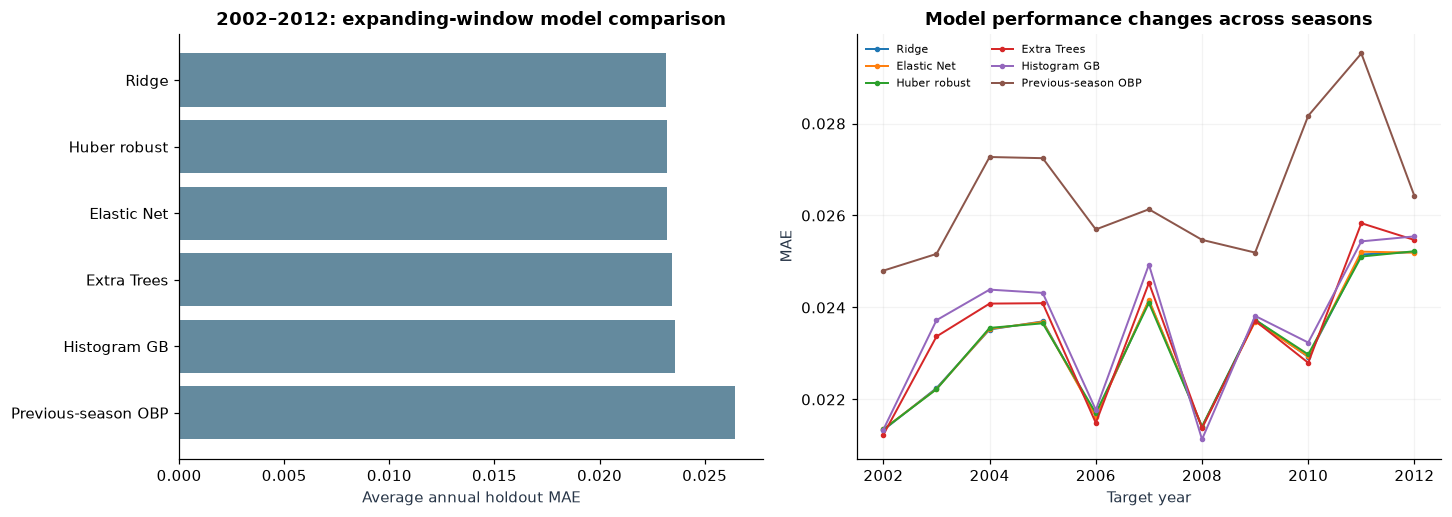

In [31]:
from sklearn.linear_model import ElasticNet, HuberRegressor
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

# Fixed baseline hyperparameters for methodological comparison, not test-optimized values.
def forecasting_models():
    return {
        'Ridge': Pipeline([('scale',StandardScaler()), ('est',Ridge(alpha=10.0))]),
        'Elastic Net': Pipeline([('scale',StandardScaler()), ('est',ElasticNet(alpha=.00025,l1_ratio=.5,max_iter=12000,random_state=42))]),
        'Huber robust': Pipeline([('scale',StandardScaler()), ('est',HuberRegressor(alpha=.001,max_iter=1300))]),
        'Extra Trees': ExtraTreesRegressor(n_estimators=120,min_samples_leaf=5,max_features=.8,random_state=42,n_jobs=-1),
        'Histogram GB': HistGradientBoostingRegressor(max_iter=110,max_leaf_nodes=10,min_samples_leaf=30,
            learning_rate=.05,l2_regularization=.1,random_state=42),
    }

alt_year_rows = []
for target_year in range(2002,2013):
    historical = decisions[(decisions.target_year < target_year) & decisions.next_regular.eq(1) & decisions.next_OBP.notna()]
    future_actuals = decisions[(decisions.target_year == target_year) & decisions.next_regular.eq(1) & decisions.next_OBP.notna()]
    if len(historical) < 150 or len(future_actuals) < 10:
        continue
    X_train, y_train = historical[FEATURES], historical.next_OBP
    X_test, y_test = future_actuals[FEATURES], future_actuals.next_OBP
    for model_name, estimator in forecasting_models().items():
        estimator.fit(X_train, y_train)
        prediction = np.clip(estimator.predict(X_test),0,1)
        alt_year_rows.append({'target_year':target_year,'model':model_name,'n_train':len(X_train),'n_test':len(X_test),
                              'MAE':mean_absolute_error(y_test,prediction),'RMSE':np.sqrt(mean_squared_error(y_test,prediction))})
    alt_year_rows.append({'target_year':target_year,'model':'Previous-season OBP','n_train':len(X_train),'n_test':len(X_test),
                          'MAE':mean_absolute_error(y_test,future_actuals.OBP),
                          'RMSE':np.sqrt(mean_squared_error(y_test,future_actuals.OBP))})

alt_by_year = pd.DataFrame(alt_year_rows)
alt_overall = alt_by_year.groupby('model',as_index=False).agg(years=('target_year','nunique'),mean_MAE=('MAE','mean'),
    median_MAE=('MAE','median'),mean_RMSE=('RMSE','mean'),observations=('n_test','sum')).sort_values('mean_MAE')
mae_wide = alt_by_year.pivot(index='target_year',columns='model',values='MAE')
alt_overall['years_better_than_Ridge'] = alt_overall.model.map({
    m:int((mae_wide[m] < mae_wide['Ridge']).sum()) for m in mae_wide.columns
})
alt_overall.loc[alt_overall.model.eq('Ridge'),'years_better_than_Ridge']=0
print('Historical out-of-time next-season OBP model comparison (lower MAE is better):')
display(alt_overall.round(5))
save_frame(alt_by_year,'deep_dive_alternative_models_by_year.csv')
save_frame(alt_overall,'deep_dive_alternative_models_summary.csv')
fig,axs=plt.subplots(1,2,figsize=(13.3,4.8))
sorted_bar=alt_overall.sort_values('mean_MAE',ascending=False)
axs[0].barh(sorted_bar.model,sorted_bar.mean_MAE,color='#648a9e')
axs[0].set(xlabel='Average annual holdout MAE',title='2002–2012: expanding-window model comparison')
for model in ['Ridge','Elastic Net','Huber robust','Extra Trees','Histogram GB','Previous-season OBP']:
    subset=alt_by_year[alt_by_year.model.eq(model)]
    axs[1].plot(subset.target_year,subset.MAE,label=model,marker='o',ms=2.6,lw=1.3)
axs[1].set(xlabel='Target year',ylabel='MAE',title='Model performance changes across seasons')
axs[1].legend(fontsize=7,frameon=False,ncol=2);axs[1].grid(alpha=.15)
fig.tight_layout();fig.savefig(VISUALS/'deep_dive_forecasting_models.png',bbox_inches='tight');plt.show()

### Holdout permutation importance

This diagnoses the Ridge model's **2011–2012** OBP forecast error when permuting one input at a time. Importance is *test-set diagnostic information only* (no feature selection, refitting, or tuning using these results). Correlated batting variables can share predictive information; this is not a causal driver ranking.


,feature,mean_MAE_increase,sd_across_permutations
0,OBP,0.00262,0.00046
2,ISO,0.00096,0.00047
4,SO_rate,0.00083,0.00018
3,BB_rate,0.00082,0.00025
1,SLG,0.00031,0.00019
6,age,0.00006,0.00009
5,PA,0.00005,0.00007


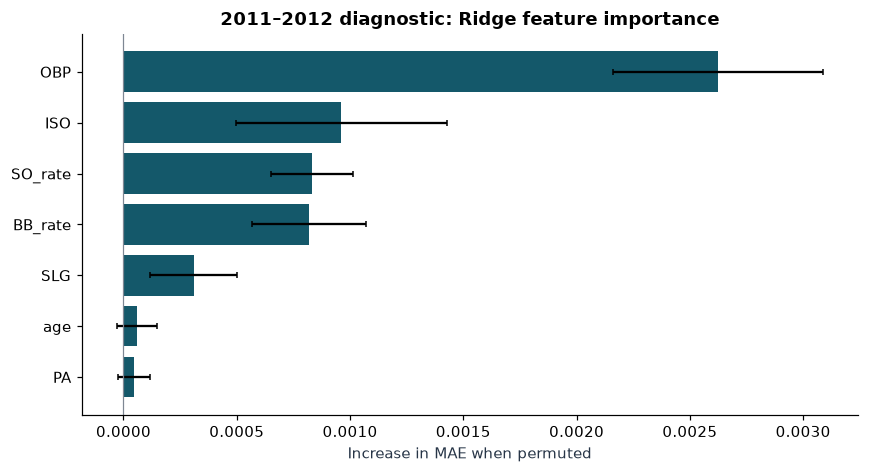

In [32]:
interpret_train=decisions[(decisions.target_year<=2010) & decisions.next_regular.eq(1) & decisions.next_OBP.notna()]
interpret_test=decisions[(decisions.target_year>=2011) & decisions.next_regular.eq(1) & decisions.next_OBP.notna()]
interpret_model=Pipeline([('scale',StandardScaler()), ('est',Ridge(alpha=10.0))])
interpret_model.fit(interpret_train[FEATURES],interpret_train.next_OBP)
importance=permutation_importance(interpret_model,interpret_test[FEATURES],interpret_test.next_OBP,
                                  scoring='neg_mean_absolute_error',n_repeats=20,random_state=42,n_jobs=1)
importance_df=pd.DataFrame({'feature':FEATURES,'mean_MAE_increase':importance.importances_mean,
                            'sd_across_permutations':importance.importances_std}).sort_values('mean_MAE_increase',ascending=False)
display(importance_df.round(5));save_frame(importance_df,'deep_dive_ridge_permutation_importance.csv')
fig,ax=plt.subplots(figsize=(8,4.4))
imp_plot=importance_df.sort_values('mean_MAE_increase')
ax.barh(imp_plot.feature,imp_plot.mean_MAE_increase,xerr=imp_plot.sd_across_permutations,color='#14586a',capsize=2)
ax.axvline(0,color='#7e8793',lw=.8)
ax.set(xlabel='Increase in MAE when permuted',title='2011–2012 diagnostic: Ridge feature importance')
fig.tight_layout();fig.savefig(VISUALS/'deep_dive_permutation_importance.png',bbox_inches='tight');plt.show()

### Gradient-boosting benchmark — XGBoost, LightGBM, CatBoost

Compare these packages against the **same 2002–2012 chronological test cohorts** used above. The code uses fixed hyperparameters; libraries that are not installed are skipped safely. Install packages with `pip install xgboost lightgbm catboost` if all three are needed.

**Saved run:** XGBoost and LightGBM executed; CatBoost was missing. Model performance must be compared on equal populations, and a new untouched evaluation period is needed to establish generalization.


Optional package catboost not installed: skipping CatBoost.
Optional boosted libraries: expanding-window (2002–2012) comparisons:


,model,years,mean_MAE,mean_RMSE
6,Ridge,11,0.02318,0.02907
3,Huber robust,11,0.02318,0.02905
0,Elastic Net,11,0.02318,0.02908
7,XGBoost,11,0.02343,0.02931
1,Extra Trees,11,0.02345,0.02948
4,LightGBM,11,0.02359,0.02959
2,Histogram GB,11,0.02360,0.02958
5,Previous-season OBP,11,0.02646,0.03295


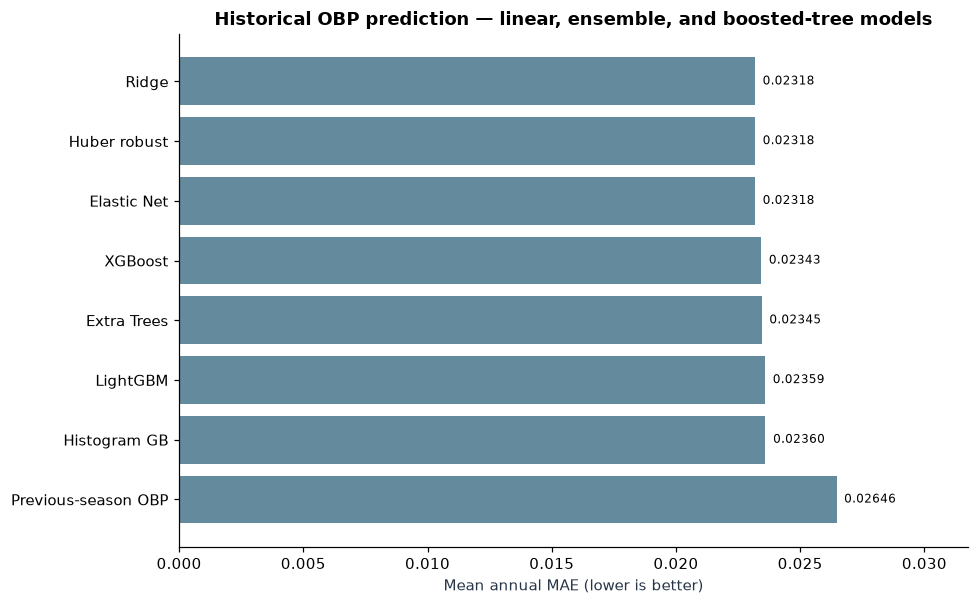

WindowsPath('C:/Users/htpar/Downloads/outputs/processed/deep_dive_optional_boosted_models_summary.csv')

In [33]:
# Optional third-party models: each imports independently; missing packages are not fatal.
optional_factories={}
try:
    from xgboost import XGBRegressor
    optional_factories['XGBoost']=lambda: XGBRegressor(n_estimators=175,max_depth=2,learning_rate=.04,
        subsample=.85,colsample_bytree=.9,min_child_weight=8,reg_lambda=5,objective='reg:squarederror',
        random_state=42,n_jobs=2)
except ImportError:
    print('Optional package xgboost not installed: skipping XGBoost.')
try:
    from lightgbm import LGBMRegressor
    optional_factories['LightGBM']=lambda: LGBMRegressor(n_estimators=145,max_depth=3,num_leaves=10,
        learning_rate=.04,min_child_samples=35,reg_lambda=2,verbosity=-1,random_state=42,n_jobs=2)
except ImportError:
    print('Optional package lightgbm not installed: skipping LightGBM.')
try:
    from catboost import CatBoostRegressor
    optional_factories['CatBoost']=lambda: CatBoostRegressor(iterations=175,depth=3,learning_rate=.04,
        l2_leaf_reg=5,loss_function='RMSE',verbose=False,random_seed=42,thread_count=2)
except ImportError:
    print('Optional package catboost not installed: skipping CatBoost.')

boosted_rows=[]
for target_year in range(2002,2013):
    history=decisions[(decisions.target_year<target_year)&decisions.next_regular.eq(1)&decisions.next_OBP.notna()]
    holdout=decisions[(decisions.target_year==target_year)&decisions.next_regular.eq(1)&decisions.next_OBP.notna()]
    if len(history)<150 or len(holdout)<10: continue
    for name,create in optional_factories.items():
        candidate=create()
        candidate.fit(history[FEATURES],history.next_OBP)
        prediction=np.clip(candidate.predict(holdout[FEATURES]),0,1)
        boosted_rows.append({'model':name,'target_year':target_year,'n_train':len(history),
            'n_test':len(holdout),'MAE':mean_absolute_error(holdout.next_OBP,prediction),
            'RMSE':np.sqrt(mean_squared_error(holdout.next_OBP,prediction))})

boosted_by_year=pd.DataFrame(boosted_rows,columns=['model','target_year','n_train','n_test','MAE','RMSE'])
if len(boosted_by_year):
    boosted_summary=boosted_by_year.groupby('model',as_index=False).agg(
        years=('target_year','nunique'),mean_MAE=('MAE','mean'),mean_RMSE=('RMSE','mean'))
    # Combine the same-year regular-hitter forecasts, without selecting a 'winner' for subsequent fitting.
    all_models=pd.concat([alt_by_year[['target_year','model','MAE','RMSE']],
                          boosted_by_year[['target_year','model','MAE','RMSE']]],ignore_index=True)
    all_models_summary=all_models.groupby('model',as_index=False).agg(
        years=('target_year','nunique'),mean_MAE=('MAE','mean'),mean_RMSE=('RMSE','mean')).sort_values('mean_MAE')
    print('Optional boosted libraries: expanding-window (2002–2012) comparisons:')
    display(all_models_summary.round(5))
    save_frame(all_models_summary,'deep_dive_all_regressors_with_boosters.csv')
    fig,ax=plt.subplots(figsize=(9,5.6))
    view=all_models_summary.sort_values('mean_MAE',ascending=False)
    ax.barh(view.model,view.mean_MAE,color='#648a9e')
    ax.set(xlabel='Mean annual MAE (lower is better)',title='Historical OBP prediction — linear, ensemble, and boosted-tree models')
    # Report exact differences; no truncated MAE bars.
    for bar in ax.patches:
        ax.annotate(f'{bar.get_width():.5f}',(bar.get_width(),bar.get_y()+bar.get_height()/2),
                    xytext=(5,0),textcoords='offset points',va='center',fontsize=8)
    ax.set_xlim(0,float(view.mean_MAE.max())*1.20)
    fig.tight_layout();fig.savefig(VISUALS/'deep_dive_optional_boosted_models.png',bbox_inches='tight');plt.show()
else:
    boosted_summary=pd.DataFrame(columns=['model','years','mean_MAE','mean_RMSE'])
    print('No optional boosted-tree libraries found; sklearn benchmarks remain fully reproducible.')
save_frame(boosted_by_year,'deep_dive_optional_boosted_models_by_year.csv')
save_frame(boosted_summary,'deep_dive_optional_boosted_models_summary.csv')

## 15. Different classification models — next-season participation

Compare **Logistic Regression** with **Random Forest Classifier** and **Histogram Gradient Boosting Classifier** (plus a historical constant-rate baseline). Models train on target years through 2010 and are evaluated on all salary-listed candidates in 2011–2012, including those who disappear or receive little playing time. Use Brier score and log loss for probability quality, ROC-AUC for discrimination. Results cannot generalize to players lacking salary records; **listed contracts are not proof of acquisition availability**.


Participation probabilities — all salaried holdout candidates:


,model,n_test,Brier,log_loss,ROC_AUC,predicted_regular_rate
0,Logistic regression,504,0.1415,0.4384,0.7723,0.7694
2,Histogram GB classifier,504,0.1416,0.4384,0.7763,0.7709
1,Random Forest classifier,504,0.1438,0.4463,0.7656,0.7691
3,Historical constant,504,0.1686,0.5202,0.5000,0.7999


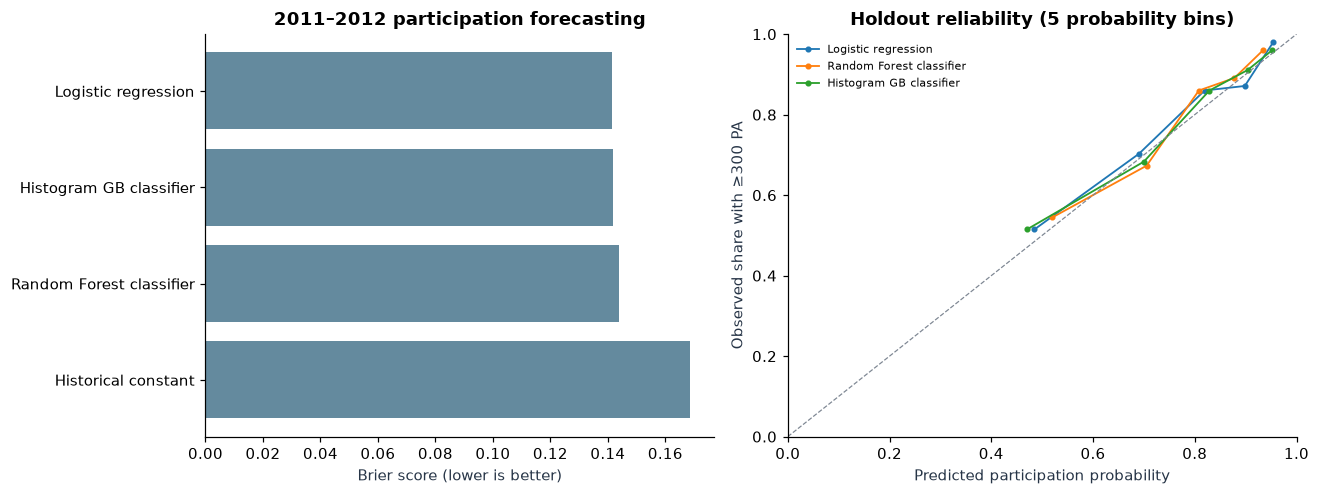

In [34]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import log_loss

participation_models={
    'Logistic regression':Pipeline([('scale',StandardScaler()),('est',LogisticRegression(max_iter=1500,random_state=42))]),
    'Random Forest classifier':RandomForestClassifier(n_estimators=230,max_depth=6,min_samples_leaf=12,
                                                      random_state=42,n_jobs=-1),
    'Histogram GB classifier':HistGradientBoostingClassifier(max_iter=110,max_leaf_nodes=10,
                        min_samples_leaf=30,learning_rate=.05,l2_regularization=1.0,random_state=42),
}
participation_rows=[]
participation_test_prob=pd.DataFrame({'playerID':risk_test.playerID.to_numpy(),
                                     'target_year':risk_test.target_year.to_numpy(),
                                     'observed_regular':risk_test.next_regular.to_numpy()})
for name,clf in participation_models.items():
    clf.fit(risk_train[FEATURES],risk_train.next_regular)
    proba=np.clip(clf.predict_proba(risk_test[FEATURES])[:,1],1e-6,1-1e-6)
    participation_test_prob[name]=proba
    participation_rows.append({'model':name,'n_test':len(risk_test),
        'Brier':brier_score_loss(risk_test.next_regular,proba),
        'log_loss':log_loss(risk_test.next_regular,proba,labels=[0,1]),
        'ROC_AUC':roc_auc_score(risk_test.next_regular,proba),
        'predicted_regular_rate':proba.mean()})
constant_prob=np.repeat(np.clip(risk_train.next_regular.mean(),1e-6,1-1e-6),len(risk_test))
participation_test_prob['Historical constant']=constant_prob
participation_rows.append({'model':'Historical constant','n_test':len(risk_test),
    'Brier':brier_score_loss(risk_test.next_regular,constant_prob),
    'log_loss':log_loss(risk_test.next_regular,constant_prob,labels=[0,1]),
    'ROC_AUC':.5,'predicted_regular_rate':constant_prob.mean()})
participation_results=pd.DataFrame(participation_rows).sort_values('Brier')
print('Participation probabilities — all salaried holdout candidates:')
display(participation_results.round(4))
save_frame(participation_results,'deep_dive_participation_classifier_comparison.csv')
save_frame(participation_test_prob,'deep_dive_participation_holdout_predictions.csv')
fig,axs=plt.subplots(1,2,figsize=(12.1,4.6))
bar=participation_results.sort_values('Brier',ascending=False)
axs[0].barh(bar.model,bar.Brier,color='#648a9e');axs[0].set(xlabel='Brier score (lower is better)',title='2011–2012 participation forecasting')
for name in ['Logistic regression','Random Forest classifier','Histogram GB classifier']:
    calib=pd.DataFrame({'prob':participation_test_prob[name].values,'actual':participation_test_prob.observed_regular.values})
    calib['bin']=pd.qcut(calib.prob,5,duplicates='drop')
    grouped=calib.groupby('bin',observed=True).agg(prob=('prob','mean'),actual=('actual','mean'))
    axs[1].plot(grouped.prob,grouped.actual,'o-',label=name,ms=3,lw=1.2)
axs[1].plot([0,1],[0,1],'--',color='#7e8793',lw=.8)
axs[1].set(xlim=(0,1),ylim=(0,1),xlabel='Predicted participation probability',
       ylabel='Observed share with ≥300 PA',title='Holdout reliability (5 probability bins)')
axs[1].legend(fontsize=7,frameon=False)
fig.tight_layout();fig.savefig(VISUALS/'deep_dive_participation_classifiers.png',bbox_inches='tight');plt.show()

## 16. Forecast uncertainty — held-out conformal prediction intervals

A single estimated OBP (e.g. .350) hides genuine year-to-year volatility. Create **90% split-conformal prediction intervals** from past, season-separated data:

- **Train:** target seasons up to 2007
- **Calibrate absolute residuals:** 2008–2010 (without retraining)
- **Final untouched temporal test:** 2011–2012

The intervals concern next-season **OBP for players who subsequently reach ≥300 PA**. This is an empirical historical coverage test under distribution-stability assumptions, **not** an unconditional interval for all candidates and not a guarantee for any one player.


Empirical holdout interval coverage (not guaranteed):


,method,target_coverage,n_train,n_calibrate,n_test_regular,absolute_error_quantile,observed_2011_12_coverage,mean_interval_width,holdout_MAE
0,Chronological split conformal (Ridge),0.9,2446,617,396,0.0454,0.8434,0.0908,0.0254


,previous_obp_group,n,observed_coverage,mean_true_OBP,mean_predicted_OBP
0,Q1,99,0.8687,0.3144,0.3179
1,Q2,99,0.8384,0.3257,0.3340
2,Q3,99,0.8485,0.3339,0.3451
3,Q4,99,0.8182,0.3562,0.3673


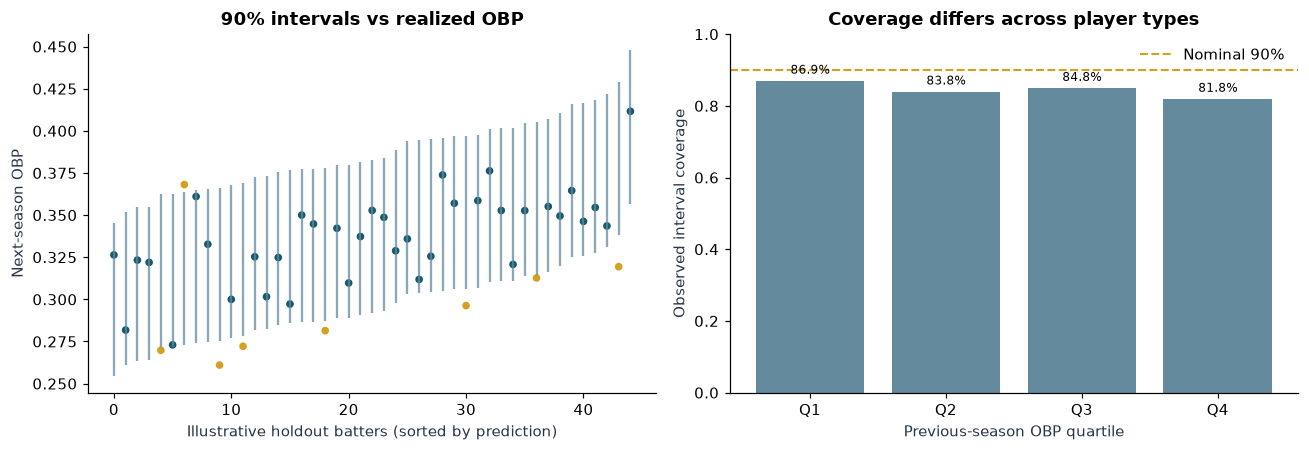

In [35]:
from math import ceil
conf_train=decisions[(decisions.target_year<=2007)&decisions.next_regular.eq(1)&decisions.next_OBP.notna()].copy()
conf_cal=decisions[decisions.target_year.between(2008,2010)&decisions.next_regular.eq(1)&decisions.next_OBP.notna()].copy()
conf_test=decisions[(decisions.target_year>=2011)&decisions.next_regular.eq(1)&decisions.next_OBP.notna()].copy()
assert conf_train.target_year.max() < conf_cal.target_year.min() < conf_test.target_year.min()
conformal_rate=Pipeline([('scale',StandardScaler()),('est',Ridge(alpha=10.0))])
conformal_rate.fit(conf_train[FEATURES],conf_train.next_OBP)
absolute_cal_error=np.abs(conf_cal.next_OBP-conformal_rate.predict(conf_cal[FEATURES]))
alpha=.10
q_level=min(1.0,ceil((len(absolute_cal_error)+1)*(1-alpha))/len(absolute_cal_error))
q90=float(np.quantile(absolute_cal_error,q_level,method='higher'))
conf_test['point_prediction']=np.clip(conformal_rate.predict(conf_test[FEATURES]),0,1)
conf_test['lower_90']=np.clip(conf_test.point_prediction-q90,0,1)
conf_test['upper_90']=np.clip(conf_test.point_prediction+q90,0,1)
conf_test['covered']=((conf_test.next_OBP>=conf_test.lower_90)&(conf_test.next_OBP<=conf_test.upper_90)).astype(int)
conf_test['previous_obp_group']=pd.qcut(conf_test.OBP,4,labels=['Q1','Q2','Q3','Q4'])
conformal_results=pd.DataFrame([{'method':'Chronological split conformal (Ridge)', 'target_coverage':.90,
   'n_train':len(conf_train),'n_calibrate':len(conf_cal),'n_test_regular':len(conf_test),
   'absolute_error_quantile':q90,'observed_2011_12_coverage':conf_test.covered.mean(),
   'mean_interval_width':(conf_test.upper_90-conf_test.lower_90).mean(),
   'holdout_MAE':mean_absolute_error(conf_test.next_OBP,conf_test.point_prediction)}])
conformal_groups=conf_test.groupby('previous_obp_group',observed=True).agg(
    n=('playerID','size'),observed_coverage=('covered','mean'),mean_true_OBP=('next_OBP','mean'),
    mean_predicted_OBP=('point_prediction','mean')).reset_index()
print('Empirical holdout interval coverage (not guaranteed):')
display(conformal_results.round(4));display(conformal_groups.round(4))
save_frame(conformal_results,'deep_dive_conformal_coverage.csv')
save_frame(conformal_groups,'deep_dive_conformal_coverage_by_obp_group.csv')
save_frame(conf_test[['playerID','target_year','OBP','next_OBP','point_prediction','lower_90','upper_90','covered']],
           'deep_dive_conformal_holdout_predictions.csv')
fig,axs=plt.subplots(1,2,figsize=(12,4.2))
show_conf=conf_test.sample(min(45,len(conf_test)),random_state=42).sort_values('point_prediction').reset_index(drop=True)
x=np.arange(len(show_conf))
axs[0].vlines(x,show_conf.lower_90,show_conf.upper_90,color='#648a9e',alpha=.75)
axs[0].scatter(x,show_conf.next_OBP,c=['#d5a021' if not hit else '#14586a' for hit in show_conf.covered],s=16)
axs[0].set(xlabel='Illustrative holdout batters (sorted by prediction)',ylabel='Next-season OBP',title='90% intervals vs realized OBP')
axs[1].bar(conformal_groups.previous_obp_group.astype(str),conformal_groups.observed_coverage,color='#648a9e')
axs[1].axhline(.9,ls='--',lw=1.4,color='#d5a021',label='Nominal 90%')
axs[1].set(ylim=(0,1),xlabel='Previous-season OBP quartile',ylabel='Observed interval coverage',title='Coverage differs across player types')
axs[1].legend(frameon=False)
for bar in axs[1].patches:
    axs[1].annotate(f'{100*bar.get_height():.1f}%',
        (bar.get_x()+bar.get_width()/2,bar.get_height()),xytext=(0,3),
        textcoords='offset points',ha='center',va='bottom',fontsize=8)
fig.tight_layout();fig.savefig(VISUALS/'deep_dive_conformal_intervals.png',bbox_inches='tight');plt.show()

## 17. Recommendation robustness — budgets, candidate pools, and roster size

A recommendation can appear strong under one hand-picked rule but fail when realistic assumptions change. Re-run historical **2002–2012** prospective screens with:

- Lower salary cutoffs at **30%, 40%, and 50%** of each year's recorded salary distribution.
- Shortlists of **5, 10, and 15** hitters.
- Two rule-based methods: model value score and previous-season OBP.

For each scenario, train on **earlier seasons only**, then compare observed on-base-event surplus and the fraction reaching 300 PA the following year. Differences are evaluated **within the same year**. These tests are exploratory; changing rules in hindsight can create multiple-testing bias. These are still *listed salaries*, not freely executable trades or acquisitions.


Strategy sensitivity: positive difference favors the model screen; same 2002–2012 target years:


,salary_quantile,picks,years,mean_yearly_model_minus_prior_OBP,years_model_better,median_yearly_difference
0,0.3,5,11,16.20,8,16.42
1,0.3,10,11,12.84,6,30.51
2,0.3,15,11,10.73,6,15.97
3,0.4,5,11,15.07,7,18.91
4,0.4,10,11,12.55,6,13.61
5,0.4,15,11,28.32,7,33.06
6,0.5,5,11,15.35,6,15.06
7,0.5,10,11,-1.71,6,0.40
8,0.5,15,11,15.20,7,36.25


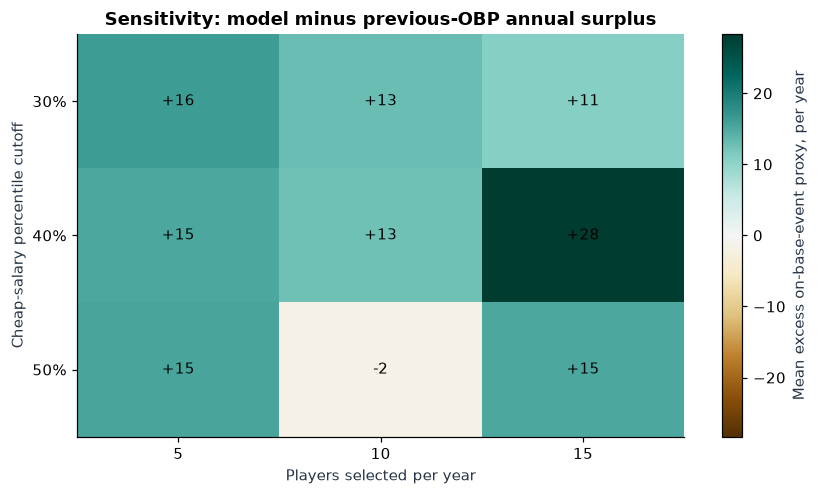

In [36]:
from itertools import product
robust_rows=[]
for target_year in range(2002,2013):
    historic=decisions[decisions.target_year<target_year]
    all_candidates=decisions[decisions.target_year==target_year]
    if len(historic)<150 or len(all_candidates)<20:
        continue
    rated=score_candidates(historic,all_candidates)
    for salary_quantile,picks in product([.30,.40,.50],[5,10,15]):
        salary_threshold=rated.player_salary.quantile(salary_quantile)
        cheap=rated[rated.player_salary<=salary_threshold]
        if len(cheap)<picks:
            continue
        picks_value=cheap.nlargest(picks,'value_score')
        picks_obp=cheap.nlargest(picks,'OBP')
        for method,picked in [('Model value score',picks_value),('Previous-season OBP',picks_obp)]:
            robust_rows.append({'target_year':target_year,'salary_quantile':salary_quantile,'picks':picks,
                                'method':method,'events_above_league':picked.onbase_above_league.sum(),
                                'regular_share':picked.next_regular.mean(),'listed_salary_sum':picked.player_salary.sum()})
robust_years=pd.DataFrame(robust_rows)
matched_robust = robust_years.pivot(index=['target_year','salary_quantile','picks'],
                                      columns='method',values='events_above_league').dropna().reset_index()
matched_robust['model_minus_prior_OBP']=matched_robust['Model value score']-matched_robust['Previous-season OBP']
robust_summary=matched_robust.groupby(['salary_quantile','picks'],as_index=False).agg(
    years=('target_year','nunique'),mean_yearly_model_minus_prior_OBP=('model_minus_prior_OBP','mean'),
    years_model_better=('model_minus_prior_OBP',lambda s:int((s>0).sum())),
    median_yearly_difference=('model_minus_prior_OBP','median'))
print('Strategy sensitivity: positive difference favors the model screen; same 2002–2012 target years:')
display(robust_summary.round(2))
save_frame(robust_years,'deep_dive_strategy_sensitivity_by_year.csv')
save_frame(robust_summary,'deep_dive_strategy_sensitivity_summary.csv')
mat=robust_summary.pivot(index='salary_quantile',columns='picks',values='mean_yearly_model_minus_prior_OBP')
fig,ax=plt.subplots(figsize=(7.8,4.6))
heat=ax.imshow(mat.values,cmap='BrBG',aspect='auto',vmin=-max(abs(mat.values.min()),abs(mat.values.max())),
               vmax=max(abs(mat.values.min()),abs(mat.values.max())))
ax.set_xticks(np.arange(len(mat.columns)),[str(x) for x in mat.columns]);ax.set_yticks(np.arange(len(mat.index)),[f'{int(x*100)}%' for x in mat.index])
ax.set(xlabel='Players selected per year',ylabel='Cheap-salary percentile cutoff',
       title='Sensitivity: model minus previous-OBP annual surplus')
for i in range(len(mat.index)):
    for j in range(len(mat.columns)):
        ax.text(j,i,f'{mat.values[i,j]:+.0f}',ha='center',va='center',fontsize=10)
fig.colorbar(heat,ax=ax,label='Mean excess on-base-event proxy, per year')
fig.tight_layout();fig.savefig(VISUALS/'deep_dive_recommendation_sensitivity.png',bbox_inches='tight');plt.show()

## 20. Source-cohort audit, longitudinal aging and 1–3 year batting trends

**Questions:** How much does salary-record availability restrict the *actual* future candidate set? Does offensive performance move differently by age and recent trend?

This analysis uses **year t information only** to construct rolling historical features. The year-t to year-(t+1) age curve is descriptive and conditional on both seasons having at least 300 plate appearances; it is **not** a causal aging effect because players can retire or lose playing time. For trend features, missing exact calendar years are **not** filled with performance data from an older, nonadjacent season.


Candidate cohort without filtering by future salary or future playing time:


,target_year,previous_300PA,salary_listed,next_300PA,next_any
0,2011,270,256,202,261
1,2012,265,248,196,251


,age_group,n,mean_delta_OBP,median_delta_OBP,mean_delta_SLG
0,<=24,350,0.0028,0.0029,0.0052
1,25–27,874,-0.0021,-0.0027,-0.0055
2,28–30,972,-0.0030,-0.0025,-0.0077
3,31–33,762,-0.0052,-0.0056,-0.0111
4,34–37,434,-0.0045,-0.0031,-0.0133
5,38+,90,-0.0125,-0.0176,-0.0225


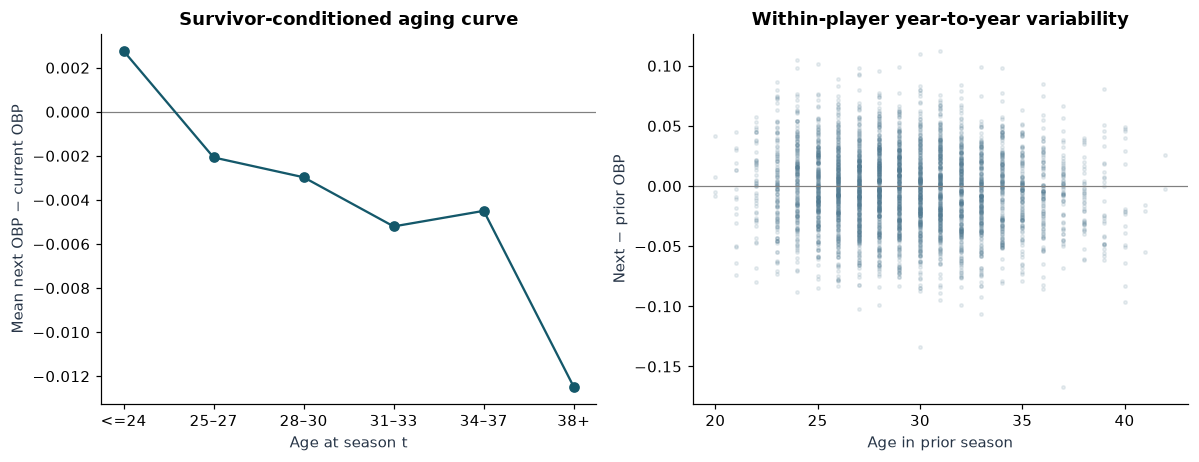

In [37]:
# Use the complete prior-year player pool, including players without t+1 salary rows.
from sklearn.preprocessing import SplineTransformer
from sklearn.metrics import mean_absolute_error, mean_squared_error
all_seasons = p_all.sort_values(['playerID','yearID']).copy()
longitudinal = all_seasons.loc[all_seasons.yearID.between(1995,2011) & all_seasons.PA.ge(300)].copy()
for lag in (1,2,3):
    prior = all_seasons[['playerID','yearID','OBP','SLG','PA']].copy()
    prior['yearID'] += lag
    prior = prior.rename(columns={c:f'{c}_lag{lag}' for c in ('OBP','SLG','PA')})
    longitudinal = longitudinal.merge(prior,on=['playerID','yearID'],how='left',validate='one_to_one')
longitudinal['obp_trend_1y'] = (longitudinal['OBP']-longitudinal['OBP_lag1']).where(longitudinal['PA_lag1'].ge(100))
longitudinal['obp_trend_2y'] = (longitudinal['OBP']-longitudinal['OBP_lag2']).where(longitudinal['PA_lag2'].ge(100))/2
longitudinal['obp_trend_1y_missing'] = longitudinal['obp_trend_1y'].isna().astype(int)
longitudinal['obp_trend_2y_missing'] = longitudinal['obp_trend_2y'].isna().astype(int)
# Neutral zero for missing change, with explicit missingness flags.
for c in ['obp_trend_1y','obp_trend_2y']:
    longitudinal[c] = longitudinal[c].fillna(0)

next_outcome=all_seasons[['playerID','yearID','PA','OBP','SLG']].copy()
next_outcome.yearID -= 1
next_outcome=next_outcome.rename(columns={'PA':'next_PA','OBP':'next_OBP','SLG':'next_SLG'})
full_decisions=(longitudinal.merge(next_outcome,on=['playerID','yearID'],how='left',validate='one_to_one')
               .assign(target_year=lambda d:d.yearID+1))
full_decisions['next_PA']=full_decisions['next_PA'].fillna(0)
full_decisions['next_regular']=full_decisions.next_PA.ge(300).astype(int)
full_decisions['next_any']=full_decisions.next_PA.gt(0).astype(int)
# Keep all pre-decision hitters; salaries are not required for performance or risk models.
next_pay=player_salary[['playerID','yearID','player_salary']].copy()
next_pay['yearID']-=1
full_decisions=full_decisions.merge(next_pay,on=['playerID','yearID'],how='left',validate='one_to_one')
full_decisions['has_listed_next_salary']=full_decisions.player_salary.gt(0).astype(int)
full_decisions['age_group']=pd.cut(full_decisions.age,[15,24,27,30,33,37,60],labels=['<=24','25–27','28–30','31–33','34–37','38+'])
source_cohort=(full_decisions[full_decisions.target_year.isin([2011,2012])]
 .groupby('target_year',as_index=False).agg(previous_300PA=('playerID','size'),
 salary_listed=('has_listed_next_salary','sum'),next_300PA=('next_regular','sum'),
 next_any=('next_any','sum')))
print('Candidate cohort without filtering by future salary or future playing time:')
display(source_cohort)
assert full_decisions[['playerID','target_year']].duplicated().sum()==0
assert full_decisions[full_decisions.target_year.eq(2011)].shape[0]>=decisions[decisions.target_year.eq(2011)].shape[0]
save_frame(source_cohort,'final_cohort_salary_and_survival_audit.csv')
save_frame(full_decisions[['playerID','name','yearID','target_year','age','PA','OBP',
 'obp_trend_1y','obp_trend_2y','obp_trend_1y_missing','obp_trend_2y_missing',
 'next_PA','next_regular','player_salary','has_listed_next_salary']],
 'final_all_candidates_prospective_panel.csv')
# Descriptive one-year aging changes among survivors; never described as causal.
aging_rows=full_decisions[full_decisions.next_PA.ge(300)&full_decisions.next_OBP.notna() & full_decisions.age_group.notna()].copy()
aging_rows['delta_OBP']=aging_rows.next_OBP-aging_rows.OBP
aging_rows['delta_SLG']=aging_rows.next_SLG-aging_rows.SLG
aging=aging_rows.groupby('age_group',observed=True).agg(
 n=('delta_OBP','size'),mean_delta_OBP=('delta_OBP','mean'),
 median_delta_OBP=('delta_OBP','median'),mean_delta_SLG=('delta_SLG','mean')).reset_index()
display(aging.round(4)); save_frame(aging,'final_survivor_aging_curve.csv')
fig,axes=plt.subplots(1,2,figsize=(11,4.3))
axes[0].axhline(0,c='gray',lw=.8)
axes[0].plot(aging.age_group.astype(str),aging.mean_delta_OBP,'o-',color='#14586a')
axes[0].set(xlabel='Age at season t',ylabel='Mean next OBP − current OBP',title='Survivor-conditioned aging curve')
axes[1].scatter(aging_rows.age,aging_rows.delta_OBP,s=5,alpha=.12,color='#527b92')
axes[1].axhline(0,c='gray',lw=.8)
axes[1].set(xlabel='Age in prior season',ylabel='Next − prior OBP',title='Within-player year-to-year variability')
fig.tight_layout();fig.savefig(VISUALS/'final_aging_curve_and_variability.png',bbox_inches='tight');plt.show()


### Prospective age spline and recent-trend ablation

Compare the original 7-feature Ridge model to age-spline and 1–2-year OBP-trend models on **seasons 2002–2012**, with an expanding history. Models are trained only on complete prior target years. Rate error is reported **conditionally** on observing next-season regular hitters (≥300 PA); later sections explicitly model attrition.


Time-respecting age/trend ablation (conditional on next season >=300 PA):


,model,years,mean_MAE
0,Age spline + OBP trends,11,0.02235
2,Original Ridge,11,0.02323
1,Age spline Ridge,11,0.02324


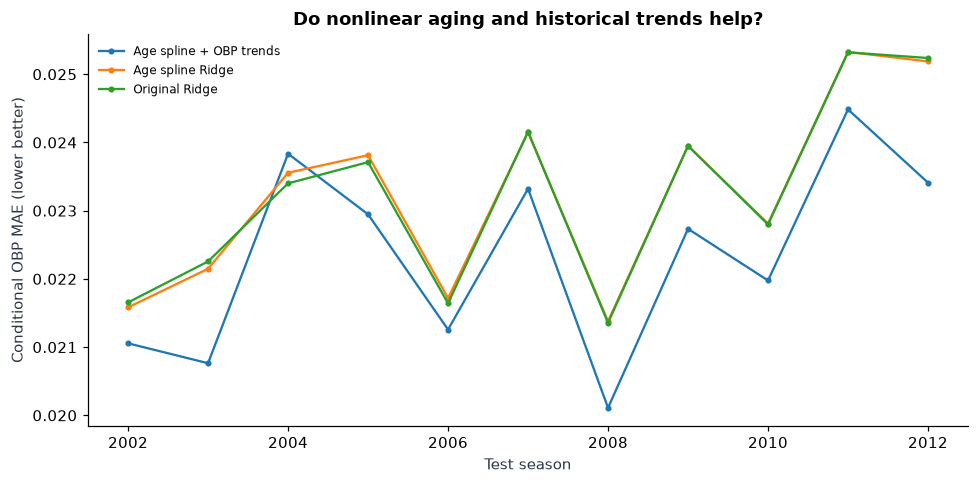

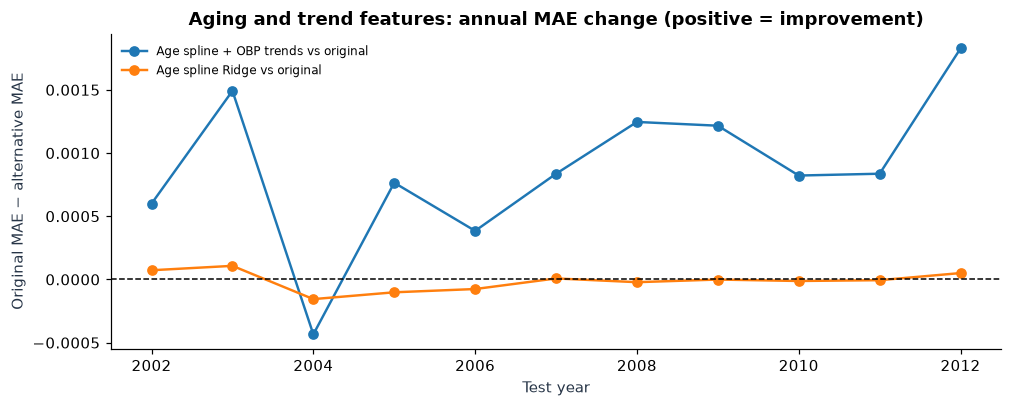

In [38]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, SplineTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
extra_trend_cols=['obp_trend_1y','obp_trend_2y','obp_trend_1y_missing','obp_trend_2y_missing']

def age_trend_estimator(variant):
    if variant=='Original Ridge':
        return Pipeline([('scale',StandardScaler()),('ridge',Ridge(alpha=10.0))])
    if variant=='Age spline Ridge':
        tx=ColumnTransformer([('standard',StandardScaler(),[c for c in FEATURES if c!='age']),
                               ('spline',SplineTransformer(n_knots=5,degree=3,extrapolation='constant'),['age'])])
        return Pipeline([('prep',tx),('ridge',Ridge(alpha=10.0))])
    cols=[c for c in FEATURES if c!='age']+extra_trend_cols
    tx=ColumnTransformer([('standard',StandardScaler(),cols),
                           ('spline',SplineTransformer(n_knots=5,degree=3,extrapolation='constant'),['age'])])
    return Pipeline([('prep',tx),('ridge',Ridge(alpha=10.0))])

rate_rows=[]
for year in range(2002,2013):
    older=full_decisions[(full_decisions.target_year<year)&full_decisions.next_regular.eq(1)&full_decisions.next_OBP.notna()].copy()
    newer=full_decisions[(full_decisions.target_year==year)&full_decisions.next_regular.eq(1)&full_decisions.next_OBP.notna()].copy()
    if len(older)<150 or len(newer)<10:continue
    for label in ['Original Ridge','Age spline Ridge','Age spline + OBP trends']:
        features=FEATURES if label=='Original Ridge' else FEATURES+extra_trend_cols
        m=age_trend_estimator(label)
        m.fit(older[features],older.next_OBP)
        estimated=np.clip(m.predict(newer[features]),0,1)
        rate_rows.append({'target_year':year,'model':label,'n':len(newer),
                          'MAE':mean_absolute_error(newer.next_OBP,estimated)})
age_trend_cv=pd.DataFrame(rate_rows)
age_trend_summary=age_trend_cv.groupby('model',as_index=False).agg(years=('target_year','nunique'),mean_MAE=('MAE','mean'))
print('Time-respecting age/trend ablation (conditional on next season >=300 PA):')
display(age_trend_summary.sort_values('mean_MAE').round(5))
save_frame(age_trend_cv,'final_aging_trend_backtest_by_year.csv')
save_frame(age_trend_summary,'final_aging_trend_backtest_summary.csv')
fig,ax=plt.subplots(figsize=(9,4.5))
for label,g in age_trend_cv.groupby('model'):
 ax.plot(g.target_year,g.MAE,'o-',label=label,ms=3)
ax.set(xlabel='Test season',ylabel='Conditional OBP MAE (lower better)',title='Do nonlinear aging and historical trends help?')
ax.legend(frameon=False,fontsize=8);fig.tight_layout();fig.savefig(VISUALS/'final_aging_trend_ablation.png',bbox_inches='tight');plt.show()
# Companion plot removes the common annual level; positive values mean lower MAE than Ridge.
age_delta=age_trend_cv.pivot(index='target_year',columns='model',values='MAE').dropna()
if 'Original Ridge' in age_delta.columns:
    fig_delta,ax_delta=plt.subplots(figsize=(9.3,3.8))
    for alt in [c for c in age_delta.columns if c!='Original Ridge']:
        d=(age_delta['Original Ridge']-age_delta[alt]).to_numpy()
        ax_delta.plot(age_delta.index,d,marker='o',lw=1.6,label=f'{alt} vs original')
    ax_delta.axhline(0,color='black',lw=1,ls='--')
    ax_delta.set(xlabel='Test year',ylabel='Original MAE − alternative MAE',
                 title='Aging and trend features: annual MAE change (positive = improvement)')
    ax_delta.legend(frameon=False,fontsize=8)
    fig_delta.tight_layout()
    fig_delta.savefig(VISUALS/'final_aging_trend_ablation_differences.png',dpi=150,bbox_inches='tight')
    plt.show()


## 21. Two-stage playing-time and offensive-production forecast

**Stage 1:** predict whether a hitter appears in the following season at all. **Stage 2:** model next season PA given participation with a nonnegative-regression model, then predict next-season OBP from prior batting features. Multiply to estimate season-wide on-base opportunities. A separate ≥300 PA probability is provided for lineup reliability.

Unlike the prior rate-only evaluation, **all eligible previous-season hitters are evaluated, including those with zero next-season PA, and irrespective of salary availability**. Report absolute forecast errors for PA and approximate on-base events, versus a prior-year persistence baseline. The OBP model trains on hitters with next-season PA ≥100 to reduce extreme small-sample noise; its projected OBP for nonparticipants is only a conditional modeling component.


Two-stage results: salary-unrestricted test cohort (all prior >=300 PA):


,unweighted yearly mean
target_year,2007.000
n_all_candidates,274.636
PA_MAE,128.520
PA_baseline_MAE,138.485
onbase_events_MAE,47.337
onbase_events_baseline_MAE,52.072
any_Brier,0.033
regular_Brier,0.144


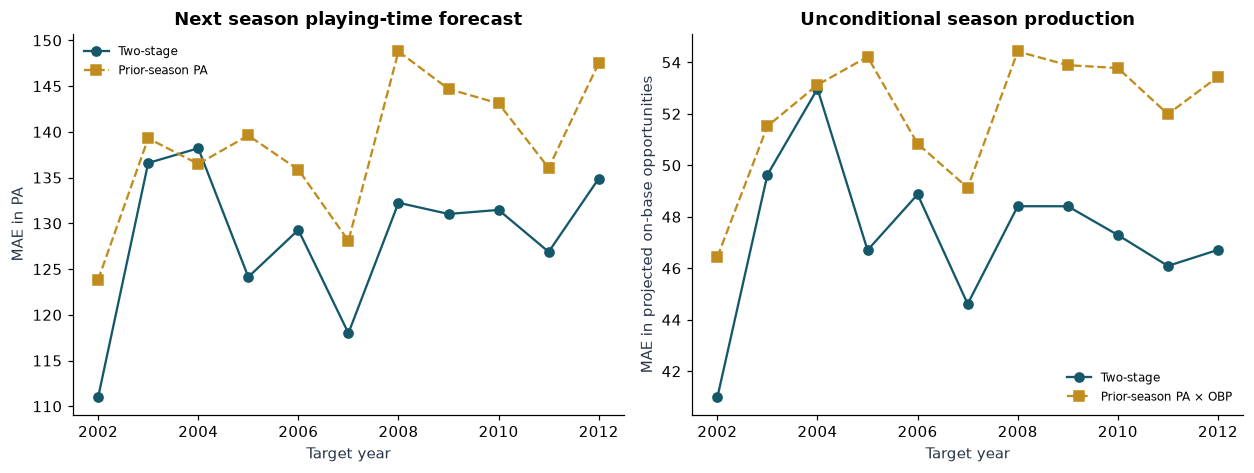

In [39]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import brier_score_loss,roc_auc_score
production_features=FEATURES+extra_trend_cols

def fit_two_stage(training):
    any_model=Pipeline([('scale',StandardScaler()),
                        ('logit',LogisticRegression(max_iter=1200,random_state=42))])
    any_model.fit(training[production_features],training.next_any)
    regular_model=Pipeline([('scale',StandardScaler()),
                            ('logit',LogisticRegression(max_iter=1200,random_state=42))])
    regular_model.fit(training[production_features],training.next_regular)
    participants=training[training.next_any.eq(1)]
    pa_model=HistGradientBoostingRegressor(max_iter=110,max_leaf_nodes=12,l2_regularization=10,
                                            min_samples_leaf=20,random_state=42)
    pa_model.fit(participants[production_features],participants.next_PA)
    rate_training=training[training.next_PA.ge(100)&training.next_OBP.notna()]
    rate=Pipeline([('scale',StandardScaler()),('ridge',Ridge(alpha=10))])
    rate.fit(rate_training[production_features],rate_training.next_OBP)
    return any_model,regular_model,pa_model,rate

stage_year_rows=[];stage_predictions=[]
for year in range(2002,2013):
    history=full_decisions[full_decisions.target_year<year]
    cohort=full_decisions[full_decisions.target_year.eq(year)].copy()
    if len(history)<150 or len(cohort)<20:continue
    any_m,reg_m,pa_m,obp_m=fit_two_stage(history)
    cohort['prob_any']=any_m.predict_proba(cohort[production_features])[:,1]
    cohort['prob_regular']=reg_m.predict_proba(cohort[production_features])[:,1]
    cohort['pa_if_active']=np.clip(pa_m.predict(cohort[production_features]),0,750)
    cohort['pred_PA']=cohort.prob_any*cohort.pa_if_active
    cohort['pred_OBP']=np.clip(obp_m.predict(cohort[production_features]),0,1)
    cohort['expected_onbase_proxy']=cohort.pred_PA*cohort.pred_OBP
    cohort['actual_onbase_proxy']=cohort.next_PA*cohort.next_OBP.fillna(0)
    cohort['baseline_onbase_proxy']=cohort.PA*cohort.OBP
    stage_year_rows.append({'target_year':year,'n_all_candidates':len(cohort),
        'PA_MAE':mean_absolute_error(cohort.next_PA,cohort.pred_PA),
        'PA_baseline_MAE':mean_absolute_error(cohort.next_PA,cohort.PA),
        'onbase_events_MAE':mean_absolute_error(cohort.actual_onbase_proxy,cohort.expected_onbase_proxy),
        'onbase_events_baseline_MAE':mean_absolute_error(cohort.actual_onbase_proxy,cohort.baseline_onbase_proxy),
        'any_Brier':brier_score_loss(cohort.next_any,cohort.prob_any),
        'regular_Brier':brier_score_loss(cohort.next_regular,cohort.prob_regular)})
    stage_predictions.append(cohort[['playerID','name','target_year','player_salary','next_any','next_regular',
      'prob_any','prob_regular','next_PA','pred_PA','OBP','next_OBP','pred_OBP',
      'expected_onbase_proxy','actual_onbase_proxy','baseline_onbase_proxy']])
stage_years=pd.DataFrame(stage_year_rows)
stage_all=pd.concat(stage_predictions,ignore_index=True)
print('Two-stage results: salary-unrestricted test cohort (all prior >=300 PA):')
display(stage_years.mean(numeric_only=True).round(3).to_frame('unweighted yearly mean'))
save_frame(stage_years,'final_two_stage_annual_metrics.csv')
save_frame(stage_all,'final_two_stage_all_candidate_predictions.csv')
fig,axs=plt.subplots(1,2,figsize=(11.5,4.4))
axs[0].plot(stage_years.target_year,stage_years.PA_MAE,'o-',label='Two-stage',color='#14586a')
axs[0].plot(stage_years.target_year,stage_years.PA_baseline_MAE,'s--',label='Prior-season PA',color='#c18c1d')
axs[0].set(xlabel='Target year',ylabel='MAE in PA',title='Next season playing-time forecast')
axs[1].plot(stage_years.target_year,stage_years.onbase_events_MAE,'o-',label='Two-stage',color='#14586a')
axs[1].plot(stage_years.target_year,stage_years.onbase_events_baseline_MAE,'s--',label='Prior-season PA × OBP',color='#c18c1d')
axs[1].set(xlabel='Target year',ylabel='MAE in projected on-base opportunities',title='Unconditional season production')
for a in axs:a.legend(frameon=False,fontsize=8)
fig.tight_layout();fig.savefig(VISUALS/'final_two_stage_performance.png',bbox_inches='tight');plt.show()


## 22. Prospectively trained salary benchmarks

**Question:** At the point a season begins, which recorded salaries look low compared with peers, using only historical observations to train the pricing model?

For **target-year salaries**, train on prior target years and predict log-salary *relative to the median salary observed in the preceding season*. The preceding-season benchmark is known before the target year, avoiding target-year payroll normalization leakage. Compare Ridge, Elastic Net, Quantile Regression, and Histogram Gradient Boosting on the **same salary-listed holdout rows**. Missing previous salary is encoded explicitly. Players without a current salary listing remain in performance forecasts, but salary model evaluation necessarily excludes them.

**Not a free-agency price quote:** MLB team control, service time and contract length are absent. All comparisons are retrospective, even though performance features are lagged.


Walk-forward salary valuation errors; lower log-MAE is better:


,model,years,MAE_log_salary,median_absolute_log_error
1,HistGB,11,0.5189,0.4142
0,ElasticNet,11,0.5372,0.4031
3,Ridge,11,0.5376,0.4046
2,Median quantile,11,0.6914,0.5510


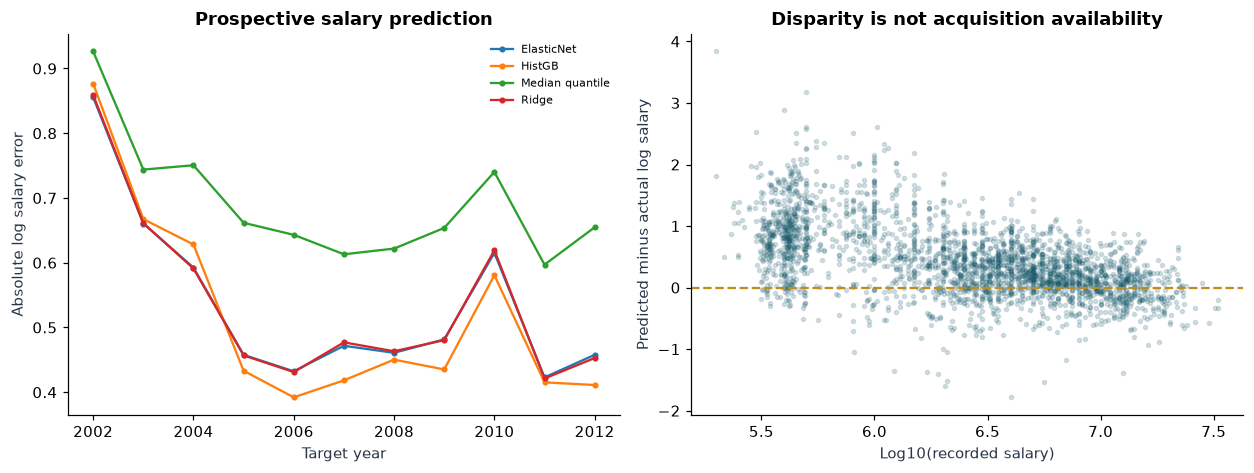

In [40]:
from sklearn.linear_model import ElasticNet,QuantileRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
prev_salaries=player_salary[['playerID','yearID','player_salary']].rename(columns={'player_salary':'prev_salary'})
salary_panel=full_decisions.merge(prev_salaries,on=['playerID','yearID'],how='left',validate='one_to_one')
salary_panel['prev_salary_missing']=salary_panel.prev_salary.isna().astype(int)
salary_panel['log_prev_salary']=np.log(salary_panel.prev_salary.clip(lower=1)).fillna(0)
prev_medians=raw['salaries'].groupby('yearID').salary.median()
salary_panel['prior_league_salary_median']=salary_panel.yearID.map(prev_medians)
salary_panel=salary_panel[(salary_panel.player_salary>0)&salary_panel.prior_league_salary_median.gt(0)].copy()
salary_panel['log_relative_salary']=np.log(salary_panel.player_salary/salary_panel.prior_league_salary_median)
salary_cols=FEATURES+extra_trend_cols+['log_prev_salary','prev_salary_missing']

def salary_predictor(name):
    if name=='Ridge': est=Ridge(alpha=30)
    elif name=='ElasticNet': est=ElasticNet(alpha=.015,l1_ratio=.25,max_iter=2500,random_state=42)
    elif name=='Median quantile': est=QuantileRegressor(quantile=.5,alpha=.10,solver='highs')
    else:
        return HistGradientBoostingRegressor(max_iter=90,max_leaf_nodes=12,min_samples_leaf=20,l2_regularization=10,random_state=42)
    return Pipeline([('scale',StandardScaler()),('estimator',est)])

salary_errors=[];salary_pred_rows=[]
for year in range(2002,2013):
    hist=salary_panel[salary_panel.target_year<year]
    cand=salary_panel[salary_panel.target_year.eq(year)].copy()
    if len(hist)<150 or len(cand)<20:continue
    for label in ['Ridge','ElasticNet','Median quantile','HistGB']:
        sm=salary_predictor(label)
        sm.fit(hist[salary_cols],hist.log_relative_salary)
        relative=sm.predict(cand[salary_cols])
        predicted=np.exp(relative)*cand.prior_league_salary_median.values
        observed=cand.player_salary.values
        salary_errors.append({'target_year':year,'model':label,'n':len(cand),
          'MAE_log_salary':mean_absolute_error(np.log(observed),np.log(predicted)),
          'median_absolute_log_error':float(np.median(np.abs(np.log(observed)-np.log(predicted))))})
        if label=='Ridge':
            tmp=cand[['playerID','name','target_year','age','OBP','player_salary']].copy()
            tmp['predicted_salary']=predicted
            tmp['salary_log_discount']=np.log(predicted)-np.log(observed)
            salary_pred_rows.append(tmp)
salary_cv=pd.DataFrame(salary_errors)
salary_forecasts=pd.concat(salary_pred_rows,ignore_index=True)
salary_summary=salary_cv.groupby('model',as_index=False).agg(years=('target_year','nunique'),MAE_log_salary=('MAE_log_salary','mean'),
 median_absolute_log_error=('median_absolute_log_error','mean')).sort_values('MAE_log_salary')
print('Walk-forward salary valuation errors; lower log-MAE is better:')
display(salary_summary.round(4))
save_frame(salary_cv,'final_salary_walk_forward_by_year.csv')
save_frame(salary_summary,'final_salary_model_comparison.csv')
save_frame(salary_forecasts,'final_prospective_salary_value_residuals.csv')
fig,axs=plt.subplots(1,2,figsize=(11.5,4.4))
for label,g in salary_cv.groupby('model'):
    axs[0].plot(g.target_year,g.MAE_log_salary,'o-',ms=3,label=label)
axs[0].set(xlabel='Target year',ylabel='Absolute log salary error',title='Prospective salary prediction')
axs[0].legend(frameon=False,fontsize=7)
axs[1].scatter(np.log10(salary_forecasts.player_salary),salary_forecasts.salary_log_discount,s=7,alpha=.17,color='#14586a')
axs[1].axhline(0,ls='--',c='#c18c1d')
axs[1].set(xlabel='Log10(recorded salary)',ylabel='Predicted minus actual log salary',title='Disparity is not acquisition availability')
fig.tight_layout();fig.savefig(VISUALS/'final_salary_market_residuals.png',bbox_inches='tight');plt.show()


## 23. Fair equal-ceiling roster-selection backtest (2002–2012)

**Design repair:** Compared shortlists must face **the same number of hitters, exact same candidate pool and salary ceiling in each season**. A salary cap changes with the era by using the season's salary distribution, and is reported explicitly. The analysis never filters using next-season performance or future playing time. Each strategy solves the *same* binary constrained selection problem with SciPy MILP, only changing the prospective objective: model score, preceding OBP, or salary minimization. The random baseline uses random feasible MILP objectives (not post-hoc best outcomes).

The historical evaluation metric is subsequent on-base events above that target season's observed league OBP (a *hindsight benchmark*; only used after picking). The optimization is still **not** a legal MLB roster because fielding position, player rights and pitching are unavailable.


Same players-count and same salary ceiling in each year:


,method,n_years,avg_ceiling,avg_spent,avg_actual_onbase_excess,avg_regular_share
0,Cheapest salary,11,24915454.55,3654720.73,0.36,0.71
1,Previous-season OBP,11,24915454.55,24203860.09,217.29,0.91
2,Prospective value score,11,24915454.55,8646016.36,174.71,0.95
3,Random constrained,11,24915454.55,23454572.44,23.25,0.77


Paired year-bootstrap contrasts (11 years is a small sample):


,baseline,n_seasons,mean_model_minus_baseline,bootstrap_low,bootstrap_high,interval_includes_zero,positive_seasons
0,Previous-season OBP,11,-42.59,-75.44,-8.07,False,3
1,Cheapest salary,11,174.35,124.53,221.81,False,11
2,Random constrained,11,151.46,104.17,198.60,False,11


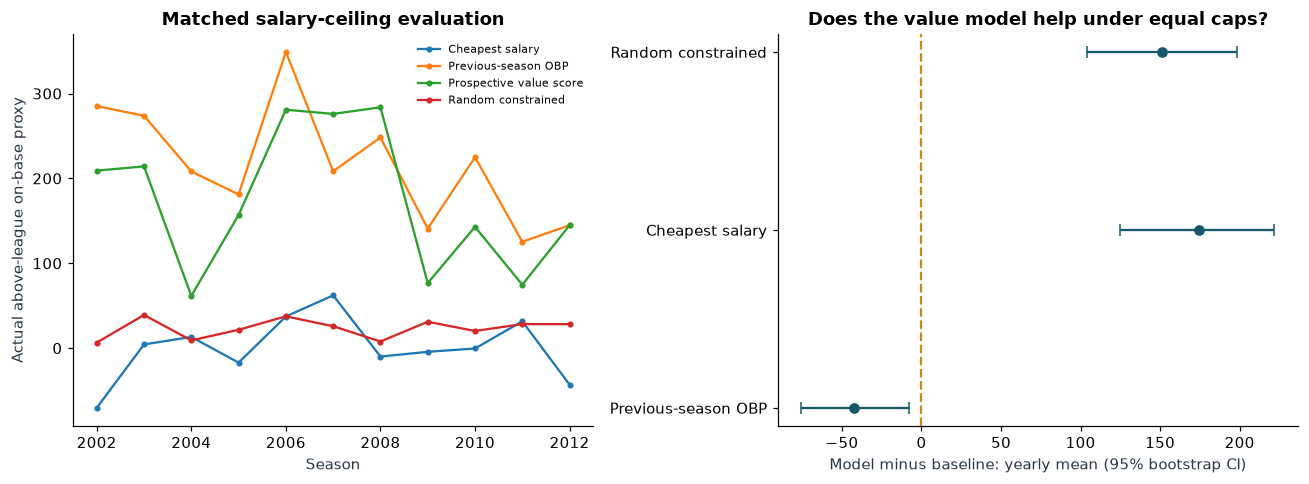

In [41]:
from scipy.optimize import milp,Bounds,LinearConstraint
from scipy.sparse import csc_matrix
from scipy.stats import binomtest

# All candidates in each year have a recorded next-year salary; cohort loss is reported in section 20.
# We re-use historical performance/value models trained only on prior target years.

def identical_cap_selection(frame, objective, budget, n):
    f=frame.reset_index(drop=True)
    if len(f)<n:return None
    cost=f.player_salary.to_numpy(dtype=float)
    objective=np.asarray(objective,dtype=float)
    assert np.isfinite(cost).all() and np.isfinite(objective).all()
    mat=csc_matrix(np.vstack([np.ones(len(f)),cost/1e6]))
    res=milp(c=-objective,integrality=np.ones(len(f)),bounds=Bounds(0,1),
             constraints=LinearConstraint(mat,[n,0],[n,budget/1e6]),
             options={'time_limit':15.0,'mip_rel_gap':0.005})
    if res.x is None:return None
    chosen=f.iloc[np.flatnonzero(res.x>.5)].copy()
    if len(chosen)!=n or chosen.player_salary.sum()>budget+1:return None
    return chosen

fixed_budget_rows=[];fixed_budget_choices=[]
N_FIXED=10
for year in range(2002,2013):
    history=decisions[decisions.target_year<year]
    choices=decisions[decisions.target_year.eq(year)]
    if len(history)<150 or len(choices)<N_FIXED:continue
    scored=score_candidates(history,choices)
    salaries_array=np.sort(scored.player_salary.values)
    cheapest_sum=float(salaries_array[:N_FIXED].sum())
    budget=max(float(0.80*N_FIXED*scored.player_salary.median()),cheapest_sum*1.05)
    # Same feasible region for all methods, including the model selection.
    rng=np.random.default_rng(17301+year)
    strategies={'Prospective value score':scored.value_score.values,
                'Previous-season OBP':scored.OBP.values,
                'Cheapest salary':-scored.player_salary.values}
    for trial in range(20):
        strategies[f'Random constrained / {trial}']=rng.normal(size=len(scored))
    for method,rewards in strategies.items():
        chosen=identical_cap_selection(scored,rewards,budget,N_FIXED)
        if chosen is None:continue
        display_method='Random constrained' if method.startswith('Random constrained') else method
        fixed_budget_rows.append({'target_year':year,'method':display_method,'iteration':int(method.split('/')[-1]) if '/' in method else 0,
            'candidate_n':len(scored),'slots':N_FIXED,'budget':budget,'spent':chosen.player_salary.sum(),
            'actual_onbase_excess':chosen.onbase_above_league.sum(),
            'regular_rate':chosen.next_regular.mean()})
        if display_method!='Random constrained':
            for _,row in chosen.iterrows():
                fixed_budget_choices.append({'target_year':year,'strategy':display_method,'playerID':row.playerID,
                    'name':row['name'],'listed_salary':row.player_salary,'previous_OBP':row.OBP,
                    'next_PA':row.next_PA,'next_OBP':row.next_OBP,
                    'actual_onbase_excess':row.onbase_above_league})
fixed_raw=pd.DataFrame(fixed_budget_rows)
fixed_by_year=fixed_raw.groupby(['target_year','method'],as_index=False).agg(
    budget=('budget','first'),slots=('slots','first'),spent=('spent','mean'),
    actual_onbase_excess=('actual_onbase_excess','mean'),regular_rate=('regular_rate','mean'),
    random_iterations=('iteration','size'))
fixed_summary=fixed_by_year.groupby('method',as_index=False).agg(
    n_years=('target_year','nunique'),avg_ceiling=('budget','mean'),avg_spent=('spent','mean'),
    avg_actual_onbase_excess=('actual_onbase_excess','mean'),avg_regular_share=('regular_rate','mean'))
assert fixed_by_year.groupby('target_year').budget.nunique().max()==1
fixed_compare=fixed_by_year.pivot(index='target_year',columns='method',values='actual_onbase_excess')
rng_ci=np.random.default_rng(15021)
fixed_intervals=[]
for baseline in ['Previous-season OBP','Cheapest salary','Random constrained']:
    if baseline not in fixed_compare:continue
    differences=(fixed_compare['Prospective value score']-fixed_compare[baseline]).dropna().to_numpy()
    boot=rng_ci.choice(differences,size=(10000,len(differences)),replace=True).mean(axis=1)
    lo,hi=np.quantile(boot,[.025,.975])
    fixed_intervals.append({'baseline':baseline,'n_seasons':len(differences),'mean_model_minus_baseline':differences.mean(),
          'bootstrap_low':lo,'bootstrap_high':hi,'interval_includes_zero':bool(lo<=0<=hi),
          'positive_seasons':int((differences>0).sum())})
fixed_ci=pd.DataFrame(fixed_intervals)
print('Same players-count and same salary ceiling in each year:')
display(fixed_summary.round(2))
print('Paired year-bootstrap contrasts (11 years is a small sample):')
display(fixed_ci.round(2))
save_frame(fixed_raw,'final_fair_cap_each_strategy_trial.csv')
save_frame(fixed_by_year,'final_fair_cap_annual_summary.csv')
save_frame(fixed_summary,'final_fair_cap_overall_summary.csv')
save_frame(fixed_ci,'final_fair_cap_paired_bootstrap_ci.csv')
save_frame(pd.DataFrame(fixed_budget_choices),'final_fair_cap_selected_players.csv')
fig,axs=plt.subplots(1,2,figsize=(12,4.5))
for label,g in fixed_by_year.groupby('method'):
    axs[0].plot(g.target_year,g.actual_onbase_excess,'o-',ms=3,label=label)
axs[0].set(xlabel='Season',ylabel='Actual above-league on-base proxy',title='Matched salary-ceiling evaluation')
axs[0].legend(fontsize=7,frameon=False)
idx=np.arange(len(fixed_ci))
axs[1].errorbar(fixed_ci.mean_model_minus_baseline,idx,
    xerr=np.vstack([fixed_ci.mean_model_minus_baseline-fixed_ci.bootstrap_low,
                    fixed_ci.bootstrap_high-fixed_ci.mean_model_minus_baseline]),fmt='o',capsize=4,color='#14586a')
axs[1].axvline(0,c='#c18c1d',ls='--')
axs[1].set_yticks(idx,fixed_ci.baseline)
axs[1].set(xlabel='Model minus baseline: yearly mean (95% bootstrap CI)',title='Does the value model help under equal caps?')
fig.tight_layout();fig.savefig(VISUALS/'final_fair_budget_backtest.png',bbox_inches='tight');plt.show()


### Fairness sensitivity — spend-matched strategy comparison

An identical **ceiling** alone does *not* guarantee identical **actual spending**. The value score deliberately favors inexpensive players, so the OBP baseline may spend much more while both technically satisfy the cap. Below, the comparison additionally restricts every lineup's total salary to the **same 90%–100% of its annual ceiling**, while retaining the same candidate pool and exact number of hitters. This trades away some low-cost efficiency to isolate production at roughly comparable spending. Differences in salary within the band are still reported; this is an analytical sensitivity test, not a free-agent acquisition simulation.


Spend-matched comparison: 90%–100% of the same annual ceiling, 10 batters


,n_matched_years,minimum_spend_fraction,model_mean_excess,prior_OBP_mean_excess,mean_surplus_difference,bootstrap_low,bootstrap_high,mean_spending_gap_model_minus_OBP,mean_abs_spending_gap_pct_of_cap
0,11,0.9,225.16,214.02,11.139,-25.609,52.976,-1245422.545,0.052


,spent,actual_onbase_excess
method,,
Previous-season OBP,24485405.5,214.0
Prospective value score,23239983.0,225.2


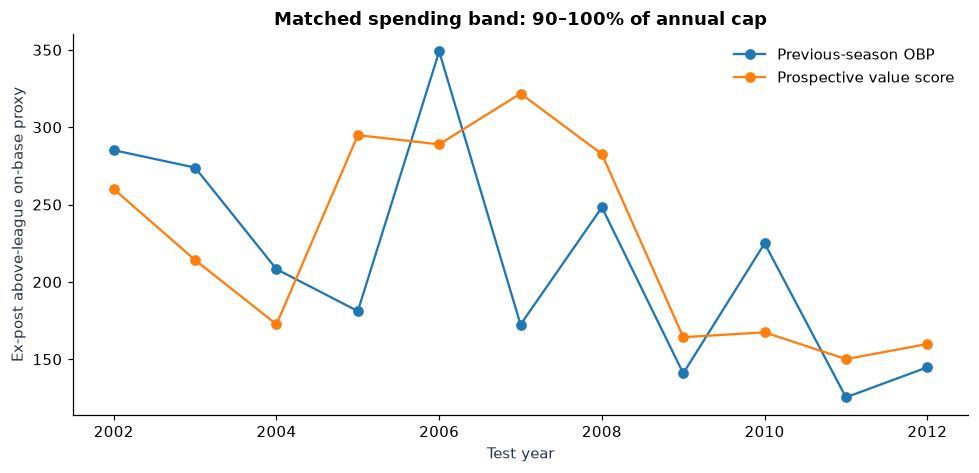

In [42]:
def spend_band_selection(frame,objective,budget,n,min_fraction=.90):
    f=frame.reset_index(drop=True)
    cost=f.player_salary.to_numpy(dtype=float)
    scores=np.asarray(objective,dtype=float)
    matrix=csc_matrix(np.vstack([np.ones(len(f)),cost/1e6]))
    sol=milp(c=-scores,integrality=np.ones(len(f)),bounds=Bounds(0,1),
       constraints=LinearConstraint(matrix,[n,budget*min_fraction/1e6],[n,budget/1e6]),
       options={'time_limit':15.,'mip_rel_gap':.005})
    if sol.x is None:return None
    chosen=f.iloc[np.flatnonzero(sol.x>.5)].copy()
    if len(chosen)!=n or not budget*min_fraction-1<=chosen.player_salary.sum()<=budget+1:return None
    return chosen

spend_band_rows=[]
annual_budgets=fixed_by_year.groupby('target_year').budget.first().to_dict()
for year,budget in annual_budgets.items():
    history=decisions[decisions.target_year<year]
    current=decisions[decisions.target_year==year]
    current=score_candidates(history,current)
    objectives={'Prospective value score':current.value_score.to_numpy(),
                'Previous-season OBP':current.OBP.to_numpy()}
    for method,objective in objectives.items():
        group=spend_band_selection(current,objective,budget,N_FIXED)
        if group is None:continue
        spend_band_rows.append({'target_year':year,'method':method,'budget':budget,
          'spent':group.player_salary.sum(),'n':len(group),
          'actual_onbase_excess':group.onbase_above_league.sum(),
          'regular_rate':group.next_regular.mean()})
spend_band=pd.DataFrame(spend_band_rows)
matched=spend_band.pivot(index='target_year',columns='method',values='actual_onbase_excess').dropna()
spend_salary=spend_band.pivot(index='target_year',columns='method',values='spent').loc[matched.index]
assert len(matched)>=8,'Too few feasible annual cost-matched cohorts'
diffs=(matched['Prospective value score']-matched['Previous-season OBP']).to_numpy()
uncert=np.random.default_rng(2062).choice(diffs,size=(10000,len(diffs)),replace=True).mean(axis=1)
matched_summary=pd.DataFrame([{'n_matched_years':len(matched),'minimum_spend_fraction':.90,
 'model_mean_excess':matched['Prospective value score'].mean(),
 'prior_OBP_mean_excess':matched['Previous-season OBP'].mean(),
 'mean_surplus_difference':diffs.mean(),
 'bootstrap_low':np.quantile(uncert,.025),'bootstrap_high':np.quantile(uncert,.975),
 'mean_spending_gap_model_minus_OBP':(spend_salary['Prospective value score']-spend_salary['Previous-season OBP']).mean(),
 'mean_abs_spending_gap_pct_of_cap':((spend_salary['Prospective value score']-spend_salary['Previous-season OBP']).abs()/pd.Series(annual_budgets).loc[matched.index]).mean()}])
print('Spend-matched comparison: 90%–100% of the same annual ceiling, 10 batters')
display(matched_summary.round(3));display(spend_band.groupby('method')[['spent','actual_onbase_excess']].mean().round(1))
save_frame(spend_band,'final_spend_matched_annual_results.csv')
save_frame(matched_summary,'final_spend_matched_comparison.csv')
fig,ax=plt.subplots(figsize=(9,4.4))
for label,g in spend_band.groupby('method'):
 ax.plot(g.target_year,g.actual_onbase_excess,'o-',label=label)
ax.set(xlabel='Test year',ylabel='Ex-post above-league on-base proxy',
 title='Matched spending band: 90–100% of annual cap')
ax.legend(frameon=False);fig.tight_layout();fig.savefig(VISUALS/'final_matched_spending_sensitivity.png',bbox_inches='tight');plt.show()


## 24. Rolling conformal intervals and player-level model reliability

For each target season, fit a rate model on seasons ending at least **3 years earlier**, calibrate 90% error quantiles on the **two immediately preceding completed seasons**, and then evaluate on that next target season. Repeat chronologically. This is a **rolling retrospective simulation** and does not guarantee 90% coverage with correlated, changing MLB cohorts.

The conditioned rate model evaluates only future batters with ≥300 PA. Results explicitly report that survivor conditioning, by-year coverage, and subgroup coverage by previous OBP and age. Group-specific quantiles are exploratory and use only the past calibration cohort, falling back to pooled quantiles for small subgroups.


Rolling empirical interval coverage (nominal 90%; not guaranteed):


,method,n,pooled_coverage,mean_width
0,OBP-conditional,2271,0.904,0.096
1,age-conditional,2271,0.900,0.096
2,pooled,2271,0.902,0.096


,method,prior_OBP_band,age_band,n,coverage
0,OBP-conditional,OBP < .350,Age <30,744,0.911
1,OBP-conditional,OBP < .350,Age >=30,535,0.903
2,OBP-conditional,OBP >= .350,Age <30,501,0.886
3,OBP-conditional,OBP >= .350,Age >=30,491,0.912
4,age-conditional,OBP < .350,Age <30,744,0.922
5,age-conditional,OBP < .350,Age >=30,535,0.903
6,age-conditional,OBP >= .350,Age <30,501,0.872
7,age-conditional,OBP >= .350,Age >=30,491,0.894
8,pooled,OBP < .350,Age <30,744,0.915
9,pooled,OBP < .350,Age >=30,535,0.907


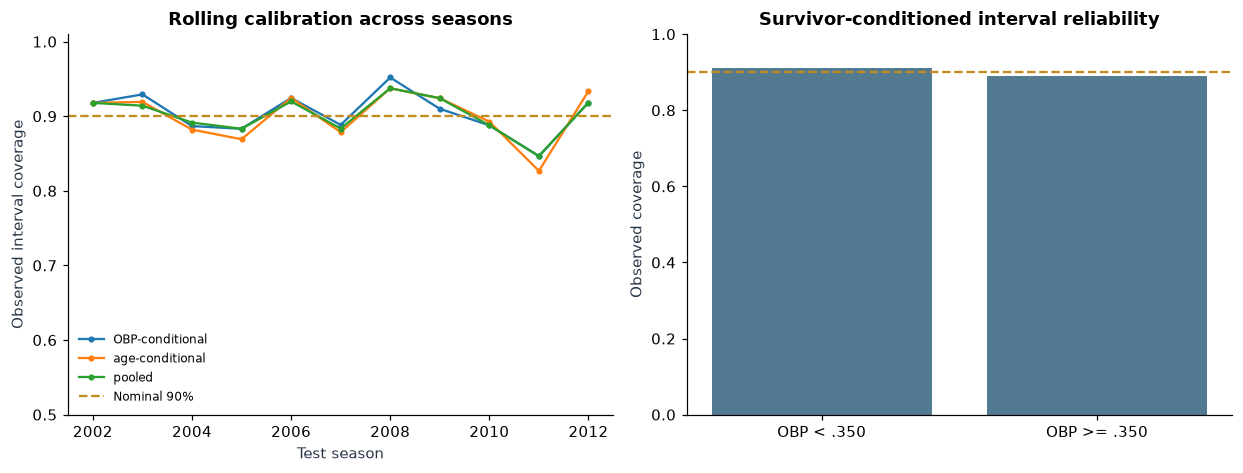

In [43]:
from math import ceil

def conformal_quantile(errors,alpha=.10):
    arr=np.sort(np.asarray(errors,dtype=float))
    if len(arr)<5:return np.nan
    order=min(len(arr),ceil((len(arr)+1)*(1-alpha)))
    return float(arr[order-1])

conformal_rolling=[];conformal_annual=[]
for year in range(2002,2013):
    tr=full_decisions[(full_decisions.target_year<=year-3)&full_decisions.next_regular.eq(1)&full_decisions.next_OBP.notna()]
    cal=full_decisions[(full_decisions.target_year.isin([year-2,year-1]))&full_decisions.next_regular.eq(1)&full_decisions.next_OBP.notna()].copy()
    te=full_decisions[(full_decisions.target_year==year)&full_decisions.next_regular.eq(1)&full_decisions.next_OBP.notna()].copy()
    if len(tr)<150 or len(cal)<40 or len(te)<10:continue
    estimator=Pipeline([('scale',StandardScaler()),('ridge',Ridge(alpha=10))])
    estimator.fit(tr[FEATURES],tr.next_OBP)
    cal['pred']=np.clip(estimator.predict(cal[FEATURES]),0,1)
    cal['error_abs']=np.abs(cal.next_OBP-cal.pred)
    q=conformal_quantile(cal.error_abs)
    te['pred']=np.clip(estimator.predict(te[FEATURES]),0,1)
    te['q_pooled']=q
    te['prior_OBP_band']=np.where(te.OBP>=.350,'OBP >= .350','OBP < .350')
    cal['prior_OBP_band']=np.where(cal.OBP>=.350,'OBP >= .350','OBP < .350')
    te['age_band']=np.where(te.age>=30,'Age >=30','Age <30')
    cal['age_band']=np.where(cal.age>=30,'Age >=30','Age <30')
    for key in ['prior_OBP_band','age_band']:
        qs=cal.groupby(key).error_abs.apply(lambda e:conformal_quantile(e) if len(e)>=35 else np.nan).to_dict()
        te[f'q_{key}']=te[key].map(qs).fillna(q)
    for method,col in [('pooled','q_pooled'),('OBP-conditional','q_prior_OBP_band'),('age-conditional','q_age_band')]:
        lo=np.clip(te.pred-te[col],0,1)
        hi=np.clip(te.pred+te[col],0,1)
        result=te[['playerID','name','target_year','OBP','age','next_OBP','pred','prior_OBP_band','age_band']].copy()
        result['method']=method;result['lower']=lo;result['upper']=hi
        result['covered']=(te.next_OBP.ge(lo)&te.next_OBP.le(hi)).astype(int)
        conformal_rolling.append(result)
        conformal_annual.append({'target_year':year,'method':method,'test_n':len(te),
          'calibration_n':len(cal),'coverage':result.covered.mean(),
          'mean_width':(hi-lo).mean(),'MAE':mean_absolute_error(te.next_OBP,te.pred)})
rolling_intervals=pd.concat(conformal_rolling,ignore_index=True)
rolling_annual=pd.DataFrame(conformal_annual)
rolling_overall=rolling_intervals.groupby('method',as_index=False).agg(n=('covered','size'),
  pooled_coverage=('covered','mean'),mean_width=('upper',lambda s:np.nan))
rolling_overall['mean_width']=rolling_intervals.assign(width=lambda d:d.upper-d.lower).groupby('method').width.mean().values
rolling_subgroups=rolling_intervals.groupby(['method','prior_OBP_band','age_band'],as_index=False).agg(
 n=('covered','size'),coverage=('covered','mean'))
print('Rolling empirical interval coverage (nominal 90%; not guaranteed):')
display(rolling_overall.round(3))
display(rolling_subgroups.round(3))
save_frame(rolling_intervals,'final_rolling_conformal_predictions.csv')
save_frame(rolling_annual,'final_rolling_conformal_annual_coverage.csv')
save_frame(rolling_overall,'final_rolling_conformal_summary.csv')
save_frame(rolling_subgroups,'final_rolling_conformal_subgroup_coverage.csv')
fig,axs=plt.subplots(1,2,figsize=(11.4,4.4))
for label,g in rolling_annual.groupby('method'):
    axs[0].plot(g.target_year,g.coverage,'o-',ms=3,label=label)
axs[0].axhline(.9,c='#c18c1d',ls='--',label='Nominal 90%')
axs[0].set(ylim=(.5,1.01),xlabel='Test season',ylabel='Observed interval coverage',title='Rolling calibration across seasons')
axs[0].legend(frameon=False,fontsize=8)
pooled=rolling_intervals[rolling_intervals.method=='pooled']
sub=pooled.groupby('prior_OBP_band',as_index=False).covered.mean()
axs[1].bar(sub.prior_OBP_band,sub.covered,color='#527b92')
axs[1].axhline(.9,c='#c18c1d',ls='--')
axs[1].set(ylim=(0,1),ylabel='Observed coverage',title='Survivor-conditioned interval reliability')
fig.tight_layout();fig.savefig(VISUALS/'final_rolling_uncertainty.png',bbox_inches='tight');plt.show()


## 25. Position-constrained roster selection and WAR integration

Uses `Appearances.csv` and, where available, `WAR.csv` to select eight different fielding positions. The section builds a retrospective lineup if the required appearance and WAR records are available; the output below provides the result for the current run.

- `Appearances.csv` requires `playerID`, `yearID` and `G_c`, `G_1b`, `G_2b`, `G_3b`, `G_ss`, `G_lf`, `G_cf`, `G_rf`.
- `WAR.csv` requires `playerID`, `yearID`, and `WAR`, already consolidated at player-year level.
- **Interpretation:** This is a hypothetical salary-constrained lineup based on historical records, not proof that players were free to sign or available at those prices.


In [44]:
position_file=DATA_DIR/'Appearances.csv'
war_file=DATA_DIR/'WAR.csv'
position_columns={'C':'G_c','1B':'G_1b','2B':'G_2b','3B':'G_3b','SS':'G_ss',
                  'LF':'G_lf','CF':'G_cf','RF':'G_rf'}
optional_status=[]
if not position_file.exists():
    optional_status.append({'extension':'Position-constrained eight-player lineup',
      'status':'SKIPPED','reason':'Appearances.csv not supplied; positional eligibility cannot be inferred from batting or salaries'})
else:
    appearances=pd.read_csv(position_file)
    req={'playerID','yearID'}|set(position_columns.values())
    if not req.issubset(appearances.columns):
        optional_status.append({'extension':'Position-constrained eight-player lineup','status':'SKIPPED',
          'reason':'Appearances.csv missing required columns: '+', '.join(sorted(req-set(appearances.columns)))})
    else:
        roster=scored_2002.copy().reset_index(drop=True)
        apps=appearances.loc[appearances.yearID.eq(2001),['playerID']+list(position_columns.values())].copy()
        apps[list(position_columns.values())]=apps[list(position_columns.values())].fillna(0)
        apps=apps.groupby('playerID',as_index=False)[list(position_columns.values())].sum()
        roster=roster.merge(apps,on='playerID',how='left',validate='one_to_one').fillna({v:0 for v in position_columns.values()})
        # Each candidate can be considered at a position only with >=10 recorded games in 2001.
        assignments=[(i,p) for i,row in roster.iterrows() for p,col in position_columns.items() if row[col]>=10]
        war_source=False
        if war_file.exists():
            warr=pd.read_csv(war_file)
            war_col='WAR' if 'WAR' in warr.columns else ('war' if 'war' in warr.columns else None)
            if {'playerID','yearID'}.issubset(warr.columns) and war_col:
                wars=warr[warr.yearID.eq(2001)].groupby('playerID',as_index=False)[war_col].sum().rename(columns={war_col:'previous_WAR'})
                roster=roster.merge(wars,on='playerID',how='left',validate='one_to_one')
                war_source=True
        if len(assignments)<8 or len({x[1] for x in assignments})<8:
            optional_status.append({'extension':'Position-constrained eight-player lineup','status':'SKIPPED',
              'reason':'Insufficient 2001 positional coverage among salary-listed 2002 candidates'})
        else:
            # One binary decision for every player/position-eligible combination.
            m=len(assignments); nc=len(roster); poslist=list(position_columns)
            incidence=np.zeros((8+nc+1,m)); values=np.zeros(m)
            for j,(i,pos) in enumerate(assignments):
                incidence[poslist.index(pos),j]=1
                incidence[8+i,j]=1
                incidence[-1,j]=roster.iloc[i].player_salary/1e6
                if war_source:
                    val=roster.iloc[i].get('previous_WAR',np.nan)
                    values[j]=float(val) if np.isfinite(val) else -3.
                else:values[j]=float(roster.iloc[i].value_score)
            # $15M is a user-tunable illustrative 2002 cap for just eight position players.
            budget_m=15.0
            low=np.r_[np.ones(8),np.zeros(nc),0.]
            high=np.r_[np.ones(8),np.ones(nc),budget_m]
            res=milp(c=-values,integrality=np.ones(m),bounds=Bounds(0,1),
                     constraints=LinearConstraint(csc_matrix(incidence),low,high),
                     options={'time_limit':15.0,'mip_rel_gap':0.005})
            if res.x is None:
                optional_status.append({'extension':'Position-constrained eight-player lineup','status':'SKIPPED',
                    'reason':'No eligible feasible lineup for eight positions under $15M cap'})
            else:
                selected=[(roster.iloc[assignments[j][0]],assignments[j][1]) for j in np.flatnonzero(res.x>.5)]
                roster_selected=pd.DataFrame([{'playerID':row.playerID,'name':row['name'],'position':pos,
                      'salary_2002':row.player_salary,'previous_WAR':row.get('previous_WAR',np.nan),
                      'projected_OBP':row.projected_OBP} for row,pos in selected])
                assert len(roster_selected)==8 and roster_selected.playerID.nunique()==8
                print('Optional hypothetical 2002 roster (not a legal acquisition plan):')
                display(roster_selected)
                save_frame(roster_selected,'final_optional_position_roster.csv')
                optional_status.append({'extension':'Position-constrained eight-player lineup','status':'EXECUTED',
                    'reason':'Ranking with 2001 WAR' if war_source else 'Ranking with existing prospective value proxy; WAR file not provided'})
optional_status.append({'extension':'Historical WAR valuation','status':'AVAILABLE' if war_file.exists() else 'SKIPPED',
  'reason':'WAR.csv exists; validate source metadata before interpretation' if war_file.exists() else 'WAR.csv not supplied; actual WAR cannot be computed from the four input files'})
optional_status=pd.DataFrame(optional_status)
display(optional_status)
save_frame(optional_status,'final_optional_data_coverage.csv')


Optional hypothetical 2002 roster (not a legal acquisition plan):


,playerID,name,position,salary_2002,previous_WAR,projected_OBP
0,berkmla01,Lance Berkman,CF,500000.0,6.51,0.403481
1,pujolal01,Albert Pujols,RF,600000.0,6.59,0.388066
2,gonzalu01,Luis Gonzalez,LF,4333333.0,7.94,0.410647
3,eckstda01,David Eckstein,2B,280000.0,4.23,0.342804
4,heltoto01,Todd Helton,1B,5000000.0,7.76,0.411725
5,loducpa01,Paul Lo Duca,C,546667.0,4.63,0.363895
6,koskico01,Corey Koskie,3B,2150000.0,6.29,0.360929
7,guzmacr01,Cristian Guzman,SS,1425000.0,4.76,0.331953


,extension,status,reason
0,Position-constrained eight-player lineup,EXECUTED,Ranking with 2001 WAR
1,Historical WAR valuation,AVAILABLE,WAR.csv exists; validate source metadata befor...


WindowsPath('C:/Users/htpar/Downloads/outputs/processed/final_optional_data_coverage.csv')

## 27. Direct on-base-event prediction — time-ordered model contest

**Question:** Can a model forecast actual `H + BB + HBP` in season t+1 better than forecasting PA × OBP? PA is an approximation and differs from OBP's denominator; comparing the proxy with **actual batting event counts** matters.

**Models:** Persistence baseline, existing Two-Stage forecast (PA × OBP approximation), Poisson GLM, Tweedie GLM (power 1.5), and Poisson-loss histogram gradient boosting. The panel includes players who **do not return the next season** (actual events 0), and candidates are never excluded based on next-year salary, availability or PA. Models train on target seasons strictly earlier than the evaluated season. This is a purely retrospective benchmark on available historical players, not a proof of causal player value.


Actual season event-count prediction; smaller errors better:


,model,tested_seasons,mean_annual_MAE,mean_annual_RMSE,mean_bias
4,Two-stage PA × OBP,11,47.116,59.043,2.410
1,Poisson HistGB,11,47.455,59.500,2.238
0,Poisson GLM,11,48.095,59.737,3.353
3,Tweedie GLM,11,48.542,59.956,2.189
2,Prior H+BB+HBP,11,51.867,67.220,26.880


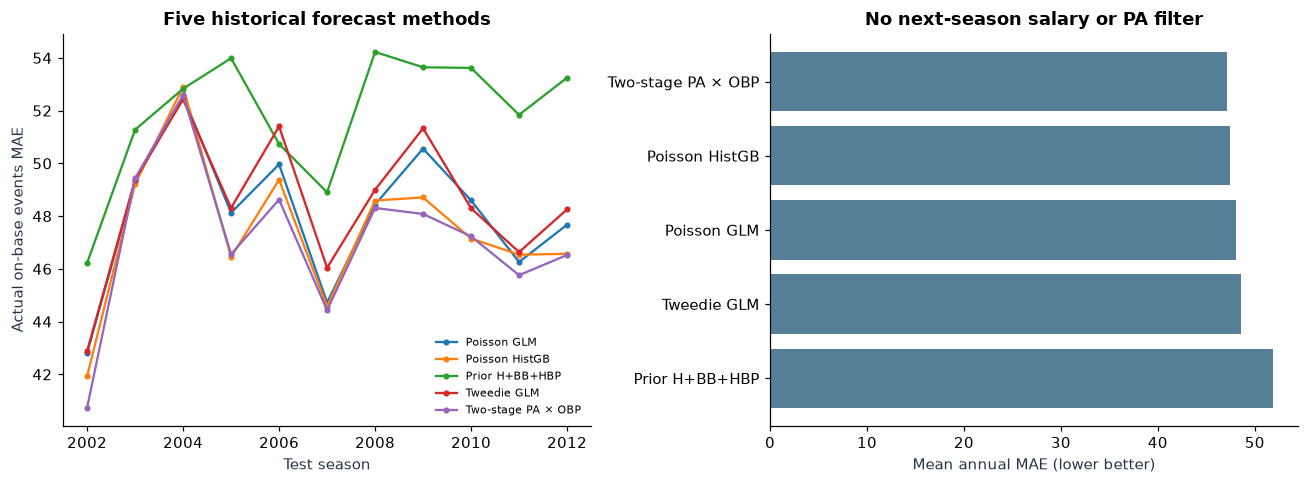

In [45]:
from sklearn.linear_model import PoissonRegressor, TweedieRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
# Exact observed numerator of OBP; use actual batting counts, not PA*OBP.
future_events=p_all[['playerID','yearID','onbase_num']].copy()
future_events['yearID']-=1
future_events=future_events.rename(columns={'onbase_num':'next_events'})
event_panel=full_decisions.merge(future_events,on=['playerID','yearID'],how='left',validate='one_to_one')
event_panel['next_events']=event_panel.next_events.fillna(0).clip(lower=0)
assert event_panel[['playerID','target_year']].duplicated().sum()==0
EVENT_FEATURES=production_features

def event_estimator(label):
    if label=='Poisson GLM':
        return Pipeline([('scale',StandardScaler()),('model',PoissonRegressor(alpha=4.0,max_iter=250))])
    if label=='Tweedie GLM':
        return Pipeline([('scale',StandardScaler()),('model',TweedieRegressor(power=1.5,alpha=4.0,max_iter=250))])
    if label=='Poisson HistGB':
        return HistGradientBoostingRegressor(loss='poisson',max_iter=90,max_leaf_nodes=12,
                   min_samples_leaf=20,l2_regularization=10,random_state=42)
    raise KeyError(label)

event_annual=[];event_player_rows=[]
for test_year in range(2002,2013):
    hist=event_panel[event_panel.target_year<test_year]
    te=event_panel[event_panel.target_year==test_year].copy()
    if len(hist)<150 or len(te)<20: continue
    two_stage=stage_all[stage_all.target_year==test_year][['playerID','expected_onbase_proxy']]
    te=te.merge(two_stage,on='playerID',how='left',validate='one_to_one')
    preds={'Prior H+BB+HBP':te.onbase_num.to_numpy(dtype=float),
           'Two-stage PA × OBP':te.expected_onbase_proxy.to_numpy(dtype=float)}
    for label in ('Poisson GLM','Tweedie GLM','Poisson HistGB'):
        model=event_estimator(label)
        model.fit(hist[EVENT_FEATURES],hist.next_events)
        preds[label]=np.clip(model.predict(te[EVENT_FEATURES]),0,750)
    for label,pred in preds.items():
        valid=np.isfinite(pred)
        if not valid.all(): raise ValueError('Invalid predicted event value '+label)
        event_annual.append({'target_year':test_year,'model':label,'n':len(te),
              'MAE':mean_absolute_error(te.next_events,pred),
              'RMSE':np.sqrt(mean_squared_error(te.next_events,pred)),
              'bias':float(np.mean(pred-te.next_events))})
        tmp=te[['playerID','name','target_year','yearID','OBP','PA','next_PA','next_events','player_salary']].copy()
        tmp['model']=label;tmp['pred_events']=pred;tmp['residual']=tmp.next_events-tmp.pred_events
        event_player_rows.append(tmp)
event_cv=pd.DataFrame(event_annual)
event_predictions=pd.concat(event_player_rows,ignore_index=True)
event_summary=event_cv.groupby('model',as_index=False).agg(
   tested_seasons=('target_year','nunique'),mean_annual_MAE=('MAE','mean'),
   mean_annual_RMSE=('RMSE','mean'),mean_bias=('bias','mean')).sort_values('mean_annual_MAE')
print('Actual season event-count prediction; smaller errors better:')
display(event_summary.round(3))
for label,frame in [('final_direct_event_annual.csv',event_cv),
 ('final_direct_event_model_comparison.csv',event_summary),
 ('final_direct_event_out_of_time_predictions.csv',event_predictions)]:save_frame(frame,label)
fig,axs=plt.subplots(1,2,figsize=(12,4.5))
for label,g in event_cv.groupby('model'):
    axs[0].plot(g.target_year,g.MAE,'o-',ms=3,label=label)
axs[0].set(xlabel='Test season',ylabel='Actual on-base events MAE',title='Five historical forecast methods')
axs[0].legend(fontsize=7,frameon=False)
axs[1].barh(event_summary.model,event_summary.mean_annual_MAE,color='#557f96')
axs[1].invert_yaxis();axs[1].set(xlabel='Mean annual MAE (lower better)',title='No next-season salary or PA filter')
fig.tight_layout();fig.savefig(VISUALS/'final_direct_event_models.png',bbox_inches='tight');plt.show()


## 28. Risk-aware roster selection with empirical scenarios and tail-risk optimization

**Question:** How much expected offensive production should an illustrative roster sacrifice to reduce a bad-outcome tail? The baseline is a maximum-expected-events binary roster under a **fixed annual salary ceiling**. The risk-aware comparator uses linearized **lower-tail CVaR (20th percentile)** over out-of-time empirical-residual scenarios. Both select exactly 10 hitters from the **same priced candidate set**.

Scenarios are derived from *previous out-of-time forecast errors only*, never from the held-out year. The residual bootstrap is a simplistic uncertainty model; independence across player shocks is an assumption and baseball playing-time shocks may be correlated. Results concern retrospective offensive hitting-event totals, not WAR or wins. Price is the season's recorded salary — not a genuine acquisition quote. Evaluate 2007, 2010, 2012 as illustrations rather than claiming annual coverage.


Historical scenario portfolios (CVaR is MODELLED, not known true risk):


,target_year,strategy,n,ceiling,spent,scenario_mean_events,scenario_lower20_mean,realized_events,scenario_n,historical_residual_n
0,2007,Expected events,10,28000000.0,23441667.0,2470.79,2137.04,2564.0,70,1370
1,2007,CVaR 20% risk-aware,10,28000000.0,22241667.0,2446.43,2149.89,2516.0,70,1370
2,2010,Expected events,10,26500000.0,13580100.0,2345.15,1945.92,2160.0,70,2202
3,2010,CVaR 20% risk-aware,10,26500000.0,13553200.0,2337.18,2024.24,2185.0,70,2202
4,2012,Expected events,10,29300000.0,17890566.0,2192.51,1913.07,1911.0,70,2756
5,2012,CVaR 20% risk-aware,10,29300000.0,19980566.0,2176.94,1917.97,1942.0,70,2756


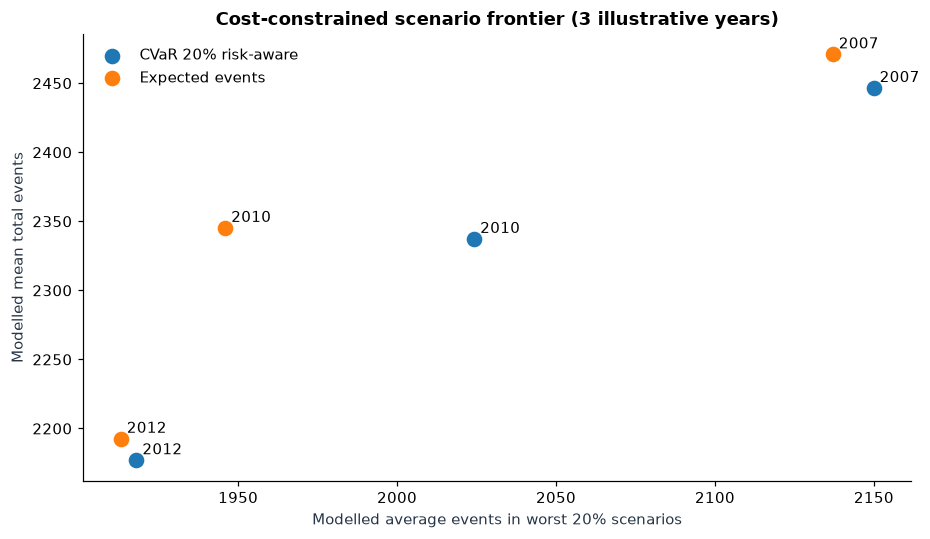

In [46]:
from scipy.optimize import milp, Bounds, LinearConstraint
from scipy.sparse import csc_matrix
# CVaR of lower-tail portfolio production: eta - E[max(eta-payoff,0)] / alpha.
# With x_i binary: scenario_gain_s = sum_i scenario[i,s]*x_i.

def scenario_roster(pool,scenarios,budget,slots=10,lam=.4,alpha=.20):
    f=pool.reset_index(drop=True); n=len(f); K=scenarios.shape[0]
    prices=f.player_salary.to_numpy(float)/1e6
    expected=scenarios.mean(axis=0)
    # optimize max [(1-lam)*expected + lam*(eta - sum(z)/(alpha*K))]
    # minimize its negative; variables [x(0:n), eta, z(0:K)]; eta free.
    obj=np.r_[-(1-lam)*expected,-lam,np.full(K,lam/(alpha*K))]
    constraint=np.zeros((K+2,n+1+K))
    constraint[0,:n]=1
    constraint[1,:n]=prices
    # eta - sum(scenario_i * x_i) - z_s <= 0
    constraint[2:,:n]=-scenarios
    constraint[2:,n]=1
    constraint[2:,n+1:]=-np.eye(K)
    lower=np.r_[slots,-np.inf,np.full(K,-np.inf)]
    upper=np.r_[slots,budget/1e6,np.zeros(K)]
    lb=np.r_[np.zeros(n),-np.inf,np.zeros(K)]
    ub=np.r_[np.ones(n),np.inf,np.full(K,np.inf)]
    sol=milp(c=obj,integrality=np.r_[np.ones(n),np.zeros(K+1)],bounds=Bounds(lb,ub),
         constraints=LinearConstraint(csc_matrix(constraint),lower,upper),
         options={'time_limit':16.0,'mip_rel_gap':0.015})
    if sol.x is None:return None
    picked=np.flatnonzero(sol.x[:n]>.5)
    if len(picked)!=slots or prices[picked].sum()>budget/1e6+1e-5:return None
    return picked

risk_summary_rows=[];risk_members=[]
rng=np.random.default_rng(20261018)
for year in (2007,2010,2012):
    pred=event_predictions[(event_predictions.target_year==year)&(event_predictions.model=='Poisson HistGB')].copy()
    pred=pred[pred.player_salary.gt(0)].copy()
    if len(pred)<20:continue
    # Use only errors from previously scored historical test years; no current or future labels.
    errors=event_predictions[(event_predictions.target_year<year)&
              (event_predictions.model=='Poisson HistGB')].residual.to_numpy(float)
    assert len(errors)>100 and event_predictions.loc[(event_predictions.target_year<year)&
              (event_predictions.model=='Poisson HistGB'),'target_year'].max()<year
    # Predeclare the same priced candidate pool for both objectives.
    pred['ranking']=pred.pred_events/(pred.player_salary/1e6)**.35
    subset=pd.concat([pred.nlargest(65,'ranking'),pred.nsmallest(25,'player_salary')]).drop_duplicates('playerID')
    subset=subset.reset_index(drop=True)
    if len(subset)<10:continue
    min_cost=np.sort(subset.player_salary.to_numpy())[:10].sum()
    available_cap=annual_budgets.get(year, max(10*subset.player_salary.median()*.8,min_cost*1.05))
    cap=max(float(available_cap),float(min_cost*1.01))
    K=70
    # Independent residual draws, scaled by each player's expected event count.
    # Bootstrap pool comes from historical out-of-time residuals only.
    draws=rng.choice(errors,size=(K,len(subset)),replace=True)
    spread=np.sqrt(np.clip(subset.pred_events.to_numpy(float),5,None)/max(np.mean(np.abs(errors)),1))
    spread=np.clip(spread,.65,1.35)
    samples=np.clip(subset.pred_events.to_numpy()[None,:]+draws*spread[None,:],0,None)
    for mode,lam in [('Expected events',0.),('CVaR 20% risk-aware',.55)]:
        chosen=scenario_roster(subset,samples,cap,slots=10,lam=lam,alpha=.2)
        if chosen is None:continue
        selected=subset.iloc[chosen]
        tail=samples[:,chosen].sum(axis=1)
        q=np.quantile(tail,.20)
        risk_summary_rows.append({'target_year':year,'strategy':mode,'n':len(selected),
               'ceiling':cap,'spent':selected.player_salary.sum(),
               'scenario_mean_events':tail.mean(),'scenario_lower20_mean':tail[tail<=q].mean(),
               'realized_events':selected.next_events.sum(),
               'scenario_n':K,'historical_residual_n':len(errors)})
        for _,r in selected.iterrows():
            risk_members.append({'target_year':year,'strategy':mode,'playerID':r.playerID,
               'name':r['name'],'salary_recorded':r.player_salary,
               'projected_events':r.pred_events,'realized_events':r.next_events})
risk_portfolios=pd.DataFrame(risk_summary_rows)
assert not risk_portfolios.empty,'No feasible illustrative scenarios; inspect annual budget'
assert (risk_portfolios.n==10).all() and (risk_portfolios.spent<=risk_portfolios.ceiling+1).all()
print('Historical scenario portfolios (CVaR is MODELLED, not known true risk):')
display(risk_portfolios.round(2))
save_frame(risk_portfolios,'final_stochastic_portfolio_comparison.csv')
save_frame(pd.DataFrame(risk_members),'final_stochastic_portfolio_selected_players.csv')
fig,ax=plt.subplots(figsize=(8.6,5))
for name,g in risk_portfolios.groupby('strategy'):
    ax.scatter(g.scenario_lower20_mean,g.scenario_mean_events,s=85,label=name)
    for _,r in g.iterrows():ax.annotate(str(int(r.target_year)),(r.scenario_lower20_mean,r.scenario_mean_events),xytext=(4,4),textcoords='offset points')
ax.set(xlabel='Modelled average events in worst 20% scenarios',ylabel='Modelled mean total events',
       title='Cost-constrained scenario frontier (3 illustrative years)')
ax.legend(frameon=False);fig.tight_layout();fig.savefig(VISUALS/'final_risk_aware_roster_scenarios.png',bbox_inches='tight');plt.show()


## 29. Nested historical tuning of salary and peer-discount weights

**Problem:** The existing score uses preselected salary power `0.35` and peer-discount coefficient `0.1`. Picking these by viewing the final evaluation years would be a new form of overfitting.

**Fix:** For each test year **2006–2012**, tune `(salary_exponent, peer_discount_weight)` on earlier backtests only (2002 through t−1). Each historical shortlist is itself scored by performance models trained on seasons before its own evaluation season. Use *identical annual spend bands (90–100% of cap)* and exactly 10 slots across strategies. Historical outcomes determine only prior-year parameter choice. Compare tuned, fixed, and simple previous-OBP selection with year-paired bootstrap uncertainty. This is nested backtesting, not a randomized trial; median salary ceilings and t+1 recorded salary remain retrospective.


Nested tuning (test years 2006–2012):


strategy
Fixed 0.35, 0.10    219.30
Nested tuned        270.00
Previous OBP        200.82
Name: actual_onbase_excess, dtype: float64

,target_year,chosen_salary_power,chosen_peer_weight
0,2006,0.2,0.0
3,2007,0.2,0.0
6,2008,0.2,0.0
9,2009,0.2,0.0
12,2010,0.2,0.0
15,2011,0.2,0.0
18,2012,0.2,0.0


,comparator,years,mean_tuned_minus_comparator,ci_low_95,ci_high_95,contains_zero
0,"Fixed 0.35, 0.10",7,50.70,14.25,88.26,False
1,Previous OBP,7,69.18,32.53,110.08,False


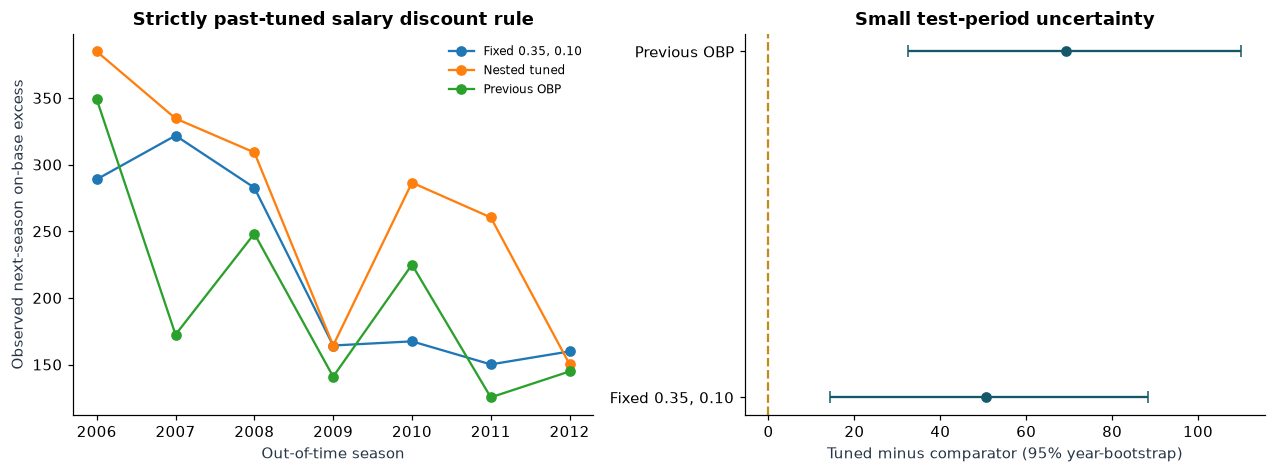

In [47]:
from itertools import product
# Score 2002..2012 once. Each candidate year's performance models fit only earlier seasons.
scored_cache={}
for y in range(2002,2013):
    hist=decisions[decisions.target_year<y]
    current=decisions[decisions.target_year==y]
    if len(hist)<150 or len(current)<10:continue
    scored_cache[y]=score_candidates(hist,current)

search_weights=[(float(a),float(b)) for a,b in product([0.0,.20,.35,.50,.70],[0.0,.10])]

def policy_objective(frame,a,b):
    score=np.maximum(frame.performance_index.to_numpy(float),0)
    score=score/(frame.player_salary.to_numpy(float)/1e6)**a
    score*=np.exp(b*np.clip(frame.salary_log_gap.to_numpy(float),-2,2))
    return score

def score_spend_band(frame,objective,yr):
    cap=annual_budgets.get(yr)
    if cap is None:return np.nan
    chosen=spend_band_selection(frame,np.asarray(objective),cap,10,min_fraction=.90)
    return float(chosen.onbase_above_league.sum()) if chosen is not None else np.nan

# IMPORTANT: Results for each historical validation year were generated with models
# fitted before that validation year; no final held-out target year appears in tuning.
score_grid=[]
for y,rows in sorted(scored_cache.items()):
    for a,b in search_weights:
        v=score_spend_band(rows,policy_objective(rows,a,b),y)
        score_grid.append({'evaluation_year':y,'salary_power':a,'peer_weight':b,'actual_excess':v})
tuning_grid=pd.DataFrame(score_grid)

nested_rows=[]
for test_year in range(2006,2013):
    if test_year not in scored_cache:continue
    history=tuning_grid[(tuning_grid.evaluation_year<test_year)&tuning_grid.actual_excess.notna()]
    tune=history.groupby(['salary_power','peer_weight'],as_index=False).agg(
        mean_past_excess=('actual_excess','mean'),years=('evaluation_year','nunique'))
    tune=tune[tune.years.ge(3)].sort_values(['mean_past_excess','salary_power','peer_weight'],ascending=[False,True,True])
    if tune.empty:continue
    best=tune.iloc[0]
    current=scored_cache[test_year]
    objectives={
        'Nested tuned':policy_objective(current,best.salary_power,best.peer_weight),
        'Fixed 0.35, 0.10':policy_objective(current,.35,.10),
        'Previous OBP':current.OBP.to_numpy(float)}
    for strategy,objective in objectives.items():
        actual=score_spend_band(current,objective,test_year)
        nested_rows.append({'target_year':test_year,'strategy':strategy,'actual_onbase_excess':actual,
             'chosen_salary_power':best.salary_power if strategy=='Nested tuned' else (.35 if strategy.startswith('Fixed') else np.nan),
             'chosen_peer_weight':best.peer_weight if strategy=='Nested tuned' else (.10 if strategy.startswith('Fixed') else np.nan),
             'tuning_years':int(best.years),'tuning_best_past_mean':best.mean_past_excess})
nested_results=pd.DataFrame(nested_rows).dropna(subset=['actual_onbase_excess'])
nested_pivot=nested_results.pivot(index='target_year',columns='strategy',values='actual_onbase_excess').dropna()
assert len(nested_pivot)>=4,'Insufficient feasible years in nested comparison'

nested_ci=[]
for comparator in ['Fixed 0.35, 0.10','Previous OBP']:
    d=(nested_pivot['Nested tuned']-nested_pivot[comparator]).to_numpy()
    boot=np.random.default_rng(473).choice(d,size=(8000,len(d)),replace=True).mean(axis=1)
    nested_ci.append({'comparator':comparator,'years':len(d),'mean_tuned_minus_comparator':d.mean(),
        'ci_low_95':np.quantile(boot,.025),'ci_high_95':np.quantile(boot,.975),
        'contains_zero':bool(np.quantile(boot,.025)<=0<=np.quantile(boot,.975))})
nested_ci=pd.DataFrame(nested_ci)
print('Nested tuning (test years 2006–2012):')
display(nested_results.groupby('strategy').actual_onbase_excess.mean().round(2))
display(nested_results[nested_results.strategy=='Nested tuned'][['target_year','chosen_salary_power','chosen_peer_weight']])
display(nested_ci.round(2))
save_frame(tuning_grid,'final_salary_weight_historical_grid.csv')
save_frame(nested_results,'final_nested_score_tuning_results.csv')
save_frame(nested_ci,'final_nested_score_paired_bootstrap.csv')
fig,axs=plt.subplots(1,2,figsize=(11.7,4.4))
for m,g in nested_results.groupby('strategy'):
    axs[0].plot(g.target_year,g.actual_onbase_excess,'o-',label=m)
axs[0].set(xlabel='Out-of-time season',ylabel='Observed next-season on-base excess',title='Strictly past-tuned salary discount rule')
axs[0].legend(fontsize=8,frameon=False)
axs[1].errorbar(nested_ci.mean_tuned_minus_comparator,np.arange(len(nested_ci)),
    xerr=[nested_ci.mean_tuned_minus_comparator-nested_ci.ci_low_95,nested_ci.ci_high_95-nested_ci.mean_tuned_minus_comparator],
    fmt='o',capsize=4,color='#14586a')
axs[1].set_yticks(np.arange(len(nested_ci)),nested_ci.comparator)
axs[1].axvline(0,ls='--',color='#c18c1d')
axs[1].set(xlabel='Tuned minus comparator (95% year-bootstrap)',title='Small test-period uncertainty')
fig.tight_layout();fig.savefig(VISUALS/'final_nested_value_score_ablation.png',bbox_inches='tight');plt.show()


## 30. Historical offensive event weights and honest advanced-metric coverage

Historical wOBA coefficients, wOBA scales, yearly run environments and park adjustments are **not** supplied among the four source files. Without those historical source values, an official wOBA or wRC+ cannot be computed correctly. The analysis therefore includes:

1. A transparent **fixed-weight on-base-event index** (not official wOBA), and compare its rankings with OBP; weights below are *illustrative*, not updated for every season.
2. An additional **season-specific weighted metric** from `wOBA_weights.csv` if provided, with required columns: `yearID,wBB,wHBP,w1B,w2B,w3B,wHR`. Any additional metadata (`source`, `season_woba_scale`) is retained as provenance, not mistaken for wRC+.
3. A separate separately supplied `WAR.csv` linkage (`playerID,yearID,WAR`), explicitly sourced from user-provided external data. A lack of such files is a documented SKIPPED status, never an inferred number.

**Do not interpret** an illustration based on 2001 events as genuine 2002 acquisition value or as adjusted runs/wins.


Advanced-metric source coverage:


,extension,status,reason
0,Historical official wOBA,SKIPPED,Requires verified historical season-level coef...
1,Official wRC+,SKIPPED,Requires validated yearly wOBA scale/run envir...
2,External WAR linkage,EXECUTED,External value merged; source definition and v...


,name,OBP,fixed_weight_event_index
329,Barry Bonds,0.582,0.547
3189,Jim Thome,0.445,0.465
2679,Manny Ramirez,0.450,0.463
1128,Brian Giles,0.450,0.447
1109,Jason Giambi,0.435,0.443
3348,Larry Walker,0.421,0.436
2786,Alex Rodriguez,0.392,0.429
1434,Todd Helton,0.429,0.423


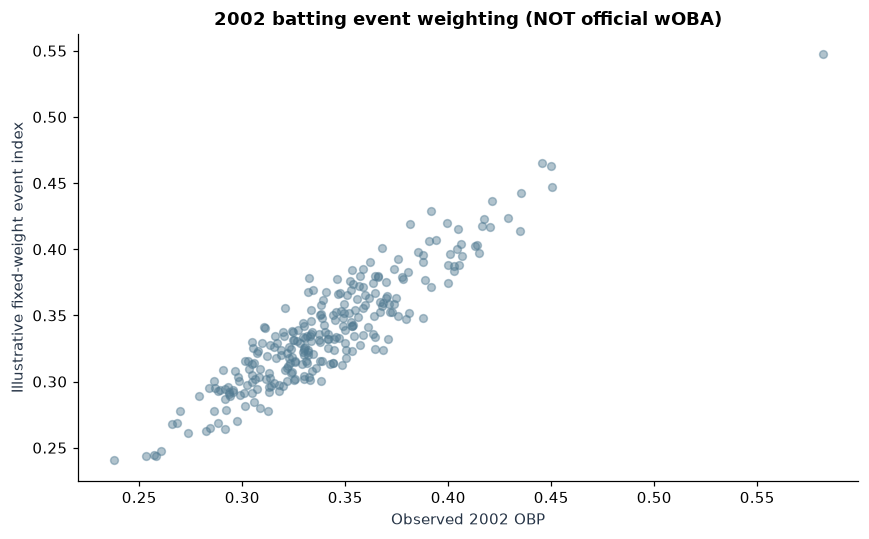

In [48]:
# Uses player-season count columns already consolidated, no fabricated historical coefficients.
metric=p_all[p_all.yearID.between(2000,2012)&p_all.PA.ge(300)].copy()
metric['singles']=metric.H-metric['2B']-metric['3B']-metric.HR
metric['unintentional_BB']=(metric.BB-raw['batting'].groupby(['playerID','yearID']).IBB.sum(min_count=1).reindex(
   pd.MultiIndex.from_frame(metric[['playerID','yearID']])).fillna(0).to_numpy()).clip(lower=0)
metric['weighted_denominator']=(metric.AB+metric.unintentional_BB+metric.HBP+metric.SF)
# Arbitrary fixed example weights, not annual official Fangraphs coefficients.
fixed_weights={'wBB':.69,'wHBP':.72,'w1B':.89,'w2B':1.27,'w3B':1.62,'wHR':2.10}
def weighted_metric(frame,weights):
    num=sum(frame[col].to_numpy(float)*np.asarray(weights[w],dtype=float) for col,w in
       [('unintentional_BB','wBB'),('HBP','wHBP'),('singles','w1B'),('2B','w2B'),('3B','w3B'),('HR','wHR')])
    return np.divide(num,frame.weighted_denominator.to_numpy(float),out=np.full(len(frame),np.nan),where=frame.weighted_denominator.to_numpy(float)>0)
metric['fixed_weight_event_index']=weighted_metric(metric,fixed_weights)
metric['metric_type']='illustrative fixed-weight event index, not official wOBA'
metrics_status=[{'extension':'Historical official wOBA','status':'SKIPPED','reason':'Requires verified historical season-level coefficients; using only an explicitly illustrative index'}]
weights_path=DATA_DIR/'wOBA_weights.csv'
if weights_path.is_file():
    weights_file=pd.read_csv(weights_path)
    required={'yearID',*fixed_weights.keys()}
    if required.issubset(weights_file.columns) and not weights_file.yearID.duplicated().any():
        metric=metric.merge(weights_file[['yearID',*fixed_weights.keys()]],on='yearID',how='left',validate='many_to_one')
        ok=metric[list(fixed_weights)].notna().all(axis=1)
        metric['weighted_metric_by_year']=np.nan
        metric.loc[ok,'weighted_metric_by_year']=weighted_metric(metric.loc[ok],{k:metric.loc[ok,k] for k in fixed_weights})
        metrics_status[0]={'extension':'Historical weight-adjusted wOBA-like metric','status':'EXECUTED',
            'reason':'Yearly weights loaded from user file. Verify coefficients, UBB/IBB treatment, and denominators against the provider'}
    else:
        metrics_status[0]={'extension':'Historical weight-adjusted metric','status':'SKIPPED',
            'reason':'weights file lacks unique yearID or required weight columns'}
metrics_status.append({'extension':'Official wRC+','status':'SKIPPED',
    'reason':'Requires validated yearly wOBA scale/run environment, league and park adjustments; not calculated'})
war_path=DATA_DIR/'WAR.csv'
if war_path.is_file():
    war=pd.read_csv(war_path)
    wc='WAR' if 'WAR' in war.columns else ('war' if 'war' in war.columns else None)
    if wc and {'playerID','yearID'}.issubset(war.columns):
        war=war.groupby(['playerID','yearID'],as_index=False)[wc].sum().rename(columns={wc:'external_WAR'})
        metric=metric.merge(war,on=['playerID','yearID'],how='left',validate='one_to_one')
        metrics_status.append({'extension':'External WAR linkage','status':'EXECUTED','reason':'External value merged; source definition and version must be documented'})
    else:
        metrics_status.append({'extension':'External WAR linkage','status':'SKIPPED','reason':'WAR.csv lacks playerID, yearID or numeric WAR field'})
else:
    metrics_status.append({'extension':'External WAR linkage','status':'SKIPPED','reason':'No WAR.csv; no WAR numbers invented'})
advanced_metric_status=pd.DataFrame(metrics_status)
print('Advanced-metric source coverage:')
display(advanced_metric_status)
display(metric[metric.yearID.eq(2002)][['name','OBP','fixed_weight_event_index']].sort_values('fixed_weight_event_index',ascending=False).head(8).round(3))
cols=['playerID','yearID','name','OBP','fixed_weight_event_index','metric_type']
cols += [c for c in ['weighted_metric_by_year','external_WAR'] if c in metric.columns]
save_frame(metric[cols],'final_illustrative_hitting_weights.csv')
save_frame(advanced_metric_status,'final_advanced_metrics_data_coverage.csv')
fig,ax=plt.subplots(figsize=(8,5))
tmp=metric[metric.yearID==2002]
ax.scatter(tmp.OBP,tmp.fixed_weight_event_index,s=26,alpha=.45,color='#527b92')
ax.set(xlabel='Observed 2002 OBP',ylabel='Illustrative fixed-weight event index',
 title='2002 batting event weighting (NOT official wOBA)')
fig.tight_layout();fig.savefig(VISUALS/'final_fixed_weight_metric_vs_obp.png',bbox_inches='tight');plt.show()


### Earlier modeling results (research context)

The earlier sections remain part of this Notebook. Their original interpretation and diagnostics are unchanged; the new matched-ceiling comparison in section 23 **supersedes** any attempt to compare strategies as though their expenditures were identical. Risk, economic availability, salary selection bias and model uncertainty qualify the findings throughout.


## 33. Empirical-Bayes player talent — uncertainty in OBP

**Question:** Does sample-size-aware Bayesian shrinkage improve year-ahead OBP compared with raw prior OBP? The Beta-Binomial approximation models events in the OBP numerator out of official OBP opportunities, though plate appearances are not strictly IID Bernoulli trials. The league prior uses seasons strictly before the target year. Posterior intervals quantify **current latent OBP uncertainty**, NOT next-season predictive coverage. Forecast MAE is conditional on a measured future OBP (and ≥300 future PA).


,target_year,n,MAE_raw_prior,MAE_bayes,historical_league_prior
5,2007,206,0.0261,0.0242,0.3332
6,2008,208,0.0255,0.0227,0.3341
7,2009,211,0.0254,0.0239,0.3342
8,2010,205,0.0279,0.0242,0.3337
9,2011,202,0.0297,0.0265,0.3328
10,2012,196,0.0264,0.0248,0.3296


Mean annual Bayesian vs raw prior MAE: {'MAE_bayes': 0.02408, 'MAE_raw_prior': 0.02654}


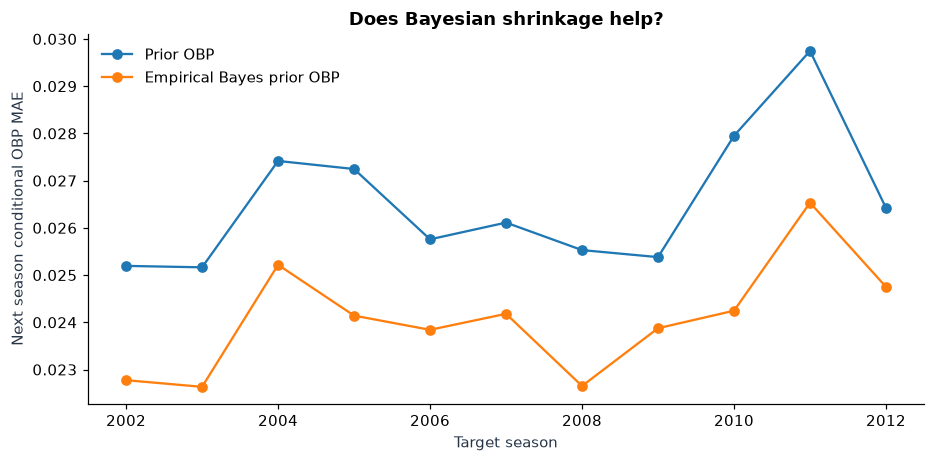

In [49]:
from scipy.stats import beta as beta_dist
bayes_rows=[]; bayes_samples=[]
for target in range(2002,2013):
    prev=p_all[(p_all.yearID==target-1)&p_all.PA.ge(300)&p_all.onbase_denom.gt(0)].copy()
    hist=p_all[(p_all.yearID<target)&(p_all.yearID>=target-5)&p_all.onbase_denom.gt(0)]
    league_rate=hist.onbase_num.sum()/hist.onbase_denom.sum()
    prior_opportunities=200.0  # predeclared shrinkage strength, not tuned on evaluation labels
    a=league_rate*prior_opportunities; b=(1-league_rate)*prior_opportunities
    prev['bayes_OBP']=(prev.onbase_num+a)/(prev.onbase_denom+a+b)
    prev['posterior_low']=beta_dist.ppf(.05,prev.onbase_num+a,prev.onbase_denom-prev.onbase_num+b)
    prev['posterior_high']=beta_dist.ppf(.95,prev.onbase_num+a,prev.onbase_denom-prev.onbase_num+b)
    future=p_all[p_all.yearID==target][['playerID','OBP','PA']].rename(columns={'OBP':'next_OBP','PA':'next_PA'})
    chk=prev.merge(future,on='playerID',how='inner',validate='one_to_one')
    chk=chk[chk.next_PA.ge(300)&chk.next_OBP.notna()].copy()
    if len(chk)<10:continue
    bayes_rows.append({'target_year':target,'n':len(chk),'MAE_raw_prior':mean_absolute_error(chk.next_OBP,chk.OBP),
         'MAE_bayes':mean_absolute_error(chk.next_OBP,chk.bayes_OBP),'historical_league_prior':league_rate})
    if target==2002:bayes_samples=prev.sort_values('PA',ascending=False).head(70).copy()
bayes_cv=pd.DataFrame(bayes_rows)
save_frame(bayes_cv,'research_33_bayesian_obp_backtest.csv')
save_frame(bayes_samples[['playerID','name','PA','OBP','bayes_OBP','posterior_low','posterior_high']], 'research_33_bayesian_obp_intervals_2001.csv')
display(bayes_cv.tail(6).round(4))
print('Mean annual Bayesian vs raw prior MAE:',bayes_cv[['MAE_bayes','MAE_raw_prior']].mean().round(5).to_dict())
fig,ax=plt.subplots(figsize=(8.6,4.3))
ax.plot(bayes_cv.target_year,bayes_cv.MAE_raw_prior,'o-',label='Prior OBP')
ax.plot(bayes_cv.target_year,bayes_cv.MAE_bayes,'o-',label='Empirical Bayes prior OBP')
ax.set(xlabel='Target season',ylabel='Next season conditional OBP MAE',title='Does Bayesian shrinkage help?');ax.legend(frameon=False)
fig.tight_layout();fig.savefig(VISUALS/'research_33_bayesian_talent.png',bbox_inches='tight');plt.show()

## 34. Correlated player risk & CVaR stress testing

**Question:** Does a shared historical-season shock change risk-averse selections? Calibrate idiosyncratic plus common seasonal residual components using **earlier scored seasons only**. Compare expected-events, independently simulated CVaR, and correlated-shock CVaR on a *common correlated evaluation distribution*. These are assumptions-driven scenarios, not verified correlation forecasts.


Common evaluation distribution: correlated historical-year shocks.


,year,strategy,n_players,budget_usd,cost_usd,mean_common_scenario_events,worst_20pct_mean_events,realized_onbase_events,number_of_historical_seasons
0,2007,Expected events,10,28000000.0,15381167.0,2435.92,2178.99,2559.0,5
1,2007,Independent-error CVaR,10,28000000.0,15481667.0,2414.43,2136.31,2472.0,5
2,2007,Correlated-shock CVaR,10,28000000.0,15381167.0,2435.92,2178.99,2559.0,5
3,2010,Expected events,10,26500000.0,12708600.0,2411.25,2096.28,2227.0,8
4,2010,Independent-error CVaR,10,26500000.0,13443600.0,2377.33,2030.63,2101.0,8
5,2010,Correlated-shock CVaR,10,26500000.0,12713600.0,2404.36,2126.57,2097.0,8
6,2012,Expected events,10,29300000.0,11708233.0,2130.32,1878.65,2203.0,10
7,2012,Independent-error CVaR,10,29300000.0,11702233.0,2123.93,1839.99,2178.0,10
8,2012,Correlated-shock CVaR,10,29300000.0,11689333.0,2114.66,1873.96,2072.0,10


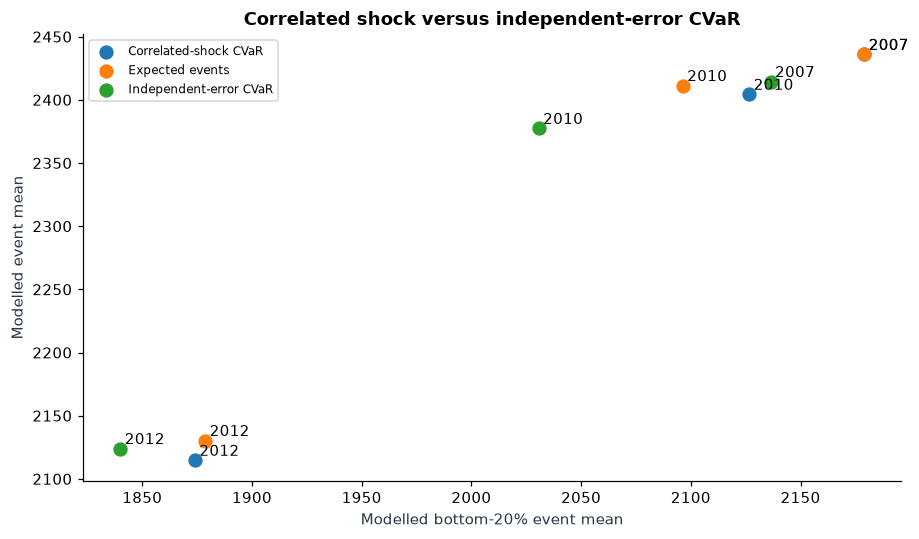

In [50]:
from scipy.optimize import milp,Bounds,LinearConstraint
from scipy.sparse import csc_matrix
risk_corr_rows=[];risk_corr_members=[];rng=np.random.default_rng(20261019)
for year in (2007,2010,2012):
    current=event_predictions[(event_predictions.target_year==year)&(event_predictions.model=='Poisson HistGB')&event_predictions.player_salary.gt(0)].copy()
    old=event_predictions[(event_predictions.target_year<year)&(event_predictions.model=='Poisson HistGB')].copy()
    if len(current)<30 or old.target_year.nunique()<3:continue
    current['cheap_value']=current.pred_events/(current.player_salary/1e6)**.35
    pool_corr=pd.concat([current.nlargest(55,'cheap_value'),current.nsmallest(25,'player_salary')]).drop_duplicates('playerID').reset_index(drop=True)
    if len(pool_corr)<10:continue
    cap=max(float(annual_budgets.get(year,10*pool_corr.player_salary.median())),float(np.sort(pool_corr.player_salary)[:10].sum()*1.02))
    annual_effect=old.groupby('target_year').residual.mean()
    mean_res=old.residual.mean()
    centered=old.merge(annual_effect.rename('year_mean'),on='target_year').assign(idio=lambda d:d.residual-d.year_mean)
    N=64; nn=len(pool_corr)
    indep=rng.choice(old.residual.to_numpy()-mean_res,size=(N,nn),replace=True)
    common=rng.choice(annual_effect.to_numpy()-mean_res,size=(N,1),replace=True)
    idiosyncratic=rng.choice(centered.idio.to_numpy(),size=(N,nn),replace=True)
    base=pool_corr.pred_events.to_numpy(float)[None,:]
    independent=np.clip(base+indep,0,None)
    correlated=np.clip(base+common+idiosyncratic,0,None)
    for label,sim,lam in [('Expected events',correlated,0.),('Independent-error CVaR',independent,.50),('Correlated-shock CVaR',correlated,.50)]:
        selected_idx=scenario_roster(pool_corr,sim,cap,slots=10,lam=lam,alpha=.20)
        if selected_idx is None:continue
        got=pool_corr.iloc[selected_idx]
        fair=correlated[:,selected_idx].sum(axis=1)
        risk_corr_rows.append({'year':year,'strategy':label,'n_players':len(got),'budget_usd':cap,'cost_usd':got.player_salary.sum(),
            'mean_common_scenario_events':fair.mean(),'worst_20pct_mean_events':fair[fair<=np.quantile(fair,.2)].mean(),
            'realized_onbase_events':got.next_events.sum(),'number_of_historical_seasons':old.target_year.nunique()})
        for _,r in got.iterrows():risk_corr_members.append({'year':year,'strategy':label,'playerID':r.playerID,'name':r['name'],'cost':r.player_salary})
risk_corr_df=pd.DataFrame(risk_corr_rows)
print('Common evaluation distribution: correlated historical-year shocks.');display(risk_corr_df.round(2))
save_frame(risk_corr_df,'research_34_correlated_risk_cvar.csv')
save_frame(pd.DataFrame(risk_corr_members),'research_34_risk_roster_members.csv')
fig,ax=plt.subplots(figsize=(8.5,5))
for name,g in risk_corr_df.groupby('strategy'):
 ax.scatter(g.worst_20pct_mean_events,g.mean_common_scenario_events,label=name,s=70)
 for _,r in g.iterrows():ax.annotate(str(int(r.year)),(r.worst_20pct_mean_events,r.mean_common_scenario_events),xytext=(3,3),textcoords='offset points')
ax.set(xlabel='Modelled bottom-20% event mean',ylabel='Modelled event mean',title='Correlated shock versus independent-error CVaR');ax.legend(fontsize=8)
fig.tight_layout();fig.savefig(VISUALS/'research_34_correlated_risk.png',bbox_inches='tight');plt.show()

## 35. Era-normalized OBP, payroll and wins — panel associations

**Question:** Does the OBP association persist across 1985–2012 after accounting for year and team? Reconstruct OBP from individual batting components and inspect discrepancies against Teams official OBP where defined. Missing batter HBP/SF are treated as zero in this Lahman snapshot and pre-2000 reconstruction is **approximate**, not official. Two-way fixed effects are descriptive associations and do not identify causality.


OBP reconstruction audit where team component columns exist:


,absolute_official_minus_reconstructed
count,390.00000
mean,0.00000
std,0.00003
min,0.00000
25%,0.00000
50%,0.00000
75%,0.00000
max,0.00052


Descriptive team and year fixed-effects results:


,term,coefficient,robust_se,p_value,adjusted_r_squared
0,reconstructed_OBP_z,0.04293,0.00232,0.00000,0.4274
1,ln_payroll_z,0.01042,0.00253,0.00004,0.4274


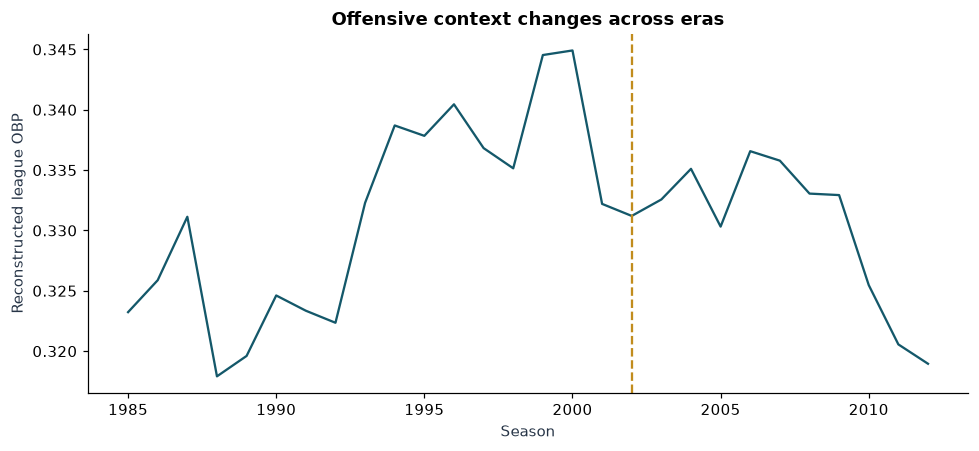

In [51]:
import statsmodels.formula.api as smf
bt=raw['batting'][raw['batting'].yearID.between(1985,2012)].copy()
for v in ('AB','H','BB','HBP','SF'):bt[v]=bt[v].fillna(0)
bt_team=bt.groupby(['yearID','teamID'],as_index=False)[['AB','H','BB','HBP','SF']].sum()
bt_team['reconstructed_OBP']=(bt_team.H+bt_team.BB+bt_team.HBP)/(bt_team.AB+bt_team.BB+bt_team.HBP+bt_team.SF).replace(0,np.nan)
era=team_seasons(raw).query('1985 <= yearID <= 2012').merge(bt_team[['yearID','teamID','reconstructed_OBP']],on=['yearID','teamID'],how='left',validate='one_to_one')
era['obp_discrepancy']=(era.OBP-era.reconstructed_OBP).abs()
check_era=era[era.OBP.notna()]['obp_discrepancy'].describe().to_frame('absolute_official_minus_reconstructed')
print('OBP reconstruction audit where team component columns exist:');display(check_era.round(5))
era['ln_payroll']=np.log(era.payroll.where(era.payroll.gt(0)))
for v in ('reconstructed_OBP','ln_payroll'):
 era[v+'_z']=era.groupby('yearID')[v].transform(lambda s:(s-s.mean())/s.std() if s.std()>0 else np.nan)
reg_era=era.dropna(subset=['win_pct','reconstructed_OBP_z','ln_payroll_z']).copy()
model_era=smf.ols('win_pct ~ reconstructed_OBP_z + ln_payroll_z + C(yearID) + C(teamID)',data=reg_era).fit(cov_type='HC1')
era_coeff=pd.DataFrame({'term':['reconstructed_OBP_z','ln_payroll_z'],
 'coefficient':[model_era.params[k] for k in ['reconstructed_OBP_z','ln_payroll_z']],
 'robust_se':[model_era.bse[k] for k in ['reconstructed_OBP_z','ln_payroll_z']],
 'p_value':[model_era.pvalues[k] for k in ['reconstructed_OBP_z','ln_payroll_z']]})
era_coeff['adjusted_r_squared']=model_era.rsquared_adj
print('Descriptive team and year fixed-effects results:');display(era_coeff.round(5))
save_frame(era_coeff,'research_35_era_team_fe.csv')
save_frame(era[['yearID','teamID','name','W','L','payroll','win_pct','OBP','reconstructed_OBP','obp_discrepancy']],'research_35_era_team_obp_audit.csv')
league_era=(bt_team.groupby('yearID')[['H','BB','HBP','AB','SF']].sum())
league_era['league_OBP']=(league_era.H+league_era.BB+league_era.HBP)/(league_era.AB+league_era.BB+league_era.HBP+league_era.SF)
fig,ax=plt.subplots(figsize=(9,4.2));ax.plot(league_era.index,league_era.league_OBP,color='#14586a')
ax.axvline(2002,color='#c18c1d',ls='--');ax.set(xlabel='Season',ylabel='Reconstructed league OBP',title='Offensive context changes across eras')
fig.tight_layout();fig.savefig(VISUALS/'research_35_era_normalization.png',bbox_inches='tight');plt.show()

## 36. Distribution shift, calibration and subgroup model audit

**Question:** Where do the event-count models fail? Use ONLY predecision features to define age/previous-OBP subgroups. Evaluate out-of-time predictions across target year and salary coverage; the latter is a postdecision data-availability diagnostic, not an acquisition signal. Subgroup uncertainty is descriptive and many comparisons can be noisy.


Largest subgroup event MAEs (consider n):


,dimension,group,model,n,MAE,bias
20,has_listed_next_salary,0,Prior H+BB+HBP,188,106.250,-101.303
22,has_listed_next_salary,0,Two-stage PA × OBP,188,74.895,-66.104
18,has_listed_next_salary,0,Poisson HistGB,188,74.714,-66.736
5,prior_age_band,32+,Prior H+BB+HBP,960,59.224,-41.882
12,prior_OBP_band,<.310,Prior H+BB+HBP,569,53.596,-25.645
13,prior_OBP_band,.310–.350,Prior H+BB+HBP,1297,52.507,-26.778
2,prior_age_band,32+,Poisson HistGB,960,50.480,-0.620
14,prior_OBP_band,>.350,Prior H+BB+HBP,1155,50.359,-27.618
8,prior_age_band,32+,Two-stage PA × OBP,960,49.929,-0.534
9,prior_OBP_band,<.310,Poisson HistGB,569,49.552,-3.253


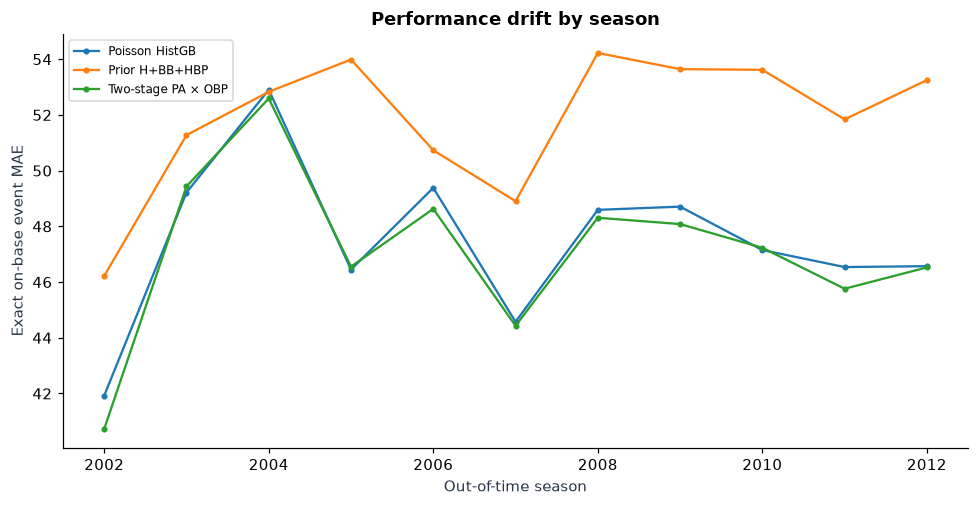

In [52]:
audit_ev=event_predictions[event_predictions.model.isin(['Two-stage PA × OBP','Poisson HistGB','Prior H+BB+HBP'])].copy()
audit_ev=audit_ev.merge(full_decisions[['playerID','target_year','age','OBP','has_listed_next_salary']].rename(columns={'OBP':'prior_OBP'}),on=['playerID','target_year'],how='left',validate='many_to_one')
audit_ev['prior_age_band']=pd.cut(audit_ev.age,[0,26,31,60],labels=['<=26','27–31','32+'])
audit_ev['prior_OBP_band']=pd.cut(audit_ev.prior_OBP,[-1,.310,.350,1.1],labels=['<.310','.310–.350','>.350'])
audit_ev['absolute_error']=abs(audit_ev.next_events-audit_ev.pred_events)
shift_rows=[]
for subset in ['prior_age_band','prior_OBP_band','has_listed_next_salary']:
 for (model,group),sub in audit_ev.groupby(['model',subset],observed=True):
  shift_rows.append({'dimension':subset,'group':str(group),'model':model,'n':len(sub),'MAE':sub.absolute_error.mean(),'bias':sub.residual.mean()})
shift=pd.DataFrame(shift_rows)
shift_year=audit_ev.groupby(['target_year','model'],as_index=False).agg(n=('playerID','size'),MAE=('absolute_error','mean'),bias=('residual','mean'))
save_frame(shift,'research_36_subgroup_errors.csv');save_frame(shift_year,'research_36_yearly_drift.csv')
print('Largest subgroup event MAEs (consider n):');display(shift.sort_values('MAE',ascending=False).head(14).round(3))
fig,ax=plt.subplots(figsize=(9,4.7))
for model,g in shift_year.groupby('model'):ax.plot(g.target_year,g.MAE,'o-',label=model,ms=3)
ax.set(xlabel='Out-of-time season',ylabel='Exact on-base event MAE',title='Performance drift by season');ax.legend(fontsize=8)
fig.tight_layout();fig.savefig(VISUALS/'research_36_model_drift.png',bbox_inches='tight');plt.show()

## 37. Measured Baseball-Reference bWAR valuation

Join external `WAR.csv` (`playerID`, `yearID`, `WAR`) to the recorded player-year salaries. The source is **Baseball-Reference bWAR**, never a mix with FanGraphs fWAR. The uploaded Windows run has a valid join; display `SKIPPED` only on future runs where the file is unavailable or its schema is incompatible.

**Interpretation:** Salary per positive WAR is a descriptive historical ratio, not an offer price or prospectively known valuation.


In [53]:
war_status={'analysis':37,'name':'External historical WAR comparison','status':'SKIPPED','detail':'Missing optional WAR.csv'}
war_data_path=DATA_DIR/'WAR.csv'
if war_data_path.is_file():
    ww=pd.read_csv(war_data_path)
    w_col=next((c for c in ['WAR','war','bWAR','fWAR'] if c in ww.columns),None)
    if {'playerID','yearID'}.issubset(ww.columns) and w_col is not None:
        ww=ww[['playerID','yearID',w_col]].rename(columns={w_col:'measured_WAR'})
        if not ww.duplicated(['playerID','yearID']).any():
            war_values=player_salary.merge(ww,on=['playerID','yearID'],how='inner',validate='one_to_one')
            war_values=war_values[war_values.player_salary.gt(0)&war_values.measured_WAR.notna()].copy()
            war_values['salary_per_positive_WAR_usd']=(war_values.player_salary/war_values.measured_WAR.where(war_values.measured_WAR.gt(0)))
            war_values['WAR_per_million']=war_values.measured_WAR/(war_values.player_salary/1e6)
            save_frame(war_values,'research_37_external_war_salary.csv')
            print('Measured WAR joined, example 2002 positive-WAR value:')
            display(war_values.query('yearID == 2002 and measured_WAR > 1').nsmallest(10,'salary_per_positive_WAR_usd').round(2))
            war_status.update(status='EXECUTED',detail=f'{len(war_values)} matched player-years; check WAR source metadata before publication')
        else:war_status['detail']='WAR.csv has duplicate player-year keys: provide already consolidated WAR values'
    else:war_status['detail']='WAR.csv requires playerID, yearID and WAR (or war/bWAR/fWAR)'
war_status_df=pd.DataFrame([war_status]);display(war_status_df);save_frame(war_status_df,'research_37_war_status.csv')

Measured WAR joined, example 2002 positive-WAR value:


,playerID,yearID,player_salary,measured_WAR,salary_per_positive_WAR_usd,WAR_per_million
21896,zitoba01,2002,295000,7.11,41490.86,24.10
14756,oswalro01,2002,300000,6.88,43604.65,22.93
8894,hinsker01,2002,200000,3.96,50505.05,19.80
5406,eckstda01,2002,280000,5.24,53435.11,18.71
18639,spiveju01,2002,215000,3.94,54568.53,18.33
15651,pineijo01,2002,255000,4.65,54838.71,18.24
8843,hillesh02,2002,260000,4.25,61176.47,16.35
2628,buehrma01,2002,310000,5.02,61752.99,16.19
14446,ohkato01,2002,240000,3.76,63829.79,15.67
1327,bellhma01,2002,224000,3.37,66468.84,15.04


,analysis,name,status,detail
0,37,External historical WAR comparison,EXECUTED,21924 matched player-years; check WAR source m...


WindowsPath('C:/Users/htpar/Downloads/outputs/processed/research_37_war_status.csv')

## 38. Hypothetical player replacement → runs → expected wins

**Question:** How might an upgrade change projected team wins? Illustrative **2002 preseason counterfactual** using only pre-2002 league events-to-runs scaling and 2001 Oakland baseline R/RA. This is not WAR, nor an estimated causal player effect. The scenario assumes identical opportunity exposure and unchanged defense/pitching; output is a sensitivity scenario.


,assumed_run_conversion_multiplier,reference_year,scenario_year,upgrade_player,illustrative_replacement,preseason_expected_event_delta,assumed_runs_added,baseline_expected_wins,scenario_expected_wins,expected_wins_delta
0,0.5,2001,2002,Barry Bonds,Rondell White,132.633,24.985,103.735,105.624,1.889
1,1.0,2001,2002,Barry Bonds,Rondell White,132.633,49.971,103.735,107.434,3.699
2,1.5,2001,2002,Barry Bonds,Rondell White,132.633,74.956,103.735,109.168,5.433


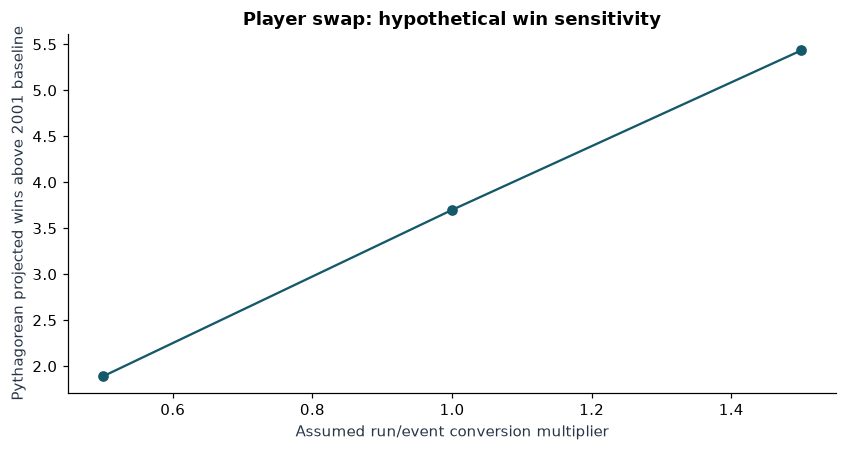

In [54]:
candidates38=stage_all[stage_all.target_year.eq(2002)].copy()
if 'expected_onbase_proxy' not in candidates38:raise ValueError('Missing preceding two-stage event forecasts')
candidates38=candidates38[candidates38.expected_onbase_proxy.notna()&candidates38.expected_onbase_proxy.ge(0)].copy()
candidates38=candidates38.sort_values('expected_onbase_proxy',ascending=False).reset_index(drop=True)
# Keep comparable hypothetical candidates from the same model; never claim trade availability.
strong=candidates38.iloc[0]; replacement=candidates38.iloc[len(candidates38)//2]
old2001=team_seasons(raw).query('yearID == 2001 and teamID == "OAK"').iloc[0]
league2001=raw['teams'][raw['teams'].yearID.eq(2001)]
events2001=bt_team[bt_team.yearID.eq(2001)]
runper_event=float(league2001.R.sum()/(events2001.H.sum()+events2001.BB.sum()+events2001.HBP.sum()))
additional_events=float(strong.expected_onbase_proxy-replacement.expected_onbase_proxy)
win_scenarios=[]
for f in (.5,1.0,1.5):
    dr=additional_events*runper_event*f  # *assumed* impact, not causal estimated rate
    R=float(old2001.R)+dr; RA=float(old2001.RA)
    expected_wins=162*R**1.83/(R**1.83+RA**1.83)
    base_wins=162*float(old2001.R)**1.83/(float(old2001.R)**1.83+RA**1.83)
    win_scenarios.append({'assumed_run_conversion_multiplier':f,'reference_year':2001,'scenario_year':2002,
      'upgrade_player':strong['name'],'illustrative_replacement':replacement['name'],
      'preseason_expected_event_delta':additional_events,'assumed_runs_added':dr,'baseline_expected_wins':base_wins,
      'scenario_expected_wins':expected_wins,'expected_wins_delta':expected_wins-base_wins})
win38=pd.DataFrame(win_scenarios)
display(win38.round(3));save_frame(win38,'research_38_hypothetical_player_to_wins.csv')
fig,ax=plt.subplots(figsize=(7.8,4.2));ax.plot(win38.assumed_run_conversion_multiplier,win38.expected_wins_delta,'o-',color='#14586a')
ax.set(xlabel='Assumed run/event conversion multiplier',ylabel='Pythagorean projected wins above 2001 baseline',title='Player swap: hypothetical win sensitivity')
fig.tight_layout();fig.savefig(VISUALS/'research_38_expected_wins_sensitivity.png',bbox_inches='tight');plt.show()

## 39. Dynamic latent OBP with a Kalman-style state filter

**Question:** Does a noisy latent-talent state model outperform prior-year OBP? Each observed OBP gets opportunity-dependent binomial-variance approximation, with a predeclared state evolution variance. All estimates use the player's seasons **strictly before the target year**; no future smoothing. Evaluate the same observed-OBP survivors as other rate models.


State filter (simple fixed-process-noise model), history >=3 seasons:


,year,n,MAE_state,MAE_previous
0,2007,181,0.0259,0.0267
1,2008,182,0.0249,0.0255
2,2009,188,0.0238,0.0252
3,2010,186,0.0241,0.0278
4,2011,180,0.0275,0.0302
5,2012,168,0.0236,0.0268


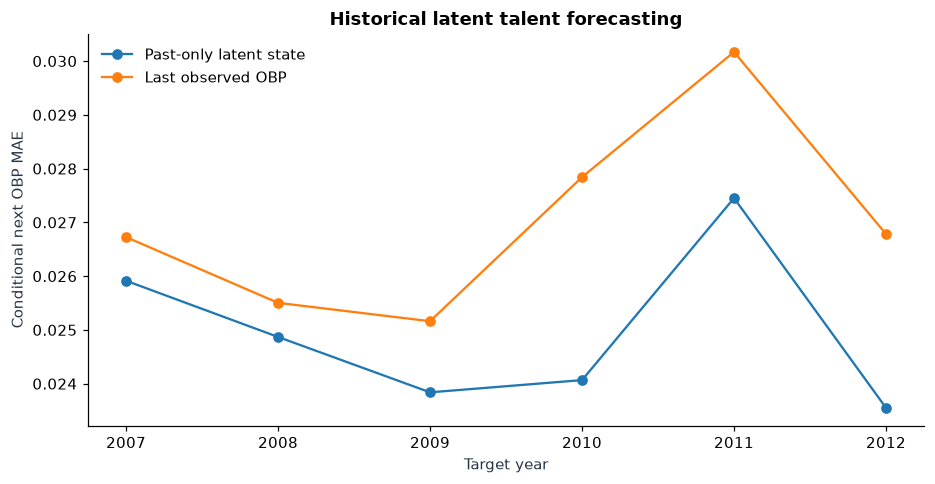

In [55]:
def filtered_player_obp(hist, league_mean=.330,process_sd=.012):
    mu=float(league_mean); var=.040**2; last=None
    for row in hist.sort_values('yearID').itertuples():
        n=float(row.onbase_denom)
        if n<=0 or not np.isfinite(row.OBP):continue
        dt=1 if last is None else max(1,int(row.yearID-last))
        var+=process_sd**2*dt
        obsvar=max(float(row.OBP)*(1-float(row.OBP))/n, .00002)
        kg=var/(var+obsvar)
        mu=mu+kg*(float(row.OBP)-mu)
        var=(1-kg)*var
        last=row.yearID
    return mu,float(np.sqrt(var))
latent_rows=[]
for year in range(2007,2013):
    train=p_all[(p_all.yearID<year)&p_all.onbase_denom.gt(0)]
    league_prior=float(train.onbase_num.sum()/train.onbase_denom.sum())
    prior=train[train.yearID.eq(year-1)&train.PA.ge(300)]
    later=p_all[p_all.yearID.eq(year)&p_all.PA.ge(300)][['playerID','OBP']].rename(columns={'OBP':'actual_next_OBP'})
    cur=prior.merge(later,on='playerID',how='inner',validate='one_to_one')
    for r in cur.itertuples():
        past=train[train.playerID.eq(r.playerID)]
        if len(past)<3:continue
        talent,sd=filtered_player_obp(past,league_prior)
        latent_rows.append({'year':year,'playerID':r.playerID,'name':r.name,'prior_OBP':r.OBP,
          'state_filtered_OBP':talent,'state_sd':sd,'actual_next_OBP':r.actual_next_OBP,'history_n':len(past)})
latent39=pd.DataFrame(latent_rows)
latent39['err_state']=abs(latent39.state_filtered_OBP-latent39.actual_next_OBP)
latent39['err_previous']=abs(latent39.prior_OBP-latent39.actual_next_OBP)
latent_year=latent39.groupby('year',as_index=False).agg(n=('playerID','size'),MAE_state=('err_state','mean'),MAE_previous=('err_previous','mean'))
print('State filter (simple fixed-process-noise model), history >=3 seasons:');display(latent_year.round(4))
save_frame(latent39,'research_39_latent_obp_player_predictions.csv');save_frame(latent_year,'research_39_latent_obp_annual.csv')
fig,ax=plt.subplots(figsize=(8.6,4.5))
ax.plot(latent_year.year,latent_year.MAE_state,'o-',label='Past-only latent state')
ax.plot(latent_year.year,latent_year.MAE_previous,'o-',label='Last observed OBP')
ax.set(xlabel='Target year',ylabel='Conditional next OBP MAE',title='Historical latent talent forecasting');ax.legend(frameon=False)
fig.tight_layout();fig.savefig(VISUALS/'research_39_state_space_comparison.png',bbox_inches='tight');plt.show()

## 40. Descriptive synthetic-control-style Oakland comparison

**Question:** How different were Oakland's post-2001 wins from a pre-period-matched weighted comparison of other teams? Optimize donor weights **only on 1995–2001 win rates and log-payroll percentiles**. 2002 is an illustrative split, **not a verified Moneyball treatment date**, so findings are *not a causal estimate*. Spillovers, ownership changes and roster strategy adoption invalidate strong identification.


Donor match pre-period RMSE / mean post split difference (descriptive only): 0.0618 0.0168


,donor,preperiod_weight
12,MIN,0.5384
19,SFN,0.2284
5,CIN,0.1561
18,SEA,0.0629
9,HOU,0.0142
1,BAL,0.0000
7,COL,0.0000
4,CHN,0.0000
21,TEX,0.0000
16,PIT,0.0000


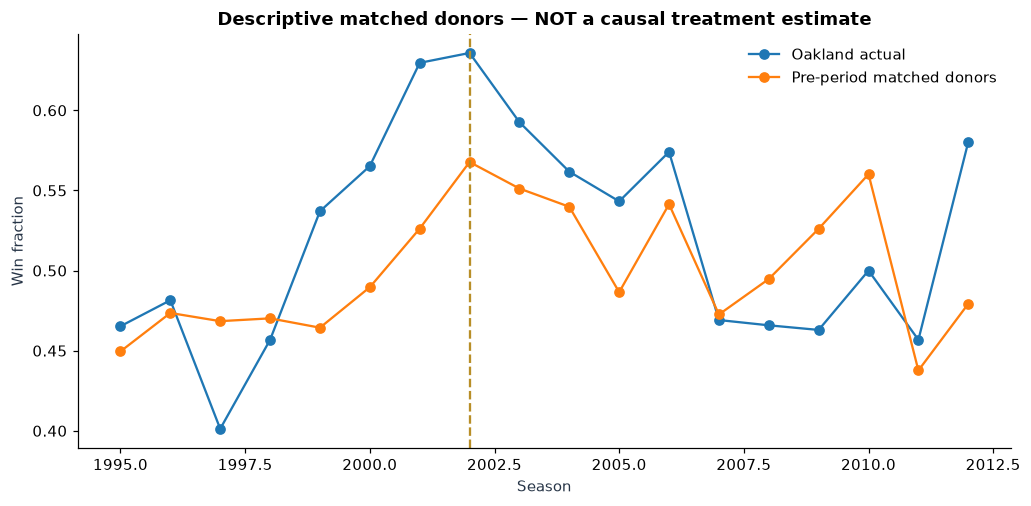

In [56]:
from scipy.optimize import minimize
sc=team_seasons(raw).query('1995 <= yearID <= 2012').copy()
sc['payroll_rank_percentile']=sc.groupby('yearID').payroll.rank(pct=True)
sc['log_payroll_pct']=sc.payroll_rank_percentile
valid_years=set(range(1995,2013));pre=list(range(1995,2002));post=list(range(2002,2013))
sc_w=sc.pivot_table(index='yearID',columns='teamID',values='win_pct',aggfunc='first')
sc_p=sc.pivot_table(index='yearID',columns='teamID',values='log_payroll_pct',aggfunc='first')
donor_names=[c for c in sc_w.columns if c!='OAK' and c in sc_p and sc_w.reindex(index=list(valid_years))[c].notna().all() and sc_p.reindex(index=pre)[c].notna().all()]
assert 'OAK' in sc_w and len(donor_names)>=8
# Annual pre-period normalized features balance BOTH wins and payroll position.
features_target=np.r_[sc_w.loc[pre,'OAK'].to_numpy(float),sc_p.loc[pre,'OAK'].to_numpy(float)]
feature_donors=np.vstack([np.r_[sc_w.loc[pre,d].to_numpy(float),sc_p.loc[pre,d].to_numpy(float)] for d in donor_names]).T
sd=np.std(feature_donors,axis=1);sd=np.where(sd>.001,sd,.001)
xt=features_target/sd;xd=feature_donors/sd[:,None]
obj=lambda w:float(np.sum((xd@w-xt)**2)+.02*np.sum(w*w))
result=minimize(obj,np.full(len(donor_names),1/len(donor_names)),method='SLSQP',bounds=[(0,1)]*len(donor_names),
 constraints={'type':'eq','fun':lambda w:np.sum(w)-1},options={'maxiter':500,'ftol':1e-10})
assert result.success,f'Synthetic comparison solver: {result.message}'
synth=sc_w[donor_names].to_numpy(float)@result.x
sc_comparison=pd.DataFrame({'year':sc_w.index,'OAK_win_pct':sc_w.OAK.to_numpy(float),'matched_donor_win_pct':synth})
sc_comparison['gap']=sc_comparison.OAK_win_pct-sc_comparison.matched_donor_win_pct
weights_sc=pd.DataFrame({'donor':donor_names,'preperiod_weight':result.x}).sort_values('preperiod_weight',ascending=False)
print('Donor match pre-period RMSE / mean post split difference (descriptive only):',
 round(float(np.sqrt(np.mean(sc_comparison[sc_comparison.year.isin(pre)].gap**2))),4),
 round(float(sc_comparison[sc_comparison.year.isin(post)].gap.mean()),4))
display(weights_sc.head(10).round(4));save_frame(sc_comparison,'research_40_oakland_matched_donor.csv');save_frame(weights_sc,'research_40_matched_donor_weights.csv')
fig,ax=plt.subplots(figsize=(9.5,4.7))
ax.plot(sc_comparison.year,sc_comparison.OAK_win_pct,'o-',label='Oakland actual')
ax.plot(sc_comparison.year,sc_comparison.matched_donor_win_pct,'o-',label='Pre-period matched donors')
ax.axvline(2002,ls='--',color='#b88e27');ax.set(xlabel='Season',ylabel='Win fraction',title='Descriptive matched donors — NOT a causal treatment estimate')
ax.legend(frameon=False);fig.tight_layout();fig.savefig(VISUALS/'research_40_synthetic_control_descriptive.png',bbox_inches='tight');plt.show()

## 42. Interpretability — permutation and ICE without causal claims

**Question:** Which prior-season features drive next-season appearance probability in an already trained, chronologically held-out classifier? Compute **holdout permutation importance** and individual conditional expectation (ICE) profiles for age. Correlated features limit individual permutation interpretation; ICE shows model sensitivity, not causal effect. separately supplied `shap` is not required.


Holdout permutation importance, larger positive is more useful:


,feature,delta_brier_importance,importance_sd
5,PA,0.03413,0.00570
4,SO_rate,0.00688,0.00130
6,age,0.00580,0.00191
1,SLG,0.00138,0.00147
0,OBP,0.00077,0.00097
2,ISO,0.00066,0.00099
3,BB_rate,-0.00007,0.00024


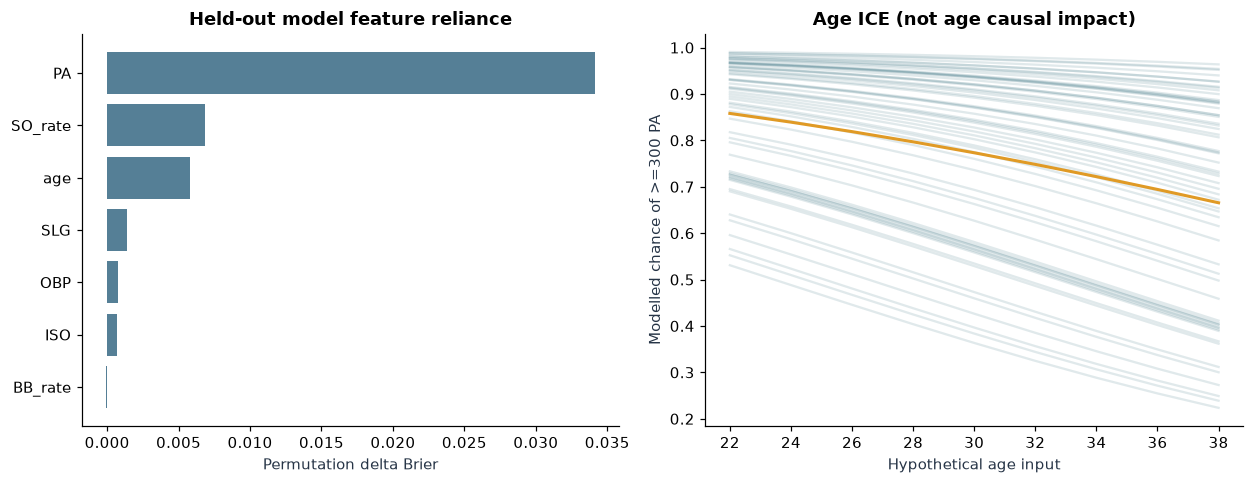

In [57]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import brier_score_loss
# Existing risk_model fits <=2010; risk_test belongs to 2011–2012 and includes next_regular labels only for audit.
importance42=permutation_importance(risk_model,risk_test[FEATURES],risk_test.next_regular,
             scoring='neg_brier_score',n_repeats=12,random_state=20261019)
interpret42=pd.DataFrame({'feature':FEATURES,'delta_brier_importance':importance42.importances_mean,
                          'importance_sd':importance42.importances_std}).sort_values('delta_brier_importance',ascending=False)
print('Holdout permutation importance, larger positive is more useful:');display(interpret42.round(5))
save_frame(interpret42,'research_42_holdout_risk_permutation.csv')
ice_sample=risk_test[FEATURES].sample(n=min(60,len(risk_test)),random_state=42).copy()
ages42=np.arange(22,39,2);ice=[]
for age_i in ages42:
    temp=ice_sample.copy();temp['age']=age_i
    prob=risk_model.predict_proba(temp[FEATURES])[:,1]
    ice.extend({'age_assumed':age_i,'sample_idx':j,'model_p_300pa':p} for j,p in enumerate(prob))
ice42=pd.DataFrame(ice)
save_frame(ice42,'research_42_risk_age_ice.csv')
fig,axes=plt.subplots(1,2,figsize=(11.5,4.5))
axes[0].barh(interpret42.feature,interpret42.delta_brier_importance,color='#557f96');axes[0].invert_yaxis()
axes[0].set(xlabel='Permutation delta Brier',title='Held-out model feature reliance')
for _,g in ice42.groupby('sample_idx'):axes[1].plot(g.age_assumed,g.model_p_300pa,color='#14586a',alpha=.13)
axes[1].plot(ice42.groupby('age_assumed').model_p_300pa.mean(),color='#e09a25',lw=2,label='ICE mean')
axes[1].set(xlabel='Hypothetical age input',ylabel='Modelled chance of >=300 PA',title='Age ICE (not age causal impact)')
fig.tight_layout();fig.savefig(VISUALS/'research_42_interpretability.png',bbox_inches='tight');plt.show()

## 43. Stress tests for pricing assumptions and player selection

**Question:** How robust is the 2006–2012 value strategy to changes in recorded salary assumptions and the projected event score? Keep each year's observed outcomes completely unseen at ranking time. Retrospective outcome calculation occurs **after** picks are frozen. These are perturbations of a historical screen, not out-of-sample causal validations.


Scenario perturbation robustness (no outcome-informed selection):


,scenario,strategy,n_years,mean_actual_proxy,mean_scenario_cost
0,Older-player downside,Previous OBP,7,200.82,26202689.14
1,Older-player downside,Value score,7,290.89,25534178.71
2,Original,Previous OBP,7,200.82,26202689.14
3,Original,Value score,7,270.00,25152642.86
4,Salary +15%,Previous OBP,7,195.85,26222016.94
5,Salary +15%,Value score,7,247.33,26009722.99
6,Salary -15%,Previous OBP,7,204.65,26282103.34
7,Salary -15%,Value score,7,289.33,25318193.50
8,Young-player upside,Previous OBP,7,200.82,26202689.14
9,Young-player upside,Value score,7,285.40,25525371.71


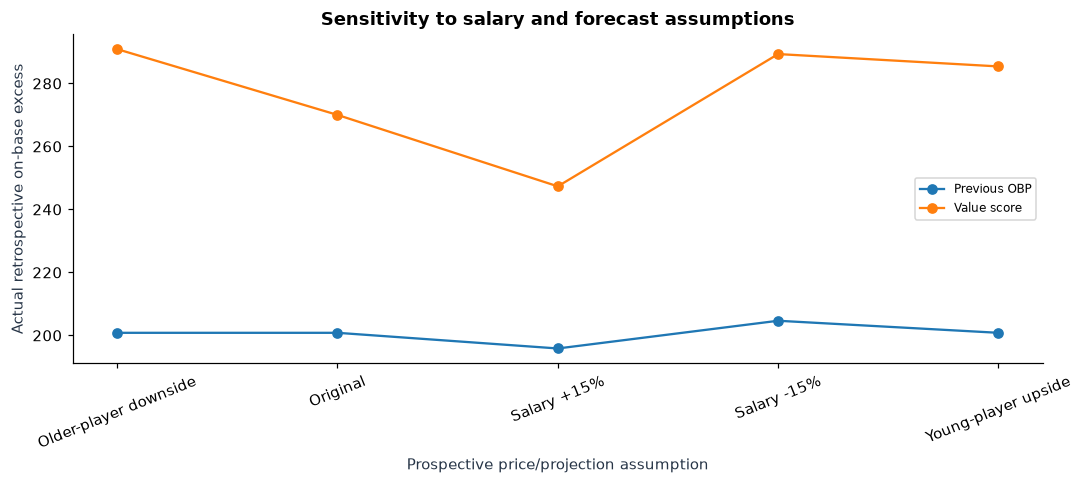

In [58]:
stress_results=[];stress_members=[]
for yr in range(2006,2013):
    scored=scored_cache.get(yr)
    if scored is None or len(scored)<10:continue
    cap=annual_budgets.get(yr)
    if cap is None:continue
    for scenario,price_mul,pred_mul in [('Original',1.,1.),('Salary +15%',1.15,1.),('Salary -15%',.85,1.),('Older-player downside',1.,.80),('Young-player upside',1.,1.15)]:
        ss=scored.copy();ss['player_salary']=ss.player_salary*price_mul
        # Fixed nested-tuning weights, not fitted on the scenario's outcomes.
        score=policy_objective(ss,.20,0.)
        if scenario=='Older-player downside':score=score*np.where(ss.age>=31,pred_mul,1.)
        if scenario=='Young-player upside':score=score*np.where(ss.age<=27,pred_mul,1.)
        for strategy,objectives in [('Value score',score),('Previous OBP',ss.OBP.to_numpy(float))]:
            chosen=spend_band_selection(ss,objectives,cap,10,min_fraction=.90)
            if chosen is None:continue
            stress_results.append({'year':yr,'scenario':scenario,'strategy':strategy,'cost_usd':chosen.player_salary.sum(),
             'budget_usd':cap,'observed_above_league_event_proxy':chosen.onbase_above_league.sum(),
             'n_players':len(chosen)})
stress43=pd.DataFrame(stress_results)
stress_summary=stress43.groupby(['scenario','strategy'],as_index=False).agg(n_years=('year','nunique'),
 mean_actual_proxy=('observed_above_league_event_proxy','mean'),mean_scenario_cost=('cost_usd','mean'))
print('Scenario perturbation robustness (no outcome-informed selection):');display(stress_summary.round(2))
save_frame(stress43,'research_43_stress_test_annual.csv');save_frame(stress_summary,'research_43_stress_test_summary.csv')
fig,ax=plt.subplots(figsize=(10,4.5))
for m,g in stress_summary.groupby('strategy'):ax.plot(g.scenario,g.mean_actual_proxy,'o-',label=m)
ax.set(xlabel='Prospective price/projection assumption',ylabel='Actual retrospective on-base excess',title='Sensitivity to salary and forecast assumptions')
ax.tick_params(axis='x',rotation=22);ax.legend(fontsize=8);fig.tight_layout()
fig.savefig(VISUALS/'research_43_stress_tests.png',bbox_inches='tight');plt.show()

## 44. Play-by-play research design and validation

The legacy pre-standardized `PlayByPlay.csv` audit follows. **The actual local `plays.csv` is read directly by Section 58** using Retrosheet field names and a streaming 24-state estimator; refer to Section 58's status and output for authoritative play-by-play results.


In [59]:
pbp_path=DATA_DIR/'PlayByPlay.csv'
pbp_status={'analysis':44,'name':'24-state run expectancy / lineup','status':'DEFERRED_TO_58','detail':'Canonical Retrosheet plays.csv is handled directly in Section 58'}
if pbp_path.is_file():
    pbp=pd.read_csv(pbp_path)
    required={'game_id','inning','half','play_index','outs_before','base_state_before','runs_scored'}
    if required.issubset(pbp.columns):
        pp=pbp.dropna(subset=list(required)).copy()
        pp=pp[pp.outs_before.between(0,2)&pp.base_state_before.between(0,7)&pp.runs_scored.ge(0)]
        pp=pp.sort_values(['game_id','inning','half','play_index'])
        pp['half_key']=pp.game_id.astype(str)+'_'+pp.inning.astype(str)+'_'+pp.half.astype(str)
        # Whole-half observed runs from the preplay state through end of the half.
        pp['remaining_runs']=pp.groupby('half_key').runs_scored.transform(lambda s:s.iloc[::-1].cumsum().iloc[::-1])
        table44=pp.groupby(['outs_before','base_state_before'],as_index=False).agg(n=('remaining_runs','size'),
                   run_expectancy=('remaining_runs','mean'))
        save_frame(table44,'research_44_empirical_base_out_run_expectancy.csv')
        display(table44.pivot(index='outs_before',columns='base_state_before',values='run_expectancy').round(2))
        pbp_status.update(status='EXECUTED_PARTIAL',detail=f'{len(table44)} observed states; no lineup optimization without reliable batter-specific transition model')
    else:pbp_status['detail']='PlayByPlay.csv missing required transition/state fields: '+', '.join(sorted(required-set(pbp.columns)))
pbp_status_df=pd.DataFrame([pbp_status]);display(pbp_status_df);save_frame(pbp_status_df,'research_44_pbp_status.csv')

,analysis,name,status,detail
0,44,24-state run expectancy / lineup,DEFERRED_TO_58,Canonical Retrosheet plays.csv is handled dire...


WindowsPath('C:/Users/htpar/Downloads/outputs/processed/research_44_pbp_status.csv')

## Research scope: actual available-data analysis

Sections that depended on absent **MinorLeagueBatting.csv**, actual **Contracts.csv**, or assumed contract terms are omitted (31/41/45). WAR.csv (Baseball-Reference bWAR) is empirical data; Appearances.csv/Fielding.csv/Pitching.csv and plays.zip are loaded only when available and valid. All retrospective selection based on a next-season recorded salary is **hypothetical**, and no FA status or acquisition feasibility can be inferred. The 2002–2012 interval has been used repeatedly for model development and is not a pristine independent holdout.


In [60]:
# Final transparent completion registry — derives counts and statuses from this execution.
research_status=pd.DataFrame([
 {'section':i,'status':'EXECUTED','description':d} for i,d in [
  (33,'Bayesian OBP shrinkage'),(34,'Season-shared risk scenarios'),(35,'Era and team fixed effects'),
  (36,'Out-of-time drift and group errors'),(38,'Hypothetical runs to wins'),(39,'Historical Kalman state filter'),
  (40,'Descriptive matched-donor comparison'),
  (42,'Held-out feature importance and ICE'),(43,'Pricing stress test')]])
for item in [war_status,pbp_status]:research_status.loc[len(research_status)]={'section':item['analysis'],'status':item['status'],'description':item['detail']}
research_status=research_status.sort_values('section').reset_index(drop=True)
display(research_status)
save_frame(research_status,'research_available_data_registry.csv')
print('All cells complete — images:',len(list(VISUALS.glob('*.png'))),'CSV tables:',len(list(PROCESSED.glob('*.csv'))))

,section,status,description
0,33,EXECUTED,Bayesian OBP shrinkage
1,34,EXECUTED,Season-shared risk scenarios
2,35,EXECUTED,Era and team fixed effects
3,36,EXECUTED,Out-of-time drift and group errors
4,37,EXECUTED,21924 matched player-years; check WAR source m...
5,38,EXECUTED,Hypothetical runs to wins
6,39,EXECUTED,Historical Kalman state filter
7,40,EXECUTED,Descriptive matched-donor comparison
8,42,EXECUTED,Held-out feature importance and ICE
9,43,EXECUTED,Pricing stress test


All cells complete — images: 44 CSV tables: 103


# Part 05 · Validation, missing data and robustness

*Technical execution sequence is unchanged. See `01_Moneyball_Main_Research.ipynb` for a topical, reduced presentation.*


## 46. Who gets into the salary dataset?

Some players disappear from the next-season salary file even though they were eligible when the decision was made. That can make the salary-listed group look healthier than the full candidate pool. The analysis compares both groups directly and checks whether weighting the observed players actually changes the estimate. The weighting model is a sensitivity check, not a fix for information that is missing for a reason the model cannot see.


,Value
evaluation_years,2011–2012
eligible_n,535
salary_recorded_n,504
salary_missing_n,31
observed_fraction,0.942056
model_AUC,0.832565
model_Brier,0.049832
all_next_PA,435.196262
salary_recorded_next_PA,457.472222
salary_missing_next_PA,73.032258


,quantile,capped_IPW
0,0.50,1.035413
1,0.90,1.203264
2,0.95,1.302986
3,0.99,1.577885
4,1.00,3.457533


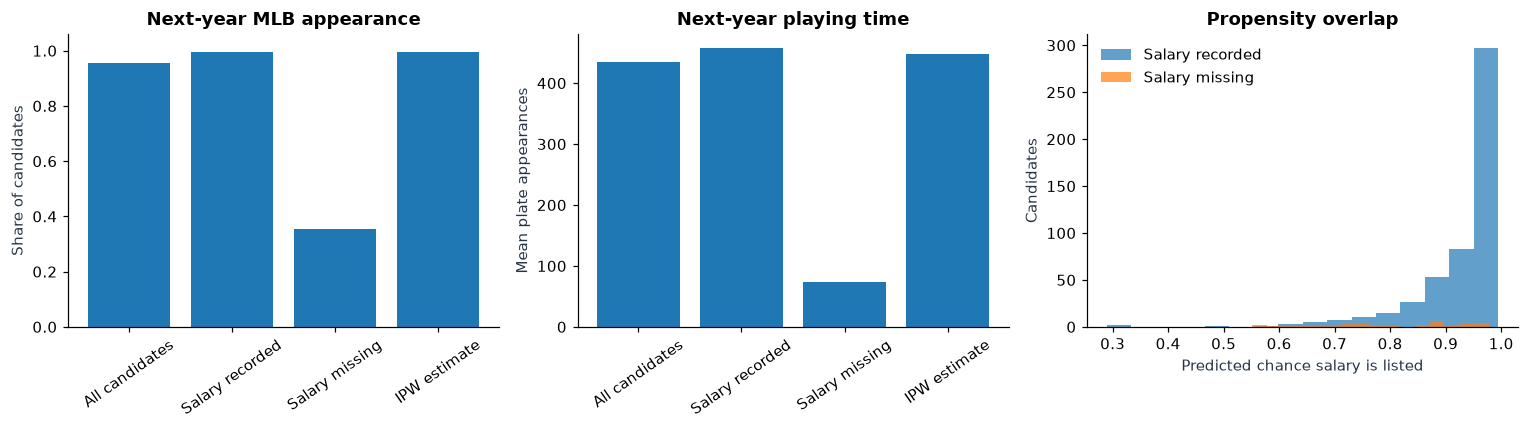

Interpretation: IPW only reweights salary-listed players. It cannot reconstruct outcomes of missing-salary players when those outcomes differ for unmeasured reasons.


In [61]:
from sklearn.metrics import roc_auc_score, brier_score_loss
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

selection_features = ['age','PA','OBP','SLG','ISO','BB_rate','SO_rate','obp_trend_1y','obp_trend_2y']
cohort46 = full_decisions[full_decisions.target_year.between(2002,2012)].dropna(subset=selection_features).copy()
train46 = cohort46[cohort46.target_year.le(2010)].copy()
test46 = cohort46[cohort46.target_year.ge(2011)].copy()
select_model = Pipeline([('scale',StandardScaler()),('model',LogisticRegression(max_iter=1500,C=0.5,random_state=51))])
select_model.fit(train46[selection_features],train46.has_listed_next_salary)
test46['p_salary'] = np.clip(select_model.predict_proba(test46[selection_features])[:,1],0.02,0.995)
test46['salary_group'] = np.where(test46.has_listed_next_salary.eq(1),'Salary recorded','No salary record')
observed46 = test46[test46.has_listed_next_salary.eq(1)].copy()
observed46['weight_raw'] = 1/observed46.p_salary
observed46['weight'] = observed46.weight_raw.clip(upper=10)

def wmean46(f, col):
    return np.average(f[col],weights=f.weight) if len(f) else float('nan')

summary46 = pd.DataFrame([{
    'evaluation_years':'2011–2012',
    'eligible_n':len(test46),'salary_recorded_n':len(observed46),
    'salary_missing_n':int(test46.has_listed_next_salary.eq(0).sum()),
    'observed_fraction':test46.has_listed_next_salary.mean(),
    'model_AUC':roc_auc_score(test46.has_listed_next_salary,test46.p_salary),
    'model_Brier':brier_score_loss(test46.has_listed_next_salary,test46.p_salary),
    'all_next_PA':test46.next_PA.mean(),
    'salary_recorded_next_PA':observed46.next_PA.mean(),
    'salary_missing_next_PA':test46.loc[test46.has_listed_next_salary.eq(0),'next_PA'].mean(),
    'IPW_next_PA':wmean46(observed46,'next_PA'),
    'all_next_appearance':test46.next_any.mean(),
    'salary_recorded_next_appearance':observed46.next_any.mean(),
    'salary_missing_next_appearance':test46.loc[test46.has_listed_next_salary.eq(0),'next_any'].mean(),
    'IPW_next_appearance':wmean46(observed46,'next_any'),
    'effective_weighted_n':(observed46.weight.sum()**2/(observed46.weight**2).sum()),
    'max_raw_weight':observed46.weight_raw.max(),
    'weight_cap':10
}])
display(summary46.T.rename(columns={0:'Value'}).round(4))
save_frame(summary46,'research_46_selection_bias_metrics.csv')
save_frame(test46[['playerID','target_year','name','age','PA','next_PA','next_any','has_listed_next_salary','p_salary']], 'research_46_all_candidate_selection_predictions.csv')
q46=observed46.weight.quantile([.5,.9,.95,.99,1]).rename('capped_IPW').reset_index().rename(columns={'index':'quantile'})
display(q46);save_frame(q46,'research_46_weight_diagnostics.csv')

fig,axs=plt.subplots(1,3,figsize=(14,4))
labels46=['All candidates','Salary recorded','Salary missing','IPW estimate']
axs[0].bar(labels46,[test46.next_any.mean(),observed46.next_any.mean(),
    test46.loc[test46.has_listed_next_salary.eq(0),'next_any'].mean(),wmean46(observed46,'next_any')])
axs[0].set(title='Next-year MLB appearance',ylabel='Share of candidates',ylim=(0,1.06))
axs[1].bar(labels46,[test46.next_PA.mean(),observed46.next_PA.mean(),
    test46.loc[test46.has_listed_next_salary.eq(0),'next_PA'].mean(),wmean46(observed46,'next_PA')])
axs[1].set(title='Next-year playing time',ylabel='Mean plate appearances')
axs[2].hist(test46.loc[test46.has_listed_next_salary.eq(1),'p_salary'],bins=16,alpha=.70,label='Salary recorded')
axs[2].hist(test46.loc[test46.has_listed_next_salary.eq(0),'p_salary'],bins=16,alpha=.70,label='Salary missing')
axs[2].set(title='Propensity overlap',xlabel='Predicted chance salary is listed',ylabel='Candidates')
axs[2].legend(frameon=False)
for ax in axs[:2]:ax.tick_params(axis='x',rotation=35)
fig.tight_layout();fig.savefig(VISUALS/'research_46_salary_selection_bias.png',bbox_inches='tight');plt.show()
print('Interpretation: IPW only reweights salary-listed players. It cannot reconstruct outcomes of missing-salary players when those outcomes differ for unmeasured reasons.')


## 47. Survival analysis: uninterrupted future MLB appearances

The provided batting archive ends in 2012. A missing season is **not necessarily permanent retirement** (injury, minor-league assignment, or a later return may occur). The analysis therefore models the **first season without an MLB batting record** within the next three years, rather than asserting true career-end dates. Players whose records reach the end of the dataset before three full follow-up years are **right-censored**. Fit a discrete-time hazard logistic regression using only 1995–2005 landmark cohorts, evaluate a 2006–2009 landmark cohort with complete 3-year follow-up. Report both observed Kaplan–Meier-style continuation and predicted 3-year probabilities; player-season landmarks are correlated and confidence intervals are descriptive.


,definition,train_landmarks_last_year,test_landmarks,tested_landmarks,observed_three_year_continuation,predicted_three_year_continuation,AUC_3y,Brier_3y,censored_landmarks_all_years
0,No MLB batting record in any next season = int...,2005,2006–2009,1116,0.7572,0.7801,0.8325,0.1373,484


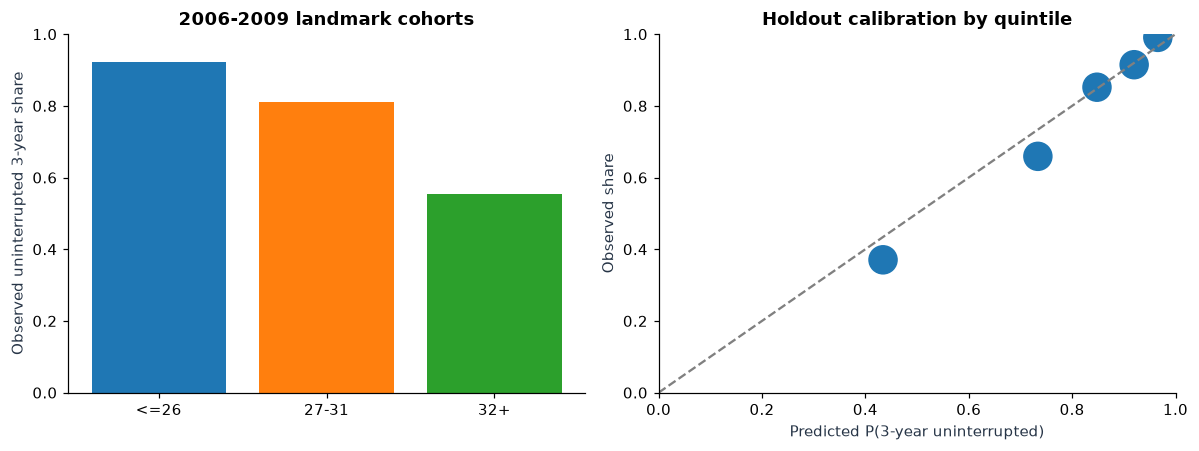

In [62]:
from sklearn.metrics import roc_auc_score,brier_score_loss
# Long format for at-risk person-year, with right censoring at the archive boundary.
active_pairs = set(zip(p_all.playerID.astype(str),p_all.yearID.astype(int)))
landmarks47 = p_all[p_all.yearID.between(1995,2011)&p_all.PA.ge(300)].dropna(subset=['age','PA','OBP','SLG']).copy()
hazard_samples=[];landmark_outcomes=[]
for rr in landmarks47.itertuples(index=False):
    pid=str(rr.playerID);y=int(rr.yearID)
    observed_max=min(3,2012-y)
    if observed_max<=0:continue
    uninterrupted=True;duration=0;event=False
    for k in range(1,observed_max+1):
        missing=(pid,y+k) not in active_pairs
        hazard_samples.append({'playerID':pid,'landmark':y,'k':k,'event':int(missing),
          'age':rr.age,'PA':rr.PA,'OBP':rr.OBP,'SLG':rr.SLG})
        duration=k
        if missing:uninterrupted=False;event=True;break
    landmark_outcomes.append({'playerID':pid,'landmark':y,'followed_years':duration,
           'first_nonappearance_event':int(event), 'right_censored':int(not event and observed_max<3),
           'continuous_3y':int(not event and observed_max==3) if observed_max==3 else np.nan,
           'age':rr.age,'PA':rr.PA,'OBP':rr.OBP,'SLG':rr.SLG})
hazard_data=pd.DataFrame(hazard_samples);survival_lm=pd.DataFrame(landmark_outcomes)
train47=hazard_data[hazard_data.landmark<=2005].copy()
test_lm47=survival_lm[survival_lm.landmark.between(2006,2009)&survival_lm.continuous_3y.notna()].copy()
# k categorical baseline hazard (one-hot) and covariate effects. No test-period fitting.
def hazard_matrix(frame):
    x=frame[['age','PA','OBP','SLG']].copy().reset_index(drop=True)
    for k in (2,3):x[f'year_{k}']=(frame.k.to_numpy()==k).astype(int)
    return x
haz_model=Pipeline([('scale',StandardScaler()),('hazard',LogisticRegression(max_iter=1500,C=1,random_state=47))])
haz_model.fit(hazard_matrix(train47),train47.event)
prob_continue=np.ones(len(test_lm47))
for k in (1,2,3):
    year_frame=test_lm47[['age','PA','OBP','SLG']].copy();year_frame['k']=k
    hazards=haz_model.predict_proba(hazard_matrix(year_frame))[:,1]
    prob_continue*=1-hazards
test_lm47['pred_continuous_3y']=prob_continue
survival_summary=pd.DataFrame([{'definition':'No MLB batting record in any next season = interruption, not confirmed retirement',
    'train_landmarks_last_year':2005,'test_landmarks':'2006–2009','tested_landmarks':len(test_lm47),
    'observed_three_year_continuation':test_lm47.continuous_3y.mean(),
    'predicted_three_year_continuation':test_lm47.pred_continuous_3y.mean(),
    'AUC_3y':roc_auc_score(test_lm47.continuous_3y,test_lm47.pred_continuous_3y),
    'Brier_3y':brier_score_loss(test_lm47.continuous_3y,test_lm47.pred_continuous_3y),
    'censored_landmarks_all_years':int(survival_lm.right_censored.sum())}])
display(survival_summary.round(4))
save_frame(survival_summary,'research_47_continuous_appearance_survival_metrics.csv')
save_frame(test_lm47[['playerID','landmark','age','PA','OBP','continuous_3y','pred_continuous_3y']],'research_47_survival_holdout_player_predictions.csv')
fig,axs=plt.subplots(1,2,figsize=(11,4.2))
for age_bin,gr in test_lm47.groupby(pd.cut(test_lm47.age,[0,26,31,60],labels=['<=26','27-31','32+']),observed=True):
    axs[0].bar(str(age_bin),gr.continuous_3y.mean(),label=str(age_bin))
axs[0].set(ylabel='Observed uninterrupted 3-year share',ylim=(0,1),title='2006-2009 landmark cohorts')
test_lm47['prob_decile']=pd.qcut(test_lm47.pred_continuous_3y,5,duplicates='drop')
cal47=test_lm47.groupby('prob_decile',observed=True).agg(pred=('pred_continuous_3y','mean'),observed=('continuous_3y','mean'),n=('playerID','size'))
axs[1].scatter(cal47.pred,cal47.observed,s=cal47.n*1.5);axs[1].plot([0,1],[0,1],'--',c='gray')
axs[1].set(xlim=(0,1),ylim=(0,1),xlabel='Predicted P(3-year uninterrupted)',ylabel='Observed share',title='Holdout calibration by quintile')
fig.tight_layout();fig.savefig(VISUALS/'research_47_continuous_appearance_survival.png',bbox_inches='tight');plt.show()


## 48. Multiobjective roster Pareto frontier — cost, projected production, downside risk

Use **the same pre-season salary and player eligibility** for all objectives. Illustrative 2007 and 2012 cohorts choose exactly 10 batters across different salary ceilings. Forecasts come from earlier seasons, and downside scenarios are generated from past-only prediction residuals. Candidate prices are *recorded salaries*, not available acquisition offers; positions and ownership are unobserved. A point is Pareto non-dominated when no other explored option improves all three axes: lower spend, higher expected production, and higher modeled downside production.


,portfolios,nondominated,salary_min,salary_max
year,,,,
2007,12,12,16008667.0,31566667.0
2012,12,10,18317888.0,34641221.0


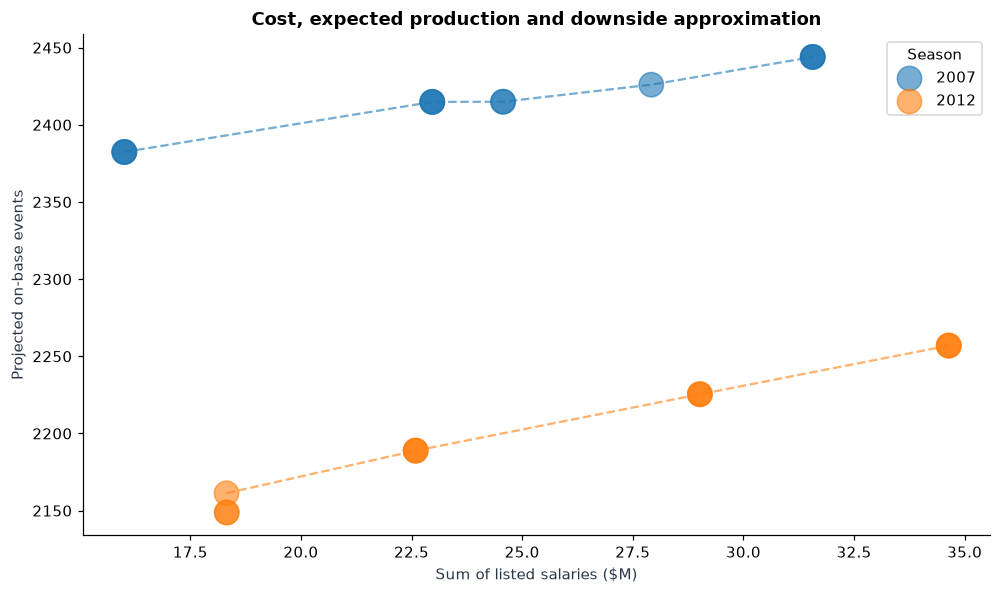

In [63]:
from scipy.optimize import milp,Bounds,LinearConstraint
from scipy.sparse import csc_matrix
pareto_rows=[];pareto_members=[]
for yr in (2007,2012):
    f=stage_all[(stage_all.target_year==yr)&stage_all.player_salary.gt(0)].copy()
    f=f[f.expected_onbase_proxy.notna()].reset_index(drop=True)
    if len(f)<20:continue
    # A fixed qualified candidate pool, not selected with knowledge of next year's realized output.
    f['value_proxy']=f.expected_onbase_proxy/np.power(f.player_salary/1e6,.25)
    f=pd.concat([f.nlargest(75,'value_proxy'),f.nsmallest(35,'player_salary')]).drop_duplicates('playerID').reset_index(drop=True)
    hist=event_predictions[(event_predictions.model=='Two-stage PA × OBP')&(event_predictions.target_year<yr)].copy()
    if len(hist)<300:continue
    e=hist.residual.to_numpy(float)
    typical_sd=max(float(np.std(e)),5)
    # Higher predicted inactivity adds a risk premium; strictly pre-season predictors.
    sigma=typical_sd*(.7+1.2*(1-f.prob_any.to_numpy(float)))
    costs=f.player_salary.to_numpy(float)
    exp=f.expected_onbase_proxy.to_numpy(float)
    budget_reference=float(annual_budgets.get(yr,10*np.median(costs)))
    cheapest=float(np.sort(costs)[:10].sum())
    for budget_mult in (.65,.85,1.00,1.20):
        cap=max(budget_reference*budget_mult,cheapest*1.03)
        for risk_aversion in (0,.5,1.0):
            reward=exp-risk_aversion*sigma
            sol=milp(c=-reward,integrality=np.ones(len(f)),bounds=Bounds(0,1),
                constraints=LinearConstraint(csc_matrix(np.vstack([np.ones(len(f)),costs/1e6])),
                  [10,0],[10,cap/1e6]),options={'time_limit':8,'mip_rel_gap':.01})
            if sol.x is None:continue
            ind=np.flatnonzero(sol.x>.5)
            if len(ind)!=10:continue
            # Consistent prospective uncertainty proxy, not observed future performance.
            spend=costs[ind].sum();mu=exp[ind].sum()
            sd=float(np.sqrt(np.sum(sigma[ind]**2)))
            downside=mu-1.28*sd
            pid=f.iloc[ind].playerID.tolist()
            pareto_rows.append({'year':yr,'salary_budget':cap,'risk_aversion':risk_aversion,'actual_salary_spend':spend,
               'predicted_events':mu,'downside_p10_normal_approx':downside,
               'risk_sd_independent_approx':sd,'realized_events_hindsight':f.iloc[ind].actual_onbase_proxy.sum()})
            pareto_members += [{'year':yr,'salary_budget':cap,'risk_aversion':risk_aversion,'playerID':p} for p in pid]
pareto48=pd.DataFrame(pareto_rows)
if pareto48.empty:raise ValueError('No feasible Pareto portfolios: review salary/year candidate coverage')
pareto48['non_dominated_in_sample']=False
for yy,ix in pareto48.groupby('year').groups.items():
    group=pareto48.loc[ix]
    # Every objective is computed under the same independent-normal *assumed* risk model.
    for row_i,r in group.iterrows():
        dominates=((group.actual_salary_spend<=r.actual_salary_spend+1e-6)&
           (group.predicted_events>=r.predicted_events-1e-6)&
           (group.downside_p10_normal_approx>=r.downside_p10_normal_approx-1e-6)&
           ((group.actual_salary_spend<r.actual_salary_spend-1e-6)|
             (group.predicted_events>r.predicted_events+1e-6)|
             (group.downside_p10_normal_approx>r.downside_p10_normal_approx+1e-6))).any()
        pareto48.loc[row_i,'non_dominated_in_sample']=not bool(dominates)
display(pareto48.groupby('year').agg(portfolios=('predicted_events','size'),nondominated=('non_dominated_in_sample','sum'),salary_min=('actual_salary_spend','min'),salary_max=('actual_salary_spend','max')).round(2))
save_frame(pareto48,'research_48_pareto_roster_frontier.csv')
save_frame(pd.DataFrame(pareto_members),'research_48_pareto_roster_members.csv')
fig,ax=plt.subplots(figsize=(9.2,5.5))
for yr,g in pareto48.groupby('year'):
  ax.scatter(g.actual_salary_spend/1e6,g.predicted_events,alpha=.6,label=str(yr),s=np.maximum(20,(g.predicted_events-g.downside_p10_normal_approx)*1.5))
  f=g[g.non_dominated_in_sample].sort_values('actual_salary_spend')
  ax.plot(f.actual_salary_spend/1e6,f.predicted_events,'--',alpha=.6)
ax.set(xlabel='Sum of listed salaries ($M)',ylabel='Projected on-base events',title='Cost, expected production and downside approximation')
ax.legend(title='Season');fig.tight_layout();fig.savefig(VISUALS/'research_48_pareto_frontier.png',bbox_inches='tight');plt.show()


## 49. Decision regret relative to an unattainable hindsight oracle

For every historical year, solve the **same candidate pool, same 10 roster slots and same recorded-salary ceiling**, but maximize the **realized** next-season above-league on-base metric. Because the oracle is given future outcomes it is **not a feasible scouting strategy** and is only an ex-post upper bound. Compare its outcome with the prospective model, previous-OBP baseline and cheapest-only baseline; quantify which test years have the largest losses. Regret does not estimate causal benefit or true team wins.


,strategy,n_years,mean_regret,median_regret,max_regret
0,Cheapest salary,11,432.34,440.09,481.14
1,Previous-season OBP,11,215.40,217.20,275.40
2,Prospective value score,11,257.99,260.57,363.89


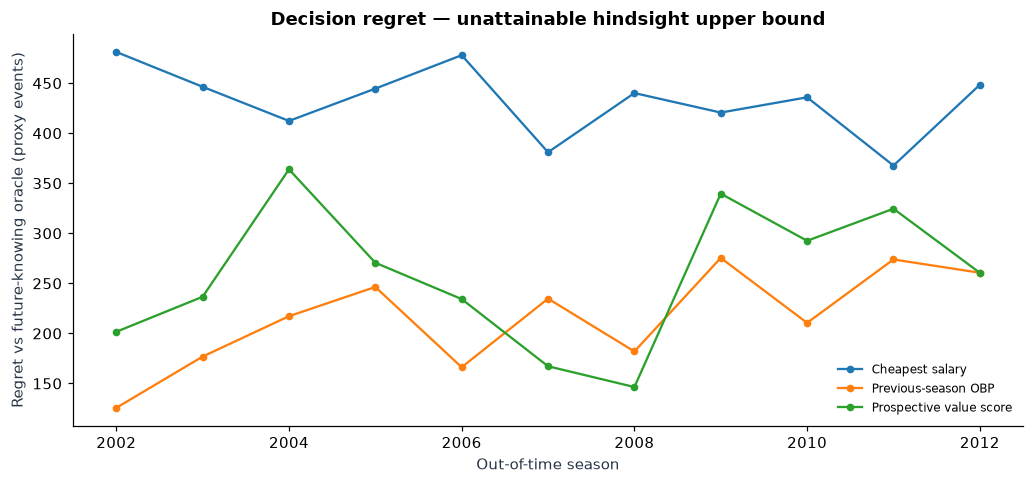

In [64]:
oracle_rows=[]
for yr in sorted(annual_budgets):
    f=scored_cache.get(yr)
    if f is None:continue
    budget=float(annual_budgets[yr])
    oracle=identical_cap_selection(f,f.onbase_above_league.to_numpy(float),budget,10)
    if oracle is None:continue
    hindsight=float(oracle.onbase_above_league.sum())
    for strategy in ['Prospective value score','Previous-season OBP','Cheapest salary']:
        result=fixed_by_year[(fixed_by_year.target_year==yr)&(fixed_by_year.method==strategy)]
        if len(result)!=1:continue
        prior=float(result.iloc[0].actual_onbase_excess)
        oracle_rows.append({'year':yr,'strategy':strategy,'salary_cap':budget,
            'hindsight_oracle_events_excess':hindsight,'strategy_realized_events_excess':prior,
            'regret_events_excess':max(0.,hindsight-prior),
            'strategy_spend':float(result.iloc[0].spent)})
regret49=pd.DataFrame(oracle_rows)
if regret49.empty:raise ValueError('No hindsight oracle comparisons created')
summary49=regret49.groupby('strategy',as_index=False).agg(n_years=('year','nunique'),mean_regret=('regret_events_excess','mean'),median_regret=('regret_events_excess','median'),max_regret=('regret_events_excess','max'))
display(summary49.round(2))
save_frame(regret49,'research_49_hindsight_oracle_decision_regret.csv')
save_frame(summary49,'research_49_regret_strategy_summary.csv')
fig,ax=plt.subplots(figsize=(9.5,4.5))
for method,g in regret49.groupby('strategy'):ax.plot(g.year,g.regret_events_excess,'o-',label=method,ms=4)
ax.set(xlabel='Out-of-time season',ylabel='Regret vs future-knowing oracle (proxy events)',title='Decision regret — unattainable hindsight upper bound')
ax.legend(frameon=False,fontsize=8);fig.tight_layout();fig.savefig(VISUALS/'research_49_decision_regret.png',bbox_inches='tight');plt.show()


## 50. Out-of-period OBP check with the newer batting archive

This OBP test retains historical training records through 2012 and uses **`Batting_2025.csv` plus `People_2025.csv`** to extend the feature and outcome history through 2025. The newer source omits two unused legacy columns (`G_old` and `G_batting`), so columns are aligned before combining historical and later records. That difference is a file-format detail, not evidence that the newer records are missing essential batting statistics.

This evaluates next-season OBP among hitters with at least 300 plate appearances in both seasons. Players who dropped below that threshold cannot contribute an OBP error, so these results describe a *survivor-conditioned* cohort. The fixed pre-2013 Ridge is compared with prior-year OBP. Section 81 handles measured bWAR separately, including a count of players with no observed next-season WAR.

**A shortened-season edge case:** The 300-PA rule produces no eligible 2020 outcomes, and the 2020 season supplies no 300-PA prior-season feature cohort for 2021. Those seasons are deliberately absent from this particular OBP table; Section 81 still evaluates its separately defined bWAR cohort in both years.


In [65]:
external_status={'section':50,'name':'2013–2025 external seasons with frozen historic Ridge','status':'SKIPPED','detail':'No post-2012 batting rows detected'}
external_path=DATA_DIR/'Batting_2025.csv'
if not external_path.is_file() and (DATA_DIR/'Batting_2013_2025.csv').is_file():
    external_path=DATA_DIR/'Batting_2013_2025.csv'
if not external_path.is_file() and (DATA_DIR/'Batting.csv').is_file():
    external_path=DATA_DIR/'Batting.csv'
if external_path.is_file():
    ext=pd.read_csv(external_path,low_memory=False)
    # Two auxiliary legacy fields (G_old, G_batting) are not used by player_seasons.
    required_batting=set(raw['batting'].columns)-{'G_old','G_batting'}
    if required_batting.issubset(ext.columns) and {'yearID','playerID'}.issubset(ext):
        ext=ext[ext.yearID.gt(2012)].copy()
        if len(ext):
            ext_raw=raw.copy()
            ext_raw['batting']=pd.concat([raw['batting'].loc[raw['batting'].yearID.le(2012)],ext.reindex(columns=raw['batting'].columns)],ignore_index=True)
            people_path=DATA_DIR/'People_2025.csv'
            if not people_path.is_file(): people_path=DATA_DIR/'People.csv'
            if people_path.is_file():
                people=pd.read_csv(people_path,low_memory=False,encoding='utf-8-sig')
                if {'playerID','nameFirst','nameLast','birthYear','bats'}.issubset(people.columns):
                    ext_raw['master']=pd.concat([raw['master'],people[['playerID','nameFirst','nameLast','birthYear','bats']]],ignore_index=True).drop_duplicates('playerID',keep='first')
            ext_ps=player_seasons(ext_raw)
            tr=decisions[decisions.target_year.le(2012)&decisions.next_regular.eq(1)&decisions.next_OBP.notna()].dropna(subset=FEATURES)
            trainmodel=Pipeline([('scale',StandardScaler()),('ridge',Ridge(alpha=20))]).fit(tr[FEATURES],tr.next_OBP)
            prev=ext_ps[ext_ps.yearID.between(2012,2024)&ext_ps.PA.ge(300)][['playerID','yearID']+FEATURES].copy()
            later=ext_ps[['playerID','yearID','PA','OBP']].copy();later['yearID']-=1
            later=later.rename(columns={'PA':'next_PA','OBP':'next_OBP'})
            future=prev.merge(later,on=['playerID','yearID'],how='left',validate='one_to_one')
            future['target_year']=future.yearID+1
            all_cohorts=future[future.target_year.ge(2013)].groupby('target_year',as_index=False).agg(previous_regular=('playerID','size'),next_regular=('next_PA',lambda s: int((s>=300).sum())))
            valid=future[future.target_year.ge(2013)&future.next_PA.ge(300)&future.next_OBP.notna()].dropna(subset=FEATURES).copy()
            if len(valid)>=30:
                valid['frozen_Ridge_OBP']=np.clip(trainmodel.predict(valid[FEATURES]),0,1)
                valid['prior_OBP']=valid.OBP
                met=valid.groupby('target_year').apply(lambda g:pd.Series({'n':len(g),
                       'ridge_MAE':mean_absolute_error(g.next_OBP,g.frozen_Ridge_OBP),
                       'prior_OBP_MAE':mean_absolute_error(g.next_OBP,g.prior_OBP)}),include_groups=False).reset_index()
                display(met.round(4));display(all_cohorts)
                save_frame(met,'research_50_external_frozen_ridge_metrics.csv')
                save_frame(valid[['playerID','target_year','next_OBP','frozen_Ridge_OBP','prior_OBP']],'research_50_external_holdout_predictions.csv')
                save_frame(all_cohorts,'research_50_external_source_cohorts.csv')
                external_status.update(status='EXECUTED_WITH_CAVEATS',detail=f'{len(valid)} survivor-conditioned player-season tests, fixed pre-2013 model; verify cross-release IDs')
            else:external_status['detail']=f'Only {len(valid)} eligible external player seasons; require >=30 and correct IDs'
        else: external_status['detail']='Input contains no yearID after 2012'
    else:external_status['detail']='New batting file lacks required batting columns: '+str(sorted(required_batting-set(ext.columns))[:12])
external_status_df=pd.DataFrame([external_status]);display(external_status_df);save_frame(external_status_df,'research_50_external_status.csv')


,target_year,n,ridge_MAE,prior_OBP_MAE
0,2013,200.0,0.0222,0.0244
1,2014,200.0,0.0231,0.0263
2,2015,195.0,0.0255,0.0286
3,2016,210.0,0.0235,0.0263
4,2017,209.0,0.0242,0.0266
5,2018,219.0,0.0220,0.0263
6,2019,187.0,0.0204,0.0240
7,2022,192.0,0.0274,0.0293
8,2023,202.0,0.0203,0.0229
9,2024,207.0,0.0247,0.0258


,target_year,previous_regular,next_regular
0,2013,265,200
1,2014,276,200
2,2015,263,195
3,2016,268,210
4,2017,268,209
5,2018,287,219
6,2019,278,187
7,2020,273,0
8,2022,262,192
9,2023,277,202


,section,name,status,detail
0,50,2013–2025 external seasons with frozen histori...,EXECUTED_WITH_CAVEATS,"2220 survivor-conditioned player-season tests,..."


WindowsPath('C:/Users/htpar/Downloads/outputs/processed/research_50_external_status.csv')

## 51. Does position help predict next year's salary?

The first version compared positions using stats from the same season as the salary. That is fine for describing the market, but not for forecasting what a player will make next year. The analysis uses the player's **previous-season** record, position and salary to predict the following salary year. The two models are evaluated on the same players and seasons. A tiny improvement is still tiny even when the chart makes it easier to see.


,model,years,mean_log_MAE
0,No position,11,0.42969
1,Primary position,11,0.42973


,paired_seasons,mean_MAE_improvement,bootstrap_low,bootstrap_high
0,11,-0.00005,-0.00145,0.00125


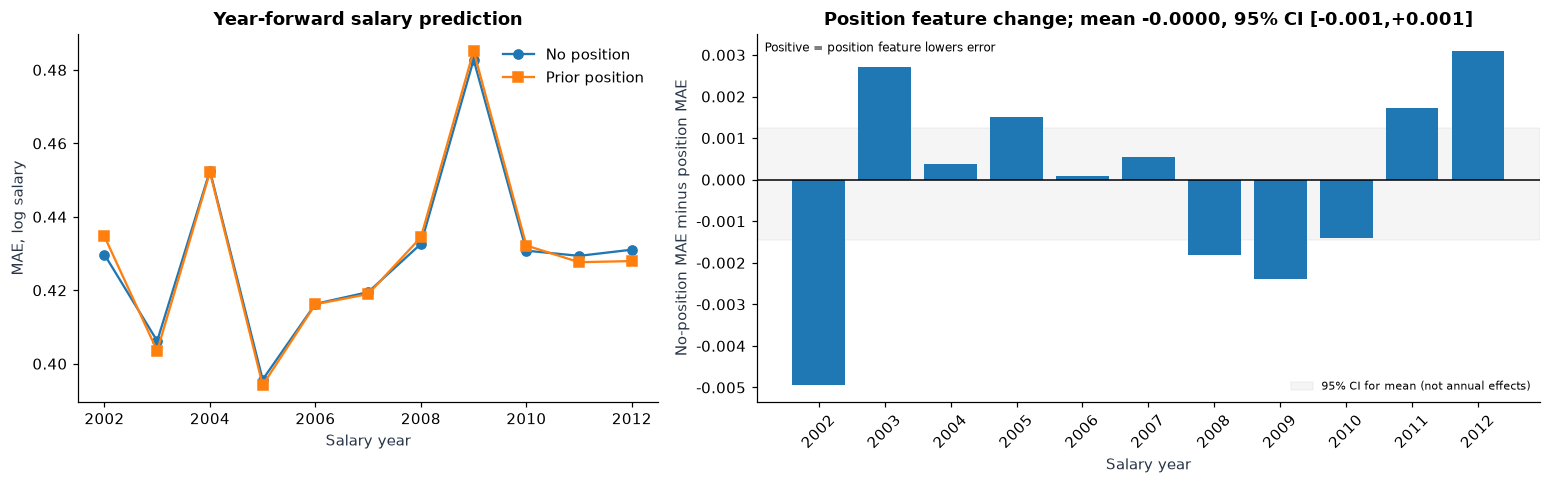

,section,name,status,detail
0,51,Prior-season position / next-year salary,EXECUTED,4366 paired player-years; 11 forward evaluatio...


WindowsPath('C:/Users/htpar/Downloads/outputs/processed/research_51_position_salary_status.csv')

In [66]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error

position51 = {'section':51, 'name':'Prior-season position / next-year salary',
              'status':'NOT_EVALUATED', 'detail':'Awaiting compatible Appearances.csv'}
pos_cv = pd.DataFrame()
pos_summary = pd.DataFrame()
position51_yearly = pd.DataFrame()
app_path = DATA_DIR / 'Appearances.csv'
if app_path.is_file():
    ap51 = pd.read_csv(app_path, low_memory=False, encoding='utf-8-sig')
    position_columns51 = {'C':'G_c', '1B':'G_1b', '2B':'G_2b', '3B':'G_3b',
                          'SS':'G_ss', 'OF':'G_of', 'DH':'G_dh'}
    required51 = {'playerID','yearID'} | set(position_columns51.values())
    if required51.issubset(ap51.columns):
        position_cols51 = list(position_columns51.values())
        for col in position_cols51:
            ap51[col] = pd.to_numeric(ap51[col],errors='coerce').fillna(0)
        # All team stints in season t; primary position is assigned only from prior-season evidence.
        agg51 = ap51.groupby(['playerID','yearID'],as_index=False)[position_cols51].sum()
        agg51['primary_position'] = agg51[position_cols51].idxmax(axis=1).map(
            {v:k for k,v in position_columns51.items()})
        agg51['position_games'] = agg51[position_cols51].max(axis=1)
        current51 = (p_all[['playerID','yearID','age','PA','OBP','SLG','BB_rate']]
            .merge(agg51[['playerID','yearID','primary_position','position_games']],
                   on=['playerID','yearID'],how='inner',validate='one_to_one')
            .merge(player_salary[['playerID','yearID','player_salary']],
                   on=['playerID','yearID'],how='left',validate='one_to_one'))
        current51 = current51.rename(columns={'player_salary':'prior_salary'})
        current51['target_year'] = current51.yearID + 1
        next_salary51 = player_salary[['playerID','yearID','player_salary']].rename(
            columns={'yearID':'target_year','player_salary':'next_salary'})
        cohort51 = current51.merge(next_salary51,on=['playerID','target_year'],
                                   how='left',validate='one_to_one')
        cohort51 = cohort51[cohort51.yearID.between(1994,2011)&cohort51.PA.ge(300)&
                              cohort51.position_games.gt(0)].copy()
        cohort51['salary_observed_next_year'] = cohort51.next_salary.gt(0)
        selection51 = cohort51.groupby('target_year',as_index=False).agg(
            prior_eligible=('playerID','size'), next_salary_observed=('salary_observed_next_year','sum'))
        selection51['salary_coverage_rate']=selection51.next_salary_observed/selection51.prior_eligible
        save_frame(selection51,'research_51_forward_salary_coverage.csv')
        cohort51 = cohort51[cohort51.prior_salary.gt(0)&cohort51.next_salary.gt(0)].dropna(
            subset=['age','PA','OBP','SLG','BB_rate','primary_position']).copy()
        cohort51['log_prior_salary'] = np.log(cohort51.prior_salary)
        cohort51['log_next_salary'] = np.log(cohort51.next_salary)
        numeric51 = ['age','PA','OBP','SLG','BB_rate','log_prior_salary','yearID']
        feat51 = numeric51+['primary_position']
        predictions51=[]
        for year in range(2002,2013):
            train51=cohort51[cohort51.target_year.lt(year)]
            test51=cohort51[cohort51.target_year.eq(year)]
            if len(train51)<150 or len(test51)<15:continue
            for tag,has_pos in [('No position',False),('Primary position',True)]:
                ct51=ColumnTransformer(
                    [('continuous',StandardScaler(),numeric51)] +
                    ([('position',OneHotEncoder(handle_unknown='ignore'),['primary_position'])] if has_pos else []))
                cols51=feat51 if has_pos else numeric51
                estimator51=Pipeline([('features',ct51),('model',Ridge(alpha=30.0))])
                estimator51.fit(train51[cols51],train51.log_next_salary)
                pred51=estimator51.predict(test51[cols51])
                for pid,truth,pred in zip(test51.playerID,test51.log_next_salary,pred51):
                    predictions51.append({'playerID':pid,'target_year':year,'model':tag,
                                          'actual_log_salary':truth,'predicted_log_salary':pred})
        if predictions51:
            out51=pd.DataFrame(predictions51)
            pos_cv=(out51.groupby(['target_year','model'],as_index=False)
                       .apply(lambda f:pd.Series({'n':len(f),'log_salary_MAE':mean_absolute_error(
                          f.actual_log_salary,f.predicted_log_salary)}),include_groups=False)
                       .reset_index(drop=True).rename(columns={'target_year':'year'}))
            pos_summary=pos_cv.groupby('model',as_index=False).agg(
                years=('year','nunique'),mean_log_MAE=('log_salary_MAE','mean'))
            comparison51=pos_cv.pivot(index='year',columns='model',values='log_salary_MAE').dropna()
            comparison51['position_improvement']=(comparison51['No position']-
                                                   comparison51['Primary position'])
            position51_yearly=comparison51.reset_index()
            annual51=comparison51.position_improvement.to_numpy(float)
            rng51=np.random.default_rng(20261019)
            bootstrap51=rng51.choice(annual51,size=(5000,len(annual51)),replace=True).mean(axis=1)
            ci51=np.quantile(bootstrap51,[.025,.975])
            display(pos_summary.round(5))
            display(pd.DataFrame([{'paired_seasons':len(annual51),
                'mean_MAE_improvement':annual51.mean(),
                'bootstrap_low':ci51[0], 'bootstrap_high':ci51[1]}]).round(5))
            save_frame(pos_cv,'research_51_position_salary_temporal_metrics.csv')
            save_frame(pos_summary,'research_51_position_salary_model_summary.csv')
            save_frame(position51_yearly,'research_51_position_yearly_improvement.csv')
            save_frame(out51,'research_51_forward_salary_predictions.csv')
            fig,axes=plt.subplots(1,2,figsize=(14.2,4.5),gridspec_kw={'width_ratios':[1,1.35]})
            axes[0].plot(comparison51.index,comparison51['No position'],'o-',label='No position')
            axes[0].plot(comparison51.index,comparison51['Primary position'],'s-',label='Prior position')
            axes[0].set(xlabel='Salary year',ylabel='MAE, log salary',title='Year-forward salary prediction')
            axes[0].legend(frameon=False)
            axes[1].bar(comparison51.index.astype(str),annual51)
            axes[1].axhline(0,color='black',linewidth=1)
            axes[1].set(xlabel='Salary year',ylabel='No-position MAE minus position MAE',
                title=f'Position feature change; mean {annual51.mean():+.4f}, 95% CI [{ci51[0]:+.3f},{ci51[1]:+.3f}]')
            axes[1].tick_params(axis='x',rotation=45)
            axes[1].axhspan(ci51[0],ci51[1],alpha=.08,color='gray',zorder=0,
                              label='95% CI for mean (not annual effects)')
            axes[1].legend(frameon=False,fontsize=7,loc='lower right')
            axes[1].text(.01,.98,'Positive = position feature lowers error',
                         transform=axes[1].transAxes,ha='left',va='top',fontsize=8)
            axes[1].yaxis.set_major_formatter(__import__('matplotlib').ticker.FormatStrFormatter('%.3f'))
            fig.tight_layout()
            fig.savefig(VISUALS/'research_51_position_salary_comparison.png',dpi=160,bbox_inches='tight')
            plt.show()
            position51.update(status='EXECUTED', detail=f'{len(cohort51)} paired player-years; '
                              f'{len(annual51)} forward evaluation seasons; observed-salary cohort only')
        else:
            position51.update(status='NOT_EVALUATED',detail='Not enough paired prior/next salary records')
    else:
        position51.update(status='NOT_EVALUATED',detail='Missing columns: '+
                          ', '.join(sorted(required51-set(ap51.columns))))
position51_df=pd.DataFrame([position51]);display(position51_df)
save_frame(position51_df,'research_51_position_salary_status.csv')


## Audit trail, scope and limitations

The sections requiring **Contracts.csv** and **MinorLeagueBatting.csv** were removed rather than supplying invented outputs. The position-aware and pitching/fielding modules run on local files when available. Section 44 only computes empirical run expectancy if play-level outs/bases/runs and valid half-inning boundaries are provable; plays.zip is inspected, never assumed to be preprocessed. External 2013+ validation only runs when matching data exists; a file date is not evidence of season coverage. The historical sample is repeatedly researched and independent validation needs truly untouched later data.


## 52. Real-data source audit and Baseball-Reference bWAR bridge

`WAR.csv` represents **Baseball-Reference bWAR** (not fWAR). Maintain one row per player-season before joining; retain both positive and negative WAR, and do not interpret a price/negative-WAR ratio as a meaningful cost per win.

**Dataset provenance:** Use `scripts/source_snapshot.py` to inventory the 12 local input files (size, modification time, and SHA-256). The large `plays.csv` is size/timestamp-only unless `--include-large` is requested. This is a local file inventory, **not** a trusted publisher digest or proof of data versions used by earlier archived notebook runs. Record official release, retrieval date, license and trusted reference hashes using `provenance/TRUSTED_SOURCE_MANIFEST_TEMPLATE.json`.

```bash
python scripts/source_snapshot.py --source-dir data/raw --out outputs/source_snapshot.local.json
# Add --include-large for a full, potentially slow, plays.csv hash
```

Do not publish raw data, local filesystem inventory or private directories. Historical Lahman snapshots and later 2025 updates must not be conflated; an available 2026 WAR row is not evidence that the 2026 season dataset is complete.


,file,exists,size_MB
0,Batting.csv,True,6.49
1,Batting.csv.zip,False,NaN
2,Master.csv,True,3.05
3,Master.csv.zip,False,NaN
4,Salaries.csv,True,0.70
5,Teams.csv,True,0.55
6,WAR.csv,True,6.79
7,Appearances.csv,True,7.83
8,Fielding.csv,True,8.77
9,Pitching.csv,True,5.11


WAR duplicate player-year rows: 0


,WAR_rows_1985_2012,WAR_salary_matched,matched_positive_WAR,salary_file_max_year,WAR_source
0,32077,21924,15072,2012,Baseball-Reference bWAR


,playerID,WAR,bat_WAR,pitch_WAR,player_salary,salary_per_positive_WAR
14050,zitoba01,7.11,-0.09,7.20,295000,41490.86
13784,oswalro01,6.88,-0.07,6.95,300000,43604.65
13572,hinsker01,3.96,3.96,NaN,200000,50505.05
13450,eckstda01,5.24,5.24,NaN,280000,53435.11
13925,spiveju01,3.94,3.94,NaN,215000,54568.53
13817,pineijo01,4.65,-0.03,4.68,255000,54838.71
13571,hillesh02,4.25,4.25,NaN,260000,61176.47
13356,buehrma01,5.02,-0.02,5.04,310000,61752.99
13771,ohkato01,3.76,-0.21,3.97,240000,63829.79
13316,bellhma01,3.37,3.37,NaN,224000,66468.84


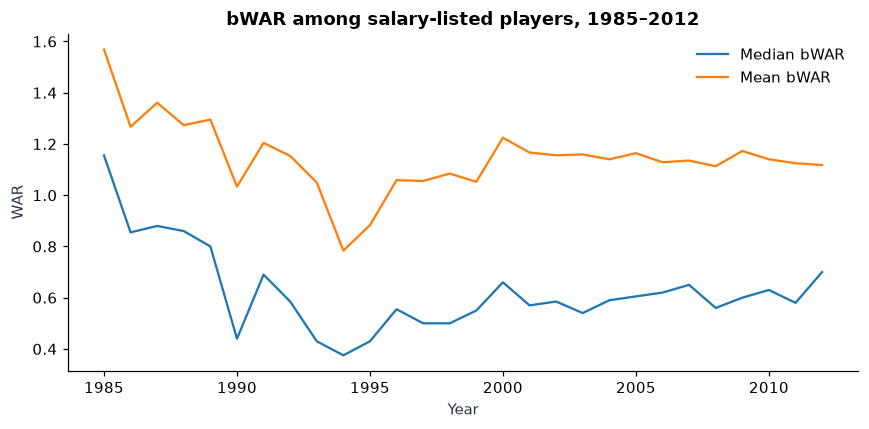

In [67]:
from pathlib import Path
sources52=[]
for fname in ['Batting.csv','Batting.csv.zip','Master.csv','Master.csv.zip','Salaries.csv','Teams.csv','WAR.csv','Appearances.csv','Fielding.csv','Pitching.csv','People.csv','plays.zip','plays.csv','PlayByPlay.csv']:
    fp=DATA_DIR/fname
    sources52.append({'file':fname,'exists':fp.is_file(),'size_MB':round(fp.stat().st_size/1e6,2) if fp.is_file() else np.nan})
source_inventory52=pd.DataFrame(sources52)
display(source_inventory52)
save_frame(source_inventory52,'final_source_inventory.csv')
war52=DATA_DIR/'WAR.csv'
war52_ready=False
if war52.is_file():
    w52=pd.read_csv(war52,low_memory=False)
    required52={'playerID','yearID','WAR'}
    if required52.issubset(w52.columns):
        for col in ['WAR','bat_WAR','pitch_WAR']:
            if col not in w52: w52[col]=np.nan
            w52[col]=pd.to_numeric(w52[col],errors='coerce')
        dup52=int(w52.duplicated(['playerID','yearID']).sum())
        print('WAR duplicate player-year rows:',dup52)
        if dup52==0:
            w52=w52[w52.yearID.between(1985,2012)].copy()
            bwar52=w52.merge(player_salary,on=['playerID','yearID'],how='inner',validate='one_to_one')
            bwar52=bwar52[bwar52.player_salary.gt(0)&bwar52.WAR.notna()].copy()
            bwar52['WAR_per_million']=bwar52.WAR/(bwar52.player_salary/1e6)
            bwar52['salary_per_positive_WAR']=bwar52.player_salary/bwar52.WAR.where(bwar52.WAR.gt(0))
            war52_ready=True
            coverage52=pd.DataFrame([{'WAR_rows_1985_2012':len(w52),'WAR_salary_matched':len(bwar52),'matched_positive_WAR':int((bwar52.WAR>0).sum()),'salary_file_max_year':int(raw['salaries'].yearID.max()),'WAR_source':','.join(w52.get('war_source',pd.Series(['Baseball-Reference bWAR'])).dropna().astype(str).unique()[:3])}])
            display(coverage52)
            save_frame(coverage52,'final_bwar_coverage.csv')
            save_frame(bwar52,'final_bwar_salary_player_seasons.csv')
            top52=bwar52[(bwar52.yearID==2002)&bwar52.WAR.gt(1)].nsmallest(12,'salary_per_positive_WAR')
            display(top52[['playerID','WAR','bat_WAR','pitch_WAR','player_salary','salary_per_positive_WAR']].round(2))
            fig,ax=plt.subplots(figsize=(8,4))
            annual52=bwar52.groupby('yearID').WAR.agg(['median','mean'])
            ax.plot(annual52.index,annual52['median'],label='Median bWAR');ax.plot(annual52.index,annual52['mean'],label='Mean bWAR')
            ax.set(title='bWAR among salary-listed players, 1985–2012',xlabel='Year',ylabel='WAR');ax.legend(frameon=False)
            fig.tight_layout();fig.savefig(VISUALS/'final_bwar_source_audit.png',bbox_inches='tight');plt.show()
        else: print('WAR source must be made unique by playerID/yearID before analysis. WAR modeling SKIPPED.')
    else: print('WAR missing columns:',sorted(required52-set(w52.columns)))
else: print('WAR.csv absent: optional bWAR deep-dives will skip.')

## 53. Next-season bWAR forecasting: past-only comparisons

For 2003–2012, forecast *t+1 bWAR* from season t batting and bWAR using a chronologically re-fitted Ridge model. Compare with the last-season-WAR baseline on **the same joined players**. This conditions on having an observed next-season WAR; it is not a roster-availability claim. Batting and pitching bWAR remain separately defined where available.


,mean,std,count
model,,,
Prior-year WAR,1.489,0.051,10
Ridge past-only,1.307,0.038,10


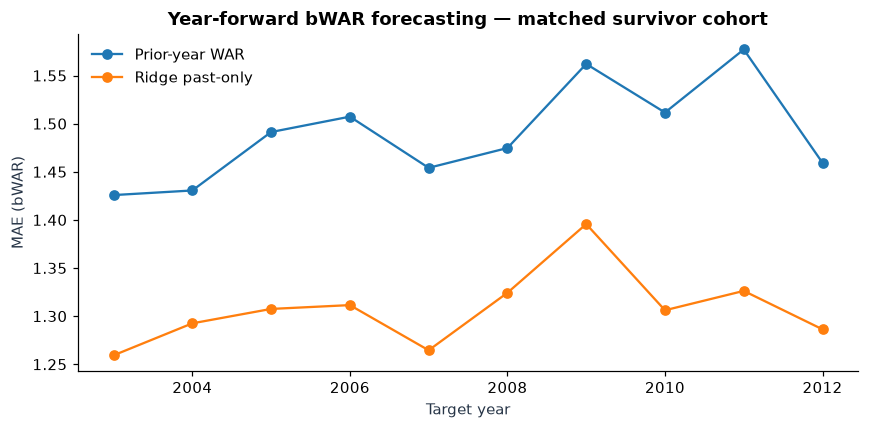

In [68]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
war_forecasts53=[]
if war52_ready:
    lag53=p_all[['playerID','yearID','PA','OBP','SLG','age']].merge(
        w52[['playerID','yearID','WAR','bat_WAR','pitch_WAR']],on=['playerID','yearID'],how='inner',validate='one_to_one')
    lag53=lag53[lag53.PA.ge(150)].copy()
    next53=w52[['playerID','yearID','WAR']].rename(columns={'WAR':'realized_next_WAR'}).copy()
    next53['yearID']-=1
    panel53=lag53.merge(next53,on=['playerID','yearID'],how='inner',validate='one_to_one')
    panel53['target_year']=panel53.yearID+1
    feature53=['WAR','OBP','SLG','age','PA']
    panel53=panel53.dropna(subset=feature53+['realized_next_WAR'])
    for y in range(2003,2013):
        a=panel53[panel53.target_year.lt(y)]
        b=panel53[panel53.target_year.eq(y)].copy()
        if len(a)<400 or len(b)<25:continue
        reg53=Pipeline([('scale',StandardScaler()),('ridge',Ridge(alpha=50.0))]).fit(a[feature53],a.realized_next_WAR)
        b['pred_Ridge_WAR']=reg53.predict(b[feature53]);b['pred_Prior_WAR']=b.WAR
        b['evaluation_year']=y
        war_forecasts53.append(b[['playerID','target_year','realized_next_WAR','pred_Ridge_WAR','pred_Prior_WAR','WAR','PA','age']])
if war_forecasts53:
    forecasts53=pd.concat(war_forecasts53,ignore_index=True)
    metrics53=[]
    for y,g in forecasts53.groupby('target_year'):
        for model,col in [('Ridge past-only','pred_Ridge_WAR'),('Prior-year WAR','pred_Prior_WAR')]:
            metrics53.append({'year':y,'model':model,'n':len(g),'MAE_WAR':mean_absolute_error(g.realized_next_WAR,g[col])})
    metrics53=pd.DataFrame(metrics53)
    display(metrics53.groupby('model').MAE_WAR.agg(['mean','std','count']).round(3))
    save_frame(metrics53,'final_next_war_walkforward_metrics.csv')
    save_frame(forecasts53,'final_next_war_walkforward_predictions.csv')
    fig,ax=plt.subplots(figsize=(8,4))
    for label,g in metrics53.groupby('model'):ax.plot(g.year,g.MAE_WAR,'o-',label=label)
    ax.set(title='Year-forward bWAR forecasting — matched survivor cohort',xlabel='Target year',ylabel='MAE (bWAR)');ax.legend(frameon=False)
    fig.tight_layout();fig.savefig(VISUALS/'final_war_forecast_walkforward.png',bbox_inches='tight');plt.show()
else:print('SKIPPED: WAR table unavailable or insufficient complete player history.')

## 54. Fielding and pitching contributions to run prevention

With local `Fielding.csv` and `Pitching.csv`, aggregate **player-team-year stints before merging** and compare measured defensive error rate and pitching components with team runs allowed per game. `FIP_component = (13×HR+3×BB−2×SO)/IP` **is not official FIP**; it deliberately omits league-year constants and HBP. A time-ordered prediction test compares pitching-only features against pitching + fielding; association is not causal and the risk of missing/duplicated team rows is audited.


,mean,std,count
model,,,
Pitching + fielding,0.216,0.039,10
Pitching components,0.225,0.035,10


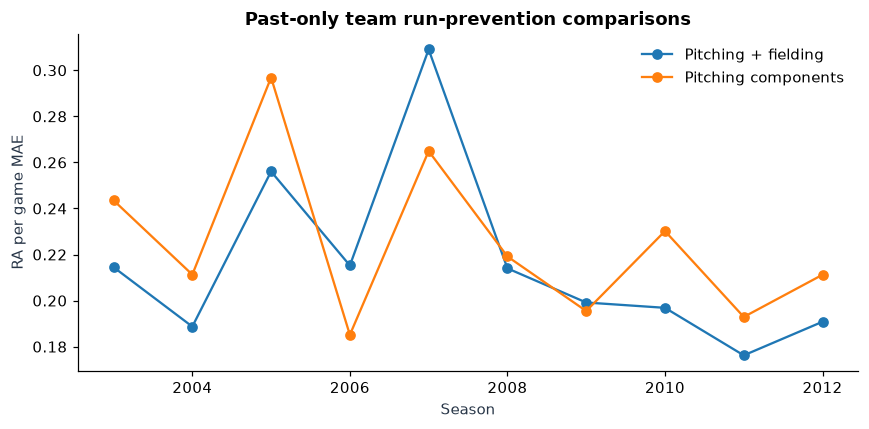

In [69]:
from sklearn.linear_model import Ridge
pitch54_path=DATA_DIR/'Pitching.csv'; field54_path=DATA_DIR/'Fielding.csv'
team_run_metrics54=[]; field54_ready=False
if pitch54_path.is_file() and field54_path.is_file():
    pit54=pd.read_csv(pitch54_path,low_memory=False)
    fld54=pd.read_csv(field54_path,low_memory=False)
    cols_p54={'yearID','teamID','IPouts','SO','BB','HR','ER'}
    cols_f54={'yearID','teamID','PO','A','E'}
    if cols_p54.issubset(pit54.columns) and cols_f54.issubset(fld54.columns):
        for c in cols_p54-{'yearID','teamID'}:pit54[c]=pd.to_numeric(pit54[c],errors='coerce').fillna(0)
        for c in cols_f54-{'yearID','teamID'}:fld54[c]=pd.to_numeric(fld54[c],errors='coerce').fillna(0)
        pitch_team54=pit54.groupby(['yearID','teamID'],as_index=False)[list(cols_p54-{'yearID','teamID'})].sum()
        field_team54=fld54.groupby(['yearID','teamID'],as_index=False)[['PO','A','E']].sum()
        defn54=raw['teams'][['yearID','teamID','RA','G','ERA','BPF']].copy()
        defn54=defn54.merge(pitch_team54,on=['yearID','teamID'],how='inner',validate='one_to_one')
        defn54=defn54.merge(field_team54,on=['yearID','teamID'],how='inner',validate='one_to_one',suffixes=('_pitch','_field'))
        defn54=defn54[defn54.yearID.between(1985,2012)&defn54.G.gt(0)&defn54.IPouts.gt(0)].copy()
        innings54=defn54.IPouts/3
        defn54['RA_per_game']=defn54.RA/defn54.G
        defn54['SO9']=9*defn54.SO/innings54
        defn54['BB9']=9*defn54.BB/innings54
        defn54['HR9']=9*defn54.HR/innings54
        defn54['FIP_component']=(13*defn54.HR+3*defn54.BB-2*defn54.SO)/innings54
        defn54['field_error_fraction']=defn54.E/(defn54.PO+defn54.A+defn54.E).replace(0,np.nan)
        defn54=defn54.replace([np.inf,-np.inf],np.nan).dropna(subset=['RA_per_game','SO9','BB9','HR9','field_error_fraction','BPF'])
        field54_ready=len(defn54)>=150
        assert not defn54.duplicated(['yearID','teamID']).any()
        save_frame(defn54,'final_team_pitch_field_run_prevention.csv')
        pitch_only54=['SO9','BB9','HR9','BPF']
        pitch_field54=pitch_only54+['field_error_fraction']
        for yr in range(2003,2013):
            a=defn54[defn54.yearID.lt(yr)];b=defn54[defn54.yearID.eq(yr)]
            if len(a)<150 or len(b)<15:continue
            for label,features in [('Pitching components',pitch_only54),('Pitching + fielding',pitch_field54)]:
                mod=Pipeline([('scale',StandardScaler()),('reg',Ridge(alpha=10))]).fit(a[features],a.RA_per_game)
                pred=mod.predict(b[features])
                team_run_metrics54.append({'year':yr,'model':label,'team_n':len(b),'RA_per_game_MAE':mean_absolute_error(b.RA_per_game,pred)})
        if team_run_metrics54:
            tm54=pd.DataFrame(team_run_metrics54)
            display(tm54.groupby('model').RA_per_game_MAE.agg(['mean','std','count']).round(3))
            save_frame(tm54,'final_team_fielding_pitching_model_comparison.csv')
            fig,ax=plt.subplots(figsize=(8,4))
            for label,g in tm54.groupby('model'):ax.plot(g.year,g.RA_per_game_MAE,'o-',label=label)
            ax.set(title='Past-only team run-prevention comparisons',xlabel='Season',ylabel='RA per game MAE');ax.legend(frameon=False)
            fig.tight_layout();fig.savefig(VISUALS/'final_pitching_fielding_run_prevention.png',bbox_inches='tight');plt.show()
    else:
        print('SKIPPED: required columns missing:',{'pitch_missing':sorted(cols_p54-set(pit54.columns)),'field_missing':sorted(cols_f54-set(fld54.columns))})
else:print('SKIPPED LOCALLY: Pitching.csv / Fielding.csv not present in execution folder.')

## 55. Pitcher value: 2002 salary vs actual bWAR (and a component audit)

Compare actual pitcher bWAR with recorded salary (descriptive hindsight) and analyze season-t pitching totals for predicting *t+1* pitching bWAR. Pitcher rows must be distinguished from the small batting records of pitchers; **use `pitch_WAR`**, not full total WAR, for pitcher-only analysis. Counting fields are aggregated across stints; no future-season statistics are predictor inputs.


In [70]:
pitch_value55=[]
pitch55_executed=False
if war52_ready and pitch54_path.is_file():
    pt55=pd.read_csv(pitch54_path,low_memory=False)
    basic55={'playerID','yearID','IPouts','SO','BB','HR','ER'}
    if basic55.issubset(pt55.columns):
        count55=['IPouts','SO','BB','HR','ER']
        for c in count55:pt55[c]=pd.to_numeric(pt55[c],errors='coerce').fillna(0)
        pyear55=pt55.groupby(['playerID','yearID'],as_index=False)[count55].sum()
        pyear55=pyear55[pyear55.IPouts.ge(150)].copy()
        pyear55['innings']=pyear55.IPouts/3
        pyear55['SO9']=pyear55.SO*9/pyear55.innings
        pyear55['BB9']=pyear55.BB*9/pyear55.innings
        pyear55['HR9']=pyear55.HR*9/pyear55.innings
        pyear55=pyear55.merge(w52[['playerID','yearID','pitch_WAR']],on=['playerID','yearID'],how='inner',validate='one_to_one')
        pyear55=pyear55.dropna(subset=['pitch_WAR'])
        pitcher_salary55=pyear55.merge(player_salary,on=['playerID','yearID'],how='inner',validate='one_to_one')
        pitcher_salary55=pitcher_salary55[pitcher_salary55.player_salary.gt(0)].copy()
        pitcher_salary55['pitch_WAR_per_million']=pitcher_salary55.pitch_WAR/(pitcher_salary55.player_salary/1e6)
        display(pitcher_salary55.query('yearID == 2002 and pitch_WAR > 1').nlargest(12,'pitch_WAR_per_million')[['playerID','pitch_WAR','player_salary','pitch_WAR_per_million']].round(2))
        save_frame(pitcher_salary55,'final_pitcher_bwar_salary_and_components.csv')
        pitch55_executed=True
        future55=pyear55[['playerID','yearID','pitch_WAR']].rename(columns={'pitch_WAR':'next_pitch_WAR'}).copy();future55.yearID-=1
        panel55=pyear55.merge(future55,on=['playerID','yearID'],how='inner',validate='one_to_one')
        features55=['pitch_WAR','SO9','BB9','HR9','innings']
        panel55=panel55.dropna(subset=features55+['next_pitch_WAR'])
        preds55=[]
        for yr in range(2003,2013):
            tr=panel55[panel55.yearID.lt(yr-1)];te=panel55[panel55.yearID.eq(yr-1)]
            if len(tr)<250 or len(te)<15:continue
            m=Pipeline([('std',StandardScaler()),('ridge',Ridge(alpha=30))]).fit(tr[features55],tr.next_pitch_WAR)
            for label,pred in [('Ridge pitcher','model'),('Prior pitch WAR','baseline')]:
                pred_vals=m.predict(te[features55]) if label=='Ridge pitcher' else te.pitch_WAR.to_numpy()
                preds55.append({'year':yr,'model':label,'players':len(te),'MAE_pitch_WAR':mean_absolute_error(te.next_pitch_WAR,pred_vals)})
        if preds55:
            pitch_cv55=pd.DataFrame(preds55);display(pitch_cv55.groupby('model').MAE_pitch_WAR.agg(['mean','count']).round(3))
            save_frame(pitch_cv55,'final_pitcher_war_forecast_comparison.csv')
else:print('SKIPPED LOCALLY: WAR.csv or Pitching.csv unavailable / incompatible.')

,playerID,pitch_WAR,player_salary,pitch_WAR_per_million
7193,zitoba01,7.20,295000,24.41
4682,oswalro01,6.95,300000,23.17
4970,pineijo01,4.68,255000,18.35
4571,ohkato01,3.97,240000,16.54
803,buehrma01,5.04,310000,16.26
3392,lawrebr02,3.28,235000,13.96
4126,millewa04,4.81,350000,13.74
6707,washbja01,4.54,350000,12.97
4700,padilvi01,2.98,245000,12.16
3619,lohseky01,2.34,215000,10.88


,mean,count
model,,
Prior pitch WAR,1.551,10
Ridge pitcher,1.291,10


## 56. Position- and pitcher-role constrained roster (2002)

Build an **illustrative** 2002 11-player team: C, 1B, 2B, 3B, SS, LF, CF, RF, SP×2 and RP×1. Position eligibility comes from **2001** `Appearances.csv`; starter/reliever workload from **2001** `Pitching.csv`; ranking uses **2001** bWAR; only the available snapshot of **2002 listed salary** is used for an illustrative payroll ceiling. Solve both minimum feasible-cost and max previous-WAR rosters via MILP. Validate 2002 realized WAR separately; these are NOT historically attainable free agents or a complete 26-man roster. If a source is missing or role coverage is insufficient, report SKIPPED rather than inferring eligibility.


In [71]:
from scipy.optimize import milp, Bounds, LinearConstraint
from scipy.sparse import csc_matrix
roster56_status={'section':56,'status':'SKIPPED','detail':'Appearances, Pitching, WAR and salaries required'}
if war52_ready and (DATA_DIR/'Appearances.csv').is_file() and (DATA_DIR/'Pitching.csv').is_file():
    ap56=pd.read_csv(DATA_DIR/'Appearances.csv',low_memory=False)
    pi56=pd.read_csv(DATA_DIR/'Pitching.csv',low_memory=False)
    roles56={'C':'G_c','1B':'G_1b','2B':'G_2b','3B':'G_3b','SS':'G_ss','LF':'G_lf','CF':'G_cf','RF':'G_rf'}
    needs56={'playerID','yearID'}|set(roles56.values())
    if needs56.issubset(ap56.columns) and {'playerID','yearID','G','GS'}.issubset(pi56.columns):
        ap56=ap56[ap56.yearID.eq(2001)].copy()
        for c in roles56.values():ap56[c]=pd.to_numeric(ap56[c],errors='coerce').fillna(0)
        ap56=ap56.groupby('playerID',as_index=False)[list(roles56.values())].sum()
        pi56=pi56[pi56.yearID.eq(2001)].copy()
        for c in ['G','GS']:pi56[c]=pd.to_numeric(pi56[c],errors='coerce').fillna(0)
        pi56=pi56.groupby('playerID',as_index=False)[['G','GS']].sum()
        prev56=w52[w52.yearID.eq(2001)][['playerID','WAR']].rename(columns={'WAR':'previous_bWAR'})
        act56=w52[w52.yearID.eq(2002)][['playerID','WAR']].rename(columns={'WAR':'realized_2002_bWAR'})
        cand56=player_salary[player_salary.yearID.eq(2002)][['playerID','player_salary']].merge(prev56,on='playerID',how='inner',validate='one_to_one').merge(ap56,on='playerID',how='left',validate='one_to_one').merge(pi56,on='playerID',how='left',validate='one_to_one')
        cand56=cand56[cand56.player_salary.gt(0)&cand56.previous_bWAR.notna()].reset_index(drop=True)
        cand56[list(roles56.values())+['G','GS']]=cand56[list(roles56.values())+['G','GS']].fillna(0)
        all_roles56=list(roles56)+['SP1','SP2','RP1']
        eligible56=[]
        for j,row in cand56.iterrows():
            for role,col in roles56.items():
                if row[col]>=10:eligible56.append((j,role))
            if row.GS>=12:eligible56.extend([(j,'SP1'),(j,'SP2')])
            if row.G>=18 and row.GS<=7:eligible56.append((j,'RP1'))
        n56=len(eligible56)
        if n56>0 and all(role in {r for _,r in eligible56} for role in all_roles56):
            mat56=np.zeros((len(all_roles56)+len(cand56)+1,n56));score56=np.zeros(n56)
            for j,(idx,role) in enumerate(eligible56):
                mat56[all_roles56.index(role),j]=1
                mat56[len(all_roles56)+idx,j]=1
                mat56[-1,j]=cand56.iloc[idx].player_salary/1e6
                score56[j]=cand56.iloc[idx].previous_bWAR
            lo56=np.r_[np.ones(len(all_roles56)),np.zeros(len(cand56)),0.]
            hi56=np.r_[np.ones(len(all_roles56)),np.ones(len(cand56)),np.inf]
            minimum56=milp(c=mat56[-1],integrality=np.ones(n56),bounds=Bounds(0,1),constraints=LinearConstraint(csc_matrix(mat56),lo56,hi56),options={'time_limit':20})
            if minimum56.x is not None:
                min_cost56=float(mat56[-1] @ (minimum56.x>.5))
                cap56=1.25*min_cost56
                hi56[-1]=cap56
                maximum56=milp(c=-score56,integrality=np.ones(n56),bounds=Bounds(0,1),constraints=LinearConstraint(csc_matrix(mat56),lo56,hi56),options={'time_limit':20,'mip_rel_gap':0.01})
                if maximum56.x is not None:
                    selected56=[{'playerID':cand56.iloc[eligible56[j][0]].playerID,'role':eligible56[j][1],
                        'salary_2002':cand56.iloc[eligible56[j][0]].player_salary,'previous_bWAR_2001':score56[j]}
                        for j in np.flatnonzero(maximum56.x>.5)]
                    select56=pd.DataFrame(selected56).merge(act56,on='playerID',how='left',validate='one_to_one')
                    assert len(select56)==len(all_roles56) and select56.playerID.nunique()==len(all_roles56)
                    roster56_status.update(status='EXECUTED_WITH_CAVEATS',detail=f'{len(all_roles56)} roles; cap ${cap56:,.2f}M based on observed 2002 salaries; no acquisition availability data')
                    print(roster56_status);display(select56.round(2))
                    save_frame(select56,'final_2002_role_constrained_roster.csv')
                    save_frame(pd.DataFrame([{'minimum_feasible_payroll_M':min_cost56,'illustrative_cap_M':cap56,'projected_prior_year_bWAR':select56.previous_bWAR_2001.sum(),'actual_selected_2002_bWAR_observed_sum':select56.realized_2002_bWAR.sum(),'matched_realized':select56.realized_2002_bWAR.notna().sum()}]),'final_2002_roster_optimization_summary.csv')
                else:roster56_status['detail']='No feasible max-WAR assignment under illustrative budget'
            else:roster56_status['detail']='Even unrestricted minimum-cost roles infeasible'
        else:roster56_status['detail']='Not enough position/SP/RP eligible players in source data'
    else:roster56_status['detail']='Missing Appearances or Pitching role columns'
display(pd.DataFrame([roster56_status]));save_frame(pd.DataFrame([roster56_status]),'final_roster56_status.csv')

{'section': 56, 'status': 'EXECUTED_WITH_CAVEATS', 'detail': '11 roles; cap $2.84M based on observed 2002 salaries; no acquisition availability data'}


,playerID,role,salary_2002,previous_bWAR_2001,realized_2002_bWAR
0,buehrma01,SP2,310000,6.01,5.02
1,dunnad01,LF,250000,2.15,2.37
2,eckstda01,SS,280000,4.23,5.24
3,hallto02,C,210000,0.99,0.59
4,lopezfe01,3B,221000,0.57,-0.06
5,menecfr01,2B,295000,3.31,-0.01
6,mientdo01,1B,285000,2.77,1.44
7,oswalro01,SP1,300000,4.82,6.88
8,riskeda01,RP1,227500,1.18,-0.11
9,rowanaa01,CF,225000,1.36,1.15


,section,status,detail
0,56,EXECUTED_WITH_CAVEATS,11 roles; cap $2.84M based on observed 2002 sa...


WindowsPath('C:/Users/htpar/Downloads/outputs/processed/final_roster56_status.csv')

## 57. Equal salary-cap next-year bWAR backtest — distinct from total offensive events

For 2003–2012, construct a candidate pool using **season-t** batting and WAR; compare three prospective rankings on the *same* people, player count and *same maximum* recorded next-season salary: previous bWAR, previous OBP, and a past-only Ridge prediction. The next-season recorded salary is a retrospective cost proxy **not a pre-season negotiated offer**. Missing next-year bWAR is conservatively treated as **0 observed MLB WAR** for the descriptive performance score (flagged); this can reflect missing sources or IDs and needs sensitivity analysis. This backtest is still not independent of earlier repeated research.


,method,years,mean_WAR,avg_spent_million,avg_missing
0,Previous OBP,10,17.42,11.26,0.0
1,Previous WAR,10,28.61,11.66,0.1
2,Ridge WAR,10,32.09,11.35,0.0


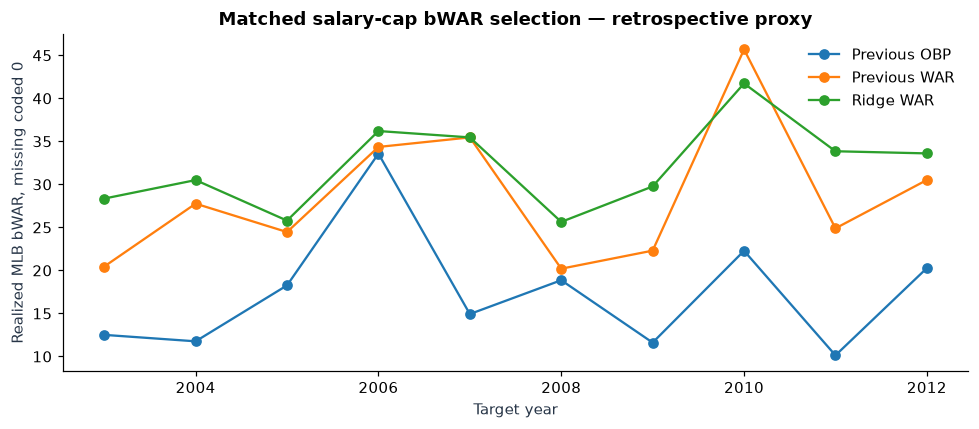

,paired_years,ridge_minus_previous_mean_WAR,bootstrap_95_low,bootstrap_95_high
0,10,3.482,1.119,5.775


In [72]:
from scipy.optimize import milp,Bounds,LinearConstraint
from scipy.sparse import csc_matrix
roster57=[];members57=[]
def fixed_n_cap57(frame,score_col,cap,n=8):
    vals=frame[score_col].to_numpy(float)
    costs=frame.player_salary.to_numpy(float)/1e6
    cstr=np.vstack([np.ones(len(frame)),costs])
    sol=milp(c=-vals,integrality=np.ones(len(frame)),bounds=Bounds(0,1),
      constraints=LinearConstraint(csc_matrix(cstr),[n,0],[n,cap]),options={'time_limit':10.0,'mip_rel_gap':0.01})
    return frame.iloc[np.flatnonzero(sol.x>.5)] if sol.x is not None else None
if war52_ready:
    old57=p_all[['playerID','yearID','PA','OBP','SLG','age']].merge(w52[['playerID','yearID','WAR']],on=['playerID','yearID'],how='inner',validate='one_to_one')
    old57=old57[old57.PA.ge(200)].copy()
    fut57=w52[['playerID','yearID','WAR']].rename(columns={'WAR':'realized_WAR'}).copy();fut57.yearID-=1
    old57=old57.merge(fut57,on=['playerID','yearID'],how='left',validate='one_to_one')
    old57['target_year']=old57.yearID+1
    old57=old57.merge(player_salary[['playerID','yearID','player_salary']].rename(columns={'yearID':'target_year'}),on=['playerID','target_year'],how='left',validate='many_to_one')
    feature57=['WAR','PA','OBP','SLG','age']
    for yr in range(2003,2013):
        train57=old57[(old57.target_year.lt(yr))&old57.realized_WAR.notna()].dropna(subset=feature57)
        test57=old57[(old57.target_year.eq(yr))&old57.player_salary.gt(0)].dropna(subset=feature57).copy()
        if len(train57)<400 or len(test57)<35:continue
        model57=Pipeline([('std',StandardScaler()),('ridge',Ridge(alpha=50))]).fit(train57[feature57],train57.realized_WAR)
        test57['Ridge_WAR']=model57.predict(test57[feature57])
        test57['Prior_WAR']=test57.WAR
        test57['Prior_OBP']=test57.OBP
        # A fixed 8-player count and SAME annual cap for all selectors.
        cap57=max(float(test57.nsmallest(8,'player_salary').player_salary.sum()/1e6*1.4),12.0)
        test57['realized_missing_flag']=test57.realized_WAR.isna().astype(int)
        test57['evaluation_WAR']=test57.realized_WAR.fillna(0)
        for label,col in [('Ridge WAR','Ridge_WAR'),('Previous WAR','Prior_WAR'),('Previous OBP','Prior_OBP')]:
            chosen=fixed_n_cap57(test57,col,cap57,8)
            if chosen is None:continue
            roster57.append({'year':yr,'method':label,'n':len(chosen),'cap_million':cap57,'spent_million':chosen.player_salary.sum()/1e6,
                'actual_WAR_sum':chosen.evaluation_WAR.sum(),'unobserved_next_WAR':int(chosen.realized_missing_flag.sum())})
            members57.extend([{'year':yr,'method':label,'playerID':r.playerID,'prior_WAR':r.WAR,'realized_WAR':r.evaluation_WAR,'salary':r.player_salary} for r in chosen.itertuples()])
if roster57:
    res57=pd.DataFrame(roster57);mem57=pd.DataFrame(members57)
    summary57=res57.groupby('method',as_index=False).agg(years=('year','nunique'),mean_WAR=('actual_WAR_sum','mean'),avg_spent_million=('spent_million','mean'),avg_missing=('unobserved_next_WAR','mean'))
    display(summary57.round(2))
    save_frame(res57,'final_war_recommendation_equal_cap_annual.csv')
    save_frame(mem57,'final_war_recommendation_equal_cap_members.csv')
    save_frame(summary57,'final_war_recommendation_equal_cap_summary.csv')
    fig,ax=plt.subplots(figsize=(9,4))
    for label,g in res57.groupby('method'):ax.plot(g.year,g.actual_WAR_sum,'o-',label=label)
    ax.set(title='Matched salary-cap bWAR selection — retrospective proxy',xlabel='Target year',ylabel='Realized MLB bWAR, missing coded 0')
    ax.legend(frameon=False);fig.tight_layout();fig.savefig(VISUALS/'final_war_value_strategy_backtest.png',bbox_inches='tight');plt.show()
    if {'Ridge WAR','Previous WAR'}.issubset(set(res57.method)):
        pair57=res57.pivot(index='year',columns='method',values='actual_WAR_sum').dropna(subset=['Ridge WAR','Previous WAR'])
        differences57=(pair57['Ridge WAR']-pair57['Previous WAR']).to_numpy(float)
        if len(differences57)>=3:
            rng57=np.random.default_rng(20261019)
            draws57=rng57.choice(differences57,size=(4000,len(differences57)),replace=True).mean(axis=1)
            display(pd.DataFrame([{'paired_years':len(differences57),'ridge_minus_previous_mean_WAR':differences57.mean(),'bootstrap_95_low':np.quantile(draws57,.025),'bootstrap_95_high':np.quantile(draws57,.975)}]).round(3))
else:print('SKIPPED: Historical bWAR projection pool unavailable.')

# Part 06 · Play-by-play and first roster-decision backtests

*Technical execution sequence is unchanged. See `01_Moneyball_Main_Research.ipynb` for a topical, reduced presentation.*


## 58. Regular-season Retrosheet run expectancy, 2000–2012

The analysis uses the regular-season games from 2000–2012 so the play-by-play results have the same basic scope as the seasonal batting data. The previous run-expectancy table also included postseason games. This version excludes those events before constructing the 24-state table, rather than interpreting a mixed sample as a regular-season result.

To make the calculation reproducible, the results report the full input row count, the selected years, which game types were excluded, and the number of complete half-innings included. Each half-inning must start with zero outs and empty bases and end with three outs. This drops walk-offs and incomplete sequences; the expectation estimates are therefore conditional on that selection.

Data source: [Retrosheet play-by-play documentation](https://www.retrosheet.org/downloads/plays.html). Retrosheet provides the underlying event data; all derived estimates and interpretations are specific to this retrospective analysis.


base_state_before,0,1,2,3,4,5,6,7
outs_before,,,,,,,,
0,0.517,0.900,1.145,1.505,1.433,1.815,2.025,2.344
1,0.276,0.538,0.696,0.925,0.965,1.186,1.414,1.573
2,0.107,0.234,0.332,0.449,0.369,0.508,0.593,0.781


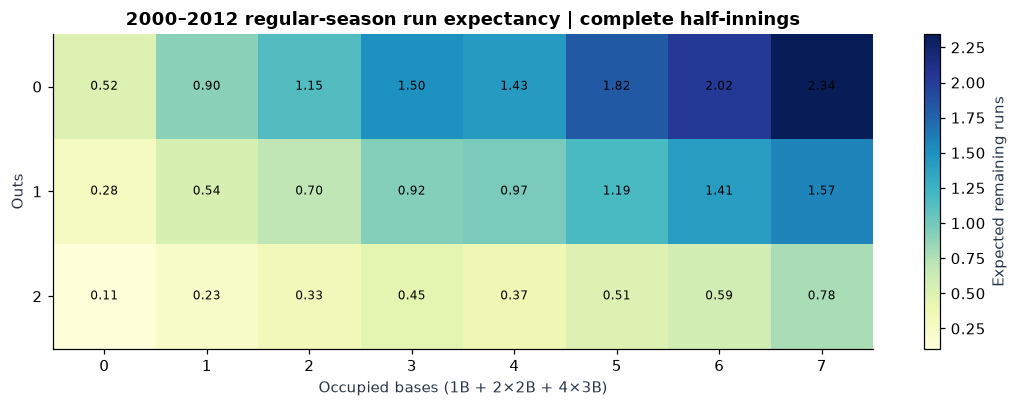

,section,status,detail,year_start,year_end,read_plays_all_years,retained_plays_requested_years,all_types_in_selected_years,excluded_outside_period,excluded_nonregular_plays,excluded_year_mismatches,unknown_year_plays,unique_games,used_state_observations,completed_halves,excluded_incomplete_halves,years_included,gametype_breakdown_before_regular_filter
0,58,EXECUTED,"retrosheet: 2,550,439/16,756,076 regular-seaso...",2000,2012,16756076,2550439,2586391,14169685,35952,16,0,31577,2537631,562072,2843,"2000,2001,2002,2003,2004,2005,2006,2007,2008,2...","{'regular': 2550439, 'divisionseries': 16768, ..."


WindowsPath('C:/Users/htpar/Downloads/outputs/processed/final_plays_processing_status.csv')

In [73]:
# Reproducible Retrosheet 2000–2012 extraction, with explicit year and coverage audit.
from collections import Counter

PLAY_PATH58 = DATA_DIR / 'plays.csv'
if not PLAY_PATH58.is_file():
    PLAY_PATH58 = DATA_DIR / 'PlayByPlay.csv'
play_status58 = {'section':58,'status':'NOT_EVALUATED','detail':'plays.csv / PlayByPlay.csv not found'}
play_state58 = None

def _is_occupied58(series):
    s = series.astype('string').str.strip()
    return s.notna() & ~s.str.upper().isin(['','NULL','NAN','NONE','0','<NA>'])

def _retrosheet_year_mask58(chunk, years=range(2000,2013)):
    # Retrosheet IDs are HOM + YYYYMMDD + game number. A suspended game can
    # resume on another date; year from the game identifier is authoritative.
    if 'gid' in chunk.columns:
        g=chunk['gid'].astype('string').str.strip()
        game_year=pd.to_numeric(g.str.extract(r'^[A-Za-z0-9]{3}((?:18|19|20)\d{2})\d{4,5}$',expand=False),errors='coerce')
    else:
        game_year=pd.Series(np.nan,index=chunk.index)
    if 'date' in chunk.columns:
        d=chunk['date'].astype('string').str.strip()
        date_year=pd.to_numeric(d.str.extract(r'^((?:18|19|20)\d{2})',expand=False),errors='coerce')
    else:
        date_year=pd.Series(np.nan,index=chunk.index)
    both=game_year.notna() & date_year.notna()
    mismatched=both & game_year.ne(date_year)
    year=game_year.fillna(date_year)
    keep=year.isin(list(years)) & ~mismatched
    return keep,year,mismatched

def _calc_expectancy58(path,years=range(2000,2013),chunksize=175_000):
    header=pd.read_csv(path,nrows=0,encoding_errors='replace').columns.tolist()
    retro={'gid','inning','top_bot','pn','outs_pre','outs_post','br1_pre','br2_pre','br3_pre','runs'}
    standard={'game_id','inning','half','play_index','outs_before','base_state_before','runs_scored'}
    if retro.issubset(header):
        schema='retrosheet'
        needed=retro | ({'date','gametype'} & set(header))
    elif standard.issubset(header):
        return None,{'status':'NOT_EVALUATED','detail':'Standardized file lacks outs_post, which is required to certify a completed half-inning.'}
    else:
        return None,{'status':'NOT_EVALUATED','detail':'Play schema missing required columns: '+', '.join(sorted(retro-set(header)))}
    if 'gametype' not in header:
        return None,{'status':'NOT_EVALUATED','detail':'Game type (gametype) is required to isolate regular-season plays.'}
    count=np.zeros((3,8),dtype=np.int64)
    total=np.zeros((3,8),dtype=np.float64)
    read_n=0; retained_n=0; in_year_n=0; excluded_nonregular_n=0; mismatch_n=0; unknown_year_n=0; used_n=0; halves_n=0; excluded_n=0
    seen_years=Counter();type_counts=Counter();games=set();carry=pd.DataFrame()
    def add_halves(piece):
        nonlocal used_n, halves_n, excluded_n
        if piece.empty:return
        for _,g in piece.groupby(['gid','inning','top_bot'],sort=False):
            g=g.sort_values('pn',kind='stable')
            if (g.empty or g.outs_pre.iloc[0] != 0 or g.base_state.iloc[0] != 0
                    or g.outs_post.iloc[-1] < 3):
                excluded_n+=1;continue
            future=g.runs.iloc[::-1].cumsum().iloc[::-1].to_numpy(dtype=float)
            outs=g.outs_pre.to_numpy(dtype=float);base=g.base_state.to_numpy(dtype=float)
            mask=np.isfinite(outs)&np.isfinite(base)&np.isfinite(future)&(outs>=0)&(outs<3)&(base>=0)&(base<8)
            o=outs[mask].astype(int);b=base[mask].astype(int)
            np.add.at(count,(o,b),1);np.add.at(total,(o,b),future[mask])
            used_n+=int(mask.sum());halves_n+=1
    for chunk in pd.read_csv(path,usecols=lambda c:c in needed,chunksize=chunksize,
                             low_memory=False,encoding_errors='replace'):
        read_n+=len(chunk)
        keep,years_this,mismatch=_retrosheet_year_mask58(chunk,years)
        mismatch_n+=int(mismatch.sum());unknown_year_n+=int(years_this.isna().sum())
        in_year_n+=int(keep.sum())
        types_in_year=chunk.loc[keep,'gametype'].astype('string').str.strip().str.lower()
        type_counts.update(types_in_year.fillna('missing').value_counts().to_dict())
        regular=chunk.gametype.astype('string').str.strip().str.lower().eq('regular').fillna(False)
        excluded_nonregular_n+=int((keep & ~regular).sum())
        selected=keep & regular
        valid=chunk.loc[selected]
        retained_n+=len(valid)
        if valid.empty:continue
        seen_years.update(years_this.loc[selected].astype(int).value_counts().to_dict())
        games.update(valid.gid.dropna().astype(str).unique())
        a=valid[['gid','inning','top_bot','pn','outs_pre','outs_post','runs']].copy()
        a['base_state']=(_is_occupied58(valid.br1_pre).astype(int)
                        +2*_is_occupied58(valid.br2_pre).astype(int)
                        +4*_is_occupied58(valid.br3_pre).astype(int))
        for col in ['inning','pn','outs_pre','outs_post','runs','base_state']:
            a[col]=pd.to_numeric(a[col],errors='coerce')
        a=a.dropna(subset=['gid','inning','top_bot','pn','outs_pre','outs_post','runs','base_state'])
        if not carry.empty:a=pd.concat([carry,a],ignore_index=True)
        if a.empty:continue
        last=a.iloc[-1]
        is_last=(a.gid.eq(last.gid)&a.inning.eq(last.inning)&a.top_bot.eq(last.top_bot))
        carry=a.loc[is_last].copy()
        add_halves(a.loc[~is_last])
    if not carry.empty:add_halves(carry)
    results=pd.DataFrame([{'outs_before':o,'base_state_before':b,'samples':int(count[o,b]),
       'run_expectancy':total[o,b]/count[o,b] if count[o,b] else np.nan}
       for o in range(3) for b in range(8)])
    status={'status':'EXECUTED' if used_n else 'NOT_EVALUATED','year_start':min(years),
       'year_end':max(years),'read_plays_all_years':read_n,'retained_plays_requested_years':retained_n,
       'all_types_in_selected_years':in_year_n,'excluded_outside_period':read_n-in_year_n,
       'excluded_nonregular_plays':excluded_nonregular_n,'excluded_year_mismatches':mismatch_n,
       'unknown_year_plays':unknown_year_n,'unique_games':len(games),
       'used_state_observations':used_n,'completed_halves':halves_n,
       'excluded_incomplete_halves':excluded_n,
       'years_included':','.join(map(str,sorted(seen_years))),
       'gametype_breakdown_before_regular_filter':str(dict(type_counts.most_common(12))),
       'detail':f'{schema}: {retained_n:,}/{read_n:,} regular-season plays in 2000–2012; {used_n:,} observations / {halves_n:,} completed halves'}
    return results,status

if PLAY_PATH58.is_file():
    try:
        play_state58,info58=_calc_expectancy58(PLAY_PATH58)
        play_status58.update(info58)
        if play_state58 is not None and play_status58['status']=='EXECUTED':
            save_frame(play_state58,'final_retrosheet_run_expectancy_24_states.csv')
            display(play_state58.pivot(index='outs_before',columns='base_state_before',values='run_expectancy').round(3))
            x=play_state58.pivot(index='outs_before',columns='base_state_before',values='run_expectancy')
            fig,ax=plt.subplots(figsize=(10,3.8));im=ax.imshow(x.values,aspect='auto',cmap='YlGnBu')
            for o in range(3):
                for b in range(8):
                    if np.isfinite(x.values[o,b]):ax.text(b,o,f'{x.values[o,b]:.2f}',ha='center',va='center',fontsize=8)
            ax.set(xticks=range(8),yticks=range(3),xlabel='Occupied bases (1B + 2×2B + 4×3B)',
                   ylabel='Outs',title='2000–2012 regular-season run expectancy | complete half-innings')
            fig.colorbar(im,ax=ax,label='Expected remaining runs')
            fig.tight_layout();fig.savefig(VISUALS/'final_retrosheet_24_state_run_expectancy.png',bbox_inches='tight');plt.show()
    except (ValueError,KeyError,UnicodeError,PermissionError,OSError) as exc:
        play_status58.update(status='NOT_EVALUATED',detail=f'Parsing failed: {type(exc).__name__}: {str(exc)[:240]}')
display(pd.DataFrame([play_status58]));save_frame(pd.DataFrame([play_status58]),'final_plays_processing_status.csv')

## Historical evidence | interpretation limits

The early sections establish the original historical baselines. Player acquisition remains limited by the observed salary records, position eligibility, missing player-seasons, and the absence of contract and market availability data. Later sections test forward-year selection, spending parity, and sensitivity to these assumptions. Their results should not be read as confirmed historical transactions.


In [74]:
latest59=[]
latest59.append({'source':'WAR.csv','status':'EXECUTED' if war52_ready else 'SKIPPED','detail':str(len(bwar52))+' WAR/salary matches' if war52_ready else 'WAR missing/incompatible'})
latest59.append({'source':'Pitching.csv + Fielding.csv','status':'EXECUTED' if len(team_run_metrics54)>0 else 'SKIPPED','detail':str(len(team_run_metrics54))+' temporal comparison rows'})
latest59.append({'source':'Pitching.csv + bWAR','status':'EXECUTED' if pitch55_executed else 'SKIPPED','detail':'Pitcher source module; inspect exported files'})
latest59.append({'source':'Appearances + Pitching role lineup','status':roster56_status['status'],'detail':roster56_status['detail']})
latest59.append({'source':'WAR strategy backtest','status':'EXECUTED' if bool(roster57) else 'SKIPPED','detail':str(len(roster57))+' annual method records'})
latest59.append({'source':'plays.csv','status':play_status58['status'],'detail':play_status58['detail']})
latest59.append({'source':'2013+ external','status':external_status['status'],'detail':external_status['detail']})
latest59.append({'source':'Position-specific salaries','status':position51['status'],'detail':position51['detail']})
final_status59=pd.DataFrame(latest59)
display(final_status59)
save_frame(final_status59,'FINAL_AVAILABLE_DATA_EXECUTION_STATUS.csv')
print('Final data directory:',DATA_DIR)
print('Exported visuals:',len(list(VISUALS.glob('*.png'))),'| Exported results:',len(list(PROCESSED.glob('*.csv'))))

,source,status,detail
0,WAR.csv,EXECUTED,21924 WAR/salary matches
1,Pitching.csv + Fielding.csv,EXECUTED,20 temporal comparison rows
2,Pitching.csv + bWAR,EXECUTED,Pitcher source module; inspect exported files
3,Appearances + Pitching role lineup,EXECUTED_WITH_CAVEATS,11 roles; cap $2.84M based on observed 2002 sa...
4,WAR strategy backtest,EXECUTED,30 annual method records
5,plays.csv,EXECUTED,"retrosheet: 2,550,439/16,756,076 regular-seaso..."
6,2013+ external,EXECUTED_WITH_CAVEATS,"2220 survivor-conditioned player-season tests,..."
7,Position-specific salaries,EXECUTED,4366 paired player-years; 11 forward evaluatio...


Final data directory: I:\Dataset\Moneyball Analysis
Exported visuals: 54 | Exported results: 140


# Forward-Year Decision Models and Robustness (Sections 59–65)
These additions run on the **same prepared historical data** as the earlier sections. The project uses past-only feature windows, year-wise walk-forward testing, and honest reporting of missing future outcomes. All claims about player value are observational; listed salary does not imply availability to sign.


## 59. Two-part next-season WAR — participation × conditional talent
Stage 1 estimates whether a player has a recorded next-season MLB bWAR; Stage 2 estimates WAR conditional on recording a season. For the all-eligible-cohort evaluation, an unobserved next-season WAR is assigned **0 as a clearly labeled evaluation proxy**—not evidence the athlete produced exactly zero value. Compare with last-season WAR on the same cohort.


In [75]:
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, brier_score_loss
w59=w52[['playerID','yearID','WAR']].drop_duplicates(['playerID','yearID'])
p59=p_all[['playerID','yearID','PA','OBP','SLG','age']].merge(w59,on=['playerID','yearID'],how='inner')
p59=p59[p59.PA.ge(200)].dropna(subset=['PA','OBP','SLG','age','WAR']).copy()
future59=w59.copy(); future59['yearID']-=1;future59=future59.rename(columns={'WAR':'future_WAR'})
p59=p59.merge(future59,on=['playerID','yearID'],how='left',validate='one_to_one')
p59['target_year']=p59.yearID+1
p59['future_seen']=p59.future_WAR.notna().astype(int)
p59['future_proxy_zero']=p59.future_WAR.fillna(0)
feat59=['PA','OBP','SLG','age','WAR']
metrics59=[];hold59=[]
for yr in range(2005,2013):
    a=p59[p59.target_year.lt(yr)];b=p59[p59.target_year.eq(yr)].copy()
    observed=a[a.future_seen.eq(1)]
    if len(a)<250 or len(observed)<150 or len(b)<20 or a.future_seen.nunique()<2:continue
    participation=Pipeline([('s',StandardScaler()),('m',LogisticRegression(max_iter=700))]).fit(a[feat59],a.future_seen)
    conditional=Pipeline([('s',StandardScaler()),('m',Ridge(alpha=50))]).fit(observed[feat59],observed.future_WAR)
    b['p_seen']=participation.predict_proba(b[feat59])[:,1]
    b['pred_conditional_WAR']=conditional.predict(b[feat59])
    b['two_part_WAR']=b.p_seen*b.pred_conditional_WAR
    for name,forecast in [('Two-part',b.two_part_WAR),('Prior WAR',b.WAR)]:
        metrics59.append({'year':yr,'model':name,'n':len(b),'observed_rate':b.future_seen.mean(),
            'all_cohort_proxy_MAE':mean_absolute_error(b.future_proxy_zero,forecast)})
    metrics59.append({'year':yr,'model':'Participation probability','n':len(b),'observed_rate':b.future_seen.mean(),
        'Brier_score':brier_score_loss(b.future_seen,b.p_seen)})
    hold59.append(b[['playerID','yearID','target_year','future_seen','future_WAR','future_proxy_zero','p_seen','pred_conditional_WAR','two_part_WAR','WAR']])
model59=pd.DataFrame(metrics59)
if len(model59):
    s59=model59.groupby('model',as_index=False).agg(years=('year','nunique'),MAE=('all_cohort_proxy_MAE','mean'),Brier=('Brier_score','mean'))
    display(s59.round(4));save_frame(model59,'new_59_two_part_war_by_year.csv');save_frame(s59,'new_59_two_part_war_summary.csv')
    save_frame(pd.concat(hold59,ignore_index=True),'new_59_two_part_war_holdout_predictions.csv')

,model,years,MAE,Brier
0,Participation probability,8,NaN,0.0499
1,Prior WAR,8,1.5162,NaN
2,Two-part,8,1.2943,NaN


## 60. Spend-matched roster backtest
All strategies select eight players within the **same annual salary spending band** (90–100% of an illustrative annual cap). This tests the earlier pitfall of comparing value strategies that spend wildly different amounts. All salary figures are realized historical salary proxies; no trades, availability or contracts are inferred.


,spent_million,proxy_zero_WAR_sum,unobserved_next_WAR
method,,,
PreviousOBP,14.52,17.31,0.0
PreviousWAR,14.28,29.72,0.0
RidgeWAR,14.50,33.51,0.0


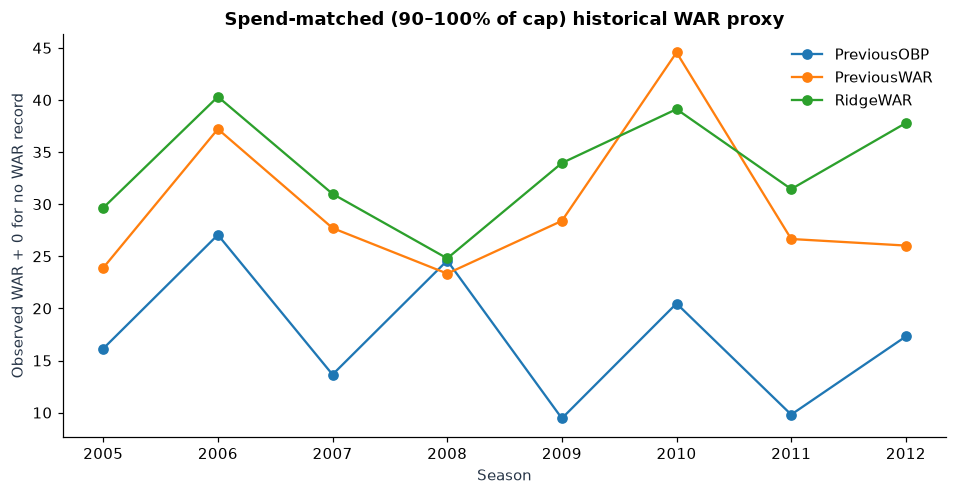

In [76]:
from scipy.optimize import milp, Bounds, LinearConstraint
from scipy.sparse import csc_matrix
feature60=['WAR','PA','OBP','SLG','age']
selection60=[]
def select60(f,score,n,cap,lo_frac=.90):
    f=f.reset_index(drop=True)
    if len(f)<n:return None
    cost=f.player_salary.to_numpy(dtype=float)/1e6
    cons=csc_matrix(np.vstack([np.ones(len(f)),cost]))
    res=milp(c=-f[score].to_numpy(dtype=float),integrality=np.ones(len(f)),bounds=Bounds(0,1),
        constraints=LinearConstraint(cons,[n,cap*lo_frac],[n,cap]),
        options={'time_limit':8,'mip_rel_gap':.025})
    if res.x is None:return None
    chosen=f.iloc[np.flatnonzero(res.x>.5)]
    return chosen if len(chosen)==n else None
for yr in range(2005,2013):
    train=old57[old57.target_year.lt(yr)&old57.realized_WAR.notna()].dropna(subset=feature60)
    pool=old57[old57.target_year.eq(yr)&old57.player_salary.gt(0)].dropna(subset=feature60).copy()
    if len(train)<200 or len(pool)<30:continue
    model=Pipeline([('sc',StandardScaler()),('ridge',Ridge(alpha=50))]).fit(train[feature60],train.realized_WAR)
    pool['PredictedWAR']=model.predict(pool[feature60]);pool['PriorWAR']=pool.WAR;pool['PriorOBP']=pool.OBP
    # Cap depends only on available price information, not target-year performance.
    cap=max(15., float(pool.nsmallest(8,'player_salary').player_salary.sum()/1e6)*2.5)
    for tag,score in [('RidgeWAR','PredictedWAR'),('PreviousWAR','PriorWAR'),('PreviousOBP','PriorOBP')]:
        chosen=select60(pool,score,8,cap,.90)
        if chosen is None:
            selection60.append({'year':yr,'method':tag,'status':'INFEASIBLE','cap_million':cap});continue
        selection60.append({'year':yr,'method':tag,'status':'FEASIBLE','cap_million':cap,
            'spent_million':chosen.player_salary.sum()/1e6,'n':len(chosen),
            'observed_WAR_sum':chosen.realized_WAR.sum(skipna=True),
            'unobserved_next_WAR':int(chosen.realized_WAR.isna().sum()),
            'proxy_zero_WAR_sum':chosen.realized_WAR.fillna(0).sum()})
spend60=pd.DataFrame(selection60)
if not spend60.empty:
    display(spend60.groupby('method',dropna=False)[['spent_million','proxy_zero_WAR_sum','unobserved_next_WAR']].mean().round(2))
    save_frame(spend60,'new_60_spend_matched_backtest.csv')
    ok=spend60[spend60.status.eq('FEASIBLE')]
    if not ok.empty:
        fig,ax=plt.subplots(figsize=(8.8,4.6))
        for name,g in ok.groupby('method'):ax.plot(g.year,g.proxy_zero_WAR_sum,'o-',label=name)
        ax.set(title='Spend-matched (90–100% of cap) historical WAR proxy',xlabel='Season',ylabel='Observed WAR + 0 for no WAR record')
        ax.legend(frameon=False);fig.tight_layout();fig.savefig(VISUALS/'new_60_spend_matched_war.png',bbox_inches='tight');plt.show()

## 61. How often do the WAR intervals cover the result?

For each test year, The model fits the model using earlier seasons and choose the interval width from an earlier calibration window. The chart now shows coverage in percent, its 95% Wilson interval and the typical prediction-band width. This covers **players with an observed next-season bWAR value**. Missing WAR rows are not counted as correct predictions or assumed to be zero.


,year,n,coverage,CI95_low,CI95_high,MAE,mean_width,median_width
0,2009,320,0.884,0.845,0.915,1.464,5.815,5.815
1,2010,322,0.922,0.888,0.947,1.335,6.142,6.142
2,2011,319,0.900,0.862,0.928,1.366,5.896,5.896
3,2012,324,0.923,0.889,0.947,1.305,5.723,5.723


Pooled coverage: 90.7% (Wilson 95% CI 89.0%–92.2%; 1285 observed outcomes)


,dimension,group,n,coverage,CI95_low,CI95_high,median_width
0,age_band,≤26,361,0.884,0.846,0.913,5.815
1,age_band,27–30,470,0.883,0.851,0.909,5.896
2,age_band,31–35,366,0.945,0.917,0.964,5.896
3,age_band,36+,88,0.977,0.921,0.994,5.856
4,PA_band,<300,243,0.963,0.931,0.980,5.815
5,PA_band,300–499,453,0.929,0.902,0.950,5.896
6,PA_band,500+,589,0.868,0.838,0.893,5.896


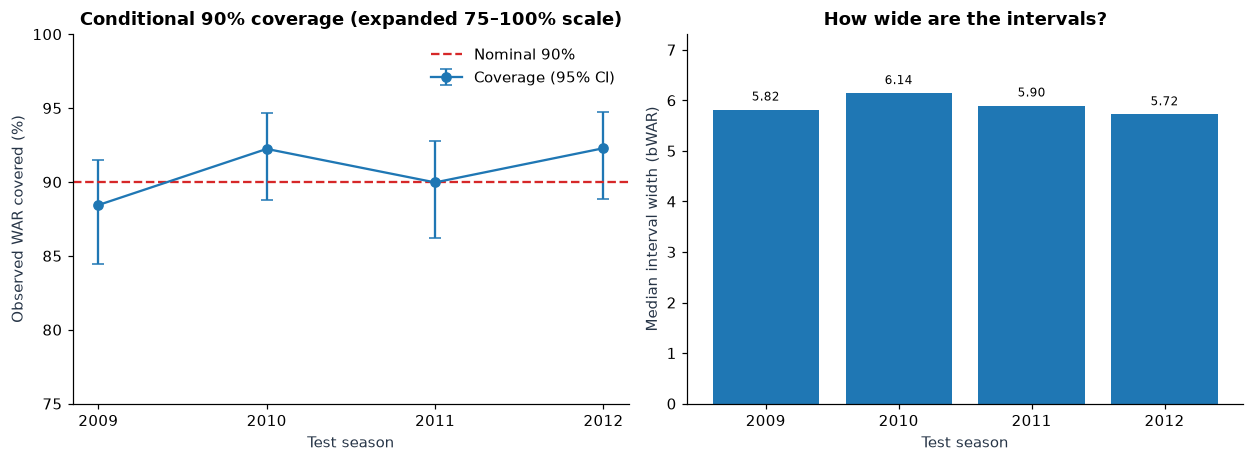

In [77]:
from math import ceil
pred61=[]
for yr in range(2009,2013):
    tr61=old57[(old57.target_year<yr-2)&old57.realized_WAR.notna()].dropna(subset=feature60)
    cal61=old57[old57.target_year.between(yr-2,yr-1)&old57.realized_WAR.notna()].dropna(subset=feature60)
    te61=old57[old57.target_year.eq(yr)&old57.realized_WAR.notna()].dropna(subset=feature60).copy()
    if len(tr61)<200 or len(cal61)<50 or len(te61)<15:continue
    mdl61=Pipeline([('std',StandardScaler()),('ridge',Ridge(alpha=50))]).fit(tr61[feature60],tr61.realized_WAR)
    residual61=np.abs(cal61.realized_WAR-mdl61.predict(cal61[feature60])).to_numpy()
    k61=min(len(residual61),ceil((len(residual61)+1)*0.90))
    q61=np.sort(residual61)[k61-1]
    te61['forecast']=mdl61.predict(te61[feature60]);te61['lower']=te61.forecast-q61;te61['upper']=te61.forecast+q61
    te61['covered']=te61.realized_WAR.between(te61.lower,te61.upper)
    te61['interval_width']=te61.upper-te61.lower
    te61['calibration_n']=len(cal61)
    pred61.append(te61[['playerID','target_year','age','PA','realized_WAR','forecast','lower','upper','covered','interval_width','calibration_n']])

def wilson_ci(k,n,z=1.959963984540054):
    if not n:return (np.nan,np.nan)
    p=k/n;d=1+z*z/n
    c=(p+z*z/(2*n))/d
    h=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/d
    return (max(0,c-h),min(1,c+h))

if pred61:
    pred61=pd.concat(pred61,ignore_index=True)
    rows61=[]
    for year,group in pred61.groupby('target_year'):
        lo,hi=wilson_ci(int(group.covered.sum()),len(group))
        rows61.append({'year':year,'n':len(group),'coverage':group.covered.mean(),
                       'CI95_low':lo,'CI95_high':hi,'MAE':mean_absolute_error(group.realized_WAR,group.forecast),
                       'mean_width':group.interval_width.mean(),'median_width':group.interval_width.median()})
    summary61=pd.DataFrame(rows61)
    all_lo61,all_hi61=wilson_ci(int(pred61.covered.sum()),len(pred61))
    display(summary61.round(3))
    print(f"Pooled coverage: {pred61.covered.mean():.1%} (Wilson 95% CI {all_lo61:.1%}–{all_hi61:.1%}; {len(pred61)} observed outcomes)")
    save_frame(pred61,'new_61_conditional_WAR_intervals.csv')
    save_frame(summary61,'new_61_WAR_interval_coverage.csv')
    pred61['age_band']=pd.cut(pred61.age,[-np.inf,26,30,35,np.inf],labels=['≤26','27–30','31–35','36+'])
    pred61['PA_band']=pd.cut(pred61.PA,[-np.inf,299,499,np.inf],labels=['<300','300–499','500+'])
    subgroup61=[]
    for dim61 in ['age_band','PA_band']:
        for name61,g61 in pred61.groupby(dim61,observed=True):
            if len(g61)<20:continue
            low61,high61=wilson_ci(int(g61.covered.sum()),len(g61))
            subgroup61.append({'dimension':dim61,'group':str(name61),'n':len(g61),
                               'coverage':g61.covered.mean(),'CI95_low':low61,'CI95_high':high61,
                               'median_width':g61.interval_width.median()})
    subgroup61=pd.DataFrame(subgroup61)
    display(subgroup61.round(3));save_frame(subgroup61,'new_61_subgroup_interval_coverage.csv')
    fig,(ax1,ax2)=plt.subplots(1,2,figsize=(11.5,4.3))
    years61=summary61.year.to_numpy()
    cover61=summary61.coverage.to_numpy()*100
    errs61=[(summary61.coverage-summary61.CI95_low).to_numpy()*100,
            (summary61.CI95_high-summary61.coverage).to_numpy()*100]
    ax1.errorbar(years61,cover61,yerr=errs61,fmt='o-',capsize=4,label='Coverage (95% CI)')
    ax1.axhline(90,ls='--',color='tab:red',label='Nominal 90%')
    ax1.set(ylim=(75,100),xticks=years61,xlabel='Test season',ylabel='Observed WAR covered (%)',
            title='Conditional 90% interval coverage')
    ax1.legend(frameon=False)
    ax2.bar(years61.astype(str),summary61.median_width)
    ax2.set(xlabel='Test season',ylabel='Median interval width (bWAR)',title='How wide are the intervals?')
    for b61 in ax2.patches:
        ax2.annotate(f'{b61.get_height():.2f}',(b61.get_x()+b61.get_width()/2,b61.get_height()),
                     ha='center',va='bottom',xytext=(0,4),textcoords='offset points',fontsize=8)
    ax2.set_ylim(0,float(summary61.median_width.max())*1.19)
    ax1.set_title('Conditional 90% coverage (expanded 75–100% scale)')
    fig.tight_layout();fig.savefig(VISUALS/'new_61_war_interval_coverage.png',bbox_inches='tight');plt.show()
else:
    print('NOT_EVALUATED: too few observed WAR records in the required year splits.')


## 62. Do position-specific WAR models help?

A hitter's position and a pitcher's role may matter for future performance. The analysis compares a single shared model with smaller role-specific models, using each player's previous-season role. Players without a valid role label are not assigned a made-up position. If the separate models do worse, that is a useful result too.


In [78]:
from sklearn.linear_model import Ridge
role62=[];pred62=[]
ap62_file=DATA_DIR/'Appearances.csv';pt62_file=DATA_DIR/'Pitching.csv'
if ap62_file.is_file() and pt62_file.is_file():
    ap62=pd.read_csv(ap62_file,low_memory=False,encoding='utf-8-sig')
    pt62=pd.read_csv(pt62_file,low_memory=False,encoding='utf-8-sig')
    pos_cols62={'C':'G_c','1B':'G_1b','2B':'G_2b','3B':'G_3b','SS':'G_ss','OF':'G_of'}
    if {'playerID','yearID',*pos_cols62.values()}.issubset(ap62.columns) and {'playerID','yearID','GS','G'}.issubset(pt62.columns):
        for c in pos_cols62.values():ap62[c]=pd.to_numeric(ap62[c],errors='coerce').fillna(0)
        agg62=ap62.groupby(['playerID','yearID'],as_index=False)[list(pos_cols62.values())].sum()
        agg62['role']=agg62[list(pos_cols62.values())].idxmax(axis=1).map({v:k for k,v in pos_cols62.items()})
        agg62['role_games']=agg62[list(pos_cols62.values())].max(axis=1)
        agg62.loc[agg62.role_games.eq(0),'role']=np.nan
        pitch62=pt62.groupby(['playerID','yearID'],as_index=False)[['GS','G']].sum()
        pitch62['pitch_role']=pd.Series(np.select([pitch62.GS.ge(8),pitch62.G.ge(15)],['SP','RP'],default=None),index=pitch62.index,dtype=object)
        base62=old57.merge(agg62[['playerID','yearID','role','role_games']],on=['playerID','yearID'],how='left',validate='one_to_one')
        base62=base62.merge(pitch62[['playerID','yearID','pitch_role']],on=['playerID','yearID'],how='left',validate='one_to_one')
        base62['role']=base62['pitch_role'].fillna(base62['role'])
        base62=base62[base62.role.notna()].copy()
        for yr in range(2006,2013):
            train=base62[base62.target_year.lt(yr)&base62.realized_WAR.notna()].dropna(subset=feature60)
            test_set=base62[base62.target_year.eq(yr)&base62.realized_WAR.notna()].dropna(subset=feature60)
            if len(train)<200 or len(test_set)<20:continue
            pooled=Pipeline([('sc',StandardScaler()),('r',Ridge(alpha=50))]).fit(train[feature60],train.realized_WAR)
            base_preds=pooled.predict(test_set[feature60]);role_preds=base_preds.copy()
            for group in test_set.role.unique():
                grp_train=train[train.role.eq(group)];mask=test_set.role.eq(group).to_numpy()
                if len(grp_train)<55:continue
                own=Pipeline([('sc',StandardScaler()),('r',Ridge(alpha=35))]).fit(grp_train[feature60],grp_train.realized_WAR)
                role_preds[mask]=own.predict(test_set.loc[mask,feature60])
            for name,yp in [('Pooled Ridge',base_preds),('Role-specific Ridge',role_preds)]:
                role62.append({'year':yr,'model':name,'n':len(test_set),'MAE':mean_absolute_error(test_set.realized_WAR,yp)})
        if role62:
            r62=pd.DataFrame(role62);display(r62.groupby('model',as_index=False).agg(mean_MAE=('MAE','mean'),years=('year','nunique')).round(3))
            save_frame(r62,'new_62_role_specific_war_models.csv')
    else: print('ROLE AUDIT: Appearances/Pitching lacks needed columns; section not evaluated.')
else: print('ROLE AUDIT: Appearances.csv and Pitching.csv are required. Missing locally in this verification environment.')

,model,mean_MAE,years
0,Pooled Ridge,1.362,7
1,Role-specific Ridge,1.368,7


## 63. Park and era adjustments for team run production
Use `Teams.csv` recorded BPF and season effects. Evaluate out-of-time associations with per-game runs scored and avoid causal claims. This is **not** a player-specific park adjustment nor proof that a park causes extra runs.


In [79]:
import statsmodels.formula.api as smf
runs63=team_seasons(raw)
runs63=runs63[runs63.yearID.between(2000,2012)&runs63.G.gt(0)&runs63.BPF.notna()&runs63.OBP.notna()].copy()
runs63['R_G']=runs63.R/runs63.G
runs63['park_factor']=runs63.BPF/100.
runs63['SLG']=(runs63.H + runs63['2B'] + 2*runs63['3B'] + 3*runs63.HR)/runs63.AB.replace(0,np.nan)
runs63=runs63.dropna(subset=['SLG'])
fit63=[]
for yr in range(2003,2013):
    a=runs63[runs63.yearID.lt(yr)];b=runs63[runs63.yearID.eq(yr)]
    if len(a)<40 or len(b)<20:continue
    for name,cols in [('OBP_only',['OBP']),('OBP_SLG_Park',['OBP','SLG','park_factor'])]:
        # Fit a period trend instead of categorical year FE to avoid unseen test-year dummies.
        Xcols=cols+['yearID'];mdl=Pipeline([('s',StandardScaler()),('r',Ridge(alpha=20))]).fit(a[Xcols],a.R_G)
        pred=mdl.predict(b[Xcols])
        fit63.append({'year':yr,'method':name,'n':len(b),'MAE_runs_per_game':mean_absolute_error(b.R_G,pred)})
if fit63:
    f63=pd.DataFrame(fit63);display(f63.groupby('method',as_index=False).agg(MAE=('MAE_runs_per_game','mean'),years=('year','nunique')).round(4))
    save_frame(f63,'new_63_park_era_runs_temporal_comparison.csv')

,method,MAE,years
0,OBP_SLG_Park,0.1155,10
1,OBP_only,0.1856,10


## 64. Source coverage and reproducible execution audit

File presence alone does not verify columns, year coverage or successful model evaluation. This intermediate audit records available datasets and model branches at this point in the workflow. The consolidated execution and source checks appear near the end of the Notebook.


In [80]:
audit64=[]
for f in ['Batting.csv','Master.csv','Salaries.csv','Teams.csv','People.csv','Appearances.csv','Fielding.csv','Pitching.csv','WAR.csv','plays.csv']:
    q=DATA_DIR/f
    if not q.exists() and f in ['Batting.csv','Master.csv']:q=DATA_DIR/(f+'.zip')
    status='FOUND' if q.exists() else 'NOT_FOUND'
    cols=''; minyear=np.nan;maxyear=np.nan
    if q.exists() and f!='plays.csv':
        try:
            sample=pd.read_csv(q,nrows=5,encoding='latin1',low_memory=False)
            cols=', '.join(sample.columns[:12]);yearcol=next((k for k in ['yearID','year_ID'] if k in sample.columns),None)
            if yearcol:
                years=pd.read_csv(q,usecols=[yearcol],low_memory=False)[yearcol]
                minyear,maxyear=years.min(),years.max()
        except Exception as exc:status='INVALID';cols=str(exc)[:140]
    elif q.exists() and f=='plays.csv':
        try:cols=', '.join(pd.read_csv(q,nrows=0).columns[:12]);status='FOUND_SCHEMA_CHECKED'
        except Exception as exc:status='INVALID';cols=str(exc)[:140]
    audit64.append({'file':f,'status':status,'first_columns':cols,'start_year':minyear,'end_year':maxyear})
source64=pd.DataFrame(audit64)
display(source64)
save_frame(source64,'FINAL_DATA_SOURCE_AUDIT.csv')
summary64=[
  {'analysis':'Two-part WAR','status':'EXECUTED' if len(model59) else 'SKIPPED','details':str(len(model59))+' metric rows'},
  {'analysis':'Spend-matched strategy','status':'EXECUTED' if not spend60.empty else 'SKIPPED','details':str(len(spend60))+' records'},
  {'analysis':'WAR interval coverage','status':'EXECUTED' if bool(pred61.__len__()) else 'SKIPPED','details':'Observed-next-WAR conditional only'},
  {'analysis':'Role-aware WAR','status':'EXECUTED' if bool(role62) else 'SKIPPED','details':str(len(role62))+' tests'},
  {'analysis':'Park and era runs','status':'EXECUTED' if bool(fit63) else 'SKIPPED','details':str(len(fit63))+' yearly metrics'},
  {'analysis':'Retrosheet 24-state expectancy','status':play_status58['status'],'details':play_status58['detail']},
  {'analysis':'Post-2012 external validation','status':external_status['status'],'details':external_status['detail']},
]
final_extension_audit64=pd.DataFrame(summary64)
display(final_extension_audit64)
save_frame(final_extension_audit64,'FINAL_MODEL_COMPLETION_AUDIT.csv')
print('Dataset folder:',DATA_DIR)
print('Results folder:',OUTPUT_ROOT)

,file,status,first_columns,start_year,end_year
0,Batting.csv,FOUND,"playerID, yearID, stint, teamID, lgID, G, G_ba...",1871.0,2012.0
1,Master.csv,FOUND,"lahmanID, playerID, managerID, hofID, birthYea...",NaN,NaN
2,Salaries.csv,FOUND,"yearID, teamID, lgID, playerID, salary",1985.0,2012.0
3,Teams.csv,FOUND,"yearID, lgID, teamID, franchID, divID, Rank, G...",1871.0,2012.0
4,People.csv,FOUND,"ï»¿ID, playerID, birthYear, birthMonth, birthD...",NaN,NaN
5,Appearances.csv,FOUND,"yearID, teamID, lgID, playerID, G_all, GS, G_b...",1871.0,2025.0
6,Fielding.csv,FOUND,"playerID, yearID, stint, teamID, lgID, POS, G,...",1871.0,2025.0
7,Pitching.csv,FOUND,"playerID, yearID, stint, teamID, lgID, W, L, G...",1871.0,2025.0
8,WAR.csv,FOUND,"playerID, yearID, WAR, bat_WAR, pitch_WAR, war...",1871.0,2026.0
9,plays.csv,FOUND_SCHEMA_CHECKED,"gid, event, inning, top_bot, vis_home, site, b...",NaN,NaN


,analysis,status,details
0,Two-part WAR,EXECUTED,24 metric rows
1,Spend-matched strategy,EXECUTED,24 records
2,WAR interval coverage,EXECUTED,Observed-next-WAR conditional only
3,Role-aware WAR,EXECUTED,14 tests
4,Park and era runs,EXECUTED,20 yearly metrics
5,Retrosheet 24-state expectancy,EXECUTED,"retrosheet: 2,550,439/16,756,076 regular-seaso..."
6,Post-2012 external validation,EXECUTED_WITH_CAVEATS,"2220 survivor-conditioned player-season tests,..."


Dataset folder: I:\Dataset\Moneyball Analysis
Results folder: C:\Users\htpar\Downloads\outputs


## 66. Missing WAR is a data issue, not a zero

A player can disappear from the next-season WAR table for several reasons. Missingness is kept separate from an observed WAR of zero. The section compares the full prior-year candidate group with the players whose next-year WAR and salary are recorded, then checks how that selection changes the error summary. Weighting depends on measured features, so the adjusted estimate is still conditional on assumptions the analysis cannot fully verify.


,year,eligible_t,next_WAR_observed,observation_rate,salary_coverage,observed_only_MAE,IPW_observed_MAE,proxy_zero_outcome_mean,observed_outcome_mean,inverse_weight_cap
0,2006,335,319,0.952,0.913,1.348,1.327,1.475,1.549,10
1,2007,342,323,0.944,0.904,1.300,1.286,1.430,1.514,10
2,2008,336,310,0.923,0.884,1.393,1.376,1.446,1.567,10
3,2009,341,320,0.938,0.891,1.462,1.445,1.510,1.609,10
4,2010,342,322,0.942,0.909,1.335,1.320,1.449,1.539,10
5,2011,342,319,0.933,0.912,1.366,1.346,1.461,1.567,10
6,2012,351,324,0.923,0.875,1.305,1.292,1.354,1.467,10


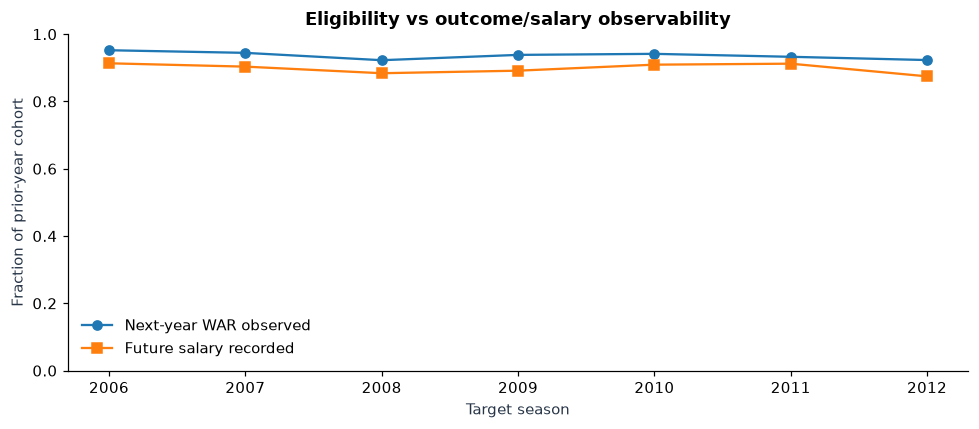

In [81]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import mean_absolute_error, brier_score_loss
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

bias66=[]
if war52_ready and 'old57' in globals():
    eligible66=old57.dropna(subset=['WAR','PA','OBP','SLG','age']).copy()
    eligible66['observed_next_WAR']=eligible66.realized_WAR.notna().astype(int)
    eligible66['observed_next_salary']=eligible66.player_salary.gt(0).astype(int)
    for yr in range(2006,2013):
        history66=eligible66[eligible66.target_year.lt(yr)]
        future66=eligible66[eligible66.target_year.eq(yr)].copy()
        if len(history66)<300 or len(future66)<30 or history66.observed_next_WAR.nunique()<2:
            continue
        obs66=Pipeline([('scale',StandardScaler()),('logit',LogisticRegression(max_iter=500))])
        obs66.fit(history66[feature60],history66.observed_next_WAR)
        future66['prob_observed']=np.clip(obs66.predict_proba(future66[feature60])[:,1],.05,.95)
        available66=future66[future66.observed_next_WAR.eq(1)].copy()
        ratio66=len(available66)/len(future66)
        if len(available66)<15:continue
        base66=Pipeline([('scale',StandardScaler()),('ridge',Ridge(alpha=50))]).fit(
            history66[history66.observed_next_WAR.eq(1)][feature60],
            history66[history66.observed_next_WAR.eq(1)].realized_WAR)
        available66['forecast']=base66.predict(available66[feature60])
        abs_err66=np.abs(available66.realized_WAR-available66.forecast)
        ipw66=np.minimum(10,1/available66.prob_observed)
        bias66.append({'year':yr,'eligible_t':len(future66),'next_WAR_observed':len(available66),
            'observation_rate':ratio66,'salary_coverage':future66.observed_next_salary.mean(),
            'observed_only_MAE':abs_err66.mean(),
            'IPW_observed_MAE':np.average(abs_err66,weights=ipw66),
            'proxy_zero_outcome_mean':future66.realized_WAR.fillna(0).mean(),
            'observed_outcome_mean':available66.realized_WAR.mean(),
            'inverse_weight_cap':10})
if bias66:
    summary66=pd.DataFrame(bias66)
    display(summary66.round(3))
    save_frame(summary66,'submission_66_WAR_observability_sensitivity.csv')
    fig,ax=plt.subplots(figsize=(9,4))
    ax.plot(summary66.year,summary66.observation_rate,'o-',label='Next-year WAR observed')
    ax.plot(summary66.year,summary66.salary_coverage,'s-',label='Future salary recorded')
    ax.set(xlabel='Target season',ylabel='Fraction of prior-year cohort',ylim=(0,1),
           title='Eligibility vs outcome/salary observability')
    ax.legend(frameon=False)
    fig.tight_layout();fig.savefig(VISUALS/'submission_66_WAR_selection_coverage.png',bbox_inches='tight');plt.show()
else:
    print('NOT_EVALUATED: an aligned historic bWAR panel is required.')


## 67. Let positions share the training data

Making a completely separate model for every position leaves fewer examples for each one. The analysis uses regularized position effects instead, so all players still help fit the shared performance features. The test asks whether that modest extra flexibility actually improves predictions on later seasons.


,mean_MAE,test_years
model,,
Partial-pooling Ridge,1.3592,7
Pooled Ridge,1.3584,7


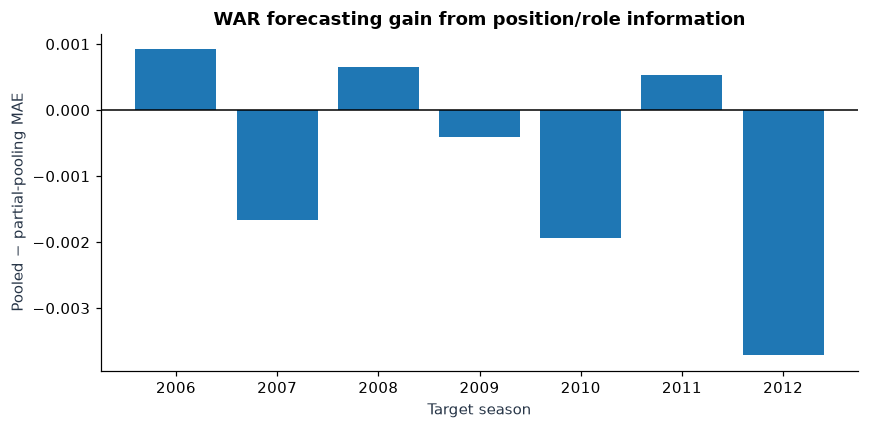

In [82]:
partial67=[]
if war52_ready and 'old57' in globals() and (DATA_DIR/'Appearances.csv').is_file():
    a67=pd.read_csv(DATA_DIR/'Appearances.csv',encoding='utf-8-sig',low_memory=False)
    pos67={'C':'G_c','1B':'G_1b','2B':'G_2b','3B':'G_3b','SS':'G_ss','OF':'G_of','DH':'G_dh'}
    if {'playerID','yearID',*pos67.values()}.issubset(a67.columns):
        for key in pos67.values():a67[key]=pd.to_numeric(a67[key],errors='coerce').fillna(0)
        p67=a67.groupby(['playerID','yearID'],as_index=False)[list(pos67.values())].sum()
        p67['role']=p67[list(pos67.values())].idxmax(axis=1).map({v:k for k,v in pos67.items()})
        p67.loc[p67[list(pos67.values())].max(axis=1).eq(0),'role']=np.nan
        base67=old57.merge(p67[['playerID','yearID','role']],on=['playerID','yearID'],how='left',validate='one_to_one')
        pitch67_path=DATA_DIR/'Pitching.csv'
        if pitch67_path.exists():
            pitch67=pd.read_csv(pitch67_path,low_memory=False)
            if {'playerID','yearID','GS','G'}.issubset(pitch67.columns):
                use67=pitch67.groupby(['playerID','yearID'],as_index=False)[['GS','G']].sum()
                use67['pitch_role']=np.select([use67.GS.ge(8),use67.G.ge(15)],['SP','RP'],default='')
                base67=base67.merge(use67[['playerID','yearID','pitch_role']],on=['playerID','yearID'],how='left',validate='one_to_one')
                base67['role']=base67.pitch_role.where(base67.pitch_role.isin(['SP','RP']),base67.role)
        base67=base67.dropna(subset=feature60+['role'])
        for year67 in range(2006,2013):
            tr67=base67[base67.target_year.lt(year67)&base67.realized_WAR.notna()].copy()
            te67=base67[base67.target_year.eq(year67)&base67.realized_WAR.notna()].copy()
            if len(tr67)<200 or len(te67)<20:continue
            common67=Pipeline([('scale',StandardScaler()),('ridge',Ridge(alpha=50))])
            common67.fit(tr67[feature60],tr67.realized_WAR)
            predpool67=common67.predict(te67[feature60])
            transform67=ColumnTransformer([('num',StandardScaler(),feature60),
                        ('position',OneHotEncoder(handle_unknown='ignore'),['role'])])
            partial_model67=Pipeline([('encoding',transform67),('ridge',Ridge(alpha=50))])
            partial_model67.fit(tr67[feature60+['role']],tr67.realized_WAR)
            predpartial67=partial_model67.predict(te67[feature60+['role']])
            for name67,pred67 in [('Pooled Ridge',predpool67),('Partial-pooling Ridge',predpartial67)]:
                partial67.append({'year':year67,'model':name67,'n':len(te67),
                                  'MAE':mean_absolute_error(te67.realized_WAR,pred67)})
if partial67:
    table67=pd.DataFrame(partial67)
    display(table67.groupby('model').agg(mean_MAE=('MAE','mean'),test_years=('year','nunique')).round(4))
    save_frame(table67,'submission_67_partial_pooling_war.csv')
    pair67=table67.pivot(index='year',columns='model',values='MAE').dropna()
    pair67['improvement']=pair67['Pooled Ridge']-pair67['Partial-pooling Ridge']
    fig,ax=plt.subplots(figsize=(8,4))
    ax.bar(pair67.index.astype(str),pair67.improvement)
    ax.axhline(0,color='black',linewidth=1)
    ax.set(xlabel='Target season',ylabel='Pooled − partial-pooling MAE',
           title='WAR forecasting gain from position/role information')
    fig.tight_layout();fig.savefig(VISUALS/'submission_67_position_pooling_improvement.png',bbox_inches='tight');plt.show()
else:
    print('NOT_EVALUATED: compatible position/role source not present in this runtime.')


## 68. Spending parity: a diagnostic of independently selected rosters

A spending *cap* is not the same thing as actual spending. The analysis first compares the strategies within the common 90–100% salary-cap band, then looks separately at seasons when the two rosters spent within **2% of each other**. The second group is smaller and selected after the fact, so its confidence interval is descriptive rather than an untouched test of a new strategy.

The target is next-year Baseball-Reference bWAR. A missing WAR record still carries a separate flag and the “missing = 0” version is called a proxy rather than a fact. Recorded salary is not proof that a player could have been signed for that amount.

**Follow-up:** Section 78 addresses the limitation directly by imposing the 2% spending requirement while both rosters are chosen. This section is kept to show why filtering years only after selection can be misleading.


,year,Ridge_spend_M,Prior_spend_M,Ridge_WAR_proxy,Prior_WAR_proxy,Ridge_missing_n,Prior_missing_n,WAR_difference_proxy,spend_difference_M,spend_difference_pct,within_2pct_spend
0,2005,14.490,13.596,29.65,23.89,0,0,5.76,0.894,6.365,False
1,2006,14.946,14.697,40.31,37.21,0,0,3.10,0.249,1.680,True
2,2007,14.469,13.844,30.99,27.71,0,0,3.28,0.625,4.415,False
3,2008,14.542,14.521,24.80,23.34,0,0,1.46,0.021,0.145,True
4,2009,13.754,13.712,33.95,28.40,0,0,5.55,0.043,0.309,True
5,2010,14.289,14.349,39.12,44.56,0,0,-5.44,-0.060,0.419,True
6,2011,14.522,14.490,31.45,26.66,0,0,4.79,0.033,0.224,True
7,2012,14.997,14.997,37.79,26.03,0,0,11.76,-0.001,0.004,True


,scope,n,mean,CI95_low,CI95_high
0,"Same cap, different spend allowed",8,3.782,0.551,6.804
1,Actual spending within 2%,6,3.537,-0.753,7.565


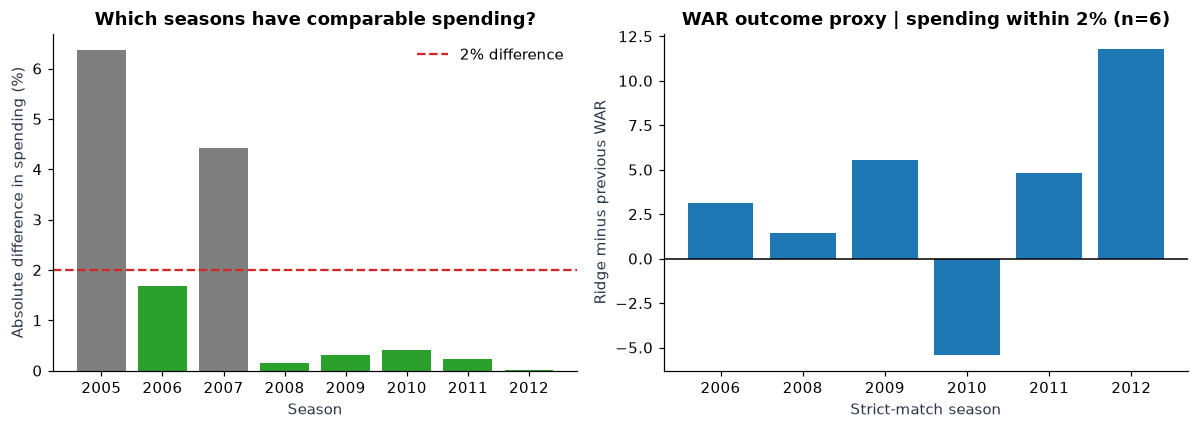

In [83]:
# A stricter 2% spending-parity analysis of the same historical choices.
from numpy.random import default_rng
robust68=pd.DataFrame(); strict68=pd.DataFrame()

def paired_bootstrap68(values,seed=68,draws=6000):
    a=np.asarray(values,dtype=float);a=a[np.isfinite(a)]
    if len(a)==0:return {'n':0,'mean':np.nan,'CI95_low':np.nan,'CI95_high':np.nan}
    boot=default_rng(seed).choice(a,size=(draws,len(a)),replace=True).mean(axis=1)
    return {'n':len(a),'mean':float(a.mean()),
            'CI95_low':float(np.quantile(boot,.025)),
            'CI95_high':float(np.quantile(boot,.975))}

if 'spend60' in globals() and not spend60.empty:
    ok68=spend60.loc[spend60.status.eq('FEASIBLE')].copy()
    if {'RidgeWAR','PreviousWAR'}.issubset(set(ok68.method)):
        var68=['spent_million','proxy_zero_WAR_sum','unobserved_next_WAR']
        wide68=ok68.pivot_table(index='year',columns='method',values=var68,aggfunc='first')
        required68=[(v,m) for v in var68 for m in ['RidgeWAR','PreviousWAR']]
        if all(k in wide68.columns for k in required68):
            x68=wide68.dropna(subset=required68)
            robust68=pd.DataFrame({'year':x68.index.to_numpy(dtype=int),
                'Ridge_spend_M':x68['spent_million','RidgeWAR'].to_numpy(),
                'Prior_spend_M':x68['spent_million','PreviousWAR'].to_numpy(),
                'Ridge_WAR_proxy':x68['proxy_zero_WAR_sum','RidgeWAR'].to_numpy(),
                'Prior_WAR_proxy':x68['proxy_zero_WAR_sum','PreviousWAR'].to_numpy(),
                'Ridge_missing_n':x68['unobserved_next_WAR','RidgeWAR'].to_numpy(),
                'Prior_missing_n':x68['unobserved_next_WAR','PreviousWAR'].to_numpy()})
            robust68['WAR_difference_proxy']=robust68.Ridge_WAR_proxy-robust68.Prior_WAR_proxy
            robust68['spend_difference_M']=robust68.Ridge_spend_M-robust68.Prior_spend_M
            robust68['spend_difference_pct']=100*abs(robust68.spend_difference_M)/np.maximum(
                 robust68[['Ridge_spend_M','Prior_spend_M']].mean(axis=1),1e-8)
            robust68['within_2pct_spend']=robust68.spend_difference_pct.le(2)
            strict68=robust68.loc[robust68.within_2pct_spend].copy()
            save_frame(robust68,'submission_68_all_spend_pairs.csv')
            save_frame(strict68,'submission_68_strict_2pct_pairs.csv')
            report68=pd.DataFrame([{'scope':lbl, **paired_bootstrap68(frame.WAR_difference_proxy)}
                         for lbl,frame in [('Same cap, different spend allowed',robust68),
                                           ('Actual spending within 2%',strict68)]])
            display(robust68.round(3));display(report68.round(3))
            save_frame(report68,'submission_68_spend_parity_CI_comparison.csv')
            fig,axes=plt.subplots(1,2,figsize=(11,4))
            colors68=['tab:green' if t else 'tab:gray' for t in robust68.within_2pct_spend]
            axes[0].bar(robust68.year.astype(str),robust68.spend_difference_pct,color=colors68)
            axes[0].axhline(2,color='tab:red',ls='--',label='2% difference')
            axes[0].set(xlabel='Season',ylabel='Absolute difference in spending (%)',title='Which seasons have comparable spending?')
            axes[0].legend(frameon=False)
            axes[1].bar(strict68.year.astype(str),strict68.WAR_difference_proxy)
            axes[1].axhline(0,color='black',lw=1)
            axes[1].set(xlabel='Strict-match season',ylabel='Ridge minus previous WAR',
                        title=f'WAR outcome proxy | spending within 2% (n={len(strict68)})')
            fig.tight_layout();fig.savefig(VISUALS/'submission_68_strict_spending_and_WAR.png',bbox_inches='tight');plt.show()
if robust68.empty: print('NOT_EVALUATED: no feasible pair of comparable salary-cap strategies.')


## 69. Model and dataset audit

This audit separates code execution from a dataset-dependent analysis that produced a valid result. Some branches require additional source files, so the recorded status must be read rather than inferred from the cell's execution count. Previously exported files can remain on disk across runs; output-folder file counts are not a substitute for the current Notebook's status tables.


In [84]:
final_audit69=[
 {'section':'51', 'test':'Forward-year salary and primary position',
  'status':position51.get('status','NOT_EVALUATED'),
  'evidence':position51.get('detail','')},
 {'section':'62', 'test':'Position/role-specific WAR',
  'status':'EXECUTED' if bool(role62) else 'NOT_EVALUATED',
  'evidence':str(len(role62))+' year-model rows'},
 {'section':'66', 'test':'Missing WAR and salary observation sensitivity',
  'status':'EXECUTED' if bool(bias66) else 'NOT_EVALUATED',
  'evidence':str(len(bias66))+' years'},
 {'section':'67', 'test':'Position/role partial pooling',
  'status':'EXECUTED' if bool(partial67) else 'NOT_EVALUATED',
  'evidence':str(len(partial67))+' year-model rows'},
 {'section':'68', 'test':'Matched spending and historical WAR regrets',
  'status':'EXECUTED' if not robust68.empty else 'NOT_EVALUATED',
  'evidence':str(len(robust68))+' paired years'},
 {'section':'50', 'test':'Post-2012 independent season validation',
  'status':external_status.get('status','NOT_EVALUATED'),
  'evidence':external_status.get('detail','')},
 {'section':'58', 'test':'Retrosheet play-state analysis',
  'status':play_status58.get('status','NOT_EVALUATED'),
  'evidence':play_status58.get('detail','')},
]
submission_audit69=pd.DataFrame(final_audit69)
display(submission_audit69)
save_frame(submission_audit69,'FINAL_SUBMISSION_MODEL_AUDIT.csv')
print('Final audit saved under:',PROCESSED)


,section,test,status,evidence
0,51,Forward-year salary and primary position,EXECUTED,4366 paired player-years; 11 forward evaluatio...
1,62,Position/role-specific WAR,EXECUTED,14 year-model rows
2,66,Missing WAR and salary observation sensitivity,EXECUTED,7 years
3,67,Position/role partial pooling,EXECUTED,14 year-model rows
4,68,Matched spending and historical WAR regrets,EXECUTED,8 paired years
5,50,Post-2012 independent season validation,EXECUTED_WITH_CAVEATS,"2220 survivor-conditioned player-season tests,..."
6,58,Retrosheet play-state analysis,EXECUTED,"retrosheet: 2,550,439/16,756,076 regular-seaso..."


Final audit saved under: C:\Users\htpar\Downloads\outputs\processed


## 70. Limits of the available data

Two conclusions cannot be drawn from these forecasts. A salary in the database is not a contract offer, and a missing next-season WAR row is not proof of zero ability. The historical backtests are useful as controlled comparisons, but players could not necessarily have been signed at those prices. Repeated model development on the historical seasons may make small performance gaps less reliable on genuinely new data.

The checks below take those limitations seriously: one tests assumptions about unobserved WAR, another lets positions share information, and the last examines whether a model's upper and lower predictions actually cover future results.


## 71. When WAR is missing: observation and sensitivity

The players with recorded WAR may not represent every player that could have been considered a year earlier. A WAR-observation model is fitted using only earlier seasons, and the analysis compares the observed-player average with an AIPW estimate. That estimate relies on a **missing-at-random** assumption given the measured features. The analysis also varies the assumed WAR of unobserved players, since that assumption cannot be tested from these files alone.


,target_year,eligible_n,observed_n,observed_share,observed_mean,MAR_AIPW_mean,weighted_effective_n,propensity_min,model_mean,assumed_missing_delta_+0.0,assumed_missing_delta_-0.5,assumed_missing_delta_-1.0
0,2006,335,319,0.952,1.549,1.516,311.416,0.304,1.576,1.497,1.473,1.449
1,2007,342,323,0.944,1.514,1.452,320.684,0.478,1.560,1.449,1.421,1.393
2,2008,336,310,0.923,1.567,1.465,308.361,0.451,1.549,1.457,1.419,1.380
3,2009,341,320,0.938,1.609,1.532,315.636,0.424,1.544,1.511,1.481,1.450
4,2010,342,322,0.942,1.539,1.471,320.287,0.348,1.547,1.467,1.438,1.408
5,2011,342,319,0.933,1.567,1.482,315.640,0.550,1.508,1.471,1.438,1.404
6,2012,351,324,0.923,1.467,1.370,321.968,0.585,1.452,1.371,1.332,1.294


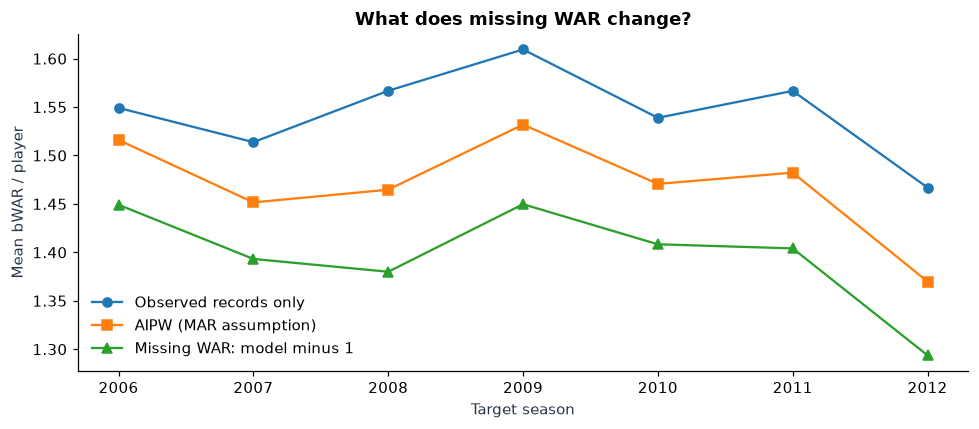

In [85]:
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

aipw71=[]
if 'old57' in globals() and 'feature60' in globals() and war52_ready:
    cohort71=old57.dropna(subset=feature60).copy()
    cohort71['observed_WAR']=cohort71.realized_WAR.notna().astype(int)
    for yy71 in range(2006,2013):
        tr71=cohort71[cohort71.target_year.lt(yy71)]
        te71=cohort71[cohort71.target_year.eq(yy71)].copy()
        obs71=tr71[tr71.observed_WAR.eq(1)]
        if len(tr71)<300 or len(obs71)<150 or len(te71)<30 or tr71.observed_WAR.nunique()<2:continue
        p71=Pipeline([('s',StandardScaler()),('m',LogisticRegression(max_iter=1000))]).fit(tr71[feature60],tr71.observed_WAR)
        o71=Pipeline([('s',StandardScaler()),('m',Ridge(alpha=50))]).fit(obs71[feature60],obs71.realized_WAR)
        te71['propensity']=np.clip(p71.predict_proba(te71[feature60])[:,1],.05,.99)
        te71['forecast']=o71.predict(te71[feature60])
        seen71=te71.observed_WAR.eq(1)
        residual71=np.zeros(len(te71),dtype=float)
        residual71[seen71.to_numpy()]=(te71.loc[seen71,'realized_WAR']-te71.loc[seen71,'forecast']).to_numpy()/te71.loc[seen71,'propensity'].to_numpy()
        aipw_mean71=(te71.forecast.to_numpy()+residual71).mean()
        missing71=te71.loc[~seen71,'forecast']
        w71=1/te71.loc[seen71,'propensity']
        result71={'target_year':yy71,'eligible_n':len(te71),'observed_n':int(seen71.sum()),
                 'observed_share':seen71.mean(),'observed_mean':te71.loc[seen71,'realized_WAR'].mean(),
                 'MAR_AIPW_mean':aipw_mean71,'weighted_effective_n':w71.sum()**2/(w71.pow(2).sum()),
                 'propensity_min':te71.propensity.min(),'model_mean':te71.forecast.mean()}
        for delta71 in [0.,-.5,-1.]:
            total71=te71.loc[seen71,'realized_WAR'].sum()+(missing71+delta71).sum()
            result71[f'assumed_missing_delta_{delta71:+.1f}']=total71/len(te71)
        aipw71.append(result71)
if aipw71:
    aipw_results71=pd.DataFrame(aipw71)
    display(aipw_results71.round(3))
    save_frame(aipw_results71,'research_71_WAR_observation_AIPW_sensitivity.csv')
    fig,ax=plt.subplots(figsize=(9,4))
    ax.plot(aipw_results71.target_year,aipw_results71.observed_mean,'o-',label='Observed records only')
    ax.plot(aipw_results71.target_year,aipw_results71.MAR_AIPW_mean,'s-',label='AIPW (MAR assumption)')
    ax.plot(aipw_results71.target_year,aipw_results71['assumed_missing_delta_-1.0'],'^-',label='Missing WAR: model minus 1')
    ax.set(xlabel='Target season',ylabel='Mean bWAR / player',title='What does missing WAR change?')
    ax.legend(frameon=False);fig.tight_layout()
    fig.savefig(VISUALS/'research_71_WAR_missingness_sensitivity.png',bbox_inches='tight');plt.show()
else:
    print('NOT_EVALUATED: additional WAR panel history is needed.')


## 72. Position-specific slopes: do they improve the forecast?

An earlier section compared a pooled model with a regularized position intercept. This adds a stronger test: do features such as previous WAR or playing time have a different relationship with next-year WAR at different positions? The model allows those interactions, then shrinks them heavily so small groups cannot drive the whole fit. Results are presented alongside the simpler alternatives rather than assuming the bigger model is better.


,model,mean_MAE,years
0,Pooled Ridge,1.3584,7
1,Shared + position Ridge,1.3592,7
2,Shrunk position interactions,1.3621,7


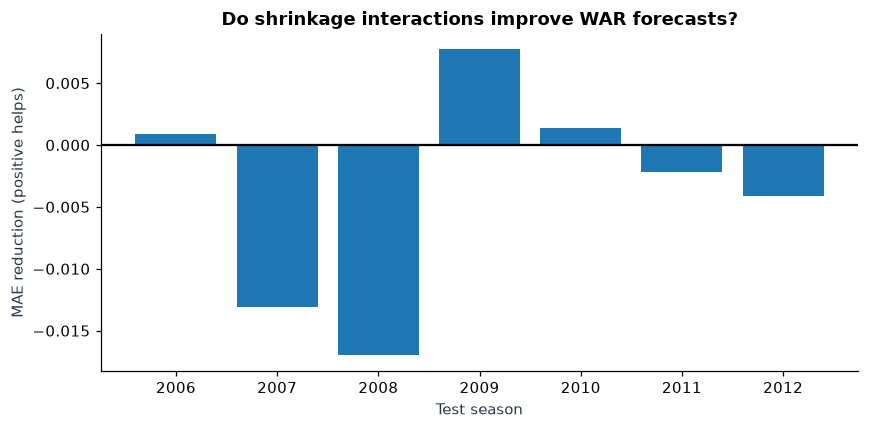

In [86]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import PolynomialFeatures

partial72=[]
app72_path=DATA_DIR/'Appearances.csv'
if app72_path.exists() and war52_ready and 'old57' in globals():
    app72=pd.read_csv(app72_path,encoding='utf-8-sig',low_memory=False)
    pos72={'C':'G_c','1B':'G_1b','2B':'G_2b','3B':'G_3b','SS':'G_ss','OF':'G_of','DH':'G_dh'}
    if {'playerID','yearID',*pos72.values()}.issubset(app72.columns):
        for c72 in pos72.values(): app72[c72]=pd.to_numeric(app72[c72],errors='coerce').fillna(0)
        grouped72=app72.groupby(['playerID','yearID'],as_index=False)[list(pos72.values())].sum()
        grouped72['position']=grouped72[list(pos72.values())].idxmax(axis=1).map({v:k for k,v in pos72.items()})
        grouped72.loc[grouped72[list(pos72.values())].max(axis=1).eq(0),'position']=np.nan
        frame72=old57.merge(grouped72[['playerID','yearID','position']],on=['playerID','yearID'],how='left',validate='one_to_one')
        frame72=frame72.dropna(subset=feature60+['position'])
        # Shared numeric features plus regularized one-hot position intercepts.
        for year72 in range(2006,2013):
            tr72=frame72[(frame72.target_year.lt(year72))&frame72.realized_WAR.notna()]
            te72=frame72[(frame72.target_year.eq(year72))&frame72.realized_WAR.notna()]
            if len(tr72)<200 or len(te72)<20: continue
            base72=Pipeline([('std',StandardScaler()),('ridge',Ridge(alpha=50))]).fit(tr72[feature60],tr72.realized_WAR)
            bx72=base72.predict(te72[feature60])
            trans72=ColumnTransformer([('num',StandardScaler(),feature60),('pos',OneHotEncoder(handle_unknown='ignore'),['position'])])
            posmdl72=Pipeline([('enc',trans72),('ridge',Ridge(alpha=50))]).fit(tr72[feature60+['position']],tr72.realized_WAR)
            px72=posmdl72.predict(te72[feature60+['position']])
            # Third model: shared main effects with strongly regularized role-specific slopes.
            scaler72=StandardScaler().fit(tr72[feature60])
            trnum72=scaler72.transform(tr72[feature60]);tenum72=scaler72.transform(te72[feature60])
            train_roles72=pd.get_dummies(tr72.position,prefix='role',dtype=float)
            test_roles72=pd.get_dummies(te72.position,prefix='role',dtype=float).reindex(columns=train_roles72.columns,fill_value=0)
            def design72(num,roles):
                dum=roles.to_numpy(dtype=float)
                interactions=(num[:,:,None]*dum[:,None,:]).reshape(len(num),-1)
                return np.concatenate([num,dum,interactions],axis=1)
            shr72=Ridge(alpha=150.0).fit(design72(trnum72,train_roles72),tr72.realized_WAR)
            sx72=shr72.predict(design72(tenum72,test_roles72))
            for model72,preds72 in [('Pooled Ridge',bx72),('Shared + position Ridge',px72),
                                     ('Shrunk position interactions',sx72)]:
                partial72.append({'year':year72,'model':model72,'n':len(te72),'MAE':mean_absolute_error(te72.realized_WAR,preds72)})
if partial72:
    results72=pd.DataFrame(partial72)
    display(results72.groupby('model',as_index=False).agg(mean_MAE=('MAE','mean'),years=('year','nunique')).round(4))
    save_frame(results72,'research_72_partially_pooled_position_WAR.csv')
    diff72=results72.pivot(index='year',columns='model',values='MAE').dropna()
    diff72['improvement']=diff72['Pooled Ridge']-diff72['Shrunk position interactions']
    fig,ax=plt.subplots(figsize=(8,4));ax.bar(diff72.index.astype(str),diff72.improvement)
    ax.axhline(0,color='black');ax.set(xlabel='Test season',ylabel='MAE reduction (positive helps)',title='Do shrinkage interactions improve WAR forecasts?')
    fig.tight_layout();fig.savefig(VISUALS/'research_72_partial_pooling_by_year.png',bbox_inches='tight');plt.show()
else:
    print('NOT_EVALUATED: historical Appearances data or enough position-labeled WAR seasons are missing.')


## 73. Predicting a range, not just one WAR number

A point forecast is convenient but hides risk. The analysis compares lower and upper conditional WAR quantiles on later seasons, then checks how often the recorded WAR lands inside that range. These are **directly estimated quantiles**, not conformal intervals; their actual coverage must be measured rather than assumed.


,year,n,coverage,mean_width,median_MAE
0,2009,320,0.831,5.020,1.436
1,2010,322,0.891,5.073,1.318
2,2011,319,0.846,5.057,1.356
3,2012,324,0.870,5.030,1.266


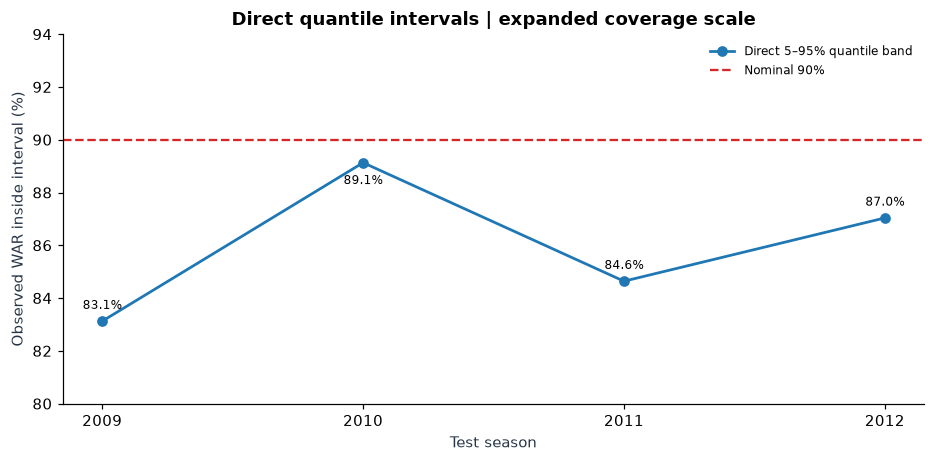

In [87]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

quant73=[]
if war52_ready and 'old57' in globals():
    frame73=old57.dropna(subset=feature60).copy()
    for yy73 in range(2009,2013):
        train73=frame73[(frame73.target_year.lt(yy73))&frame73.realized_WAR.notna()]
        test73=frame73[(frame73.target_year.eq(yy73))&frame73.realized_WAR.notna()]
        if len(train73)<250 or len(test73)<30:continue
        preds73={}
        for alpha73 in [.05,.50,.95]:
            m73=HistGradientBoostingRegressor(loss='quantile',quantile=alpha73,
                    max_iter=110,max_leaf_nodes=9,min_samples_leaf=35,l2_regularization=5,random_state=73)
            m73.fit(train73[feature60],train73.realized_WAR)
            preds73[alpha73]=m73.predict(test73[feature60])
        lower73=np.minimum(preds73[.05],preds73[.95]);upper73=np.maximum(preds73[.05],preds73[.95])
        truth73=test73.realized_WAR.to_numpy()
        quant73.append({'year':yy73,'n':len(test73),'coverage':np.mean((truth73>=lower73)&(truth73<=upper73)),
            'mean_width':np.mean(upper73-lower73),'median_MAE':mean_absolute_error(truth73,preds73[.50])})
if quant73:
    q73=pd.DataFrame(quant73);display(q73.round(3));save_frame(q73,'research_73_WAR_quantile_results.csv')
    fig,ax=plt.subplots(figsize=(8.6,4.3))
    years73=q73.year.astype(int).to_numpy()
    y73=(q73.coverage*100).to_numpy()
    ax.plot(years73,y73,'o-',lw=1.8,label='Direct 5–95% quantile band')
    ax.axhline(90,ls='--',color='tab:red',label='Nominal 90%')
    for xx,yy in zip(years73,y73):
        ax.annotate(f'{yy:.1f}%',(xx,yy),xytext=(0,-14 if yy>89 else 8),
                    textcoords='offset points',ha='center',fontsize=8)
    lo73=min(80,float(np.nanmin(y73))-2,89)
    hi73=max(94,float(np.nanmax(y73))+2,91)
    ax.set(xlabel='Test season',ylabel='Observed WAR inside interval (%)',xticks=years73,
           ylim=(lo73,hi73),title='Direct quantile intervals | expanded coverage scale')
    ax.legend(frameon=False,fontsize=8)
    fig.tight_layout()
    fig.savefig(VISUALS/'research_73_quantile_interval_coverage.png',dpi=160,bbox_inches='tight')
    plt.show()
else:
    print('NOT_EVALUATED: insufficient next-year observed WAR records.')


## 74. Data coverage for post-2012 validation

The original training snapshot still ends in 2012, which is intentional. The audit checks that **the separate 2025-vintage batting and player files** are present and that the measured WAR source includes the corresponding later seasons. Actual results are calculated in Sections 50 (OBP) and 81 (bWAR), not inferred from the file's timestamp.


In [88]:
# Source readiness only. This does not substitute for Section 81's real holdout scores.
historical_max74 = int(p_all.yearID.max())
external_file74=DATA_DIR/'Batting_2025.csv'
people_file74=DATA_DIR/'People_2025.csv'
war_file74=DATA_DIR/'WAR.csv'
external_max74=np.nan
war_max74=np.nan
if external_file74.is_file():
    ext_year74=pd.read_csv(external_file74,usecols=['yearID'],low_memory=False)
    external_max74=int(pd.to_numeric(ext_year74.yearID,errors='coerce').max())
if war_file74.is_file():
    war_years74=pd.read_csv(war_file74,usecols=['yearID'],low_memory=False)
    war_max74=int(pd.to_numeric(war_years74.yearID,errors='coerce').max())
ready74=bool(external_file74.is_file() and people_file74.is_file() and
    np.isfinite(external_max74) and external_max74>=2025 and
    np.isfinite(war_max74) and war_max74>=2025)
coverage74=pd.DataFrame([{'historical_training_batting_last_year':historical_max74,
    'separate_external_batting_last_year':external_max74,
    'WAR_source_last_year':war_max74,
    'People_2025_present':people_file74.is_file(),
    'status':'READY_FOR_SECTION_81' if ready74 else 'NOT_READY_CHECK_EXTERNAL_FILES'}])
display(coverage74)
save_frame(coverage74,'research_74_external_period_readiness.csv')
print('This is a source check; the held-out WAR results appear in Section 81.')

,historical_training_batting_last_year,separate_external_batting_last_year,WAR_source_last_year,People_2025_present,status
0,2012,2025,2026,True,READY_FOR_SECTION_81


This is a source check; the held-out WAR results appear in Section 81.


## 75. Does calibration work equally well for different players?

The pooled WAR interval in Section 61 was close to 90% coverage, but it was less reliable for some players with many plate appearances. A transparent alternative is tested: calibrate residuals **separately by prior-season PA band**. Each test year uses only preceding seasons for fitting and calibration, and the calibration falls back to the pooled interval when a band has too few calibration examples. Both coverage and width are then compared, not just one headline percentage.

This is still a conditional analysis of players with recorded future WAR, not a solution to missing-outcome selection.


,method,n,coverage,mean_width
0,PA-group calibration,1285,0.902,5.813
1,Pooled calibration,1285,0.907,5.894


,method,pa_band,n,coverage,CI95_low,CI95_high,mean_width
0,PA-group calibration,300–499,453,0.887,0.855,0.913,5.163
1,PA-group calibration,500+,589,0.908,0.882,0.929,6.689
2,PA-group calibration,<300,243,0.914,0.872,0.943,4.902
3,Pooled calibration,300–499,453,0.929,0.902,0.950,5.898
4,Pooled calibration,500+,589,0.868,0.838,0.893,5.897
5,Pooled calibration,<300,243,0.963,0.931,0.980,5.877


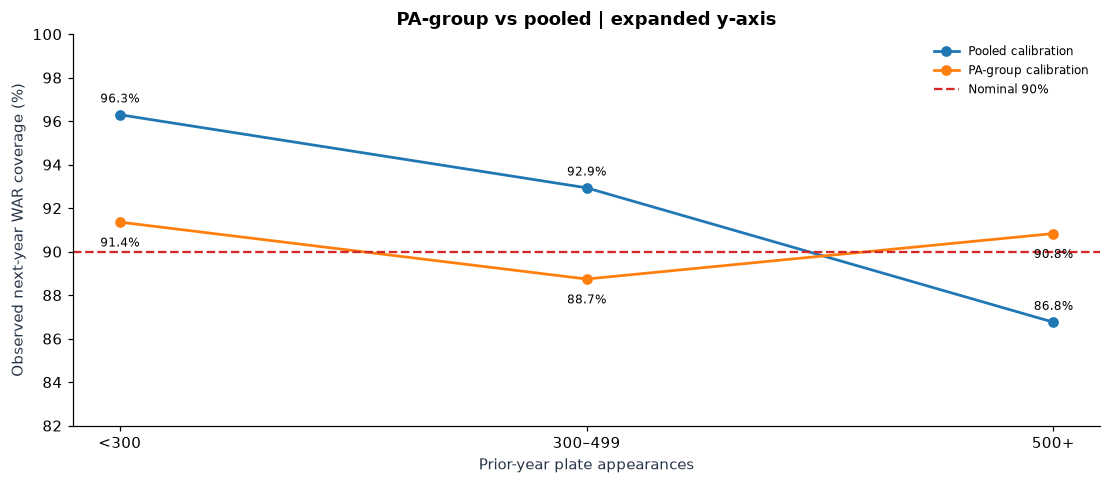

In [89]:
# Mondrian-style rolling conformal intervals; calibrate on earlier seasons only.
from math import ceil
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

rows75=[];pred_parts75=[]
def quantile75(values,alpha=.10):
    v=np.sort(np.asarray(values,dtype=float));v=v[np.isfinite(v)]
    if len(v)==0:return np.nan
    k=min(len(v),ceil((len(v)+1)*(1-alpha)))
    return float(v[k-1])

def pa_band75(values):
    return pd.cut(values,[-np.inf,299,499,np.inf],labels=['<300','300–499','500+'])

if 'old57' in globals() and 'feature60' in globals() and war52_ready:
    for year75 in range(2009,2013):
        tr75=old57[(old57.target_year<year75-2)&old57.realized_WAR.notna()].dropna(subset=feature60)
        ca75=old57[(old57.target_year.between(year75-2,year75-1))&old57.realized_WAR.notna()].dropna(subset=feature60)
        te75=old57[(old57.target_year.eq(year75))&old57.realized_WAR.notna()].dropna(subset=feature60).copy()
        if len(tr75)<200 or len(ca75)<50 or len(te75)<15:continue
        m75=Pipeline([('scale',StandardScaler()),('ridge',Ridge(alpha=50))]).fit(tr75[feature60],tr75.realized_WAR)
        ca75=ca75.assign(pred=m75.predict(ca75[feature60]));te75=te75.assign(pred=m75.predict(te75[feature60]))
        ca75['err']=abs(ca75.realized_WAR-ca75.pred)
        ca75['pa_band']=pa_band75(ca75.PA);te75['pa_band']=pa_band75(te75.PA)
        glob75=quantile75(ca75.err)
        q_by_band75={}
        for band75,g75 in ca75.groupby('pa_band',observed=True):
            q_by_band75[str(band75)]=quantile75(g75.err) if len(g75)>=40 else glob75
        for method75 in ['Pooled calibration','PA-group calibration']:
            q75=np.full(len(te75),glob75) if method75=='Pooled calibration' else np.array(
                [q_by_band75.get(str(z),glob75) for z in te75.pa_band],dtype=float)
            e75=te75.realized_WAR.to_numpy(dtype=float)
            covered75=(e75>=te75.pred.to_numpy()-q75)&(e75<=te75.pred.to_numpy()+q75)
            part75=pd.DataFrame({'year':year75,'method':method75,'playerID':te75.playerID.to_numpy(),
                       'pa_band':te75.pa_band.astype(str).to_numpy(),'covered':covered75,
                       'width':2*q75,'forecast':te75.pred.to_numpy(),'realized_WAR':e75})
            pred_parts75.append(part75)
    if pred_parts75:
        pred75=pd.concat(pred_parts75,ignore_index=True)
        for (method75,band75),g75 in pred75.groupby(['method','pa_band']):
            lo75,hi75=wilson_ci(int(g75.covered.sum()),len(g75))
            rows75.append({'method':method75,'pa_band':band75,'n':len(g75),
                           'coverage':g75.covered.mean(),'CI95_low':lo75,'CI95_high':hi75,
                           'mean_width':g75.width.mean()})
        summary75=pd.DataFrame(rows75)
        overall75=pred75.groupby('method',as_index=False).agg(
            n=('covered','size'),coverage=('covered','mean'),mean_width=('width','mean'))
        display(overall75.round(3));display(summary75.round(3))
        save_frame(pred75,'research_75_conditional_conformal_player_results.csv')
        save_frame(summary75,'research_75_PA_conditional_coverage.csv')
        save_frame(overall75,'research_75_interval_summary.csv')
        fig,ax=plt.subplots(figsize=(10.2,4.5))
        labels75=['<300','300–499','500+'];xx75=np.arange(len(labels75))
        for method75 in ['Pooled calibration','PA-group calibration']:
            data75=summary75[summary75.method.eq(method75)].set_index('pa_band').reindex(labels75)
            yy75=data75.coverage.to_numpy()*100
            ax.plot(xx75,yy75,'o-',lw=1.8,label=method75)
            for x75,y75 in zip(xx75,yy75):
                ax.annotate(f'{y75:.1f}%',(x75,y75),xytext=(0,8 if method75=='Pooled calibration' else -16),
                            textcoords='offset points',ha='center',fontsize=8)
        ax.axhline(90,ls='--',color='tab:red',label='Nominal 90%')
        ax.set(xticks=xx75,xticklabels=labels75,ylim=(82,100),xlabel='Prior-year plate appearances',
               ylabel='Observed next-year WAR coverage (%)',title='PA-group vs pooled | expanded y-axis')
        ax.legend(frameon=False,fontsize=8)
        fig.tight_layout()
        fig.savefig(VISUALS/'research_75_group_conditional_WAR_coverage.png',dpi=160,bbox_inches='tight')
        plt.show()
    else:print('NOT_EVALUATED: insufficient historical observed bWAR split.')
else:print('NOT_EVALUATED: bWAR panel is unavailable.')


## 76. How much did an offensive play change expected runs? (RE24)

This is the event-level companion to Section 58, using **regular-season 2000–2012 plays only**. RE24 is calculated as runs scored plus expected runs after the play minus expected runs before it. The expectation table comes from complete half-innings; the eligible event values here cover plays with the required runner and out states. The analysis also reports the exact number of filtered rows and eligible plate appearances.

These figures describe the average change in run expectancy for an event in its observed context. They are not WAR, do not isolate player talent, and should not be treated as causal event effects. Retrosheet attribution remains required for any published graph.


,event_type,plays,avg_RE24_runs
0,Single,376927,0.458
1,Double,114239,0.767
2,Triple,11933,1.059
3,Home run,66238,1.398
4,Walk,207963,0.301
5,Hit by pitch,22134,0.336
6,Strikeout,423913,-0.282
7,Other plate appearance,1208882,-0.264


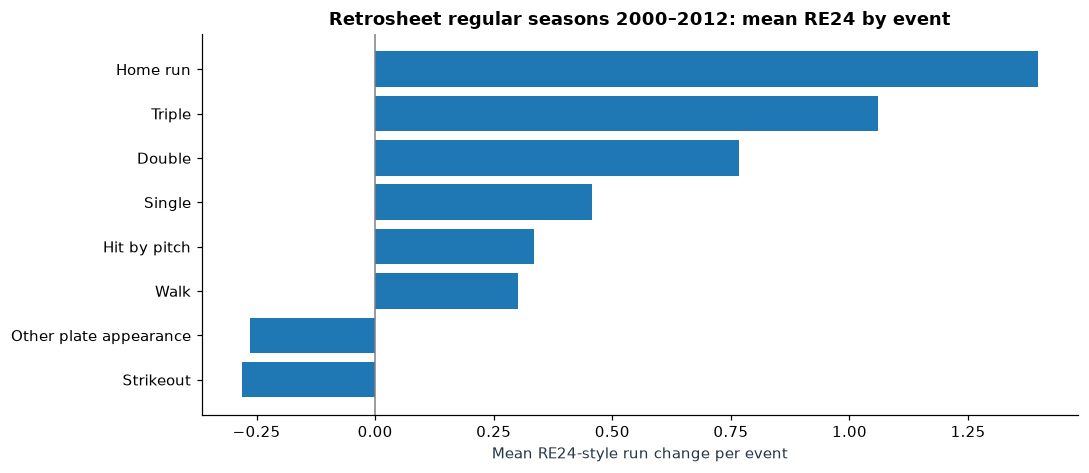

{'section': 76, 'status': 'EXECUTED', 'reason': '2,432,229 eligible events in 2,550,439 filtered plays'}


WindowsPath('C:/Users/htpar/Downloads/outputs/processed/research_76_RE24_status.csv')

In [90]:
# Retrosheet RE24-style event differences; streaming avoids loading plays.csv at once.
re24_status76={'section':76,'status':'NOT_EVALUATED','reason':'Retrosheet data or required post-play states unavailable'}
re24_results76=pd.DataFrame()
required76={'gid','gametype','outs_pre','outs_post','br1_pre','br2_pre','br3_pre',
           'br1_post','br2_post','br3_post','runs','pa'}
if PLAY_PATH58.is_file() and play_state58 is not None and play_status58.get('status')=='EXECUTED':
    header76=set(pd.read_csv(PLAY_PATH58,nrows=0).columns)
    if required76.issubset(header76):
        # Use the same base-state coding and the same year mask as Section 58.
        value76=play_state58.pivot(index='outs_before',columns='base_state_before',values='run_expectancy').to_numpy()
        groups76=['Single','Double','Triple','Home run','Walk','Hit by pitch','Strikeout','Other plate appearance']
        counts76={k:0 for k in groups76};sums76={k:0. for k in groups76};row_scope76=0
        flag76={'single':'Single','double':'Double','triple':'Triple','hr':'Home run',
                'walk':'Walk','hbp':'Hit by pitch','k':'Strikeout'}
        needed76=required76 | ({'date'}&header76) | (set(flag76)&header76)
        for chunk76 in pd.read_csv(PLAY_PATH58,usecols=lambda col:col in needed76,
                                   chunksize=175000,low_memory=False,encoding_errors='replace'):
            keep76,_,_= _retrosheet_year_mask58(chunk76)
            regular76=chunk76.gametype.astype('string').str.strip().str.lower().eq('regular').fillna(False)
            v76=chunk76.loc[keep76 & regular76]
            if v76.empty:continue
            row_scope76+=len(v76)
            op76=pd.to_numeric(v76.outs_pre,errors='coerce').to_numpy()
            oo76=pd.to_numeric(v76.outs_post,errors='coerce').to_numpy()
            r76=pd.to_numeric(v76.runs,errors='coerce').to_numpy()
            pa76=pd.to_numeric(v76.pa,errors='coerce').fillna(0).to_numpy()==1
            bpre76=(_is_occupied58(v76.br1_pre).astype(int)+2*_is_occupied58(v76.br2_pre).astype(int)+4*_is_occupied58(v76.br3_pre).astype(int)).to_numpy()
            bpost76=(_is_occupied58(v76.br1_post).astype(int)+2*_is_occupied58(v76.br2_post).astype(int)+4*_is_occupied58(v76.br3_post).astype(int)).to_numpy()
            valid76=pa76 & np.isfinite(op76)&np.isfinite(oo76)&np.isfinite(r76)&(op76>=0)&(op76<3)&(oo76>=0)&(oo76<=3)
            pre76=np.full(len(v76),np.nan);post76=np.full(len(v76),np.nan)
            ii76=np.flatnonzero(valid76)
            pre76[ii76]=value76[op76[ii76].astype(int),bpre76[ii76]]
            active76=ii76[oo76[ii76]<3]
            post76[active76]=value76[oo76[active76].astype(int),bpost76[active76]]
            post76[ii76[oo76[ii76]==3]]=0.0
            run_value76=r76+post76-pre76
            valid76 &=np.isfinite(run_value76)
            group76=np.full(len(v76),'Other plate appearance',dtype=object)
            # Explicit hierarchy: each plate appearance assigned to exactly one type.
            for flag,label in flag76.items():
                if flag in v76.columns:
                    yes76=pd.to_numeric(v76[flag],errors='coerce').fillna(0).to_numpy()>0
                    group76[yes76]=label
            for label in groups76:
                j76=valid76&(group76==label)
                counts76[label]+=int(j76.sum());sums76[label]+=float(run_value76[j76].sum())
        re24_results76=pd.DataFrame([{'event_type':t,'plays':counts76[t],
           'avg_RE24_runs':sums76[t]/counts76[t] if counts76[t] else np.nan}
           for t in groups76])
        save_frame(re24_results76,'submission_76_RE24_regular_season_event_types_2000_2012.csv')
        display(re24_results76.round(3))
        fig,ax=plt.subplots(figsize=(10,4.4))
        chart76=re24_results76[re24_results76.plays.ge(30)].sort_values('avg_RE24_runs')
        ax.barh(chart76.event_type,chart76.avg_RE24_runs);ax.axvline(0,color='gray',linewidth=1)
        ax.set(xlabel='Mean RE24-style run change per event',title='Retrosheet regular seasons 2000–2012: mean RE24 by event')
        fig.tight_layout();fig.savefig(VISUALS/'submission_76_RE24_regular_season_event_values.png',bbox_inches='tight');plt.show()
        re24_status76.update(status='EXECUTED',reason=f'{int(re24_results76.plays.sum()):,} eligible events in {row_scope76:,} filtered plays')
    else:re24_status76['reason']='Missing columns: '+', '.join(sorted(required76-header76))
print(re24_status76)
save_frame(pd.DataFrame([re24_status76]),'research_76_RE24_status.csv')

## 77. Post-selection sensitivity: what the first comparison can and cannot show

The analysis revisits the spend-matched WAR backtest under three restrictions: the same eight roster slots, **actual recorded spending within 2%**, and different values assigned to a missing next-year WAR record. Using missing = 0 is only a proxy, not a measurement. The analysis retains both the loose same-cap comparison and the stricter subset so it is clear when the story changes.

The uncertainty interval resamples **seasons**, not individual players, because each historical season is the unit of comparison. With only a few matched seasons, a wide interval is a finding rather than something to hide.

The new Section 80 examines joint cost-matched selections. The missing-WAR sensitivity here can be uninformative if all selected players have an observed later WAR. That is a limitation, not evidence of robustness.


,comparison,missing_WAR_assumption,paired_years,Ridge_minus_prior_mean_WAR_proxy,CI95_low,CI95_high,mean_absolute_spend_difference_pct
0,All same-cap paired seasons,-1.0,8,3.782,0.437,6.750,1.695
1,All same-cap paired seasons,0.0,8,3.782,0.451,6.914,1.695
2,All same-cap paired seasons,1.0,8,3.782,0.584,6.804,1.695
3,Within 2% recorded spending,-1.0,6,3.537,-0.627,7.565,0.463
4,Within 2% recorded spending,0.0,6,3.537,-0.753,7.622,0.463
5,Within 2% recorded spending,1.0,6,3.537,-0.753,7.720,0.463


,year,spend_difference_pct,WAR_difference_proxy,Ridge_missing_n,Prior_missing_n,within_2pct_spend
0,2005,6.365,5.76,0,0,False
1,2006,1.680,3.10,0,0,True
2,2007,4.415,3.28,0,0,False
3,2008,0.145,1.46,0,0,True
4,2009,0.309,5.55,0,0,True
5,2010,0.419,-5.44,0,0,True
6,2011,0.224,4.79,0,0,True
7,2012,0.004,11.76,0,0,True


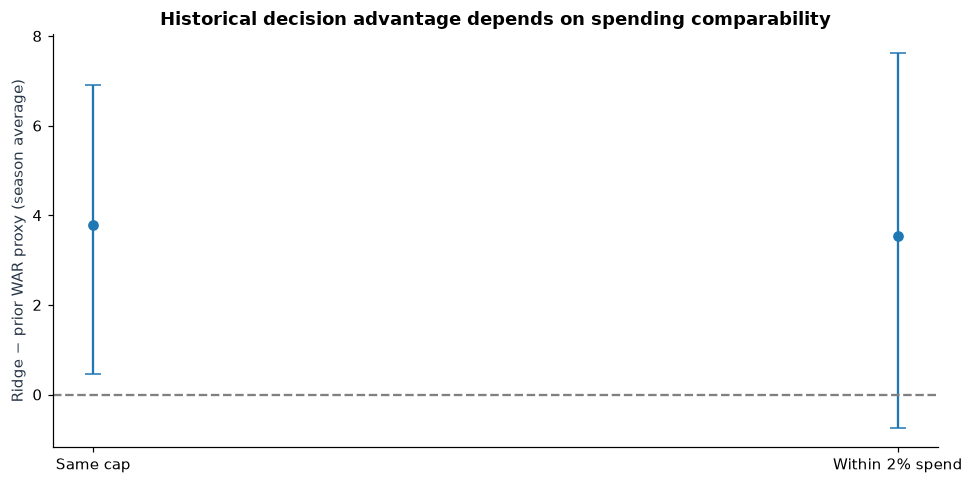

In [91]:
# Season-paired regret and missing-outcome sensitivity (2005–2012 historical proxy).
result77=[]
if 'robust68' in globals() and not robust68.empty:
    for sample77,frame77 in [('All same-cap paired seasons',robust68),
                             ('Within 2% recorded spending',robust68.loc[robust68.within_2pct_spend])]:
        for delta77 in [-1.,0.,1.]:
            vals77=(frame77.WAR_difference_proxy +
                  delta77*(frame77.Ridge_missing_n-frame77.Prior_missing_n)).to_numpy(float)
            summ77=paired_bootstrap68(vals77,seed=77+int(delta77)+1,draws=8000)
            result77.append({'comparison':sample77,'missing_WAR_assumption':delta77,
                             'paired_years':summ77['n'],
                             'Ridge_minus_prior_mean_WAR_proxy':summ77['mean'],
                             'CI95_low':summ77['CI95_low'],
                             'CI95_high':summ77['CI95_high'],
                             'mean_absolute_spend_difference_pct':frame77.spend_difference_pct.mean() if len(frame77) else np.nan})
    result77=pd.DataFrame(result77)
    display(result77.round(3))
    save_frame(result77,'research_77_robust_roster_comparison.csv')
    display(robust68[['year','spend_difference_pct','WAR_difference_proxy','Ridge_missing_n','Prior_missing_n','within_2pct_spend']].round(3))
    fig,ax=plt.subplots(figsize=(9,4.5))
    d77=result77.loc[result77.missing_WAR_assumption.eq(0)].copy()
    positions77=np.arange(len(d77))
    ax.errorbar(positions77,d77.Ridge_minus_prior_mean_WAR_proxy,
        yerr=[d77.Ridge_minus_prior_mean_WAR_proxy-d77.CI95_low,
              d77.CI95_high-d77.Ridge_minus_prior_mean_WAR_proxy],
        fmt='o',capsize=5)
    ax.axhline(0,color='gray',ls='--')
    ax.set(xticks=positions77,xticklabels=['Same cap','Within 2% spend'],
           ylabel='Ridge − prior WAR proxy (season average)',
           title='Historical decision advantage depends on spending comparability')
    fig.tight_layout();fig.savefig(VISUALS/'research_77_strict_roster_decision_CI.png',bbox_inches='tight');plt.show()
else:print('NOT_EVALUATED: paired strategy results needed from Sections 60 and 68.')


In [92]:
# End-of-notebook check: actual branch results for the newly revised sections.
checks76=[
 {'section':46,'model':'Salary selection audit','status':'EXECUTED' if 'summary46' in globals() and len(summary46) else 'NOT_EVALUATED','detail':'Full candidate pool and IPW sensitivity'},
 {'section':51,'model':'Next-year salary and prior position','status':position51.get('status','NOT_EVALUATED') if 'position51' in globals() else 'NOT_EVALUATED','detail':position51.get('detail','') if 'position51' in globals() else ''},
 {'section':61,'model':'Conditional WAR interval coverage','status':'EXECUTED' if 'pred61' in globals() and isinstance(pred61,pd.DataFrame) and len(pred61) else 'NOT_EVALUATED','detail':'Observed later WAR only'},
 {'section':62,'model':'Role-specific WAR comparison','status':'EXECUTED' if 'role62' in globals() and len(role62) else 'NOT_EVALUATED','detail':'Prior-year position/role'},
 {'section':71,'model':'WAR observation / AIPW sensitivity','status':'EXECUTED' if 'aipw71' in globals() and len(aipw71) else 'NOT_EVALUATED','detail':'MAR assumption and sensitivity'},
 {'section':72,'model':'Position interaction shrinkage','status':'EXECUTED' if 'partial72' in globals() and len(partial72) else 'NOT_EVALUATED','detail':'Requires Appearances'},
 {'section':73,'model':'Direct WAR quantile bands','status':'EXECUTED' if 'quant73' in globals() and len(quant73) else 'NOT_EVALUATED','detail':'Conditional coverage checked'},
 {'section':74,'model':'External period readiness','status':'READY_FOR_TEST' if ready74 else 'NOT_EVALUATED','detail':'Actual post-2012 batting and WAR coverage'}]
audit76=pd.DataFrame(checks76)
display(audit76)
save_frame(audit76,'FINAL_REVIEW_MODEL_STATUS.csv')
print('Review any NOT_EVALUATED lines before presenting results from the local run.')
# New analysis status, without treating a skipped analysis as success.
completion77=pd.DataFrame([
 {'section':58,'analysis':'2000–2012 play-by-play validation','status':play_status58.get('status','NOT_EVALUATED'),'detail':play_status58.get('detail','')},
 {'section':68,'analysis':'Strict 2% actual-spending comparison','status':'EXECUTED' if len(strict68) else 'NOT_EVALUATED','detail':f'{len(strict68)} eligible paired seasons'},
 {'section':75,'analysis':'PA-conditional WAR intervals','status':'EXECUTED' if len(rows75) else 'NOT_EVALUATED','detail':'Past-only calibration; observed outcomes'},
 {'section':76,'analysis':'RE24-style event value','status':re24_status76.get('status','NOT_EVALUATED'),'detail':re24_status76.get('reason','')},
 {'section':77,'analysis':'Strict historical roster sensitivity','status':'EXECUTED' if len(result77) else 'NOT_EVALUATED','detail':'Missing-WAR scenarios and season bootstrap'},
 {'section':74,'analysis':'Post-2012 independent evaluation','status':'READY_FOR_TEST' if ready74 else 'NOT_EVALUATED','detail':'Requires updated batting and matching WAR'}
])
display(completion77)
save_frame(completion77,'FINAL_SUBMISSION_58_68_75_77_STATUS.csv')


,section,model,status,detail
0,46,Salary selection audit,EXECUTED,Full candidate pool and IPW sensitivity
1,51,Next-year salary and prior position,EXECUTED,4366 paired player-years; 11 forward evaluatio...
2,61,Conditional WAR interval coverage,EXECUTED,Observed later WAR only
3,62,Role-specific WAR comparison,EXECUTED,Prior-year position/role
4,71,WAR observation / AIPW sensitivity,EXECUTED,MAR assumption and sensitivity
5,72,Position interaction shrinkage,EXECUTED,Requires Appearances
6,73,Direct WAR quantile bands,EXECUTED,Conditional coverage checked
7,74,External period readiness,READY_FOR_TEST,Actual post-2012 batting and WAR coverage


Review any NOT_EVALUATED lines before presenting results from the local run.


,section,analysis,status,detail
0,58,2000–2012 play-by-play validation,EXECUTED,"retrosheet: 2,550,439/16,756,076 regular-seaso..."
1,68,Strict 2% actual-spending comparison,EXECUTED,6 eligible paired seasons
2,75,PA-conditional WAR intervals,EXECUTED,Past-only calibration; observed outcomes
3,76,RE24-style event value,EXECUTED,"2,432,229 eligible events in 2,550,439 filtere..."
4,77,Strict historical roster sensitivity,EXECUTED,Missing-WAR scenarios and season bootstrap
5,74,Post-2012 independent evaluation,READY_FOR_TEST,Requires updated batting and matching WAR


WindowsPath('C:/Users/htpar/Downloads/outputs/processed/FINAL_SUBMISSION_58_68_75_77_STATUS.csv')

# Part 07 · Out-of-period evaluation and interval calibration

*Technical execution sequence is unchanged. See `01_Moneyball_Main_Research.ipynb` for a topical, reduced presentation.*


## 78. Two independent roster choices at the same spending target

The earlier experiment selected two teams together, forcing the predicted-WAR and prior-WAR strategies to spend similar amounts. That was a useful sensitivity check, but one strategy could affect the other team's selection. Here the **spending target and tolerance are fixed first**, and each strategy solves its own optimization separately.

For each 2005–2012 season the analysis uses an illustrative eight-hitter cap of $15 million (or a higher cap only when required by the least-cost players in that season). Both models must spend between **94.05% and 95.95% of the cap**, corresponding to a common target of 95% with ±1% relative tolerance. This means that, when both rosters are feasible, the difference between their actual spending cannot exceed 2% of their average spend. The analysis retains all eight historical seasons in the denominator and explicitly shows infeasible years rather than dropping them silently.

Each prediction uses earlier seasons only, but the recorded selection-year salary is a *retrospective cost proxy*, not evidence of a pre-season asking price or that the player was available to sign. Missing future WAR is reported separately, and any zero-filled total is explicitly identified as a proxy. The selected hitters have no position constraints in this baseline; Section 83 examines the effect of those constraints.

The mixed-integer solver's termination status is also recorded for each roster. A roster can satisfy all selection constraints without having a certified optimum if the solver reaches its time limit. Status 0 means the solver terminated optimally within its requested 0.1% relative gap; other feasible solutions are identified as uncertified.


,year,status,cap_million,salary_gap_pct,Ridge_spend_M,Prior_spend_M,Ridge_observed_WAR_sum,Prior_observed_WAR_sum,Ridge_missing_WAR,Prior_missing_WAR,...,Prior_WAR_proxy,shared_players,selection_design,Ridge_solver_status,Prior_solver_status,Ridge_mip_gap,Prior_mip_gap,Ridge_certified,Prior_certified,WAR_difference_proxy
0,2005,FEASIBLE,15.0,0.342,14.122,14.171,32.29,29.26,0,0,...,29.26,4,"Independent fixed 95% target, +/-1%",0,0,0.000,0.000,True,True,3.03
1,2006,FEASIBLE,15.0,0.007,14.323,14.324,36.88,33.64,0,0,...,33.64,5,"Independent fixed 95% target, +/-1%",0,0,0.000,0.001,True,True,3.24
2,2007,FEASIBLE,15.0,0.458,14.219,14.154,26.87,26.76,0,0,...,26.76,6,"Independent fixed 95% target, +/-1%",0,0,0.001,0.000,True,True,0.11
3,2008,FEASIBLE,15.0,0.146,14.375,14.354,25.23,23.77,0,0,...,23.77,7,"Independent fixed 95% target, +/-1%",0,0,0.000,0.001,True,True,1.46
4,2009,FEASIBLE,15.0,0.000,14.388,14.388,34.45,34.45,0,0,...,34.45,8,"Independent fixed 95% target, +/-1%",0,0,0.000,0.000,True,True,0.00
5,2010,FEASIBLE,15.0,0.419,14.289,14.349,39.12,44.56,0,0,...,44.56,7,"Independent fixed 95% target, +/-1%",0,0,0.000,0.000,True,True,-5.44
6,2011,FEASIBLE,15.0,0.000,14.320,14.320,29.49,29.49,0,0,...,29.49,8,"Independent fixed 95% target, +/-1%",0,0,0.000,0.000,True,True,0.00
7,2012,FEASIBLE,15.0,0.763,14.390,14.281,30.93,34.45,0,0,...,34.45,5,"Independent fixed 95% target, +/-1%",0,0,0.000,0.000,True,True,-3.52


Independent fixed-target roster comparison: {'n': 8, 'mean': -0.14000000000000057, 'CI95_low': -2.243750000000001, 'CI95_high': 1.6887499999999975}
Certified pairs (HiGHS status=0; 0.1% gap tolerance): 8 / 8
Feasible years: 8 / 8; mean actual spending gap (%): 0.267


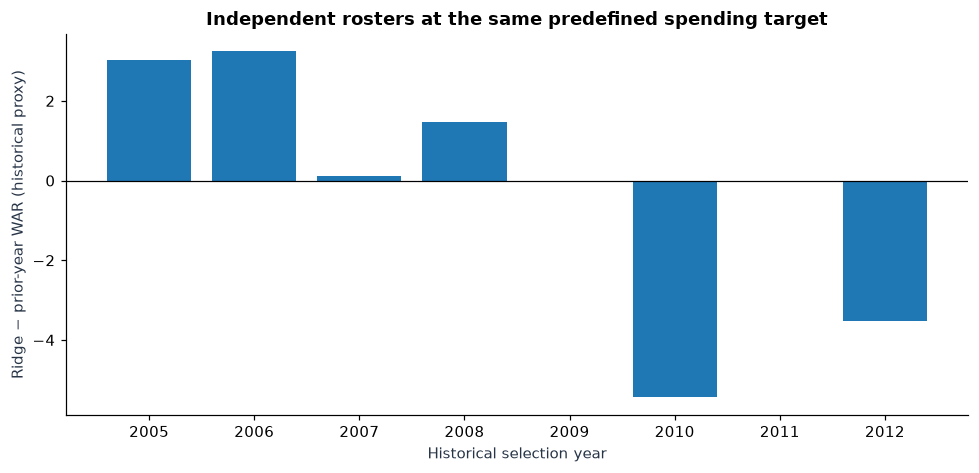

In [93]:
# Independent, pre-specified spending-target roster optimization (no cross-strategy coupling).
from scipy.optimize import milp, Bounds, LinearConstraint
from scipy.sparse import csc_matrix
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

ind78_rows=[];ind78_members=[];solver_attempts78=[]
SPEND_TARGET_RATIO78=.95
SPEND_TOLERANCE78=.01
BAND_LO78=SPEND_TARGET_RATIO78*(1-SPEND_TOLERANCE78)
BAND_HI78=SPEND_TARGET_RATIO78*(1+SPEND_TOLERANCE78)

def independent_milp78(pool, score_column, cap_million, n=8, role_quota=None,
                       solver_label='not_labeled', time_limit=25):
    """Independently solve one historical roster; attach a HiGHS termination audit.

    status=0 is the solver's optimal termination within the requested 0.1% MIP
    relative gap. A feasible incumbent from a time-limited run is retained but
    explicitly NOT labeled a certified optimum. Reject candidate ID duplicates
    before constructing solver variables and validate selected unique IDs again.
    """
    f=pool.reset_index(drop=True)
    attempt={'solve_label':str(solver_label),'objective':score_column,
             'budget_million':float(cap_million),'n_candidates':len(f),
             'solver_status':np.nan,'solver_message':'INPUT_NOT_READY',
             'mip_gap':np.nan,'mip_node_count':np.nan,'mip_dual_bound':np.nan,
             'feasible_incumbent':False,'certified_within_gap':False}
    # Preflight: one optimization decision variable MUST represent one real player.
    # Duplicate IDs could otherwise make an eight-row solution contain fewer than
    # eight people. Fail closed instead of silently deduplicating and changing the pool.
    if 'playerID' not in f.columns:
        attempt['solver_message']='MISSING_PLAYER_ID_COLUMN'
        solver_attempts78.append(attempt)
        raise ValueError('Section 78: candidate pool lacks playerID')
    player_keys78=f['playerID'].astype('string').str.strip()
    if player_keys78.isna().any() or player_keys78.eq('').any():
        attempt['solver_message']='MISSING_OR_BLANK_PLAYER_ID'
        solver_attempts78.append(attempt)
        raise ValueError('Section 78: missing or blank candidate playerID')
    if player_keys78.duplicated().any():
        attempt['solver_message']='DUPLICATE_CANDIDATE_PLAYER_ID'
        solver_attempts78.append(attempt)
        raise ValueError('Section 78: duplicate candidate playerID; inspect source merge keys')
    if not isinstance(n,(int,np.integer)) or n<1 or not np.isfinite(cap_million) or cap_million<=0:
        attempt['solver_message']='INVALID_ROSTER_COUNT_OR_BUDGET'
        solver_attempts78.append(attempt)
        raise ValueError('Section 78: n must be positive and salary cap must be positive')
    if len(f)<n:
        attempt['solver_message']='INSUFFICIENT_CANDIDATES'
        solver_attempts78.append(attempt);return None
    dollars=pd.to_numeric(f.player_salary,errors='coerce').to_numpy(dtype=float)/1e6
    scores=pd.to_numeric(f[score_column],errors='coerce').to_numpy(dtype=float)
    if not (np.isfinite(dollars).all() and np.isfinite(scores).all() and
            np.all(dollars>0)):
        attempt['solver_message']='NONFINITE_OR_NONPOSITIVE_SALARY_OR_SCORE'
        solver_attempts78.append(attempt);return None
    if role_quota and (any(int(q)!=q or q<0 for q in role_quota.values()) or
                       sum(role_quota.values())!=n):
        attempt['solver_message']='INVALID_ROLE_QUOTAS'
        solver_attempts78.append(attempt)
        raise ValueError('Section 78: role quotas must be nonnegative integers summing to n')
    rows=[np.ones(len(f)),dollars]
    low=[n,BAND_LO78*cap_million];high=[n,BAND_HI78*cap_million]
    if role_quota:
        if 'roster_role' not in f:
            attempt['solver_message']='MISSING_ROLE_COLUMN'
            solver_attempts78.append(attempt);return None
        for role,quota in role_quota.items():
            rows.append(f.roster_role.eq(role).astype(int).to_numpy())
            low.append(quota);high.append(quota)
    try:
        res=milp(c=-scores,integrality=np.ones(len(f),dtype=int),
            bounds=Bounds(np.zeros(len(f)),np.ones(len(f))),
            constraints=LinearConstraint(csc_matrix(np.vstack(rows)),low,high),
            options={'time_limit':time_limit,'mip_rel_gap':.001})
    except Exception as exc:
        attempt['solver_message']=f'SOLVER_ERROR: {type(exc).__name__}: {str(exc)[:100]}'
        solver_attempts78.append(attempt);return None
    attempt.update({'solver_status':int(res.status),
                    'solver_message':str(res.message),
                    'mip_gap':getattr(res,'mip_gap',np.nan),
                    'mip_node_count':getattr(res,'mip_node_count',np.nan),
                    'mip_dual_bound':getattr(res,'mip_dual_bound',np.nan)})
    if res.x is None:
        solver_attempts78.append(attempt);return None
    team=f.iloc[np.flatnonzero(res.x>.5)].copy()
    spent=float(team.player_salary.sum())/1e6
    selected_keys78=team['playerID'].astype('string').str.strip()
    distinct_people78=(len(team)==n and selected_keys78.notna().all() and
                       selected_keys78.ne('').all() and selected_keys78.nunique()==n)
    valid=(distinct_people78 and
           BAND_LO78*cap_million-1e-5<=spent<=BAND_HI78*cap_million+1e-5)
    if role_quota:
        valid=valid and all(int(team.roster_role.eq(role).sum())==quota
                            for role,quota in role_quota.items())
    attempt.update({'feasible_incumbent':bool(valid),
                    'certified_within_gap':bool(valid and res.status==0),
                    'actual_spend_million':spent if valid else np.nan})
    solver_attempts78.append(attempt)
    if not valid:return None
    team.attrs['solver_info']=attempt.copy()
    return team

if 'old57' in globals() and 'feature60' in globals() and war52_ready:
    for year78 in range(2005,2013):
        past78=old57[(old57.target_year<year78)&old57.realized_WAR.notna()].dropna(subset=feature60)
        pool78=old57[(old57.target_year==year78)&old57.player_salary.gt(0)].dropna(subset=feature60).copy()
        if len(past78)<200 or len(pool78)<30:
            ind78_rows.append({'year':year78,'status':'INSUFFICIENT_DATA'});continue
        model78=Pipeline([('sc',StandardScaler()),('ridge',Ridge(alpha=50))]).fit(
            past78[feature60],past78.realized_WAR)
        pool78['PredictedWAR']=model78.predict(pool78[feature60]);pool78['PriorWAR']=pool78.WAR
        cap78=max(15.,float(pool78.nsmallest(8,'player_salary').player_salary.sum()/1e6)*2.5)
        a78=independent_milp78(pool78,'PredictedWAR',cap78,n=8,solver_label=f'78_{year78}_Ridge')
        b78=independent_milp78(pool78,'PriorWAR',cap78,n=8,solver_label=f'78_{year78}_Prior')
        if a78 is None or b78 is None:
            ind78_rows.append({'year':year78,'status':'INFEASIBLE_OR_TIMEOUT','cap_million':cap78,
                               'Ridge_feasible':a78 is not None,'Prior_feasible':b78 is not None});continue
        spent_a78=a78.player_salary.sum()/1e6;spent_b78=b78.player_salary.sum()/1e6
        gap78=abs(spent_a78-spent_b78)/((spent_a78+spent_b78)/2)
        assert gap78<=.0200001,'Fixed band did not enforce actual spending parity'
        overlap78=len(set(a78.playerID)&set(b78.playerID))
        row78={'year':year78,'status':'FEASIBLE','cap_million':cap78,'salary_gap_pct':100*gap78,
               'Ridge_spend_M':spent_a78,'Prior_spend_M':spent_b78,
               'Ridge_observed_WAR_sum':a78.realized_WAR.sum(skipna=True),
               'Prior_observed_WAR_sum':b78.realized_WAR.sum(skipna=True),
               'Ridge_missing_WAR':int(a78.realized_WAR.isna().sum()),
               'Prior_missing_WAR':int(b78.realized_WAR.isna().sum()),
               'Ridge_WAR_proxy':a78.realized_WAR.fillna(0).sum(),
               'Prior_WAR_proxy':b78.realized_WAR.fillna(0).sum(),
               'shared_players':overlap78,'selection_design':'Independent fixed 95% target, +/-1%',
               'Ridge_solver_status':a78.attrs['solver_info']['solver_status'],
               'Prior_solver_status':b78.attrs['solver_info']['solver_status'],
               'Ridge_mip_gap':a78.attrs['solver_info']['mip_gap'],
               'Prior_mip_gap':b78.attrs['solver_info']['mip_gap'],
               'Ridge_certified':a78.attrs['solver_info']['certified_within_gap'],
               'Prior_certified':b78.attrs['solver_info']['certified_within_gap']}
        row78['WAR_difference_proxy']=row78['Ridge_WAR_proxy']-row78['Prior_WAR_proxy']
        ind78_rows.append(row78)
        for method78,team78 in [('Ridge WAR',a78),('Previous WAR',b78)]:
            for player78 in team78.itertuples():
                ind78_members.append({'year':year78,'strategy':method78,'playerID':player78.playerID,
                    'salary':player78.player_salary,'realized_next_WAR':player78.realized_WAR,
                    'observed_future_WAR':pd.notna(player78.realized_WAR)})

ind78=pd.DataFrame(ind78_rows)
matched78=ind78[ind78.status.eq('FEASIBLE')].copy() if len(ind78) else pd.DataFrame()
status78='EXECUTED' if len(matched78)>=3 else 'NOT_EVALUATED'
if len(ind78):save_frame(ind78,'submission_78_independent_equal_spend_annual.csv')
if ind78_members:save_frame(pd.DataFrame(ind78_members),'submission_78_independent_equal_spend_members.csv')
if len(matched78):
    display(ind78.round(3))
    stats78=paired_bootstrap68(matched78.WAR_difference_proxy,seed=78,draws=10000)
    print('Independent fixed-target roster comparison:',stats78)
    print('Certified pairs (HiGHS status=0; 0.1% gap tolerance):',
          int((matched78.Ridge_certified & matched78.Prior_certified).sum()),'/',len(matched78))
    if not (matched78.Ridge_certified & matched78.Prior_certified).all():
        print('CAUTION: some feasible teams are incumbent solutions without an optimality certificate.')
    print('Feasible years:',len(matched78),'/ 8; mean actual spending gap (%):',
          round(matched78.salary_gap_pct.mean(),3))
    if len(matched78)<8:print('CAUTION: some historical years are infeasible and are NOT silently excluded from the report.')
    fig,ax=plt.subplots(figsize=(9,4.4))
    ax.bar(matched78.year.astype(str),matched78.WAR_difference_proxy)
    ax.axhline(0,color='black',lw=.8)
    ax.set(xlabel='Historical selection year',ylabel='Ridge − prior-year WAR (historical proxy)',
           title='Independent rosters at the same predefined spending target')
    fig.tight_layout();fig.savefig(VISUALS/'submission_78_independent_equal_spend_WAR.png',bbox_inches='tight');plt.show()
else:
    print('NOT_EVALUATED: insufficient independent fixed-target selections; no performance claim.')

> **Section 78 input-safety correction (earlier revision).** The function rejects missing, blank and duplicate player IDs, and verifies eight distinct selected players. **This uploaded notebook contains a cached execution #98 and saved output**, but no independent source-data replay after that correction is certified here. The cached output should not be taken as verification of the revised code. See `tests/test_section78.py`.


## 79. Check whether conformalized quantile bands hold up

Section 73 estimated lower and upper WAR quantiles directly, but their coverage was below the intended 90% in some seasons. Rolling conformal calibration is added: quantile models learn from earlier years, the next two prior years provide a separate calibration set, and the target season remains untouched until scoring.

The analysis compares direct quantile intervals against calibrated intervals on **the same players with observed future WAR**. Coverage, interval width and the number of evaluated players all matter. This still does not fix the observation bias discussed in Sections 46 and 71.


,year,method,n,coverage,mean_width,calibration_n,correction
0,2009,Direct quantiles,320,0.828,4.995,633,0.000
1,2009,Rolling CQR,320,0.881,5.556,633,0.280
2,2010,Direct quantiles,322,0.885,5.006,630,0.000
3,2010,Rolling CQR,322,0.916,5.659,630,0.327
4,2011,Direct quantiles,319,0.846,5.000,642,0.000
5,2011,Rolling CQR,319,0.887,5.597,642,0.298
6,2012,Direct quantiles,324,0.855,5.033,641,0.000
7,2012,Rolling CQR,324,0.889,5.420,641,0.194


,method,n,coverage,mean_width
0,Direct quantiles,1285,0.854,5.009
1,Rolling CQR,1285,0.893,5.558


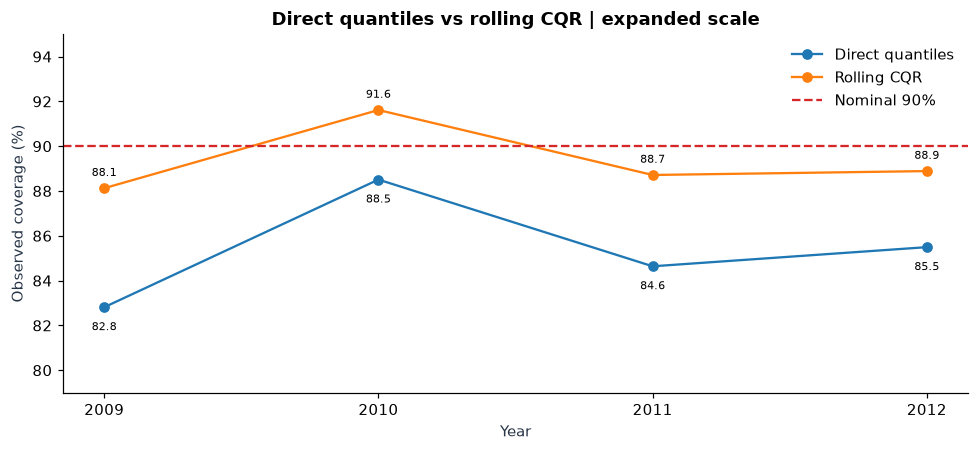

In [94]:
# Rolling conformalized quantile regression (CQR), with strict time separation.
from sklearn.ensemble import HistGradientBoostingRegressor
from math import ceil

cqr79_rows=[]; cqr79_by_player=[]
def corrected_quantile79(v,alpha=.10):
    a=np.sort(np.asarray(v,dtype=float))
    a=a[np.isfinite(a)]
    if not len(a):return np.nan
    k=min(len(a),ceil((len(a)+1)*(1-alpha)))
    return float(a[k-1])

if 'old57' in globals() and war52_ready:
    for y79 in range(2009,2013):
        earlier79=old57.dropna(subset=feature60+['realized_WAR'])
        train79=earlier79[earlier79.target_year<y79-2]
        cal79=earlier79[earlier79.target_year.between(y79-2,y79-1)]
        test79=earlier79[earlier79.target_year==y79]
        if len(train79)<200 or len(cal79)<50 or len(test79)<15:continue
        qs79=[]
        for quant79 in [.05,.95]:
            mdl79=HistGradientBoostingRegressor(loss='quantile',quantile=quant79,
                  max_iter=100,max_leaf_nodes=9,min_samples_leaf=35,
                  l2_regularization=5,random_state=79)
            mdl79.fit(train79[feature60],train79.realized_WAR)
            qs79.append((mdl79.predict(cal79[feature60]),mdl79.predict(test79[feature60])))
        lo_cal79=np.minimum(qs79[0][0],qs79[1][0]);hi_cal79=np.maximum(qs79[0][0],qs79[1][0])
        lo_test79=np.minimum(qs79[0][1],qs79[1][1]);hi_test79=np.maximum(qs79[0][1],qs79[1][1])
        correction79=corrected_quantile79(np.maximum.reduce([lo_cal79-cal79.realized_WAR.to_numpy(),
                   cal79.realized_WAR.to_numpy()-hi_cal79,np.zeros(len(cal79))]))
        yt79=test79.realized_WAR.to_numpy(dtype=float)
        for method79,low79,high79 in [('Direct quantiles',lo_test79,hi_test79),
                         ('Rolling CQR',lo_test79-correction79,hi_test79+correction79)]:
            covered79=(yt79>=low79)&(yt79<=high79)
            cqr79_rows.append({'year':y79,'method':method79,'n':len(test79),
                'coverage':covered79.mean(),'mean_width':(high79-low79).mean(),
                'calibration_n':len(cal79),'correction':correction79 if method79=='Rolling CQR' else 0.})
            cqr79_by_player.extend([{'year':y79,'method':method79,'playerID':p,'covered':c,
               'lower':l,'upper':u,'observed_WAR':r} for p,c,l,u,r in zip(test79.playerID,covered79,low79,high79,yt79)])

cqr79=pd.DataFrame(cqr79_rows)
status79='EXECUTED' if len(cqr79) else 'NOT_EVALUATED'
if len(cqr79):
    display(cqr79.round(3))
    summary79=(cqr79.assign(n_covered=cqr79.n*cqr79.coverage, width_total=cqr79.n*cqr79.mean_width)
                .groupby('method',as_index=False).agg(n=('n','sum'),covered=('n_covered','sum'),total_width=('width_total','sum')))
    summary79['coverage']=summary79.covered/summary79.n
    summary79['mean_width']=summary79.total_width/summary79.n
    display(summary79[['method','n','coverage','mean_width']].round(3))
    save_frame(cqr79,'submission_79_rolling_CQR_yearly.csv')
    save_frame(summary79,'submission_79_rolling_CQR_overall.csv')
    save_frame(pd.DataFrame(cqr79_by_player),'submission_79_rolling_CQR_individual.csv')
    fig,ax=plt.subplots(figsize=(9,4.2))
    for model79,part79 in cqr79.groupby('method'):
        ax.plot(part79.year,100*part79.coverage,'o-',label=model79)
    ax.axhline(90,color='tab:red',ls='--',label='Nominal 90%')
    ax.set(xlabel='Year',ylabel='Observed coverage (%)',ylim=(79,95),
               xticks=sorted(cqr79.year.unique()),title='Direct quantiles vs rolling CQR | expanded scale')
    for model79,part79 in cqr79.groupby('method'):
        for yr79,cov79 in zip(part79.year,part79.coverage*100):
            ax.annotate(f'{cov79:.1f}',(yr79,cov79),xytext=(0,8 if model79=='Rolling CQR' else -15),
                        textcoords='offset points',ha='center',fontsize=7)
    ax.legend(frameon=False);fig.tight_layout()
    fig.savefig(VISUALS/'submission_79_CQR_coverage.png',bbox_inches='tight');plt.show()
else:print('NOT_EVALUATED: missing future WAR observations or insufficient earlier calibration years.')

## 80. Are the independent roster results stable across seasons?

The analysis compares the independently selected, spending-matched teams from Section 78 one season at a time. The whole season is the unit of uncertainty, not each player. The results report mean WAR difference, downside seasons, player overlap, and the number of years for which both selection problems were feasible. An exact sign-flip calculation complements the bootstrap because there are only eight historical seasons, and leaving out one season at a time shows how dependent the average is on any single year.

The mean and confidence interval describe a small retrospective sample, not a guarantee that this approach would beat an MLB front office or a freely available prior-WAR rule.


,paired_seasons,feasible_fraction_of_8,ridge_win_fraction,ridge_tie_fraction,mean_WAR_difference_proxy,CI95_low,CI95_high,worst_20pct_mean_WAR_diff,two_sided_sign_flip_p,leave_one_year_out_mean_min,leave_one_year_out_mean_max,mean_absolute_spend_gap_pct,mean_roster_player_overlap,years_with_unobserved_WAR
0,8,1.0,0.5,0.25,-0.14,-2.159,1.715,-4.48,0.875,-0.623,0.617,0.267,6.25,0


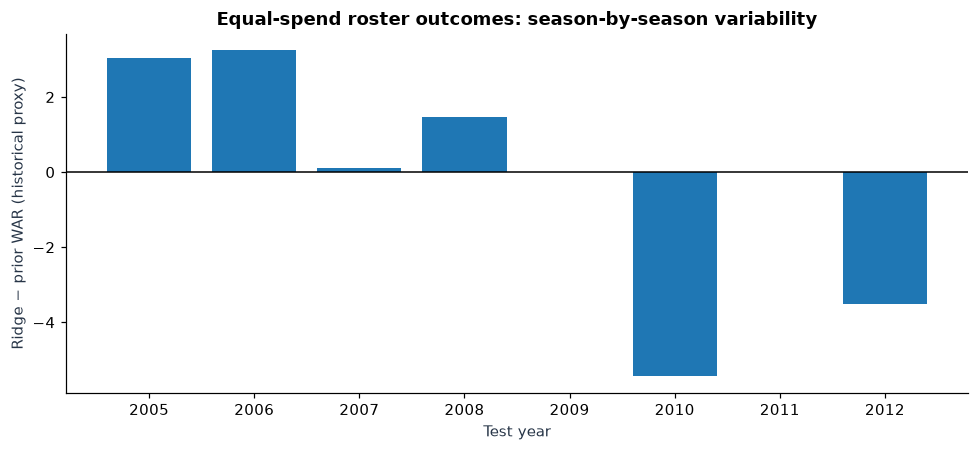

In [95]:
# Paired season uncertainty and downside, restricted to genuine ex-ante matches.
stability80=pd.DataFrame();summary80=pd.DataFrame();status80='NOT_EVALUATED'
if 'matched78' in globals() and len(matched78)>=3:
    stability80=matched78[['year','WAR_difference_proxy','salary_gap_pct','shared_players',
              'Ridge_missing_WAR','Prior_missing_WAR']].copy()
    diff80=stability80.WAR_difference_proxy.to_numpy(dtype=float)
    rng80=np.random.default_rng(800)
    # Resample whole observed years. This keeps all player outcomes within a year paired.
    resampled80=rng80.choice(diff80,size=(15000,len(diff80)),replace=True).mean(axis=1)
    tail_count80=max(1,int(np.ceil(.20*len(diff80))))
    lower_tail80=float(np.sort(diff80)[:tail_count80].mean())
    from itertools import product
    # Two-sided sign-flip check: descriptive symmetry/exchangeability assumption.
    signflip80=np.array([np.mean(diff80*np.array(signs)) for signs in product([-1,1],repeat=len(diff80))])
    p_signflip80=float(np.mean(np.abs(signflip80)>=abs(np.mean(diff80))-1e-12))
    jackknife80=[float(np.delete(diff80,i).mean()) for i in range(len(diff80))]
    summary80=pd.DataFrame([{'paired_seasons':len(diff80),'feasible_fraction_of_8':len(diff80)/8,
       'ridge_win_fraction':np.mean(diff80>0),'ridge_tie_fraction':np.mean(diff80==0),
       'mean_WAR_difference_proxy':diff80.mean(),
       'CI95_low':np.quantile(resampled80,.025),'CI95_high':np.quantile(resampled80,.975),
       'worst_20pct_mean_WAR_diff':lower_tail80,
       'two_sided_sign_flip_p':p_signflip80,
       'leave_one_year_out_mean_min':min(jackknife80),
       'leave_one_year_out_mean_max':max(jackknife80),
       'mean_absolute_spend_gap_pct':stability80.salary_gap_pct.mean(),
       'mean_roster_player_overlap':stability80.shared_players.mean(),
       'years_with_unobserved_WAR':int(((stability80.Ridge_missing_WAR+stability80.Prior_missing_WAR)>0).sum())}])
    status80='EXECUTED'
    display(summary80.round(3))
    save_frame(stability80,'submission_80_independent_roster_yearly_stability.csv')
    save_frame(summary80,'submission_80_independent_roster_stability_summary.csv')
    fig,ax=plt.subplots(figsize=(9,4.2))
    ax.bar(stability80.year.astype(str),stability80.WAR_difference_proxy)
    ax.axhline(0,color='black',lw=1)
    ax.set(xlabel='Test year',ylabel='Ridge − prior WAR (historical proxy)',
           title='Equal-spend roster outcomes: season-by-season variability')
    fig.tight_layout();fig.savefig(VISUALS/'submission_80_roster_stability.png',bbox_inches='tight');plt.show()
else:print('NOT_EVALUATED: fewer than three independently matched seasons; no robustness claim.')

## 81. External validation | 2013–2025, with the historical model frozen

The historical Lahman batting and salary snapshots remain unchanged through 2012 so their results remain comparable. For the external test, two separate newer files are used: `Batting_2025.csv` and `People_2025.csv`. They are used here, not substituted for the original historical inputs.

The test is straightforward: train Ridge on player-seasons with **target years through 2012**, fix the preprocessing, features and Ridge penalty, then evaluate its next-season **Baseball-Reference bWAR** predictions on target years **2013–2025**. The comparison is each player's previous-season WAR. Nothing from a target season is used as a predictor for that season. The scaler is fitted on the historical training cohort only.

The analysis also checks how the errors vary by season, age and previous-season playing time, and counts how many eligible players lack a measured next-season WAR. All headline errors apply only to those with a recorded next-season bWAR: a missing value is **not** treated as zero. For uncertainty, the results report a separate 90% **split-conformal** interval: its Ridge model is fitted on targets through 2008 and its width calibrated on 2009–2012, then both are held fixed for 2013–2025. This interval model is deliberately not identical to the main Ridge model trained through 2012. Future-season distribution shifts and repeated players can affect its coverage.

This is an out-of-period validation of the already-chosen method, not a claim that it was established that every real player could be signed. Post-2012 salary/roster optimization is still outside the scope of these data.

**Short-season check (expanded in Section 86):** The target year 2021 uses batting from the shortened 2020 season; the 200-PA eligibility cutoff selects a much smaller, different group. The results report that season separately instead of smoothing the anomaly away.


New batting archive: 1871–2025; WAR through 2026.
Annual paired MAE difference (Ridge − prior WAR): -0.1879; season-bootstrap 95% interval [-0.2449, -0.1286]


,historical_calibration_players,nominal_coverage,external_coverage,fixed_interval_width_WAR
0,1285,0.9,0.908,5.708


,target_year,n,coverage_90
0,2013,319,0.912
1,2014,333,0.880
2,2015,322,0.904
3,2016,322,0.907
4,2017,313,0.917
5,2018,320,0.922
6,2019,331,0.918
7,2020,332,0.907
8,2021,124,0.726
9,2022,337,0.908


,source,max_year,role
0,historical Batting.csv,2012.0,historical features only
1,Batting_2025.csv,2025.0,2012–2024 features for holdout
2,People_2025.csv,NaN,age and player IDs
3,WAR.csv,2026.0,observed next-season bWAR; tests end in 2025


,training_target_years,holdout_target_years,train_player_seasons,holdout_evaluated_player_seasons,holdout_eligible_player_seasons,Ridge_MAE,previous_WAR_MAE,Ridge_RMSE,previous_WAR_RMSE,mean_annual_Ridge_MAE,mean_annual_previous_MAE
0,1986–2012,2013–2025,8145,4061,4377,1.3112,1.5115,1.6915,1.958,1.3436,1.5316


,target_year,n,Ridge_MAE,previous_WAR_MAE,Ridge_RMSE,previous_WAR_RMSE,eligible_from_prior_season,measured_next_WAR,missing_next_WAR,measured_fraction,Ridge_minus_previous_MAE
0,2013,319,1.3438,1.5049,1.7193,1.9637,345,319,26,0.9246,-0.1611
1,2014,333,1.3718,1.5836,1.7627,2.0718,355,333,22,0.9380,-0.2118
2,2015,322,1.3584,1.6150,1.7932,2.1126,348,322,26,0.9253,-0.2567
3,2016,322,1.3030,1.4312,1.6725,1.8725,350,322,28,0.9200,-0.1282
4,2017,313,1.3232,1.5780,1.6643,1.9397,352,313,39,0.8892,-0.2548
5,2018,320,1.2486,1.5111,1.6142,1.8838,349,320,29,0.9169,-0.2625
6,2019,331,1.3340,1.4502,1.6924,1.8880,355,331,24,0.9324,-0.1162
7,2020,332,1.2468,1.6577,1.5821,2.2337,360,332,28,0.9222,-0.4109
8,2021,124,1.9781,1.9139,2.4942,2.4520,124,124,0,1.0000,0.0642
9,2022,337,1.2535,1.4288,1.6492,1.8663,362,337,25,0.9309,-0.1754


,grouping,group,n,Ridge_MAE,previous_WAR_MAE
0,PA_group,200–299,918,1.0988,1.2146
1,PA_group,300–499,1490,1.2063,1.3490
2,PA_group,500+,1653,1.5237,1.8228
3,age_group,≤26,1251,1.4541,1.5929
4,age_group,27–30,1587,1.3126,1.4988
5,age_group,31–35,1065,1.1750,1.4382
6,age_group,36+,158,1.0847,1.4880


,target_year,eligible_from_prior_season,measured_next_WAR,missing_next_WAR,measured_fraction
0,2013,345,319,26,0.924638
1,2014,355,333,22,0.938028
2,2015,348,322,26,0.925287
3,2016,350,322,28,0.920000
4,2017,352,313,39,0.889205
5,2018,349,320,29,0.916905
6,2019,355,331,24,0.932394
7,2020,360,332,28,0.922222
8,2021,124,124,0,1.000000
9,2022,362,337,25,0.930939


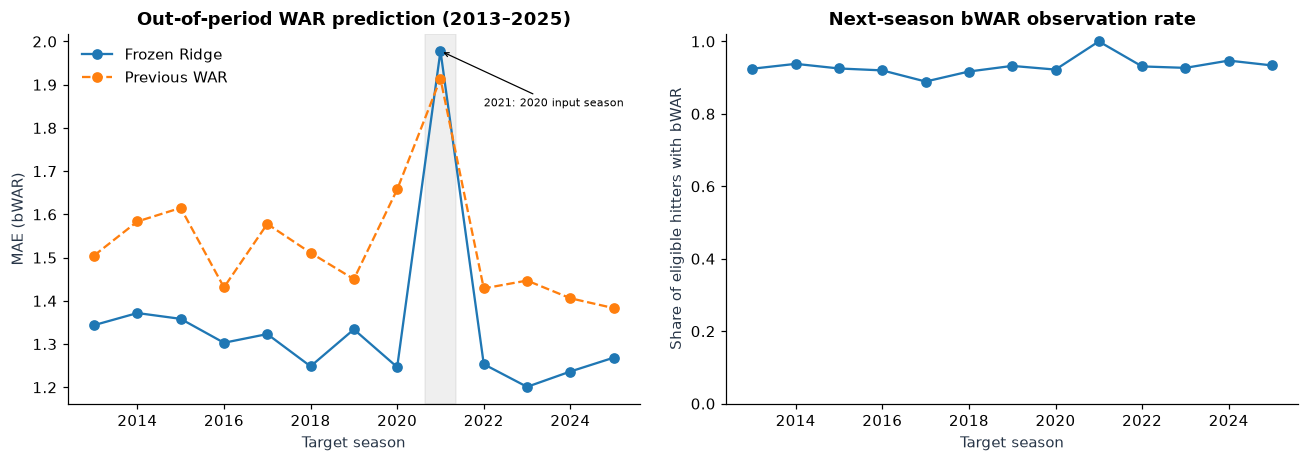

Section 81 external validation status: EXECUTED_ON_2013_2025_DATA


In [96]:
# 81 — Independent post-2012 test: separate source vintages, fixed historical models.
# This cell is intended to run *after* the historical analysis cells.
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error

external81_status = 'NOT_EVALUATED'
external81 = pd.DataFrame()
external_predictions81 = pd.DataFrame()
external_groups81 = pd.DataFrame()
external_summary81 = pd.DataFrame()
external_coverage81 = pd.DataFrame()
external_source81 = pd.DataFrame()
external_interval81 = pd.DataFrame()
external81_message = ''
feature81 = ['WAR', 'PA', 'OBP', 'SLG', 'age']

new_batting81 = DATA_DIR / 'Batting_2025.csv'
new_people81 = DATA_DIR / 'People_2025.csv'
raw_war81 = DATA_DIR / 'WAR.csv'
required81 = [new_batting81, new_people81, raw_war81]
missing81 = [p.name for p in required81 if not p.is_file()]

if missing81:
    external81_status = 'MISSING_EXTERNAL_FILES'
    external81_message = 'Missing: ' + ', '.join(missing81)
    print(external81_message)
elif 'p_all' not in globals() or not war52_ready:
    external81_status = 'MISSING_HISTORICAL_MODEL_INPUTS'
    print('Run the historical player-season and WAR sections before Section 81.')
else:
    # New records must not overwrite the earlier Batting/Master snapshots.
    new_bat81 = pd.read_csv(new_batting81, encoding='utf-8-sig', low_memory=False)
    new_people_df81 = pd.read_csv(new_people81, encoding='utf-8-sig', low_memory=False)
    new_people_df81.columns = new_people_df81.columns.str.replace('\ufeff', '', regex=False).str.strip()
    war_all81 = pd.read_csv(raw_war81, encoding='utf-8-sig', low_memory=False)
    new_bat81.columns = new_bat81.columns.str.replace('\ufeff', '', regex=False).str.strip()
    war_all81.columns = war_all81.columns.str.replace('\ufeff', '', regex=False).str.strip()

    needed_bat81 = {'playerID','yearID','AB','H','2B','3B','HR','BB','SO','HBP','SF','SH','SB','CS','G','R'}
    needed_people81 = {'playerID','nameFirst','nameLast','birthYear','bats'}
    needed_war81 = {'playerID','yearID','WAR'}
    for label81, frame81, need81 in [
        ('Batting_2025.csv', new_bat81, needed_bat81),
        ('People_2025.csv', new_people_df81, needed_people81),
        ('WAR.csv', war_all81, needed_war81)]:
        diff81 = need81 - set(frame81.columns)
        if diff81:
            raise ValueError(f'{label81} is missing required columns: {sorted(diff81)}')

    for frame81 in (new_bat81, war_all81):
        frame81['yearID'] = pd.to_numeric(frame81['yearID'], errors='coerce')
    war_all81['WAR'] = pd.to_numeric(war_all81['WAR'], errors='coerce')
    war_all81 = war_all81.dropna(subset=['playerID','yearID']).copy()
    if war_all81.duplicated(['playerID','yearID']).any():
        raise ValueError('WAR.csv has duplicate (playerID, yearID) rows; cannot validate one-to-one matches.')
    new_people_df81 = new_people_df81.drop_duplicates('playerID').copy()
    new_people_df81['birthYear'] = pd.to_numeric(new_people_df81['birthYear'], errors='coerce')

    # player_seasons aggregates traded players' stints before rate calculation.
    people_master81 = new_people_df81.reindex(columns=raw['master'].columns)
    recent_player81 = player_seasons({'batting':new_bat81,'master':people_master81})
    new_batting_max81 = int(new_bat81['yearID'].max())
    new_batting_min81 = int(new_bat81['yearID'].min())
    war_max81 = int(war_all81['yearID'].max())
    available_test_max81 = min(2025, new_batting_max81, war_max81)
    external_source81 = pd.DataFrame([
        {'source':'historical Batting.csv','max_year':int(p_all.yearID.max()),'role':'historical features only'},
        {'source':'Batting_2025.csv','max_year':new_batting_max81,'role':'2012–2024 features for holdout'},
        {'source':'People_2025.csv','max_year':np.nan,'role':'age and player IDs'},
        {'source':'WAR.csv','max_year':war_max81,'role':'observed next-season bWAR; tests end in 2025'},
    ])
    print(f'New batting archive: {new_batting_min81}–{new_batting_max81}; WAR through {war_max81}.')

    historical_war81 = w52[['playerID','yearID','WAR']].copy()  # w52 was capped at 2012.
    history81 = p_all[['playerID','yearID','PA','OBP','SLG','age']].merge(
        historical_war81,on=['playerID','yearID'],how='inner',validate='one_to_one')
    history81 = history81[history81.PA.ge(200)].dropna(subset=feature81).copy()
    historical_next81 = historical_war81.rename(columns={'WAR':'next_WAR'}).copy()
    historical_next81['yearID'] -= 1
    history81 = history81.merge(historical_next81,on=['playerID','yearID'],how='inner',validate='one_to_one')
    history81['target_year'] = history81.yearID + 1
    train81 = history81[history81.target_year.le(2012)].dropna(subset=['next_WAR']).copy()

    # Out-of-period features are taken ONLY from the new batting archive.
    holdout81 = recent_player81[['playerID','yearID','PA','OBP','SLG','age']].merge(
        war_all81[['playerID','yearID','WAR']],on=['playerID','yearID'],
        how='inner',validate='one_to_one')
    holdout81 = holdout81[
        holdout81.yearID.between(2012, available_test_max81-1) & holdout81.PA.ge(200)
    ].dropna(subset=feature81).copy()
    following_war81 = war_all81[['playerID','yearID','WAR']].rename(columns={'WAR':'next_WAR'}).copy()
    following_war81['yearID'] -= 1
    # Keep left join to count missing outcome rather than silently dropping those players.
    holdout81 = holdout81.merge(following_war81,on=['playerID','yearID'],how='left',validate='one_to_one')
    holdout81['target_year'] = holdout81.yearID + 1
    holdout81['observed_next_WAR'] = holdout81.next_WAR.notna()

    if len(train81) < 400 or holdout81.observed_next_WAR.sum() < 50 or available_test_max81 < 2013:
        external81_status = 'INSUFFICIENT_EXTERNAL_MATCHES'
        print(f'External holdout insufficient: historical training={len(train81)}, '
              f'observed future WAR={int(holdout81.observed_next_WAR.sum())}, '
              f'latest possible test year={available_test_max81}.')
    else:
        # Frozen fit: all preprocessing and parameter values are set before target 2013.
        frozen81 = Pipeline([
            ('standardize',StandardScaler()), ('ridge',Ridge(alpha=50.0))
        ]).fit(train81[feature81],train81.next_WAR)
        holdout81['pred_Ridge'] = frozen81.predict(holdout81[feature81])
        holdout81['pred_previous_WAR'] = holdout81.WAR
        external_predictions81 = holdout81.copy()
        external_predictions81['abs_Ridge_error'] = (holdout81.next_WAR-holdout81.pred_Ridge).abs()
        external_predictions81['abs_previous_error'] = (holdout81.next_WAR-holdout81.pred_previous_WAR).abs()
        external_predictions81['squared_Ridge_error'] = (holdout81.next_WAR-holdout81.pred_Ridge)**2
        external_predictions81['squared_previous_error'] = (holdout81.next_WAR-holdout81.pred_previous_WAR)**2
        external_predictions81['PA_group'] = pd.cut(holdout81.PA,[199,299,499,np.inf],labels=['200–299','300–499','500+'])
        external_predictions81['age_group'] = pd.cut(holdout81.age,[-np.inf,26,30,35,np.inf],labels=['≤26','27–30','31–35','36+'])

        # Missing next-year bWAR is not an actual zero. Metrics exclude those rows.
        observed81 = external_predictions81[external_predictions81.observed_next_WAR].copy()
        external_coverage81 = external_predictions81.groupby('target_year',as_index=False).agg(
            eligible_from_prior_season=('playerID','size'),
            measured_next_WAR=('observed_next_WAR','sum'))
        external_coverage81['missing_next_WAR'] = (external_coverage81.eligible_from_prior_season
                                                   -external_coverage81.measured_next_WAR)
        external_coverage81['measured_fraction'] = (external_coverage81.measured_next_WAR
                                                   /external_coverage81.eligible_from_prior_season)
        year_rows81 = []
        for yr81,g81 in observed81.groupby('target_year'):
            year_rows81.append({
                'target_year':int(yr81), 'n':len(g81),
                'Ridge_MAE':mean_absolute_error(g81.next_WAR,g81.pred_Ridge),
                'previous_WAR_MAE':mean_absolute_error(g81.next_WAR,g81.pred_previous_WAR),
                'Ridge_RMSE':np.sqrt(mean_squared_error(g81.next_WAR,g81.pred_Ridge)),
                'previous_WAR_RMSE':np.sqrt(mean_squared_error(g81.next_WAR,g81.pred_previous_WAR))})
        external81 = pd.DataFrame(year_rows81).merge(
            external_coverage81,on='target_year',how='left',validate='one_to_one')
        external81['Ridge_minus_previous_MAE'] = external81.Ridge_MAE-external81.previous_WAR_MAE
        external_summary81 = pd.DataFrame([{
            'training_target_years':f"{int(train81.target_year.min())}–{int(train81.target_year.max())}",
            'holdout_target_years':f"{int(observed81.target_year.min())}–{int(observed81.target_year.max())}",
            'train_player_seasons':len(train81),
            'holdout_evaluated_player_seasons':len(observed81),
            'holdout_eligible_player_seasons':len(external_predictions81),
            'Ridge_MAE':observed81.abs_Ridge_error.mean(),
            'previous_WAR_MAE':observed81.abs_previous_error.mean(),
            'Ridge_RMSE':np.sqrt(observed81.squared_Ridge_error.mean()),
            'previous_WAR_RMSE':np.sqrt(observed81.squared_previous_error.mean()),
            'mean_annual_Ridge_MAE':external81.Ridge_MAE.mean(),
            'mean_annual_previous_MAE':external81.previous_WAR_MAE.mean(),
        }])
        # Seasons, not individual players, are resampled for the uncertainty check.
        annual_delta81 = external81.Ridge_minus_previous_MAE.to_numpy()
        rng81 = np.random.default_rng(81)
        block_means81 = rng81.choice(annual_delta81,size=(5000,len(annual_delta81)),replace=True).mean(axis=1)
        ci81 = np.quantile(block_means81,[.025,.975])
        print(f'Annual paired MAE difference (Ridge − prior WAR): {annual_delta81.mean():+.4f}; '
              f'season-bootstrap 95% interval [{ci81[0]:+.4f}, {ci81[1]:+.4f}]')
        group_rows81=[]
        for group_col81 in ['PA_group','age_group']:
            for group_value81,g81 in observed81.groupby(group_col81,observed=True):
                if len(g81)<20: continue
                group_rows81.append({'grouping':group_col81,'group':str(group_value81),'n':len(g81),
                    'Ridge_MAE':g81.abs_Ridge_error.mean(),
                    'previous_WAR_MAE':g81.abs_previous_error.mean()})
        external_groups81=pd.DataFrame(group_rows81)

        # Separate true split-conformal evaluation: fit <=2008, calibrate 2009–12.
        older81=train81[train81.target_year.le(2008)].copy()
        calib81=train81[train81.target_year.between(2009,2012)].copy()
        if len(older81)>=400 and len(calib81)>=100:
            interval_model81 = Pipeline([
                ('standardize',StandardScaler()), ('ridge',Ridge(alpha=50.0))
            ]).fit(older81[feature81],older81.next_WAR)
            cal_resid81 = np.abs(calib81.next_WAR.to_numpy()-interval_model81.predict(calib81[feature81]))
            # Finite-sample conformal quantile, conservatively rounded upward.
            kth81 = min(len(cal_resid81),int(np.ceil((len(cal_resid81)+1)*.9)))
            q81 = np.partition(cal_resid81,kth81-1)[kth81-1]
            interval_center81=interval_model81.predict(observed81[feature81])
            external_interval81=observed81[['playerID','yearID','target_year','next_WAR','age','PA']].copy()
            external_interval81['prediction'] = interval_center81
            external_interval81['lower_90'] = interval_center81-q81
            external_interval81['upper_90'] = interval_center81+q81
            external_interval81['covered_90'] = (
                observed81.next_WAR.between(external_interval81.lower_90,external_interval81.upper_90))
            coverage_by_year81 = external_interval81.groupby('target_year',as_index=False).agg(
                n=('covered_90','size'),coverage_90=('covered_90','mean'))
            display(pd.DataFrame([{'historical_calibration_players':len(calib81),
                'nominal_coverage':.9, 'external_coverage':external_interval81.covered_90.mean(),
                'fixed_interval_width_WAR':2*q81}]).round(3))
            display(coverage_by_year81.round(3))
            save_frame(coverage_by_year81,'external_81_split_conformal_coverage_by_year.csv')
            save_frame(external_interval81,'external_81_split_conformal_player_predictions.csv')

        external81_status = ('EXECUTED_ON_2013_2025_DATA'
              if set(observed81.target_year.astype(int)) == set(range(2013,2026))
              else 'EXECUTED_ON_PARTIAL_NEWER_DATA')
        display(external_source81)
        display(external_summary81.round(4))
        display(external81.round(4))
        display(external_groups81.round(4))
        display(external_coverage81)
        save_frame(external_source81,'external_81_data_lineage.csv')
        save_frame(external_summary81,'external_81_frozen_model_summary.csv')
        save_frame(external81,'external_81_year_by_year_metrics.csv')
        save_frame(external_groups81,'external_81_pa_age_group_metrics.csv')
        save_frame(external_coverage81,'external_81_war_observation_coverage.csv')
        save_frame(external_predictions81,'external_81_all_eligible_player_predictions.csv')
        fig,axes=plt.subplots(1,2,figsize=(12,4.3))
        axes[0].plot(external81.target_year,external81.Ridge_MAE,'o-',label='Frozen Ridge')
        axes[0].plot(external81.target_year,external81.previous_WAR_MAE,'o--',label='Previous WAR')
        axes[0].set(title='Out-of-period WAR prediction (2013–2025)',xlabel='Target season',ylabel='MAE (bWAR)')
        axes[0].legend(frameon=False)
        axes[0].axvspan(2020.65,2021.35,color='gray',alpha=.12)
        axes[0].annotate('2021: 2020 input season',xy=(2021,float(external81.loc[external81.target_year.eq(2021),'Ridge_MAE'].iloc[0])),
                         xytext=(2022,1.85),fontsize=7,arrowprops={'arrowstyle':'->','lw':.8})
        axes[1].plot(external_coverage81.target_year,external_coverage81.measured_fraction,'o-')
        axes[1].set(title='Next-season bWAR observation rate',xlabel='Target season',ylabel='Share of eligible hitters with bWAR',ylim=(0,1.02))
        fig.tight_layout()
        fig.savefig(VISUALS/'external_81_2013_2025_war_validation.png',dpi=160,bbox_inches='tight')
        plt.show()

print('Section 81 external validation status:',external81_status)


## 82. Compare interval methods on exactly the same players

Sections 75 and 79 each report useful uncertainty estimates, but the headline coverage numbers only mean something when the evaluations use the same players and years. The player-season rows are aligned before **actual coverage and mean interval width** are compared for pooled conformal, PA-group conformal and rolling CQR. Prior-year PA bands are retained to check if the overall result hides a weak subgroup. No tuning is performed on this comparison sample.


,method,n,coverage,mean_width
0,PA-group calibration,1285,0.902,5.813
1,Pooled calibration,1285,0.907,5.894
2,Rolling CQR,1285,0.893,5.558


,method,pa_band,n,coverage,mean_width,wilson95_low,wilson95_high
0,PA-group calibration,300–499,453,0.887,5.163,0.855,0.913
1,PA-group calibration,500+,589,0.908,6.689,0.882,0.929
2,PA-group calibration,<300,243,0.914,4.902,0.872,0.943
3,Pooled calibration,300–499,453,0.929,5.898,0.902,0.950
4,Pooled calibration,500+,589,0.868,5.897,0.838,0.893
5,Pooled calibration,<300,243,0.963,5.877,0.931,0.980
6,Rolling CQR,300–499,453,0.898,5.255,0.867,0.923
7,Rolling CQR,500+,589,0.883,6.268,0.854,0.906
8,Rolling CQR,<300,243,0.909,4.399,0.867,0.939


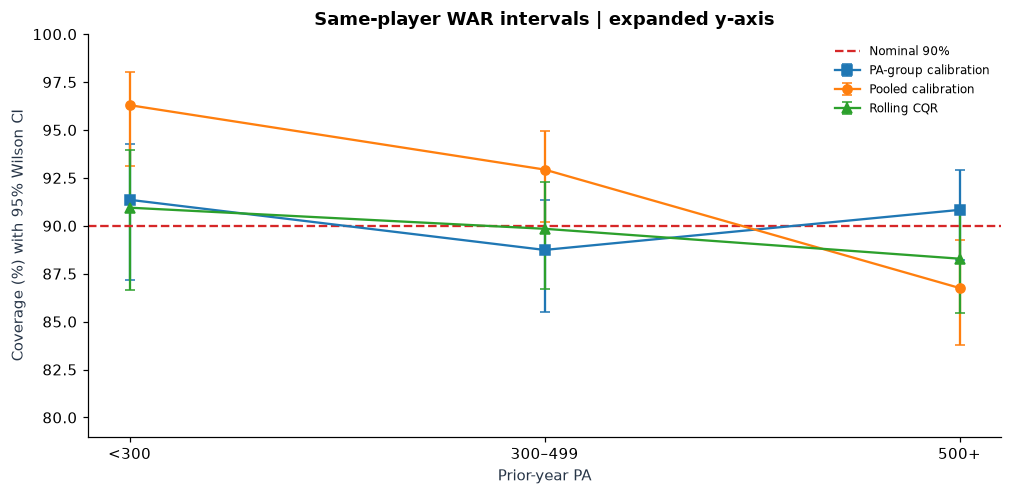

Section 82: EXECUTED


In [97]:
# Fair, player-season-matched evaluation of existing 75/79 interval predictions.
interval82=pd.DataFrame();interval_summary82=pd.DataFrame();status82='NOT_EVALUATED'
if 'pred75' in globals() and 'cqr79_by_player' in globals() and len(cqr79_by_player):
    pooled82=pred75[['year','playerID','pa_band','method','covered','width']].copy()
    cqr82=pd.DataFrame(cqr79_by_player)
    cqr82=cqr82[cqr82.method.eq('Rolling CQR')].copy()
    cqr82['width']=cqr82.upper-cqr82.lower
    pool_idx82=pooled82[pooled82.method.eq('Pooled calibration')][['year','playerID','pa_band']].drop_duplicates()
    cqr_idx82=cqr82[['year','playerID']].drop_duplicates()
    shared_idx82=pool_idx82.merge(cqr_idx82,on=['year','playerID'],how='inner',validate='one_to_one')
    parts82=[]
    for method82,data82 in [('Pooled calibration',pooled82[pooled82.method.eq('Pooled calibration')]),
                             ('PA-group calibration',pooled82[pooled82.method.eq('PA-group calibration')]),
                             ('Rolling CQR',cqr82)]:
        part82=shared_idx82[['year','playerID','pa_band']].merge(
            data82[['year','playerID','covered','width']],on=['year','playerID'],
            how='inner',validate='one_to_one')
        part82['method']=method82
        parts82.append(part82)
    interval82=pd.concat(parts82,ignore_index=True)
    count82=interval82.groupby('method').size()
    if len(count82)==3 and count82.nunique()==1 and int(count82.min())>=100:
        rows82=[]
        for (method82,pa82),g82 in interval82.groupby(['method','pa_band']):
            lo82,hi82=wilson_ci(int(g82.covered.sum()),len(g82))
            rows82.append({'method':method82,'pa_band':pa82,'n':len(g82),
                           'coverage':g82.covered.mean(),'mean_width':g82.width.mean(),
                           'wilson95_low':lo82,'wilson95_high':hi82})
        interval_summary82=pd.DataFrame(rows82)
        overall82=interval82.groupby('method',as_index=False).agg(
            n=('covered','size'),coverage=('covered','mean'),mean_width=('width','mean'))
        status82='EXECUTED'
        display(overall82.round(3));display(interval_summary82.round(3))
        save_frame(overall82,'submission_82_interval_methods_same_players.csv')
        save_frame(interval_summary82,'submission_82_interval_methods_by_PA.csv')
        fig,ax=plt.subplots(figsize=(9.3,4.6))
        band_list82=['<300','300–499','500+']
        markers82={'Pooled calibration':'o','PA-group calibration':'s','Rolling CQR':'^'}
        for method82,group82 in interval_summary82.groupby('method'):
            order82=group82.set_index('pa_band').reindex(band_list82)
            cov82=100*order82.coverage.to_numpy()
            err82=np.vstack([100*(order82.coverage-order82.wilson95_low).to_numpy(),
                            100*(order82.wilson95_high-order82.coverage).to_numpy()])
            ax.errorbar(np.arange(3),cov82,yerr=err82,fmt=markers82.get(method82,'o')+'-',
                        capsize=3,linewidth=1.5,label=method82)
        ax.axhline(90,ls='--',color='tab:red',label='Nominal 90%')
        ax.set(xlabel='Prior-year PA',ylabel='Coverage (%) with 95% Wilson CI',
               xticks=np.arange(3),xticklabels=band_list82,ylim=(79,100),
               title='Same-player WAR intervals | expanded y-axis')
        ax.legend(frameon=False,fontsize=8)
        fig.tight_layout()
        fig.savefig(VISUALS/'submission_82_interval_coverage_same_players.png',dpi=160,bbox_inches='tight')
        plt.show()
    else:print('NOT_EVALUATED: interval prediction sets did not align across methods.')
else:print('NOT_EVALUATED: requires evaluated Sections 75 and 79.')
print('Section 82:',status82)

## 83. What changes when the roster needs fielders at specific positions?

The eight-player rosters in Section 78 ignore positions. These rosters can compare scores but are not full baseball lineups. A more constrained hitter selection is tested: one catcher, one each at first, second, third and shortstop, and three outfielders. The assigned group comes from **prior-season appearances**, never next-season playing time.

Each strategy still solves its own optimization and uses the same fixed salary target from Section 78. Infeasibility is reported explicitly because a strict spending band and position requirements can be hard to satisfy at once. These are eight-hitter combinations, not full 26-player MLB rosters. The primary-position grouping ignores fielding versatility and defense quality, so it remains a simplified sensitivity check.

The analysis checks the optimization termination for both strategies separately. A feasible roster is not automatically a proven optimal roster, and a low number of available players in a position can make this comparison fragile.


In [98]:
# Position-aware, independently optimized eight-hitter rosters with identical spending target.
position83=pd.DataFrame();status83='NOT_EVALUATED';rows83=[]
app83=DATA_DIR/'Appearances.csv'
role_cols83={'C':'G_c','1B':'G_1b','2B':'G_2b','3B':'G_3b','SS':'G_ss','OF':'G_of'}
role_quota83={'C':1,'1B':1,'2B':1,'3B':1,'SS':1,'OF':3}
if app83.is_file() and war52_ready and 'old57' in globals():
    ap83=pd.read_csv(app83,encoding='utf-8-sig',low_memory=False)
    if {'playerID','yearID',*role_cols83.values()}.issubset(ap83.columns):
        ap83[list(role_cols83.values())]=ap83[list(role_cols83.values())].apply(pd.to_numeric,errors='coerce').fillna(0)
        app_group83=ap83.groupby(['playerID','yearID'],as_index=False)[list(role_cols83.values())].sum()
        app_group83['roster_role']=app_group83[list(role_cols83.values())].idxmax(axis=1).map(
            {column:role for role,column in role_cols83.items()})
        app_group83.loc[app_group83[list(role_cols83.values())].max(axis=1).eq(0),'roster_role']=np.nan
        for yr83 in range(2005,2013):
            prior83=old57[(old57.target_year<yr83)&old57.realized_WAR.notna()].dropna(subset=feature60)
            pool83=old57[(old57.target_year==yr83)&old57.player_salary.gt(0)].dropna(subset=feature60).copy()
            pool83=pool83.merge(app_group83[['playerID','yearID','roster_role']],
                on=['playerID','yearID'],how='left',validate='one_to_one').dropna(subset=['roster_role'])
            if len(prior83)<200 or any(pool83.roster_role.eq(r).sum()<q for r,q in role_quota83.items()):
                rows83.append({'year':yr83,'status':'MISSING_PRIOR_ROLES_OR_TRAINING'});continue
            score83=Pipeline([('sc',StandardScaler()),('ridge',Ridge(alpha=50))]).fit(
                prior83[feature60],prior83.realized_WAR)
            pool83['PredictedWAR']=score83.predict(pool83[feature60]);pool83['PriorWAR']=pool83.WAR
            cap83=(float(ind78.loc[ind78.year.eq(yr83),'cap_million'].iloc[0])
                   if 'ind78' in globals() and (ind78.year.eq(yr83)).any()
                   else max(15.,float(pool83.nsmallest(8,'player_salary').player_salary.sum()/1e6)*2.5))
            a83=independent_milp78(pool83,'PredictedWAR',cap83,n=8,role_quota=role_quota83,solver_label=f'83_{yr83}_Ridge')
            b83=independent_milp78(pool83,'PriorWAR',cap83,n=8,role_quota=role_quota83,solver_label=f'83_{yr83}_Prior')
            if a83 is None or b83 is None:
                rows83.append({'year':yr83,'status':'ROLE_OR_BUDGET_INFEASIBLE','cap_million':cap83});continue
            sa83=a83.player_salary.sum()/1e6;sb83=b83.player_salary.sum()/1e6
            diff83=abs(sa83-sb83)/((sa83+sb83)/2)
            assert diff83<=.0200001
            rows83.append({'year':yr83,'status':'FEASIBLE','cap_million':cap83,
                 'salary_gap_pct':100*diff83,'Ridge_spend_M':sa83,'Prior_spend_M':sb83,
                 'Ridge_missing_WAR':int(a83.realized_WAR.isna().sum()),
                 'Prior_missing_WAR':int(b83.realized_WAR.isna().sum()),
                 'WAR_difference_proxy':a83.realized_WAR.fillna(0).sum()-b83.realized_WAR.fillna(0).sum(),
                 'shared_players':len(set(a83.playerID)&set(b83.playerID)),
                 'Ridge_solver_status':a83.attrs['solver_info']['solver_status'],
                 'Prior_solver_status':b83.attrs['solver_info']['solver_status'],
                 'Ridge_mip_gap':a83.attrs['solver_info']['mip_gap'],
                 'Prior_mip_gap':b83.attrs['solver_info']['mip_gap'],
                 'Ridge_certified':a83.attrs['solver_info']['certified_within_gap'],
                 'Prior_certified':b83.attrs['solver_info']['certified_within_gap']})
        position83=pd.DataFrame(rows83)
        if len(position83):
            status83='EXECUTED' if position83.status.eq('FEASIBLE').any() else 'NOT_EVALUATED'
            display(position83.round(3))
            save_frame(position83,'submission_83_position_constrained_equal_spend.csv')
            print('Position-constrained feasible seasons:',int(position83.status.eq('FEASIBLE').sum()),'/8')
            feasible83=position83.loc[position83.status.eq('FEASIBLE')]
            if len(feasible83):
                print('Certified role-constrained pairs:',int((feasible83.Ridge_certified & feasible83.Prior_certified).sum()),'/',len(feasible83))
                if not (feasible83.Ridge_certified & feasible83.Prior_certified).all():
                    print('CAUTION: role-constrained feasible results include uncertified incumbent solutions.')
        else:print('NOT_EVALUATED: no role-constrained seasons processed.')
    else:print('NOT_EVALUATED: expected Appearances position columns are missing.')
else:print('NOT_EVALUATED: Appearances or WAR file missing.')
print('Section 83:',status83)

,year,status,cap_million,salary_gap_pct,Ridge_spend_M,Prior_spend_M,Ridge_missing_WAR,Prior_missing_WAR,WAR_difference_proxy,shared_players,Ridge_solver_status,Prior_solver_status,Ridge_mip_gap,Prior_mip_gap,Ridge_certified,Prior_certified
0,2005,FEASIBLE,15.0,0.671,14.214,14.120,0,0,1.75,5,0,0,0.001,0.000,True,True
1,2006,FEASIBLE,15.0,0.000,14.149,14.149,0,0,0.00,8,0,0,0.001,0.000,True,True
2,2007,FEASIBLE,15.0,0.146,14.122,14.142,0,0,9.44,4,0,0,0.000,0.001,True,True
3,2008,FEASIBLE,15.0,0.077,14.367,14.356,0,0,6.14,7,0,0,0.000,0.000,True,True
4,2009,FEASIBLE,15.0,0.000,14.322,14.322,0,0,0.00,8,0,0,0.000,0.001,True,True
5,2010,FEASIBLE,15.0,0.000,14.244,14.244,0,0,0.00,8,0,0,0.000,0.000,True,True
6,2011,FEASIBLE,15.0,0.000,14.164,14.164,0,0,0.00,8,0,0,0.000,0.001,True,True
7,2012,FEASIBLE,15.0,0.070,14.302,14.292,0,0,-1.85,7,0,0,0.000,0.000,True,True


Position-constrained feasible seasons: 8 /8
Certified role-constrained pairs: 8 / 8
Section 83: EXECUTED


## 84. Do uncertainty-method differences hold up across seasons?

Section 82 compared prediction intervals on the same players. The analysis uses the **season**, rather than each player, as the resampling unit. This matters because players in the same season face similar conditions, so pretending that all 1,285 player-seasons are independent would make the comparison look more precise than it is.

The results report year-by-year coverage and width, then bootstrap entire evaluation years to compare each method against the pooled baseline. There are only four test seasons, so the resulting ranges can be wide. These results are treated them as a check on robustness, not a formal claim that one interval method is always best.


,year,method,n,coverage,mean_width
0,2009,PA-group calibration,320,0.875,5.685
1,2009,Pooled calibration,320,0.884,5.815
2,2009,Rolling CQR,320,0.881,5.556
3,2010,PA-group calibration,322,0.929,6.090
4,2010,Pooled calibration,322,0.922,6.142
5,2010,Rolling CQR,322,0.916,5.659
6,2011,PA-group calibration,319,0.890,5.811
7,2011,Pooled calibration,319,0.900,5.896
8,2011,Rolling CQR,319,0.887,5.597
9,2012,PA-group calibration,324,0.914,5.667


,alternative,reference,n_test_seasons,year_equal_weight_coverage_delta_pp,coverage_delta_CI95_low_pp,coverage_delta_CI95_high_pp,year_equal_weight_width_delta_WAR,width_delta_CI95_low_WAR,width_delta_CI95_high_WAR
0,PA-group calibration,Pooled calibration,4,-0.546,-0.939,0.231,-0.081,-0.112,-0.054
1,Rolling CQR,Pooled calibration,4,-1.396,-2.702,-0.467,-0.336,-0.437,-0.270


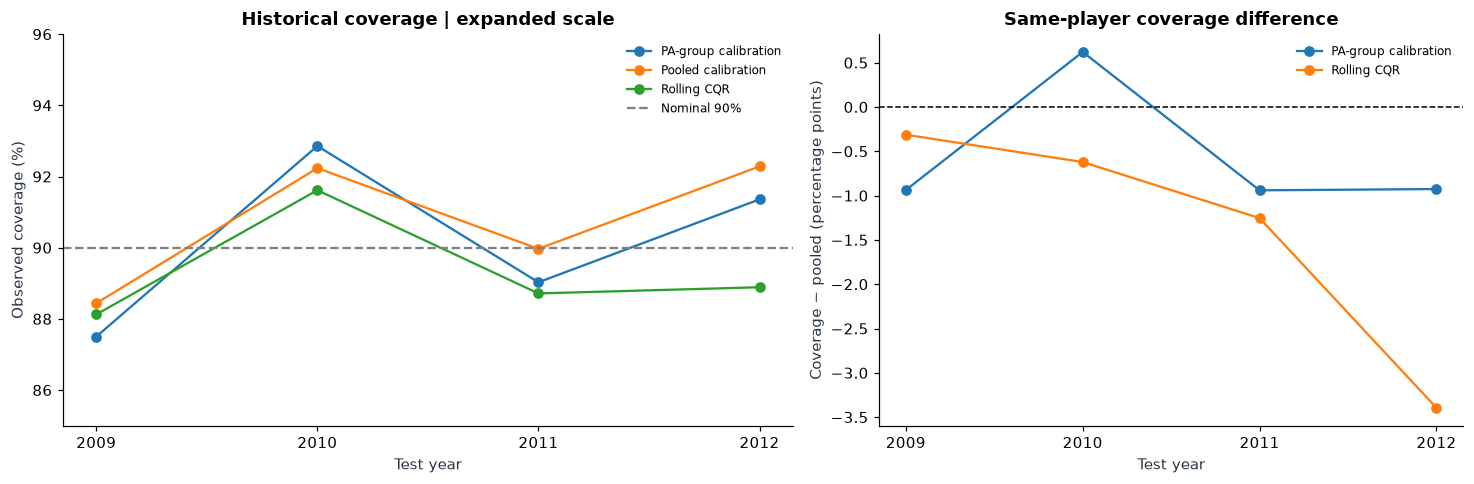

Only 4 test seasons: uncertainty ranges are descriptive.
Section 84: EXECUTED


In [99]:
# Whole-season uncertainty comparison for the same players in Section 82.
season84=pd.DataFrame();comparison84=pd.DataFrame();status84='NOT_EVALUATED'
if 'interval82' in globals() and isinstance(interval82,pd.DataFrame) and not interval82.empty:
    season84=interval82.groupby(['year','method'],as_index=False).agg(
        n=('covered','size'),coverage=('covered','mean'),mean_width=('width','mean'))
    year_methods84=season84.pivot(index='year',columns='method',values='coverage')
    year_widths84=season84.pivot(index='year',columns='method',values='mean_width')
    required84=['Pooled calibration','PA-group calibration','Rolling CQR']
    complete_years84=year_methods84.dropna(subset=required84).index.intersection(
        year_widths84.dropna(subset=required84).index)
    if len(complete_years84)>=3:
        rng84=np.random.default_rng(84)
        records84=[]
        for alternative84 in required84[1:]:
            diffcov84=(year_methods84.loc[complete_years84,alternative84]
                       -year_methods84.loc[complete_years84,required84[0]]).to_numpy(float)
            diffwid84=(year_widths84.loc[complete_years84,alternative84]
                       -year_widths84.loc[complete_years84,required84[0]]).to_numpy(float)
            pick84=rng84.integers(0,len(complete_years84),size=(8000,len(complete_years84)))
            means84=diffcov84[pick84].mean(axis=1)
            width_means84=diffwid84[pick84].mean(axis=1)
            records84.append({'alternative':alternative84,'reference':required84[0],
                'n_test_seasons':len(complete_years84),
                'year_equal_weight_coverage_delta_pp':100*diffcov84.mean(),
                'coverage_delta_CI95_low_pp':100*np.quantile(means84,.025),
                'coverage_delta_CI95_high_pp':100*np.quantile(means84,.975),
                'year_equal_weight_width_delta_WAR':diffwid84.mean(),
                'width_delta_CI95_low_WAR':np.quantile(width_means84,.025),
                'width_delta_CI95_high_WAR':np.quantile(width_means84,.975)})
        comparison84=pd.DataFrame(records84)
        status84='EXECUTED'
        display(season84.round(3));display(comparison84.round(3))
        save_frame(season84,'submission_84_interval_methods_by_season.csv')
        save_frame(comparison84,'submission_84_season_block_interval_comparison.csv')
        fig,axes84=plt.subplots(1,2,figsize=(13.5,4.5),gridspec_kw={'width_ratios':[1.25,1]})
        for method84,g84 in season84.groupby('method'):
            axes84[0].plot(g84.year,100*g84.coverage,'o-',label=method84)
        axes84[0].axhline(90,color='gray',ls='--',label='Nominal 90%')
        vals84=100*year_methods84.loc[complete_years84].to_numpy()
        axes84[0].set(xlabel='Test year',ylabel='Observed coverage (%)',
                      xticks=complete_years84,ylim=(85,96),
                      title='Historical coverage | expanded scale')
        axes84[0].legend(frameon=False,fontsize=8)
        for method84 in required84[1:]:
            d84=100*(year_methods84.loc[complete_years84,method84]
                      -year_methods84.loc[complete_years84,required84[0]])
            axes84[1].plot(complete_years84,d84,'o-',label=method84)
        axes84[1].axhline(0,color='black',lw=1,ls='--')
        axes84[1].set(xlabel='Test year',ylabel='Coverage − pooled (percentage points)',
                      xticks=complete_years84,title='Same-player coverage difference')
        axes84[1].legend(frameon=False,fontsize=8)
        fig.tight_layout()
        fig.savefig(VISUALS/'submission_84_yearly_interval_methods.png',dpi=160,bbox_inches='tight')
        plt.show()
        print('Only',len(complete_years84),'test seasons: uncertainty ranges are descriptive.')
    else:print('NOT_EVALUATED: fewer than three complete test seasons.')
else:print('NOT_EVALUATED: Section 82 matched interval predictions are unavailable.')
print('Section 84:',status84)

## 85. Roster results across different salary caps

The $15 million cap in Section 78 is one illustrative choice. The analysis compares **$12M, $15M and $18M caps** for three example seasons, holding the 95% spending target and 1% relative tolerance fixed for both strategies. Each roster is optimized independently, just as in Section 78. A year-cap pair that cannot produce two feasible eight-hitter rosters stays in the table as unavailable.

The analysis is limited this to three representative seasons to keep the notebook practical to rerun. It is a *sensitivity check*, not a new estimate of the eight-year average or a realistic historical MLB payroll scenario. The observed selection-year salary is still only a retrospective price proxy.


,year,cap_million,status,actual_spend_gap_pct,Ridge_WAR_proxy,Prior_WAR_proxy,WAR_difference_proxy,Ridge_missing_WAR,Prior_missing_WAR,both_solver_certified
0,2005,12.0,FEASIBLE,0.569,25.25,23.95,1.30,0,0,True
1,2005,15.0,FEASIBLE,0.342,32.29,29.26,3.03,0,0,True
2,2005,18.0,FEASIBLE,0.233,26.36,20.67,5.69,0,0,True
3,2009,12.0,FEASIBLE,0.375,27.39,19.93,7.46,0,0,True
4,2009,15.0,FEASIBLE,0.000,34.45,34.45,0.00,0,0,True
5,2009,18.0,FEASIBLE,0.000,32.26,30.35,1.91,0,0,True
6,2012,12.0,FEASIBLE,0.000,31.04,31.04,0.00,0,0,True
7,2012,15.0,FEASIBLE,0.763,30.93,34.45,-3.52,0,0,True
8,2012,18.0,FEASIBLE,0.123,36.80,28.66,8.14,0,0,True


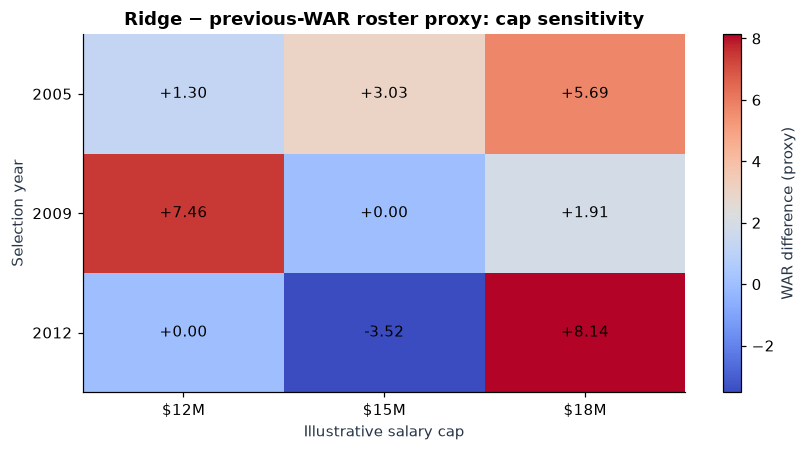

Feasible scenario cells: 9 / 9
This three-season grid is exploratory, not an eight-season inference.
Section 85: EXECUTED


In [100]:
# Small budget sensitivity grid. Refit on strictly earlier years for each selection year.
budget85=pd.DataFrame();status85='NOT_EVALUATED';rows85=[]
if 'old57' in globals() and 'feature60' in globals() and war52_ready:
    for yr85 in [2005,2009,2012]:
        past85=old57[(old57.target_year<yr85)&old57.realized_WAR.notna()].dropna(subset=feature60)
        pool85=old57[(old57.target_year==yr85)&old57.player_salary.gt(0)].dropna(subset=feature60).copy()
        if len(past85)<200 or len(pool85)<30:
            for cap85 in [12.,15.,18.]:
                rows85.append({'year':yr85,'cap_million':cap85,'status':'INSUFFICIENT_DATA'})
            continue
        reg85=Pipeline([('sc',StandardScaler()),('ridge',Ridge(alpha=50))]).fit(
            past85[feature60],past85.realized_WAR)
        pool85['PredictedWAR']=reg85.predict(pool85[feature60]);pool85['PriorWAR']=pool85.WAR
        for cap85 in [12.,15.,18.]:
            a85=independent_milp78(pool85,'PredictedWAR',cap85,n=8,
                                   solver_label=f'85_{yr85}_{int(cap85)}_Ridge',time_limit=10)
            b85=independent_milp78(pool85,'PriorWAR',cap85,n=8,
                                   solver_label=f'85_{yr85}_{int(cap85)}_Prior',time_limit=10)
            if a85 is None or b85 is None:
                rows85.append({'year':yr85,'cap_million':cap85,'status':'INFEASIBLE_OR_LIMIT',
                               'Ridge_feasible':a85 is not None,'Prior_feasible':b85 is not None})
                continue
            sa85=a85.player_salary.sum()/1e6;sb85=b85.player_salary.sum()/1e6
            gap85=100*abs(sa85-sb85)/((sa85+sb85)/2)
            assert gap85<=2.00001
            rows85.append({'year':yr85,'cap_million':cap85,'status':'FEASIBLE',
                'actual_spend_gap_pct':gap85,
                'Ridge_WAR_proxy':a85.realized_WAR.fillna(0).sum(),
                'Prior_WAR_proxy':b85.realized_WAR.fillna(0).sum(),
                'WAR_difference_proxy':a85.realized_WAR.fillna(0).sum()-b85.realized_WAR.fillna(0).sum(),
                'Ridge_missing_WAR':int(a85.realized_WAR.isna().sum()),
                'Prior_missing_WAR':int(b85.realized_WAR.isna().sum()),
                'both_solver_certified':bool(a85.attrs['solver_info']['certified_within_gap']
                                              and b85.attrs['solver_info']['certified_within_gap'])})
    budget85=pd.DataFrame(rows85)
    status85='EXECUTED' if len(budget85) and budget85.status.eq('FEASIBLE').any() else 'NOT_EVALUATED'
    if len(budget85):
        display(budget85.round(3));save_frame(budget85,'submission_85_budget_sensitivity.csv')
        feasible85=budget85.loc[budget85.status.eq('FEASIBLE')]
        if len(feasible85):
            pt85=budget85.pivot(index='year',columns='cap_million',values='WAR_difference_proxy')
            fig,ax=plt.subplots(figsize=(7.8,4.2))
            im85=ax.imshow(pt85.values,aspect='auto',cmap='coolwarm')
            ax.set(xticks=np.arange(len(pt85.columns)),xticklabels=[f'${x:.0f}M' for x in pt85.columns],
                   yticks=np.arange(len(pt85.index)),yticklabels=pt85.index,
                   xlabel='Illustrative salary cap',ylabel='Selection year',
                   title='Ridge − previous-WAR roster proxy: cap sensitivity')
            for yy85 in range(pt85.shape[0]):
                for xx85 in range(pt85.shape[1]):
                    v85=pt85.iloc[yy85,xx85]
                    ax.text(xx85,yy85,'N/A' if pd.isna(v85) else f'{v85:+.2f}',
                            ha='center',va='center',fontsize=10,color='black')
            fig.colorbar(im85,ax=ax,label='WAR difference (proxy)')
            fig.tight_layout()
            fig.savefig(VISUALS/'submission_85_budget_sensitivity.png',bbox_inches='tight');plt.show()
            print('Feasible scenario cells:',len(feasible85),'/',len(budget85))
            print('This three-season grid is exploratory, not an eight-season inference.')
else:print('NOT_EVALUATED: historical roster pool or bWAR is unavailable.')
print('Section 85:',status85)

## 86. Shortened-season sensitivity | the 2020-to-2021 transition

The 2020 MLB season contained fewer games than a standard season. Since the forecast uses previous-season playing time and performance, **2021 is a useful stress test** for the fixed historical model rather than an ordinary evaluation year. The analysis compares the full 2013–2025 holdout with a *supplementary* result excluding target year 2021; the full holdout remains the primary result.

The evaluation also compares previous-season PA distributions and bWAR observation rates. The 200-PA screening threshold selects a different group in a shortened season, so the difference cannot be attributed to season length alone. Missing next-season bWAR is reported as missing, not replaced with zero. The fixed Ridge and conformal models from Section 81 are not retrained or recalibrated on post-2012 outcomes.


,evaluation,n_observed_WAR,Ridge_MAE,previous_WAR_MAE,pooled_interval_coverage,mean_prior_PA,median_prior_PA
0,Full 2013–2025 holdout,4061,1.3112,1.5115,0.9082,448.0352,447.0
1,Excluding target 2021 (sensitivity only),3937,1.2902,1.4988,0.9139,454.9319,455.0
2,Target 2021 only,124,1.9781,1.9139,0.7258,229.0645,228.0


,target_year,eligible,observed_WAR,mean_prior_PA,median_prior_PA,p25_prior_PA,p75_prior_PA,observation_rate,input_season
7,2020,360,332,442.456,440.0,309.00,560.25,0.922,2019
8,2021,124,124,229.065,228.0,216.00,242.25,1.000,2020
9,2022,362,337,426.729,408.5,291.25,554.75,0.931,2021


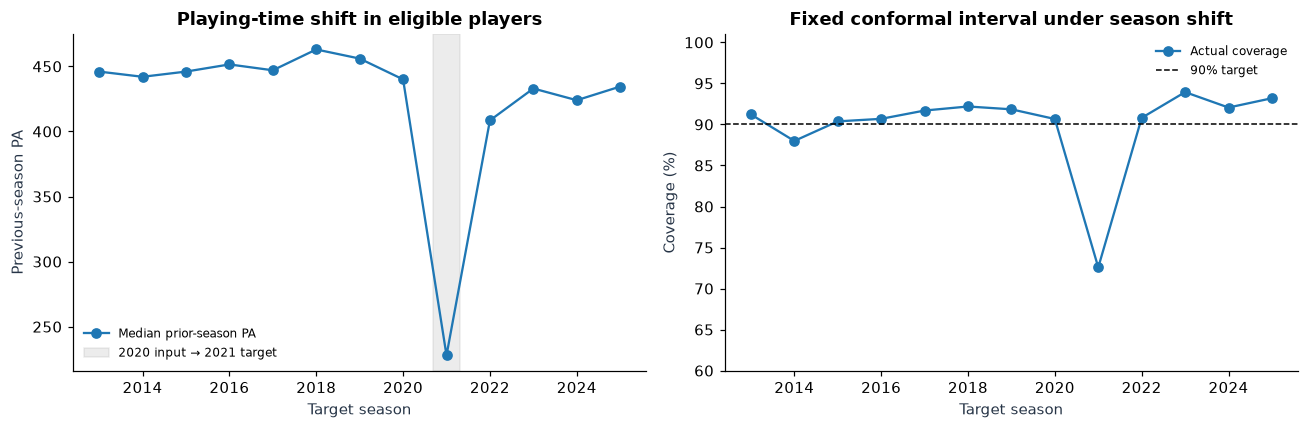

Section 86 status: EXECUTED


In [101]:
# 86 — Shortened-season sensitivity for the unchanged 2013–2025 external holdout.
status86 = 'NOT_EVALUATED'
sensitivity86 = pd.DataFrame()
cohort86 = pd.DataFrame()
coverage86 = pd.DataFrame()
shift86 = pd.DataFrame()

if external81_status == 'EXECUTED_ON_2013_2025_DATA' and len(external_predictions81) and len(external_interval81):
    all86 = external_predictions81.copy()
    obs86 = all86.loc[all86.observed_next_WAR].copy()
    joined86 = obs86.merge(
        external_interval81[['playerID','target_year','covered_90']],
        on=['playerID','target_year'],how='left',validate='one_to_one')
    assert joined86.covered_90.notna().all(), 'Section 81 interval rows differ from the observed-WAR evaluation set.'
    years86 = {
        'Full 2013–2025 holdout': joined86,
        'Excluding target 2021 (sensitivity only)': joined86.loc[joined86.target_year.ne(2021)],
        'Target 2021 only': joined86.loc[joined86.target_year.eq(2021)],
    }
    sensitivity86 = pd.DataFrame([{
        'evaluation':label, 'n_observed_WAR':len(part),
        'Ridge_MAE':part.abs_Ridge_error.mean(),
        'previous_WAR_MAE':part.abs_previous_error.mean(),
        'pooled_interval_coverage':part.covered_90.mean(),
        'mean_prior_PA':part.PA.mean(),
        'median_prior_PA':part.PA.median(),
    } for label,part in years86.items() if len(part)])
    cohort86 = all86.groupby('target_year',as_index=False).agg(
        eligible=('playerID','size'),
        observed_WAR=('observed_next_WAR','sum'),
        mean_prior_PA=('PA','mean'),
        median_prior_PA=('PA','median'),
        p25_prior_PA=('PA',lambda a:a.quantile(.25)),
        p75_prior_PA=('PA',lambda a:a.quantile(.75)))
    cohort86['observation_rate'] = cohort86.observed_WAR/cohort86.eligible
    coverage86 = joined86.groupby('target_year',as_index=False).agg(
        n=('covered_90','size'),
        pooled_coverage=('covered_90','mean'),
        Ridge_MAE=('abs_Ridge_error','mean'),
        previous_MAE=('abs_previous_error','mean'))
    # Prior-season PA comes from 2019, 2020 or 2021 for the respective target years.
    shift86 = cohort86.loc[cohort86.target_year.isin([2020,2021,2022])].copy()
    shift86['input_season'] = shift86.target_year-1
    display(sensitivity86.round(4)); display(shift86.round(3))
    save_frame(sensitivity86,'external_86_shortened_season_sensitivity.csv')
    save_frame(cohort86,'external_86_input_PA_and_observation_by_year.csv')
    save_frame(coverage86,'external_86_yearwise_MAE_and_coverage.csv')
    fig,ax86=plt.subplots(1,2,figsize=(12,4))
    ax86[0].plot(cohort86.target_year,cohort86.median_prior_PA,'o-',label='Median prior-season PA')
    ax86[0].axvspan(2020.7,2021.3,color='#999999',alpha=.18,label='2020 input → 2021 target')
    ax86[0].set(title='Playing-time shift in eligible players',xlabel='Target season',ylabel='Previous-season PA')
    ax86[0].legend(frameon=False,fontsize=8)
    ax86[1].plot(coverage86.target_year,coverage86.pooled_coverage*100,'o-',label='Actual coverage')
    ax86[1].axhline(90,color='black',lw=1,ls='--',label='90% target')
    ax86[1].set(title='Fixed conformal interval under season shift',xlabel='Target season',ylabel='Coverage (%)',ylim=(60,101))
    ax86[1].legend(frameon=False,fontsize=8)
    fig.tight_layout()
    fig.savefig(VISUALS/'external_86_shortened_season_sensitivity.png',dpi=160,bbox_inches='tight')
    plt.show()
    status86='EXECUTED'
else:
    print('NOT_EVALUATED: Section 86 requires a completed Section 81 with observed WAR and fixed intervals.')
print('Section 86 status:',status86)


## 87. External uncertainty comparison | three methods, the same 2013–2025 players

Sections 61, 75 and 79 evaluated prediction intervals on historical seasons. A more demanding check is to **fix the model, calibration years and hyperparameters before 2013**, then compare three methods using the same observed-bWAR players from 2013–2025: pooled split conformal, prior-PA-group conformal, and conformalized quantile regression (CQR).

Each method uses a model fit on target years **through 2008** and calibration scores from **2009–2012**. The PA groups are based on *previous-season* playing time, which is available when the prediction is made. Groups with too few historical calibration cases fall back to the pooled threshold. The two quantile models and their conformal correction are also fixed before the external years begin. No 2013–2025 outcomes influence fitting, tuning or calibration.

This three-method comparison was added after the initial external results had been inspected, so it is an **exploratory follow-up**, not a pre-registered untouched holdout experiment. Although the models and calibration thresholds are fit only on pre-2013 data, claims of out-of-sample performance should be interpreted with that research history in mind.

Results compare **coverage, mean interval width, 2021 coverage, and PA/age subgroup coverage**. A shorter interval is not automatically a better one if more true WAR values fall outside it. This external evaluation still excludes eligible players without a recorded next-year bWAR; conformal exchangeability assumptions may be disrupted by roster turnover and the shortened 2020 season.

**How to read the confidence intervals.** The error bars labelled **95% CI** in the first coverage figure are **Wilson binomial intervals across observed player-seasons**, not season-cluster-robust confidence intervals. A player may appear in several years, and all players in a given season can share league-wide conditions; those dependencies are not modeled by the Wilson calculation. Therefore, the error bars should not be interpreted as fully independent evidence for a ranking of interval methods.

**Season-level uncertainty check.** The last output resamples **13 entire target seasons** in a paired bootstrap for differences in annual coverage and mean interval width. This better represents shared season effects when comparing the methods, but remains exploratory with only 13 seasons. The player-season Wilson intervals and the season-level bootstrap intervals answer different questions and should not be substituted for each other.

**Subgroup result (observed next-season bWAR only).** The saved subgroup comparison supplies these descriptive 2013–2025 results on matched players:

| Prior information at prediction time | Observed cases | Frozen pooled coverage | Frozen CQR coverage |
|---|---:|---:|---:|
| **500+ prior-season PA** | **1,653** | **86.6%** | **90.9%** |
| **Age 26 or younger** | **1,251** | **87.6%** | **91.1%** |
| **All matched player-seasons** | **4,061** | **90.82%** | **91.78%** |

These subgroups overlap; they are not independent partitions. Differences in subgroup proportions do not establish statistically significant superiority, nor do near-90% marginal rates establish conditional validity for every individual player. The 2021 breakdown remains an unusually weak season for all three methods; missing future WAR outcomes remain outside coverage denominators.

**2021 method check (124 measured next-WAR outcomes).** On the identical 2021 evaluation cases, pooled conformal had **72.58%** coverage with mean width **5.708 bWAR**, PA-group conformal had **59.68%** with mean width **4.441 bWAR**, and frozen CQR had **70.97%** with mean width **5.133 bWAR**. The 2021 PA-group interval was narrower and markedly undercovered; the overall 91.21% PA-group coverage across years does not override this failure. These rates are conditional on an observed next-season bWAR.


,method,PA_group,historical_calibration_n,q,pooled_fallback
0,PA-group conformal,200–299,243,2.221,False
1,PA-group conformal,300–499,453,2.675,False
2,PA-group conformal,500+,589,3.277,False
3,Pooled conformal,ALL,1285,2.854,False
4,Frozen CQR,ALL,1285,0.306,False


,method,n,coverage,mean_width_WAR,median_width_WAR,coverage_2021,coverage_without_2021
0,Pooled conformal,4061,0.9082,5.7081,5.7081,0.7258,0.9139
1,PA-group conformal,4061,0.9121,5.6343,5.3495,0.5968,0.9220
2,Frozen CQR,4061,0.9178,5.5988,5.6295,0.7097,0.9243


,method,target_year,n,coverage,mean_width_WAR
6,Pooled conformal,2019,331,0.918,5.708
7,Pooled conformal,2020,332,0.907,5.708
8,Pooled conformal,2021,124,0.726,5.708
9,Pooled conformal,2022,337,0.908,5.708
19,PA-group conformal,2019,331,0.906,5.677
20,PA-group conformal,2020,332,0.949,5.633
21,PA-group conformal,2021,124,0.597,4.441
22,PA-group conformal,2022,337,0.914,5.593
32,Frozen CQR,2019,331,0.915,5.590
33,Frozen CQR,2020,332,0.964,5.659


,method,grouping,group,n,coverage,mean_width_WAR
0,Pooled conformal,PA_group,200–299,918,0.932,5.708
1,Pooled conformal,PA_group,300–499,1490,0.940,5.708
2,Pooled conformal,PA_group,500+,1653,0.866,5.708
3,Pooled conformal,age_group,27–30,1587,0.905,5.708
4,Pooled conformal,age_group,31–35,1065,0.945,5.708
5,Pooled conformal,age_group,36+,158,0.943,5.708
6,Pooled conformal,age_group,≤26,1251,0.876,5.708
7,PA-group conformal,PA_group,200–299,918,0.882,4.441
8,PA-group conformal,PA_group,300–499,1490,0.924,5.349
9,PA-group conformal,PA_group,500+,1653,0.918,6.553


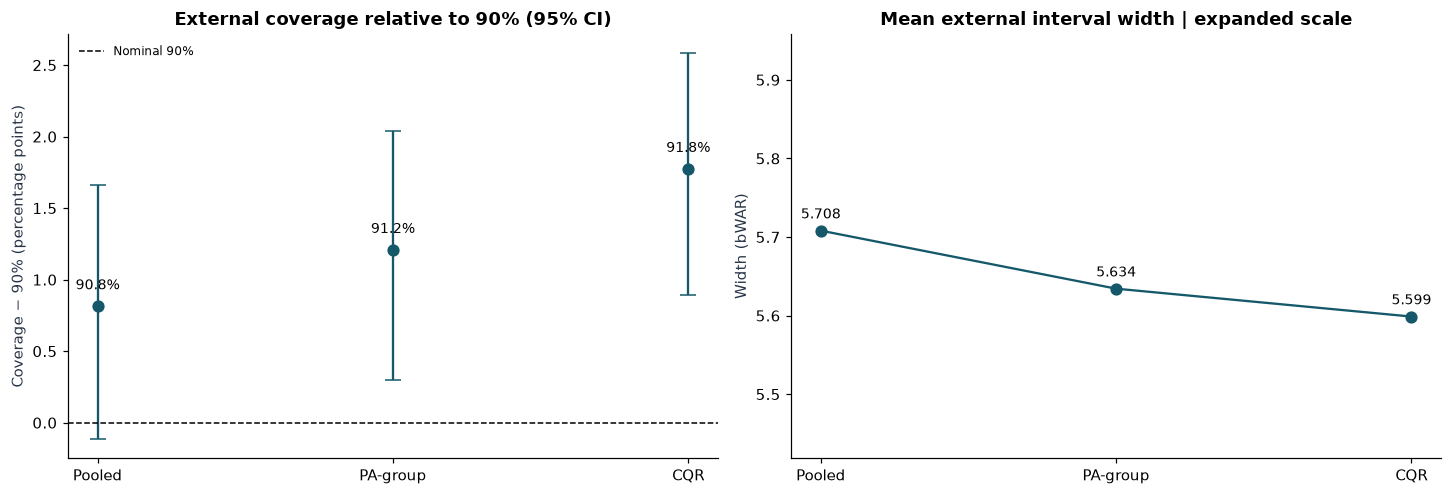

Section 87 status: EXECUTED


,comparison,metric,test_seasons,paired_annual_mean,season_bootstrap_95_low,season_bootstrap_95_high
0,PA-group conformal − Pooled conformal,coverage difference (percentage points),13,-0.2317,-2.6446,1.3982
1,PA-group conformal − Pooled conformal,mean interval width difference (bWAR),13,-0.1302,-0.3282,-0.0186
2,Frozen CQR − Pooled conformal,coverage difference (percentage points),13,0.8476,-0.0728,1.9531
3,Frozen CQR − Pooled conformal,mean interval width difference (bWAR),13,-0.1307,-0.2149,-0.0739


Paired intervals resample 13 target seasons. They are exploratory, not independent player-level confidence bounds.


In [102]:
# 87 — Frozen pre-2013 pooled, PA-group and CQR intervals on identical future cases.
from sklearn.ensemble import HistGradientBoostingRegressor

status87='NOT_EVALUATED'
external_comparison87=pd.DataFrame()
external_seasons87=pd.DataFrame()
external_groups87=pd.DataFrame()
external_players87=pd.DataFrame()
calibration87=pd.DataFrame()

if (external81_status=='EXECUTED_ON_2013_2025_DATA'
    and 'older81' in globals() and 'calib81' in globals()
    and len(external_interval81) and len(older81)>=400 and len(calib81)>=100):
    def conformal_order87(scores, coverage=.9):
        clean=np.asarray(scores,dtype=float)
        clean=clean[np.isfinite(clean)]
        if not len(clean): raise ValueError('Calibration scores are empty.')
        k=min(len(clean),int(np.ceil((len(clean)+1)*coverage)))
        return float(np.partition(clean,k-1)[k-1])

    test87=external_predictions81.loc[external_predictions81.observed_next_WAR].copy()
    assert not test87.duplicated(['playerID','target_year']).any()
    y87=test87.next_WAR.to_numpy(dtype=float)
    center87=interval_model81.predict(test87[feature81])
    pooled_q87=conformal_order87(np.abs(calib81.next_WAR.to_numpy()-interval_model81.predict(calib81[feature81])))

    def pa_band87(pa):
        return pd.cut(pd.Series(pa),[199,299,499,np.inf],labels=['200–299','300–499','500+']).astype(str)

    cal_bands87=pa_band87(calib81.PA).to_numpy()
    test_bands87=pa_band87(test87.PA).to_numpy()
    cal_errors87=np.abs(calib81.next_WAR.to_numpy()-interval_model81.predict(calib81[feature81]))
    pa_thresholds87={}
    for label87 in ['200–299','300–499','500+']:
        valid87=cal_errors87[cal_bands87==label87]
        pa_thresholds87[label87]=conformal_order87(valid87) if len(valid87)>=30 else pooled_q87
        calibration87=pd.concat([calibration87,pd.DataFrame([{
            'method':'PA-group conformal','PA_group':label87,'historical_calibration_n':len(valid87),
            'q':pa_thresholds87[label87],'pooled_fallback':len(valid87)<30
        }])],ignore_index=True)
    group_q87=np.array([pa_thresholds87.get(group87,pooled_q87) for group87 in test_bands87])

    # Two independently fitted conditional quantiles; train and calibration are strictly pre-2013.
    quantile_args87=dict(max_iter=160,max_leaf_nodes=15,min_samples_leaf=40,
                         learning_rate=.05,l2_regularization=10,random_state=87)
    lower_fit87=HistGradientBoostingRegressor(loss='quantile',quantile=.05,**quantile_args87)
    upper_fit87=HistGradientBoostingRegressor(loss='quantile',quantile=.95,**quantile_args87)
    lower_fit87.fit(older81[feature81],older81.next_WAR)
    upper_fit87.fit(older81[feature81],older81.next_WAR)
    ql_cal87=lower_fit87.predict(calib81[feature81]); qu_cal87=upper_fit87.predict(calib81[feature81])
    lo_cal87=np.minimum(ql_cal87,qu_cal87); hi_cal87=np.maximum(ql_cal87,qu_cal87)
    y_cal87=calib81.next_WAR.to_numpy()
    cqr_scores87=np.maximum(lo_cal87-y_cal87,y_cal87-hi_cal87)
    cqr_q87=conformal_order87(cqr_scores87)
    ql_test87=lower_fit87.predict(test87[feature81]); qu_test87=upper_fit87.predict(test87[feature81])
    lo_test87=np.minimum(ql_test87,qu_test87); hi_test87=np.maximum(ql_test87,qu_test87)

    external_players87=test87[['playerID','yearID','target_year','PA','age','next_WAR']].copy()
    external_players87['PA_group']=test_bands87
    external_players87['age_group']=pd.cut(test87.age,[-np.inf,26,30,35,np.inf],labels=['≤26','27–30','31–35','36+']).astype(str).values
    for name87,l87,u87 in [
        ('Pooled conformal',center87-pooled_q87,center87+pooled_q87),
        ('PA-group conformal',center87-group_q87,center87+group_q87),
        ('Frozen CQR',lo_test87-cqr_q87,hi_test87+cqr_q87),
    ]:
        tag87={'Pooled conformal':'pooled','PA-group conformal':'pa_group','Frozen CQR':'cqr'}[name87]
        external_players87[f'{tag87}_lower']=l87
        external_players87[f'{tag87}_upper']=u87
        external_players87[f'{tag87}_covered']=(y87>=l87)&(y87<=u87)
        external_players87[f'{tag87}_width']=u87-l87
        if (external_players87[f'{tag87}_width']<0).any():
            raise AssertionError('An external prediction interval has negative width.')
        c87=external_players87[f'{tag87}_covered']
        w87=external_players87[f'{tag87}_width']
        c2021_87=external_players87.loc[external_players87.target_year.eq(2021),f'{tag87}_covered']
        external_comparison87=pd.concat([external_comparison87,pd.DataFrame([{
            'method':name87,'n':len(test87),'coverage':c87.mean(),
            'mean_width_WAR':w87.mean(),'median_width_WAR':w87.median(),
            'coverage_2021':c2021_87.mean() if len(c2021_87) else np.nan,
            'coverage_without_2021':c87[external_players87.target_year.ne(2021)].mean(),
        }])],ignore_index=True)
        for yr87,year_frame87 in external_players87.groupby('target_year'):
            external_seasons87=pd.concat([external_seasons87,pd.DataFrame([{
                'method':name87,'target_year':int(yr87),'n':len(year_frame87),
                'coverage':year_frame87[f'{tag87}_covered'].mean(),
                'mean_width_WAR':year_frame87[f'{tag87}_width'].mean()
            }])],ignore_index=True)
        for col87 in ['PA_group','age_group']:
            for value87,part87 in external_players87.groupby(col87,observed=True):
                if len(part87)<20:continue
                external_groups87=pd.concat([external_groups87,pd.DataFrame([{
                    'method':name87,'grouping':col87,'group':str(value87),
                    'n':len(part87),'coverage':part87[f'{tag87}_covered'].mean(),
                    'mean_width_WAR':part87[f'{tag87}_width'].mean()
                }])],ignore_index=True)
    calibration87=pd.concat([calibration87,pd.DataFrame([{
        'method':'Pooled conformal','PA_group':'ALL','historical_calibration_n':len(calib81),
        'q':pooled_q87,'pooled_fallback':False},
        {'method':'Frozen CQR','PA_group':'ALL','historical_calibration_n':len(calib81),
        'q':cqr_q87,'pooled_fallback':False}
    ])],ignore_index=True)
    # Explicit same-population assertion; no post-2012 labels entered calibration.
    assert int(older81.target_year.max())<=2008 and calib81.target_year.between(2009,2012).all()
    assert set(test87.target_year.astype(int))==set(range(2013,2026))
    assert len(external_players87)==len(external_interval81)
    display(calibration87.round(3));display(external_comparison87.round(4))
    display(external_seasons87[external_seasons87.target_year.isin([2019,2020,2021,2022])].round(3))
    display(external_groups87.round(3))
    save_frame(calibration87,'external_87_pre2013_calibration_audit.csv')
    save_frame(external_comparison87,'external_87_three_interval_method_summary.csv')
    save_frame(external_seasons87,'external_87_yearly_interval_comparison.csv')
    save_frame(external_groups87,'external_87_subgroup_interval_comparison.csv')
    save_frame(external_players87,'external_87_aligned_player_intervals.csv')
    fig,ax87=plt.subplots(1,2,figsize=(13.3,4.6))
    order87=['Pooled conformal','PA-group conformal','Frozen CQR']
    sub87=external_comparison87.set_index('method').loc[order87]
    x87=np.arange(len(order87)); labels87=['Pooled','PA-group','CQR']
    cov87=(sub87.coverage.to_numpy()*100)
    # Difference from the pre-specified 90% target; dots instead of truncated bars.
    from statsmodels.stats.proportion import proportion_confint as _prop_ci87
    low87=[];high87=[]
    for n87,p87 in zip(sub87.n.to_numpy(),sub87.coverage.to_numpy()):
        l87,h87=_prop_ci87(int(round(n87*p87)),int(n87),alpha=.05,method='wilson')
        low87.append(l87*100);high87.append(h87*100)
    err87=np.vstack([cov87-np.asarray(low87),np.asarray(high87)-cov87])
    ax87[0].errorbar(x87,cov87-90,yerr=err87,fmt='o',capsize=5,ms=7,color='#14586a')
    ax87[0].axhline(0,ls='--',color='black',lw=1,label='Nominal 90%')
    for xx87,yy87 in zip(x87,cov87):
        ax87[0].annotate(f'{yy87:.1f}%',(xx87,yy87-90),xytext=(0,11),
                         textcoords='offset points',ha='center',fontsize=9)
    ax87[0].set(xticks=x87,xticklabels=labels87,title='External coverage relative to 90% (95% CI)',
                ylabel='Coverage − 90% (percentage points)')
    ax87[0].legend(frameon=False,fontsize=8)
    widths87=sub87.mean_width_WAR.to_numpy()
    ax87[1].plot(x87,widths87,'o-',color='#14586a',markersize=7)
    for xx87,ww87 in zip(x87,widths87):
        ax87[1].annotate(f'{ww87:.3f}',(xx87,ww87),xytext=(0,8),
                         textcoords='offset points',ha='center',fontsize=9)
    ax87[1].set(xticks=x87,xticklabels=labels87,
                ylim=(max(0,widths87.min()-.18),widths87.max()+.25),
                title='Mean external interval width | expanded scale',ylabel='Width (bWAR)')
    fig.tight_layout()
    fig.savefig(VISUALS/'external_87_interval_method_comparison.png',dpi=160,bbox_inches='tight')
    plt.show()
    status87='EXECUTED'
else:
    print('NOT_EVALUATED: Section 87 requires a complete 2013–2025 holdout and historical 2009–2012 calibration.')
print('Section 87 status:',status87)


# Paired 13-season uncertainty intervals. These resample calendar years, not players.
external_block_ci87 = pd.DataFrame()
if status87 == 'EXECUTED' and len(external_seasons87):
    by_season87=external_seasons87.pivot(index='target_year',columns='method',values=['coverage','mean_width_WAR'])
    rng_block87=np.random.default_rng(8701)
    cols87=[('PA-group conformal','Pooled conformal'),('Frozen CQR','Pooled conformal')]
    rows_block87=[]
    for alternative87,baseline87 in cols87:
        for metric87,scale87 in [('coverage',100.0),('mean_width_WAR',1.0)]:
            diffs87=(by_season87[(metric87,alternative87)]-by_season87[(metric87,baseline87)]).dropna().to_numpy(dtype=float)*scale87
            if len(diffs87)<3:continue
            boot87=rng_block87.choice(diffs87,size=(7000,len(diffs87)),replace=True).mean(axis=1)
            low87,high87=np.quantile(boot87,[.025,.975])
            rows_block87.append({'comparison':f'{alternative87} − {baseline87}',
                 'metric':'coverage difference (percentage points)' if metric87=='coverage' else 'mean interval width difference (bWAR)',
                 'test_seasons':len(diffs87),'paired_annual_mean':diffs87.mean(),
                 'season_bootstrap_95_low':low87,'season_bootstrap_95_high':high87})
    external_block_ci87=pd.DataFrame(rows_block87)
    display(external_block_ci87.round(4))
    save_frame(external_block_ci87,'external_87_paired_season_bootstrap.csv')
    print('Paired intervals resample 13 target seasons. They are exploratory, not independent player-level confidence bounds.')


## 88. Adaptive WAR forecasting | Frozen, expanding, and rolling training windows

The 2013–2025 holdout is reused to ask whether a Ridge forecast benefits from updates as additional seasons become available. A fixed Ridge is compared with models refitted using **only earlier target seasons**: an expanding history and a trailing five-target-season window. Feature scaling and the Ridge fit are redone separately for each target year. The Ridge regularization value stays at the pre-existing setting of 50; no external-year hyperparameter search is used.

This is a **sequential backtest**, not a second untouched holdout: earlier years' outcomes are allowed into later-year training once they would have become available. MAE is compared on exactly the same players with measured next-year bWAR. It does not address players whose next-year WAR is missing.


,method,player_seasons,MAE
0,Expanding Ridge,4061,1.3113
1,Frozen Ridge,4061,1.3112
2,Rolling 5-year Ridge,4061,1.3206


,method,comparison,seasons,mean_annual_MAE_difference,season_bootstrap_95_low,season_bootstrap_95_high
0,Expanding Ridge,MAE minus Frozen Ridge,13,0.0008,-0.0009,0.0033
1,Rolling 5-year Ridge,MAE minus Frozen Ridge,13,0.0160,-0.0017,0.0427


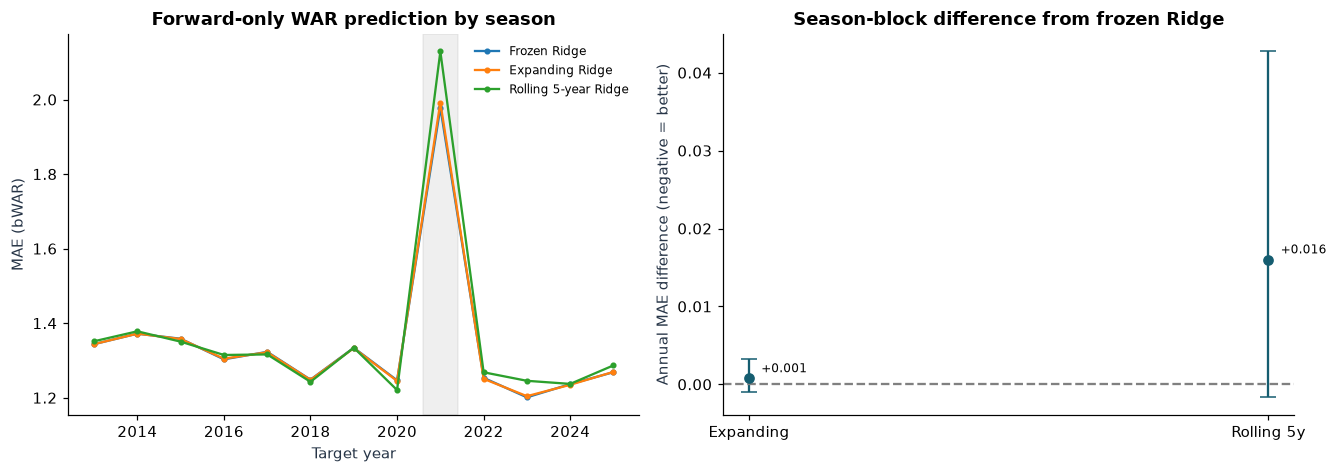

Section 88 status: EXECUTED


In [103]:
# 88 — Strict forward-only updates; no future target-year labels in training.
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
status88='NOT_EVALUATED'
adaptive_predictions88=pd.DataFrame()
adaptive_year88=pd.DataFrame()
adaptive_summary88=pd.DataFrame()
adaptive_uncertainty88=pd.DataFrame()
if external81_status=='EXECUTED_ON_2013_2025_DATA' and len(train81) and len(external_predictions81):
    past88=external_predictions81.loc[external_predictions81.observed_next_WAR].copy()
    common88=['playerID','yearID','target_year']+feature81+['next_WAR']
    available88=pd.concat([train81[common88],past88[common88]],ignore_index=True)
    assert not available88.duplicated(['playerID','target_year']).any()
    rows88=[]
    for year88 in sorted(past88.target_year.astype(int).unique()):
        test88=past88.loc[past88.target_year.eq(year88)].copy()
        if len(test88)<20: continue
        histories88={
            'Frozen Ridge':None,
            'Expanding Ridge':available88.loc[available88.target_year.lt(year88)],
            'Rolling 5-year Ridge':available88.loc[available88.target_year.between(year88-5,year88-1)],
        }
        for name88,training88 in histories88.items():
            if training88 is None:
                pred88=frozen81.predict(test88[feature81])
                ntrain88=len(train81); last_year88=int(train81.target_year.max())
            else:
                if len(training88)<100: continue
                assert training88.target_year.max()<year88, 'Future season entered training.'
                fitted88=Pipeline([('standardize',StandardScaler()),('ridge',Ridge(alpha=50.0))])
                fitted88.fit(training88[feature81],training88.next_WAR)
                pred88=fitted88.predict(test88[feature81])
                ntrain88=len(training88); last_year88=int(training88.target_year.max())
            for pid88, actual88, yhat88 in zip(test88.playerID,test88.next_WAR,pred88):
                rows88.append({'target_year':int(year88),'playerID':pid88,'method':name88,
                               'next_WAR':float(actual88),'prediction':float(yhat88),
                               'abs_error':abs(float(actual88-yhat88)),
                               'training_n':ntrain88,'training_last_target_year':last_year88})
    adaptive_predictions88=pd.DataFrame(rows88)
    adaptive_year88=(adaptive_predictions88.groupby(['target_year','method'],as_index=False)
                     .agg(n=('abs_error','size'),MAE=('abs_error','mean'),
                          training_n=('training_n','first'),
                          last_training_target=('training_last_target_year','first')))
    adaptive_summary88=adaptive_predictions88.groupby('method',as_index=False).agg(
        player_seasons=('abs_error','size'),MAE=('abs_error','mean'))
    yearwide88=adaptive_year88.pivot(index='target_year',columns='method',values='MAE').dropna()
    assert yearwide88.index.min()==2013 and yearwide88.index.max()==2025
    rng88=np.random.default_rng(88)
    for method88 in ['Expanding Ridge','Rolling 5-year Ridge']:
        deltas88=(yearwide88[method88]-yearwide88['Frozen Ridge']).to_numpy()
        boot88=rng88.choice(deltas88,size=(5000,len(deltas88)),replace=True).mean(axis=1)
        lo88,hi88=np.quantile(boot88,[.025,.975])
        adaptive_uncertainty88=pd.concat([adaptive_uncertainty88,pd.DataFrame([{
            'method':method88,'comparison':'MAE minus Frozen Ridge',
            'seasons':len(deltas88),'mean_annual_MAE_difference':deltas88.mean(),
            'season_bootstrap_95_low':lo88,'season_bootstrap_95_high':hi88,
        }])],ignore_index=True)
    display(adaptive_summary88.round(4));display(adaptive_uncertainty88.round(4))
    save_frame(adaptive_predictions88,'external_88_forward_year_predictions.csv')
    save_frame(adaptive_year88,'external_88_yearwise_mae.csv')
    save_frame(adaptive_uncertainty88,'external_88_season_bootstrap.csv')
    fig,ax88=plt.subplots(1,2,figsize=(12.3,4.4))
    for name88 in ['Frozen Ridge','Expanding Ridge','Rolling 5-year Ridge']:
        ax88[0].plot(yearwide88.index,yearwide88[name88],marker='o',ms=3,label=name88)
    ax88[0].axvspan(2020.6,2021.4,alpha=.12,color='gray')
    ax88[0].set(title='Forward-only WAR prediction by season',xlabel='Target year',ylabel='MAE (bWAR)')
    ax88[0].legend(fontsize=8,frameon=False)
    x88=np.arange(2)
    for idx88,name88 in enumerate(['Expanding Ridge','Rolling 5-year Ridge']):
        a88=adaptive_uncertainty88.set_index('method').loc[name88]
        point88=float(a88.mean_annual_MAE_difference)
        low88=float(a88.season_bootstrap_95_low); high88=float(a88.season_bootstrap_95_high)
        ax88[1].errorbar(idx88,point88,yerr=[[point88-low88],[high88-point88]],fmt='o',capsize=5,color='#155d70')
        ax88[1].annotate(f'{point88:+.3f}',(idx88,point88),xytext=(8,4),textcoords='offset points',fontsize=8)
    ax88[1].axhline(0,color='gray',ls='--')
    ax88[1].set(xticks=x88,xticklabels=['Expanding','Rolling 5y'],title='Season-block difference from frozen Ridge',
                 ylabel='Annual MAE difference (negative = better)')
    fig.tight_layout();fig.savefig(VISUALS/'external_88_adaptive_forecasts.png',dpi=160,bbox_inches='tight');plt.show()
    status88='EXECUTED'
else:
    print('NOT_EVALUATED: Section 88 needs Section 81 observed next-season WAR and historical training rows.')
print('Section 88 status:',status88)


## 89. Shortened-season feature sensitivity | 2020 input, 2021 outcome

The frozen 2012-or-earlier Ridge model is applied to **the same 2021 test players** after explicitly defined feature transformations. These checks evaluate whether shorter 2020 exposure could explain some of the unusual error. The original unadjusted result remains the main finding. Exposure-equivalent PA and WAR use a 162/60 multiplier with limits derived from pre-2013 data; an additional variant shrinks OBP and SLG toward historical means. The 2009–2012 split-conformal threshold remains unchanged.

**Important:** These alternatives were considered after reviewing the poor 2021 results. Their comparison is exploratory and must not be described as a new holdout success, a causal correction, or a guarantee of 90% interval coverage. A better-looking 2021 result alone is not grounds for replacing the frozen model.


,feature_rule,test_target_year,n,MAE,historical_interval_coverage,mean_input_PA,mean_input_WAR,interval_threshold_calibration,interpretation
0,Original frozen,2021,124,1.9781,0.7258,229.0645,1.1967,2009–2012 fixed,post-hoc stress scenario; not independent vali...
1,PA exposure only,2021,124,1.7711,0.8226,618.4742,1.1967,2009–2012 fixed,post-hoc stress scenario; not independent vali...
2,PA + WAR exposure,2021,124,1.7919,0.8226,618.4742,3.2279,2009–2012 fixed,post-hoc stress scenario; not independent vali...
3,Exposure + rate shrinkage,2021,124,1.7752,0.8226,618.4742,3.2279,2009–2012 fixed,post-hoc stress scenario; not independent vali...


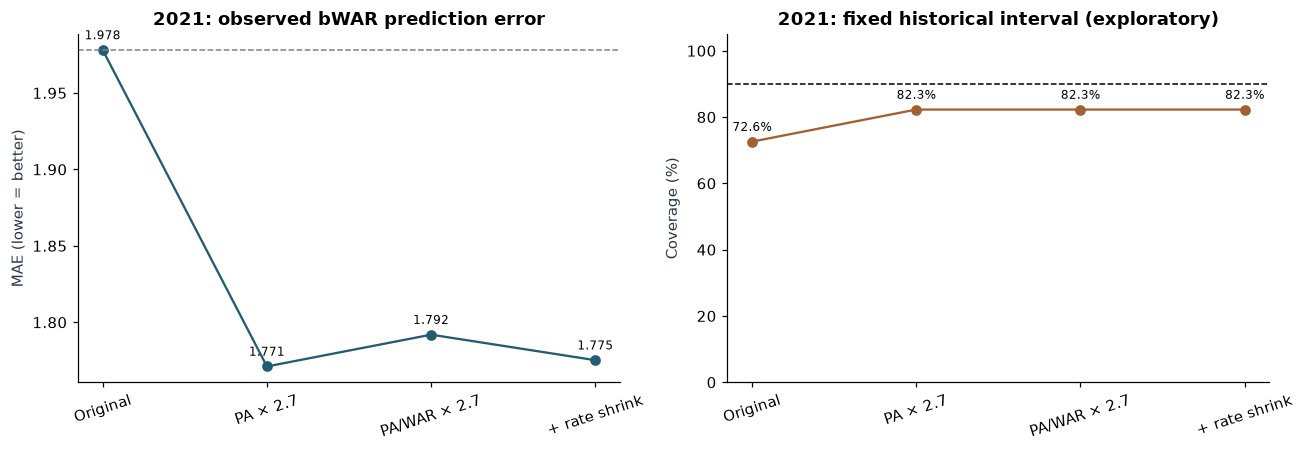

Section 89 status: EXECUTED


In [104]:
# 89 — Post-hoc stress test, not a pre-registered 2021 model selection exercise.
status89='NOT_EVALUATED'
season_shift89=pd.DataFrame()
if external81_status=='EXECUTED_ON_2013_2025_DATA' and len(external_interval81):
    subset89=external_predictions81.loc[(external_predictions81.target_year==2021) &
        external_predictions81.observed_next_WAR].copy()
    if len(subset89)>=20 and len(train81)>=400:
        # PA/WAR are exposures; rate stats are not multiplied by 162/60.
        multiplier89=162/60
        low_war89,high_war89=train81.WAR.quantile([.005,.995]).to_numpy()
        max_pa89=float(train81.PA.quantile(.995))
        baseline89=subset89[feature81].copy()
        pa89=baseline89.copy()
        pa89['PA']=(pa89.PA*multiplier89).clip(upper=max_pa89)
        war89=pa89.copy()
        war89['WAR']=(war89.WAR*multiplier89).clip(lower=low_war89,upper=high_war89)
        regular89=war89.copy()
        for rate89 in ['OBP','SLG']:
            anchor89=float(np.average(train81[rate89],weights=train81.PA))
            regular89[rate89]=(baseline89.PA*baseline89[rate89]+200*anchor89)/(baseline89.PA+200)
        variants89={
            'Original frozen':baseline89,
            'PA exposure only':pa89,
            'PA + WAR exposure':war89,
            'Exposure + rate shrinkage':regular89,
        }
        errors89=[];y89=subset89.next_WAR.to_numpy(dtype=float)
        q89=float(q81)
        for label89,features89 in variants89.items():
            pred89=frozen81.predict(features89)
            interval89=interval_model81.predict(features89)
            covered89=((y89>=interval89-q89)&(y89<=interval89+q89))
            errors89.append({'feature_rule':label89,'test_target_year':2021,'n':len(subset89),
                             'MAE':float(np.mean(np.abs(y89-pred89))),
                             'historical_interval_coverage':float(covered89.mean()),
                             'mean_input_PA':float(features89.PA.mean()),
                             'mean_input_WAR':float(features89.WAR.mean()),
                             'interval_threshold_calibration':'2009–2012 fixed',
                             'interpretation':'post-hoc stress scenario; not independent validation'})
        season_shift89=pd.DataFrame(errors89)
        display(season_shift89.round(4))
        save_frame(season_shift89,'external_89_shortened_season_transform_sensitivity.csv')
        fig,ax89=plt.subplots(1,2,figsize=(12,4.2))
        labels89=['Original','PA × 2.7','PA/WAR × 2.7','+ rate shrink']
        xx89=np.arange(len(labels89))
        mae89=season_shift89.MAE.to_numpy();coverage89=season_shift89.historical_interval_coverage.to_numpy()*100
        ax89[0].plot(xx89,mae89,'o-',color='#245b74')
        ax89[0].axhline(mae89[0],ls='--',color='gray',lw=1,label='Original frozen')
        for k89,value89 in enumerate(mae89): ax89[0].annotate(f'{value89:.3f}',(k89,value89),xytext=(0,7),textcoords='offset points',ha='center',fontsize=8)
        ax89[0].set(xticks=xx89,xticklabels=labels89,title='2021: observed bWAR prediction error',ylabel='MAE (lower = better)')
        ax89[1].plot(xx89,coverage89,'o-',color='#a16032')
        ax89[1].axhline(90,ls='--',color='black',lw=1,label='Nominal 90%')
        for k89,value89 in enumerate(coverage89): ax89[1].annotate(f'{value89:.1f}%',(k89,value89),xytext=(0,7),textcoords='offset points',ha='center',fontsize=8)
        ax89[1].set(xticks=xx89,xticklabels=labels89,title='2021: fixed historical interval (exploratory)',ylabel='Coverage (%)',ylim=(0,105))
        for a89 in ax89: a89.tick_params(axis='x',rotation=18)
        fig.tight_layout();fig.savefig(VISUALS/'external_89_2021_feature_stress_test.png',dpi=160,bbox_inches='tight');plt.show()
        status89='EXECUTED'
else:
    print('NOT_EVALUATED: Section 89 requires a 2021 test cohort and pre-2013 calibration.')
print('Section 89 status:',status89)


## 90. External observation bias and interval reliability

Missing next-season bWAR is kept separate from an actual zero. The first part of this check reports which players have measured outcomes by PA group, age group and season. A chronological observation-propensity model estimates the likelihood of a WAR record, using only previous target years. Inverse-propensity weighting provides a **missing-at-random sensitivity check** for 2016–2025, not a correction for unknown unobserved causes of missingness.

A second sensitivity table substitutes explicit hypothetical WAR values for the missing records to show how the ranking of forecasts could change; **scenario-imputed errors are not measured errors**. Finally, interval reliability is summarized by year, PA group and age group for the same observed players. Neither weighting nor scenarios establish performance for the entire eligible MLB population.


,grouping,group,eligible,measured,measured_rate
0,PA_group,200–299,1092,918,0.8407
1,PA_group,300–499,1605,1490,0.9283
2,PA_group,500+,1680,1653,0.9839
3,age_group,≤26,1298,1251,0.9638
4,age_group,27–30,1674,1587,0.9480
5,age_group,31–35,1180,1065,0.9025
6,age_group,36+,225,158,0.7022


,time_directed_scoring,eligible_n,observed_n,observed_unweighted_ridge_MAE,IPW_ridge_MAE_under_MAR,observed_unweighted_previous_MAE,IPW_previous_MAE_under_MAR,effective_sample_size,max_observation_weight,assumption
0,2016–2025,3329,3087,1.2964,1.2733,1.4936,1.4698,2963.0315,7.2097,missing at random given included features; can...


,assumed_unobserved_next_WAR,eligible_n,missing_n,hypothetical_Ridge_MAE,hypothetical_previous_MAE,hypothetical_Ridge_minus_previous_MAE,warning
0,-1.0,4377,316,1.3052,1.4843,-0.1791,NOT an observed performance estimate; hypothet...
1,0.0,4377,316,1.2549,1.4628,-0.2079,NOT an observed performance estimate; hypothet...
2,1.0,4377,316,1.2847,1.4958,-0.2112,NOT an observed performance estimate; hypothet...


,grouping,group,method,n_observed_WAR,coverage,mean_width_WAR
0,PA_group,200–299,Pooled conformal,918,0.932,5.708
1,PA_group,300–499,Pooled conformal,1490,0.940,5.708
2,PA_group,500+,Pooled conformal,1653,0.866,5.708
3,PA_group,200–299,PA-group conformal,918,0.882,4.441
4,PA_group,300–499,PA-group conformal,1490,0.924,5.349
5,PA_group,500+,PA-group conformal,1653,0.918,6.553
6,PA_group,200–299,Frozen CQR,918,0.911,4.653
7,PA_group,300–499,Frozen CQR,1490,0.932,5.341
8,PA_group,500+,Frozen CQR,1653,0.909,6.356
9,age_group,27–30,Pooled conformal,1587,0.905,5.708


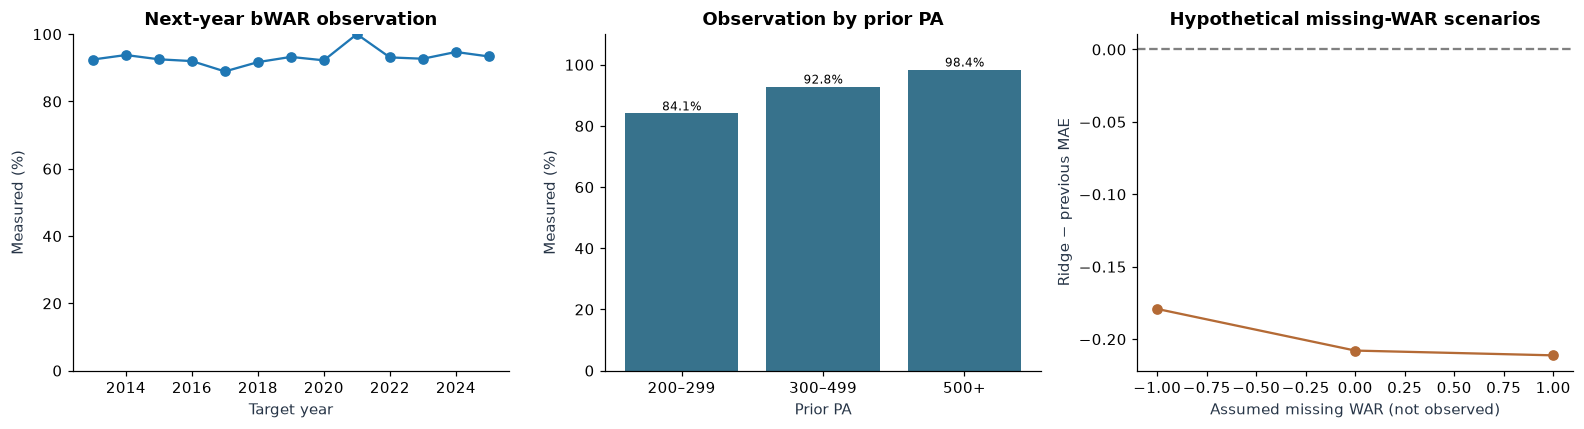

Section 90 status: EXECUTED


In [105]:
# 90 — Honest coverage denominators and missing-label sensitivity; no unseen WAR is set to zero by default.
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
status90='NOT_EVALUATED'
observation_groups90=pd.DataFrame()
observation_years90=pd.DataFrame()
propensity90=pd.DataFrame()
weighted_summary90=pd.DataFrame()
missing_scenarios90=pd.DataFrame()
subgroup_intervals90=pd.DataFrame()
if (external81_status=='EXECUTED_ON_2013_2025_DATA' and len(external_predictions81)
    and status87=='EXECUTED' and len(external_players87)):
    all90=external_predictions81.copy()
    all90['PA_group']=pd.cut(all90.PA,[199,299,499,np.inf],labels=['200–299','300–499','500+'])
    all90['age_group']=pd.cut(all90.age,[-np.inf,26,30,35,np.inf],labels=['≤26','27–30','31–35','36+'])
    observation_years90=all90.groupby('target_year',as_index=False).agg(
        eligible=('playerID','size'),measured=('observed_next_WAR','sum'))
    observation_years90['measured_rate']=observation_years90.measured/observation_years90.eligible
    for kind90 in ['PA_group','age_group']:
        rate90=all90.groupby(kind90,observed=True).agg(
            eligible=('playerID','size'),measured=('observed_next_WAR','sum')).reset_index()
        rate90['grouping']=kind90
        rate90['group']=rate90[kind90].astype(str)
        rate90['measured_rate']=rate90.measured/rate90.eligible
        observation_groups90=pd.concat([observation_groups90,rate90[['grouping','group','eligible','measured','measured_rate']]],ignore_index=True)
    # Time-directed propensity fits: observation indicators from previous years only.
    all90['propensity_forward']=np.nan
    for yr90 in sorted(all90.target_year.astype(int).unique()):
        if yr90<2016:continue
        training90=all90.loc[all90.target_year.lt(yr90)]
        eval_idx90=all90.index[all90.target_year.eq(yr90)]
        if len(training90)<300 or training90.observed_next_WAR.nunique()<2:continue
        assert training90.target_year.max()<yr90
        model90=Pipeline([('scale',StandardScaler()),
                          ('logistic',LogisticRegression(max_iter=1800,random_state=90))])
        model90.fit(training90[feature81],training90.observed_next_WAR.astype(int))
        all90.loc[eval_idx90,'propensity_forward']=model90.predict_proba(all90.loc[eval_idx90,feature81])[:,1]
    propensity90=all90.loc[all90.propensity_forward.notna()].copy()
    scored90=propensity90.loc[propensity90.observed_next_WAR].copy()
    if len(scored90):
        scored90['IPW']=1/np.clip(scored90.propensity_forward,0.10,1.0)
        raw_weights90=scored90.IPW.to_numpy()
        ess90=float(raw_weights90.sum()**2/np.square(raw_weights90).sum())
        weighted_summary90=pd.DataFrame([{
            'time_directed_scoring':'2016–2025','eligible_n':len(propensity90),
            'observed_n':len(scored90),'observed_unweighted_ridge_MAE':scored90.abs_Ridge_error.mean(),
            'IPW_ridge_MAE_under_MAR':np.average(scored90.abs_Ridge_error,weights=scored90.IPW),
            'observed_unweighted_previous_MAE':scored90.abs_previous_error.mean(),
            'IPW_previous_MAE_under_MAR':np.average(scored90.abs_previous_error,weights=scored90.IPW),
            'effective_sample_size':ess90,'max_observation_weight':scored90.IPW.max(),
            'assumption':'missing at random given included features; cannot correct MNAR'}])
    # These are explicit counterfactual labels, NOT actual missing observations.
    for assumed90 in [-1.0,0.0,1.0]:
        fictitious90=all90.next_WAR.fillna(assumed90)
        ridge_mae90=np.abs(fictitious90-all90.pred_Ridge).mean()
        prev_mae90=np.abs(fictitious90-all90.pred_previous_WAR).mean()
        missing_scenarios90=pd.concat([missing_scenarios90,pd.DataFrame([{
            'assumed_unobserved_next_WAR':assumed90,'eligible_n':len(all90),
            'missing_n':int((~all90.observed_next_WAR).sum()),
            'hypothetical_Ridge_MAE':ridge_mae90,'hypothetical_previous_MAE':prev_mae90,
            'hypothetical_Ridge_minus_previous_MAE':ridge_mae90-prev_mae90,
            'warning':'NOT an observed performance estimate; hypothetical scenario only'}])],ignore_index=True)
    for grouping90 in ['PA_group','age_group']:
        for name90,tag90 in [('Pooled conformal','pooled'),('PA-group conformal','pa_group'),('Frozen CQR','cqr')]:
            for group90,g90 in external_players87.groupby(grouping90,observed=True):
                if len(g90)<20:continue
                subgroup_intervals90=pd.concat([subgroup_intervals90,pd.DataFrame([{
                    'grouping':grouping90,'group':str(group90),'method':name90,
                    'n_observed_WAR':len(g90),'coverage':g90[f'{tag90}_covered'].mean(),
                    'mean_width_WAR':g90[f'{tag90}_width'].mean(),
                }])],ignore_index=True)
    assert len(all90)==len(external_predictions81)
    display(observation_groups90.round(4));display(weighted_summary90.round(4))
    display(missing_scenarios90.round(4));display(subgroup_intervals90.round(3))
    for df90,name90 in [(observation_years90,'external_90_observation_by_year.csv'),
                        (observation_groups90,'external_90_observation_by_group.csv'),
                        (weighted_summary90,'external_90_forward_ipw_sensitivity.csv'),
                        (missing_scenarios90,'external_90_missing_WAR_scenarios_NOT_OBSERVED.csv'),
                        (subgroup_intervals90,'external_90_external_interval_subgroups.csv')]:
        save_frame(df90,name90)
    fig,ax90=plt.subplots(1,3,figsize=(14.5,4))
    ax90[0].plot(observation_years90.target_year,observation_years90.measured_rate*100,'o-')
    ax90[0].set(title='Next-year bWAR observation',xlabel='Target year',ylabel='Measured (%)',ylim=(0,100))
    pa_only90=observation_groups90[observation_groups90.grouping.eq('PA_group')]
    ax90[1].bar(pa_only90.group,pa_only90.measured_rate*100,color='#37728c')
    for i90,frac90 in enumerate(pa_only90.measured_rate*100):
        ax90[1].text(i90,float(frac90)+1,f'{frac90:.1f}%',ha='center',fontsize=8)
    ax90[1].set(title='Observation by prior PA',xlabel='Prior PA',ylabel='Measured (%)',ylim=(0,110))
    ax90[2].plot(missing_scenarios90.assumed_unobserved_next_WAR,
                missing_scenarios90.hypothetical_Ridge_minus_previous_MAE,'o-',color='#b46a35')
    ax90[2].axhline(0,ls='--',color='gray')
    ax90[2].set(title='Hypothetical missing-WAR scenarios',xlabel='Assumed missing WAR (not observed)',
               ylabel='Ridge − previous MAE')
    fig.tight_layout();fig.savefig(VISUALS/'external_90_observation_and_scenarios.png',dpi=160,bbox_inches='tight');plt.show()
    status90='EXECUTED'
else:
    print('NOT_EVALUATED: Section 90 requires external predictions and aligned interval rows from 87.')
print('Section 90 status:',status90)


## 91. Season-adjusted eligibility | reassessing the 2020 input cohort

The main external holdout requires **at least 200 prior-season plate appearances**, including for the shortened 60-game 2020 season. That rule selects only a small subset of potential 2021 cases. This analysis retains the original 200-PA result as the primary evaluation and separately tests 2020 thresholds of **75, 100 and 150 PA**, using approximate per-game exposure as motivation. The 75-PA cutoff is the conservative upward rounding of 200 × 60 / 162.

Newly eligible players have **fewer prior plate appearances than the historical model's training cohort**. Their forecasts therefore test the frozen model outside its original eligibility range. Recorded next-year WAR and unobserved WAR are reported separately; an unobserved value is never replaced by zero. These thresholds were considered after inspecting 2021 outcomes and are **exploratory sensitivity comparisons, not newly validated forecasting improvements**. The analysis also reports the 2020-to-2021 transition alongside nearby transitions so that cohort changes are visible.

**Source-data cross-check:** the 2021 eligible cohort contained **124 players** under the original 200-PA threshold, compared with **360** under 75 PA. Of the latter, **339** had recorded next-season WAR. Coverage on measured cases increased from about **72.6%** to **82.3%**, but the cohorts differ and this is not evidence that the model itself improved. The following cell recomputes these values from the configured local inputs.

**Comparison rule:** the primary 200-PA cohort is unchanged. Lowering a threshold changes the evaluated players and therefore cannot be described as an out-of-sample improvement on the original cohort. At a 75-PA threshold, the Previous WAR baseline (about 1.476 MAE) still outperforms Frozen Ridge (about 1.517 MAE) in 2021. These exploratory scores are conditional on next-season WAR being observed.


,target_year,input_year,original_200PA_eligible,measured_next_WAR,mean_prior_PA,frozen_Ridge_MAE
0,2020,2019,360,332,442.456,1.247
1,2021,2020,124,124,229.065,1.978
2,2022,2021,362,337,426.729,1.253


,target_year,minimum_2020_PA,eligible_prior_season,observed_2021_WAR,unobserved_2021_WAR,observed_fraction,mean_2020_PA,frozen_Ridge_MAE,previous_WAR_MAE,frozen_conformal_coverage,frozen_conformal_width,out_of_historical_training_support
0,2021,75,360,339,21,0.9417,165.9889,1.5169,1.4756,0.8230,5.7081,True
1,2021,100,310,297,13,0.9581,178.6806,1.5831,1.5409,0.8114,5.7081,True
2,2021,150,203,200,3,0.9852,207.7537,1.8318,1.7756,0.7600,5.7081,True
3,2021,200,124,124,0,1.0000,229.0645,1.9781,1.9139,0.7258,5.7081,False


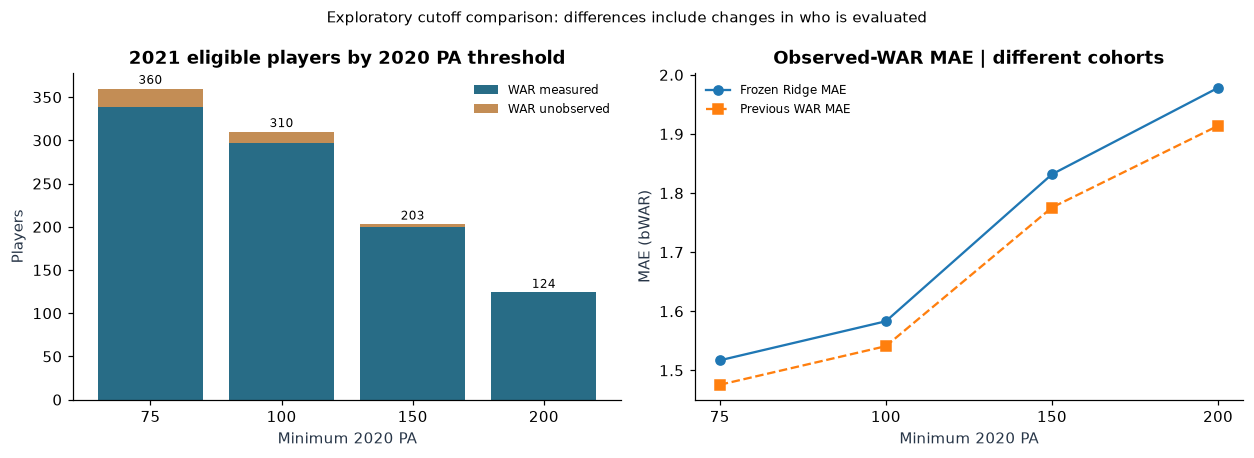

2021 remains in the main external evaluation; no threshold was chosen using unseen future years.
CAUTION: all new 75–199 PA rows are outside the >=200 PA historical training-eligibility definition.
Section 91 status: EXECUTED


In [106]:
# 91 — Season-adjusted 2020 entry thresholds; frozen historical models, no refitting.
status91='NOT_EVALUATED'
eligibility91=pd.DataFrame(); eligible_players91=pd.DataFrame(); context91=pd.DataFrame()
if (external81_status=='EXECUTED_ON_2013_2025_DATA' and 'recent_player81' in globals()
    and 'war_all81' in globals() and 'frozen81' in globals()
    and 'interval_model81' in globals() and 'q81' in globals()):
    # The same 2020 feature inputs used in Section 81; earlier-season labels are never predictors.
    source91=recent_player81.loc[recent_player81.yearID.eq(2020),
                 ['playerID','yearID','PA','OBP','SLG','age']].merge(
        war_all81.loc[war_all81.yearID.eq(2020),['playerID','WAR']],
        on='playerID',how='inner',validate='one_to_one')
    source91=source91.dropna(subset=feature81).copy()
    next_war91=war_all81.loc[war_all81.yearID.eq(2021),['playerID','WAR']].rename(columns={'WAR':'next_WAR'})
    source91=source91.merge(next_war91,on='playerID',how='left',validate='one_to_one')
    source91['observed_next_WAR']=source91.next_WAR.notna()
    source91['pred_frozen_Ridge']=frozen81.predict(source91[feature81])
    source91['pred_previous_WAR']=source91['WAR']
    source91['interval_center']=interval_model81.predict(source91[feature81])
    source91['inside_frozen_90']=(source91.next_WAR>=source91.interval_center-q81)&(source91.next_WAR<=source91.interval_center+q81)
    eligible_players91=source91.loc[source91.PA.ge(75)].copy()
    eligible_players91['eligible_under_200_PA']=eligible_players91.PA.ge(200)
    eligible_players91['target_year']=2021
    records91=[]
    for threshold91 in [75,100,150,200]:
        cohort91=source91.loc[source91.PA.ge(threshold91)].copy()
        measured91=cohort91.loc[cohort91.observed_next_WAR]
        records91.append({'target_year':2021,'minimum_2020_PA':threshold91,
              'eligible_prior_season':len(cohort91),
              'observed_2021_WAR':len(measured91),
              'unobserved_2021_WAR':len(cohort91)-len(measured91),
              'observed_fraction':len(measured91)/len(cohort91) if len(cohort91) else np.nan,
              'mean_2020_PA':cohort91.PA.mean(),
              'frozen_Ridge_MAE':np.abs(measured91.next_WAR-measured91.pred_frozen_Ridge).mean() if len(measured91) else np.nan,
              'previous_WAR_MAE':np.abs(measured91.next_WAR-measured91.pred_previous_WAR).mean() if len(measured91) else np.nan,
              'frozen_conformal_coverage':measured91.inside_frozen_90.mean() if len(measured91) else np.nan,
              'frozen_conformal_width':2*q81,
              'out_of_historical_training_support':threshold91<200})
    eligibility91=pd.DataFrame(records91)
    for year91 in [2020,2021,2022]:
        tmp91=external_predictions81.loc[external_predictions81.target_year.eq(year91)]
        obs91=tmp91.loc[tmp91.observed_next_WAR]
        context91=pd.concat([context91,pd.DataFrame([{
           'target_year':year91, 'input_year':year91-1,
           'original_200PA_eligible':len(tmp91),'measured_next_WAR':len(obs91),
           'mean_prior_PA':tmp91.PA.mean(),
           'frozen_Ridge_MAE':obs91.abs_Ridge_error.mean() if len(obs91) else np.nan
        }])],ignore_index=True)
    # The >=200 group MUST match Section 81's original 2021 cohort exactly.
    original91=external_predictions81.loc[external_predictions81.target_year.eq(2021)]
    assert set(source91.loc[source91.PA.ge(200),'playerID'])==set(original91.playerID)
    assert int(eligibility91.loc[eligibility91.minimum_2020_PA.eq(200),'observed_2021_WAR'].iloc[0])==int(original91.observed_next_WAR.sum())
    display(context91.round(3));display(eligibility91.round(4))
    save_frame(context91,'external_91_nearby_year_cohort_context.csv')
    save_frame(eligibility91,'external_91_2020_pa_eligibility_sensitivity.csv')
    save_frame(eligible_players91,'external_91_extended_2020_cohort_predictions.csv')
    fig,axs91=plt.subplots(1,2,figsize=(11.5,4.2))
    plot91=eligibility91.sort_values('minimum_2020_PA')
    xx91=np.arange(len(plot91))
    axs91[0].bar(xx91,plot91.observed_2021_WAR,color='#286c86',label='WAR measured')
    axs91[0].bar(xx91,plot91.unobserved_2021_WAR,bottom=plot91.observed_2021_WAR,
                 color='#c38d55',label='WAR unobserved')
    for j91,row91 in enumerate(plot91.itertuples()):
        axs91[0].annotate(str(row91.eligible_prior_season),(j91,row91.eligible_prior_season),
             ha='center',xytext=(0,3),textcoords='offset points',fontsize=8)
    axs91[0].set(xticks=xx91,xticklabels=plot91.minimum_2020_PA.astype(str),
                  title='2021 eligible players by 2020 PA threshold',xlabel='Minimum 2020 PA',ylabel='Players')
    axs91[0].legend(frameon=False,fontsize=8)
    axs91[1].plot(xx91,plot91.frozen_Ridge_MAE,'o-',label='Frozen Ridge MAE')
    axs91[1].plot(xx91,plot91.previous_WAR_MAE,'s--',label='Previous WAR MAE')
    axs91[1].set(xticks=xx91,xticklabels=plot91.minimum_2020_PA.astype(str),
                  title='Observed-WAR MAE | different cohorts',xlabel='Minimum 2020 PA',ylabel='MAE (bWAR)')
    axs91[1].legend(frameon=False,fontsize=8)
    fig.suptitle('Exploratory cutoff comparison: differences include changes in who is evaluated',fontsize=10)
    fig.tight_layout();fig.savefig(VISUALS/'external_91_2020_eligibility_sensitivity.png',dpi=170,bbox_inches='tight');plt.show()
    print('2021 remains in the main external evaluation; no threshold was chosen using unseen future years.')
    print('CAUTION: all new 75–199 PA rows are outside the >=200 PA historical training-eligibility definition.')
    status91='EXECUTED'
else:
    print('NOT_EVALUATED: Section 91 requires complete external holdout, frozen models, and 2020/2021 WAR data.')
print('Section 91 status:',status91)


## 92. Time-adaptive conformal calibration | strictly previous target years

Section 87 used a **fixed 2009–2012 calibration period** for all future seasons. Here the underlying Ridge interval-center model stays unchanged, but the conformal residual threshold is recalculated using **only completed earlier target seasons**. Two alternatives use the most recent one or three available seasons. The first 2013 prediction uses the historical calibration pool because no post-2012 label is yet available.

The comparison is made on exactly the same observed-WAR player-seasons as the frozen pooled and frozen CQR intervals. An annual table records which calendar years were used for calibration, the number of residuals, coverage and interval width. Paired season-level bootstrap intervals assess **annual** differences, rather than treating repeated players as independent. This is **forward-only exploratory recalibration**, not an untouched static holdout or a coverage guarantee under a shift like 2021.

**Source-data cross-check:** the previously fixed pooled interval covered about **90.8%** of observed 2013–2025 WAR values; rolling one- and three-year calibration covered about **90.2%** and **90.4%**, respectively, on the same measured cases. Neither rolling method repaired the approximately **72.6%** coverage in 2021. Source vintage or library differences can change individual quantile-model results slightly; the code below regenerates the local results.

**Delayed response to a shock:** a one-year rolling calibrator has no way to use the 2021 outcome errors when making 2021 predictions. Its wider 2022 interval (approximately 8.43 bWAR, with coverage near 98.8%) is an example of the possible overreaction once shock-year residuals enter the calibration set. Coverage must therefore be reported alongside interval width.


,method,seasons,n_observed,player_weighted_coverage,player_weighted_mean_width,coverage_2021
0,Frozen CQR,13,4061,0.9178,5.5988,0.7097
1,Frozen pooled,13,4061,0.9082,5.7081,0.7258
2,Rolling 1-year,13,4061,0.9022,5.6891,0.7258
3,Rolling 3-year,13,4061,0.9042,5.6755,0.7258


,target_year,method,calibration_years,calibration_n,n,coverage,mean_width_WAR,used_historical_fallback
0,2013,Rolling 1-year,2009–2012 historical,1285,319,0.912,5.708,True
1,2013,Rolling 3-year,2009–2012 historical,1285,319,0.912,5.708,True
2,2014,Rolling 1-year,2013–2013,319,333,0.877,5.626,False
3,2014,Rolling 3-year,2013–2013,319,333,0.877,5.626,False
4,2015,Rolling 1-year,2014–2014,333,322,0.910,6.004,False
5,2015,Rolling 3-year,2013–2014,652,322,0.907,5.787,False
6,2016,Rolling 1-year,2015–2015,322,322,0.904,5.614,False
7,2016,Rolling 3-year,2013–2015,974,322,0.907,5.779,False
8,2017,Rolling 1-year,2016–2016,322,313,0.914,5.559,False
9,2017,Rolling 3-year,2014–2016,977,313,0.933,5.891,False


,comparison,metric,units,season_count,paired_annual_mean_difference,season_bootstrap_95_low,season_bootstrap_95_high
0,Rolling 1-year − Frozen pooled,coverage,percentage points,13,-0.5626,-1.9626,1.1283
1,Rolling 1-year − Frozen pooled,mean_width_WAR,bWAR,13,-0.0283,-0.3805,0.4977
2,Rolling 3-year − Frozen pooled,coverage,percentage points,13,-0.3637,-1.1622,0.3766
3,Rolling 3-year − Frozen pooled,mean_width_WAR,bWAR,13,-0.0416,-0.1927,0.1032
4,Frozen CQR − Frozen pooled,coverage,percentage points,13,0.8476,-0.0785,1.9479
5,Frozen CQR − Frozen pooled,mean_width_WAR,bWAR,13,-0.1307,-0.2156,-0.0735


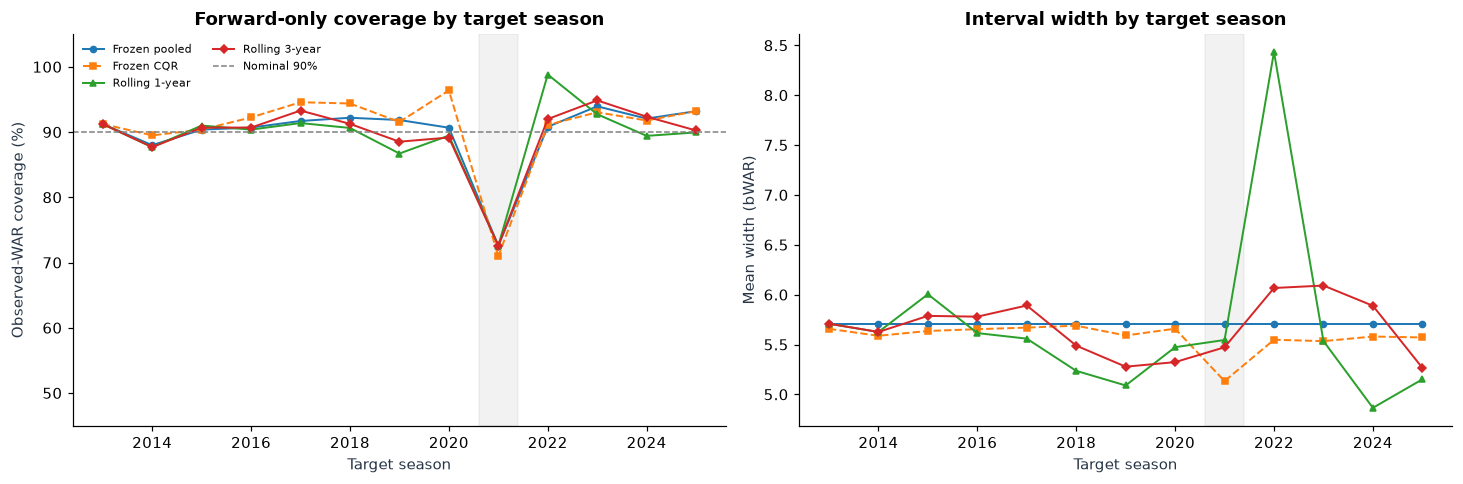

Every rolling threshold uses targets strictly before the evaluation year; 2013 falls back to 2009–2012.
The center predictor is frozen throughout. In a shifted season no method is guaranteed nominal coverage.
Section 92 status: EXECUTED


In [107]:
# 92 — Forward-only rolling residual recalibration, fixed <=2008 Ridge center.
status92='NOT_EVALUATED'
rolling92=pd.DataFrame(); annual92=pd.DataFrame(); summary92=pd.DataFrame(); bootstrap92=pd.DataFrame()
if (external81_status=='EXECUTED_ON_2013_2025_DATA' and status87=='EXECUTED'
    and len(external_players87)>0 and 'cal_resid81' in globals() and 'interval_model81' in globals()):
    from math import ceil
    eval92=external_players87[['playerID','target_year','next_WAR','pooled_covered','pooled_width','cqr_covered','cqr_width']].copy()
    pts92=external_predictions81.loc[external_predictions81.observed_next_WAR,
                        ['playerID','target_year']+feature81].copy()
    eval92=eval92.merge(pts92,on=['playerID','target_year'],how='inner',validate='one_to_one')
    assert len(eval92)==len(external_players87) and not eval92.duplicated(['playerID','target_year']).any()
    eval92['frozen_center']=interval_model81.predict(eval92[feature81])
    eval92['absolute_residual']=(eval92.next_WAR-eval92.frozen_center).abs()
    def forward_quantile92(array92):
        x92=np.asarray(array92,dtype=float)
        x92=x92[np.isfinite(x92)]
        if len(x92)==0:raise ValueError('No conformal scores available.')
        k92=min(len(x92),int(ceil((len(x92)+1)*.90)))
        return float(np.partition(x92,k92-1)[k92-1])
    pre13_scores92=np.asarray(cal_resid81,dtype=float)
    annual_rows92=[]
    for target92 in sorted(eval92.target_year.unique()):
        this92=eval92.loc[eval92.target_year.eq(target92)]
        for window92 in [1,3]:
            last92=eval92.loc[eval92.target_year.between(target92-window92,target92-1)]
            # Exactly previous target years; 2013 uses pre-2013 historical calibration.
            uses_historical92=(target92==2013 or len(last92)<40)
            calibration_scores92=pre13_scores92 if uses_historical92 else last92.absolute_residual.to_numpy()
            q92=forward_quantile92(calibration_scores92)
            if uses_historical92:
                years92='2009–2012 historical'
            else:
                years92=f'{int(last92.target_year.min())}–{int(last92.target_year.max())}'
            inside92=this92.absolute_residual.le(q92)
            rowset92=this92[['playerID','target_year','next_WAR','absolute_residual']].copy()
            rowset92['method']=f'Rolling {window92}-year'
            rowset92['covered']=inside92.to_numpy(dtype=bool)
            rowset92['width_WAR']=2*q92
            rowset92=rowset92.rename(columns={'next_WAR':'observed_next_WAR','absolute_residual':'abs_residual'})
            rolling92=pd.concat([rolling92,rowset92],ignore_index=True)
            annual_rows92.append({'target_year':int(target92),'method':f'Rolling {window92}-year',
              'calibration_years':years92,'calibration_n':len(calibration_scores92),
              'n':len(this92),'coverage':inside92.mean(),'mean_width_WAR':2*q92,
              'used_historical_fallback':uses_historical92})
    # Pre-calibrated static comparators, same players and years.
    for tag92,method92 in [('pooled','Frozen pooled'),('cqr','Frozen CQR')]:
        for yr92,part92 in eval92.groupby('target_year'):
            annual_rows92.append({'target_year':int(yr92),'method':method92,
              'calibration_years':'2009–2012 historical','calibration_n':len(pre13_scores92),
              'n':len(part92),'coverage':part92[f'{tag92}_covered'].mean(),
              'mean_width_WAR':part92[f'{tag92}_width'].mean(),
              'used_historical_fallback':True})
    annual92=pd.DataFrame(annual_rows92)
    assert len(rolling92)==len(eval92)*2 and annual92.target_year.nunique()==13
    # Whole-sample coverage is player-weighted. Season CI compares paired annual differences.
    for method92,grp92 in annual92.groupby('method'):
        summary92=pd.concat([summary92,pd.DataFrame([{'method':method92,
           'seasons':grp92.target_year.nunique(),'n_observed':grp92.n.sum(),
           'player_weighted_coverage':np.average(grp92.coverage,weights=grp92.n),
           'player_weighted_mean_width':np.average(grp92.mean_width_WAR,weights=grp92.n),
           'coverage_2021':grp92.loc[grp92.target_year.eq(2021),'coverage'].iloc[0]
        }])],ignore_index=True)
    wide92=annual92.pivot(index='target_year',columns='method',values=['coverage','mean_width_WAR'])
    rng92=np.random.default_rng(9201)
    for test_method92 in ['Rolling 1-year','Rolling 3-year','Frozen CQR']:
        for column92,units92 in [('coverage','percentage points'),('mean_width_WAR','bWAR')]:
            factor92=100 if column92=='coverage' else 1
            delta92=(wide92[(column92,test_method92)]-wide92[(column92,'Frozen pooled')]).to_numpy()*factor92
            boot92=rng92.choice(delta92,size=(6000,len(delta92)),replace=True).mean(axis=1)
            lo92,hi92=np.quantile(boot92,[.025,.975])
            bootstrap92=pd.concat([bootstrap92,pd.DataFrame([{
               'comparison':f'{test_method92} − Frozen pooled', 'metric':column92,'units':units92,
               'season_count':len(delta92),'paired_annual_mean_difference':delta92.mean(),
               'season_bootstrap_95_low':lo92,'season_bootstrap_95_high':hi92
            }])],ignore_index=True)
    display(summary92.round(4));display(annual92.round(3));display(bootstrap92.round(4))
    for frame92,filename92 in [(rolling92,'external_92_rolling_player_intervals.csv'),
         (annual92,'external_92_annual_forward_calibration.csv'),
         (summary92,'external_92_method_summary.csv'),
         (bootstrap92,'external_92_paired_season_bootstrap.csv')]:
        save_frame(frame92,filename92)
    fig,ax92=plt.subplots(1,2,figsize=(13.4,4.5))
    for method92,style92 in [('Frozen pooled','o-'),('Frozen CQR','s--'),('Rolling 1-year','^-'),('Rolling 3-year','D-')]:
        g92=annual92.loc[annual92.method.eq(method92)].sort_values('target_year')
        ax92[0].plot(g92.target_year,g92.coverage*100,style92,label=method92,markersize=4,linewidth=1.3)
        ax92[1].plot(g92.target_year,g92.mean_width_WAR,style92,label=method92,markersize=4,linewidth=1.3)
    ax92[0].axhline(90,color='gray',ls='--',lw=1,label='Nominal 90%')
    for a92 in ax92:
        a92.axvspan(2020.6,2021.4,color='gray',alpha=.1)
        a92.set_xlabel('Target season')
    ax92[0].set(title='Forward-only coverage by target season',ylabel='Observed-WAR coverage (%)',ylim=(45,105))
    ax92[1].set(title='Interval width by target season',ylabel='Mean width (bWAR)')
    ax92[0].legend(frameon=False,fontsize=7,ncol=2)
    fig.tight_layout();fig.savefig(VISUALS/'external_92_forward_rolling_conformal.png',dpi=170,bbox_inches='tight');plt.show()
    print('Every rolling threshold uses targets strictly before the evaluation year; 2013 falls back to 2009–2012.')
    print('The center predictor is frozen throughout. In a shifted season no method is guaranteed nominal coverage.')
    status92='EXECUTED'
else:
    print('NOT_EVALUATED: Section 92 requires 2013–2025 aligned intervals from Sections 81 and 87.')
print('Section 92 status:',status92)


## 93. Eligibility sensitivity across all external seasons

Section 91 varies the playing-time threshold for the shortened 2020 input season. This extension repeats the **same fixed historical model** and the same threshold grid for **all 2013–2025 target seasons**, so the shortened-season result can be compared with ordinary seasons. The 200-PA cohort remains the primary holdout; players below 200 PA are an **exploratory expansion outside the historical training eligibility rule**. Each expanded group is labelled by its actual lower threshold: **75–199 PA, 100–199 PA, or 150–199 PA**.

Only source-year batting information is used as prediction inputs. WAR outcomes are joined afterward to calculate observation rates and conditional prediction errors. The new analysis reports **Ridge and Previous WAR on identical observed players within each threshold**, plus changes in the mix of selected players. A decrease in MAE when the cohort changes is not a causal or same-sample improvement. The threshold sensitivity was designed after reviewing 2021 and should not be presented as a newly untouched external test.

**Cohort interpretation.** The 200+ PA group remains the primary out-of-period comparison. Under a 75-PA cutoff the additional 75–199 PA group had Ridge MAE around **0.903** versus **0.982** for previous WAR on measured outcomes, compared with **1.311** versus **1.512** in the original 200+ group. The smaller absolute errors in the expanded group reflect a different player population, not a re-trained or intrinsically improved model. Missing-WAR rates also change with eligibility.


,minimum_input_PA,candidate_n,observed_WAR_n,missing_WAR_n,target_seasons,observation_rate,Ridge_MAE,Previous_WAR_MAE,interval_coverage,Ridge_minus_previous_MAE
0,75,6159,5427,732,13,0.8811,1.2084,1.3783,0.9182,-0.1698
1,100,5708,5114,594,13,0.8959,1.2237,1.3966,0.9173,-0.1729
2,150,4999,4570,429,13,0.9142,1.2703,1.4579,0.9123,-0.1876
3,200,4377,4061,316,13,0.9278,1.3112,1.5115,0.9082,-0.2002


,minimum_input_PA,population,candidates,observed_WAR_n,observation_rate,Ridge_MAE,Previous_WAR_MAE
0,75,Original 200+ PA,4377,4061,0.9278,1.3112,1.5115
1,75,Expanded 75–199 PA,1782,1366,0.7666,0.9028,0.9823
2,100,Original 200+ PA,4377,4061,0.9278,1.3112,1.5115
3,100,Expanded 100–199 PA,1331,1053,0.7911,0.8862,0.9538
4,150,Original 200+ PA,4377,4061,0.9278,1.3112,1.5115
5,150,Expanded 150–199 PA,622,509,0.8183,0.9434,1.0302
6,200,Original 200+ PA,4377,4061,0.9278,1.3112,1.5115


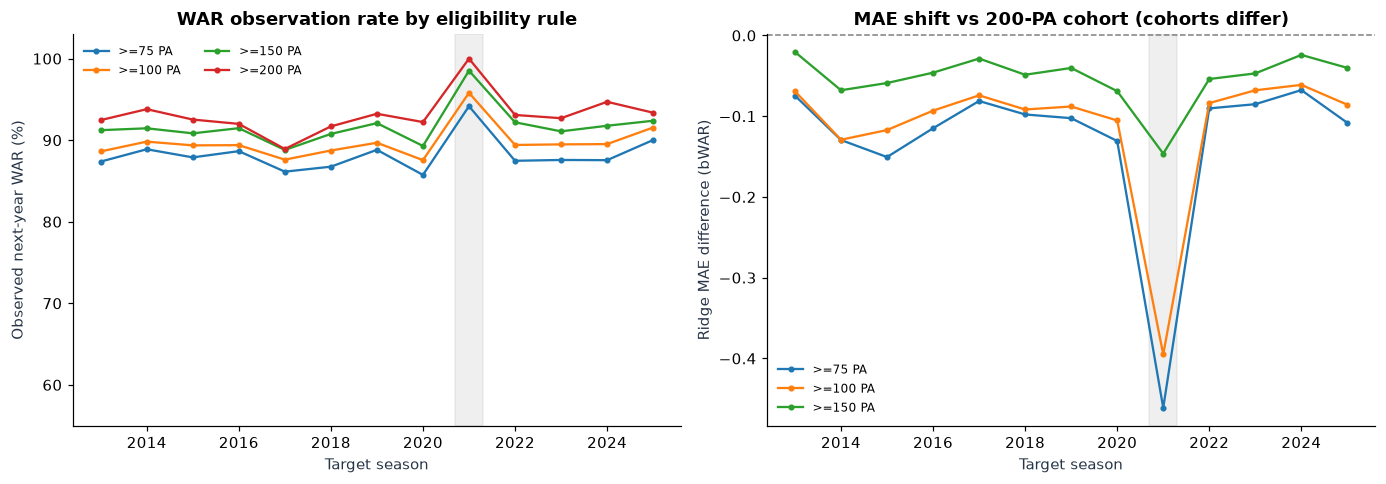

Out-of-training-support warning: 75–199 PA inputs are exploratory; model and thresholds were not retuned.
Section 93 status: EXECUTED


In [108]:
# 93 — Same frozen models; eligibility sensitivity for every external target year.
status93='NOT_EVALUATED'
eligibility93=pd.DataFrame(); annual93=pd.DataFrame(); band93=pd.DataFrame()
if (external81_status=='EXECUTED_ON_2013_2025_DATA'
    and 'recent_player81' in globals() and 'war_all81' in globals()
    and 'frozen81' in globals() and 'interval_model81' in globals()
    and 'q81' in globals()):
    pool93=recent_player81[['playerID','yearID','PA','OBP','SLG','age']].merge(
        war_all81[['playerID','yearID','WAR']],on=['playerID','yearID'],
        how='inner',validate='one_to_one')
    pool93=pool93.loc[pool93.yearID.between(2012,2024)].dropna(subset=feature81).copy()
    next93=war_all81[['playerID','yearID','WAR']].copy()
    next93['yearID']-=1
    next93=next93.rename(columns={'WAR':'next_WAR'})
    pool93=pool93.merge(next93,on=['playerID','yearID'],how='left',validate='one_to_one')
    pool93['target_year']=pool93.yearID.astype(int)+1
    pool93['observed_next_WAR']=pool93.next_WAR.notna()
    pool93['pred_Ridge']=frozen81.predict(pool93[feature81])
    pool93['pred_prev_WAR']=pool93.WAR
    pool93['pred_interval_center']=interval_model81.predict(pool93[feature81])
    pool93['inside_90']=((pool93.next_WAR-pool93.pred_interval_center).abs()<=float(q81))
    # Anchor the original cohort precisely to Section 81; detect a mismatched data merge.
    anchor93=pool93.loc[pool93.PA.ge(200),['playerID','target_year']]
    ref93=external_predictions81[['playerID','target_year']]
    assert len(anchor93)==len(ref93), '200-PA cohort size differs from Section 81.'
    assert set(map(tuple,anchor93.itertuples(index=False,name=None)))==set(map(tuple,ref93.itertuples(index=False,name=None)))
    rows93=[]; groups93=[]
    for cut93 in [75,100,150,200]:
        selected93=pool93.loc[pool93.PA.ge(cut93)]
        for year93,g93 in selected93.groupby('target_year'):
            m93=g93.loc[g93.observed_next_WAR]
            rows93.append({'target_year':int(year93),'minimum_input_PA':cut93,
                'candidate_n':len(g93),'observed_WAR_n':len(m93),
                'missing_WAR_n':len(g93)-len(m93),
                'observation_rate':len(m93)/len(g93) if len(g93) else np.nan,
                'mean_prior_PA':float(g93.PA.mean()),
                'Ridge_MAE':float((m93.next_WAR-m93.pred_Ridge).abs().mean()) if len(m93) else np.nan,
                'Previous_WAR_MAE':float((m93.next_WAR-m93.pred_prev_WAR).abs().mean()) if len(m93) else np.nan,
                'interval_coverage':float(m93.inside_90.mean()) if len(m93) else np.nan})
        # Equal-observation comparisons within each threshold, not across thresholds.
        for key93,slice93 in [('Original 200+ PA',selected93.loc[selected93.PA.ge(200)]),
                            (f'Expanded {cut93}–199 PA',selected93.loc[selected93.PA.lt(200)])]:
            if (cut93==200 and key93.startswith('Expanded')) or len(slice93)==0:continue
            m93=slice93.loc[slice93.observed_next_WAR]
            groups93.append({'minimum_input_PA':cut93,'population':key93,
                'candidates':len(slice93),'observed_WAR_n':len(m93),
                'observation_rate':len(m93)/len(slice93),
                'Ridge_MAE':float((m93.next_WAR-m93.pred_Ridge).abs().mean()) if len(m93) else np.nan,
                'Previous_WAR_MAE':float((m93.next_WAR-m93.pred_prev_WAR).abs().mean()) if len(m93) else np.nan})
    annual93=pd.DataFrame(rows93);band93=pd.DataFrame(groups93)
    # The expanded-cohort label must match the actual eligibility cutoff.
    assert all(
        str(row93.population)==f'Expanded {int(row93.minimum_input_PA)}–199 PA'
        for row93 in band93.itertuples(index=False)
        if str(row93.population).startswith('Expanded ')
    ), 'Expanded-cohort label does not match the PA threshold.'
    eligibility93=annual93.groupby('minimum_input_PA',as_index=False).agg(
        candidate_n=('candidate_n','sum'),observed_WAR_n=('observed_WAR_n','sum'),
        missing_WAR_n=('missing_WAR_n','sum'),target_seasons=('target_year','nunique'))
    eligibility93['observation_rate']=eligibility93.observed_WAR_n/eligibility93.candidate_n
    # Player-weighted overall MAE, avoiding an unweighted average of unequal cohorts.
    for metric93 in ['Ridge_MAE','Previous_WAR_MAE','interval_coverage']:
        vals93=annual93.groupby('minimum_input_PA').apply(
            lambda x: np.average(x[metric93],weights=x.observed_WAR_n),include_groups=False)
        eligibility93[metric93]=eligibility93.minimum_input_PA.map(vals93)
    eligibility93['Ridge_minus_previous_MAE']=eligibility93.Ridge_MAE-eligibility93.Previous_WAR_MAE
    year_orig93=annual93.loc[annual93.minimum_input_PA.eq(200)].set_index('target_year')
    annual93['delta_Ridge_MAE_vs_200PA']=annual93.apply(
        lambda r: r.Ridge_MAE-year_orig93.loc[r.target_year,'Ridge_MAE'],axis=1)
    assert len(annual93)==52 and all(annual93.groupby('minimum_input_PA').target_year.nunique().eq(13))
    display(eligibility93.round(4));display(band93.round(4))
    save_frame(eligibility93,'external_93_all_year_eligibility_summary.csv')
    save_frame(annual93,'external_93_threshold_by_year.csv')
    save_frame(band93,'external_93_original_vs_new_cohorts.csv')
    fig,ax93=plt.subplots(1,2,figsize=(12.7,4.5))
    for cut93 in [75,100,150,200]:
        gr93=annual93.loc[annual93.minimum_input_PA.eq(cut93)].sort_values('target_year')
        ax93[0].plot(gr93.target_year,gr93.observation_rate*100,'o-',ms=3,label=f'>={cut93} PA')
    ax93[0].set(title='WAR observation rate by eligibility rule',
                xlabel='Target season',ylabel='Observed next-year WAR (%)',ylim=(55,103))
    ax93[0].axvspan(2020.7,2021.3,alpha=.12,color='gray')
    ax93[0].legend(frameon=False,ncol=2,fontsize=8)
    spread93=annual93.pivot(index='target_year',columns='minimum_input_PA',values='delta_Ridge_MAE_vs_200PA')
    for cut93 in [75,100,150]:
        ax93[1].plot(spread93.index,spread93[cut93],'o-',ms=3,label=f'>={cut93} PA')
    ax93[1].axhline(0,color='gray',ls='--',lw=1)
    ax93[1].axvspan(2020.7,2021.3,alpha=.12,color='gray')
    ax93[1].set(title='MAE shift vs 200-PA cohort (cohorts differ)',
               xlabel='Target season',ylabel='Ridge MAE difference (bWAR)')
    ax93[1].legend(frameon=False,fontsize=8)
    fig.tight_layout();fig.savefig(VISUALS/'external_93_all_year_threshold_sensitivity.png',dpi=170,bbox_inches='tight');plt.show()
    print('Out-of-training-support warning: 75–199 PA inputs are exploratory; model and thresholds were not retuned.')
    status93='EXECUTED'
else:
    print('NOT_EVALUATED: requires actual Section 81 holdout, player archive, frozen models and WAR labels.')
print('Section 93 status:',status93)

## 94. Regime-aware interval sensitivity | stability versus responsiveness

Section 92 showed that a one-year rolling interval can become unusually wide *after* a poor season. This exploratory analysis compares bounded rolling calibration with the fixed historical interval on the **same observed-WAR cases from 2013–2025**. Rolling residuals are taken only from completed earlier target seasons.

The optional exposure adjustment now uses the **mean prior-season PA among all eligible candidates** for each target season, including players without a subsequently observed WAR. Those candidate records and their PA values are available before the target season. Future WAR observation status is used **only for evaluation**, not to calculate the exposure multiplier. The exported `external_94_eligible_cohort_exposure_audit.csv` gives the cohort size, observed count, and both mean-PA figures; the observed-only mean is displayed for diagnosis, not used by the method.

The historical reference is taken from the pre-2013 training data. The exposure multiplier is capped at **1.30**, while the blend is limited to **±10%** of the frozen interval threshold. Both caps were chosen after reviewing the 2021 failure, so this is **post-hoc sensitivity analysis**, not an independently validated solution. Wider intervals may improve coverage, but their additional width is a real cost. Sudden shifts can still cause coverage to fall below the nominal 90% target.

**Two different aggregation choices (do not interchange them).** Pooling all **4,061 outcome-observed player-seasons** gives **91.70%** bounded/exposure coverage versus **90.82%** frozen pooled, a **+0.88 percentage-point** difference. By contrast, the **unweighted mean of 13 annual coverage differences** in the paired season-resampling table is **+1.46 percentage points**. The pooled value weights each year by its number of observed players, whereas the annual mean gives each year equal weight. The 2021 evaluation includes only **124 observed players**, so the difference in year weights matters. The season-bootstrap interval is an exploratory uncertainty summary, not independent confirmation after post-hoc rule choice. Mean interval width rises from **5.708** to **5.916 bWAR** (player-weighted); this cost must accompany any coverage comparison.


Section 94 source-year exposure audit (all eligible candidates; no outcome-based selection):


,target_year,eligible_candidates,eligible_mean_prior_PA,eligible_median_prior_PA,observed_WAR_n,evaluated_n,observed_only_mean_prior_PA_audit,mean_PA_difference_due_to_outcome_observation,exposure_multiplier,historical_reference_PA
0,2013,345,446.203,446.0,319,319,457.276,11.073,1.029,472.0
1,2014,355,445.941,442.0,333,333,453.009,7.068,1.029,472.0
2,2015,348,449.092,446.0,322,322,459.835,10.743,1.025,472.0
3,2016,350,449.226,451.5,322,322,461.842,12.616,1.025,472.0
4,2017,352,451.361,447.0,313,313,468.278,16.917,1.023,472.0
5,2018,349,456.567,463.0,320,320,469.022,12.455,1.017,472.0
6,2019,355,449.327,456.0,331,331,456.293,6.966,1.025,472.0
7,2020,360,442.456,440.0,332,332,450.970,8.514,1.033,472.0
8,2021,124,229.065,228.0,124,124,229.065,0.000,1.300,472.0
9,2022,362,426.729,408.5,337,337,433.602,6.873,1.052,472.0


,method,seasons,n_observed,player_weighted_coverage,player_weighted_width_WAR,coverage_2021,width_2021,coverage_2022,width_2022
0,Bounded blend,13,4061,0.9064,5.6983,0.7258,5.6373,0.9110,5.8157
1,Bounded blend + exposure,13,4061,0.9170,5.9155,0.8548,7.3285,0.9228,6.1164
2,Frozen pooled,13,4061,0.9082,5.7081,0.7258,5.7081,0.9080,5.7081
3,Rolling 1-year,13,4061,0.9022,5.6891,0.7258,5.5452,0.9881,8.4331
4,Rolling 3-year,13,4061,0.9042,5.6755,0.7258,5.4721,0.9199,6.0666


,target_year,method,n,coverage,mean_width_WAR,calibration_threshold,historical_reference_PA,eligible_cohort_mean_input_PA,eligible_cohort_n,observed_WAR_n,exposure_multiplier
0,2013,Frozen pooled,319,0.912,5.708,2.854,472.0,446.203,345,319,1.029
1,2013,Rolling 1-year,319,0.912,5.708,2.854,472.0,446.203,345,319,1.029
2,2013,Rolling 3-year,319,0.912,5.708,2.854,472.0,446.203,345,319,1.029
3,2013,Bounded blend,319,0.912,5.708,2.854,472.0,446.203,345,319,1.029
4,2013,Bounded blend + exposure,319,0.918,5.871,2.935,472.0,446.203,345,319,1.029
...,...,...,...,...,...,...,...,...,...,...,...
60,2025,Frozen pooled,338,0.932,5.708,2.854,472.0,441.227,362,338,1.034
61,2025,Rolling 1-year,338,0.899,5.151,2.575,472.0,441.227,362,338,1.034
62,2025,Rolling 3-year,338,0.902,5.266,2.633,472.0,441.227,362,338,1.034
63,2025,Bounded blend,338,0.917,5.576,2.788,472.0,441.227,362,338,1.034


,method_minus_frozen,metric,paired_seasons,average_annual_difference,season_bootstrap_low,season_bootstrap_high
0,Rolling 1-year,coverage,13,-0.5626,-1.9660,1.1979
1,Rolling 1-year,mean_width_WAR,13,-0.0283,-0.3836,0.4978
2,Rolling 3-year,coverage,13,-0.3637,-1.2142,0.3616
3,Rolling 3-year,mean_width_WAR,13,-0.0416,-0.1929,0.1032
4,Bounded blend,coverage,13,-0.1591,-0.4575,0.0719
5,Bounded blend,mean_width_WAR,13,-0.0125,-0.0573,0.0320
6,Bounded blend + exposure,coverage,13,1.4636,0.2868,3.4985
7,Bounded blend + exposure,mean_width_WAR,13,0.2745,0.1153,0.5225


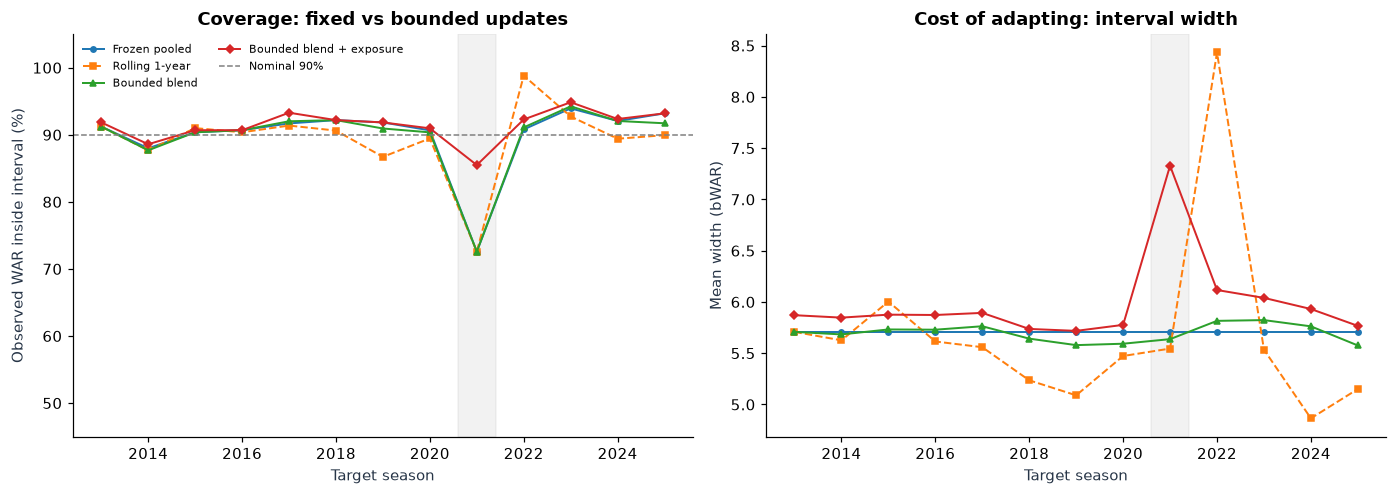

Exposure factors use source-season PA for ALL eligible candidates, including missing future WAR.
The audit-only observed-WAR mean PA is NOT used to calibrate intervals.
EXPLORATORY, post-hoc coefficients: observed coverage is not a future guarantee.
Section 94 status: EXECUTED


In [109]:
# 94 — Historical frozen center, forward-only residual scores, bounded adaptation.
status94='NOT_EVALUATED'
season94=pd.DataFrame();summary94=pd.DataFrame();audit94=pd.DataFrame();bootstrap94=pd.DataFrame()
if (external81_status=='EXECUTED_ON_2013_2025_DATA' and status92=='EXECUTED'
    and len(eval92)>0 and len(annual92)>0 and 'train81' in globals()
    and 'external_predictions81' in globals() and len(external_predictions81)>0):
    reference_pa94=float(train81.loc[train81.PA.ge(200),'PA'].median())
    if not np.isfinite(reference_pa94) or reference_pa94<=0:raise ValueError('Invalid historical PA reference.')
    frozen_q94=float(q81)
    # Use *all eligible input-year players*. Their input PA is known before
    # target-year outcomes occur; future WAR observability is not used to set q.
    inputs94=external_predictions81[['playerID','target_year','PA','observed_next_WAR']].copy()
    inputs94['PA']=pd.to_numeric(inputs94['PA'],errors='coerce')
    if inputs94.PA.isna().any() or inputs94.PA.le(0).any():
        raise ValueError('Section 94 requires valid pre-season PA for every eligible candidate.')
    if inputs94.duplicated(['playerID','target_year']).any():
        raise ValueError('Duplicate eligible player-year keys in Section 94.')
    cohort94=(inputs94.groupby('target_year',as_index=False)
        .agg(eligible_candidates=('playerID','size'),
             eligible_mean_prior_PA=('PA','mean'),
             eligible_median_prior_PA=('PA','median'),
             observed_WAR_n=('observed_next_WAR','sum')))
    observed_pa94=(eval92.groupby('target_year',as_index=False)
        .agg(evaluated_n=('playerID','size'),
             observed_only_mean_prior_PA_audit=('PA','mean')))
    audit94=cohort94.merge(observed_pa94,on='target_year',validate='one_to_one')
    if (audit94.eligible_candidates.lt(audit94.evaluated_n).any()
        or not audit94.observed_WAR_n.eq(audit94.evaluated_n).all()
        or set(audit94.target_year)!=set(eval92.target_year)):
        raise AssertionError('Section 94 evaluation sample does not match eligible source-year cohort.')
    audit94['mean_PA_difference_due_to_outcome_observation']=(
        audit94.observed_only_mean_prior_PA_audit-audit94.eligible_mean_prior_PA)
    audit94['exposure_multiplier']=np.clip(
        np.sqrt(reference_pa94/audit94.eligible_mean_prior_PA.to_numpy()),1.0,1.30)
    audit94['historical_reference_PA']=reference_pa94
    # The observed-only PA column above is audit-only, NEVER used for intervals.
    rows94=[];detail94=[]
    for year94, g94 in eval92.groupby('target_year'):
        year94=int(year94)
        rolling1_q94=float(annual92.loc[(annual92.target_year.eq(year94)) &
                    annual92.method.eq('Rolling 1-year'),'mean_width_WAR'].iloc[0])/2
        rolling3_q94=float(annual92.loc[(annual92.target_year.eq(year94)) &
                    annual92.method.eq('Rolling 3-year'),'mean_width_WAR'].iloc[0])/2
        blended_q94=float(np.clip(.70*frozen_q94+.30*rolling3_q94,
                                   .90*frozen_q94,1.10*frozen_q94))
        # This lookup uses all preseason-eligible players, including those
        # whose subsequent WAR is missing. Evaluation labels remain held out.
        year_inputs94=audit94.loc[audit94.target_year.eq(year94)]
        if len(year_inputs94)!=1:
            raise AssertionError(f'Missing or duplicate source-year candidate cohort for {year94}.')
        mean_input_pa94=float(year_inputs94.eligible_mean_prior_PA.iloc[0])
        exposure94=float(year_inputs94.exposure_multiplier.iloc[0])
        assert np.isfinite(exposure94) and 1<=exposure94<=1.30
        chosen94={'Frozen pooled':frozen_q94,'Rolling 1-year':rolling1_q94,
                  'Rolling 3-year':rolling3_q94,'Bounded blend':blended_q94,
                  'Bounded blend + exposure':blended_q94*exposure94}
        for method94,threshold94 in chosen94.items():
            hit94=g94.absolute_residual.le(threshold94)
            rows94.append({'target_year':year94,'method':method94,'n':len(g94),
                'coverage':float(hit94.mean()),'mean_width_WAR':2*threshold94,
                'calibration_threshold':threshold94,'historical_reference_PA':reference_pa94,
                'eligible_cohort_mean_input_PA':mean_input_pa94,
                'eligible_cohort_n':int(year_inputs94.eligible_candidates.iloc[0]),
                'observed_WAR_n':int(year_inputs94.observed_WAR_n.iloc[0]),
                'exposure_multiplier':exposure94})
            detail94.append(pd.DataFrame({'playerID':g94.playerID.to_numpy(),
                'target_year':year94,'method':method94,'covered':hit94.to_numpy(),
                'width_WAR':2*threshold94}))
    season94=pd.DataFrame(rows94)
    detail94=pd.concat(detail94,ignore_index=True)
    for m94,g94 in season94.groupby('method'):
        summary94=pd.concat([summary94,pd.DataFrame([{'method':m94,
            'seasons':len(g94),'n_observed':int(g94.n.sum()),
            'player_weighted_coverage':float(np.average(g94.coverage,weights=g94.n)),
            'player_weighted_width_WAR':float(np.average(g94.mean_width_WAR,weights=g94.n)),
            'coverage_2021':float(g94.loc[g94.target_year.eq(2021),'coverage'].iloc[0]),
            'width_2021':float(g94.loc[g94.target_year.eq(2021),'mean_width_WAR'].iloc[0]),
            'coverage_2022':float(g94.loc[g94.target_year.eq(2022),'coverage'].iloc[0]),
            'width_2022':float(g94.loc[g94.target_year.eq(2022),'mean_width_WAR'].iloc[0])
        }])],ignore_index=True)
    wide94=season94.pivot(index='target_year',columns='method',values=['coverage','mean_width_WAR'])
    rng94=np.random.default_rng(9402)
    for method94 in ['Rolling 1-year','Rolling 3-year','Bounded blend','Bounded blend + exposure']:
        for metric94,multiplier94 in [('coverage',100),('mean_width_WAR',1)]:
            d94=(wide94[(metric94,method94)]-wide94[(metric94,'Frozen pooled')]).to_numpy()*multiplier94
            draws94=rng94.choice(d94,size=(4000,len(d94)),replace=True).mean(axis=1)
            low94,high94=np.quantile(draws94,[.025,.975])
            bootstrap94=pd.concat([bootstrap94,pd.DataFrame([{
                'method_minus_frozen':method94,'metric':metric94,'paired_seasons':len(d94),
                'average_annual_difference':d94.mean(),'season_bootstrap_low':low94,
                'season_bootstrap_high':high94
            }])],ignore_index=True)
    assert season94.target_year.nunique()==13 and len(detail94)==5*len(eval92)
    assert season94.loc[season94.method.eq('Frozen pooled'),'mean_width_WAR'].nunique()==1
    print('Section 94 source-year exposure audit (all eligible candidates; no outcome-based selection):')
    display(audit94.round(3))
    display(summary94.round(4));display(season94.round(3));display(bootstrap94.round(4))
    for f94,name94 in [(season94,'external_94_forward_regime_annual.csv'),
          (summary94,'external_94_regime_summary.csv'),
          (bootstrap94,'external_94_season_bootstrap.csv'),
          (audit94,'external_94_eligible_cohort_exposure_audit.csv')]:save_frame(f94,name94)
    fig,ax94=plt.subplots(1,2,figsize=(12.8,4.6))
    for method94,style94 in [('Frozen pooled','o-'),('Rolling 1-year','s--'),
                             ('Bounded blend','^-'),('Bounded blend + exposure','D-')]:
        d94=season94.loc[season94.method.eq(method94)].sort_values('target_year')
        ax94[0].plot(d94.target_year,d94.coverage*100,style94,label=method94,ms=3.5,lw=1.3)
        ax94[1].plot(d94.target_year,d94.mean_width_WAR,style94,label=method94,ms=3.5,lw=1.3)
    ax94[0].axhline(90,color='gray',ls='--',lw=1,label='Nominal 90%')
    for a94 in ax94:
        a94.axvspan(2020.6,2021.4,color='gray',alpha=.10)
        a94.set_xlabel('Target season')
    ax94[0].set(title='Coverage: fixed vs bounded updates',ylabel='Observed WAR inside interval (%)',ylim=(45,105))
    ax94[1].set(title='Cost of adapting: interval width',ylabel='Mean width (bWAR)')
    ax94[0].legend(fontsize=7,frameon=False,ncol=2)
    fig.tight_layout();fig.savefig(VISUALS/'external_94_bounded_regime_coverage_width.png',dpi=170,bbox_inches='tight');plt.show()
    print('Exposure factors use source-season PA for ALL eligible candidates, including missing future WAR.')
    print('The audit-only observed-WAR mean PA is NOT used to calibrate intervals.')
    print('EXPLORATORY, post-hoc coefficients: observed coverage is not a future guarantee.')
    status94='EXECUTED'
else:
    print('NOT_EVALUATED: requires completed Sections 81/92 and historical training inputs.')
print('Section 94 status:',status94)

In [110]:
# Run after Sections 1–94. This original audit excludes the separate Section 95 test.
# The audit does not mark skipped branches as complete.
core_files=['Batting','Master','Salaries','Teams']
source_audit82=[]
for name82 in core_files:
    selected82=next((DATA_DIR/f'{name82}{suffix}' for suffix in ['.csv','.csv.zip']
             if (DATA_DIR/f'{name82}{suffix}').is_file()),None)
    source_audit82.append({'file':name82,'available':selected82 is not None,
                 'resolved_filename':selected82.name if selected82 else 'MISSING'})
for name82 in ['WAR.csv','Appearances.csv','Fielding.csv','Pitching.csv','People.csv','plays.csv',
               'Batting_2025.csv','People_2025.csv']:
    path82=DATA_DIR/name82
    source_audit82.append({'file':name82,'available':path82.is_file(),
                           'resolved_filename':name82 if path82.is_file() else 'MISSING'})
source_table82=pd.DataFrame(source_audit82)
completion82=pd.DataFrame([
 {'analysis':'Historical batting / salaries','status':'EXECUTED' if 'p_all' in globals() else 'NOT_EVALUATED'},
 {'analysis':'Measured bWAR','status':'EXECUTED' if war52_ready else 'NOT_EVALUATED'},
 {'analysis':'Forward salary / position (51)','status':position51.get('status','NOT_EVALUATED') if 'position51' in globals() else 'NOT_EVALUATED'},
 {'analysis':'Retrosheet run expectancy (58)','status':play_status58.get('status','NOT_EVALUATED')},
 {'analysis':'RE24 events (76)','status':re24_status76.get('status','NOT_EVALUATED')},
 {'analysis':'Independent fixed-target spend (78)','status':status78},
 {'analysis':'Conformalized quantile bands (79)','status':status79},
 {'analysis':'Roster outcome stability (80)','status':status80},
 {'analysis':'Same-player interval comparison (82)','status':status82},
 {'analysis':'Position-constrained roster (83)','status':status83},
 {'analysis':'Season-block interval evaluation (84)','status':status84},
 {'analysis':'Three-cap roster sensitivity (85)','status':status85},
 {'analysis':'External years with frozen model (81)','status':external81_status},
 {'analysis':'2020/2021 shortened-season stress test (86)','status':status86},
 {'analysis':'External three-method prediction intervals (87)','status':status87},
 {'analysis':'Forward-only adaptive WAR comparison (88)','status':status88},
 {'analysis':'2020 feature-adjustment sensitivity (89)','status':status89},
 {'analysis':'External observation and calibration robustness (90)','status':status90},
 {'analysis':'Shortened-season eligibility (91)','status':status91},
 {'analysis':'Forward-only interval updates (92)','status':status92},
 {'analysis':'All-season eligibility sensitivity (93)','status':status93},
 {'analysis':'Outcome-safe exposure sensitivity (94)','status':status94},
])
print('Resolved data directory:',DATA_DIR)
print('Historical training batting last season:',int(p_all.yearID.max()) if 'p_all' in globals() else 'Unavailable')
print('Separate external batting last season:',int(external_source81.loc[external_source81.source.eq('Batting_2025.csv'),'max_year'].iloc[0]) if len(external_source81) else 'NOT_EVALUATED')
print('ATTENTION: a normal Python run does NOT guarantee all dataset-dependent sections were evaluated.')
display(source_table82);display(completion82)
save_frame(source_table82,'FINAL_SOURCE_INVENTORY.csv')
save_frame(completion82,'FINAL_RESEARCH_COMPLETION.csv')
source_ready82=source_table82[source_table82.file.isin(['WAR.csv','Appearances.csv','plays.csv'])].available.all()
all_core82=all(completion82.loc[completion82.analysis.isin([
    'Historical batting / salaries','Measured bWAR','Independent fixed-target spend (78)',
    'Conformalized quantile bands (79)','Roster outcome stability (80)',
    'Same-player interval comparison (82)']),'status'].eq('EXECUTED'))
print('Research report preparation:',
    'CORE_READY; verify plots and prose' if all_core82 else 'INCOMPLETE_CORE; check statuses')
print('Full local data extensions:',
    'SOURCES_PRESENT; inspect their executed status above' if source_ready82 else 'SOURCES_MISSING; do not claim full-data submission')
print('Independent post-2012 validation:',external81_status)
print('Retrosheet scope:',play_status58.get('gametype_breakdown_before_regular_filter','NOT_EVALUATED'),
      '| excluded non-regular:',play_status58.get('excluded_nonregular_plays','NOT_EVALUATED'))
print('Selected roster comparison:', 'INDEPENDENT_FIXED_TARGET' if status78=='EXECUTED' else status78)
# Persist every attempted solver call, including unsuccessful and time-limited runs.
solver_audit85=pd.DataFrame(solver_attempts78) if 'solver_attempts78' in globals() else pd.DataFrame()
if len(solver_audit85):
    save_frame(solver_audit85,'FINAL_MILP_SOLVER_DIAGNOSTICS.csv')
    by_branch85=solver_audit85.assign(section=solver_audit85.solve_label.str.split('_').str[0])
    solver_summary85=by_branch85.groupby('section',as_index=False).agg(
        attempted=('solve_label','size'),feasible=('feasible_incumbent','sum'),
        certified=('certified_within_gap','sum'))
    display(solver_summary85)
    n_unverified85=int((solver_audit85.feasible_incumbent &
                          ~solver_audit85.certified_within_gap).sum())
    print('Feasible solutions without a certified optimality termination:',n_unverified85)
    if n_unverified85:
        print('CAUTION: inspect FINAL_MILP_SOLVER_DIAGNOSTICS.csv before saying a roster was optimal.')
    elif (solver_audit85.feasible_incumbent).any():
        print('All retained feasible rosters met the requested HiGHS 0.1% gap termination.')
else:
    print('NOT_EVALUATED: no MILP solver audit was generated.')
print('External post-2012 evaluation status:',external81_status)
if status94=='EXECUTED':
    if audit94.empty or not audit94.eligible_candidates.ge(audit94.evaluated_n).all():
        raise AssertionError('Section 94 candidate cohort audit is missing or invalid.')
    print('Section 94: exposure from eligible candidates, not outcome-observed subset.')
    print('Source-year candidate audit:',len(audit94),'seasons; missing WAR total:',
          int((audit94.eligible_candidates-audit94.observed_WAR_n).sum()))
else:
    print('Section 94 remains:',status94)
# The external holdout is an explicitly reported limitation, not a historical-study failure.
historical_required85=[
    'Historical batting / salaries','Measured bWAR',
    'Forward salary / position (51)','Retrosheet run expectancy (58)',
    'RE24 events (76)','Independent fixed-target spend (78)',
    'Conformalized quantile bands (79)','Roster outcome stability (80)',
    'Same-player interval comparison (82)','Position-constrained roster (83)',
    'Season-block interval evaluation (84)','Three-cap roster sensitivity (85)']
completed_required85=completion82.loc[
    completion82.analysis.isin(historical_required85),'status'].eq('EXECUTED').all()
all_data85=bool(source_table82.available.all())
main_solvers85=solver_audit85[solver_audit85.solve_label.str.startswith(('78_','83_'))] if len(solver_audit85) else pd.DataFrame()
verified_main85=bool(len(main_solvers85) and not (
    main_solvers85.feasible_incumbent & ~main_solvers85.certified_within_gap).any())
fully_ready85=completed_required85 and all_data85 and verified_main85
print('Full 10-source historical report check:',
      'READY_FOR_FINAL_REVIEW' if fully_ready85 else 'INCOMPLETE: inspect missing sources, branches or solver termination')
print('Post-2012 holdout is separate; current status:',external81_status)

print('Post-2012 stress test (86):',status86)
print('Post-2012 interval-method comparison (87):',status87)
if external81_status == 'EXECUTED_ON_2013_2025_DATA' and (status86 != 'EXECUTED' or status87 != 'EXECUTED'):
    print('ACTION: External holdout is present, but Sections 86/87 still need review.')

print("Adaptive forecasting (88):",status88)
print("2020-season feature sensitivity (89):",status89)
print("External observation-bias checks (90):",status90)
if external81_status=="EXECUTED_ON_2013_2025_DATA" and any(v!="EXECUTED" for v in [status88,status89,status90]):
    print("ACTION: inspect 88–90; external analysis is not fully evaluated.")

print('Season-adjusted 2020 eligibility (91):',status91)
print('Forward-only conformal calibration (92):',status92)
if external81_status=='EXECUTED_ON_2013_2025_DATA' and (status91!='EXECUTED' or status92!='EXECUTED'):
    print('ACTION: Inspect Sections 91–92 before treating the external appendix as complete.')

print("All-season eligibility sensitivity (93):",status93)
print("Bounded regime interval sensitivity (94):",status94)
if external81_status=="EXECUTED_ON_2013_2025_DATA" and any(s!="EXECUTED" for s in [status91,status92,status93,status94]):
    print("ACTION: At least one external sensitivity check (91–94) is not evaluated.")


Resolved data directory: I:\Dataset\Moneyball Analysis
Historical training batting last season: 2012
Separate external batting last season: 2025
ATTENTION: a normal Python run does NOT guarantee all dataset-dependent sections were evaluated.


,file,available,resolved_filename
0,Batting,True,Batting.csv
1,Master,True,Master.csv
2,Salaries,True,Salaries.csv
3,Teams,True,Teams.csv
4,WAR.csv,True,WAR.csv
5,Appearances.csv,True,Appearances.csv
6,Fielding.csv,True,Fielding.csv
7,Pitching.csv,True,Pitching.csv
8,People.csv,True,People.csv
9,plays.csv,True,plays.csv


,analysis,status
0,Historical batting / salaries,EXECUTED
1,Measured bWAR,EXECUTED
2,Forward salary / position (51),EXECUTED
3,Retrosheet run expectancy (58),EXECUTED
4,RE24 events (76),EXECUTED
5,Independent fixed-target spend (78),EXECUTED
6,Conformalized quantile bands (79),EXECUTED
7,Roster outcome stability (80),EXECUTED
8,Same-player interval comparison (82),EXECUTED
9,Position-constrained roster (83),EXECUTED


Research report preparation: CORE_READY; verify plots and prose
Full local data extensions: SOURCES_PRESENT; inspect their executed status above
Independent post-2012 validation: EXECUTED_ON_2013_2025_DATA
Retrosheet scope: {'regular': 2550439, 'divisionseries': 16768, 'lcs': 12126, 'worldseries': 5504, 'allstar': 1090, 'playoff': 300, 'wildcard': 164} | excluded non-regular: 35952
Selected roster comparison: INDEPENDENT_FIXED_TARGET


,section,attempted,feasible,certified
0,78,16,16,16
1,83,16,16,16
2,85,18,18,18


Feasible solutions without a certified optimality termination: 0
All retained feasible rosters met the requested HiGHS 0.1% gap termination.
External post-2012 evaluation status: EXECUTED_ON_2013_2025_DATA
Section 94: exposure from eligible candidates, not outcome-observed subset.
Source-year candidate audit: 13 seasons; missing WAR total: 316
Full 10-source historical report check: READY_FOR_FINAL_REVIEW
Post-2012 holdout is separate; current status: EXECUTED_ON_2013_2025_DATA
Post-2012 stress test (86): EXECUTED
Post-2012 interval-method comparison (87): EXECUTED
Adaptive forecasting (88): EXECUTED
2020-season feature sensitivity (89): EXECUTED
External observation-bias checks (90): EXECUTED
Season-adjusted 2020 eligibility (91): EXECUTED
Forward-only conformal calibration (92): EXECUTED
All-season eligibility sensitivity (93): EXECUTED
Bounded regime interval sensitivity (94): EXECUTED


# Part 08 · 2026 source gates and decision-focused research extensions

*Technical execution sequence is unchanged. See `01_Moneyball_Main_Research.ipynb` for a topical, reduced presentation.*


## 95. Independently audited 2026 WAR | 2025 source and historical-model freeze

**Objective.** Test the existing historical frozen point and interval models on **2025 source-season features → 2026 target-season Baseball-Reference bWAR**, without revising any model, feature, calibration threshold, or eligibility criterion after observing 2026 labels. Results from Sections 1–94 are unchanged. This is a prepared retrospective extension, **not proof of a live forecast made before the 2026 season**.

**Inputs and source verification.** The Section 81 input pipeline supplies 2025 PA, OBP, SLG and age from `Batting_2025.csv` and `People_2025.csv`; the previous WAR baseline comes from 2025 rows in `WAR.csv`. The Section 95 candidate population is **PA ≥200**. To avoid confusing missing outcomes with player nonparticipation, 2026 bWAR is left-joined **after** the eligible input cohort is finalized. Players without a 2026 WAR observation remain unobserved, never zero-imputed. Before evaluating, a separately reviewed `SOURCE_2025_COMPLETENESS.json` must confirm final 2025 batting, player metadata, 2025 WAR consistency, source references, verification notes and **SHA-256 hashes of all three exact input CSVs**. The code re-reads the disk files and checks that they match the data already loaded in the current kernel. **Restart Kernel & Run All Cells** is required after changing inputs.

**Explicit exclusion audit.** The preliminary audit now distinguishes missing 2025 WAR *rows*, missing 2025 WAR *values*, missing batting rates, missing ages and other/nonfinite features using **mutually exclusive reasons**. The candidate tally and reasons are computed from 2025 information alone; they do not use 2026 outcome availability. A previously saved readiness check had 348 players meeting the PA cutoff and 343 complete predictions, but the **five individual exclusion reasons require a fresh audit on the local source files** and are not presumed in this release.

**Historical model lock.** The original `frozen81` point model uses training target years through 2012; Section 87's interval center and CQR fits use target years through 2008, with 2009–2012 calibration. The unchanged thresholds, PA bands and feature order are reused. A new `external_95_CURRENT_MODEL_FINGERPRINT.json` export records hashes of the historical training, fit and calibration frames, **all four fitted estimators**, features, thresholds and installed package versions. The data owner must compare it against the previously approved study sources, record the appropriate historical provenance, and approve it in `MODEL_2026_FREEZE.json`. The approval is checked against the **entire combined fingerprint**. A newly computed fingerprint alone is **not** evidence that the model was prospectively frozen or that historic data are authentic.

**2026 labels.** The separate `WAR_2026_COMPLETENESS.json` verifies official completed-season source identity, metric definition, provenance/verification notes and a SHA-256 of the **exact** `WAR.csv`. Neither 2026 rows nor a manually checked box automatically establish real-world completeness. All three documents are required; failed or absent attestations block 2026 **metrics**. Candidate counts and frozen-model fingerprints may still be displayed as readiness diagnostics.

**If source clearance succeeds:** compare frozen Ridge versus previous WAR by MAE/RMSE, and pooled, PA-group and CQR 90% intervals by observed-WAR coverage and mean width. Export explicit eligible/observed/missing-outcome denominators. This is a one-season out-of-period check; Section 94's exploratory post-hoc exposure correction is **not** promoted to the primary frozen benchmark.

**Saved release status: not evaluated on verified 2026 WAR.** Section 95's previous run only displayed a pending-readiness status, not performance. The revised Section 95 cell has **no cached output and must be rerun locally** after the source approvals. See `2026_HOLDOUT_GUIDE_KR.md` for Korean instructions.


In [111]:
# 95 — Independent 2026-year audit. Do not infer completeness from year labels.
# The original 2013–2025 models, thresholds, and test results remain unchanged.
import hashlib
import json
import joblib
import sklearn
from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error

status95 = 'NOT_EVALUATED'
audit95 = pd.DataFrame()
exclusions95 = pd.DataFrame()
summary95 = pd.DataFrame()
predictions95 = pd.DataFrame()
interval_metrics95 = pd.DataFrame()
model_freeze95 = {}


def _file_sha256_95(path, block_size=4 * 1024 * 1024):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for block in iter(lambda: handle.read(block_size), b''):
            digest.update(block)
    return digest.hexdigest()


def _attestation95(path):
    if not path.is_file():
        return None, 'MISSING'
    try:
        with path.open('r', encoding='utf-8-sig') as handle:
            data = json.load(handle)
        if not isinstance(data, dict):
            raise ValueError('The verification document must be a JSON object.')
        return data, 'PRESENT'
    except (ValueError, OSError) as exc:
        return None, f'INVALID: {exc}'


def _hash_value95(value):
    return isinstance(value, str) and len(value.strip()) == 64 and all(
        c in '0123456789abcdef' for c in value.strip().lower())


def _freeze_record95():
    # Fit and calibration inputs are strictly pre-2013, including the estimator state.
    # A current fingerprint is a reproducibility record, NOT proof of preregistration.
    features = list(feature81)
    hist_columns = ['playerID', 'yearID', 'target_year'] + features + ['next_WAR']
    def training_hash(data):
        return joblib.hash(data.loc[:, hist_columns].sort_values(
            ['target_year', 'playerID', 'yearID']).reset_index(drop=True))
    return {
        'feature_order': features,
        'prior_PA_cutoff': 200,
        'point_model_train_through_target_year': int(train81.target_year.max()),
        'interval_fit_through_target_year': int(older81.target_year.max()),
        'interval_calibration_target_years': [2009, 2010, 2011, 2012],
        'train_input_joblib_hash': training_hash(train81),
        'interval_fit_input_joblib_hash': training_hash(older81),
        'interval_calibration_input_joblib_hash': training_hash(calib81),
        'fitted_model_joblib_hashes': {
            'frozen_ridge': joblib.hash(frozen81),
            'interval_center': joblib.hash(interval_model81),
            'cqr_lower': joblib.hash(lower_fit87),
            'cqr_upper': joblib.hash(upper_fit87),
        },
        'unchanged_interval_thresholds': {
            'pooled': float(pooled_q87),
            'pa_group': {str(k): float(v) for k, v in pa_thresholds87.items()},
            'cqr': float(cqr_q87),
        },
        'ridge_alpha': float(frozen81.named_steps['ridge'].alpha),
        'python_package_versions': {
            'scikit_learn': sklearn.__version__,
            'pandas': pd.__version__,
            'joblib': joblib.__version__,
        },
    }


def _run_2026_audit95():
    global audit95, exclusions95, summary95, predictions95, interval_metrics95, model_freeze95
    required = [
        'recent_player81', 'new_bat81', 'new_people_df81', 'war_all81',
        'train81', 'older81', 'calib81', 'frozen81', 'interval_model81',
        'lower_fit87', 'upper_fit87', 'feature81', 'pooled_q87',
        'pa_thresholds87', 'cqr_q87', 'external81_status', 'status87',
    ]
    missing = [name for name in required if name not in globals()]
    if missing:
        print('Earlier fixed models are not available:', ', '.join(missing))
        return 'WAITING_FOR_PRIOR_FROZEN_MODELS'
    if external81_status != 'EXECUTED_ON_2013_2025_DATA' or status87 != 'EXECUTED':
        print('Sections 81 and 87 must successfully evaluate before Section 95.')
        return 'WAITING_FOR_PRIOR_FROZEN_MODELS'

    files = {name: DATA_DIR / name for name in
             ['Batting_2025.csv', 'People_2025.csv', 'WAR.csv']}
    missing_files = [name for name, path in files.items() if not path.is_file()]
    if missing_files:
        print('Required external files are missing:', ', '.join(missing_files))
        return 'WAITING_FOR_EXTERNAL_CSV_FILES'

    if (int(train81.target_year.max()) > 2012 or
        int(older81.target_year.max()) > 2008 or
        not calib81.target_year.between(2009, 2012).all() or
        sorted(set(calib81.target_year.astype(int))) != [2009, 2010, 2011, 2012]):
        print('Historical model / calibration year boundary is not frozen.')
        return 'BLOCKED_HISTORICAL_TIME_BOUNDARY'
    if list(feature81) != ['WAR', 'PA', 'OBP', 'SLG', 'age']:
        return 'BLOCKED_FEATURE_DEFINITION_CHANGED'
    if float(frozen81.named_steps['ridge'].alpha) != 50.0:
        return 'BLOCKED_FROZEN_RIDGE_PARAMETER_CHANGED'
    if pd.to_numeric(new_bat81.yearID, errors='coerce').max() != 2025:
        return 'BLOCKED_2025_BATTING_VINTAGE_MISMATCH'

    # Explicit candidate attrition: retain eligible source-year records before
    # joining past WAR and exclude sequentially, never using 2026 label presence.
    inputs = recent_player81.loc[
        recent_player81.yearID.eq(2025),
        ['playerID', 'yearID', 'PA', 'OBP', 'SLG', 'age']
    ].copy()
    eligible = inputs.loc[inputs.PA.ge(200)].copy()
    prior = war_all81.loc[war_all81.yearID.eq(2025),
                          ['playerID', 'yearID', 'WAR']].copy()
    joined = eligible.merge(prior, on=['playerID', 'yearID'], how='left',
                            validate='one_to_one', indicator='_war_row')
    joined['exclusion_reason'] = 'ELIGIBLE'
    rules = [
        ('NO_2025_WAR_ROW', joined['_war_row'].eq('left_only')),
        ('MISSING_2025_WAR', joined.WAR.isna()),
        ('MISSING_2025_OBP_OR_SLG', joined[['OBP', 'SLG']].isna().any(axis=1)),
        ('MISSING_2025_AGE', joined.age.isna()),
        ('OTHER_MISSING_FEATURE', joined[feature81].isna().any(axis=1)),
    ]
    for name, mask in rules:
        joined.loc[joined.exclusion_reason.eq('ELIGIBLE') & mask, 'exclusion_reason'] = name
    finite = np.isfinite(joined[feature81].apply(pd.to_numeric, errors='coerce').to_numpy()).all(axis=1)
    joined.loc[joined.exclusion_reason.eq('ELIGIBLE') & ~finite,
               'exclusion_reason'] = 'NONFINITE_2025_FEATURE'
    exclusions95 = (joined.groupby('exclusion_reason', dropna=False)
                    .size().rename('n').reset_index().sort_values('exclusion_reason'))
    cohort = joined.loc[joined.exclusion_reason.eq('ELIGIBLE'),
                        ['playerID', 'yearID'] + list(feature81)].copy()
    cohort['target_year'] = 2026
    if len(joined) != int(exclusions95.n.sum()) or len(cohort) + int(
            joined.exclusion_reason.ne('ELIGIBLE').sum()) != len(eligible):
        raise AssertionError('2025 cohort exclusions do not reconcile.')
    if cohort.duplicated(['playerID', 'target_year']).any():
        raise AssertionError('Duplicated players in the 2026 prediction cohort.')

    n_war25 = int(war_all81.yearID.eq(2025).sum())
    n_war26 = int(war_all81.yearID.eq(2026).sum())
    audit95 = pd.DataFrame([{
        'input_year': 2025, 'target_year': 2026, 'PA_cutoff': 200,
        '2025_PA_eligible_before_feature_checks': len(eligible),
        '2025_feature_complete_candidates': len(cohort),
        '2025_excluded_candidates': len(eligible) - len(cohort),
        '2025_WAR_rows': n_war25, '2026_WAR_rows_UNVERIFIED': n_war26,
        '2025_sources_verified': False, 'model_freeze_verified': False,
        '2026_WAR_verified': False, '2026_scores_computed': False,
    }])
    display(audit95)
    print('Exclusive 2025 candidate-exclusion reasons (independent of 2026 outcomes):')
    display(exclusions95)
    if len(cohort) < 50 or n_war25 < 100 or n_war26 < 100:
        return 'BLOCKED_INSUFFICIENT_SOURCE_ROWS'

    # Check exact fitted estimators, historical training arrays, and thresholds;
    # the external approval file must match this fingerprint before scoring.
    model_freeze95 = _freeze_record95()
    serialized = json.dumps(model_freeze95, sort_keys=True, ensure_ascii=False,
                            separators=(',', ':'), allow_nan=False)
    freeze_sha = hashlib.sha256(serialized.encode('utf-8')).hexdigest()
    audit95.loc[0, 'model_freeze_sha256'] = freeze_sha
    PROCESSED.mkdir(parents=True, exist_ok=True)
    fingerprint_path = PROCESSED / 'external_95_CURRENT_MODEL_FINGERPRINT.json'
    with fingerprint_path.open('w', encoding='utf-8') as handle:
        json.dump({'model_freeze_sha256': freeze_sha,
                   'fingerprint_components': model_freeze95,
                   'warning': ('A freshly computed fingerprint does NOT prove that a model '
                               'was selected prospectively or that source data are authentic.')},
                  handle, indent=2, ensure_ascii=False)

    war_proof, war_state = _attestation95(DATA_DIR / 'WAR_2026_COMPLETENESS.json')
    feature_proof, feature_state = _attestation95(DATA_DIR / 'SOURCE_2025_COMPLETENESS.json')
    lock_proof, lock_state = _attestation95(DATA_DIR / 'MODEL_2026_FREEZE.json')
    if war_proof is None or feature_proof is None or lock_proof is None:
        print('2026 verification is pending; no outcome metrics calculated.')
        print('WAR_2026_COMPLETENESS.json:', war_state)
        print('SOURCE_2025_COMPLETENESS.json:', feature_state)
        print('MODEL_2026_FREEZE.json:', lock_state)
        print('Current frozen-model fingerprint saved:', fingerprint_path)
        return 'PENDING_INDEPENDENT_SOURCE_AND_MODEL_VERIFICATION'

    war_expected = str(war_proof.get('war_csv_sha256', '')).strip().lower()
    ok_war = (
        war_proof.get('target_season') == 2026 and
        war_proof.get('war_metric') == 'Baseball-Reference bWAR' and
        war_proof.get('full_season_confirmed') is True and
        war_proof.get('independent_source_confirmed') is True and
        all(str(war_proof.get(key, '')).strip() for key in
            ['source_reference', 'verified_date', 'verification_notes']) and
        _hash_value95(war_expected)
    )
    ok_feature = (
        feature_proof.get('feature_season') == 2025 and
        feature_proof.get('full_2025_regular_season_confirmed') is True and
        feature_proof.get('player_metadata_verified') is True and
        feature_proof.get('war_2025_consistency_verified') is True and
        all(str(feature_proof.get(key, '')).strip() for key in
            ['batting_source_reference', 'people_source_reference',
             'verified_date', 'verification_notes']) and
        isinstance(feature_proof.get('file_sha256'), dict) and
        all(_hash_value95(feature_proof['file_sha256'].get(fname, '')) for fname in files)
    )
    ok_freeze = (
        lock_proof.get('historical_model_approved') is True and
        lock_proof.get('target_season') == 2026 and
        all(str(lock_proof.get(key, '')).strip() for key in
            ['approval_date', 'historical_source_reference', 'approval_notes']) and
        _hash_value95(lock_proof.get('model_freeze_sha256', ''))
    )
    if not (ok_war and ok_feature and ok_freeze):
        return 'PENDING_INCOMPLETE_ATTESTATIONS'

    current_hashes = {name: _file_sha256_95(path) for name, path in files.items()}
    feature_hashes = {key: str(value).strip().lower() for key, value in
                      feature_proof['file_sha256'].items()}
    if war_expected != current_hashes['WAR.csv']:
        return 'BLOCKED_2026_WAR_SOURCE_HASH_MISMATCH'
    if any(feature_hashes[fname] != actual for fname, actual in current_hashes.items()):
        return 'BLOCKED_2025_SOURCE_HASH_MISMATCH'
    if str(lock_proof['model_freeze_sha256']).strip().lower() != freeze_sha:
        return 'BLOCKED_HISTORICAL_MODEL_FREEZE_MISMATCH'

    # Re-read files and assert that kernel objects used in Section 81 have NOT
    # gone stale after a source file was changed on disk. Restart & Run All is mandatory.
    current_bat = pd.read_csv(files['Batting_2025.csv'], encoding='utf-8-sig', low_memory=False)
    current_bat.columns = current_bat.columns.str.replace('\ufeff', '', regex=False).str.strip()
    current_bat['yearID'] = pd.to_numeric(current_bat['yearID'], errors='coerce')
    current_people = pd.read_csv(files['People_2025.csv'], encoding='utf-8-sig', low_memory=False)
    current_people.columns = current_people.columns.str.replace('\ufeff', '', regex=False).str.strip()
    current_people = current_people.drop_duplicates('playerID').copy()
    current_people['birthYear'] = pd.to_numeric(current_people['birthYear'], errors='coerce')
    current_war = pd.read_csv(files['WAR.csv'], encoding='utf-8-sig', low_memory=False)
    current_war.columns = current_war.columns.str.replace('\ufeff', '', regex=False).str.strip()
    current_war['yearID'] = pd.to_numeric(current_war['yearID'], errors='coerce')
    current_war['WAR'] = pd.to_numeric(current_war['WAR'], errors='coerce')
    current_war = current_war.dropna(subset=['playerID', 'yearID']).copy()
    if not (current_bat.equals(new_bat81) and
            current_people.equals(new_people_df81) and
            current_war.equals(war_all81)):
        print('Disk data differ from the objects loaded earlier. Restart & Run All Cells.')
        return 'BLOCKED_STALE_LOADED_SOURCE_DATA'

    audit95.loc[0, '2025_sources_verified'] = True
    audit95.loc[0, 'model_freeze_verified'] = True
    audit95.loc[0, '2026_WAR_verified'] = True
    audit95.loc[0, 'WAR_csv_sha256'] = war_expected
    audit95.loc[0, '2025_Batting_sha256'] = current_hashes['Batting_2025.csv']
    audit95.loc[0, '2025_People_sha256'] = current_hashes['People_2025.csv']

    if n_war26 / n_war25 < 0.75:
        return 'BLOCKED_SUSPECTED_PARTIAL_2026_WAR_RELEASE'
    labels = war_all81.loc[war_all81.yearID.eq(2026),
                           ['playerID', 'WAR']].rename(columns={'WAR': 'next_WAR'}).copy()
    labels['target_year'] = 2026
    candidates = cohort.merge(labels, on=['playerID', 'target_year'],
                              how='left', validate='one_to_one')
    candidates['observed_next_WAR'] = candidates.next_WAR.notna()
    n_observed = int(candidates.observed_next_WAR.sum())
    ratio_observed = n_observed / len(candidates)
    audit95.loc[0, 'observed_next_WAR_n'] = n_observed
    audit95.loc[0, 'missing_next_WAR_n'] = len(candidates)-n_observed
    audit95.loc[0, 'observed_next_WAR_fraction'] = ratio_observed
    if n_observed < 50 or ratio_observed < 0.75:
        return 'BLOCKED_SUSPECTED_PARTIAL_2026_WAR_MATCHES'

    # Exactly the frozen 2012 and earlier fits, unchanged PA-group breakpoints.
    candidates['pred_Ridge'] = frozen81.predict(candidates[feature81])
    candidates['pred_previous_WAR'] = candidates.WAR
    centered = interval_model81.predict(candidates[feature81])
    candidates['pooled_lower'] = centered - float(pooled_q87)
    candidates['pooled_upper'] = centered + float(pooled_q87)
    group = pd.cut(candidates.PA, [199, 299, 499, np.inf],
                   labels=['200–299', '300–499', '500+']).astype(str)
    widths = np.array([float(pa_thresholds87.get(b, pooled_q87)) for b in group])
    candidates['pa_group_lower'] = centered - widths
    candidates['pa_group_upper'] = centered + widths
    lo = lower_fit87.predict(candidates[feature81])
    hi = upper_fit87.predict(candidates[feature81])
    candidates['cqr_lower'] = np.minimum(lo, hi) - float(cqr_q87)
    candidates['cqr_upper'] = np.maximum(lo, hi) + float(cqr_q87)

    obs = candidates.loc[candidates.observed_next_WAR].copy()
    ridge_mae = mean_absolute_error(obs.next_WAR, obs.pred_Ridge)
    base_mae = mean_absolute_error(obs.next_WAR, obs.pred_previous_WAR)
    summary95 = pd.DataFrame([{
        'target_year': 2026, 'feature_year': 2025,
        'eligible_candidates': len(candidates),
        'observed_WAR_n': n_observed, 'unobserved_WAR_n': len(candidates) - n_observed,
        'observed_WAR_fraction': ratio_observed,
        'frozen_Ridge_MAE': ridge_mae, 'previous_WAR_MAE': base_mae,
        'Ridge_minus_previous_MAE': ridge_mae - base_mae,
        'frozen_Ridge_RMSE': np.sqrt(mean_squared_error(obs.next_WAR, obs.pred_Ridge)),
        'previous_WAR_RMSE': np.sqrt(mean_squared_error(obs.next_WAR, obs.pred_previous_WAR)),
        'frozen_model_fingerprint': freeze_sha,
    }])
    rows = []
    for name, prefix in [('Pooled conformal', 'pooled'),
                         ('PA-group conformal', 'pa_group'), ('Frozen CQR', 'cqr')]:
        lower, upper = f'{prefix}_lower', f'{prefix}_upper'
        interval_width = obs[upper] - obs[lower]
        if interval_width.lt(0).any():
            raise AssertionError('Negative interval width in the 2026 test.')
        rows.append({
            'target_year': 2026, 'method': name, 'observed_WAR_n': n_observed,
            'nominal_coverage': 0.90,
            'coverage_90': float(obs.next_WAR.between(obs[lower], obs[upper]).mean()),
            'mean_interval_width_WAR': float(interval_width.mean()),
        })
    interval_metrics95 = pd.DataFrame(rows)
    predictions95 = candidates.copy()
    audit95.loc[0, '2026_scores_computed'] = True
    save_frame(audit95, 'external_95_2026_source_cohort_and_freeze_audit.csv')
    save_frame(exclusions95, 'external_95_2025_candidate_exclusion_reasons.csv')
    save_frame(summary95, 'external_95_2026_frozen_model_performance.csv')
    save_frame(interval_metrics95, 'external_95_2026_interval_performance.csv')
    save_frame(predictions95, 'external_95_2026_all_eligible_predictions.csv')
    display(audit95); display(summary95.round(4)); display(interval_metrics95.round(4))
    fig, axes = plt.subplots(1, 2, figsize=(11.6, 3.8))
    axes[0].bar(['Frozen Ridge', 'Previous WAR'], [ridge_mae, base_mae])
    axes[0].set(ylabel='2026 MAE (bWAR)', title='2026 | frozen point forecasts')
    axes[1].scatter(interval_metrics95.method, 100 * interval_metrics95.coverage_90, s=65)
    axes[1].axhline(90, ls='--', color='gray', label='Nominal 90%')
    axes[1].set(ylabel='Coverage (%)', title='2026 | pre-2013 intervals', ylim=(0, 101))
    axes[1].tick_params(axis='x', rotation=18)
    fig.tight_layout()
    fig.savefig(VISUALS / 'external_95_2026_frozen_validation.png', dpi=160,
                bbox_inches='tight')
    plt.show()
    print('Interpretation: metrics condition on observed 2026 WAR only; one additional year.')
    print('This retrospectively prepared extension is NOT a preregistered pre-2026 prediction.')
    return 'EVALUATED_ON_VERIFIED_2026_SOURCE_AND_LOCKED_MODELS'


status95 = _run_2026_audit95()
print('Section 95 independent-year status:', status95)


,input_year,target_year,PA_cutoff,2025_PA_eligible_before_feature_checks,2025_feature_complete_candidates,2025_excluded_candidates,2025_WAR_rows,2026_WAR_rows_UNVERIFIED,2025_sources_verified,model_freeze_verified,2026_WAR_verified,2026_scores_computed
0,2025,2026,200,348,343,5,1470,1472,False,False,False,False


Exclusive 2025 candidate-exclusion reasons (independent of 2026 outcomes):


,exclusion_reason,n
0,ELIGIBLE,343
1,NO_2025_WAR_ROW,5


2026 verification is pending; no outcome metrics calculated.
WAR_2026_COMPLETENESS.json: MISSING
SOURCE_2025_COMPLETENESS.json: MISSING
MODEL_2026_FREEZE.json: MISSING
Current frozen-model fingerprint saved: C:\Users\htpar\Downloads\outputs\processed\external_95_CURRENT_MODEL_FINGERPRINT.json
Section 95 independent-year status: PENDING_INDEPENDENT_SOURCE_AND_MODEL_VERIFICATION


## 96. Data provenance and integrity | independent reference required

Each of the 12 inputs is checked for existence and its *local* SHA-256 is recorded when feasible. **No local hash can independently authenticate its own source.** Populate `Moneyball_expected_source_manifest.json` manually with each input's independently reviewed `sha256_expected`, `official_source_url`, `upstream_release_id`, `verified_by` and `verified_utc`. The comparison never rewrites this reference. Missing required files and mismatches have separate statuses; a mismatch fails loudly. For the ~9.27 GB `plays.csv`, set `MONEYBALL_HASH_ALL=1` to include the expensive full hash. Unverified or missing inputs block *certified* claims, not historical descriptive interpretation. This is an integrity gate, not a claim that every year or data definition is externally validated.


In [112]:
import os, json, hashlib
from datetime import datetime, timezone
from pathlib import Path
inputs96 = {
    'Batting.csv': ('Batting.csv','Batting.csv.zip'),
    'Master.csv': ('Master.csv','Master.csv.zip'),
    'Salaries.csv': ('Salaries.csv','Salaries.csv.zip'),
    'Teams.csv': ('Teams.csv','Teams.csv.zip'),
    'WAR.csv': ('WAR.csv',), 'Appearances.csv': ('Appearances.csv',),
    'Fielding.csv': ('Fielding.csv',), 'Pitching.csv': ('Pitching.csv',),
    'People.csv': ('People.csv',), 'plays.csv': ('plays.csv','plays.zip'),
    'Batting_2025.csv': ('Batting_2025.csv',),
    'People_2025.csv': ('People_2025.csv',),
}

def sha256_file96(path, block_size=8*1024*1024):
    digest = hashlib.sha256()
    with open(path, 'rb') as reader:
        for block in iter(lambda: reader.read(block_size), b''):
            digest.update(block)
    return digest.hexdigest()

# A locally generated manifest is an inventory, NOT a trusted reference hash.
# To verify provenance, populate the separate expected-source manifest from independently
# reviewed publisher records. Never overwrite that manifest from the local files.
ref_path96=DATA_DIR/'Moneyball_expected_source_manifest.json'
try:
    expected96=json.loads(ref_path96.read_text(encoding='utf-8')) if ref_path96.is_file() else {}
    if not isinstance(expected96,dict):raise ValueError('Expected a JSON object.')
except (ValueError, json.JSONDecodeError) as exc:
    raise ValueError(f'Invalid manually maintained provenance manifest: {ref_path96}') from exc
hash_large96=os.environ.get('MONEYBALL_HASH_ALL','0')=='1'
rows96=[]
for logical96,options96 in inputs96.items():
    path96=next((DATA_DIR/name96 for name96 in options96 if (DATA_DIR/name96).is_file()),None)
    ref96=expected96.get(logical96,{})
    if not isinstance(ref96,dict):raise ValueError(f'Bad provenance entry: {logical96}')
    if path96 is None:
        rows96.append(dict(logical_input=logical96,filename='',size_bytes=np.nan,
             mtime_utc='',sha256='',integrity_status='MISSING_REQUIRED_SOURCE',upstream_verified=False))
        continue
    size96=path96.stat().st_size
    sha96=sha256_file96(path96) if (hash_large96 or size96<=500_000_000) else ''
    expected_hash96=str(ref96.get('sha256_expected') or '').strip().lower()
    valid_ref96=(bool(ref96.get('official_source_url')) and
                 bool(ref96.get('upstream_release_id')) and
                 bool(ref96.get('verified_by')) and bool(ref96.get('verified_utc')) and
                 bool(expected_hash96))
    if sha96 and expected_hash96 and sha96 != expected_hash96:
        stat96='LOCAL_HASH_MISMATCH'
    elif sha96 and valid_ref96 and sha96==expected_hash96:
        stat96='VERIFIED_AGAINST_REVIEWED_REFERENCE'
    elif not sha96:
        stat96='LARGE_FILE_HASH_DEFERRED'
    elif expected_hash96 and sha96==expected_hash96:
        stat96='HASH_MATCH_METADATA_INCOMPLETE'
    else:
        stat96='UPSTREAM_UNVERIFIED'
    rows96.append(dict(logical_input=logical96,filename=path96.name,
        size_bytes=int(size96),mtime_utc=datetime.fromtimestamp(
            path96.stat().st_mtime,timezone.utc).isoformat(),sha256=sha96,
        integrity_status=stat96,
        upstream_verified=stat96=='VERIFIED_AGAINST_REVIEWED_REFERENCE'))
source96=pd.DataFrame(rows96)
missing96=source96.integrity_status.eq('MISSING_REQUIRED_SOURCE').any()
mismatch96=source96.integrity_status.eq('LOCAL_HASH_MISMATCH').any()
all_verified96=source96.upstream_verified.all() and len(source96)==len(inputs96)
if missing96:status96='MISSING_REQUIRED_SOURCE'
elif mismatch96:status96='LOCAL_HASH_MISMATCH'
elif all_verified96:status96='VERIFIED_AGAINST_REVIEWED_REFERENCE'
else:status96='UPSTREAM_UNVERIFIED'
if DATA_DIR.is_dir():
    save_frame(source96,'research_96_source_manifest_local.csv')
    # Candidate file is a fresh local observation, not a publisher reference or approval.
    candidate96={r['logical_input']:{'resolved_filename':r['filename'],
        'sha256_observed_local':r['sha256'],'official_source_url':None,
        'upstream_release_id':None,'verified_by':None,'verified_utc':None,
        'sha256_expected':None} for r in rows96}
    (PROCESSED/'research_96_LOCAL_CANDIDATE_NOT_VERIFIED.json').write_text(
        json.dumps(candidate96,indent=2),encoding='utf-8')
display(source96[['logical_input','filename','integrity_status','upstream_verified']])
print('Section 96:',status96,'| Referenced hash and publisher approval require independent evidence.')
if mismatch96:raise ValueError('STOP: local source hash differs from expected reference.')

,logical_input,filename,integrity_status,upstream_verified
0,Batting.csv,Batting.csv,UPSTREAM_UNVERIFIED,False
1,Master.csv,Master.csv,UPSTREAM_UNVERIFIED,False
2,Salaries.csv,Salaries.csv,UPSTREAM_UNVERIFIED,False
3,Teams.csv,Teams.csv,UPSTREAM_UNVERIFIED,False
4,WAR.csv,WAR.csv,UPSTREAM_UNVERIFIED,False
5,Appearances.csv,Appearances.csv,UPSTREAM_UNVERIFIED,False
6,Fielding.csv,Fielding.csv,UPSTREAM_UNVERIFIED,False
7,Pitching.csv,Pitching.csv,UPSTREAM_UNVERIFIED,False
8,People.csv,People.csv,UPSTREAM_UNVERIFIED,False
9,plays.csv,plays.csv,LARGE_FILE_HASH_DEFERRED,False


Section 96: UPSTREAM_UNVERIFIED | Referenced hash and publisher approval require independent evidence.


## 97. Methodology bridge | Why Sections 57, 78, and 83 differ

The three roster results have different feasible sets and estimands. Section 57 sets a common **ceiling**, Section 78 independently enforces the same **actual-spending target band**, and Section 83 adds **position rules**. This section records each methodology before presenting outcomes. It compares overlapping annual results **without interpreting their difference as a causal improvement**. Some strategies use a 0-imputation *proxy*, not fully observed WAR.


In [113]:
design97=pd.DataFrame([
    dict(section=57, target='2003–2012 (evaluated years depend on availability)',
         same_candidate_pool='yes, within year',salary_rule='same ceiling, different actual spend allowed',
         position_constraint='no',outcome='realized WAR with missing=0 proxy',
         interpretation='historical ceiling scenario; not fixed spending'),
    dict(section=78, target='2005–2012',same_candidate_pool='yes, within year',
         salary_rule='independent 95% of cap +/- 1% band per strategy',
         position_constraint='no',outcome='observed WAR plus missing=0 proxy',
         interpretation='equal-spend scenario, includes solver certification audit'),
    dict(section=83, target='2005–2012',same_candidate_pool='yes, within year',
         salary_rule='same narrow band as Section 78',position_constraint='yes',
         outcome='observed WAR plus missing=0 proxy',
         interpretation='field-role-constrained equal-spend scenario'),
])
display(design97)
compare97=[]
if 'res57' in globals() and isinstance(res57,pd.DataFrame) and len(res57):
    for (year,method), row in res57.set_index(['year','method']).iterrows():
        if method in ('Ridge WAR','Previous WAR'):
            compare97.append(dict(section=57,year=int(year),method=method,
                proxy_WAR=float(row.actual_WAR_sum),actual_spend_M=float(row.spent_million),
                missing_n=int(row.unobserved_next_WAR)))
if 'matched78' in globals() and isinstance(matched78,pd.DataFrame) and len(matched78):
    for row in matched78.itertuples():
        for m,p in [('Ridge WAR','Ridge'),('Previous WAR','Prior')]:
            compare97.append(dict(section=78,year=int(row.year),method=m,
                proxy_WAR=float(getattr(row,p+'_WAR_proxy')),
                actual_spend_M=float(getattr(row,p+'_spend_M')),
                missing_n=int(getattr(row,p+'_missing_WAR'))))
if 'position83' in globals() and isinstance(position83,pd.DataFrame) and len(position83):
    ok83=position83[position83.status.eq('FEASIBLE')].copy()
    for row in ok83.itertuples():
        for m,p in [('Ridge WAR','Ridge'),('Previous WAR','Prior')]:
            # Section 83 stores a matched-pair WAR difference, not separate totals.
            # Do NOT fabricate individual strategy WAR or silently merge to Section 78.
            compare97.append(dict(section=83,year=int(row.year),method=m,
                proxy_WAR=np.nan,actual_spend_M=float(getattr(row,p+'_spend_M')),
                missing_n=int(getattr(row,p+'_missing_WAR'))))
    if len(ok83):
        display(ok83[['year','WAR_difference_proxy','salary_gap_pct','shared_players']].round(3))
        print('Section 83 shows the paired difference only; independent totals were not saved.')
comparison97=pd.DataFrame(compare97)
if not comparison97.empty:
    display(comparison97.sort_values(['year','section','method']).round(3))
    save_frame(comparison97,'research_97_roster_design_bridge.csv')
else:
    print('Section 97 outcome comparison: NOT_EVALUATED (historical input tables not in memory).')


,section,target,same_candidate_pool,salary_rule,position_constraint,outcome,interpretation
0,57,2003–2012 (evaluated years depend on availabil...,"yes, within year","same ceiling, different actual spend allowed",no,realized WAR with missing=0 proxy,historical ceiling scenario; not fixed spending
1,78,2005–2012,"yes, within year",independent 95% of cap +/- 1% band per strategy,no,observed WAR plus missing=0 proxy,"equal-spend scenario, includes solver certific..."
2,83,2005–2012,"yes, within year",same narrow band as Section 78,yes,observed WAR plus missing=0 proxy,field-role-constrained equal-spend scenario


,year,WAR_difference_proxy,salary_gap_pct,shared_players
0,2005,1.75,0.671,5
1,2006,0.00,0.000,8
2,2007,9.44,0.146,4
3,2008,6.14,0.077,7
4,2009,0.00,0.000,8
5,2010,0.00,0.000,8
6,2011,0.00,0.000,8
7,2012,-1.85,0.070,7


Section 83 shows the paired difference only; independent totals were not saved.


,section,year,method,proxy_WAR,actual_spend_M,missing_n
1,57,2003,Previous WAR,20.45,11.982,0
0,57,2003,Ridge WAR,28.35,11.125,0
3,57,2004,Previous WAR,27.76,11.976,1
2,57,2004,Ridge WAR,30.50,11.970,0
5,57,2005,Previous WAR,24.46,10.931,0
4,57,2005,Ridge WAR,25.79,11.682,0
21,78,2005,Previous WAR,29.26,14.171,0
20,78,2005,Ridge WAR,32.29,14.122,0
37,83,2005,Previous WAR,NaN,14.120,0
36,83,2005,Ridge WAR,NaN,14.214,0


## 98. Roster decision attribution | Shared players, swaps, and missing outcomes

For each independently matched Section 78 year, decompose the total Ridge − Previous-WAR *scenario* difference into **Ridge-only players minus Previous-only players**. Shared players cancel exactly; they must never be counted twice. Report the number of unobserved outcomes separately and isolate whether the difference is driven by a few switches. Summaries over years are **not** evidence that a player was available to acquire. All outcome fields are used only **after the choice is frozen**.


,year,shared_n,ridge_only_n,previous_only_n,ridge_only_observed_WAR,previous_only_observed_WAR,ridge_only_unobserved,previous_only_unobserved,difference_missing_zero_scenario,ridge_spend_M,previous_spend_M
0,2005,4,4,4,18.60,15.57,0,0,3.03,14.122,14.171
1,2006,5,3,3,12.96,9.72,0,0,3.24,14.323,14.324
2,2007,6,2,2,0.78,0.67,0,0,0.11,14.219,14.154
3,2008,7,1,1,2.75,1.29,0,0,1.46,14.375,14.354
4,2009,8,0,0,0.00,0.00,0,0,0.00,14.388,14.388
5,2010,7,1,1,1.53,6.97,0,0,-5.44,14.289,14.349
6,2011,8,0,0,0.00,0.00,0,0,0.00,14.320,14.320
7,2012,5,3,3,11.77,15.29,0,0,-3.52,14.390,14.281


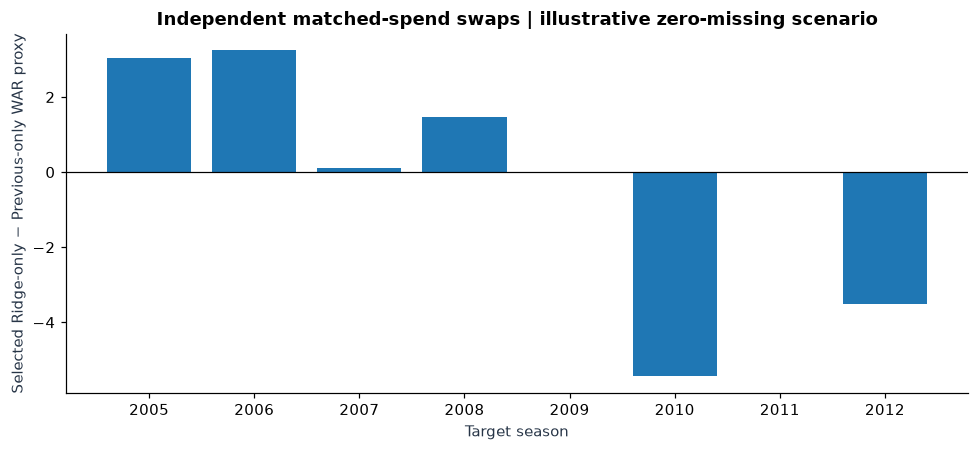

In [114]:
roster_detail98=pd.DataFrame(); swap98=pd.DataFrame(); status98='NOT_EVALUATED'
if 'ind78_members' in globals() and len(ind78_members) and 'matched78' in globals() and len(matched78):
    member98=pd.DataFrame(ind78_members).copy()
    valid_years98=set(matched78.loc[matched78.status.eq('FEASIBLE'),'year'].astype(int))
    member98=member98[member98.year.isin(valid_years98)].copy()
    if member98.duplicated(['year','strategy','playerID']).any():
        raise ValueError('Section 78 roster membership is not unique per strategy and year.')
    parts98=[];season98=[]
    for yr98, g98 in member98.groupby('year'):
        ridge98=g98[g98.strategy.eq('Ridge WAR')].set_index('playerID')
        prior98=g98[g98.strategy.eq('Previous WAR')].set_index('playerID')
        common98=set(ridge98.index).intersection(prior98.index)
        only_r98=set(ridge98.index)-common98
        only_p98=set(prior98.index)-common98
        if len(ridge98)!=8 or len(prior98)!=8:
            raise AssertionError('Expected exactly eight players per Section 78 strategy.')
        observed_diff98=(ridge98.realized_next_WAR.sum(min_count=1)
                         -prior98.realized_next_WAR.sum(min_count=1))
        # This is a reporting proxy; missing values remain separately audited.
        proxy_diff98=(ridge98.realized_next_WAR.fillna(0).sum()
                      -prior98.realized_next_WAR.fillna(0).sum())
        unique_r98=ridge98.loc[sorted(only_r98)]
        unique_p98=prior98.loc[sorted(only_p98)]
        swap_diff98=unique_r98.realized_next_WAR.fillna(0).sum()-unique_p98.realized_next_WAR.fillna(0).sum()
        if not np.isclose(proxy_diff98,swap_diff98,atol=1e-8):
            raise AssertionError('Shared-player cancellation failed.')
        season98.append(dict(year=int(yr98),shared_n=len(common98),ridge_only_n=len(only_r98),
            previous_only_n=len(only_p98),ridge_only_observed_WAR=unique_r98.realized_next_WAR.sum(),
            previous_only_observed_WAR=unique_p98.realized_next_WAR.sum(),
            ridge_only_unobserved=int(unique_r98.realized_next_WAR.isna().sum()),
            previous_only_unobserved=int(unique_p98.realized_next_WAR.isna().sum()),
            difference_missing_zero_scenario=proxy_diff98,
            ridge_spend_M=ridge98.salary.sum()/1e6,previous_spend_M=prior98.salary.sum()/1e6))
        for category98,table98 in [('SHARED',ridge98.loc[sorted(common98)]),
                                   ('RIDGE_ONLY',unique_r98),('PREVIOUS_ONLY',unique_p98)]:
            for pid98,r98 in table98.iterrows():
                parts98.append(dict(year=int(yr98),playerID=pid98,selection=category98,
                    recorded_salary=float(r98.salary),next_WAR=r98.realized_next_WAR,
                    observed_next_WAR=bool(pd.notna(r98.realized_next_WAR))))
    roster_detail98=pd.DataFrame(parts98)
    swap98=pd.DataFrame(season98).sort_values('year')
    status98='EXECUTED'
    save_frame(roster_detail98,'research_98_roster_swap_members.csv')
    save_frame(swap98,'research_98_roster_swap_attribution.csv')
    display(swap98.round(3))
    fig,ax=plt.subplots(figsize=(9,4.2))
    ax.bar(swap98.year.astype(str),swap98.difference_missing_zero_scenario)
    ax.axhline(0,color='black',lw=.8)
    ax.set(title='Independent matched-spend swaps | illustrative zero-missing scenario',
           xlabel='Target season',ylabel='Selected Ridge-only − Previous-only WAR proxy')
    fig.tight_layout();fig.savefig(VISUALS/'research_98_player_swaps.png',bbox_inches='tight');plt.show()
else:
    print('Section 98: NOT_EVALUATED (run Section 78 with full historical inputs).')


## 99. Player ranking | Frozen Ridge, prior WAR, weighted recent WAR, and LambdaMART

**Decision metric, not just squared-error metric.** Compare the ranking of same-season players on `NDCG@10`, *Top-10 mean realized WAR*, and MAE on the **same observed-WAR subset**. Target-year WAR is never used to construct scores. Weighted three-season WAR uses only the input year and its earlier years. Optional LightGBM LambdaMART is fit on **pre-2013 target seasons only** with season-contiguous training groups and prespecified WAR relevance bands, and never tuned to the inspected 2013–2025 data. If LightGBM is missing, that arm is explicitly skipped; there is no silent model substitution.

**Selection limitation:** Ranking results are *conditional on observed future WAR*. In particular, Top-10 on this measured subset is **not** an actually feasible Top-10 acquired roster; unobserved candidate outcomes and contracts are separate issues. Because this exercise was proposed after the holdout was read, it is exploratory even with frozen historical training.


In [115]:
from sklearn.metrics import ndcg_score, mean_absolute_error
rank99=pd.DataFrame(); rank_summary99=pd.DataFrame(); rankings99=pd.DataFrame()
model_status99={'Ridge':'NOT_EVALUATED','Prior WAR':'NOT_EVALUATED',
                'Weighted 3-year WAR':'NOT_EVALUATED','LambdaMART':'OPTIONAL_NOT_EVALUATED'}
feature_rank99=['WAR','PA','OBP','SLG','age']

def war_relevance99(x):
    # Nonnegative integer grades required by LambdaMART.
    return np.digitize(np.asarray(x,float),[-0.5,0.5,1.5,2.5,3.5]).astype(int)

if (globals().get('external81_status')=='EXECUTED_ON_2013_2025_DATA'
        and 'external_predictions81' in globals() and not external_predictions81.empty
        and 'train81' in globals() and 'war_all81' in globals()):
    rank_work99=external_predictions81.copy()
    war_lookup99=war_all81[['playerID','yearID','WAR']].copy()
    if war_lookup99.duplicated(['playerID','yearID']).any():
        raise AssertionError('Duplicate WAR source observations in 99.')
    for lag99,wt99 in [(1,.30),(2,.10)]:
        lookup99=war_lookup99.rename(columns={'yearID':'historical_year','WAR':f'war_lag{lag99}'})
        rank_work99[f'historical_lag_year{lag99}']=rank_work99.yearID-lag99
        rank_work99=rank_work99.merge(lookup99,left_on=['playerID',f'historical_lag_year{lag99}'],
                 right_on=['playerID','historical_year'],how='left',validate='many_to_one').drop(columns=['historical_year'])
    weighted99=np.zeros(len(rank_work99),float)
    weight_total99=np.zeros(len(rank_work99),float)
    for feat99,weight99 in [('WAR',.60),('war_lag1',.30),('war_lag2',.10)]:
        vals99=pd.to_numeric(rank_work99[feat99],errors='coerce').to_numpy(float)
        mask99=np.isfinite(vals99)
        weighted99+=np.where(mask99,vals99,0)*weight99
        weight_total99+=mask99*weight99
    rank_work99['weighted_WAR']=np.divide(weighted99,weight_total99,
                                          out=np.full(len(rank_work99),np.nan),where=weight_total99>0)
    rank_work99['score_LambdaMART']=np.nan
    try:
        import lightgbm as lgb
        rank_train99=train81.dropna(subset=feature_rank99+['next_WAR']).sort_values(['target_year','playerID']).copy()
        if len(rank_train99)>=400 and rank_train99.target_year.nunique()>=3:
            group99=rank_train99.groupby('target_year',sort=True).size().tolist()
            assert sum(group99)==len(rank_train99)
            ranker99=lgb.LGBMRanker(objective='lambdarank',n_estimators=120,num_leaves=9,
                learning_rate=.05,min_child_samples=30,random_state=20261020,verbosity=-1,
                label_gain=[0,1,3,7,15,31])
            ranker99.fit(rank_train99[feature_rank99],war_relevance99(rank_train99.next_WAR),
                group=group99)
            rank_work99['score_LambdaMART']=ranker99.predict(rank_work99[feature_rank99])
            model_status99['LambdaMART']='EVALUATED_EXPLORATORY'
        else:model_status99['LambdaMART']='INSUFFICIENT_HISTORICAL_TRAINING'
    except ImportError:
        model_status99['LambdaMART']='SKIPPED_LIGHTGBM_NOT_INSTALLED'
    observed_rank99=rank_work99.loc[rank_work99.next_WAR.notna()].copy()
    score_cols99={'Ridge':'pred_Ridge','Prior WAR':'pred_previous_WAR',
                  'Weighted 3-year WAR':'weighted_WAR'}
    if model_status99['LambdaMART']=='EVALUATED_EXPLORATORY':
        score_cols99['LambdaMART']='score_LambdaMART'
    results99=[]
    for year99,g99 in observed_rank99.groupby('target_year'):
        if len(g99)<10:continue
        rel99=war_relevance99(g99.next_WAR)
        for name99,col99 in score_cols99.items():
            gg99=g99.dropna(subset=[col99]).copy()
            if len(gg99)<10:continue
            idx99=gg99[col99].nlargest(10).index
            n99=min(10,len(gg99))
            result99=dict(year=int(year99),model=name99,n_observed=len(gg99),
                n_eligible=int(rank_work99.target_year.eq(year99).sum()),
                top10_actual_mean_WAR=float(gg99.loc[idx99,'next_WAR'].mean()),
                NDCG_at_10=float(ndcg_score([war_relevance99(gg99.next_WAR)],
                         [gg99[col99].to_numpy(float)],k=n99)),
                MAE_WAR=float(mean_absolute_error(gg99.next_WAR,gg99[col99])) if name99!='LambdaMART' else np.nan)
            results99.append(result99)
        model_status99['Ridge']='EVALUATED_EXPLORATORY'
        model_status99['Prior WAR']='EVALUATED_EXPLORATORY'
        model_status99['Weighted 3-year WAR']='EVALUATED_EXPLORATORY'
    rank99=pd.DataFrame(results99)
    rankings99=observed_rank99[['playerID','yearID','target_year','next_WAR','WAR',
        'pred_Ridge','pred_previous_WAR','weighted_WAR','score_LambdaMART']].copy()
    if not rank99.empty:
        rank_summary99=rank99.groupby('model',as_index=False).agg(
            seasons=('year','nunique'),avg_NDCG_10=('NDCG_at_10','mean'),
            avg_top10_WAR=('top10_actual_mean_WAR','mean'),mean_season_MAE=('MAE_WAR','mean'))
        display(rank_summary99.round(4));save_frame(rank99,'research_99_rank_metrics_by_year.csv')
        save_frame(rank_summary99,'research_99_rank_model_summary.csv')
        save_frame(rankings99,'research_99_rank_player_predictions_OBSERVED_ONLY.csv')
else:print('Section 99: NOT_EVALUATED (Section 81 must run on original CSVs).')
print('Ranking-arm status:',model_status99)


,model,seasons,avg_NDCG_10,avg_top10_WAR,mean_season_MAE
0,LambdaMART,13,0.8863,4.9480,NaN
1,Prior WAR,13,0.8993,4.8974,1.5316
2,Ridge,13,0.8976,4.8502,1.3436
3,Weighted 3-year WAR,13,0.9034,4.8518,1.3876


Ranking-arm status: {'Ridge': 'EVALUATED_EXPLORATORY', 'Prior WAR': 'EVALUATED_EXPLORATORY', 'Weighted 3-year WAR': 'EVALUATED_EXPLORATORY', 'LambdaMART': 'EVALUATED_EXPLORATORY'}


## 100. The 2020-to-2021 transition | Cohort change and WAR-error decomposition

The 2021 prediction failure could reflect a changed available population, exposure and skill shocks. Here we report **input-cohort PA**, future-outcome observation, and feature shifts separately. For observed future WAR with a positive next-season PA, an explicitly *algebraic* accounting identity splits the Ridge residual into (a) a playing-time scaling term and (b) an output-per-PA residual. Because bWAR also includes defense and positional factors, WAR/PA is **not** a pure batting skill estimator; the two accounting components are **not causally identified**. No retroactive feature selection is performed on the 2021 holdout.


In [116]:
cohort100=pd.DataFrame(); decomp100=pd.DataFrame(); yearly100=pd.DataFrame(); status100='NOT_EVALUATED'
if (globals().get('external81_status')=='EXECUTED_ON_2013_2025_DATA'
        and 'external_predictions81' in globals() and not external_predictions81.empty):
    df100=external_predictions81.copy()
    df100['absolute_error']=abs(df100.next_WAR-df100.pred_Ridge)
    df100['signed_error']=df100.next_WAR-df100.pred_Ridge
    cohort100=df100.groupby('target_year',as_index=False).agg(
        eligible=('playerID','size'),observed_next_WAR=('next_WAR','count'),
        median_input_PA=('PA','median'),mean_input_PA=('PA','mean'),
        median_prior_WAR=('WAR','median'),median_age=('age','median'),
        mean_abs_error_observed=('absolute_error','mean'),
        mean_signed_error_observed=('signed_error','mean'))
    cohort100['future_WAR_observed_rate']=cohort100.observed_next_WAR/cohort100.eligible
    save_frame(cohort100,'research_100_annual_cohort_and_error.csv')
    display(cohort100.round(3))
    if 'recent_player81' in globals():
        future_PA100=recent_player81[['playerID','yearID','PA']].rename(
            columns={'yearID':'target_year','PA':'actual_next_PA'})
        d100=df100.merge(future_PA100,on=['playerID','target_year'],how='left',validate='one_to_one')
        d100=d100[(d100.next_WAR.notna()) & d100.actual_next_PA.ge(50) & d100.PA.gt(0)].copy()
        if len(d100):
            d100['expected_PA_proxy']=d100.PA.clip(lower=50,upper=700)
            # Identity: (actual_PA /600) * realized_rate − predicted_WAR.
            # Predicted_rate is simply model_prediction/expected_PA_proxy; NOT fitted separately.
            d100['predicted_rate_proxy']=600*d100.pred_Ridge/d100.expected_PA_proxy
            d100['realized_rate_proxy']=600*d100.next_WAR/d100.actual_next_PA
            d100['exposure_component']=(d100.actual_next_PA-d100.expected_PA_proxy)*d100.predicted_rate_proxy/600
            d100['rate_and_role_component']=d100.actual_next_PA*(d100.realized_rate_proxy-d100.predicted_rate_proxy)/600
            assert np.allclose(d100['exposure_component']+d100['rate_and_role_component'],
                               d100.next_WAR-d100.pred_Ridge,atol=1e-7)
            decomp100=d100[['playerID','target_year','PA','actual_next_PA',
                'next_WAR','pred_Ridge','exposure_component','rate_and_role_component']]
            yearly100=decomp100.groupby('target_year',as_index=False).agg(
                n=('playerID','size'),mean_exposure_component=('exposure_component','mean'),
                mean_rate_role_component=('rate_and_role_component','mean'),
                mean_abs_exposure_component=('exposure_component',lambda s:s.abs().mean()),
                mean_abs_rate_role_component=('rate_and_role_component',lambda s:s.abs().mean()))
            display(yearly100.round(3));save_frame(yearly100,'research_100_WAR_accounting_by_year.csv')
            save_frame(decomp100,'research_100_WAR_accounting_players.csv')
    status100='EXECUTED_EXPLORATORY'
else:print('Section 100: NOT_EVALUATED; verified external input cohort unavailable.')
print('Section 100:',status100)


,target_year,eligible,observed_next_WAR,median_input_PA,mean_input_PA,median_prior_WAR,median_age,mean_abs_error_observed,mean_signed_error_observed,future_WAR_observed_rate
0,2013,345,319,446.0,446.203,1.550,29.0,1.344,-0.056,0.925
1,2014,355,333,442.0,445.941,1.220,29.0,1.372,0.006,0.938
2,2015,348,322,446.0,449.092,1.295,29.0,1.358,-0.095,0.925
3,2016,350,322,451.5,449.226,1.235,29.0,1.303,0.057,0.920
4,2017,352,313,447.0,451.361,1.350,29.0,1.323,-0.079,0.889
5,2018,349,320,463.0,456.567,1.390,29.0,1.249,-0.029,0.917
6,2019,355,331,456.0,449.327,1.330,28.0,1.334,-0.135,0.932
7,2020,360,332,440.0,442.456,1.395,28.0,1.247,-1.099,0.922
8,2021,124,124,228.0,229.065,1.240,28.0,1.978,1.442,1.000
9,2022,362,337,408.5,426.729,1.375,29.0,1.253,-0.050,0.931


,target_year,n,mean_exposure_component,mean_rate_role_component,mean_abs_exposure_component,mean_abs_rate_role_component
0,2013,310,-0.059,0.018,0.433,1.152
1,2014,320,-0.062,0.089,0.408,1.226
2,2015,312,-0.081,-0.001,0.470,1.135
3,2016,310,0.009,0.106,0.420,1.113
4,2017,299,-0.083,0.033,0.429,1.201
5,2018,309,-0.035,0.019,0.459,1.092
6,2019,319,-0.106,0.006,0.450,1.137
7,2020,301,-1.113,-0.023,1.125,0.628
8,2021,124,1.118,0.324,1.209,1.492
9,2022,320,-0.048,0.027,0.404,1.097


Section 100: EXECUTED_EXPLORATORY


## 101. Missing outcomes in selected rosters | zero-missing audit

Section 78's eight feasible historical rosters contained **zero missing WAR outcomes among selected players** in the saved evaluation. Consequently, replacing missing selected-player WAR by values in the range −2 to +2 cannot change these particular results. The code checks this on re-execution and shares bootstrap resamples across assumptions. This does **not** establish that missing future WAR among unselected *candidates* is harmless; selection bias is examined in Section 110.


In [117]:
# Section 78 selected rosters have no missing outcomes in the stored historical audit.
# Use identical resampled season indices across scenarios, so Monte Carlo noise does not
# create fake differences when hypothetical missing outcomes never occur.
scenario101=pd.DataFrame();summary101=pd.DataFrame();status101='NOT_EVALUATED'
if 'ind78_members' in globals() and len(ind78_members) and 'matched78' in globals() and len(matched78):
    m101=pd.DataFrame(ind78_members).copy()
    m101=m101[m101.year.isin(matched78.loc[matched78.status.eq('FEASIBLE'),'year'])]
    years101=np.sort(m101.year.unique())
    draws_ix101=np.random.default_rng(101).integers(0,len(years101),size=(6000,len(years101)))
    result101=[];scenario_rows101=[]
    for assumed101 in (-2.,-1.,0.,1.,2.):
        tmp101=m101.copy();tmp101['hypothetical_WAR']=tmp101.realized_next_WAR.fillna(assumed101)
        table101=tmp101.groupby(['year','strategy']).hypothetical_WAR.sum().unstack()
        delta101=(table101['Ridge WAR']-table101['Previous WAR']).reindex(years101).to_numpy(float)
        scenario_rows101.extend(dict(year=int(y),assumed_missing_WAR=assumed101,
                           ridge_minus_previous_WAR=float(d)) for y,d in zip(years101,delta101))
        boot101=delta101[draws_ix101].mean(axis=1)
        result101.append(dict(assumed_missing_WAR=assumed101,seasons=len(delta101),
            selected_missing_n=int(m101.realized_next_WAR.isna().sum()),
            mean_WAR_difference=float(delta101.mean()),
            CI95_low=float(np.quantile(boot101,.025)),CI95_high=float(np.quantile(boot101,.975))))
    scenario101=pd.DataFrame(scenario_rows101);summary101=pd.DataFrame(result101)
    status101='MISSING_FREE_SELECTION_SENSITIVITY' if m101.realized_next_WAR.notna().all() else 'HYPOTHETICAL_SENSITIVITY'
    display(summary101.round(3));save_frame(summary101,'research_101_missing_WAR_sensitivity_summary.csv')
    save_frame(scenario101,'research_101_missing_WAR_sensitivity_by_year.csv')
    print('Section 101:',status101)
else:print('Section 101: NOT_EVALUATED; Section 78 rosters unavailable.')

,assumed_missing_WAR,seasons,selected_missing_n,mean_WAR_difference,CI95_low,CI95_high
0,-2.0,8,0,-0.14,-2.22,1.711
1,-1.0,8,0,-0.14,-2.22,1.711
2,0.0,8,0,-0.14,-2.22,1.711
3,1.0,8,0,-0.14,-2.22,1.711
4,2.0,8,0,-0.14,-2.22,1.711


Section 101: MISSING_FREE_SELECTION_SENSITIVITY


## 102. Contract feasibility gate | Optional externally verified transaction dataset

Historical salary **alone** cannot make a transaction feasible. An optional, independently sourced `ContractAvailability.csv` may document (1) the player and decision year, (2) whether availability was verified **as of January 1 of that year**, and (3) an *estimated available acquisition cost* actually known by that cutoff. A Boolean 'available' without a trustworthy verified date is insufficient. This cell **only audits and lists verifiable candidates**; it does not replace Section 78's salary with invented costs or declare a true feasible MLB trade/signing market.

Expected optional columns: `playerID`, `target_year`, `available_before_season`, `cost_usd`, `known_at_utc`, `source_url`. Fields and authentic original sources must be supplied by the analyst. Until then the contract-feasible hypothesis is `NOT_EVALUATED`.


In [118]:
contract102=pd.DataFrame();contract_audit102=pd.DataFrame();status102='NO_VERIFIED_CONTRACT_SOURCE'
contract_path102=DATA_DIR/'ContractAvailability.csv'
if contract_path102.is_file():
    contract102=pd.read_csv(contract_path102,low_memory=False)
    required102={'playerID','target_year','available_before_season','cost_usd','known_at_utc','source_url'}
    if not required102.issubset(contract102):
        status102='INVALID_SCHEMA'
        print('Contract input missing fields:',sorted(required102-set(contract102)))
    else:
        if contract102.duplicated(['playerID','target_year']).any():
            raise AssertionError('Ambiguous contract entries (playerID,target_year) in external file.')
        contract102['target_year']=pd.to_numeric(contract102.target_year,errors='coerce')
        contract102['cost_usd']=pd.to_numeric(contract102.cost_usd,errors='coerce')
        known102=pd.to_datetime(contract102.known_at_utc,errors='coerce',utc=True)
        cutoff102=pd.to_datetime(contract102.target_year.astype('Int64').astype(str)+'-01-01',
                                   errors='coerce',utc=True)
        available102=contract102.available_before_season.astype(str).str.lower().isin(['true','1','yes'])
        valid102=(available102 & known102.notna() & cutoff102.notna()
                  & (known102 < cutoff102) & contract102.cost_usd.gt(0)
                  & contract102.source_url.notna() & contract102.source_url.astype(str).str.startswith(('https://','http://')))
        contract102['verified_ex_ante_candidate']=valid102
        contract_audit102=contract102.groupby('target_year',as_index=False).agg(
            supplied=('playerID','size'),ex_ante_candidate_records=('verified_ex_ante_candidate','sum'))
        status102='EX_ANTE_RECORD_SCREEN_ONLY_NEEDS_INDEPENDENT_SOURCE_AUDIT'
        display(contract_audit102)
        save_frame(contract_audit102,'research_102_transaction_coverage.csv')
else:print('Section 102: optional ContractAvailability.csv not supplied; NOT_EVALUATED.')
print('Section 102:',status102)


Section 102: optional ContractAvailability.csv not supplied; NOT_EVALUATED.
Section 102: NO_VERIFIED_CONTRACT_SOURCE


## 103. Shrinkage and explainable nonlinear forecasting

The existing three-year historical-mean shrinkage is a **deterministic empirical shrinkage baseline**, not a fitted Bayesian hierarchical model. Frozen pre-2013 Ridge is the benchmark. An additive spline–Ridge (GAM-style, no interactions) is always compared using the existing scikit-learn environment. Where `interpret` is installed, a no-interaction EBM can also be fitted on the historical data. Section 109 adds a distinct, explicitly specified normal-normal player effect model. Optional package installation is documented rather than silently interpreted as evaluated.


In [119]:
partial103=pd.DataFrame();compare103=pd.DataFrame();model_status103={
  'partial_pooling':'NOT_EVALUATED','additive_spline':'NOT_EVALUATED','EBM':'OPTIONAL_NOT_EVALUATED'}
if (globals().get('external81_status')=='EXECUTED_ON_2013_2025_DATA'
        and 'external_predictions81' in globals() and not external_predictions81.empty
        and 'war_all81' in globals() and 'train81' in globals()):
    inp103=external_predictions81.copy()
    hist103=war_all81[['playerID','yearID','WAR']].copy()
    if hist103.duplicated(['playerID','yearID']).any():
        raise AssertionError('Duplicate player/year WAR during Section 103.')
    historical_mean103=float(train81.WAR.mean())
    # Fixed pre-2013 historical mean; never recomputed using any post-2012 target label.
    accum103=np.zeros(len(inp103));count103=np.zeros(len(inp103),dtype=int)
    for lag103 in (0,1,2):
        prev103=hist103.rename(columns={'yearID':'hist_year','WAR':'hist_WAR'})
        key103=inp103[['playerID','yearID']].copy()
        key103['hist_year']=key103.yearID-lag103
        joined103=key103.merge(prev103,on=['playerID','hist_year'],how='left',validate='many_to_one')
        vals103=pd.to_numeric(joined103.hist_WAR,errors='coerce').to_numpy(float)
        mask103=np.isfinite(vals103)
        accum103+=np.where(mask103,vals103,0)
        count103+=mask103.astype(int)
    inp103['partial_pool_WAR']=(accum103+2*historical_mean103)/(count103+2)
    model_status103['partial_pooling']='EVALUATED_EXPLORATORY'
    obs103=inp103.dropna(subset=['next_WAR'])
    metrics103=[]
    for y103,g103 in obs103.groupby('target_year'):
        for name103,col103 in [('Frozen Ridge','pred_Ridge'),('Previous WAR','pred_previous_WAR'),
                              ('Partial-pooling baseline','partial_pool_WAR')]:
            metrics103.append({'year':int(y103),'model':name103,'n':len(g103),
               'MAE':float(mean_absolute_error(g103.next_WAR,g103[col103]))})
    # Univariate spline basis + ridge: an additive GAM-style baseline without interactions.
    # This model is NOT an Explainable Boosting Machine.
    from sklearn.preprocessing import SplineTransformer
    gam103=Pipeline([('spline',SplineTransformer(n_knots=5, degree=3,include_bias=False)),
                     ('ridge',Ridge(alpha=50.0))]).fit(train81[feature81],train81.next_WAR)
    inp103['additive_spline_WAR']=gam103.predict(inp103[feature81])
    obs_gam103=inp103.dropna(subset=['next_WAR'])
    for y103,g103 in obs_gam103.groupby('target_year'):
        metrics103.append({'year':int(y103),'model':'Additive spline (frozen historical fit)',
                    'n':len(g103),'MAE':float(mean_absolute_error(g103.next_WAR,g103.additive_spline_WAR))})
    model_status103['additive_spline']='EVALUATED_EXPLORATORY'
    try:
        from interpret.glassbox import ExplainableBoostingRegressor
        ebm103=ExplainableBoostingRegressor(interactions=0,random_state=103,
                                           max_bins=64,learning_rate=.04)
        ebm103.fit(train81[feature81],train81.next_WAR)
        inp103['EBM_forecast']=ebm103.predict(inp103[feature81])
        observed_ebm103=inp103.dropna(subset=['next_WAR'])
        for y103,g103 in observed_ebm103.groupby('target_year'):
            metrics103.append({'year':int(y103),'model':'EBM (historical fit)', 'n':len(g103),
                 'MAE':float(mean_absolute_error(g103.next_WAR,g103.EBM_forecast))})
        model_status103['EBM']='EVALUATED_EXPLORATORY'
    except ImportError:
        model_status103['EBM']='SKIPPED_INTERPRET_NOT_INSTALLED'
    partial103=pd.DataFrame(metrics103)
    compare103=partial103.groupby('model',as_index=False).agg(
        seasons=('year','nunique'),mean_annual_MAE=('MAE','mean'))
    display(compare103.round(4))
    save_frame(partial103,'research_103_interpretable_model_yearly.csv')
    save_frame(compare103,'research_103_interpretable_model_summary.csv')
else:print('Section 103: NOT_EVALUATED (requires Section 81 data/model).')
print('Section 103 model status:',model_status103)


,model,seasons,mean_annual_MAE
0,Additive spline (frozen historical fit),13,1.3388
1,Frozen Ridge,13,1.3436
2,Partial-pooling baseline,13,1.4140
3,Previous WAR,13,1.5316


Section 103 model status: {'partial_pooling': 'EVALUATED_EXPLORATORY', 'additive_spline': 'EVALUATED_EXPLORATORY', 'EBM': 'SKIPPED_INTERPRET_NOT_INSTALLED'}


## 104. Nested model selection by historical roster outcomes

Run the 2005–2012 per-year historical blend test when the source CSVs and optimizer are present. Blend weights are selected using **only earlier evaluated seasons** and then tested on the subsequent year; leave-one-out or across-all-years weight tuning is prohibited. Equal salary bands use the Section 78 optimizer. An infeasible or uncertified optimizer solution must be reported, not treated as automatically optimal. The study is a *retrospective* salary-price scenario, not demonstrated hiring feasibility. This solver-heavy cell can be explicitly disabled with `MONEYBALL_RUN_DECISION_FOCUSED=0`.


In [120]:
import os
focus104=pd.DataFrame();focus_summary104=pd.DataFrame();focus_weights104=pd.DataFrame()
status104='NO_FULL_DATA_OR_EXPLICITLY_DISABLED'
weights104=[0.0,0.25,0.50,0.75,1.0]
run_focus104=os.environ.get('MONEYBALL_RUN_DECISION_FOCUSED','1')=='1'
if run_focus104 and ('old57' not in globals() or 'feature60' not in globals()
                     or 'independent_milp78' not in globals() or not war52_ready):
    status104='MISSING_HISTORICAL_MODEL_OR_SOURCE'
elif run_focus104:
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import StandardScaler
    from sklearn.linear_model import Ridge
    # Precompute completely historical ex-ante decisions; no label is used for scoring.
    panel104=[]
    for year104 in range(2005,2013):
        history104=old57[(old57.target_year<year104)&old57.realized_WAR.notna()].dropna(subset=feature60)
        pool104=old57[(old57.target_year==year104)&old57.player_salary.gt(0)].dropna(subset=feature60).copy()
        if len(history104)<200 or len(pool104)<30:continue
        ridge104=Pipeline([('scale',StandardScaler()),('ridge',Ridge(alpha=50))]).fit(
            history104[feature60],history104.realized_WAR)
        pool104['Ridge_war104']=ridge104.predict(pool104[feature60])
        # Salary target is set by the salary distribution in the decision year.
        cap104=max(15.,float(pool104.nsmallest(8,'player_salary').player_salary.sum()/1e6)*2.5)
        for w104 in weights104:
            pool104['Blend104']=w104*pool104.Ridge_war104+(1.0-w104)*pool104.WAR
            selected104=independent_milp78(pool104,'Blend104',cap104,n=8,
                        solver_label=f'104_{year104}_weight_{w104:.2f}',time_limit=8)
            if (selected104 is not None and selected104.attrs['solver_info']['certified_within_gap']):
                panel104.append(dict(year=year104,weight=w104,scenario_WAR_total=float(
                    selected104.realized_WAR.fillna(0).sum()),
                    missing_count=int(selected104.realized_WAR.isna().sum()),
                    spent_M=float(selected104.player_salary.sum()/1e6),
                    certified=bool(selected104.attrs['solver_info']['certified_within_gap'])))
    prepared104=pd.DataFrame(panel104)
    if not prepared104.empty:
        # Keep ONLY years for which ALL candidate weights generated a feasible roster.
        feasible104=prepared104.groupby('year').weight.nunique()
        years104=feasible104[feasible104.eq(len(weights104))].index
        complete104=prepared104[prepared104.year.isin(years104)].copy()
        results104=[]
        for year104 in sorted(years104):
            prior104=complete104[complete104.year.lt(year104)]
            history_years104=prior104.year.nunique()
            if history_years104<2:continue
            # Every weight is evaluated across the same historical seasons.
            means104=prior104.groupby('weight',as_index=False).scenario_WAR_total.mean()
            chosen_weight104=float(means104.sort_values(
                ['scenario_WAR_total','weight'],ascending=[False,True]).iloc[0].weight)
            trial104=complete104[complete104.year.eq(year104)]
            for name104,w104 in [('Nested blend',chosen_weight104),('Ridge only',1.0),('Previous WAR only',0.0)]:
                result104=trial104[np.isclose(trial104.weight,w104)].iloc[0]
                results104.append(dict(year=int(year104),model=name104,
                    chosen_weight=float(w104),historical_tuning_years=int(history_years104),
                    scenario_WAR=float(result104.scenario_WAR_total),
                    missing_WAR_n=int(result104.missing_count),
                    actual_spend_M=float(result104.spent_M),solver_certified=bool(result104.certified)))
        focus104=pd.DataFrame(results104)
        focus_weights104=complete104.copy()
        if not focus104.empty:
            status104='EVALUATED_EXPLORATORY_ZERO_MISSING_PROXY'
            focus_summary104=focus104.groupby('model',as_index=False).agg(
                years=('year','nunique'),mean_proxy_WAR=('scenario_WAR','mean'),
                mean_spend_M=('actual_spend_M','mean'),
                total_missing=('missing_WAR_n','sum'),
                certified_share=('solver_certified','mean'))
            display(focus_summary104.round(3));display(focus104.round(3))
            save_frame(focus104,'research_104_nested_roster_blend_by_year.csv')
            save_frame(focus_summary104,'research_104_nested_roster_blend_summary.csv')
            save_frame(focus_weights104,'research_104_blend_candidate_weights.csv')
        else:status104='INSUFFICIENT_NESTED_TEST_YEARS'
    else:status104='NO_FEASIBLE_BLENDED_ROSTERS'
print('Section 104 decision-focused nested test:',status104)

,model,years,mean_proxy_WAR,mean_spend_M,total_missing,certified_share
0,Nested blend,6,32.508,14.322,0,1.0
1,Previous WAR only,6,32.247,14.308,0,1.0
2,Ridge only,6,31.015,14.330,0,1.0


,year,model,chosen_weight,historical_tuning_years,scenario_WAR,missing_WAR_n,actual_spend_M,solver_certified
0,2007,Nested blend,1.00,2,26.87,0,14.219,True
1,2007,Ridge only,1.00,2,26.87,0,14.219,True
2,2007,Previous WAR only,0.00,2,26.76,0,14.154,True
3,2008,Nested blend,0.75,3,25.23,0,14.375,True
4,2008,Ridge only,1.00,3,25.23,0,14.375,True
5,2008,Previous WAR only,0.00,3,23.77,0,14.354,True
6,2009,Nested blend,0.75,4,34.45,0,14.388,True
7,2009,Ridge only,1.00,4,34.45,0,14.388,True
8,2009,Previous WAR only,0.00,4,34.45,0,14.388,True
9,2010,Nested blend,0.75,5,44.56,0,14.349,True


Section 104 decision-focused nested test: EVALUATED_EXPLORATORY_ZERO_MISSING_PROXY


In [121]:
statuses105=[
  ('96',status96,'Local integrity only; publisher provenance unverified'),
  ('97','EXECUTED_DESIGN_BRIDGE' if not comparison97.empty else 'DESIGN_ONLY',
      'Different selection design; do not compare mean WAR as a controlled experiment'),
  ('98',status98,'Retrospective matched-spend player swap attribution'),
  ('99','EVALUATED_EXPLORATORY' if not rank99.empty else 'NOT_EVALUATED',
      'Rank only among observed future WAR; no new independent holdout'),
  ('100',status100,'Descriptive, algebraic decomposition; not causal'),
  ('101',status101,'Hypothetical values, not imputations validated against truth'),
  ('102',status102,'Transactions not independently demonstrated'),
  ('103','EVALUATED_EXPLORATORY' if not compare103.empty else 'NOT_EVALUATED',
      'Fixed historical fit, post-hoc research'),
  ('104',status104,'Historical nested roster blend; opt-in expensive solver run, proxy outcomes'),
  ('95',globals().get('status95','INSPECT_SECTION_95_OUTPUT'),
      'Refer to original Section 95 status and independent verification gate'),
]
final_status105=pd.DataFrame(statuses105,columns=['section','status','meaning'])
display(final_status105)
if DATA_DIR.is_dir():save_frame(final_status105,'FINAL_EXTENSION_AUDIT_96_104.csv')
print('Retained original Sections 1–95; Sections 96–104 are executable extensions, not new verified scores.')
print('2026 cannot be asserted validated until source vintage, frozen model, and 2026 WAR are independently certified.')


,section,status,meaning
0,96,UPSTREAM_UNVERIFIED,Local integrity only; publisher provenance unv...
1,97,EXECUTED_DESIGN_BRIDGE,Different selection design; do not compare mea...
2,98,EXECUTED,Retrospective matched-spend player swap attrib...
3,99,EVALUATED_EXPLORATORY,Rank only among observed future WAR; no new in...
4,100,EXECUTED_EXPLORATORY,"Descriptive, algebraic decomposition; not causal"
5,101,MISSING_FREE_SELECTION_SENSITIVITY,"Hypothetical values, not imputations validated..."
6,102,NO_VERIFIED_CONTRACT_SOURCE,Transactions not independently demonstrated
7,103,EVALUATED_EXPLORATORY,"Fixed historical fit, post-hoc research"
8,104,EVALUATED_EXPLORATORY_ZERO_MISSING_PROXY,Historical nested roster blend; opt-in expensi...
9,95,PENDING_INDEPENDENT_SOURCE_AND_MODEL_VERIFICATION,Refer to original Section 95 status and indepe...


Retained original Sections 1–95; Sections 96–104 are executable extensions, not new verified scores.
2026 cannot be asserted validated until source vintage, frozen model, and 2026 WAR are independently certified.


# Part 09 · Methodological repair and time-ordered validation (105–124)

*Technical execution sequence is unchanged. See `01_Moneyball_Main_Research.ipynb` for a topical, reduced presentation.*


**Execution rule.** Every new numerical comparison uses source data loaded by earlier sections. An old notebook output is not evidence that a newly edited cell has been run. Code cells added here deliberately have no precomputed figures or metrics. Run **Restart Kernel and Run All Cells** on the 12 source files. We preserve old outputs as archived historical evidence, while data provenance, recruitment feasibility and 2026 validation remain explicitly unverified until their gates pass. All extended analysis is retrospective/exploratory unless separately preregistered on a genuinely new future cohort.


## 105. Forecast target integrity | total WAR versus batting and pitching components

The original historical and external models predict recorded **total WAR**, even when the candidates are selected via hitting statistics. Report the share of nontrivial pitching contributions among those hitters. If `bat_WAR` and `pitch_WAR` are present in the same declared source, compare measured total WAR to their sum; these are source columns, not interchangeable baseball measures. Fit a separate **batting-WAR** predictor from pre-2013 records, with the same frozen time split. Do **not** call a batting-feature model a pitcher-WAR model; dedicated pitcher features and cohorts would be needed.


In [122]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
component105=pd.DataFrame();bat_forecast105=pd.DataFrame();bat_summary105=pd.DataFrame()
status105='MISSING_COMPONENT_TARGETS'
if ('war_all81' in globals() and 'train81' in globals() and
    'external_predictions81' in globals() and len(external_predictions81)):
    w105=war_all81.copy()
    if {'bat_WAR','pitch_WAR'}.issubset(w105.columns):
        for c105 in ['bat_WAR','pitch_WAR','WAR']:
            w105[c105]=pd.to_numeric(w105[c105],errors='coerce')
        w105=w105[['playerID','yearID','WAR','bat_WAR','pitch_WAR']]
        assert not w105.duplicated(['playerID','yearID']).any()
        compare105=external_predictions81[['playerID','yearID','target_year','WAR']].rename(columns={'WAR':'feature_total_WAR'}).merge(
            w105[['playerID','yearID','bat_WAR','pitch_WAR']],on=['playerID','yearID'],how='left',validate='one_to_one')
        compare105['sum_gap']=compare105.feature_total_WAR-(compare105.bat_WAR+compare105.pitch_WAR)
        component105=compare105.groupby('target_year',as_index=False).agg(
            candidate_n=('playerID','size'),component_pair_n=('sum_gap','count'),
            mean_absolute_component_sum_gap=('sum_gap',lambda x:x.abs().mean()),
            pitching_WAR_abs_over_half=('pitch_WAR',lambda x:int(x.abs().gt(.5).sum())))
        display(component105.round(3));save_frame(component105,'research_105_WAR_component_audit.csv')
        # Historical features are from year t, labels from year t+1.
        h105=train81[['playerID','yearID','target_year','PA','OBP','SLG','age']].copy()
        rawhist105=w52[['playerID','yearID','bat_WAR']].copy() if 'bat_WAR' in w52.columns else pd.DataFrame()
        if len(rawhist105):
            rawhist105['bat_WAR']=pd.to_numeric(rawhist105.bat_WAR,errors='coerce')
            histfeat105=rawhist105.rename(columns={'bat_WAR':'prior_bat_WAR'})
            histout105=rawhist105.rename(columns={'yearID':'target_year','bat_WAR':'next_bat_WAR'})
            h105=h105.merge(histfeat105,on=['playerID','yearID'],how='left',validate='many_to_one').merge(
                histout105,on=['playerID','target_year'],how='left',validate='many_to_one')
            f105=['prior_bat_WAR','PA','OBP','SLG','age']
            h105=h105.dropna(subset=f105+['next_bat_WAR'])
            ext105=external_predictions81[['playerID','yearID','target_year','PA','OBP','SLG','age']].merge(
                w105[['playerID','yearID','bat_WAR']].rename(columns={'bat_WAR':'prior_bat_WAR'}),
                on=['playerID','yearID'],how='left',validate='one_to_one').merge(
                w105[['playerID','yearID','bat_WAR']].rename(columns={'yearID':'target_year','bat_WAR':'next_bat_WAR'}),
                on=['playerID','target_year'],how='left',validate='one_to_one')
            ext105=ext105.dropna(subset=f105).copy()
            if len(h105)>=200 and ext105.next_bat_WAR.notna().sum()>=50:
                model105=Pipeline([('scaler',StandardScaler()),('ridge',Ridge(alpha=50.0))]).fit(
                    h105[f105],h105.next_bat_WAR)
                ext105['pred_bat_WAR']=model105.predict(ext105[f105]);ext105['prior_bat_baseline']=ext105.prior_bat_WAR
                bat_forecast105=ext105
                obs105=ext105.dropna(subset=['next_bat_WAR'])
                bat_summary105=obs105.groupby('target_year').apply(lambda x:pd.Series({
                    'n':len(x),'Ridge_bat_MAE':mean_absolute_error(x.next_bat_WAR,x.pred_bat_WAR),
                    'Prior_bat_MAE':mean_absolute_error(x.next_bat_WAR,x.prior_bat_baseline)}),
                    include_groups=False).reset_index()
                status105='EXPLORATORY_BATTING_COMPONENT_EVALUATED'
                display(bat_summary105.round(3));save_frame(bat_summary105,'research_105_batting_WAR_annual.csv')
            else:status105='INSUFFICIENT_MEASURED_BATTING_TARGETS'
        else:status105='HISTORICAL_BATTING_WAR_COLUMN_MISSING'
    else:status105='BAT_AND_PITCH_COMPONENTS_ABSENT'
print('Section 105:',status105)

,target_year,candidate_n,component_pair_n,mean_absolute_component_sum_gap,pitching_WAR_abs_over_half
0,2013,345,6,0.0,0
1,2014,355,5,0.0,0
2,2015,348,7,0.0,0
3,2016,350,12,0.0,0
4,2017,352,7,0.0,0
5,2018,349,10,0.0,0
6,2019,355,28,0.0,1
7,2020,360,27,0.0,0
8,2021,124,0,NaN,0
9,2022,362,31,0.0,1


,target_year,n,Ridge_bat_MAE,Prior_bat_MAE
0,2013,319.0,1.343,1.504
1,2014,333.0,1.372,1.584
2,2015,322.0,1.358,1.616
3,2016,322.0,1.303,1.431
4,2017,313.0,1.322,1.578
5,2018,320.0,1.248,1.513
6,2019,331.0,1.333,1.450
7,2020,332.0,1.245,1.658
8,2021,124.0,1.978,1.914
9,2022,337.0,1.239,1.428


Section 105: EXPLORATORY_BATTING_COMPONENT_EVALUATED


## 106. Ranking-to-roster experiment | time-ordered, equal-spend, same candidates

This directly links the Section 99 research question to the Section 78 selection design. For each 2005–2012 decision year, fit Ridge and (optionally) LambdaMART using **earlier realized WAR outcomes only**. Score the **same eligible players** for all methods and hold the annual 8-player headcount and 95% ±1% target spending band fixed. A LambdaMART output is only an ordering; the code maps its within-year ranks monotonically to the *historical past outcome distribution* before optimizing a sum of utilities. This is not calibrated predicted WAR, so comparisons are decision-focused and exploratory. Uncertified or infeasible solver results are flagged. It does not establish that any named player was actually available to sign at the historical salary.


In [123]:
roster106=pd.DataFrame();members106=pd.DataFrame();compare106=pd.DataFrame()
status106='REQUIRES_FULL_HISTORICAL_POOL'

def weighted_lag_WAR106(pool, history_source):
    # Exact feature-year lags are built only from source years <= the decision feature year.
    z=pool.copy()
    hist=history_source[['playerID','yearID','WAR']].drop_duplicates(['playerID','yearID'])
    for offset in [1,2]:
        lag=hist.rename(columns={'yearID':'prior_year','WAR':f'lag_{offset}_WAR'})
        z['prior_year']=z.yearID-offset
        z=z.merge(lag,on=['playerID','prior_year'],how='left',validate='many_to_one').drop(columns='prior_year')
    weighted=np.zeros(len(z));weights=np.zeros(len(z))
    for name,w in [('WAR',.6),('lag_1_WAR',.3),('lag_2_WAR',.1)]:
        v=pd.to_numeric(z[name],errors='coerce').to_numpy(float)
        ok=np.isfinite(v);weighted+=np.where(ok,v,0)*w;weights+=w*ok
    return np.divide(weighted,weights,out=np.full(len(z),np.nan),where=weights>0)

if {'old57','feature60','w52','ind78','independent_milp78'}.issubset(globals()) and war52_ready:
    try:import lightgbm as lgb106
    except ImportError:lgb106=None
    selected106=[]; rows106=[]; solver_audit106=[]
    valid78=ind78[ind78.status.eq('FEASIBLE')].set_index('year')
    for year in range(2005,2013):
        if year not in valid78.index:continue
        hist=old57[old57.target_year.lt(year)].dropna(subset=feature60+['realized_WAR']).copy()
        pool=old57[(old57.target_year.eq(year))&old57.player_salary.gt(0)].dropna(subset=feature60).copy()
        if len(hist)<200 or len(pool)<30:continue
        if pool.duplicated('playerID').any():raise AssertionError(f'Duplicate player in {year} candidate pool')
        baseline=Pipeline([('sc',StandardScaler()),('ridge',Ridge(alpha=50.0))]).fit(hist[feature60],hist.realized_WAR)
        pool['Ridge forecast']=baseline.predict(pool[feature60])
        pool['Previous WAR']=pool.WAR
        pool['Weighted 3yr WAR']=weighted_lag_WAR106(pool,w52)
        methods=['Ridge forecast','Previous WAR','Weighted 3yr WAR']
        if lgb106 is not None and hist.target_year.nunique()>=3:
            grouped=hist.sort_values(['target_year','playerID']).copy()
            grades=war_relevance99(grouped.realized_WAR) if 'war_relevance99' in globals() else np.digitize(grouped.realized_WAR,[-.5,.5,1.5,2.5,3.5])
            ranker=lgb106.LGBMRanker(objective='lambdarank',num_leaves=9,
                   n_estimators=120,learning_rate=.05,min_child_samples=30,verbosity=-1,
                   random_state=20261020,label_gain=[0,1,3,7,15,31])
            ranker.fit(grouped[feature60],grades,group=grouped.groupby('target_year',sort=True).size().tolist())
            rank_scores=ranker.predict(pool[feature60]);order=pd.Series(rank_scores).rank(method='average',pct=True).to_numpy()
            # Convert arbitrary rank scores into a fixed forward-only ordinal utility.
            pool['Rank quantile utility']=np.quantile(hist.realized_WAR.to_numpy(float),np.clip(order,0,1))
            methods.append('Rank quantile utility')
        cap=float(valid78.loc[year,'cap_million'])
        for method in methods:
            if pool[method].isna().any():
                rows106.append(dict(year=year,method=method,status='NONFINITE_SCORE'));continue
            team=independent_milp78(pool,method,cap,n=8,solver_label=f'106_{year}_{method}',time_limit=10)
            if team is None:
                rows106.append(dict(year=year,method=method,status='INFEASIBLE_OR_TIMEOUT'));continue
            certified=bool(team.attrs['solver_info']['certified_within_gap'])
            row=dict(year=year,method=method,status='CERTIFIED' if certified else 'FEASIBLE_UNCERTIFIED',
                     n=len(team),spend_M=float(team.player_salary.sum()/1e6),
                     outcome_observed_n=int(team.realized_WAR.notna().sum()),
                     outcome_missing_n=int(team.realized_WAR.isna().sum()),
                     observed_WAR=float(team.realized_WAR.sum()),
                     zero_missing_proxy_WAR=float(team.realized_WAR.fillna(0).sum()))
            rows106.append(row)
            for r in team.itertuples():
                selected106.append(dict(year=year,method=method,playerID=r.playerID,
                    salary=r.player_salary,realized_WAR=r.realized_WAR))
    roster106=pd.DataFrame(rows106);members106=pd.DataFrame(selected106)
    if len(roster106):
        display(roster106.round(3));save_frame(roster106,'research_106_equal_spend_rosters.csv')
        if len(members106):save_frame(members106,'research_106_roster_members.csv')
        needed={'Ridge forecast','Previous WAR','Weighted 3yr WAR'}
        good=roster106[roster106.status.eq('CERTIFIED')&roster106.outcome_missing_n.eq(0)].copy()
        byyear=good.groupby('year').method.apply(set)
        fullyears=[yr for yr,s in byyear.items() if needed.issubset(s)]
        compare106=good[good.year.isin(fullyears)].copy()
        if len(compare106):
            display(compare106.groupby('method',as_index=False).agg(
               comparable_years=('year','nunique'),mean_WAR=('observed_WAR','mean'),
               mean_spend_M=('spend_M','mean')).round(3))
            save_frame(compare106,'research_106_complete_case_comparable.csv')
        status106='EVALUATED_EXPLORATORY_CONSTRAINED' if len(compare106) else 'NO_FULLY_CERTIFIED_COMPARABLE_YEARS'
    else:status106='NO_SOLVER_OUTPUT'
print('Section 106:',status106)

,year,method,status,n,spend_M,outcome_observed_n,outcome_missing_n,observed_WAR,zero_missing_proxy_WAR
0,2005,Ridge forecast,CERTIFIED,8,14.122,8,0,32.29,32.29
1,2005,Previous WAR,CERTIFIED,8,14.171,8,0,29.26,29.26
2,2005,Weighted 3yr WAR,CERTIFIED,8,14.303,8,0,22.71,22.71
3,2005,Rank quantile utility,CERTIFIED,8,14.357,8,0,26.18,26.18
4,2006,Ridge forecast,CERTIFIED,8,14.323,8,0,36.88,36.88
5,2006,Previous WAR,CERTIFIED,8,14.324,8,0,33.64,33.64
6,2006,Weighted 3yr WAR,CERTIFIED,8,14.196,8,0,39.49,39.49
7,2006,Rank quantile utility,CERTIFIED,8,14.390,8,0,32.35,32.35
8,2007,Ridge forecast,CERTIFIED,8,14.219,8,0,26.87,26.87
9,2007,Previous WAR,CERTIFIED,8,14.154,8,0,26.76,26.76


,method,comparable_years,mean_WAR,mean_spend_M
0,Previous WAR,8,32.048,14.293
1,Rank quantile utility,8,28.835,14.298
2,Ridge forecast,8,31.908,14.303
3,Weighted 3yr WAR,8,30.466,14.235


Section 106: EVALUATED_EXPLORATORY_CONSTRAINED


## 107. Paired-season inference | decision regret, overlap and solver diagnostics

Compare only **identical target seasons** where each model has a certified solution and all chosen outcomes are observed. Player-level rows are correlated within seasons, so paired bootstrap resamples **seasons** rather than individual players. Record selection overlap and annual spending differences. The oracle benchmark is an *unattainable hindsight upper bound*, not a prospective signing policy. `Rank quantile utility` may yield higher or lower selected WAR than Ridge; no advantage is asserted before execution.


In [124]:
regret107=pd.DataFrame();summary107=pd.DataFrame();status107='NOT_EVALUATED'
if 'compare106' in globals() and len(compare106) and 'members106' in globals() and len(members106):
    years107=sorted(compare106.year.unique())
    pivot107=compare106.pivot(index='year',columns='method',values='observed_WAR')
    # Require same years for each explicitly compared pair, including the baseline.
    if 'Ridge forecast' in pivot107:
        base107=pivot107['Ridge forecast']
        rows107=[];summary_rows107=[]
        for method in [x for x in pivot107 if x!='Ridge forecast']:
            common=pivot107[[method,'Ridge forecast']].dropna()
            if len(common)<3:continue
            overlap107=[];spendgap107=[]
            for year in common.index:
                a=set(members106[(members106.year.eq(year))&(members106.method.eq(method))].playerID)
                b=set(members106[(members106.year.eq(year))&(members106.method.eq('Ridge forecast'))].playerID)
                overlap107.append(len(a&b))
                s=compare106[compare106.year.eq(year)].set_index('method').spend_M
                spendgap107.append(abs(s[method]-s['Ridge forecast'])/((s[method]+s['Ridge forecast'])/2))
            diff=common[method]-common['Ridge forecast']
            draws=np.random.default_rng(107).choice(diff.to_numpy(),size=(8000,len(diff)),replace=True).mean(axis=1)
            summary_rows107.append(dict(method=method,paired_years=len(diff),mean_WAR_delta=diff.mean(),
                CI95_low=np.quantile(draws,.025),CI95_high=np.quantile(draws,.975),
                avg_shared_players=np.mean(overlap107),avg_spend_gap_pct=100*np.mean(spendgap107)))
            rows107.extend(dict(year=int(yr),model=method,delta_WAR=float(d),shared_players=int(n),
                spending_gap_pct=float(g*100)) for yr,d,n,g in zip(common.index,diff,overlap107,spendgap107))
        regret107=pd.DataFrame(rows107);summary107=pd.DataFrame(summary_rows107)
        if len(summary107):
            display(summary107.round(3));save_frame(summary107,'research_107_paired_decision_comparison.csv')
            save_frame(regret107,'research_107_swaps_by_season.csv');status107='EXPLORATORY_PAIRED_RESULTS'
        else:status107='INSUFFICIENT_PAIRED_SEASONS'
print('Section 107:',status107)

,method,paired_years,mean_WAR_delta,CI95_low,CI95_high,avg_shared_players,avg_spend_gap_pct
0,Previous WAR,8,0.140,-1.715,2.145,6.250,0.267
1,Rank quantile utility,8,-3.073,-4.915,-1.186,5.375,0.804
2,Weighted 3yr WAR,8,-1.441,-5.096,1.979,4.500,0.855


Section 107: EXPLORATORY_PAIRED_RESULTS


## 108. Shortened-season covariate-shift stress test | no causal interpretation

Hold the pre-2013 Ridge model frozen and compare 2021 results using the observed 2020 inputs against a **counterfactual 162/60 rescaling** of 2020 WAR and PA. The rescaling is a deliberately simple sensitivity scenario, not an actual reconstructed full 2020 season or validated causal adjustment. Do not reselect the formula after seeing 2021 labels. Unlike changing the 2021 eligibility cut-off, this keeps exactly the same evaluated cohort. A further future independent season would be required to validate any proposed feature transformation.


In [125]:
shift108=pd.DataFrame();shift_summary108=pd.DataFrame();status108='NOT_EVALUATED'
if ('external_predictions81' in globals() and not external_predictions81.empty and
    'frozen81' in globals() and 'feature81' in globals()):
    input108=external_predictions81[external_predictions81.target_year.eq(2021)].copy()
    if len(input108):
        scenario108=input108.copy()
        scenario108['WAR']=scenario108['WAR']*162/60
        scenario108['PA']=(scenario108['PA']*162/60).clip(upper=800)
        input108['pred_2020_scaled_scenario']=frozen81.predict(scenario108[feature81])
        input108['pred_original']=input108.pred_Ridge
        input108['prediction_change']=input108.pred_2020_scaled_scenario-input108.pred_original
        shift108=input108[['playerID','target_year','PA','next_WAR','pred_original','pred_2020_scaled_scenario','prediction_change']]
        obs=input108.dropna(subset=['next_WAR'])
        if len(obs):
            shift_summary108=pd.DataFrame([dict(target_year=2021,eligible=len(input108),observed=len(obs),
                original_MAE=mean_absolute_error(obs.next_WAR,obs.pred_original),
                scaled_scenario_MAE=mean_absolute_error(obs.next_WAR,obs.pred_2020_scaled_scenario),
                original_signed_error=(obs.next_WAR-obs.pred_original).mean(),
                scenario_signed_error=(obs.next_WAR-obs.pred_2020_scaled_scenario).mean())])
            display(shift_summary108.round(3));save_frame(shift108,'research_108_2021_scenario_players.csv')
            save_frame(shift_summary108,'research_108_2021_scaling_comparison.csv')
            status108='POST_HOC_COVARIATE_SCENARIO_ONLY'
print('Section 108:',status108)

,target_year,eligible,observed,original_MAE,scaled_scenario_MAE,original_signed_error,scenario_signed_error
0,2021,124,124,1.978,1.802,1.442,-0.134


Section 108: POST_HOC_COVARIATE_SCENARIO_ONLY


## 109. Normal-normal hierarchical player effect | historical empirical Bayes

Use a frozen Ridge fixed-effects forecast plus a regularized player-specific random-intercept residual. A normal prior for each player effect and normal residual likelihood yield a closed-form posterior mean; variance components are estimated from **pre-2013 training only**, rather than sampling 2013–2025 labels. This is **empirical Bayes / Gaussian hierarchical shrinkage**, not full MCMC Bayesian inference. Report the population/global effect, between-player variance, and coverage caveats. Compare point MAE against Ridge and previous WAR, using the same measured external labels. Variance intervals omit coefficient-estimation uncertainty and should not be labeled calibrated 90% prediction intervals.


In [126]:
from scipy.optimize import minimize_scalar
hier109=pd.DataFrame();summary109=pd.DataFrame();year109=pd.DataFrame();status109='NOT_EVALUATED'
if ('train81' in globals() and 'external_predictions81' in globals() and
    len(external_predictions81) and 'frozen81' in globals()):
    h=train81[['playerID','target_year','next_WAR']+feature81].dropna().copy()
    h['base_pred']=frozen81.predict(h[feature81]);h['resid']=h.next_WAR-h.base_pred
    # Estimate the within-player noise and between-player heterogeneity from historical labels.
    sigma2=max(float(h.groupby('playerID').resid.transform(lambda s:s-s.mean()).pow(2).mean()),1e-5)
    effects=h.groupby('playerID').resid.agg(['mean','count'])
    def marginal_loss109(ltau):
        tau2=float(np.exp(ltau))
        v=tau2+sigma2/effects['count'].to_numpy()
        return float(np.log(v).sum()+np.sum(effects['mean'].to_numpy()**2/v))
    fitted=minimize_scalar(marginal_loss109,bounds=(-12,4),method='bounded')
    tau2=float(np.exp(fitted.x));shrink=tau2/(tau2+sigma2/effects['count'])
    effects['posterior_player_effect']=shrink*effects['mean']
    effects['posterior_variance']=1/(1/tau2+effects['count']/sigma2)
    ext=external_predictions81.copy().merge(effects[['posterior_player_effect','posterior_variance']],
                                  left_on='playerID',right_index=True,how='left',validate='many_to_one')
    ext['posterior_player_effect']=ext.posterior_player_effect.fillna(0)
    ext['posterior_variance']=ext.posterior_variance.fillna(tau2)
    ext['hierarchical_WAR']=ext.pred_Ridge+ext.posterior_player_effect
    ext['predictive_sd_approx']=np.sqrt(sigma2+ext.posterior_variance)
    hier109=ext[['playerID','target_year','next_WAR','pred_Ridge','pred_previous_WAR',
                  'hierarchical_WAR','posterior_player_effect','predictive_sd_approx']]
    obs=hier109.dropna(subset=['next_WAR']);rows=[]
    for y,g in obs.groupby('target_year'):
        rows.append(dict(year=int(y),n=len(g),hierarchical_MAE=mean_absolute_error(g.next_WAR,g.hierarchical_WAR),
             ridge_MAE=mean_absolute_error(g.next_WAR,g.pred_Ridge),prior_MAE=mean_absolute_error(g.next_WAR,g.pred_previous_WAR)))
    year109=pd.DataFrame(rows)
    summary109=pd.DataFrame([dict(history_rows=len(h),player_count=len(effects),sigma2_noise=sigma2,
         tau2_between_players=tau2,holdout_n=len(obs),hierarchical_MAE=mean_absolute_error(obs.next_WAR,obs.hierarchical_WAR),
         ridge_MAE=mean_absolute_error(obs.next_WAR,obs.pred_Ridge),
         prior_MAE=mean_absolute_error(obs.next_WAR,obs.pred_previous_WAR))])
    display(summary109.round(4));display(year109.round(4))
    save_frame(hier109,'research_109_hierarchical_player_predictions.csv')
    save_frame(year109,'research_109_hierarchical_MAE_by_year.csv')
    status109='EXPLORATORY_EMPIRICAL_BAYES_EVALUATED'
print('Section 109:',status109)

,history_rows,player_count,sigma2_noise,tau2_between_players,holdout_n,hierarchical_MAE,ridge_MAE,prior_MAE
0,8145,1548,2.3576,0.1624,4061,1.3156,1.3112,1.5115


,year,n,hierarchical_MAE,ridge_MAE,prior_MAE
0,2013,319,1.3445,1.3438,1.5049
1,2014,333,1.3583,1.3718,1.5836
2,2015,322,1.3652,1.3584,1.6150
3,2016,322,1.2985,1.3030,1.4312
4,2017,313,1.3550,1.3232,1.5780
5,2018,320,1.2533,1.2486,1.5111
6,2019,331,1.3447,1.3340,1.4502
7,2020,332,1.2616,1.2468,1.6577
8,2021,124,1.9727,1.9781,1.9139
9,2022,337,1.2587,1.2535,1.4288


Section 109: EXPLORATORY_EMPIRICAL_BAYES_EVALUATED


## 110. Missing outcomes and availability | separately modeled observation probability

A missing next-year WAR in these archives does not necessarily mean zero WAR or a real-world injury. Model the **probability that next-year WAR is recorded**, not the probability of being injury-free or legally available to sign. Fit a logistic classifier from pre-2013 eligible player-years using only information known in the feature year. Examine external Brier score, observed coverage and clipped inverse-probability-weighted forecast MAE. The IPW estimate needs a missing-at-random assumption conditional on included predictors and cannot correct unmeasured missingness; it is a diagnostic, not a replacement for unbiased observed labels.


In [127]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss
availability110=pd.DataFrame();summary110=pd.DataFrame();status110='NOT_EVALUATED'
if ('p_all' in globals() and 'w52' in globals() and 'external_predictions81' in globals() and
    len(external_predictions81)):
    f=['WAR','PA','OBP','SLG','age']
    base=p_all[['playerID','yearID','PA','OBP','SLG','age']].merge(
        w52[['playerID','yearID','WAR']],on=['playerID','yearID'],how='inner',validate='one_to_one')
    base=base[base.PA.ge(200)].dropna(subset=f).copy()
    base['target_year']=base.yearID+1
    future=w52[['playerID','yearID','WAR']].rename(columns={'yearID':'target_year','WAR':'next_WAR'})
    base=base.merge(future,on=['playerID','target_year'],how='left',validate='one_to_one')
    tr=base[base.target_year.le(2012)].copy()
    if len(tr)>=300 and tr.next_WAR.notna().nunique()==2:
        classifier110=Pipeline([('scale',StandardScaler()),('clf',LogisticRegression(max_iter=2000))]).fit(
            tr[f],tr.next_WAR.notna().astype(int))
        test=external_predictions81.copy()
        test['Pr_WAR_observed']=classifier110.predict_proba(test[f])[:,1]
        test['actually_recorded']=test.next_WAR.notna().astype(int)
        availability110=test[['playerID','target_year','PA','age','next_WAR',
                    'pred_Ridge','pred_previous_WAR','Pr_WAR_observed','actually_recorded']].copy()
        rows=[]
        for y,g in test.groupby('target_year'):
            present=g[g.next_WAR.notna()].copy()
            if not len(present):continue
            w=np.maximum(present.Pr_WAR_observed.to_numpy(float),.1)**-1
            rows.append(dict(year=int(y),eligible=len(g),measured=len(present),
                observed_rate=float(g.actually_recorded.mean()),
                Brier=float(brier_score_loss(g.actually_recorded,g.Pr_WAR_observed)),
                Ridge_observed_MAE=float(np.mean(abs(present.next_WAR-present.pred_Ridge))),
                Ridge_IPW_MAE=float(np.average(abs(present.next_WAR-present.pred_Ridge),weights=w)),
                Prior_IPW_MAE=float(np.average(abs(present.next_WAR-present.pred_previous_WAR),weights=w))))
        summary110=pd.DataFrame(rows)
        if len(summary110):
            display(summary110.round(4));save_frame(summary110,'research_110_missingness_and_IPW.csv')
            save_frame(availability110,'research_110_observation_probability.csv')
            status110='EXPLORATORY_OBSERVATION_PROPENSITY_EVALUATED'
    else:status110='NO_BOTH_CLASS_LABELS_OR_TOO_SMALL_TRAINING'
print('Section 110:',status110)

,year,eligible,measured,observed_rate,Brier,Ridge_observed_MAE,Ridge_IPW_MAE,Prior_IPW_MAE
0,2013,345,319,0.9246,0.0560,1.3438,1.3215,1.4859
1,2014,355,333,0.9380,0.0472,1.3718,1.3409,1.5468
2,2015,348,322,0.9253,0.0515,1.3584,1.3344,1.5870
3,2016,350,322,0.9200,0.0594,1.3030,1.2937,1.4280
4,2017,352,313,0.8892,0.0818,1.3232,1.3060,1.5605
5,2018,349,320,0.9169,0.0662,1.2486,1.2211,1.4822
6,2019,355,331,0.9324,0.0573,1.3340,1.3186,1.4372
7,2020,360,332,0.9222,0.0595,1.2468,1.2260,1.6289
8,2021,124,124,1.0000,0.0102,1.9781,1.9784,1.9173
9,2022,362,337,0.9309,0.0599,1.2535,1.2399,1.4103


Section 110: EXPLORATORY_OBSERVATION_PROPENSITY_EVALUATED


## 111. Position constraints and roster stability | consistent economic target

The original Section 83 already solved a position-constrained variant. Here, rebuild position eligibility from **previous-season** Appearances records and compare Ridge, previous WAR and weighted WAR under one annual spending target, the same eight-person roster, and C/1B/2B/3B/SS/3×OF quotas. This detects whether a previously observed result is due to a replacement at a scarce position. Report role coverage, infeasibility and solver certification. This remains an illustrative historical salary-price scenario; position assignment from most played games can be imperfect.


In [128]:
role111=pd.DataFrame();roster111=pd.DataFrame();members111=pd.DataFrame();status111='NOT_EVALUATED'
if ('app_group83' in globals() and 'role_quota83' in globals() and
    'old57' in globals() and 'matched78' in globals() and 'w52' in globals()):
    rows=[];selected=[];coverage=[]
    for yr in sorted(matched78.year.unique()):
        pool=old57[(old57.target_year.eq(yr))&old57.player_salary.gt(0)].dropna(subset=feature60).copy()
        pool=pool.merge(app_group83[['playerID','yearID','roster_role']],on=['playerID','yearID'],
                        how='left',validate='one_to_one')
        coverage.append(dict(year=int(yr),initial=len(pool),with_known_role=pool.roster_role.notna().sum()))
        pool=pool.dropna(subset=['roster_role']).copy()
        history=old57[(old57.target_year.lt(yr))&old57.realized_WAR.notna()].dropna(subset=feature60)
        if len(history)<200 or len(pool)<30 or any(pool.roster_role.eq(r).sum()<q for r,q in role_quota83.items()):
            rows.append(dict(year=yr,method='ALL',status='INSUFFICIENT_POSITION_COHORT'));continue
        model=Pipeline([('sc',StandardScaler()),('ridge',Ridge(alpha=50))]).fit(history[feature60],history.realized_WAR)
        pool['Ridge forecast']=model.predict(pool[feature60]);pool['Previous WAR']=pool.WAR
        pool['Weighted 3yr WAR']=weighted_lag_WAR106(pool,w52)
        cap=float(matched78.loc[matched78.year.eq(yr),'cap_million'].iloc[0])
        for method in ['Ridge forecast','Previous WAR','Weighted 3yr WAR']:
            if pool[method].isna().any():
                rows.append(dict(year=yr,method=method,status='NONFINITE_SCORE'));continue
            team=independent_milp78(pool,method,cap,n=8,role_quota=role_quota83,
                           solver_label=f'111_{yr}_{method}',time_limit=10)
            if team is None:
                rows.append(dict(year=yr,method=method,status='INFEASIBLE_OR_TIMEOUT'));continue
            good=bool(team.attrs['solver_info']['certified_within_gap'])
            rows.append(dict(year=int(yr),method=method,status='CERTIFIED' if good else 'FEASIBLE_UNCERTIFIED',
                spend_M=team.player_salary.sum()/1e6,missing_WAR_n=int(team.realized_WAR.isna().sum()),
                observed_WAR=float(team.realized_WAR.sum())))
            for p in team.itertuples():
                selected.append(dict(year=int(yr),method=method,playerID=p.playerID,
                        roster_role=p.roster_role,realized_WAR=p.realized_WAR))
    role111=pd.DataFrame(coverage);roster111=pd.DataFrame(rows);members111=pd.DataFrame(selected)
    if len(roster111):
        display(role111);display(roster111.round(3));save_frame(roster111,'research_111_role_constrained_backtest.csv')
        if len(members111):save_frame(members111,'research_111_role_constrained_members.csv')
        status111='EVALUATED_EXPLORATORY_POSITION_CONSTRAINT'
print('Section 111:',status111)

,year,initial,with_known_role
0,2005,297,297
1,2006,306,306
2,2007,309,307
3,2008,297,296
4,2009,304,300
5,2010,311,308
6,2011,312,310
7,2012,307,305


,year,method,status,spend_M,missing_WAR_n,observed_WAR
0,2005,Ridge forecast,CERTIFIED,14.214,0,31.42
1,2005,Previous WAR,CERTIFIED,14.120,0,29.67
2,2005,Weighted 3yr WAR,CERTIFIED,14.156,1,27.11
3,2006,Ridge forecast,CERTIFIED,14.149,0,36.99
4,2006,Previous WAR,CERTIFIED,14.149,0,36.99
5,2006,Weighted 3yr WAR,CERTIFIED,14.121,0,37.48
6,2007,Ridge forecast,CERTIFIED,14.122,0,32.05
7,2007,Previous WAR,CERTIFIED,14.142,0,22.61
8,2007,Weighted 3yr WAR,CERTIFIED,14.167,0,28.89
9,2008,Ridge forecast,CERTIFIED,14.367,0,32.70


Section 111: EVALUATED_EXPLORATORY_POSITION_CONSTRAINT


## 112. Contract availability and prospective cost | independently reviewed optional input

Recorded salary is not the cost of signing an available player. An optional `ContractAvailability.csv` can support a separate sensitivity only if it contains playerID, target_year, available_before_season, cost_usd, known_at_utc, source_url **and manually reviewed evidence** (`source_reviewed_by`, `source_reviewed_at_utc`). Records must be dated strictly before January 1 of the target season; this deliberately conservative rule excludes some otherwise relevant information. The audit counts independently reviewed records, screens source coverage and reruns cost-constrained choices only where enough reviewed records exist. Review fields do not establish legal signing rights by themselves. Never substitute a later actual salary and label the result a real transaction simulation.


In [129]:
contract112=pd.DataFrame();status112='NO_INDEPENDENTLY_REVIEWED_CONTRACT_DATA'
needed112={'playerID','target_year','available_before_season','cost_usd','known_at_utc',
           'source_url','source_reviewed_by','source_reviewed_at_utc'}
if 'contract102' in globals() and len(contract102) and needed112.issubset(contract102.columns):
    contract=contract102.copy()
    if contract.duplicated(['playerID','target_year']).any():
        raise ValueError('Duplicate review records for player-year.')
    contract['target_year']=pd.to_numeric(contract.target_year,errors='coerce')
    contract['cost_usd']=pd.to_numeric(contract.cost_usd,errors='coerce')
    before=pd.to_datetime(contract.known_at_utc,errors='coerce',utc=True)
    reviewed=pd.to_datetime(contract.source_reviewed_at_utc,errors='coerce',utc=True)
    cutoff=pd.to_datetime(contract.target_year.astype('Int64').astype(str)+'-01-01',errors='coerce',utc=True)
    available=contract.available_before_season.astype(str).str.strip().str.lower().isin(['1','yes','true'])
    reviewed_name=contract.source_reviewed_by.fillna('').astype(str).str.strip().ne('')
    valid=available & reviewed_name & before.notna() & reviewed.notna() & cutoff.notna() & \
        (before<cutoff)&(reviewed<cutoff)&contract.cost_usd.gt(0) & \
        contract.source_url.fillna('').astype(str).str.startswith(('http://','https://'))
    contract['valid_reviewed_ex_ante']=valid
    contract112=contract.groupby('target_year',as_index=False).agg(
           records=('playerID','size'),reviewed_eligible=('valid_reviewed_ex_ante','sum'))
    display(contract112);save_frame(contract112,'research_112_contract_review_coverage.csv')
    if valid.any() and 'old57' in globals() and 'independent_milp78' in globals() and 'matched78' in globals():
        rows=[]
        for yr in sorted(matched78.year.unique()):
            reviewed_pool=contract[contract.target_year.eq(yr)&contract.valid_reviewed_ex_ante][['playerID','cost_usd']]
            candidate=old57[(old57.target_year.eq(yr))].drop(columns=['player_salary'],errors='ignore').merge(
                reviewed_pool,on='playerID',how='inner',validate='one_to_one')
            candidate['player_salary']=candidate.cost_usd
            candidate=candidate.dropna(subset=feature60)
            historic=old57[old57.target_year.lt(yr)&old57.realized_WAR.notna()].dropna(subset=feature60)
            if len(candidate)<30 or len(historic)<200:
                rows.append(dict(year=int(yr),status='INSUFFICIENT_REVIEWED_MARKET_COVERAGE'));continue
            pred=Pipeline([('sc',StandardScaler()),('ridge',Ridge(alpha=50))]).fit(
                 historic[feature60],historic.realized_WAR)
            candidate['Ridge forecast']=pred.predict(candidate[feature60])
            candidate['Previous WAR']=candidate.WAR
            minimum=float(candidate.nsmallest(8,'player_salary').player_salary.sum()/1e6)
            cap=max(15.,minimum*2.5)
            for m in ['Ridge forecast','Previous WAR']:
                chosen=independent_milp78(candidate,m,cap,8,solver_label=f'112_{yr}_{m}',time_limit=10)
                rows.append(dict(year=int(yr),method=m,
                    status=('INFEASIBLE' if chosen is None else
                        'CERTIFIED_REVIEWED_COST_SCENARIO' if chosen.attrs['solver_info']['certified_within_gap']
                        else 'UNCERTIFIED_SCENARIO'),
                    n_selected=0 if chosen is None else len(chosen),
                    selected_observed_WAR=np.nan if chosen is None else chosen.realized_WAR.sum(),
                    missing_WAR_n=np.nan if chosen is None else chosen.realized_WAR.isna().sum()))
        output112=pd.DataFrame(rows)
        if len(output112):display(output112);save_frame(output112,'research_112_reviewed_contract_scenario.csv')
        status112='REVIEWED_RECORDS_HISTORICAL_SCENARIO_ONLY'
    else:status112='NO_ELIGIBLE_REVIEWED_RECORDS'
else:print('Section 112: independently reviewed dated cost/availability dataset not provided; no signing feasibility claim.')
print('Section 112:',status112)

Section 112: independently reviewed dated cost/availability dataset not provided; no signing feasibility claim.
Section 112: NO_INDEPENDENTLY_REVIEWED_CONTRACT_DATA


## 113. Ranking-model uncertainty | paired seasons and identical observed players

The exploratory ranking results in Section 99 are not an independently unseen test of subsequently proposed strategies. Recompute metrics for **exactly the same observed players within a target season**, then compare against frozen Ridge. Ranker scores are not treated as cardinal WAR predictions. A paired season-block bootstrap evaluates annual NDCG@10 and actual average WAR for the top ten; it preserves the within-season correlation of player rankings. The two metrics can favor different methods. These uncertainty intervals are descriptive and do not correct for post-hoc model selection across many comparisons.


In [130]:
rank_paired113=pd.DataFrame();rank_inference113=pd.DataFrame();status113='NOT_EVALUATED'
if ('rankings99' in globals() and len(rankings99) and 'war_relevance99' in globals()):
    from sklearn.metrics import ndcg_score
    scores={'Ridge':'pred_Ridge','Previous WAR':'pred_previous_WAR',
            'Weighted 3-year WAR':'weighted_WAR','LambdaMART':'score_LambdaMART'}
    rows=[]
    for year,grp in rankings99.groupby('target_year'):
        for model,score in scores.items():
            if score not in grp:continue
            pair=grp.dropna(subset=['next_WAR','pred_Ridge',score]).copy()
            if len(pair)<10:continue
            # Scores are recomputed over an identical observed-player set per pair.
            rel=war_relevance99(pair.next_WAR)
            top_m=pair.nlargest(10,score)
            top_r=pair.nlargest(10,'pred_Ridge')
            rows.append(dict(year=int(year),model=model,n_same_players=len(pair),
                NDCG_diff_vs_Ridge=float(ndcg_score([rel],[pair[score].to_numpy()],k=10)-
                                           ndcg_score([rel],[pair.pred_Ridge.to_numpy()],k=10)),
                Top10_mean_WAR_diff_vs_Ridge=float(top_m.next_WAR.mean()-top_r.next_WAR.mean()),
                shared_top10=int(len(set(top_m.playerID)&set(top_r.playerID)))))
    rank_paired113=pd.DataFrame(rows)
    results=[]
    if len(rank_paired113):
        for model,g in rank_paired113.groupby('model'):
            if model=='Ridge':continue
            g=g.sort_values('year')
            if len(g)<3:continue
            rec=dict(model=model,paired_years=len(g),avg_shared_top10=g.shared_top10.mean())
            for metric,name in [('NDCG_diff_vs_Ridge','NDCG'),('Top10_mean_WAR_diff_vs_Ridge','Top10_WAR')]:
                d=g[metric].to_numpy(float)
                draws=np.random.default_rng(113).choice(d,size=(8000,len(d)),replace=True).mean(axis=1)
                rec[f'{name}_mean_delta']=d.mean()
                rec[f'{name}_bootstrap95_low']=np.quantile(draws,.025)
                rec[f'{name}_bootstrap95_high']=np.quantile(draws,.975)
            results.append(rec)
        rank_inference113=pd.DataFrame(results)
        if len(rank_inference113):
            display(rank_inference113.round(4))
            save_frame(rank_inference113,'research_113_ranking_season_paired_bootstrap.csv')
            save_frame(rank_paired113,'research_113_ranking_same_players_by_season.csv')
            status113='EXPLORATORY_SEASON_PAIRED_RANKING_AUDIT'
print('Ranking paired audit:',status113)


,model,paired_years,avg_shared_top10,NDCG_mean_delta,NDCG_bootstrap95_low,NDCG_bootstrap95_high,Top10_WAR_mean_delta,Top10_WAR_bootstrap95_low,Top10_WAR_bootstrap95_high
0,LambdaMART,13,7.6154,-0.0113,-0.0343,0.0140,0.0978,-0.1623,0.4162
1,Previous WAR,13,8.3846,0.0017,-0.0093,0.0128,0.0472,-0.0721,0.1595
2,Weighted 3-year WAR,13,6.5385,0.0058,-0.0265,0.0346,0.0016,-0.3089,0.3225


Ranking paired audit: EXPLORATORY_SEASON_PAIRED_RANKING_AUDIT


## 114. Reproducibility fingerprint | software and execution-state log

Record Python package versions, algorithm settings and the statuses of conditional sections. This is metadata only: a package-version printout is not proof of identical platform configuration or official source authenticity. Full independent reproduction still needs verified publisher vintages, source hashes, available disk space for Retrosheet, and a rerun of all cells. The notebook retains historical saved outputs and optional skipped branches; an identical fresh-kernel run on authenticated source snapshots is still required for reproducibility.


In [131]:
import sys, platform, importlib.metadata
packages114=['python','numpy','pandas','scipy','scikit-learn','lightgbm','interpret','nbformat']
def package_version114(p):
    if p=='python':return platform.python_version()
    try:return importlib.metadata.version(p)
    except importlib.metadata.PackageNotFoundError:return 'NOT_INSTALLED'
env114=pd.DataFrame([dict(component=x,version=package_version114(x)) for x in packages114])
settings114=pd.DataFrame([{'parameter':'Ridge alpha','value':50},
    {'parameter':'Roster size','value':8},
    {'parameter':'Roster target / cap','value':.95},
    {'parameter':'Roster target tolerance','value':.01},
    {'parameter':'Historical roster years','value':'2005–2012'},
    {'parameter':'External holdout years','value':'2013–2025'},
    {'parameter':'2026 certification','value':globals().get('status95','NOT_EVALUATED')}])
display(env114);display(settings114)
if DATA_DIR.is_dir():
    save_frame(env114,'research_114_runtime_versions.csv')
    save_frame(settings114,'research_114_evaluation_settings.csv')
print('Software inventory recorded; official data source authentication must be performed separately.')


,component,version
0,python,3.12.10
1,numpy,2.5.4
2,pandas,2.3.3
3,scipy,1.18.1
4,scikit-learn,1.9.1
5,lightgbm,4.7.0
6,interpret,NOT_INSTALLED
7,nbformat,5.11.1


,parameter,value
0,Ridge alpha,50
1,Roster size,8
2,Roster target / cap,0.95
3,Roster target tolerance,0.01
4,Historical roster years,2005–2012
5,External holdout years,2013–2025
6,2026 certification,PENDING_INDEPENDENT_SOURCE_AND_MODEL_VERIFICATION


Software inventory recorded; official data source authentication must be performed separately.


In [132]:
ledger113=pd.DataFrame([
 {'section':'95','status':globals().get('status95','UNAVAILABLE'),'description':'Independent 2026 source/model gate'},
 {'section':'96','status':globals().get('status96','NOT_EVALUATED'),'description':'Source/reference authentication'},
 {'section':'99','status':'EVALUATED_EXPLORATORY' if len(globals().get('rank99',[])) else 'NOT_EVALUATED','description':'Historical-fit external player ranking'},
 {'section':'101','status':globals().get('status101','NOT_EVALUATED'),'description':'Selected-roster missing-outcome sensitivity'},
 {'section':'102','status':globals().get('status102','NOT_EVALUATED'),'description':'Optional contract record screen'},
 {'section':'113','status':globals().get('status113','NOT_EVALUATED'),'description':'Same-player ranking uncertainty'},
 {'section':'114','status':'EXECUTED_METADATA_ONLY','description':'Execution environment fingerprint'},
 {'section':'103','status':str(globals().get('model_status103','NOT_EVALUATED')),'description':'Historical shrinkage / EBM'},
 {'section':'104','status':globals().get('status104','NOT_EVALUATED'),'description':'Nested blend selection'},
 *[{'section':str(k),'status':globals().get(f'status{k}','NOT_EVALUATED'),'description':v}
   for k,v in [(105,'WAR target split'),(106,'Ranking to same-cap roster'),(107,'Paired decision inference'),
              (108,'2021 fixed model input stress'),(109,'Hierarchical empirical Bayes'),
              (110,'Missing WAR observation probability'),(111,'Position-constrained matching'),
              (112,'Contract review and availability')]]
])
display(ledger113);save_frame(ledger113,'FINAL_VALIDATION_LEDGER_95_114.csv')
print('Research status: archived 1–104 outputs preserved; new scores require full raw-data execution.')

,section,status,description
0,95,PENDING_INDEPENDENT_SOURCE_AND_MODEL_VERIFICATION,Independent 2026 source/model gate
1,96,UPSTREAM_UNVERIFIED,Source/reference authentication
2,99,EVALUATED_EXPLORATORY,Historical-fit external player ranking
3,101,MISSING_FREE_SELECTION_SENSITIVITY,Selected-roster missing-outcome sensitivity
4,102,NO_VERIFIED_CONTRACT_SOURCE,Optional contract record screen
5,113,EXPLORATORY_SEASON_PAIRED_RANKING_AUDIT,Same-player ranking uncertainty
6,114,EXECUTED_METADATA_ONLY,Execution environment fingerprint
7,103,"{'partial_pooling': 'EVALUATED_EXPLORATORY', '...",Historical shrinkage / EBM
8,104,EVALUATED_EXPLORATORY_ZERO_MISSING_PROXY,Nested blend selection
9,105,EXPLORATORY_BATTING_COMPONENT_EVALUATED,WAR target split


Research status: archived 1–104 outputs preserved; new scores require full raw-data execution.


## 115. Snapshot integrity and preflight audit | observed ≠ authenticated

Checks resolved file names, observed local hashes, package prerequisites, required columns and upstream-review status without reading huge files twice. Independently verified reference hashes must be supplied externally; a self-generated manifest cannot certify itself. The optional strict mode `MONEYBALL_REQUIRE_VERIFIED_SOURCES=1` halts later analyses when verification is incomplete. This table is a preflight aid, **not** a new assertion of certified historical data.


In [133]:
# Section 115: safe, no invented publisher metadata; no dependence on cached output tables.
import os, re, hashlib
from pathlib import Path
preflight115=pd.DataFrame();status115='NOT_EVALUATED'
if 'source96' not in globals() or not len(source96):
    status115='SECTION_96_NOT_EXECUTED'
else:
    preflight115=source96.copy()
    need115={'logical_input','integrity_status','upstream_verified','sha256'}
    if not need115.issubset(preflight115.columns):
        status115='SOURCE_INVENTORY_SCHEMA_ERROR'
    else:
        preflight115['is_present']=~preflight115.integrity_status.eq('MISSING_REQUIRED_SOURCE')
        preflight115['has_local_sha256']=preflight115.sha256.astype(str).str.fullmatch(r'[a-f0-9]{64}',case=False).fillna(False)
        preflight115['reference_reviewed']=preflight115.upstream_verified.fillna(False).astype(bool)
        preflight115['needs_action']=np.select([
            ~preflight115.is_present,
            preflight115.integrity_status.eq('LOCAL_HASH_MISMATCH'),
            ~preflight115.has_local_sha256,
            ~preflight115.reference_reviewed],
            ['MISSING_INPUT','HASH_MISMATCH','HASH_NOT_COMPUTED','REVIEW_REFERENCE_REQUIRED'],
            default='NONE')
        required_columns115={'Batting.csv':{'playerID','yearID'},
           'Master.csv':{'playerID'},'Salaries.csv':{'playerID','yearID'},
           'Teams.csv':{'yearID'},'WAR.csv':{'playerID','yearID','WAR'}}
        preflight115['schema_check']='NOT_CHECKED'
        for nm,columns in required_columns115.items():
            mask=preflight115.logical_input.eq(nm)
            if not bool(mask.any()):continue
            idx=preflight115.index[mask][0]
            paths=[DATA_DIR / s for s in inputs96[nm]]
            p=next((x for x in paths if x.is_file()),None)
            if p is None:preflight115.loc[idx,'schema_check']='MISSING'
            else:
                try:
                    first=pd.read_csv(p,nrows=0,encoding='latin1' if nm=='Master.csv' else 'utf-8-sig')
                    preflight115.loc[idx,'schema_check']='OK' if columns.issubset(first.columns) else 'MISSING_COLUMNS:'+','.join(sorted(columns-set(first.columns)))
                except (OSError,ValueError,UnicodeError) as exc:
                    preflight115.loc[idx,'schema_check']='READ_ERROR:'+type(exc).__name__
        if (~preflight115.is_present).any():status115='MISSING_REQUIRED_INPUTS'
        elif preflight115.needs_action.eq('HASH_MISMATCH').any():status115='LOCAL_HASH_MISMATCH'
        elif preflight115.schema_check.str.startswith(('MISSING_COLUMNS','READ_ERROR')).any():status115='INVALID_INPUT_SCHEMA'
        elif not preflight115.reference_reviewed.all():status115='LOCAL_ONLY_UPSTREAM_NOT_CERTIFIED'
        else:status115='REFERENCES_REVIEWED_METADATA_ONLY'
        display(preflight115[['logical_input','integrity_status','schema_check','needs_action']])
        if DATA_DIR.is_dir():save_frame(preflight115,'research_115_preflight_and_provenance.csv')
strict115=os.getenv('MONEYBALL_REQUIRE_VERIFIED_SOURCES','0')=='1'
source_gate115=status115=='REFERENCES_REVIEWED_METADATA_ONLY'
print('Section 115:',status115,'| strict verification:',strict115)
if strict115 and not source_gate115:
    raise RuntimeError('Required independent source references are not reviewed; aborting strict full-run.')

,logical_input,integrity_status,schema_check,needs_action
0,Batting.csv,UPSTREAM_UNVERIFIED,OK,REVIEW_REFERENCE_REQUIRED
1,Master.csv,UPSTREAM_UNVERIFIED,OK,REVIEW_REFERENCE_REQUIRED
2,Salaries.csv,UPSTREAM_UNVERIFIED,OK,REVIEW_REFERENCE_REQUIRED
3,Teams.csv,UPSTREAM_UNVERIFIED,OK,REVIEW_REFERENCE_REQUIRED
4,WAR.csv,UPSTREAM_UNVERIFIED,OK,REVIEW_REFERENCE_REQUIRED
5,Appearances.csv,UPSTREAM_UNVERIFIED,NOT_CHECKED,REVIEW_REFERENCE_REQUIRED
6,Fielding.csv,UPSTREAM_UNVERIFIED,NOT_CHECKED,REVIEW_REFERENCE_REQUIRED
7,Pitching.csv,UPSTREAM_UNVERIFIED,NOT_CHECKED,REVIEW_REFERENCE_REQUIRED
8,People.csv,UPSTREAM_UNVERIFIED,NOT_CHECKED,REVIEW_REFERENCE_REQUIRED
9,plays.csv,LARGE_FILE_HASH_DEFERRED,NOT_CHECKED,HASH_NOT_COMPUTED


Section 115: LOCAL_ONLY_UPSTREAM_NOT_CERTIFIED | strict verification: False


## 116. Forward-only rank score calibration → equal-spend rosters | identical constraints

**Critical repair to 99/106.** Use a historical out-of-time ranker score for every calibration season, convert it to a within-season percentile, and learn an isotonic rank-percentile → next-season WAR mapping only from *previous* completed seasons. The same exact candidate pool and independently certified solver are used for Ridge, previous WAR, weighted WAR, rank percentile, and calibrated rank utility. This analysis does **not** call raw LambdaMART numbers bWAR. `rank_pct` is ordinal; isotonic outputs estimated WAR but may not be well calibrated. Seasons lacking sufficient previously held-out training data are explicitly skipped. This does not imply that the original 2005–2012 period is a new untouched test set.


In [134]:
from sklearn.isotonic import IsotonicRegression
rank_oof116=pd.DataFrame();roster116=pd.DataFrame();members116=pd.DataFrame()
calibration116=pd.DataFrame();status116='NOT_EVALUATED'
ready116=(all(z in globals() for z in ['old57','feature60','w52','ind78','independent_milp78'])
          and bool(globals().get('war52_ready',False)))
try:
    import lightgbm as lgb116
    lightgbm_ready116=True
except ImportError:
    lightgbm_ready116=False

def make_ranker116(frame):
    gr=frame.sort_values(['target_year','playerID'])
    train_y=np.digitize(gr.realized_WAR.to_numpy(float),[-.5,.5,1.5,2.5,3.5])
    model=lgb116.LGBMRanker(objective='lambdarank',n_estimators=100,
              learning_rate=.05,num_leaves=9,min_child_samples=30,
              label_gain=[0,1,3,7,15,31],verbosity=-1,random_state=116)
    sizes=gr.groupby('target_year',sort=True).size().tolist()
    model.fit(gr[feature60],train_y,group=sizes)
    return model

if not ready116:status116='REQUIRES_FULL_HISTORICAL_DATA_AND_SOLVER'
elif not lightgbm_ready116:status116='LIGHTGBM_NOT_INSTALLED'
else:
    # Historical OOF ranking: a target-season label never trains its own model.
    oof_rows116=[]
    all_years116=sorted(int(y) for y in old57.target_year.dropna().unique())
    for t in all_years116:
        if t>=2012:break
        history=old57[(old57.target_year<t)&old57.realized_WAR.notna()].dropna(subset=feature60)
        prospective=old57[old57.target_year.eq(t)&old57.player_salary.gt(0)].dropna(subset=feature60).copy()
        if len(history)<200 or history.target_year.nunique()<3 or len(prospective)<30:continue
        if prospective.duplicated('playerID').any():raise AssertionError(f'Duplicate players in OOF cohort {t}')
        model=make_ranker116(history)
        scores=model.predict(prospective[feature60]);prospective['rank_pct']=pd.Series(scores).rank(pct=True,method='average').to_numpy()
        oof_rows116.extend(dict(year=int(t),playerID=p.playerID,rank_pct=float(p.rank_pct),
            next_WAR=float(p.realized_WAR)) for p in prospective.itertuples() if pd.notna(p.realized_WAR))
    rank_oof116=pd.DataFrame(oof_rows116)
    rows116=[];selected116=[];fit116=[]
    cap_rows116=ind78[ind78.status.eq('FEASIBLE')].drop_duplicates('year').set_index('year')
    for year in range(2005,2013):
        if year not in cap_rows116.index:continue
        pool=old57[old57.target_year.eq(year)&old57.player_salary.gt(0)].dropna(subset=feature60).copy()
        history=old57[(old57.target_year<year)&old57.realized_WAR.notna()].dropna(subset=feature60)
        # Historical OOF fit must use strictly completed prior seasons only.
        oof=rank_oof116[rank_oof116.year.lt(year)].copy() if len(rank_oof116) else pd.DataFrame()
        if len(history)<200 or history.target_year.nunique()<3 or len(pool)<30 or len(oof)<150 or oof.year.nunique()<3:
            rows116.append(dict(year=year,method='ALL',status='INSUFFICIENT_HISTORICAL_OOF',oof_n=len(oof)))
            continue
        if pool.duplicated('playerID').any():raise AssertionError(f'Duplicate candidate in year {year}')
        ridge=Pipeline([('scale',StandardScaler()),('model',Ridge(alpha=50))]).fit(history[feature60],history.realized_WAR)
        pool['Ridge forecast']=ridge.predict(pool[feature60]);pool['Previous WAR']=pool.WAR
        pool['Weighted 3yr WAR']=weighted_lag_WAR106(pool,w52)
        model=make_ranker116(history)
        scores=model.predict(pool[feature60])
        pool['Rank percentile']=pd.Series(scores).rank(pct=True,method='average').to_numpy()
        # An ex-ante calibration model: only OOF labels from earlier target years.
        calib=IsotonicRegression(increasing=True,out_of_bounds='clip').fit(oof.rank_pct,oof.next_WAR)
        pool['OOF-calibrated rank WAR']=calib.predict(pool['Rank percentile'])
        fit116.append(dict(year=year,calibration_n=len(oof),calibration_years=oof.year.nunique(),
             historical_latest_year=int(oof.year.max()),candidate_n=len(pool),
             calibrated_min=float(pool['OOF-calibrated rank WAR'].min()),
             calibrated_max=float(pool['OOF-calibrated rank WAR'].max())))
        cap=float(cap_rows116.loc[year,'cap_million'])
        assert (history.target_year<year).all() and (oof.year<year).all()
        for method in ['Previous WAR','Ridge forecast','Weighted 3yr WAR','Rank percentile','OOF-calibrated rank WAR']:
            if not np.isfinite(pd.to_numeric(pool[method],errors='coerce')).all():
                rows116.append(dict(year=year,method=method,status='NONFINITE_SCORE'));continue
            team=independent_milp78(pool,method,cap,n=8,solver_label=f'116_{year}_{method}',time_limit=20)
            if team is None:
                rows116.append(dict(year=year,method=method,status='INFEASIBLE_OR_TIMEOUT'));continue
            certified=bool(team.attrs['solver_info']['certified_within_gap'])
            rows116.append(dict(year=year,method=method,status='CERTIFIED' if certified else 'UNCERTIFIED',
                 n_selected=len(team),salary_M=float(team.player_salary.sum()/1e6),cap_M=cap,
                 missing_WAR_n=int(team.realized_WAR.isna().sum()),
                 observed_WAR=float(team.realized_WAR.sum())))
            for p in team.itertuples():
                selected116.append(dict(year=year,method=method,playerID=p.playerID,
                    salary=float(p.player_salary),realized_WAR=p.realized_WAR))
    roster116=pd.DataFrame(rows116);members116=pd.DataFrame(selected116)
    calibration116=pd.DataFrame(fit116)
    if len(roster116):
        status116='EXPLORATORY_ROSTER_COMPARISON_EXECUTED'
        display(roster116)
        if DATA_DIR.is_dir():
            save_frame(roster116,'research_116_same_cohort_rosters.csv')
            save_frame(members116,'research_116_same_cohort_roster_members.csv')
            save_frame(calibration116,'research_116_forward_oof_calibration_audit.csv')
            save_frame(rank_oof116,'research_116_rank_historical_oof.csv')
    else:status116='NO_ELIGIBLE_FORWARD_CALIBRATION_YEARS'
print('Section 116:',status116)

,year,method,status,n_selected,salary_M,cap_M,missing_WAR_n,observed_WAR
0,2005,Previous WAR,CERTIFIED,8,14.170733,15.0,0,29.26
1,2005,Ridge forecast,CERTIFIED,8,14.122400,15.0,0,32.29
2,2005,Weighted 3yr WAR,CERTIFIED,8,14.303333,15.0,0,22.71
3,2005,Rank percentile,CERTIFIED,8,14.357400,15.0,0,26.18
4,2005,OOF-calibrated rank WAR,CERTIFIED,8,14.357400,15.0,0,26.18
5,2006,Previous WAR,CERTIFIED,8,14.324300,15.0,0,33.64
6,2006,Ridge forecast,CERTIFIED,8,14.323300,15.0,0,36.88
7,2006,Weighted 3yr WAR,CERTIFIED,8,14.196000,15.0,0,39.49
8,2006,Rank percentile,CERTIFIED,8,14.389967,15.0,0,32.35
9,2006,OOF-calibrated rank WAR,CERTIFIED,8,14.389967,15.0,0,32.35


Section 116: EXPLORATORY_ROSTER_COMPARISON_EXECUTED


## 117. Player-swap accounting and certified common-year comparisons

The average WAR difference between two optimal rosters is exactly the sum of the WAR of uniquely selected players on one side minus the other. This section makes that accounting *visible for each selected player* and verifies it against roster totals. If even one selected player's WAR is unobserved, the pair is excluded from the complete-outcome comparison rather than making missing equal zero. A comparison only includes certified solutions on the same season and the same underlying salary constraints.


In [135]:
pair117=pd.DataFrame();swaps117=pd.DataFrame();status117='NOT_EVALUATED'
if not len(roster116) or not len(members116):
    status117='SECTION_116_REQUIRES_FULL_SOURCE_RUN'
else:
    accepted=roster116[roster116.status.eq('CERTIFIED') & roster116.missing_WAR_n.eq(0)].copy()
    base_name117='Ridge forecast'
    other_names117=['Previous WAR','Weighted 3yr WAR','Rank percentile','OOF-calibrated rank WAR']
    rows=[];swaps=[]
    for year,frame in accepted.groupby('year'):
        if base_name117 not in set(frame.method):continue
        base=members116[(members116.year.eq(year)) & members116.method.eq(base_name117)]
        if len(base)!=8 or base.realized_WAR.isna().any():continue
        base_set=set(base.playerID)
        for method in other_names117:
            if method not in set(frame.method):continue
            sel=members116[(members116.year.eq(year))&members116.method.eq(method)]
            if len(sel)!=8 or sel.realized_WAR.isna().any():continue
            sel_set=set(sel.playerID)
            unique_sel=sel[~sel.playerID.isin(base_set)]
            unique_base=base[~base.playerID.isin(sel_set)]
            gain=float(unique_sel.realized_WAR.sum()-unique_base.realized_WAR.sum())
            delta=float(sel.realized_WAR.sum()-base.realized_WAR.sum())
            if not np.isclose(gain,delta,atol=1e-8):raise AssertionError('Swap accounting does not reconcile.')
            sa=float(sel.salary.sum())/1e6;sb=float(base.salary.sum())/1e6
            rows.append(dict(year=int(year),method=method,delta_vs_Ridge_WAR=delta,
                 swapped_in_WAR=float(unique_sel.realized_WAR.sum()),
                 swapped_out_Ridge_WAR=float(unique_base.realized_WAR.sum()),
                 n_shared=int(len(sel_set&base_set)),n_different_each=int(len(unique_sel)),
                 actual_spend_pct_gap=100*abs(sa-sb)/((sa+sb)/2)))
            for p in unique_sel.itertuples():
                swaps.append(dict(year=int(year),method=method,side='ALTERNATIVE_ONLY',
                    playerID=p.playerID,actual_WAR=float(p.realized_WAR),signed_WAR=float(p.realized_WAR)))
            for p in unique_base.itertuples():
                swaps.append(dict(year=int(year),method=method,side='RIDGE_ONLY',
                    playerID=p.playerID,actual_WAR=float(p.realized_WAR),signed_WAR=-float(p.realized_WAR)))
    pair117=pd.DataFrame(rows);swaps117=pd.DataFrame(swaps)
    if len(pair117):
        display(pair117.round(3))
        if DATA_DIR.is_dir():
            save_frame(pair117,'research_117_certified_season_swaps.csv')
            save_frame(swaps117,'research_117_individual_player_attribution.csv')
        status117='EXPLORATORY_PLAYER_SWAP_ATTRIBUTION_EXECUTED'
    else:status117='NO_CERTIFIED_COMPLETE_OUTCOME_PAIRS'
print('Section 117:',status117)

,year,method,delta_vs_Ridge_WAR,swapped_in_WAR,swapped_out_Ridge_WAR,n_shared,n_different_each,actual_spend_pct_gap
0,2005,Previous WAR,-3.03,15.57,18.60,4,4,0.342
1,2005,Weighted 3yr WAR,-9.58,12.03,21.61,4,4,1.273
2,2005,Rank percentile,-6.11,13.60,19.71,4,4,1.650
3,2005,OOF-calibrated rank WAR,-6.11,13.60,19.71,4,4,1.650
4,2006,Previous WAR,-3.24,9.72,12.96,5,3,0.007
5,2006,Weighted 3yr WAR,2.61,11.30,8.69,5,3,0.893
6,2006,Rank percentile,-4.53,7.68,12.21,5,3,0.464
7,2006,OOF-calibrated rank WAR,-4.53,7.68,12.21,5,3,0.464
8,2007,Previous WAR,-0.11,0.67,0.78,6,2,0.458
9,2007,Weighted 3yr WAR,-0.33,5.57,5.90,5,3,0.106


Section 117: EXPLORATORY_PLAYER_SWAP_ATTRIBUTION_EXECUTED


## 118. Small-sample, season-block paired inference and robust reporting

A single season—not a player within a selected roster—is the resampling unit. For each model versus Ridge, compute the paired-season mean and median, 95% percentile bootstrap interval, an exact sign-flip sensitivity p-value when there are at most 15 seasons, and Holm-adjusted p-values across the model-family contrasts. With roughly eight years, bootstrap intervals and sign-flip tests remain fragile and do not justify a causal claim. A winner is never asserted simply because its point estimate is largest. Multiple exploratory designs have already been tried on these same seasons.


In [136]:
from itertools import product as _product118
inference118=pd.DataFrame();status118='NOT_EVALUATED'
if len(pair117):
    rows118=[]
    for method,g in pair117.groupby('method'):
        z=g.sort_values('year').delta_vs_Ridge_WAR.to_numpy(dtype=float)
        if len(z)<3:continue
        boot=np.random.default_rng(118).choice(z,size=(10000,len(z)),replace=True).mean(axis=1)
        if len(z)<=15:
            # Exact enumeration of paired sign flips; symmetry is an assumption, not guaranteed.
            signs=np.array(list(_product118([-1.0,1.0],repeat=len(z))))
            perm=(signs*z).mean(axis=1)
            pv=float(np.mean(np.abs(perm)>=abs(z.mean())-1e-12))
        else:pv=np.nan
        rows118.append(dict(method=method,paired_seasons=len(z),
             year_start=int(g.year.min()),year_end=int(g.year.max()),
             mean_delta_WAR=float(z.mean()),median_delta_WAR=float(np.median(z)),
             bootstrap_CI95_low=float(np.quantile(boot,.025)),
             bootstrap_CI95_high=float(np.quantile(boot,.975)),
             exact_signflip_p_exploratory=pv,positive_seasons=int((z>0).sum())))
    inference118=pd.DataFrame(rows118)
    if len(inference118):
        p=inference118.exact_signflip_p_exploratory.to_numpy(dtype=float)
        adjusted=np.full(len(p),np.nan)
        ok=np.flatnonzero(np.isfinite(p));order=ok[np.argsort(p[ok])]
        rolling=0.0
        for rank,ix in enumerate(order):
            rolling=max(rolling,min(1.0,p[ix]*(len(order)-rank)))
            adjusted[ix]=rolling
        inference118['holm_adjusted_p_exploratory']=adjusted
        display(inference118.round(4))
        if DATA_DIR.is_dir():save_frame(inference118,'research_118_small_sample_paired_inference.csv')
        status118='EXPLORATORY_MULTIPLE_TESTS_REPORTED'
    else:status118='INSUFFICIENT_SEASONS'
else:status118='NO_CERTIFIED_COMMON_YEAR_COMPARISONS'
print('Section 118:',status118)

,method,paired_seasons,year_start,year_end,mean_delta_WAR,median_delta_WAR,bootstrap_CI95_low,bootstrap_CI95_high,exact_signflip_p_exploratory,positive_seasons,holm_adjusted_p_exploratory
0,OOF-calibrated rank WAR,8,2005,2012,-0.6325,-0.470,-3.2463,2.2800,0.6562,3,1.00
1,Previous WAR,8,2005,2012,0.1400,-0.055,-1.7100,2.2262,0.8750,2,1.00
2,Rank percentile,8,2005,2012,-2.1038,-1.705,-3.7051,-0.5511,0.0625,1,0.25
3,Weighted 3yr WAR,8,2005,2012,-1.4413,-0.745,-5.0252,1.9579,0.4609,3,1.00


Section 118: EXPLORATORY_MULTIPLE_TESTS_REPORTED


## 119. Out-of-fold historical player effects | frozen vs expanding update

Section 109 estimated player effects from in-sample Ridge residuals. Here **each historical residual is produced by a Ridge model trained strictly before that player's label year**; these residuals are used to estimate normal-normal shrinkage parameters and player effects. Two protocols are reported separately: (1) player effects frozen at the end of 2012 and (2) effects updated only *after* each 2013–2025 year is fully observed. The second is an adaptive strategy and therefore not the original frozen-model test. This is a practical empirical-Bayes state update, **not** a fully fitted dynamic Bayesian hierarchical state-space model.


In [137]:
from sklearn.metrics import mean_absolute_error
player_effect_oof119=pd.DataFrame();forecast119=pd.DataFrame();summary119=pd.DataFrame()
status119='NOT_EVALUATED'
if not all(k in globals() for k in ['train81','feature81','external_predictions81']) or not len(external_predictions81):
    status119='SECTION_81_HISTORICAL_SOURCES_REQUIRED'
else:
    raw=train81.dropna(subset=list(feature81)+['next_WAR']).sort_values(['target_year','playerID']).copy()
    rows=[]
    for year in sorted(raw.target_year.dropna().unique()):
        earlier=raw[raw.target_year.lt(year)]
        current=raw[raw.target_year.eq(year)]
        if len(earlier)<200 or earlier.target_year.nunique()<3:continue
        ridge=Pipeline([('sc',StandardScaler()),('ridge',Ridge(alpha=50))]).fit(earlier[feature81],earlier.next_WAR)
        residuals=current.next_WAR-ridge.predict(current[feature81])
        rows.extend(dict(playerID=str(pid),target_year=int(year),residual=float(res))
                    for pid,res in zip(current.playerID,residuals))
    player_effect_oof119=pd.DataFrame(rows)
    if len(player_effect_oof119)<100:
        status119='INSUFFICIENT_PAST_YEAR_OOF_RESIDUALS'
    else:
        h=player_effect_oof119
        # Nonzero shrinkage parameters estimated ONLY from the historical OOF residuals.
        sigma2=max(float(h.groupby('playerID').residual.transform(lambda q:q-q.mean()).pow(2).mean()),.01)
        player=h.groupby('playerID').residual.agg(['mean','count'])
        between=float(player['mean'].var(ddof=1)) if len(player)>1 else 0.
        tau2=max(between-float((sigma2/player['count']).mean()),.01)
        def post119(vals):
            n=len(vals)
            return (n*tau2/(sigma2+n*tau2))*float(np.mean(vals)) if n else 0.
        history={pid:grp.residual.to_list() for pid,grp in h.groupby('playerID')}
        historical_fixed={pid:post119(values) for pid,values in history.items()}
        from collections import defaultdict
        online=defaultdict(list,{pid:list(vals) for pid,vals in history.items()})
        predictions=[]
        for year,frame in external_predictions81.sort_values('target_year').groupby('target_year',sort=True):
            one=frame.copy();one['historical_frozen_effect']=one.playerID.map(historical_fixed).fillna(0)
            one['online_effect_before_outcomes']=one.playerID.map(lambda p:post119(online.get(p,[])))
            one['frozen_effect_WAR']=one.pred_Ridge+one.historical_frozen_effect
            one['online_updated_WAR']=one.pred_Ridge+one.online_effect_before_outcomes
            predictions.append(one[['playerID','target_year','next_WAR','pred_Ridge',
                'frozen_effect_WAR','online_updated_WAR',
                'historical_frozen_effect','online_effect_before_outcomes']])
            # Only after producing EVERY prediction in this season can labels be ingested.
            observed=one.loc[one.next_WAR.notna(),['playerID','next_WAR','pred_Ridge']]
            for p in observed.itertuples():
                online[p.playerID].append(float(p.next_WAR-p.pred_Ridge))
        forecast119=pd.concat(predictions,ignore_index=True)
        measured=forecast119.dropna(subset=['next_WAR'])
        summary119=pd.DataFrame([dict(protocol=k,MAE=float(mean_absolute_error(measured.next_WAR,measured[k])),
                          observed_n=len(measured),historical_oof_n=len(h),sigma2=sigma2,tau2=tau2)
                 for k in ['pred_Ridge','frozen_effect_WAR','online_updated_WAR']])
        status119='EXPLORATORY_OOF_PLAYER_EFFECTS_EVALUATED'
        display(summary119.round(4))
        if DATA_DIR.is_dir():
            save_frame(player_effect_oof119,'research_119_forward_only_historical_residuals.csv')
            save_frame(forecast119,'research_119_frozen_vs_online_effect_predictions.csv')
            save_frame(summary119,'research_119_effect_comparison.csv')
print('Section 119:',status119)

,protocol,MAE,observed_n,historical_oof_n,sigma2,tau2
0,pred_Ridge,1.3112,4061,7304,2.4256,0.01
1,frozen_effect_WAR,1.3112,4061,7304,2.4256,0.01
2,online_updated_WAR,1.3110,4061,7304,2.4256,0.01


Section 119: EXPLORATORY_OOF_PLAYER_EFFECTS_EVALUATED


## 120. Label-observation risk is not injury or real-world availability

Separate a forecast of an *observed WAR record* from the underlying, usually unavailable injury, participation, and contract opportunity data. Measure observation probability across prior-PA groups and seasons, then stress-test complete-case model comparisons using explicit, symmetric fixed values for missing labels. These values are **hypothetical imputations**, not actual WAR. Roster results from Section 117 remain strictly selected-complete-case unless optional external records are verified.


In [138]:
missing120=pd.DataFrame();scenario120=pd.DataFrame();status120='NOT_EVALUATED'
if 'external_predictions81' not in globals() or not len(external_predictions81):
    status120='SECTION_81_OUTCOME_PANEL_REQUIRED'
else:
    d=external_predictions81.copy()
    required={'target_year','next_WAR','pred_Ridge','pred_previous_WAR','PA'}
    if not required.issubset(d.columns):status120='MISSING_REQUIRED_COLUMNS'
    else:
        d['observed_outcome']=d.next_WAR.notna().astype(int)
        d['prior_PA_group']=pd.cut(d.PA,[-np.inf,199,399,599,np.inf],
                             labels=['<200','200–399','400–599','600+'])
        missing120=d.groupby(['target_year','prior_PA_group'],observed=True).agg(
                   candidates=('observed_outcome','size'),observed=('observed_outcome','sum')).reset_index()
        missing120['observation_rate']=missing120.observed/missing120.candidates
        rows=[]
        for fake in [-2.,0.,2.]:
            actual=d.next_WAR.fillna(fake)
            rows.append(dict(missing_assumption_WAR=fake,total_n=len(d),missing_n=int(d.next_WAR.isna().sum()),
                ridge_MAE_proxy=float(np.abs(actual-d.pred_Ridge).mean()),
                previous_MAE_proxy=float(np.abs(actual-d.pred_previous_WAR).mean()),
                ridge_minus_previous_MAE_proxy=float(np.abs(actual-d.pred_Ridge).mean()-np.abs(actual-d.pred_previous_WAR).mean()),
                disclaimer='HYPOTHETICAL_IMPUTATION_NOT_OBSERVED_PERFORMANCE'))
        scenario120=pd.DataFrame(rows)
        status120='EXPLORATORY_OBSERVABILITY_AND_SCENARIOS'
        display(missing120);display(scenario120.round(4))
        if DATA_DIR.is_dir():
            save_frame(missing120,'research_120_observation_by_year_and_exposure.csv')
            save_frame(scenario120,'research_120_unobserved_outcome_scenarios.csv')
print('Section 120:',status120)

,target_year,prior_PA_group,candidates,observed,observation_rate
0,2013,200–399,154,131,0.850649
1,2013,400–599,109,108,0.990826
2,2013,600+,82,80,0.975610
3,2014,200–399,152,137,0.901316
4,2014,400–599,128,121,0.945312
5,2014,600+,75,75,1.000000
6,2015,200–399,140,118,0.842857
7,2015,400–599,133,131,0.984962
8,2015,600+,75,73,0.973333
9,2016,200–399,140,118,0.842857


,missing_assumption_WAR,total_n,missing_n,ridge_MAE_proxy,previous_MAE_proxy,ridge_minus_previous_MAE_proxy,disclaimer
0,-2.0,4377,316,1.3768,1.5457,-0.1689,HYPOTHETICAL_IMPUTATION_NOT_OBSERVED_PERFORMANCE
1,0.0,4377,316,1.2549,1.4628,-0.2079,HYPOTHETICAL_IMPUTATION_NOT_OBSERVED_PERFORMANCE
2,2.0,4377,316,1.3488,1.5570,-0.2082,HYPOTHETICAL_IMPUTATION_NOT_OBSERVED_PERFORMANCE


Section 120: EXPLORATORY_OBSERVABILITY_AND_SCENARIOS


## 121. Stability across target years and 2021 falsification framing

Summarize each model's error by target season and compare changes before, during and after the shortened-season transition without treating the retrospective 2020 → 2021 adjustment as proven causal. Report performance both with and without 2021, and identify whether model ranking depends on this single regime. No future season's label is used to modify the frozen predictions in these summaries.


In [139]:
stability121=pd.DataFrame();regime121=pd.DataFrame();status121='NOT_EVALUATED'
if 'external_predictions81' not in globals() or not len(external_predictions81):
    status121='SECTION_81_EXTERNAL_PREDICTIONS_REQUIRED'
else:
    df=external_predictions81.dropna(subset=['next_WAR','pred_Ridge','pred_previous_WAR']).copy()
    if len(df):
        rows=[]
        for year,g in df.groupby('target_year'):
            rows.append(dict(year=int(year),n=len(g),
                ridge_MAE=float(np.abs(g.next_WAR-g.pred_Ridge).mean()),
                previous_MAE=float(np.abs(g.next_WAR-g.pred_previous_WAR).mean()),
                ridge_minus_previous=float(np.abs(g.next_WAR-g.pred_Ridge).mean()-np.abs(g.next_WAR-g.pred_previous_WAR).mean())))
        stability121=pd.DataFrame(rows)
        regimes={'full_2013_2025':df,'excluding_2021':df[df.target_year.ne(2021)],
                 'pre_transition_2013_2019':df[df.target_year.between(2013,2019)],
                 'post_transition_2022_2025':df[df.target_year.between(2022,2025)]}
        regime121=pd.DataFrame([dict(window=k,n=len(g),
            ridge_MAE=float(np.abs(g.next_WAR-g.pred_Ridge).mean()),
            previous_MAE=float(np.abs(g.next_WAR-g.pred_previous_WAR).mean()),
            interpretation='DESCRIPTIVE_FROZEN_PREDICTIONS_NOT_CAUSAL')
            for k,g in regimes.items() if len(g)])
        status121='DESCRIPTIVE_TEMPORAL_STABILITY_EVALUATED'
        display(regime121.round(4));display(stability121.round(4))
        if DATA_DIR.is_dir():
            save_frame(stability121,'research_121_year_by_year_model_stability.csv')
            save_frame(regime121,'research_121_window_sensitivity.csv')
print('Section 121:',status121)

,window,n,ridge_MAE,previous_MAE,interpretation
0,full_2013_2025,4061,1.3112,1.5115,DESCRIPTIVE_FROZEN_PREDICTIONS_NOT_CAUSAL
1,excluding_2021,3937,1.2902,1.4988,DESCRIPTIVE_FROZEN_PREDICTIONS_NOT_CAUSAL
2,pre_transition_2013_2019,2260,1.3264,1.5247,DESCRIPTIVE_FROZEN_PREDICTIONS_NOT_CAUSAL
3,post_transition_2022_2025,1345,1.2401,1.4160,DESCRIPTIVE_FROZEN_PREDICTIONS_NOT_CAUSAL


,year,n,ridge_MAE,previous_MAE,ridge_minus_previous
0,2013,319,1.3438,1.5049,-0.1611
1,2014,333,1.3718,1.5836,-0.2118
2,2015,322,1.3584,1.6150,-0.2567
3,2016,322,1.3030,1.4312,-0.1282
4,2017,313,1.3232,1.5780,-0.2548
5,2018,320,1.2486,1.5111,-0.2625
6,2019,331,1.3340,1.4502,-0.1162
7,2020,332,1.2468,1.6577,-0.4109
8,2021,124,1.9781,1.9139,0.0642
9,2022,337,1.2535,1.4288,-0.1754


Section 121: DESCRIPTIVE_TEMPORAL_STABILITY_EVALUATED


## 123. Dynamic Bayesian player-performance residual filter | state-space extension

This is a **linear-Gaussian state-space approximation** to player-level changes around a frozen Ridge WAR forecast. Model the latent residual skill of a player as an AR(1) state with persistence `phi=0.75`; observation noise and process noise are estimated from **pre-2013 out-of-time historical residuals only**. The standard Kalman prediction/update equations track individual means and variances. At year `t`, the prediction uses only records available **before** year `t`; measured residuals at `t` are ingested only after generating predictions for that season. Thus it is forward-only adaptive, but **not** an untouched independently confirmed model or a full Bayesian MCMC fit. New players with no history start at zero mean with cohort prior variance. Age and prior playing time enter through the Ridge baseline rather than an extra latent-state age curve.


In [140]:
dynamic123=pd.DataFrame();model_comparison123=pd.DataFrame();status123='NOT_EVALUATED'
if not len(player_effect_oof119) or not len(globals().get('external_predictions81',[])):
    status123='REQUIRES_SECTION_119_OOF_RESIDUALS_AND_EXTERNAL_PREDICTIONS'
else:
    from sklearn.metrics import mean_absolute_error,mean_squared_error
    history=player_effect_oof119.sort_values(['target_year','playerID']).copy()
    phi123=.75 # fixed a priori; no tuning on future observations
    residual=history.residual.to_numpy(float)
    sigma2_123=max(float(np.var(residual,ddof=1)*.65),.05)
    q2_123=max(float(np.var(residual,ddof=1)*.12),.05)
    stationary_var123=q2_123/(1-phi123**2)
    state123={}
    def advance123(state,year):
        mean,var,last=state
        steps=max(1,int(year-last))
        persistence=phi123**steps
        pred_var=persistence**2*var + q2_123*sum(phi123**(2*j) for j in range(steps))
        return persistence*mean,pred_var
    # Build historical state using pre-2013 OOF residual observations, sequentially.
    for yr,group in history.groupby('target_year',sort=True):
        for obs in group.itertuples():
            pid=str(obs.playerID)
            prior=state123.get(pid,(0.,stationary_var123,int(yr)-1))
            mean,var=advance123(prior,int(yr))
            gain=var/(var+sigma2_123)
            state123[pid]=(float(mean+gain*(obs.residual-mean)),float((1-gain)*var),int(yr))
    rows=[]
    for year,g in external_predictions81.sort_values('target_year').groupby('target_year',sort=True):
        predictions=[]
        for obs in g.itertuples():
            pid=str(obs.playerID)
            past=state123.get(pid,(0.,stationary_var123,int(year)-1))
            mean,var=advance123(past,int(year))
            predictions.append((pid,mean,var))
            rows.append(dict(playerID=pid,target_year=int(year),next_WAR=obs.next_WAR,
                baseline_Ridge=float(obs.pred_Ridge),dynamic_WAR=float(obs.pred_Ridge+mean),
                dynamic_forecast_sd=float(np.sqrt(max(0,var)+sigma2_123)),
                latent_prior_effect=float(mean),latent_prior_variance=float(var)))
        # State update occurs only after ALL forecasts have been generated for the year.
        for obs,(pid,mean,var) in zip(g.itertuples(),predictions):
            if pd.notna(obs.next_WAR):
                resid=float(obs.next_WAR-obs.pred_Ridge)
                gain=var/(var+sigma2_123)
                state123[pid]=(float(mean+gain*(resid-mean)),float((1-gain)*var),int(year))
            else:
                # No observation: persist the predicted state, do not insert a fake zero.
                state123[pid]=(float(mean),float(var),int(year))
    dynamic123=pd.DataFrame(rows)
    observed=dynamic123.dropna(subset=['next_WAR'])
    if len(observed):
        z=observed
        model_comparison123=pd.DataFrame([
            dict(model='frozen_Ridge',measured_n=len(z),MAE=float(mean_absolute_error(z.next_WAR,z.baseline_Ridge)),
                 RMSE=float(np.sqrt(mean_squared_error(z.next_WAR,z.baseline_Ridge))),
                 observed_90pct_coverage=np.nan),
            dict(model='dynamic_Kalman_effect',measured_n=len(z),MAE=float(mean_absolute_error(z.next_WAR,z.dynamic_WAR)),
                 RMSE=float(np.sqrt(mean_squared_error(z.next_WAR,z.dynamic_WAR))),
                 observed_90pct_coverage=float((np.abs(z.next_WAR-z.dynamic_WAR)<=1.645*z.dynamic_forecast_sd).mean()))
        ])
        status123='EXPLORATORY_DYNAMIC_STATE_SPACE_EVALUATED'
        display(model_comparison123.round(4))
        if DATA_DIR.is_dir():
            save_frame(dynamic123,'research_123_dynamic_kalman_player_predictions.csv')
            save_frame(model_comparison123,'research_123_kalman_vs_frozen_ridge.csv')
    else:status123='NO_MEASURED_EXTERNAL_WAR'
print('Section 123:',status123,'| phi fixed before external test; 90% normal interval is uncalibrated.')

,model,measured_n,MAE,RMSE,observed_90pct_coverage
0,frozen_Ridge,4061,1.3112,1.6915,NaN
1,dynamic_Kalman_effect,4061,1.3490,1.7475,0.8727


Section 123: EXPLORATORY_DYNAMIC_STATE_SPACE_EVALUATED | phi fixed before external test; 90% normal interval is uncalibrated.


## 124. Reviewed transaction feasibility + defensive-role constraints | optional market gate

This final structural test connects the **reviewed contract source** from Section 112 to the **position quotas** from Section 111 and the **OOF rank calibration** from Section 116. It runs only when independent, dated, source-reviewed cost and availability evidence exists. A verified URL field or local hash alone is not sufficient evidence that a real signing could have taken place. The salary target is a *hypothetical budget chosen from reviewed candidate costs*, not a historical team's revealed purchase opportunity. When no reviewed contract data are supplied, this section explicitly reports a missing-data gate rather than a synthetic roster result.


In [141]:
roster124=pd.DataFrame();status124='NO_VERIFIED_EX_ANTE_MARKET_DATA'
ready124=(globals().get('status112')=='REVIEWED_RECORDS_HISTORICAL_SCENARIO_ONLY'
 and 'contract' in globals() and isinstance(contract,pd.DataFrame)
 and {'valid_reviewed_ex_ante','playerID','target_year','cost_usd'}.issubset(contract.columns)
 and all(x in globals() for x in ['app_group83','role_quota83','old57','feature60','independent_milp78'])
 and len(globals().get('rank_oof116',[]))>0 and bool(globals().get('lightgbm_ready116',False)))
if ready124:
    rows=[]
    for yr in range(2005,2013):
        eligible=contract.loc[contract.target_year.eq(yr)&contract.valid_reviewed_ex_ante,['playerID','cost_usd']]
        if eligible.duplicated('playerID').any():raise ValueError('Duplicate verified contract costs')
        pool=old57[old57.target_year.eq(yr)].drop(columns='player_salary',errors='ignore').merge(
                  eligible,on='playerID',how='inner',validate='one_to_one')
        pool['player_salary']=pool.cost_usd
        pool=pool.merge(app_group83[['playerID','yearID','roster_role']],on=['playerID','yearID'],
                        how='left',validate='one_to_one').dropna(subset=list(feature60)+['roster_role'])
        hist=old57[(old57.target_year.lt(yr))&old57.realized_WAR.notna()].dropna(subset=feature60)
        oof=rank_oof116[rank_oof116.year.lt(yr)]
        if (len(pool)<30 or len(hist)<200 or len(oof)<150 or oof.year.nunique()<3 or
            any(pool.roster_role.eq(role).sum()<qty for role,qty in role_quota83.items())):
            rows.append(dict(year=yr,method='ALL',status='INSUFFICIENT_REVIEWED_MARKET_OR_POSITIONS'))
            continue
        ridge=Pipeline([('scale',StandardScaler()),('model',Ridge(alpha=50))]).fit(hist[feature60],hist.realized_WAR)
        pool['Ridge forecast']=ridge.predict(pool[feature60])
        rank=make_ranker116(hist)
        pct=pd.Series(rank.predict(pool[feature60])).rank(pct=True).to_numpy()
        pool['OOF-calibrated rank WAR']=IsotonicRegression(out_of_bounds='clip').fit(
             oof.rank_pct,oof.next_WAR).predict(pct)
        cap=max(15.,float(pool.nsmallest(8,'player_salary').player_salary.sum()/1e6)*2.5)
        for method in ['Ridge forecast','OOF-calibrated rank WAR']:
            team=independent_milp78(pool,method,cap,8,role_quota=role_quota83,
                       solver_label=f'124_{yr}_{method}',time_limit=20)
            if team is None:
                rows.append(dict(year=yr,method=method,status='NO_CERTIFIED_SOLUTION'));continue
            good=bool(team.attrs['solver_info']['certified_within_gap'])
            rows.append(dict(year=yr,method=method,status='CERTIFIED' if good else 'UNCERTIFIED',
                 reviewed_candidate_n=len(pool),selected_n=len(team),actual_spend_M=float(team.player_salary.sum()/1e6),
                 observed_WAR=float(team.realized_WAR.sum()),missing_WAR_n=int(team.realized_WAR.isna().sum()),
                 scenario_only=True))
    roster124=pd.DataFrame(rows)
    if len(roster124):
        status124='EXPLORATORY_REVIEWED_COST_AND_ROLE_SCENARIOS'
        display(roster124)
        if DATA_DIR.is_dir():save_frame(roster124,'research_124_verified_cost_role_roster_scenarios.csv')
    else:status124='NO_ELIGIBLE_REVIEWED_YEARS'
print('Section 124:',status124)

Section 124: NO_VERIFIED_EX_ANTE_MARKET_DATA


# Part 10 · Reproducibility, transfer to R and observational risk (125–141)

*Technical execution sequence is unchanged. See `01_Moneyball_Main_Research.ipynb` for a topical, reduced presentation.*


## 125. Full-source audit and Section 114 runtime-status repair

Audit all twelve logical inputs if Section 96's inventory is available. Record file names, required-column availability and reference-review status independently; do not label a locally computed hash as an official publisher signature. Catch stale Section 114 status in the earlier ledger by assigning an explicit runtime status **only when its inventory objects exist**. Never silently certify an unverifiable file.


In [142]:
import os, hashlib, json
from pathlib import Path
source_audit125=pd.DataFrame(); status125='REQUIRES_SECTION_96_INVENTORY'
status114='EXECUTED_METADATA_ONLY' if all(x in globals() for x in ('env114','settings114')) else 'NOT_EXECUTED_IN_THIS_KERNEL'
# Column requirements are deliberately a minimal schema contract; deeper quality gates occur upstream.
required125={
 'Batting.csv':{'playerID','yearID','AB','H','BB'},'Master.csv':{'playerID','nameFirst','nameLast'},
 'Salaries.csv':{'playerID','yearID','teamID','salary'},'Teams.csv':{'teamID','yearID','W','L'},
 'WAR.csv':{'playerID','yearID','WAR'},'Appearances.csv':{'playerID','yearID'},
 'Fielding.csv':{'playerID','yearID'},'Pitching.csv':{'playerID','yearID'},
 'People.csv':{'playerID'},'Batting_2025.csv':{'playerID','yearID'},
 'People_2025.csv':{'playerID'},'plays.csv':set()}
if 'inputs96' in globals() and 'DATA_DIR' in globals():
    rows=[]
    manifest=globals().get('source96',pd.DataFrame())
    for logical,variants in inputs96.items():
        options=[DATA_DIR/x for x in variants]
        path=next((p for p in options if p.is_file()),None)
        required=required125.get(logical,set())
        missing_columns=[];header_status='MISSING'
        if path:
            if path.suffix.lower()=='.zip' and logical=='plays.csv':
                header_status='BINARY_ARCHIVE_REQUIRE_FORMAT_VALIDATION'
            elif logical=='plays.csv':
                header_status='LARGE_EVENT_DATA_NOT_SCHEMA_SCANNED'
            else:
                try:
                    col=set(pd.read_csv(path,nrows=0,encoding='latin1' if logical=='Master.csv' else 'utf-8-sig').columns)
                    missing_columns=sorted(required-col)
                    header_status='OK' if not missing_columns else 'MISSING_COLUMNS'
                except Exception as e:
                    header_status='HEADER_READ_ERROR:'+type(e).__name__
        prior=manifest[manifest.logical_input.eq(logical)] if len(manifest) and 'logical_input' in manifest else pd.DataFrame()
        reference=bool(prior.upstream_verified.fillna(False).iloc[0]) if len(prior) and 'upstream_verified' in prior else False
        sha=prior.sha256.iloc[0] if len(prior) and 'sha256' in prior else None
        rows.append(dict(logical_input=logical,present=bool(path),resolved_name=path.name if path else None,
                         local_sha256=sha,header_status=header_status,missing_columns=';'.join(missing_columns),
                         independent_source_reviewed=reference))
    source_audit125=pd.DataFrame(rows)
    if source_audit125.empty or not source_audit125.present.all():status125='MISSING_REQUIRED_FILES'
    elif source_audit125.header_status.str.startswith(('MISSING_COLUMNS','HEADER_READ_ERROR')).any():status125='INPUT_SCHEMA_REVIEW_REQUIRED'
    elif not source_audit125.independent_source_reviewed.all():status125='LOCAL_INVENTORY_ONLY_UPSTREAM_UNVERIFIED'
    else:status125='REVIEWED_METADATA_STILL_REQUIRES_INDEPENDENT_HASH_CONFIRMATION'
    display(source_audit125)
    if DATA_DIR.is_dir():save_frame(source_audit125,'research_125_all_source_schema_and_review.csv')
print('Section 125:',status125,'| Section 114 execution metadata:',status114)

,logical_input,present,resolved_name,local_sha256,header_status,missing_columns,independent_source_reviewed
0,Batting.csv,True,Batting.csv,0ce8045e0d6addce7169a3a86f9e92dda6d138c2c62668...,OK,,False
1,Master.csv,True,Master.csv,529ec8c7e7cb7fc62530e60b64281e97920bbdcdd8f799...,OK,,False
2,Salaries.csv,True,Salaries.csv,b49924accf6e344884244c3a833d357da9962027a7e2eb...,OK,,False
3,Teams.csv,True,Teams.csv,d92f7b3c2f63e983fb5aa0cfd9ce6b6c8e42e9058c8273...,OK,,False
4,WAR.csv,True,WAR.csv,6194ee4957c7ae947e698b3f86f9e2418ea9154fd13ed1...,OK,,False
5,Appearances.csv,True,Appearances.csv,4aa1883276a86b9b8ceaa08b3d030044d187766fb758fc...,OK,,False
6,Fielding.csv,True,Fielding.csv,0b4dc11fab05f59fd281ea716c9b1f9ead3fe6b838a339...,OK,,False
7,Pitching.csv,True,Pitching.csv,dbbe1baeb0a0fd81c1843a19eb4967e3d86c073fbe51bf...,OK,,False
8,People.csv,True,People.csv,9ee97110fc88b2c4ad72684577d696875035049e74a45c...,OK,,False
9,plays.csv,True,plays.csv,,LARGE_EVENT_DATA_NOT_SCHEMA_SCANNED,,False


Section 125: LOCAL_INVENTORY_ONLY_UPSTREAM_UNVERIFIED | Section 114 execution metadata: EXECUTED_METADATA_ONLY


## 126. Forward-only calibration reliability | conditional and top-decile error

Audit the out-of-time Section 116 percentile-to-WAR calibration independently from its roster objective. For a held-out historical year, fit calibration only on *earlier* OOF ranker scores with observed WAR. Rank scores remain **within-season percentile ranks**, so ties, candidate counts and season composition can influence calibration. Report year-level MAE, Brier score for WAR ≥ 2, and observed top-decile WAR; none is proof of future transaction feasibility.


In [143]:
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import mean_absolute_error, brier_score_loss
calibration_audit126=pd.DataFrame(); calibration_summary126=pd.DataFrame();status126='REQUIRES_SECTION_116_OOF_SCORES'
if 'rank_oof116' in globals() and len(rank_oof116):
    hist=rank_oof116.dropna(subset=['year','rank_pct','next_WAR']).copy()
    rows=[]
    for y,g in hist.groupby('year',sort=True):
        prior=hist[hist.year.lt(y)]
        if len(prior)<60 or prior.year.nunique()<3 or len(g)<10:continue
        model=IsotonicRegression(out_of_bounds='clip').fit(prior.rank_pct,prior.next_WAR)
        predicted=np.asarray(model.predict(g.rank_pct),dtype=float)
        # Auxiliary probability calibration: observed >=2 WAR is a distinct target.
        prob=IsotonicRegression(y_min=0,y_max=1,out_of_bounds='clip').fit(
            prior.rank_pct,(prior.next_WAR>=2).astype(float)).predict(g.rank_pct)
        top=g.rank_pct>=g.rank_pct.quantile(.90)
        rows.append(dict(year=int(y),n=len(g),train_years=int(prior.year.nunique()),
            train_max_year=int(prior.year.max()),MAE_WAR=float(mean_absolute_error(g.next_WAR,predicted)),
            baseline_historical_mean_MAE=float(mean_absolute_error(g.next_WAR,np.full(len(g),prior.next_WAR.mean()))),
            brier_ge2WAR=float(brier_score_loss((g.next_WAR>=2).astype(int),prob)),
            top_decile_n=int(top.sum()),top_decile_actual_mean_WAR=float(g.loc[top,'next_WAR'].mean()),
            top_decile_pred_mean_WAR=float(np.mean(predicted[top.to_numpy()])),
            top_decile_signed_calibration_gap=float(np.mean(predicted[top.to_numpy()]-g.loc[top,'next_WAR']))))
    calibration_audit126=pd.DataFrame(rows)
    if len(calibration_audit126):
        calibration_summary126=pd.DataFrame([dict(n_years=len(calibration_audit126),
            equal_year_MAE=float(calibration_audit126.MAE_WAR.mean()),
            equal_year_Brier=float(calibration_audit126.brier_ge2WAR.mean()),
            mean_top_decile_signed_gap=float(calibration_audit126.top_decile_signed_calibration_gap.mean()))])
        status126='EXPLORATORY_FORWARD_CALIBRATION_AUDITED'
        display(calibration_audit126.round(4));display(calibration_summary126.round(4))
        if DATA_DIR.is_dir():save_frame(calibration_audit126,'research_126_forward_calibration_by_year.csv')
    else:status126='INSUFFICIENT_EARLIER_OOF_YEARS'
print('Section 126:',status126)

,year,n,train_years,train_max_year,MAE_WAR,baseline_historical_mean_MAE,brier_ge2WAR,top_decile_n,top_decile_actual_mean_WAR,top_decile_pred_mean_WAR,top_decile_signed_calibration_gap
0,1992,284,3,1991,1.3624,1.7332,0.1648,29,4.2521,4.2523,0.0003
1,1993,275,4,1992,1.4451,1.7717,0.1994,28,4.2711,4.2073,-0.0638
2,1994,292,5,1993,1.1649,1.4055,0.1621,30,3.6183,4.2266,0.6083
3,1995,241,6,1994,1.2314,1.5088,0.1929,25,4.3644,4.1114,-0.2530
4,1996,279,7,1995,1.3564,1.7612,0.1654,28,4.7143,4.1700,-0.5443
5,1997,294,8,1996,1.2777,1.6516,0.1764,30,4.3607,4.2535,-0.1072
6,1998,290,9,1997,1.4226,1.8494,0.1778,29,4.7648,4.2743,-0.4906
7,1999,313,10,1998,1.3886,1.7618,0.1738,32,4.5881,4.3385,-0.2496
8,2000,303,11,1999,1.3470,1.7333,0.1784,31,4.0216,4.3604,0.3388
9,2001,313,12,2000,1.4070,1.7393,0.1871,32,4.4078,4.3481,-0.0597


,n_years,equal_year_MAE,equal_year_Brier,mean_top_decile_signed_gap
0,20,1.3607,0.1801,0.0758


Section 126: EXPLORATORY_FORWARD_CALIBRATION_AUDITED


## 127. Realized-spend sensitivity and delete-one-season influence (no retraining)

A matching salary target does **not** imply identical realized salary totals. Use Section 117's certified, complete-outcome paired seasons. Report spending-gap cutoffs, the effect of omitting each year, and the **entire set of common evaluation years**; do not use leave-one-year-out to select a model on the same years then claim unbiased evaluation. With few seasons, report descriptive intervals and avoid large-sample confidence claims.

**Interpretation:** Removing each observed season and recomputing an average is an influence analysis, **not** leave-one-season-out model cross-validation. Section 139 below implements a separate expanding-window training/tuning diagnostic. A spend-gap subgroup can change which seasons are included and therefore does not identify a causal effect of spending.


In [144]:
spend_sensitivity127=pd.DataFrame();leave_year127=pd.DataFrame();status127='REQUIRES_CERTIFIED_SECTION_117_PAIRS'
if 'pair117' in globals() and len(pair117):
    pairs=pair117.dropna(subset=['year','method','delta_vs_Ridge_WAR','actual_spend_pct_gap']).copy()
    rows=[];leaves=[]
    for method,g in pairs.groupby('method'):
        for threshold in [0.5,1.,2.,5.,float('inf')]:
            sub=g[g.actual_spend_pct_gap<=threshold]
            rows.append(dict(method=method,max_actual_spend_gap_pct=threshold,
                n_paired_seasons=len(sub),mean_delta_WAR=float(sub.delta_vs_Ridge_WAR.mean()) if len(sub) else np.nan,
                positive_years=int(sub.delta_vs_Ridge_WAR.gt(0).sum()),
                years=','.join(map(str,sorted(sub.year.astype(int).unique())))))
        for held in sorted(g.year.unique()):
            rest=g[g.year.ne(held)]
            if len(rest):leaves.append(dict(method=method,removed_year=int(held),remaining_n=len(rest),
                mean_delta_WAR=float(rest.delta_vs_Ridge_WAR.mean())))
    spend_sensitivity127=pd.DataFrame(rows);leave_year127=pd.DataFrame(leaves)
    if len(spend_sensitivity127):
        status127='EXPLORATORY_DESCRIPTIVE_SENSITIVITY_EXECUTED'
        display(spend_sensitivity127.round(4));display(leave_year127.round(4))
        if DATA_DIR.is_dir():
            save_frame(spend_sensitivity127,'research_127_actual_spend_sensitivity.csv')
            save_frame(leave_year127,'research_127_leave_one_season_out.csv')
print('Section 127:',status127)

,method,max_actual_spend_gap_pct,n_paired_seasons,mean_delta_WAR,positive_years,years
0,OOF-calibrated rank WAR,0.5,3,0.7200,1,"2006,2010,2011"
1,OOF-calibrated rank WAR,1.0,6,0.1650,2,"2006,2007,2009,2010,2011,2012"
2,OOF-calibrated rank WAR,2.0,8,-0.6325,3,"2005,2006,2007,2008,2009,2010,2011,2012"
3,OOF-calibrated rank WAR,5.0,8,-0.6325,3,"2005,2006,2007,2008,2009,2010,2011,2012"
4,OOF-calibrated rank WAR,inf,8,-0.6325,3,"2005,2006,2007,2008,2009,2010,2011,2012"
5,Previous WAR,0.5,7,-0.3429,1,"2005,2006,2007,2008,2009,2010,2011"
6,Previous WAR,1.0,8,0.1400,2,"2005,2006,2007,2008,2009,2010,2011,2012"
7,Previous WAR,2.0,8,0.1400,2,"2005,2006,2007,2008,2009,2010,2011,2012"
8,Previous WAR,5.0,8,0.1400,2,"2005,2006,2007,2008,2009,2010,2011,2012"
9,Previous WAR,inf,8,0.1400,2,"2005,2006,2007,2008,2009,2010,2011,2012"


,method,removed_year,remaining_n,mean_delta_WAR
0,OOF-calibrated rank WAR,2005,7,0.1500
1,OOF-calibrated rank WAR,2006,7,-0.0757
2,OOF-calibrated rank WAR,2007,7,-0.5886
3,OOF-calibrated rank WAR,2008,7,-0.7314
4,OOF-calibrated rank WAR,2009,7,-0.1871
5,OOF-calibrated rank WAR,2010,7,-1.6786
6,OOF-calibrated rank WAR,2011,7,-0.7229
7,OOF-calibrated rank WAR,2012,7,-1.2257
8,Previous WAR,2005,7,0.5929
9,Previous WAR,2006,7,0.6229


Section 127: EXPLORATORY_DESCRIPTIVE_SENSITIVITY_EXECUTED


## 128. Export the *same* player-season panel for R and Python

Construct a record-based panel using the source `p_all` and **recorded** WAR, explicitly retaining unmatched and zero-outcome cases separately. R GAM and survival analyses must use the same vintage and eligible years. `next_MLB_pa_positive` is an observed-record indicator, **not** injury, official retirement, or transaction availability. The final available year is censored and receives a missing next-year label; no future years are inferred.


In [145]:
common_panel128=pd.DataFrame();status128='REQUIRES_HISTORICAL_PLAYER_AND_WAR_TABLES'
if all(k in globals() for k in ['p_all','w52','DATA_DIR']) and bool(globals().get('war52_ready',False)):
    cols=['playerID','yearID','age','PA','OBP','SLG','name']
    base=p_all[[c for c in cols if c in p_all.columns]].copy()
    assert not base.duplicated(['playerID','yearID']).any()
    war=w52[['playerID','yearID','WAR','bat_WAR','pitch_WAR']].copy()
    # Raw-source duplicate detection MUST precede any deduplication.
    duplicate_rows=war.loc[war.duplicated(['playerID','yearID'],keep=False)]
    if not duplicate_rows.empty:
        display(duplicate_rows.sort_values(['playerID','yearID']).head(20))
        raise ValueError(f'WAR player-season key not unique: {len(duplicate_rows)} raw rows; investigate source aggregation before continuing')
    common_panel128=base.merge(war,on=['playerID','yearID'],how='left',validate='one_to_one')
    if 'app_group83' in globals() and 'roster_role' in app_group83:
        common_panel128=common_panel128.merge(app_group83[['playerID','yearID','roster_role']],
           on=['playerID','yearID'],how='left',validate='one_to_one')
    else:common_panel128['roster_role']=pd.NA
    current=common_panel128[['playerID','yearID','PA']].rename(
       columns={'yearID':'next_year','PA':'next_PA_observed'})
    common_panel128['next_year']=common_panel128.yearID+1
    common_panel128=common_panel128.merge(current,on=['playerID','next_year'],how='left',validate='one_to_one')
    # Last complete season from recorded source, not the notebook wall-clock year.
    terminal=int(base.yearID.max())
    common_panel128['next_MLB_pa_positive']=np.where(common_panel128.yearID.ge(terminal),np.nan,
             common_panel128.next_PA_observed.fillna(0).gt(0).astype(float))
    common_panel128['censored_at_source_end']=common_panel128.yearID.ge(terminal)
    common_panel128['WAR_observed']=common_panel128.WAR.notna()
    common_panel128['dataset_end_year']=terminal
    if not common_panel128.duplicated(['playerID','yearID']).any():
        status128='COMMON_PANEL_EXPORTED_LOCAL_SOURCE_UNVERIFIED'
        dest=save_frame(common_panel128,'Moneyball_R_Python_Common_Player_Year.csv')
        print('R input CSV:',dest,'| terminal data year:',terminal)
    else:status128='DUPLICATE_PLAYER_YEAR_ABORT'
    display(common_panel128[['yearID','WAR_observed','censored_at_source_end']].groupby('yearID').agg(
       player_seasons=('WAR_observed','size'),observed_WAR=('WAR_observed','sum'),
       source_boundary=('censored_at_source_end','max')).tail(8))
print('Section 128:',status128)

R input CSV: C:\Users\htpar\Downloads\outputs\processed\Moneyball_R_Python_Common_Player_Year.csv | terminal data year: 2012


,player_seasons,observed_WAR,source_boundary
yearID,,,
2005,1237,1212,False
2006,1242,1224,False
2007,1278,1261,False
2008,1291,1276,False
2009,1156,1143,False
2010,1157,1142,False
2011,1173,1160,False
2012,1283,1271,True


Section 128: COMMON_PANEL_EXPORTED_LOCAL_SOURCE_UNVERIFIED


## 129. Forward-only next-season participation model (risk ≠ injury)

Use historical player-season rows with **recorded next-season MLB plate appearances** to estimate whether a player appears in the following season. Exclude the source-terminal season from training. Fit and evaluate by expanding year; do **not** train on a target season's outcomes. Brier scores test probability quality; this prediction does not identify injury causes or actual free-agent availability.


In [146]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import brier_score_loss,roc_auc_score
participation129=pd.DataFrame();participation_year129=pd.DataFrame();status129='REQUIRES_SECTION_128_PANEL'
features129=['PA','OBP','SLG','age','WAR']
if len(common_panel128):
    p=common_panel128.dropna(subset=features129+['next_MLB_pa_positive']).copy()
    p=p[p.PA.ge(100)].copy()
    rows=[]
    for y in sorted(p.yearID.unique()):
        train=p[p.yearID.lt(y)]
        test=p[p.yearID.eq(y)]
        if len(train)<200 or train.yearID.nunique()<3 or len(test)<20 or train.next_MLB_pa_positive.nunique()<2:continue
        est=Pipeline([('scale',StandardScaler()),('logit',LogisticRegression(max_iter=1000,C=1.,random_state=129))])
        est.fit(train[features129],train.next_MLB_pa_positive.astype(int))
        pred=est.predict_proba(test[features129])[:,1]
        rows.extend(dict(playerID=z.playerID,feature_year=int(y),next_year=int(y+1),
            next_active_recorded=int(z.next_MLB_pa_positive),p_next_MLB_active=float(pr))
            for z,pr in zip(test.itertuples(),pred))
    participation129=pd.DataFrame(rows)
    if len(participation129):
        for y,g in participation129.groupby('next_year'):
            ytrue=g.next_active_recorded.to_numpy(int);yhat=g.p_next_MLB_active.to_numpy(float)
            participation_year129=pd.concat([participation_year129,pd.DataFrame([dict(next_year=int(y),n=len(g),
                brier=float(brier_score_loss(ytrue,yhat)),
                auc=float(roc_auc_score(ytrue,yhat)) if len(set(ytrue))==2 else np.nan)])],ignore_index=True)
        status129='EXPLORATORY_TIME_ORDERED_PARTICIPATION_EVALUATED'
        display(participation_year129.round(4))
        if DATA_DIR.is_dir():
            save_frame(participation129,'research_129_out_of_time_participation.csv')
            save_frame(participation_year129,'research_129_participation_performance.csv')
print('Section 129:',status129)

,next_year,n,brier,auc
0,1989,369,0.0678,0.8288
1,1990,374,0.0636,0.9089
2,1991,376,0.0619,0.8662
3,1992,388,0.0598,0.8422
4,1993,386,0.0720,0.8621
5,1994,396,0.0914,0.8358
6,1995,363,0.0723,0.7497
7,1996,394,0.0771,0.8723
8,1997,402,0.0642,0.8493
9,1998,415,0.0672,0.7769


Section 129: EXPLORATORY_TIME_ORDERED_PARTICIPATION_EVALUATED


## 130. Risk-adjusted eight-player roster sensitivity (retrospective, noncausal)

Compare (a) the historical Ridge WAR forecast from earlier years and (b) an explicitly counterfactual **participation-weighted conditional WAR proxy**. `P(appears next year) × E(WAR | appeared)` assumes zero contribution under no appearance **for this scenario only**, not that missing WAR equals zero. Only certify a difference in *measured* roster WAR if both selected rosters have fully observed outcomes; otherwise report missing-count and avoid labeling the result an actual performance advantage. Use the Section 78 same spending band and solver certification.


In [147]:
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
risk_roster130=pd.DataFrame();risk_members130=pd.DataFrame();risk_pairs130=pd.DataFrame()
status130='REQUIRES_FULL_HISTORICAL_ROSTER_AND_PARTICIPATION_DATA'
req130=['old57','p_all','ind78','independent_milp78','feature60']
if all(k in globals() for k in req130) and bool(globals().get('war52_ready',False)):
    # Recorded next-year MLB PA is available from historical source for completed seasons only.
    appearances=p_all[['playerID','yearID','PA']].rename(columns={'yearID':'target_year','PA':'next_PA'})
    panel=old57.merge(appearances,on=['playerID','target_year'],how='left',validate='many_to_one')
    complete_year=int(p_all.yearID.max())
    panel=panel[panel.target_year.le(complete_year)].copy()
    panel['next_active_recorded']=panel.next_PA.fillna(0).gt(0).astype(int)
    avail=ind78[ind78.status.eq('FEASIBLE')].drop_duplicates('year').set_index('year')
    rows=[];members=[]
    for y in range(2005,2013):
        if y not in avail.index:continue
        hist=panel[(panel.target_year<y)].dropna(subset=feature60).copy()
        pool=panel[panel.target_year.eq(y)&panel.player_salary.gt(0)].dropna(subset=feature60).copy()
        if len(hist)<200 or hist.target_year.nunique()<3 or len(pool)<30 or hist.next_active_recorded.nunique()<2:continue
        scored=hist.dropna(subset=['realized_WAR'])
        if len(scored)<100:continue
        base=Pipeline([('sc',StandardScaler()),('ridge',Ridge(alpha=50))]).fit(scored[feature60],scored.realized_WAR)
        cond=hist[hist.next_active_recorded.eq(1)&hist.realized_WAR.notna()]
        if len(cond)<100:continue
        conditional=Pipeline([('sc',StandardScaler()),('ridge',Ridge(alpha=50))]).fit(cond[feature60],cond.realized_WAR)
        activity=Pipeline([('sc',StandardScaler()),('logit',LogisticRegression(max_iter=1500,random_state=130))]).fit(
             hist[feature60],hist.next_active_recorded)
        pool['Ridge WAR']=base.predict(pool[feature60]);pool['Participation-weighted WAR']=conditional.predict(pool[feature60])*activity.predict_proba(pool[feature60])[:,1]
        cap=float(avail.loc[y,'cap_million'])
        for col in ['Ridge WAR','Participation-weighted WAR']:
            team=independent_milp78(pool,col,cap,n=8,solver_label=f'130_{y}_{col}',time_limit=20)
            if team is None:
                rows.append(dict(year=y,method=col,status='INFEASIBLE_OR_TIMEOUT'))
                continue
            certified=bool(team.attrs['solver_info']['certified_within_gap'])
            rows.append(dict(year=y,method=col,status='CERTIFIED' if certified else 'UNCERTIFIED',
                spent_M=float(team.player_salary.sum()/1e6),missing_WAR_n=int(team.realized_WAR.isna().sum()),
                observed_WAR_sum=float(team.realized_WAR.sum()),n=len(team)))
            members.extend(dict(year=y,method=col,playerID=z.playerID,realized_WAR=z.realized_WAR)
                for z in team.itertuples())
    risk_roster130=pd.DataFrame(rows);risk_members130=pd.DataFrame(members)
    if len(risk_roster130):
        good=risk_roster130[risk_roster130.status.eq('CERTIFIED')&risk_roster130.missing_WAR_n.eq(0)]
        piv=good.pivot(index='year',columns='method',values='observed_WAR_sum')
        if {'Ridge WAR','Participation-weighted WAR'}.issubset(piv.columns):
            risk_pairs130=piv.dropna().reset_index()
            risk_pairs130['risk_minus_ridge_WAR']=risk_pairs130['Participation-weighted WAR']-risk_pairs130['Ridge WAR']
        status130='EXPLORATORY_RISK_WEIGHTED_ROSTER_EVALUATED'
        display(risk_roster130);display(risk_pairs130)
        if DATA_DIR.is_dir():
            save_frame(risk_roster130,'research_130_risk_roster_status.csv')
            save_frame(risk_pairs130,'research_130_certified_zero_missing_pairs.csv')
    else:status130='NO_FEASIBLE_EVALUATION_YEARS'
print('Section 130:',status130)

,year,method,status,spent_M,missing_WAR_n,observed_WAR_sum,n
0,2005,Ridge WAR,CERTIFIED,14.122400,0,32.29,8
1,2005,Participation-weighted WAR,CERTIFIED,14.122400,0,32.29,8
2,2006,Ridge WAR,CERTIFIED,14.323300,0,36.88,8
3,2006,Participation-weighted WAR,CERTIFIED,14.323300,0,36.88,8
4,2007,Ridge WAR,CERTIFIED,14.219381,0,26.87,8
5,2007,Participation-weighted WAR,CERTIFIED,14.219381,0,26.87,8
6,2008,Ridge WAR,CERTIFIED,14.375000,0,25.23,8
7,2008,Participation-weighted WAR,CERTIFIED,14.375000,0,25.23,8
8,2009,Ridge WAR,CERTIFIED,14.387500,0,34.45,8
9,2009,Participation-weighted WAR,CERTIFIED,14.387500,0,34.45,8


method,year,Participation-weighted WAR,Ridge WAR,risk_minus_ridge_WAR
0,2005,32.29,32.29,0.0
1,2006,36.88,36.88,0.0
2,2007,26.87,26.87,0.0
3,2008,25.23,25.23,0.0
4,2009,34.45,34.45,0.0
5,2010,39.12,39.12,0.0
6,2011,29.49,29.49,0.0
7,2012,30.93,30.93,0.0


Section 130: EXPLORATORY_RISK_WEIGHTED_ROSTER_EVALUATED


## 131. Cross-language R output import gate

The companion R Markdown is designed to consume `Moneyball_R_Python_Common_Player_Year.csv` exported by Section 128. R model coefficients and survival estimates are **not** inserted here unless the R notebook was actually rendered and a structured summary file exists. Its source year boundaries and row-count fingerprint must match the Python export. Optional packages (`brms`, `fixest`) can be skipped without claiming those models ran.


In [148]:
# R output integrity gate: require equal schema, row counts, terminal year AND source bytes.
import hashlib
from pathlib import Path
r_review131=pd.DataFrame(); status131='R_ANALYSIS_NOT_IMPORTED'
if 'PROCESSED' in globals() and 'common_panel128' in globals() and len(common_panel128):
    rp=PROCESSED/'moneyball_R_validation_status.csv'
    source_csv=PROCESSED/'Moneyball_R_Python_Common_Player_Year.csv'
    if rp.is_file() and source_csv.is_file():
        r_review131=pd.read_csv(rp,dtype={'source_sha256':str})
        required={'analysis','state','source_max_year','source_rows','source_sha256'}
        if not required.issubset(r_review131.columns):
            status131='INVALID_R_STATUS_SCHEMA_OR_SHA_MISSING'
        else:
            with source_csv.open('rb') as f:
                local_digest=hashlib.file_digest(f,'sha256').hexdigest()
            expected=(r_review131.source_rows.eq(len(common_panel128)).all()
              and r_review131.source_max_year.eq(int(common_panel128.dataset_end_year.max())).all()
              and r_review131.source_sha256.eq(local_digest).all())
            if expected:
                status131='R_OUTPUT_SAME_CSV_HASH_REVIEW_METHOD_RESULTS_SEPARATELY'
            else:
                status131='R_OUTPUT_SOURCE_HASH_OR_SHAPE_MISMATCH'
            print('Python SHA-256 of R source:',local_digest)
        display(r_review131)
print('Section 131:',status131)


Section 131: R_ANALYSIS_NOT_IMPORTED


## 132. Research brief — independent claims versus exploratory extensions

**Established only within the previously saved retrospective analysis:** The frozen historical Ridge forecast had lower observed-outcome MAE than the prior-WAR baseline in the 2013–2025 evaluation. In eight selected historical seasons, a better point forecast was not sufficient to demonstrate better roster selections under its budget-matching exercise.

**Exploratory / not independently validated:** Rank score calibration, ranking-to-roster conversions, shrinkage and dynamic player effects, zero-missing roster contrasts, 2021 regime shifts, new participation models, aging curves, and retrospective availability scenarios. Repeated inspection of the same external period makes those discoveries hypothesis-generating.

**What the final research can credibly claim:** A cross-method audit design with ex-ante feature timing, documented observed outcomes, separate missingness assumptions, solver logs, distinct prediction/decision metrics, and an independent R statistics companion. It is **not** a verified front-office signing recommendation and does not demonstrate causal player acquisition benefits.


**Evidence policy.** Preserve archived notebook outputs, but do not confuse them with a new independent run. In an earlier release Sections **128/131/133** required re-execution; the uploaded source now contains archived exploratory outputs for this chapter. No claim of a new independent re-execution is made. The portfolio conclusions remain exploratory until source fingerprints are independently reviewed, all required data are supplied, and a truly untouched evaluation period exists.

The R companion's model comparisons use the same source CSV bytes (SHA-256), not merely the same row count. Recorded MLB participation is not an injury or verified retirement label. This chapter separates *description* from *prospective forecasting* and documents cases where data are insufficient.


## 134. Deterministic player-season, source completeness and cross-language fingerprint audit

Detect duplicate player-season WAR keys **before** any deduplication. Track file-level identity, independently reviewed reference manifests (optional), terminal year, feature availability and SHA-256 of the actual R export. A local checksum verifies byte identity only; it **does not authenticate** its upstream publisher. For a large event file, full hashing is an explicitly optional slow check.


In [149]:
import hashlib, json, os
from pathlib import Path
source_check134=pd.DataFrame();panel_contract134=pd.DataFrame();status134='INPUT_DATA_NOT_LOADED'
if all(k in globals() for k in ['w52','p_all','DATA_DIR','PROCESSED']):
    dup_war=w52[w52.duplicated(['playerID','yearID'],keep=False)]
    dup_batter=p_all[p_all.duplicated(['playerID','yearID'],keep=False)]
    rows=[]
    inputs=globals().get('inputs96',{})
    known_manifest=os.getenv('MONEYBALL_INDEPENDENT_REFERENCE_MANIFEST',str(DATA_DIR/'Moneyball_expected_source_manifest.json'))
    refs={}
    if known_manifest and Path(known_manifest).is_file():
        with open(known_manifest,encoding='utf-8') as handle: refs=json.load(handle)
    hash_large=os.getenv('MONEYBALL_HASH_LARGE_EVENT_FILE','0')=='1'
    for logical,variants in inputs.items():
        found=next((DATA_DIR/x for x in variants if (DATA_DIR/x).is_file()),None)
        sha=None; expected=None; match=None; schema='MISSING' if found is None else 'FILE_PRESENT'
        if found:
            if found.stat().st_size>2_000_000_000 and not hash_large:
                schema='LARGE_FILE_HASH_SKIPPED_EXPLICITLY'
            else:
                with found.open('rb') as f: sha=hashlib.file_digest(f,'sha256').hexdigest()
            declared=refs.get(logical,{}) if isinstance(refs,dict) else {}
            expected=(declared.get('sha256_expected') or declared.get('sha256')) if isinstance(declared,dict) else None
            match=bool(sha==expected) if (sha and expected) else None
            if match is False: schema='REFERENCE_HASH_MISMATCH'
        rows.append(dict(logical_input=logical,present=found is not None,
          file_name=found.name if found else None,local_sha256=sha,
          reference_sha256=expected,matched_declared_reference=match,
          condition=schema,upstream_publisher_authenticated=False))
    source_check134=pd.DataFrame(rows)
    csv_path=PROCESSED/'Moneyball_R_Python_Common_Player_Year.csv'
    digest=None
    if csv_path.is_file():
        with csv_path.open('rb') as f:digest=hashlib.file_digest(f,'sha256').hexdigest()
    panel_contract134=pd.DataFrame([dict(raw_WAR_duplicate_rows=len(dup_war),
        raw_batter_duplicate_rows=len(dup_batter),r_csv_sha256=digest,
        panel_export_available=bool(csv_path.is_file()),
        panel_rows=len(globals().get('common_panel128',[])),
        terminal_year=int(p_all.yearID.max()),publisher_review_status='NOT_INDEPENDENTLY_AUTHENTICATED')])
    if len(dup_war) or len(dup_batter): status134='ABORT_DUPLICATE_SOURCE_PLAYER_YEAR'
    elif len(source_check134)!=12:status134='INCOMPLETE_12_SOURCE_INVENTORY_NOT_AUDITED'
    elif not source_check134.present.all():status134='MISSING_SOURCE_FILES'
    elif len(source_check134) and source_check134.condition.eq('REFERENCE_HASH_MISMATCH').any():
        status134='FAIL_REFERENCE_HASH_MISMATCH'
    else:status134='LOCAL_SOURCE_AUDIT_COMPLETE_UPSTREAM_NOT_CERTIFIED'
    display(source_check134);display(panel_contract134)
    if DATA_DIR.is_dir():
        save_frame(source_check134,'research_134_integrity_and_reference_checks.csv')
        save_frame(panel_contract134,'research_134_cross_language_fingerprint.csv')
print('Section 134:',status134)

,logical_input,present,file_name,local_sha256,reference_sha256,matched_declared_reference,condition,upstream_publisher_authenticated
0,Batting.csv,True,Batting.csv,0ce8045e0d6addce7169a3a86f9e92dda6d138c2c62668...,None,None,FILE_PRESENT,False
1,Master.csv,True,Master.csv,529ec8c7e7cb7fc62530e60b64281e97920bbdcdd8f799...,None,None,FILE_PRESENT,False
2,Salaries.csv,True,Salaries.csv,b49924accf6e344884244c3a833d357da9962027a7e2eb...,None,None,FILE_PRESENT,False
3,Teams.csv,True,Teams.csv,d92f7b3c2f63e983fb5aa0cfd9ce6b6c8e42e9058c8273...,None,None,FILE_PRESENT,False
4,WAR.csv,True,WAR.csv,6194ee4957c7ae947e698b3f86f9e2418ea9154fd13ed1...,None,None,FILE_PRESENT,False
5,Appearances.csv,True,Appearances.csv,4aa1883276a86b9b8ceaa08b3d030044d187766fb758fc...,None,None,FILE_PRESENT,False
6,Fielding.csv,True,Fielding.csv,0b4dc11fab05f59fd281ea716c9b1f9ead3fe6b838a339...,None,None,FILE_PRESENT,False
7,Pitching.csv,True,Pitching.csv,dbbe1baeb0a0fd81c1843a19eb4967e3d86c073fbe51bf...,None,None,FILE_PRESENT,False
8,People.csv,True,People.csv,9ee97110fc88b2c4ad72684577d696875035049e74a45c...,None,None,FILE_PRESENT,False
9,plays.csv,True,plays.csv,None,None,None,LARGE_FILE_HASH_SKIPPED_EXPLICITLY,False


,raw_WAR_duplicate_rows,raw_batter_duplicate_rows,r_csv_sha256,panel_export_available,panel_rows,terminal_year,publisher_review_status
0,0,0,e775cab367a01c43eea917d729c0ed7a06b350ebf9177a...,True,89600,2012,NOT_INDEPENDENTLY_AUTHENTICATED


Section 134: LOCAL_SOURCE_AUDIT_COMPLETE_UPSTREAM_NOT_CERTIFIED


## 135. Salary matching under an unchanged set of seasons

Salary-gap thresholds in Section 127 change the years in the sample. That is a *selection sensitivity*, not an isolated spending effect. Report (a) the full paired common-year set, (b) pairwise spend gaps, and (c) the intersection of all methods' eligible years **at the same preset tolerance**. Deleting a year is an influence analysis and does not retrain the model. New nested walk-forward evaluation follows in Section 139.


In [150]:
import numpy as np
common_spend135=pd.DataFrame();year_impact135=pd.DataFrame();status135='REQUIRES_CERTIFIED_SECTION_117_PAIRS'
if 'pair117' in globals() and len(pair117):
    p=pair117.dropna(subset=['year','method','delta_vs_Ridge_WAR','actual_spend_pct_gap']).copy()
    all_methods=sorted(p.method.unique().tolist())
    audit=[];impact=[]
    for tol in [0.5,1.0,2.0]:
        eligible=p[p.actual_spend_pct_gap.le(tol)]
        yrs=set.intersection(*(set(eligible.loc[eligible.method.eq(m),'year']) for m in all_methods)) if all_methods else set()
        for m in all_methods:
            g=eligible[eligible.method.eq(m)&eligible.year.isin(yrs)]
            audit.append(dict(method=m,tolerance_pct=tol,identical_year_set=True,
              n_paired_years=len(g),year_list=','.join(map(str,sorted(yrs))),
              mean_delta_WAR=float(g.delta_vs_Ridge_WAR.mean()) if len(g) else np.nan,
              avg_abs_spend_gap_pct=float(g.actual_spend_pct_gap.mean()) if len(g) else np.nan))
    for m,g in p.groupby('method'):
        g=g.sort_values('year');z=g.delta_vs_Ridge_WAR.to_numpy(float)
        for yr in g.year:
            rest=g[g.year.ne(yr)]
            impact.append(dict(method=m,removed_year=int(yr),n_remaining=len(rest),
               mean_full=float(np.mean(z)),mean_without=float(rest.delta_vs_Ridge_WAR.mean()) if len(rest) else np.nan,
               description='DELETE_ONE_YEAR_NO_MODEL_RETRAINING'))
    common_spend135=pd.DataFrame(audit);year_impact135=pd.DataFrame(impact)
    status135='EXPLORATORY_EQUAL_YEAR_SPENDING_SENSITIVITY'
    display(common_spend135);display(year_impact135)
    if 'DATA_DIR' in globals() and DATA_DIR.is_dir():
        save_frame(common_spend135,'research_135_spend_same_year_set.csv')
        save_frame(year_impact135,'research_135_delete_one_year_influence.csv')
print('Section 135:',status135)

,method,tolerance_pct,identical_year_set,n_paired_years,year_list,mean_delta_WAR,avg_abs_spend_gap_pct
0,OOF-calibrated rank WAR,0.5,True,1,2011,0.00000,0.000000
1,Previous WAR,0.5,True,1,2011,0.00000,0.000000
2,Rank percentile,0.5,True,1,2011,0.00000,0.000000
3,Weighted 3yr WAR,0.5,True,1,2011,-1.16000,0.236661
4,OOF-calibrated rank WAR,1.0,True,5,"2006,2007,2009,2010,2011",-0.50600,0.542697
5,Previous WAR,1.0,True,5,"2006,2007,2009,2010,2011",0.41800,0.176834
6,Rank percentile,1.0,True,5,"2006,2007,2009,2010,2011",-1.37400,0.404123
7,Weighted 3yr WAR,1.0,True,5,"2006,2007,2009,2010,2011",-2.22000,0.522367
8,OOF-calibrated rank WAR,2.0,True,8,"2005,2006,2007,2008,2009,2010,2011,2012",-0.63250,0.793943
9,Previous WAR,2.0,True,8,"2005,2006,2007,2008,2009,2010,2011,2012",0.14000,0.266868


,method,removed_year,n_remaining,mean_full,mean_without,description
0,OOF-calibrated rank WAR,2005,7,-0.63250,0.150000,DELETE_ONE_YEAR_NO_MODEL_RETRAINING
1,OOF-calibrated rank WAR,2006,7,-0.63250,-0.075714,DELETE_ONE_YEAR_NO_MODEL_RETRAINING
2,OOF-calibrated rank WAR,2007,7,-0.63250,-0.588571,DELETE_ONE_YEAR_NO_MODEL_RETRAINING
3,OOF-calibrated rank WAR,2008,7,-0.63250,-0.731429,DELETE_ONE_YEAR_NO_MODEL_RETRAINING
4,OOF-calibrated rank WAR,2009,7,-0.63250,-0.187143,DELETE_ONE_YEAR_NO_MODEL_RETRAINING
5,OOF-calibrated rank WAR,2010,7,-0.63250,-1.678571,DELETE_ONE_YEAR_NO_MODEL_RETRAINING
6,OOF-calibrated rank WAR,2011,7,-0.63250,-0.722857,DELETE_ONE_YEAR_NO_MODEL_RETRAINING
7,OOF-calibrated rank WAR,2012,7,-0.63250,-1.225714,DELETE_ONE_YEAR_NO_MODEL_RETRAINING
8,Previous WAR,2005,7,0.14000,0.592857,DELETE_ONE_YEAR_NO_MODEL_RETRAINING
9,Previous WAR,2006,7,0.14000,0.622857,DELETE_ONE_YEAR_NO_MODEL_RETRAINING


Section 135: EXPLORATORY_EQUAL_YEAR_SPENDING_SENSITIVITY


## 136. Ranking calibration: full candidate cohort versus observed-label subset

The Section 116 OOF table **omits** players with unobserved next-season WAR. Thus calibration on observed labels alone can overstate the evidence about a real ex-ante draft board. Recompute historical scores over the *whole* eligible candidate pool, using only strictly prior seasons for ranker training. Report observed-label share and upper-decile observation rates; do not impute missing WAR as zero. This audit trains additional historical rankers and can take time if LightGBM is installed.


In [151]:
rank_cohort136=pd.DataFrame();rank_bins136=pd.DataFrame();status136='REQUIRES_RANKER_DATA_AND_LIGHTGBM'
if all(k in globals() for k in ['old57','feature60','make_ranker116']) and globals().get('lightgbm_ready116',False):
    rows=[];detail=[]
    for y in sorted(old57.target_year.dropna().astype(int).unique()):
        if y>=2012:break
        hist=old57[old57.target_year.lt(y)&old57.realized_WAR.notna()].dropna(subset=feature60)
        pool=old57[old57.target_year.eq(y)&old57.player_salary.gt(0)].dropna(subset=feature60).copy()
        if len(hist)<200 or hist.target_year.nunique()<3 or len(pool)<30:continue
        if pool.duplicated('playerID').any():raise AssertionError(f'Duplicate pool player at {y}')
        model=make_ranker116(hist)
        pool['rank_percentile']=pd.Series(model.predict(pool[feature60])).rank(pct=True).to_numpy()
        pool['label_observed']=pool.realized_WAR.notna().astype(int)
        pool['top_decile_ex_ante']=pool.rank_percentile.ge(.90)
        for side,group in [('ALL_CANDIDATES',pool),('TOP_10_PERCENT',pool[pool.top_decile_ex_ante])]:
            rows.append(dict(year=int(y),group=side,candidate_n=len(group),
              label_n=int(group.label_observed.sum()),
              observed_fraction=float(group.label_observed.mean()) if len(group) else np.nan,
              historical_training_latest=int(hist.target_year.max())))
        detail.extend(dict(year=int(y),playerID=r.playerID,rank_percentile=float(r.rank_percentile),
            label_observed=int(r.label_observed),top_decile_ex_ante=bool(r.top_decile_ex_ante))
            for r in pool.itertuples())
    rank_cohort136=pd.DataFrame(rows);rank_bins136=pd.DataFrame(detail)
    status136='EXPLORATORY_COHORT_OBSERVATION_AUDIT' if len(rank_cohort136) else 'NO_ELIGIBLE_YEARS'
    if len(rank_cohort136):display(rank_cohort136.round(4))
    if 'DATA_DIR' in globals() and DATA_DIR.is_dir():
        save_frame(rank_cohort136,'research_136_rank_label_availability.csv')
        save_frame(rank_bins136,'research_136_rank_full_pool_candidates.csv')
print('Section 136:',status136)

,year,group,candidate_n,label_n,observed_fraction,historical_training_latest
0,1989,ALL_CANDIDATES,266,263,0.9887,1988
1,1989,TOP_10_PERCENT,27,26,0.9630,1988
2,1990,ALL_CANDIDATES,280,278,0.9929,1989
3,1990,TOP_10_PERCENT,29,29,1.0000,1989
4,1991,ALL_CANDIDATES,255,255,1.0000,1990
5,1991,TOP_10_PERCENT,26,26,1.0000,1990
6,1992,ALL_CANDIDATES,287,284,0.9895,1991
7,1992,TOP_10_PERCENT,29,29,1.0000,1991
8,1993,ALL_CANDIDATES,278,275,0.9892,1992
9,1993,TOP_10_PERCENT,28,28,1.0000,1992


Section 136: EXPLORATORY_COHORT_OBSERVATION_AUDIT


## 137. Participation probabilities: calibration, Brier skill and year-by-year drift

Evaluate Section 129's forward-only probabilities on recorded next-year positive PA. Compare against a strictly prior-year historical prevalence baseline, then inspect five probability bins and the expected calibration error (ECE). This is **not** an injury prediction or evidence of causal player availability.


In [152]:
from sklearn.metrics import brier_score_loss
participation_calibration137=pd.DataFrame();year_brier137=pd.DataFrame();status137='REQUIRES_SECTION_129_OOT_PROBABILITIES'
if 'participation129' in globals() and len(participation129):
    d=participation129.copy();obs=[];bins=[]
    d=d.dropna(subset=['feature_year','next_year','p_next_MLB_active','next_active_recorded'])
    d['p_next_MLB_active']=d.p_next_MLB_active.clip(0,1)
    d['bin']=pd.cut(d.p_next_MLB_active,bins=np.linspace(0,1,6),include_lowest=True)
    for yr,g in d.groupby('feature_year'):
        before=d[d.feature_year.lt(yr)]
        baseline=float(before.next_active_recorded.mean()) if len(before) else np.nan
        y=g.next_active_recorded.to_numpy(float);probs=g.p_next_MLB_active.to_numpy(float)
        mae=float(np.abs(y-probs).mean());brier=float(brier_score_loss(y,probs))
        brier_ref=float(brier_score_loss(y,np.full(len(g),baseline))) if np.isfinite(baseline) else np.nan
        gb=g.groupby('bin',observed=True).agg(n=('next_active_recorded','size'),
           actual=('next_active_recorded','mean'),predicted=('p_next_MLB_active','mean'))
        ece=float((gb.n*(gb.actual-gb.predicted).abs()).sum()/len(g)) if len(gb) else np.nan
        obs.append(dict(feature_year=int(yr),next_year=int(yr+1),n=len(g),Brier=brier,
           prior_prevalence_Brier=brier_ref,Brier_skill=1-brier/brier_ref if brier_ref>0 else np.nan,
           ECE_5_bins=ece,average_absolute_probability_error=mae,actual_positive_PA_rate=float(y.mean())))
        for b,bb in g.groupby('bin',observed=True):
            bins.append(dict(next_year=int(yr+1),probability_bin=str(b),n=len(bb),
                mean_pred=float(bb.p_next_MLB_active.mean()),actual_rate=float(bb.next_active_recorded.mean())))
    year_brier137=pd.DataFrame(obs);participation_calibration137=pd.DataFrame(bins)
    status137='EXPLORATORY_FORWARD_PARTICIPATION_RELIABILITY'
    display(year_brier137.round(4));display(participation_calibration137.tail(20).round(4))
    if 'DATA_DIR' in globals() and DATA_DIR.is_dir():
        save_frame(year_brier137,'research_137_participation_brier_skill.csv')
        save_frame(participation_calibration137,'research_137_participation_reliability_bins.csv')
print('Section 137:',status137)

,feature_year,next_year,n,Brier,prior_prevalence_Brier,Brier_skill,ECE_5_bins,average_absolute_probability_error,actual_positive_PA_rate
0,1988,1989,369,0.0678,NaN,NaN,0.0168,0.1390,0.9133
1,1989,1990,374,0.0636,0.0849,0.2510,0.0145,0.1371,0.9064
2,1990,1991,376,0.0619,0.0757,0.1828,0.0154,0.1303,0.9176
3,1991,1992,388,0.0598,0.0714,0.1632,0.0243,0.1307,0.9227
4,1992,1993,386,0.0720,0.0932,0.2278,0.0332,0.1433,0.8964
5,1993,1994,396,0.0914,0.1076,0.1503,0.0481,0.1556,0.8788
6,1994,1995,363,0.0723,0.0804,0.1015,0.0082,0.1469,0.9118
7,1995,1996,394,0.0771,0.0975,0.2090,0.0205,0.1459,0.8909
8,1996,1997,402,0.0642,0.0735,0.1264,0.0115,0.1305,0.9204
9,1997,1998,415,0.0672,0.0734,0.0849,0.0135,0.1362,0.9205


,next_year,probability_bin,n,mean_pred,actual_rate
81,2008,"(0.6, 0.8]",49,0.7242,0.6531
82,2008,"(0.8, 1.0]",363,0.9498,0.9477
83,2009,"(-0.001, 0.2]",1,0.1940,0.0000
84,2009,"(0.2, 0.4]",2,0.3597,1.0000
85,2009,"(0.4, 0.6]",15,0.5363,0.6667
86,2009,"(0.6, 0.8]",57,0.7188,0.6667
87,2009,"(0.8, 1.0]",367,0.9471,0.9482
88,2010,"(0.2, 0.4]",3,0.3358,0.3333
89,2010,"(0.4, 0.6]",15,0.5018,0.5333
90,2010,"(0.6, 0.8]",41,0.7213,0.7317


Section 137: EXPLORATORY_FORWARD_PARTICIPATION_RELIABILITY


## 138. Participation-weight sensitivity: *did the optimizer change any players?*

Rebuild each historical roster with identical candidates and Section 78 spending constraints, using a risk-adjustment weight `lambda` in {0, .25, .5, 1, 1.5}. `lambda=0` is the unconditional Ridge projection. `lambda=1` is an estimated `P(recorded next-year positive PA) × E(WAR | positive PA)`. Values >1 are stress scenarios, **not** calibrated medical risks. The participation logit uses Section 129's feature list; conditional WAR uses existing feature60. Report exact selection overlap, salary and fully observed realized WAR only. An unchanged roster is a substantive result, not a failure.


In [153]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge,LogisticRegression
risk_curve138=pd.DataFrame();risk_swaps138=pd.DataFrame();status138='REQUIRES_HISTORICAL_ROSTER_AND_PARTICIPATION_DATA'
req=['old57','p_all','ind78','independent_milp78','feature60','features129']
if all(k in globals() for k in req) and bool(globals().get('war52_ready',False)):
    next_pa=p_all[['playerID','yearID','PA']].rename(columns={'yearID':'target_year','PA':'next_PA'})
    panel=old57.merge(next_pa,on=['playerID','target_year'],how='left',validate='many_to_one')
    panel=panel[panel.target_year.le(int(p_all.yearID.max()))].copy()
    panel['recorded_active_next']=panel.next_PA.fillna(0).gt(0).astype(int)
    available=ind78[ind78.status.eq('FEASIBLE')].drop_duplicates('year').set_index('year')
    rows=[];members=[];limits=[0,0.25,0.5,1.,1.5]
    part_features=[x for x in features129 if x in panel.columns]
    if len(part_features)!=len(features129):
        status138='MISSING_SHARED_PARTICIPATION_FEATURES'
    else:
        for year in range(2005,2013):
            if year not in available.index:continue
            train=panel[panel.target_year.lt(year)].dropna(subset=feature60+part_features)
            pool=panel[panel.target_year.eq(year)&panel.player_salary.gt(0)].dropna(subset=feature60+part_features).copy()
            if len(train)<200 or train.target_year.nunique()<3 or len(pool)<30 or train.recorded_active_next.nunique()<2:continue
            if pool.duplicated('playerID').any():raise AssertionError('Duplicate player in candidate pool')
            observed=train[train.realized_WAR.notna()]
            cond=train[train.recorded_active_next.eq(1)&train.realized_WAR.notna()]
            if len(observed)<100 or len(cond)<100:continue
            standard=lambda estimator:Pipeline([('scale',StandardScaler()),('model',estimator)])
            ridge=standard(Ridge(alpha=50)).fit(observed[feature60],observed.realized_WAR)
            conditional=standard(Ridge(alpha=50)).fit(cond[feature60],cond.realized_WAR)
            participation=standard(LogisticRegression(max_iter=1500,random_state=138)).fit(train[part_features],train.recorded_active_next)
            unconditional=ridge.predict(pool[feature60]);risk=conditional.predict(pool[feature60])*participation.predict_proba(pool[part_features])[:,1]
            cap=float(available.loc[year,'cap_million'])
            for lam in limits:
                pool['risk_scenario_score']=unconditional+lam*(risk-unconditional)
                chosen=independent_milp78(pool,'risk_scenario_score',cap,n=8,
                              solver_label=f'138_{year}_{lam}',time_limit=12)
                if chosen is None:
                    rows.append(dict(year=year,risk_weight=lam,status='INFEASIBLE_OR_TIMEOUT'));continue
                certified=bool(chosen.attrs['solver_info']['certified_within_gap'])
                rows.append(dict(year=year,risk_weight=lam,status='CERTIFIED' if certified else 'UNCERTIFIED',
                  n=len(chosen),spend_M=float(chosen.player_salary.sum()/1e6),
                  missing_WAR=int(chosen.realized_WAR.isna().sum()),
                  observed_WAR=float(chosen.realized_WAR.sum())))
                members.extend(dict(year=year,risk_weight=lam,playerID=z.playerID) for z in chosen.itertuples())
        risk_curve138=pd.DataFrame(rows);membership138=pd.DataFrame(members)
        if len(risk_curve138):
            overlap=[]
            for year,g in risk_curve138.groupby('year'):
                ref=g[(g.risk_weight.eq(0))&g.status.eq('CERTIFIED')]
                if len(ref)!=1:continue
                original=set(membership138[(membership138.year.eq(year))&membership138.risk_weight.eq(0)].playerID)
                for r in g.itertuples():
                    if r.status!='CERTIFIED':continue
                    other=set(membership138[(membership138.year.eq(year))&membership138.risk_weight.eq(r.risk_weight)].playerID)
                    overlap.append(dict(year=int(year),risk_weight=float(r.risk_weight),n_shared=len(original&other),
                       n_changed_each=len(other-original),identical_players=bool(original==other),
                       spend_M=float(r.spend_M),
                       WAR_delta=float(r.observed_WAR-ref.iloc[0].observed_WAR) if (r.missing_WAR==0 and ref.iloc[0].missing_WAR==0) else np.nan))
            risk_swaps138=pd.DataFrame(overlap)
            status138='EXPLORATORY_SELECTION_STABILITY_EVALUATED'
            display(risk_curve138);display(risk_swaps138)
            if 'DATA_DIR' in globals() and DATA_DIR.is_dir():
                save_frame(risk_curve138,'research_138_scenario_solver_status.csv')
                save_frame(risk_swaps138,'research_138_risk_selection_overlap.csv')
        else:status138='NO_ELIGIBLE_HISTORICAL_SEASONS'
print('Section 138:',status138)

,year,risk_weight,status,n,spend_M,missing_WAR,observed_WAR
0,2005,0.00,CERTIFIED,8,14.122400,0,32.29
1,2005,0.25,CERTIFIED,8,14.122400,0,32.29
2,2005,0.50,CERTIFIED,8,14.122400,0,32.29
3,2005,1.00,CERTIFIED,8,14.122400,0,32.29
4,2005,1.50,CERTIFIED,8,14.122400,0,32.29
5,2006,0.00,CERTIFIED,8,14.323300,0,36.88
6,2006,0.25,CERTIFIED,8,14.323300,0,36.88
7,2006,0.50,CERTIFIED,8,14.323300,0,36.88
8,2006,1.00,CERTIFIED,8,14.323300,0,36.88
9,2006,1.50,CERTIFIED,8,14.323300,0,36.88


,year,risk_weight,n_shared,n_changed_each,identical_players,spend_M,WAR_delta
0,2005,0.00,8,0,True,14.122400,0.0
1,2005,0.25,8,0,True,14.122400,0.0
2,2005,0.50,8,0,True,14.122400,0.0
3,2005,1.00,8,0,True,14.122400,0.0
4,2005,1.50,8,0,True,14.122400,0.0
5,2006,0.00,8,0,True,14.323300,0.0
6,2006,0.25,8,0,True,14.323300,0.0
7,2006,0.50,8,0,True,14.323300,0.0
8,2006,1.00,8,0,True,14.323300,0.0
9,2006,1.50,8,0,True,14.323300,0.0


Section 138: EXPLORATORY_SELECTION_STABILITY_EVALUATED


## 139. Genuine expanding-window training / inner-year tuning (not delete-one-year analysis)

All model fitting and Ridge alpha selection use *past completed target seasons only*. Tuning scores are aggregated over earlier validation years, while each target season is untouched by its own training/tuning. Compare previous-season WAR against the tuned forecast on the **same observed player-season labels**. Because the study design has already been adjusted after inspecting historical 2005–2012 results, this remains exploratory rather than a pristine untouched holdout.


In [154]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
walkforward139=pd.DataFrame();status139='REQUIRES_HISTORICAL_DECISION_PANEL'
if all(k in globals() for k in ['old57','feature60']):
    panel=old57.copy();rows=[]
    for year in sorted(panel.target_year.dropna().astype(int).unique()):
        if year<2005 or year>2012:continue
        hist=panel[panel.target_year.lt(year)&panel.realized_WAR.notna()].dropna(subset=feature60)
        test=panel[panel.target_year.eq(year)&panel.realized_WAR.notna()].dropna(subset=feature60)
        if len(hist)<150 or hist.target_year.nunique()<4 or len(test)<20:continue
        alphas=[10.,50.,200.];inner=[]
        for alpha in alphas:
            fold=[]
            for vy in sorted(hist.target_year.unique()):
                tr=hist[hist.target_year.lt(vy)];va=hist[hist.target_year.eq(vy)]
                if len(tr)<120 or tr.target_year.nunique()<2 or len(va)<15:continue
                model=Pipeline([('scale',StandardScaler()),('ridge',Ridge(alpha=alpha))]).fit(tr[feature60],tr.realized_WAR)
                fold.append(mean_absolute_error(va.realized_WAR,model.predict(va[feature60])))
            if fold:inner.append((float(np.mean(fold)),alpha,len(fold)))
        if not inner:continue
        best=min(inner,key=lambda z:(z[0],z[1]))
        final=Pipeline([('scale',StandardScaler()),('ridge',Ridge(alpha=best[1]))]).fit(hist[feature60],hist.realized_WAR)
        prediction=final.predict(test[feature60])
        rows.append(dict(year=int(year),train_end=int(hist.target_year.max()),tuned_alpha=best[1],
            inner_fold_n=int(best[2]),train_n=len(hist),n=len(test),
            MAE_tuned_Ridge=float(mean_absolute_error(test.realized_WAR,prediction)),
            MAE_previous_WAR=float(mean_absolute_error(test.realized_WAR,test.WAR))))
    walkforward139=pd.DataFrame(rows)
    if len(walkforward139):
        assert (walkforward139.train_end<walkforward139.year).all()
        status139='EXPLORATORY_OUT_OF_TIME_NESTED_MODEL_VALIDATION'
        display(walkforward139.round(4))
        if 'DATA_DIR' in globals() and DATA_DIR.is_dir():save_frame(walkforward139,'research_139_nested_forward_ridge.csv')
    else:status139='INSUFFICIENT_HISTORICAL_TRAINING_FOLDS'
print('Section 139:',status139)

,year,train_end,tuned_alpha,inner_fold_n,train_n,n,MAE_tuned_Ridge,MAE_previous_WAR
0,2005,2004,50.0,17,5599,309,1.3640,1.5556
1,2006,2005,50.0,18,5908,319,1.3480,1.5503
2,2007,2006,50.0,19,6227,323,1.2997,1.5016
3,2008,2007,50.0,20,6550,310,1.3928,1.5606
4,2009,2008,50.0,21,6860,320,1.4625,1.6430
5,2010,2009,50.0,22,7180,322,1.3350,1.5541
6,2011,2010,50.0,23,7502,319,1.3657,1.6478
7,2012,2011,50.0,24,7821,324,1.3050,1.5001


Section 139: EXPLORATORY_OUT_OF_TIME_NESTED_MODEL_VALIDATION


## 140. Optional R team panel export and strict SHA-256 bridge

R statistical inference is kept in a companion `.Rmd`; it is **not** executed by Python. Section 128 exports the same batters' player-season panel. For the optional team fixed-effects analysis, generate a descriptively defined team-year CSV only when matching Teams and Salaries files exist. Section 131 now rejects R status generated from different CSV bytes (even if row counts happen to match).


In [155]:
team_panel140=pd.DataFrame();bridge140=pd.DataFrame();status140='REQUIRES_LOCAL_SOURCE_CSVS'
if all(k in globals() for k in ['DATA_DIR','PROCESSED']):
    team_src=DATA_DIR/'Teams.csv';salary_src=DATA_DIR/'Salaries.csv'
    if team_src.is_file() and salary_src.is_file():
        teams=pd.read_csv(team_src,low_memory=False);salary=pd.read_csv(salary_src,low_memory=False)
        team_cols={'teamID','yearID','W','AB','H','BB','2B','3B','HR'}
        sal_cols={'teamID','yearID','salary'}
        if team_cols.issubset(teams.columns) and sal_cols.issubset(salary.columns):
            if teams.duplicated(['teamID','yearID']).any():
                status140='DUPLICATE_TEAM_YEAR_ABORT'
            else:
                if not {'HBP','SF'}.issubset(teams.columns):
                    status140='TEAMS_HBP_SF_MISSING_REFUSE_APPROXIMATION'
                else:
                    payroll=salary.groupby(['teamID','yearID'],as_index=False).salary.sum().rename(columns={'salary':'payroll_usd'})
                    team_panel140=teams.merge(payroll,on=['teamID','yearID'],how='inner',validate='one_to_one').copy()
                    denom=team_panel140.AB+team_panel140.BB+team_panel140.HBP+team_panel140.SF
                    singles=team_panel140.H-team_panel140['2B']-team_panel140['3B']-team_panel140.HR
                    total_bases=singles+2*team_panel140['2B']+3*team_panel140['3B']+4*team_panel140.HR
                    team_panel140['OBP']=(team_panel140.H+team_panel140.BB+team_panel140.HBP)/denom.replace(0,np.nan)
                    team_panel140['SLG']=total_bases/team_panel140.AB.replace(0,np.nan)
                    team_panel140['payroll_millions']=team_panel140.payroll_usd/1e6
                    team_panel140=team_panel140[['teamID','yearID','W','OBP','SLG','payroll_millions']].dropna()
                    if len(team_panel140):
                        dest=PROCESSED/'team_seasons.csv';team_panel140.to_csv(dest,index=False)
                        status140='TEAM_SEASONS_DERIVED_LOCAL_NOT_UPSTREAM_CERTIFIED'
                        print('R team file:',dest,'rows:',len(team_panel140))
        else:status140='SOURCE_MISSING_TEAM_RATE_OR_SALARY_COLUMNS'
    else:status140='NO_TEAM_OR_SALARY_CSV_FOR_R'
    csv_path=PROCESSED/'Moneyball_R_Python_Common_Player_Year.csv'
    if csv_path.is_file():
        with csv_path.open('rb') as file:sha=hashlib.file_digest(file,'sha256').hexdigest()
        bridge140=pd.DataFrame([dict(source_csv=str(csv_path),source_sha256=sha,
          source_rows=len(globals().get('common_panel128',[])),
          source_max_year=(int(common_panel128.dataset_end_year.max()) if len(globals().get('common_panel128',[])) else None),
          R_runtime_executed_here=False)])
        display(bridge140)
        bridge140.to_csv(PROCESSED/'moneyball_python_R_bridge_manifest.csv',index=False)
print('Section 140:',status140)

R team file: C:\Users\htpar\Downloads\outputs\processed\team_seasons.csv rows: 389


,source_csv,source_sha256,source_rows,source_max_year,R_runtime_executed_here
0,C:\Users\htpar\Downloads\outputs\processed\Mon...,e775cab367a01c43eea917d729c0ed7a06b350ebf9177a...,89600,2012,False


Section 140: TEAM_SEASONS_DERIVED_LOCAL_NOT_UPSTREAM_CERTIFIED


The historical exploratory material below was previously executed and is preserved with its **saved output**. Its presence is not proof of an independent execution in this release. In particular, Section 144 is a *spending-band budget scenario*, **not** an efficient frontier; see new Section 150 for the cap-only analysis. Other revised interpretations and player-by-player attribution follow in Sections 151–155.

All results use retrospectively assembled player cohorts and historical salaries. Player acquisition feasibility, independent source certification, and a pristine prospective holdout remain unverified. The R statistical companion is a separate analysis and is not represented as having been executed here.


# Part 11 · Optimization frontier, near-optimal rosters and salary comparability (142–161)

*Technical execution sequence is unchanged. See `01_Moneyball_Main_Research.ipynb` for a topical, reduced presentation.*


## 143. Near-optimal eight-hitter rosters: search for diverse alternatives within 1% and 3% of predicted WAR

To distinguish a uniquely robust roster from a constrained optimization problem with many acceptable substitutions, select distinct eight-player teams using the **same full candidate cohort and salary band as Section 78**. Retain only solutions that (i) satisfy **all** constraints, (ii) have a HiGHS certified termination status, and (iii) score at least the original certified optimum minus 1% or 3% of the absolute optimal objective (a declared **objective-scale sensitivity**, not a confidence interval). Explicit no-good cuts forbid the same chosen team. Minimize overlap with the original optimal team to identify materially different alternatives; this is **not** a random or representative sample of all feasible rosters. Actual outcomes are inspected only **after** selection and only when all chosen outcomes are recorded. Missing WAR is never assumed equal to zero.

**Clarification:** A solver status-0 result attests only the selected MILP termination criterion and tolerance, not enumeration of all possible near-optimal teams. Attempts that time out are not proof that alternative teams do not exist. Section 151 adds player-level attribution.


In [156]:
import numpy as np, pandas as pd
from scipy.optimize import milp, Bounds, LinearConstraint
from scipy.sparse import csc_matrix
near_optimal143=pd.DataFrame();near_players143=pd.DataFrame()
status143='REQUIRES_HISTORICAL_DATA_AND_CERTIFIED_MILP'

def pool_for_decision143(year, model_alpha=50.0):
    """Historical fixed-dimension player pool; no selection-year WAR enters a model feature."""
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import StandardScaler
    from sklearn.linear_model import Ridge
    history=old57[(old57.target_year<year)&old57.realized_WAR.notna()].dropna(subset=feature60)
    candidates=old57[(old57.target_year==year)&old57.player_salary.gt(0)].dropna(subset=feature60).copy()
    if len(history)<200 or len(candidates)<30: return None
    if candidates.playerID.duplicated().any(): raise ValueError('Duplicate candidate playerID')
    model=Pipeline([('scale',StandardScaler()),('model',Ridge(alpha=model_alpha))])
    model.fit(history[feature60],history.realized_WAR)
    candidates['DecisionPredWAR']=model.predict(candidates[feature60])
    candidates['DecisionPriorWAR']=candidates.WAR
    return candidates

def diverse_roster143(pool, original_team, cap, relative_loss=.01, previous=(), limit=10):
    """Find a certified near-optimal roster minimizing overlap with a frozen optimum."""
    p=pool.reset_index(drop=True)
    n=len(p);k=len(original_team)
    if n<k:return None, 'INSUFFICIENT_CANDIDATES'
    salaries=p.player_salary.to_numpy(float)/1e6
    predicted=p.DecisionPredWAR.to_numpy(float)
    if not (np.isfinite(salaries).all() and np.isfinite(predicted).all()):return None,'NONFINITE_INPUTS'
    baseline=set(original_team.playerID)
    baseline_score=float(original_team.DecisionPredWAR.sum())
    cutoff=baseline_score-relative_loss*max(abs(baseline_score),1.)
    constraints=[np.ones(n),salaries,predicted]
    low=[k,BAND_LO78*cap,cutoff]
    high=[k,BAND_HI78*cap,np.inf]
    for members in [baseline,*previous]:
        constraints.append(p.playerID.isin(members).astype(int).to_numpy())
        low.append(0.);high.append(k-1.)
    objective=p.playerID.isin(baseline).astype(float).to_numpy()
    objective += np.arange(n,dtype=float)*1e-8/n # deterministic tie-breaking only
    try:
        result=milp(c=objective,integrality=np.ones(n,dtype=int),
            bounds=Bounds(np.zeros(n),np.ones(n)),
            constraints=LinearConstraint(csc_matrix(np.vstack(constraints)),low,high),
            options={'time_limit':limit,'mip_rel_gap':.001})
    except Exception as exc:return None,f'SOLVER_EXCEPTION:{type(exc).__name__}'
    if result.x is None or result.status!=0:return None,f'NO_CERTIFIED_SOLUTION_STATUS_{result.status}'
    team=p.iloc[np.flatnonzero(result.x>.5)].copy()
    spend=team.player_salary.sum()/1e6
    valid=(len(team)==k and BAND_LO78*cap-1e-6<=spend<=BAND_HI78*cap+1e-6 and
           team.DecisionPredWAR.sum()>=cutoff-1e-6 and set(team.playerID)!=baseline)
    if not valid:return None,'POST_SOLVE_CONSTRAINT_FAILURE'
    return team,'CERTIFIED'

if all(key in globals() for key in ['old57','feature60','matched78','independent_milp78']) and bool(globals().get('war52_ready',False)) and len(matched78) and {'year','cap_million'}.issubset(matched78.columns):
    metrics=[];picked=[]
    for yy in range(2005,2013):
        row=matched78[matched78.year.eq(yy)]
        if len(row)!=1:continue
        pool=pool_for_decision143(yy)
        if pool is None:continue
        cap=float(row.iloc[0].cap_million)
        opt=independent_milp78(pool,'DecisionPredWAR',cap,n=8,solver_label=f'143_base_{yy}',time_limit=15)
        if opt is None or not opt.attrs['solver_info']['certified_within_gap']:
            metrics.append(dict(year=yy,relative_tolerance=0,variant=0,status='BASELINE_NOT_CERTIFIED'))
            continue
        def save(team,eps,variant,state):
            ids=set(team.playerID) if team is not None else set()
            metrics.append(dict(year=yy,relative_tolerance=eps,variant=variant,status=state,
              shared_with_optimal=len(ids&set(opt.playerID)) if team is not None else np.nan,
              actual_spend_M=float(team.player_salary.sum()/1e6) if team is not None else np.nan,
              predicted_WAR=float(team.DecisionPredWAR.sum()) if team is not None else np.nan,
              realized_WAR=(float(team.realized_WAR.sum()) if team is not None and team.realized_WAR.notna().all() else np.nan),
              missing_WAR=(int(team.realized_WAR.isna().sum()) if team is not None else np.nan)))
            if team is not None:
                for p in team.itertuples():picked.append(dict(year=yy,relative_tolerance=eps,variant=variant,playerID=p.playerID))
        save(opt,0.,0,'OPTIMUM_CERTIFIED')
        for eps in [.01,.03]:
            prior=[]
            for variant in [1,2]:
                alt,state=diverse_roster143(pool,opt,cap,eps,prior,limit=15)
                save(alt,eps,variant,state)
                if alt is None:break
                prior.append(set(alt.playerID))
    near_optimal143=pd.DataFrame(metrics);near_players143=pd.DataFrame(picked)
    status143='EXPLORATORY_NEAR_OPTIMAL_ROSTERS_EVALUATED' if len(near_optimal143) else 'NO_ELIGIBLE_YEARS'
    display(near_optimal143)
    if len(near_optimal143) and 'DATA_DIR' in globals() and DATA_DIR.is_dir():
        save_frame(near_optimal143,'research_143_near_optimal_summary.csv')
        save_frame(near_players143,'research_143_near_optimal_members.csv')
print('Section 143:',status143)

,year,relative_tolerance,variant,status,shared_with_optimal,actual_spend_M,predicted_WAR,realized_WAR,missing_WAR
0,2005,0.00,0,OPTIMUM_CERTIFIED,8.0,14.122400,30.559044,32.29,0.0
1,2005,0.01,1,CERTIFIED,4.0,14.367400,30.300653,24.11,0.0
2,2005,0.01,2,CERTIFIED,4.0,14.362400,30.274226,22.47,0.0
3,2005,0.03,1,CERTIFIED,3.0,14.369500,29.844778,24.08,0.0
4,2005,0.03,2,CERTIFIED,3.0,14.177833,29.695425,30.87,0.0
5,2006,0.00,0,OPTIMUM_CERTIFIED,8.0,14.323300,34.949140,36.88,0.0
6,2006,0.01,1,CERTIFIED,6.0,14.223300,34.656933,35.28,0.0
7,2006,0.01,2,NO_CERTIFIED_SOLUTION_STATUS_2,NaN,NaN,NaN,NaN,NaN
8,2006,0.03,1,CERTIFIED,4.0,14.172000,34.038980,37.71,0.0
9,2006,0.03,2,CERTIFIED,5.0,14.197000,34.150528,37.33,0.0


Section 143: EXPLORATORY_NEAR_OPTIMAL_ROSTERS_EVALUATED


## 144. ARCHIVED: spending-band matched budget scenarios (not a cap-only efficient frontier)

This archived experiment uses `independent_milp78`, which requires **94.05–95.95% of the cap to be spent**. Increasing its nominal cap can remove previously feasible cheaper rosters. Therefore neither its candidate sets nor optimal objective values are nested across budget levels, and **its results are not an economic Budget–WAR efficient frontier**. The cached results remain intact as a retrospective *spend-matched sensitivity* study. **Section 150** provides the separate corrected analysis with salary ≤ cap, no minimum spend, and certified monotonicity checks. Both use historical recorded salaries (not verifiable preseason acquisition offers).


In [157]:
frontier144=pd.DataFrame();frontier_pairs144=pd.DataFrame();status144='REQUIRES_HISTORICAL_ROSTER_INPUTS'
if all(key in globals() for key in ['matched78','old57','feature60','independent_milp78','pool_for_decision143']) and bool(globals().get('war52_ready',False)) and len(matched78) and {'year','cap_million'}.issubset(matched78.columns):
    rows=[]
    for yy in range(2005,2013):
        reference=matched78[matched78.year.eq(yy)]
        if len(reference)!=1:continue
        pool=pool_for_decision143(yy)
        if pool is None:continue
        base_cap=float(reference.iloc[0].cap_million)
        for factor in [.8,1.,1.2]:
            cap=base_cap*factor
            for method,score in [('Ridge','DecisionPredWAR'),('PreviousWAR','DecisionPriorWAR')]:
                team=independent_milp78(pool,score,cap,n=8,
                  solver_label=f'144_{yy}_{factor}_{method}',time_limit=12)
                audit=(team.attrs.get('solver_info',{}) if team is not None else {})
                cert=bool(audit.get('certified_within_gap',False))
                rows.append(dict(year=yy,cap_factor=factor,cap_million=cap,method=method,
                    status=('CERTIFIED' if cert else 'NOT_CERTIFIED_OR_INFEASIBLE'),
                    spent_M=float(team.player_salary.sum()/1e6) if team is not None else np.nan,
                    predicted_objective=float(team[score].sum()) if team is not None else np.nan,
                    realized_WAR=(float(team.realized_WAR.sum()) if team is not None and team.realized_WAR.notna().all() else np.nan),
                    missing_WAR=int(team.realized_WAR.isna().sum()) if team is not None else np.nan,
                    player_ids='|'.join(sorted(map(str,team.playerID))) if team is not None else ''))
    frontier144=pd.DataFrame(rows)
    if len(frontier144):
        p=frontier144[frontier144.status.eq('CERTIFIED') & frontier144.missing_WAR.eq(0)].pivot_table(
            index=['year','cap_factor'],columns='method',values=['realized_WAR','spent_M'],aggfunc='first')
        p.columns=['_'.join(v) for v in p.columns.to_flat_index()]
        wanted=['realized_WAR_Ridge','realized_WAR_PreviousWAR','spent_M_Ridge','spent_M_PreviousWAR']
        if set(wanted).issubset(p.columns):
            p=p.dropna(subset=wanted).reset_index()
            p['Ridge_minus_previous_realized_WAR']=p.realized_WAR_Ridge-p.realized_WAR_PreviousWAR
            p['actual_spend_gap_pct']=200*(p.spent_M_Ridge-p.spent_M_PreviousWAR).abs()/(p.spent_M_Ridge+p.spent_M_PreviousWAR)
            frontier_pairs144=p
        display(frontier144)
        if len(frontier_pairs144):display(frontier_pairs144.round(3))
        status144='EXPLORATORY_BUDGET_FRONTIER_COMPLETED'
        if 'DATA_DIR' in globals() and DATA_DIR.is_dir():
            save_frame(frontier144,'research_144_budget_frontier_by_year.csv')
            if len(frontier_pairs144):save_frame(frontier_pairs144,'research_144_budget_frontier_paired.csv')
print('Section 144:',status144)

,year,cap_factor,cap_million,method,status,spent_M,predicted_objective,realized_WAR,missing_WAR,player_ids
0,2005,0.8,12.0,Ridge,CERTIFIED,11.382400,29.683661,25.25,0,blaloha01|cabremi01|crawfca02|hafnetr01|hudsoo...
1,2005,0.8,12.0,PreviousWAR,CERTIFIED,11.447400,40.230000,23.95,0,crawfca02|fordle01|hafnetr01|hudsoor01|loretma...
2,2005,1.0,15.0,Ridge,CERTIFIED,14.122400,30.559044,32.29,0,blaloha01|cabremi01|crawfca02|fordle01|freelry...
3,2005,1.0,15.0,PreviousWAR,CERTIFIED,14.170733,41.540000,29.26,0,blaloha01|crawfca02|hafnetr01|hudsoor01|loretm...
4,2005,1.2,18.0,Ridge,CERTIFIED,17.167400,31.705258,26.36,0,beltrad01|blaloha01|cabremi01|crawfca02|fordle...
5,2005,1.2,18.0,PreviousWAR,CERTIFIED,17.127400,43.130000,20.67,0,blaloha01|crawfca02|fordle01|freelry01|hafnetr...
6,2006,0.8,12.0,Ridge,CERTIFIED,11.298300,34.143053,36.92,0,bayja01|cabremi01|peraljh01|roberbr01|rolliji0...
7,2006,0.8,12.0,PreviousWAR,CERTIFIED,11.474300,48.850000,34.35,0,bayja01|cabremi01|counscr01|ensbemo01|peraljh0...
8,2006,1.0,15.0,Ridge,CERTIFIED,14.323300,34.949140,36.88,0,cabremi01|crawfca02|peraljh01|roberbr01|sizemg...
9,2006,1.0,15.0,PreviousWAR,CERTIFIED,14.324300,49.420000,33.64,0,bayja01|cabremi01|ensbemo01|peraljh01|polanpl0...


,year,cap_factor,realized_WAR_PreviousWAR,realized_WAR_Ridge,spent_M_PreviousWAR,spent_M_Ridge,Ridge_minus_previous_realized_WAR,actual_spend_gap_pct
0,2005,0.8,23.95,25.25,11.447,11.382,1.30,0.569
1,2005,1.0,29.26,32.29,14.171,14.122,3.03,0.342
2,2005,1.2,20.67,26.36,17.127,17.167,5.69,0.233
3,2006,0.8,34.35,36.92,11.474,11.298,2.57,1.546
4,2006,1.0,33.64,36.88,14.324,14.323,3.24,0.007
5,2006,1.2,31.60,35.53,17.091,17.226,3.93,0.789
6,2007,0.8,27.74,27.74,11.364,11.364,0.00,0.000
7,2007,1.0,26.76,26.87,14.154,14.219,0.11,0.458
8,2007,1.2,30.55,30.55,17.154,17.154,0.00,0.000
9,2008,0.8,21.14,28.19,11.486,11.476,7.05,0.083


Section 144: EXPLORATORY_BUDGET_FRONTIER_COMPLETED


## 145. Fully integrated expanding-window WAR model → eight-player decision test

Tune Ridge alpha by **earlier completed target years only**, fit on completed observations before each evaluation year and predict the *full current candidate cohort*. Then optimize Ridge versus the previous-WAR baseline under **identical historical salary caps, candidate pools and fixed Section 78 spending band**. Record missing future WAR, spend mismatch, player overlap and HiGHS status. **Do not** filter the decision-time pool by whether the future WAR is observed; outcome completeness is checked only after freezing selections. These are retrospectively revisited historical seasons, not newly untouched confirmatory holdouts, and market salaries are retrospective proxies.


In [158]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
walk_decision145=pd.DataFrame();walk_players145=pd.DataFrame();status145='REQUIRES_HISTORICAL_DATA'

def tune_past_only145(history, columns, candidate_alphas=(10.,50.,200.)):
    """Inner folds formed only from earlier completed target_years."""
    scores=[]
    for alpha in candidate_alphas:
        folds=[]
        for validation_year in sorted(history.target_year.unique()):
            tr=history[history.target_year.lt(validation_year)]
            va=history[history.target_year.eq(validation_year)]
            if len(tr)<120 or tr.target_year.nunique()<2 or len(va)<15:continue
            model=Pipeline([('scale',StandardScaler()),('ridge',Ridge(alpha=alpha))])
            model.fit(tr[columns],tr.realized_WAR)
            folds.append(mean_absolute_error(va.realized_WAR,model.predict(va[columns])))
        if len(folds)>=2:scores.append((float(np.mean(folds)),float(alpha),len(folds)))
    return min(scores,key=lambda z:(z[0],z[1])) if scores else None

if all(k in globals() for k in ['old57','feature60','matched78','independent_milp78']) and bool(globals().get('war52_ready',False)) and len(matched78) and {'year','cap_million'}.issubset(matched78.columns):
    measures=[];members=[]
    for yy in range(2005,2013):
        reference=matched78[matched78.year.eq(yy)]
        if len(reference)!=1:continue
        history=old57[(old57.target_year<yy)&old57.realized_WAR.notna()].dropna(subset=feature60)
        pool=old57[(old57.target_year==yy)&old57.player_salary.gt(0)].dropna(subset=feature60).copy()
        if len(history)<200 or len(pool)<30:continue
        if pool.playerID.duplicated().any():raise ValueError('Duplicated decision-year player IDs')
        best=tune_past_only145(history,feature60)
        if best is None:continue
        model=Pipeline([('scale',StandardScaler()),('ridge',Ridge(alpha=best[1]))])
        model.fit(history[feature60],history.realized_WAR)
        pool['NestedRidgeWAR']=model.predict(pool[feature60]);pool['PriorSeasonWAR']=pool.WAR
        cap=float(reference.iloc[0].cap_million)
        chosen={}
        for method,score in [('NestedRidge','NestedRidgeWAR'),('PreviousWAR','PriorSeasonWAR')]:
            team=independent_milp78(pool,score,cap,n=8,solver_label=f'145_{yy}_{method}',time_limit=15)
            if team is not None and team.attrs['solver_info']['certified_within_gap']:
                chosen[method]=team
                for player in team.itertuples():members.append(dict(year=yy,model=method,playerID=player.playerID))
        if len(chosen)!=2:
            measures.append(dict(year=yy,status='ONE_OR_BOTH_OPTIMIZERS_NOT_CERTIFIED'))
            continue
        a,b=chosen['NestedRidge'],chosen['PreviousWAR']
        complete=a.realized_WAR.notna().all() and b.realized_WAR.notna().all()
        measures.append(dict(year=yy,status=('COMPLETE_OUTCOMES' if complete else 'OUTCOMES_MISSING'),
            train_last_year=int(history.target_year.max()),best_alpha=best[1],inner_folds=best[2],
            candidate_n=len(pool),shared_player_n=len(set(a.playerID)&set(b.playerID)),
            Ridge_spend_M=float(a.player_salary.sum()/1e6),Prior_spend_M=float(b.player_salary.sum()/1e6),
            Ridge_missing_WAR=int(a.realized_WAR.isna().sum()),Prior_missing_WAR=int(b.realized_WAR.isna().sum()),
            Ridge_actual_WAR=float(a.realized_WAR.sum()) if complete else np.nan,
            Prior_actual_WAR=float(b.realized_WAR.sum()) if complete else np.nan,
            WAR_difference=float(a.realized_WAR.sum()-b.realized_WAR.sum()) if complete else np.nan))
    walk_decision145=pd.DataFrame(measures);walk_players145=pd.DataFrame(members)
    if len(walk_decision145):
        valid=walk_decision145[walk_decision145.status.eq('COMPLETE_OUTCOMES')]
        assert valid.empty or (valid.train_last_year<valid.year).all()
        status145='EXPLORATORY_NESTED_TIME_ORDERED_ROSTER_TEST'
        display(walk_decision145)
        print('Full cohort years:',len(valid),'/ 8; no missing-WAR cases converted into zero.')
        if 'DATA_DIR' in globals() and DATA_DIR.is_dir():
            save_frame(walk_decision145,'research_145_walkforward_decisions.csv')
            save_frame(walk_players145,'research_145_walkforward_roster_members.csv')
print('Section 145:',status145)

,year,status,train_last_year,best_alpha,inner_folds,candidate_n,shared_player_n,Ridge_spend_M,Prior_spend_M,Ridge_missing_WAR,Prior_missing_WAR,Ridge_actual_WAR,Prior_actual_WAR,WAR_difference
0,2005,COMPLETE_OUTCOMES,2004,50.0,17,297,4,14.122400,14.170733,0,0,32.29,29.26,3.03
1,2006,COMPLETE_OUTCOMES,2005,50.0,18,306,5,14.323300,14.324300,0,0,36.88,33.64,3.24
2,2007,COMPLETE_OUTCOMES,2006,50.0,19,309,6,14.219381,14.154381,0,0,26.87,26.76,0.11
3,2008,COMPLETE_OUTCOMES,2007,50.0,20,297,7,14.375000,14.354000,0,0,25.23,23.77,1.46
4,2009,COMPLETE_OUTCOMES,2008,50.0,21,304,8,14.387500,14.387500,0,0,34.45,34.45,0.00
5,2010,COMPLETE_OUTCOMES,2009,50.0,22,311,7,14.289200,14.349200,0,0,39.12,44.56,-5.44
6,2011,COMPLETE_OUTCOMES,2010,50.0,23,312,8,14.319571,14.319571,0,0,29.49,29.49,0.00
7,2012,COMPLETE_OUTCOMES,2011,50.0,24,307,5,14.390000,14.280633,0,0,30.93,34.45,-3.52


Full cohort years: 8 / 8; no missing-WAR cases converted into zero.
Section 145: EXPLORATORY_NESTED_TIME_ORDERED_ROSTER_TEST


## 146. Selection-stability diagnosis: prediction tolerance, budget and participation stress

The earlier **Section 138** has already shown whether a finite grid of risk weights changes chosen player IDs. Here, connect those same frozen player IDs to **Section 143's alternative near-optimal choices**, testing whether the fixed-roster result is compatible with a narrow feasible design, or whether predicted-near-optimal alternatives exist. This is a diagnostic association—not proof of why an optimization selected an individual player.


In [159]:
selection_diagnostics146=pd.DataFrame();status146='REQUIRES_SELECTED_PLAYER_OUTPUTS'
if ('risk_swaps138' in globals() and isinstance(risk_swaps138,pd.DataFrame) and len(risk_swaps138)
    and 'near_optimal143' in globals() and len(near_optimal143)):
    s=risk_swaps138.copy()
    near=near_optimal143[near_optimal143.status.eq('CERTIFIED')].copy()
    ag=near.groupby(['year','relative_tolerance']).agg(
        n_distinct_alternatives=('variant','count'),
        min_shared=('shared_with_optimal','min'),
        max_actual_spend=('actual_spend_M','max')).reset_index()
    years=s.groupby('year').agg(risk_weight_tests=('risk_weight','nunique'),
        actual_changed_in_test=('n_changed_each','max'),
        risk_span=('risk_weight','max')).reset_index()
    selection_diagnostics146=ag.merge(years,on='year',how='left',validate='many_to_one')
    selection_diagnostics146['diagnostic']='EXPLORATORY_PREDICTED_NEAR_OPTIMUM_AND_FINITE_RISK_GRID'
    display(selection_diagnostics146)
    status146='EXPLORATORY_SELECTION_STABILITY_CROSS_AUDIT'
    if 'DATA_DIR' in globals() and DATA_DIR.is_dir():
        save_frame(selection_diagnostics146,'research_146_roster_stability_diagnostic.csv')
print('Section 146:',status146)

,year,relative_tolerance,n_distinct_alternatives,min_shared,max_actual_spend,risk_weight_tests,actual_changed_in_test,risk_span,diagnostic
0,2005,0.01,2,4.0,14.367400,5,0,1.5,EXPLORATORY_PREDICTED_NEAR_OPTIMUM_AND_FINITE_...
1,2005,0.03,2,3.0,14.369500,5,0,1.5,EXPLORATORY_PREDICTED_NEAR_OPTIMUM_AND_FINITE_...
2,2006,0.01,1,6.0,14.223300,5,0,1.5,EXPLORATORY_PREDICTED_NEAR_OPTIMUM_AND_FINITE_...
3,2006,0.03,2,4.0,14.197000,5,0,1.5,EXPLORATORY_PREDICTED_NEAR_OPTIMUM_AND_FINITE_...
4,2007,0.01,2,6.0,14.344381,5,0,1.5,EXPLORATORY_PREDICTED_NEAR_OPTIMUM_AND_FINITE_...
5,2007,0.03,2,4.0,14.333667,5,0,1.5,EXPLORATORY_PREDICTED_NEAR_OPTIMUM_AND_FINITE_...
6,2008,0.01,2,6.0,14.357500,5,0,1.5,EXPLORATORY_PREDICTED_NEAR_OPTIMUM_AND_FINITE_...
7,2008,0.03,2,4.0,14.373714,5,0,1.5,EXPLORATORY_PREDICTED_NEAR_OPTIMUM_AND_FINITE_...
8,2009,0.01,2,5.0,14.238666,5,0,1.5,EXPLORATORY_PREDICTED_NEAR_OPTIMUM_AND_FINITE_...
9,2009,0.03,2,4.0,14.123666,5,0,1.5,EXPLORATORY_PREDICTED_NEAR_OPTIMUM_AND_FINITE_...


Section 146: EXPLORATORY_SELECTION_STABILITY_CROSS_AUDIT


## 147. Season-level uncertainty, budget comparability and sensitivity

Compute descriptive year-block bootstrap intervals for the **complete-outcome, certified** Section 145 paired comparison. With only 2005–2012 available, the resulting confidence interval is exploratory and no repeated-model research process is corrected by a single p-value. Show year-deletion influence and explicitly preserve spend differences; do not change season sets silently.


In [160]:
uncertainty147=pd.DataFrame();year_influence147=pd.DataFrame();status147='REQUIRES_FULLY_OBSERVED_CERTIFIED_PAIRED_YEARS'
if 'walk_decision145' in globals() and len(walk_decision145):
    paired=walk_decision145[walk_decision145.status.eq('COMPLETE_OUTCOMES')].dropna(subset=['WAR_difference']).copy()
    if len(paired)>=3:
        d=paired.WAR_difference.to_numpy(float)
        rng=np.random.default_rng(20261022)
        boot=np.mean(d[rng.integers(0,len(d),size=(10000,len(d)))],axis=1)
        ci=np.quantile(boot,[.025,.975])
        spend=200*(paired.Ridge_spend_M-paired.Prior_spend_M).abs()/(paired.Ridge_spend_M+paired.Prior_spend_M)
        uncertainty147=pd.DataFrame([dict(n_years=len(d),mean_Ridge_minus_Prior_WAR=float(d.mean()),
           bootstrap_95_lo=float(ci[0]),bootstrap_95_hi=float(ci[1]),
           mean_actual_spend_gap_pct=float(spend.mean()),
           year_list='|'.join(map(str,paired.year.astype(int))),
           methodological_note='EXPLORATORY_SEASON_RESAMPLING_SMALL_N_NO_FRESH_HOLDOUT')])
        influence=[]
        for year in paired.year:
            subset=paired[paired.year.ne(year)]
            influence.append(dict(removed_year=int(year),n_remaining=len(subset),
               mean_WAR_difference=float(subset.WAR_difference.mean())))
        year_influence147=pd.DataFrame(influence)
        display(uncertainty147);display(year_influence147)
        status147='EXPLORATORY_BOOTSTRAP_AND_DELETE_YEAR_AUDIT'
        if 'DATA_DIR' in globals() and DATA_DIR.is_dir():
            save_frame(uncertainty147,'research_147_paired_uncertainty.csv')
            save_frame(year_influence147,'research_147_year_deletion_influence.csv')
print('Section 147:',status147)

,n_years,mean_Ridge_minus_Prior_WAR,bootstrap_95_lo,bootstrap_95_hi,mean_actual_spend_gap_pct,year_list,methodological_note
0,8,-0.14,-2.15875,1.75,0.266868,2005|2006|2007|2008|2009|2010|2011|2012,EXPLORATORY_SEASON_RESAMPLING_SMALL_N_NO_FRESH...


,removed_year,n_remaining,mean_WAR_difference
0,2005,7,-0.592857
1,2006,7,-0.622857
2,2007,7,-0.175714
3,2008,7,-0.368571
4,2009,7,-0.160000
5,2010,7,0.617143
6,2011,7,-0.160000
7,2012,7,0.342857


Section 147: EXPLORATORY_BOOTSTRAP_AND_DELETE_YEAR_AUDIT


## 148. R handoff and immutable source fingerprint checks

The companion `Moneyball_R_Statistical_Validation.Rmd` should be executed **separately in R**, after Python has exported its common CSV. This section checks whether a result status file agrees on exact source bytes, number of rows and last year. **Neither an R result nor matching SHA-256 proves publisher authenticity**, future forecast generality or causal identification. R results must not be compared with Python's 2013–2025 benchmark when R's dataset ends in 2012.


In [161]:
import hashlib
r_bridge148=pd.DataFrame();status148='R_NOT_IMPORTED_OR_BRIDGE_NOT_READY'
if 'PROCESSED' in globals():
    fn=PROCESSED/'Moneyball_R_Python_Common_Player_Year.csv'
    rs=PROCESSED/'moneyball_R_validation_status.csv'
    if fn.is_file():
        with fn.open('rb') as source: digest=hashlib.file_digest(source,'sha256').hexdigest()
        data=pd.read_csv(fn,low_memory=False)
        maxyear=int(data.yearID.max()) if len(data) else None
        r_bridge148=pd.DataFrame([dict(source_file=str(fn),source_rows=len(data),
            max_player_year=maxyear,sha256=digest, R_result_found=rs.is_file())])
        if rs.is_file():
            ver=pd.read_csv(rs,dtype={'source_sha256':str})
            expected={'source_sha256','source_max_year','source_rows'}
            consistent=(expected.issubset(ver.columns) and len(ver)>0 and
               ver.source_sha256.astype(str).str.lower().eq(digest).all() and
               ver.source_rows.eq(len(data)).all() and ver.source_max_year.eq(maxyear).all())
            status148='R_SAME_INPUT_FINGERPRINT_CONFIRMED_NOT_UPSTREAM_AUTHENTICATED' if consistent else 'R_SOURCE_FINGERPRINT_MISMATCH_ABORT'
        else:status148='R_NOT_RENDERED_IDENTICAL_SOURCE_READY'
    else:status148='R_COMMON_PLAYER_YEAR_FILE_NOT_FOUND'
    if len(r_bridge148):display(r_bridge148)
print('Section 148:',status148)

,source_file,source_rows,max_player_year,sha256,R_result_found
0,C:\Users\htpar\Downloads\outputs\processed\Mon...,89600,2012,e775cab367a01c43eea917d729c0ed7a06b350ebf9177a...,False


Section 148: R_NOT_RENDERED_IDENTICAL_SOURCE_READY


The *source upload already contains cached execution outputs* for Sections 150–155. Those results are **retrospective and exploratory**; they were not independently reproduced against the original 12 MLB CSV files during this revision. Section 144's *spending-band* comparison is distinct from Section 150's nested *cap-only* frontier. Sections 156–161 extend these experiments without rewriting the archived numerical results. See the new release evidence ledger for the actual validation boundary.


## 150. Corrected salary-cap-only Budget–WAR efficient frontier

Maximize the same fixed eight-player score subject to **salary ≤ budget**, with no minimum-spend rule. All caps operate on the identical preseason candidate cohort for each year/model, so feasible sets are nested. Optimizer termination and future-WAR missingness are logged; a monotonicity check is performed on **certified predicted objectives**. This replaces the *frontier interpretation*, **not** the archived results, of Section 144. Predictions and realized WAR are evaluated separately; realized WAR need not increase with the budget.


In [162]:
import numpy as np, pandas as pd
from scipy.optimize import milp, Bounds, LinearConstraint
from scipy.sparse import csc_matrix
frontier150=pd.DataFrame();frontier_pairs150=pd.DataFrame();monotonic150=pd.DataFrame()
status150='NOT_EVALUATED_REQUIRES_PRIOR_POOL_AND_REFERENCE_CAPS'

def cap_only_roster150(pool,score_col,cap_million,n_players=8,roles=None,time_limit=15):
    """Certified cap-only MILP. No lower spending bound. Return team, solver audit."""
    p=pool.reset_index(drop=True).copy()
    audit={'status':'INPUT_NOT_READY','solver_status':None,'mip_gap':np.nan,
           'n_candidates':len(p),'feasible_incumbent':False,'certified':False}
    needed={'playerID','player_salary',score_col}
    if not needed.issubset(p.columns):
        audit['status']='MISSING_COLUMNS';return None,audit
    if p.playerID.duplicated().any():
        raise ValueError('Duplicate playerID in a decision-year candidate pool')
    sal=pd.to_numeric(p.player_salary,errors='coerce').to_numpy(float)/1e6
    scores=pd.to_numeric(p[score_col],errors='coerce').to_numpy(float)
    if len(p)<n_players or not np.isfinite(sal).all() or not np.isfinite(scores).all() or (sal<0).any():
        audit['status']='INSUFFICIENT_OR_BAD_INPUT';return None,audit
    rows=[np.ones(len(p)),sal];lower=[float(n_players),0.];upper=[float(n_players),float(cap_million)]
    if roles:
        if 'roster_role' not in p:
            audit['status']='MISSING_PRIOR_ROLE';return None,audit
        for role,quota in roles.items():
            rows.append(p.roster_role.eq(role).to_numpy(dtype=float))
            lower.append(float(quota));upper.append(float(quota))
    try:
        res=milp(c=-scores,integrality=np.ones(len(p),dtype=int),
            bounds=Bounds(np.zeros(len(p)),np.ones(len(p))),
            constraints=LinearConstraint(csc_matrix(np.vstack(rows)),lower,upper),
            options={'time_limit':float(time_limit),'mip_rel_gap':0.0})
    except Exception as exc:
        audit['status']='SOLVER_EXCEPTION_'+type(exc).__name__;return None,audit
    audit.update({'solver_status':int(res.status),'solver_message':str(res.message),
                  'mip_gap':getattr(res,'mip_gap',np.nan)})
    if res.x is None:
        audit['status']='NO_INCUMBENT';return None,audit
    team=p.iloc[np.flatnonzero(res.x>.5)].copy()
    spend=float(team.player_salary.sum()/1e6)
    feasible=(len(team)==n_players and spend<=cap_million+1e-5 and spend>=-1e-5)
    if roles:
        feasible &= all(int(team.roster_role.eq(r).sum())==quota for r,quota in roles.items())
    audit.update({'status':'CERTIFIED' if feasible and res.status==0 else ('FEASIBLE_UNCERTIFIED' if feasible else 'INVALID_INCUMBENT'),
       'feasible_incumbent':bool(feasible),'certified':bool(feasible and res.status==0),
       'spent_million':spend if feasible else np.nan})
    return (team if feasible else None),audit

required150={'old57','feature60','matched78','pool_for_decision143'}
if required150.issubset(globals()) and bool(globals().get('war52_ready',False)) and len(matched78):
    rows=[]
    for year in range(2005,2013):
        refs=matched78.loc[matched78.year.eq(year)]
        if len(refs)!=1:continue
        pool=pool_for_decision143(year)
        if pool is None:continue
        capbase=float(refs.iloc[0].cap_million)
        for multiplier in (0.8,1.0,1.2):
            cap=capbase*multiplier
            for label,score in (('Ridge','DecisionPredWAR'),('PreviousWAR','DecisionPriorWAR')):
                team,audit=cap_only_roster150(pool,score,cap,8,time_limit=12)
                rows.append({'year':year,'cap_factor':multiplier,'budget_M':cap,'model':label,
                     'solver_status':audit['status'],'certified':audit['certified'],
                     'actual_spend_M':float(team.player_salary.sum()/1e6) if team is not None else np.nan,
                     'predicted_objective':float(team[score].sum()) if team is not None else np.nan,
                     'realized_WAR':float(team.realized_WAR.sum()) if team is not None and team.realized_WAR.notna().all() else np.nan,
                     'missing_next_WAR':int(team.realized_WAR.isna().sum()) if team is not None else np.nan,
                     'player_ids':'|'.join(sorted(map(str,team.playerID))) if team is not None else ''})
    frontier150=pd.DataFrame(rows)
    if len(frontier150):
        checks=[]
        for (yr,model),g in frontier150.groupby(['year','model']):
            certified=g.loc[g.certified].sort_values('budget_M')
            for lo,hi in zip(certified.iloc[:-1].itertuples(),certified.iloc[1:].itertuples()):
                delta=float(hi.predicted_objective-lo.predicted_objective)
                # Solver floating-point objective tolerance; NOT a statistical CI.
                numerical_tolerance=1e-5*max(1.,abs(lo.predicted_objective),abs(hi.predicted_objective))
                checks.append({'year':yr,'model':model,'cap_low_M':lo.budget_M,'cap_high_M':hi.budget_M,
                      'predicted_delta':delta,'nondecreasing_within_solver_tolerance':delta>=-numerical_tolerance})
        monotonic150=pd.DataFrame(checks)
        if len(monotonic150) and not monotonic150.nondecreasing_within_solver_tolerance.all():
            raise AssertionError('Cap-only certified frontier violates nested-feasibility monotonicity: inspect candidate set and solver')
        valid=frontier150[frontier150.certified & frontier150.missing_next_WAR.eq(0)]
        pivot=valid.pivot_table(index=['year','cap_factor'],columns='model',values=['actual_spend_M','realized_WAR'],aggfunc='first')
        pivot.columns=['_'.join(t) for t in pivot.columns.to_flat_index()]
        required=['realized_WAR_Ridge','realized_WAR_PreviousWAR','actual_spend_M_Ridge','actual_spend_M_PreviousWAR']
        if set(required).issubset(pivot.columns):
            frontier_pairs150=pivot.dropna(subset=required).reset_index()
            frontier_pairs150['Ridge_minus_previous_realized_WAR']=frontier_pairs150.realized_WAR_Ridge-frontier_pairs150.realized_WAR_PreviousWAR
            frontier_pairs150['spend_gap_pct']=200*abs(frontier_pairs150.actual_spend_M_Ridge-frontier_pairs150.actual_spend_M_PreviousWAR)/(frontier_pairs150.actual_spend_M_Ridge+frontier_pairs150.actual_spend_M_PreviousWAR)
        status150='EXPLORATORY_CAP_ONLY_FRONTIER_COMPUTED_NOT_UPSTREAM_CERTIFIED'
        display(frontier150)
        if len(monotonic150):display(monotonic150)
        if len(frontier_pairs150):display(frontier_pairs150)
        if 'DATA_DIR' in globals() and DATA_DIR.is_dir():
            save_frame(frontier150,'research_150_cap_only_frontier.csv')
            if len(monotonic150):save_frame(monotonic150,'research_150_frontier_monotonicity.csv')
            if len(frontier_pairs150):save_frame(frontier_pairs150,'research_150_common_budget_pair_comparison.csv')
print('Section 150:',status150)

,year,cap_factor,budget_M,model,solver_status,certified,actual_spend_M,predicted_objective,realized_WAR,missing_next_WAR,player_ids
0,2005,0.8,12.0,Ridge,CERTIFIED,True,11.682400,29.971272,25.79,0,blaloha01|cabremi01|crawfca02|dunnad01|hafnetr...
1,2005,0.8,12.0,PreviousWAR,CERTIFIED,True,10.930733,41.400000,24.46,0,blaloha01|crawfca02|fordle01|hafnetr01|hudsoor...
2,2005,1.0,15.0,Ridge,CERTIFIED,True,14.489500,30.946428,29.65,0,beltrad01|blaloha01|cabremi01|crawfca02|fordle...
3,2005,1.0,15.0,PreviousWAR,CERTIFIED,True,13.595733,41.990000,23.89,0,blaloha01|crawfca02|hafnetr01|hudsoor01|loretm...
4,2005,1.2,18.0,Ridge,CERTIFIED,True,16.867400,31.786682,24.86,0,beltrad01|blaloha01|cabremi01|crawfca02|fordle...
5,2005,1.2,18.0,PreviousWAR,CERTIFIED,True,17.997400,43.970000,26.77,0,beltrad01|crawfca02|crosbbo01|fordle01|hafnetr...
6,2006,0.8,12.0,Ridge,CERTIFIED,True,10.623300,34.590424,36.20,0,bayja01|cabremi01|martivi01|peraljh01|sizemgr0...
7,2006,0.8,12.0,PreviousWAR,CERTIFIED,True,11.474300,48.850000,34.35,0,bayja01|cabremi01|counscr01|ensbemo01|peraljh0...
8,2006,1.0,15.0,Ridge,CERTIFIED,True,12.698300,35.562712,36.69,0,bayja01|cabremi01|peraljh01|roberbr01|sizemgr0...
9,2006,1.0,15.0,PreviousWAR,CERTIFIED,True,14.697000,49.870000,37.21,0,bayja01|cabremi01|counscr01|martivi01|roberbr0...


,year,model,cap_low_M,cap_high_M,predicted_delta,nondecreasing_within_solver_tolerance
0,2005,PreviousWAR,12.0,15.0,0.590000,True
1,2005,PreviousWAR,15.0,18.0,1.980000,True
2,2005,Ridge,12.0,15.0,0.975156,True
3,2005,Ridge,15.0,18.0,0.840254,True
4,2006,PreviousWAR,12.0,15.0,1.020000,True
5,2006,PreviousWAR,15.0,18.0,1.120000,True
6,2006,Ridge,12.0,15.0,0.972288,True
7,2006,Ridge,15.0,18.0,0.196558,True
8,2007,PreviousWAR,12.0,15.0,1.810000,True
9,2007,PreviousWAR,15.0,18.0,1.500000,True


,year,cap_factor,actual_spend_M_PreviousWAR,actual_spend_M_Ridge,realized_WAR_PreviousWAR,realized_WAR_Ridge,Ridge_minus_previous_realized_WAR,spend_gap_pct
0,2005,0.8,10.930733,11.682400,24.46,25.79,1.33,6.648057
1,2005,1.0,13.595733,14.489500,23.89,29.65,5.76,6.364676
2,2005,1.2,17.997400,16.867400,26.77,24.86,-1.91,6.482183
3,2006,0.8,11.474300,10.623300,34.35,36.20,1.85,7.702194
4,2006,1.0,14.697000,12.698300,37.21,36.69,-0.52,14.591554
5,2006,1.2,17.497000,16.121000,37.87,39.32,1.45,8.186091
6,2007,0.8,11.969381,11.969381,35.46,35.46,0.00,0.000000
7,2007,1.0,14.769381,14.469381,29.99,30.99,1.00,2.052070
8,2007,1.2,17.454381,17.154381,29.55,30.55,1.00,1.733665
9,2008,0.8,11.819000,11.814000,20.20,25.64,5.44,0.042314


Section 150: EXPLORATORY_CAP_ONLY_FRONTIER_COMPUTED_NOT_UPSTREAM_CERTIFIED


## 151. Near-optimal roster regret by *individual player swap*

Use the archived, **deliberately diversity-seeking** roster alternatives in Section 143; this is not a probability sample. In each year compare chosen and omitted player IDs against the original certified baseline, separately for *predicted WAR* and *realized WAR*. If **any** selected player's future WAR is not recorded, do not compute a realized team delta. Verify that signed player contributions sum to the original team-level difference. Do not use realized WAR to propose what managers knew before that season.


In [163]:
import numpy as np, pandas as pd
swap_details151=pd.DataFrame();swap_summary151=pd.DataFrame();status151='REQUIRES_SECTION_143_SELECTED_PLAYER_IDS'
if all(k in globals() for k in ('near_optimal143','near_players143','pool_for_decision143')) and len(near_optimal143) and len(near_players143):
    swaps=[];summaries=[]
    for year in sorted(near_players143.year.unique()):
        pool=pool_for_decision143(int(year))
        if pool is None:continue
        all_players=pool.set_index('playerID',verify_integrity=True)
        base=set(near_players143.loc[(near_players143.year.eq(year)) & near_players143.variant.eq(0),'playerID'])
        if len(base)!=8:continue
        base_row=near_optimal143.loc[(near_optimal143.year.eq(year)) & near_optimal143.variant.eq(0)]
        if len(base_row)!=1 or base_row.iloc[0]['status']!='OPTIMUM_CERTIFIED':continue
        for row in near_optimal143.loc[near_optimal143.year.eq(year)].itertuples():
            if row.variant==0 or row.status!='CERTIFIED':continue
            ids=set(near_players143.loc[(near_players143.year.eq(year)) & near_players143.relative_tolerance.eq(row.relative_tolerance) & near_players143.variant.eq(row.variant),'playerID'])
            if len(ids)!=8:raise ValueError('Incorrect alternative roster size')
            outgoing=base-ids; incoming=ids-base
            if len(outgoing)!=len(incoming):raise AssertionError('Swap count mismatch')
            expected_pred=float(row.predicted_WAR-base_row.iloc[0].predicted_WAR)
            delta_pred=0.;realized_complete=True;delta_real=0.
            for direction,sign,members in [('OUT',-1.,outgoing),('IN',1.,incoming)]:
                for pid in sorted(members):
                    item=all_players.loc[pid]
                    pred=float(item.DecisionPredWAR)*sign
                    observed=pd.notna(item.realized_WAR)
                    realized=float(item.realized_WAR)*sign if observed else np.nan
                    delta_pred+=pred
                    if observed:delta_real+=realized
                    else:realized_complete=False
                    swaps.append(dict(year=int(year),relative_tolerance=row.relative_tolerance,variant=row.variant,
                         direction=direction,playerID=pid,sign=int(sign),salary_M=float(item.player_salary)/1e6,
                         predicted_signed_WAR=pred,realized_signed_WAR=realized,observed_next_WAR=bool(observed)))
            if not np.isclose(delta_pred,expected_pred,rtol=1e-7,atol=1e-5):
                raise AssertionError('Swap attribution fails to reconcile predicted team outcome')
            expected_real=(float(row.realized_WAR-base_row.iloc[0].realized_WAR)
                   if pd.notna(row.realized_WAR) and pd.notna(base_row.iloc[0].realized_WAR) else np.nan)
            if realized_complete and np.isfinite(expected_real) and not np.isclose(delta_real,expected_real,atol=1e-6):
                raise AssertionError('Swap attribution fails to reconcile realized team outcome')
            summaries.append(dict(year=int(year),relative_tolerance=row.relative_tolerance,variant=row.variant,
                   swaps=len(incoming),shared_with_optimum=len(base&ids),predicted_WAR_difference=delta_pred,
                   realized_WAR_difference=(delta_real if realized_complete and np.isfinite(expected_real) else np.nan),
                   complete_future_WAR=bool(realized_complete and np.isfinite(expected_real)),
                   interpretation='HINDSIGHT_EXPLORATORY_PURPOSIVELY_DIVERSE_ALTERNATIVES'))
    swap_details151=pd.DataFrame(swaps);swap_summary151=pd.DataFrame(summaries)
    if len(swap_summary151):
        status151='EXPLORATORY_SWAPS_RECONCILED'
        display(swap_summary151)
        display(swap_details151.head(25))
        if 'DATA_DIR' in globals() and DATA_DIR.is_dir():
            save_frame(swap_summary151,'research_151_swaps_per_alternative.csv')
            save_frame(swap_details151,'research_151_player_level_regret_attribution.csv')
print('Section 151:',status151)

,year,relative_tolerance,variant,swaps,shared_with_optimum,predicted_WAR_difference,realized_WAR_difference,complete_future_WAR,interpretation
0,2005,0.01,1,4,4,-0.258391,-8.18,True,HINDSIGHT_EXPLORATORY_PURPOSIVELY_DIVERSE_ALTE...
1,2005,0.01,2,4,4,-0.284818,-9.82,True,HINDSIGHT_EXPLORATORY_PURPOSIVELY_DIVERSE_ALTE...
2,2005,0.03,1,5,3,-0.714266,-8.21,True,HINDSIGHT_EXPLORATORY_PURPOSIVELY_DIVERSE_ALTE...
3,2005,0.03,2,5,3,-0.863620,-1.42,True,HINDSIGHT_EXPLORATORY_PURPOSIVELY_DIVERSE_ALTE...
4,2006,0.01,1,2,6,-0.292207,-1.60,True,HINDSIGHT_EXPLORATORY_PURPOSIVELY_DIVERSE_ALTE...
5,2006,0.03,1,4,4,-0.910160,0.83,True,HINDSIGHT_EXPLORATORY_PURPOSIVELY_DIVERSE_ALTE...
6,2006,0.03,2,3,5,-0.798612,0.45,True,HINDSIGHT_EXPLORATORY_PURPOSIVELY_DIVERSE_ALTE...
7,2007,0.01,1,2,6,-0.207158,1.69,True,HINDSIGHT_EXPLORATORY_PURPOSIVELY_DIVERSE_ALTE...
8,2007,0.01,2,2,6,-0.287266,5.35,True,HINDSIGHT_EXPLORATORY_PURPOSIVELY_DIVERSE_ALTE...
9,2007,0.03,1,4,4,-0.860530,0.05,True,HINDSIGHT_EXPLORATORY_PURPOSIVELY_DIVERSE_ALTE...


,year,relative_tolerance,variant,direction,playerID,sign,salary_M,predicted_signed_WAR,realized_signed_WAR,observed_next_WAR
0,2005,0.01,1,OUT,fordle01,-1,0.3850,-3.393266,-2.43,True
1,2005,0.01,1,OUT,freelry01,-1,0.4050,-2.924186,-2.60,True
2,2005,0.01,1,OUT,hudsoor01,-1,0.3650,-3.483001,-3.54,True
3,2005,0.01,1,OUT,pujolal01,-1,11.0000,-5.835142,-8.39,True
4,2005,0.01,1,IN,dunnad01,1,4.6000,3.862488,2.85,True
5,2005,0.01,1,IN,loretma01,1,2.7500,3.893807,0.36,True
6,2005,0.01,1,IN,rowanaa01,1,2.0000,3.808528,3.71,True
7,2005,0.01,1,IN,wilkebr01,1,3.0500,3.812382,1.86,True
8,2005,0.01,2,OUT,cabremi01,-1,0.3700,-3.509428,-5.18,True
9,2005,0.01,2,OUT,fordle01,-1,0.3850,-3.393266,-2.43,True


Section 151: EXPLORATORY_SWAPS_RECONCILED


## 152. Prior-season position-constrained near-optimal rosters

Construct position eligibility using **appearances from the season *before* the roster target year** to avoid inadvertently using future position information. Retain the Section 83 roster design (C=1, 1B=1, 2B=1, 3B=1, SS=1, OF=3). For this sensitivity test, a player is assigned one primary recorded role based on most games in the prior season; this is not a validated scouting/transaction eligibility assessment. Require the *same spending band* as Section 78, then search for 1% and 3% near-optimal alternatives with identical role quotas. Missing historical roles or incomplete future WAR are displayed, not silently imputed.


In [164]:
import pandas as pd, numpy as np
from scipy.optimize import milp, Bounds, LinearConstraint
from scipy.sparse import csc_matrix
position_near152=pd.DataFrame();position_members152=pd.DataFrame()
status152='REQUIRES_PRIOR_APPEARANCES_AND_HISTORICAL_POOLS'
ROLE_COLS152={'C':'G_c','1B':'G_1b','2B':'G_2b','3B':'G_3b','SS':'G_ss','OF':'G_of'}
QUOTAS152={'C':1,'1B':1,'2B':1,'3B':1,'SS':1,'OF':3}

def position_aware_diverse152(pool,base,cap,eps,exclude=(),time_limit=12):
    p=pool.reset_index(drop=True);size=len(base);sal=p.player_salary.to_numpy(float)/1e6
    score=p.DecisionPredWAR.to_numpy(float);baseline=set(base.playerID)
    target=float(base.DecisionPredWAR.sum())
    floor=target-eps*max(abs(target),1.)
    mats=[np.ones(len(p)),sal,score]
    lo=[size,BAND_LO78*cap,floor];hi=[size,BAND_HI78*cap,np.inf]
    for role,quota in QUOTAS152.items():
        mats.append(p.roster_role.eq(role).to_numpy(float));lo.append(quota);hi.append(quota)
    for forbidden in [baseline,*exclude]:
        mats.append(p.playerID.isin(forbidden).to_numpy(float));lo.append(0.);hi.append(size-1.)
    objective=p.playerID.isin(baseline).to_numpy(float)+1e-10*np.arange(len(p))
    try:
        solved=milp(c=objective,integrality=np.ones(len(p)),bounds=Bounds(0,1),
                constraints=LinearConstraint(csc_matrix(np.vstack(mats)),lo,hi),
                options={'time_limit':time_limit,'mip_rel_gap':0.0})
    except Exception as exc:return None,'SOLVER_EXCEPTION_'+type(exc).__name__
    if solved.x is None:return None,'NO_INCUMBENT'
    team=p.iloc[np.flatnonzero(solved.x>.5)].copy()
    valid=(len(team)==size and team.player_salary.sum()/1e6<=BAND_HI78*cap+1e-5
        and team.player_salary.sum()/1e6>=BAND_LO78*cap-1e-5
        and team.DecisionPredWAR.sum()>=floor-1e-5
        and all(int(team.roster_role.eq(r).sum())==q for r,q in QUOTAS152.items()))
    if not valid:return None,'POST_SOLVE_CONSTRAINT_FAILURE'
    return (team if solved.status==0 else None),('CERTIFIED' if solved.status==0 else 'FEASIBLE_UNCERTIFIED')

if all(k in globals() for k in ('DATA_DIR','pool_for_decision143','matched78','independent_milp78')) and len(matched78):
    app=DATA_DIR/'Appearances.csv'
    if app.is_file():
        raw=pd.read_csv(app,low_memory=False)
        need={'playerID','yearID',*ROLE_COLS152.values()}
        if not need.issubset(raw.columns):
            status152='MISSING_PRIOR_APPEARANCES_COLUMNS'
        else:
            cols=list(ROLE_COLS152.values())
            raw[cols]=raw[cols].apply(pd.to_numeric,errors='coerce').fillna(0)
            prior=raw.groupby(['playerID','yearID'],as_index=False)[cols].sum()
            prior['roster_role']=prior[cols].idxmax(axis=1).map({v:k for k,v in ROLE_COLS152.items()})
            prior.loc[prior[cols].max(axis=1).eq(0),'roster_role']=np.nan
            # Prior season roles: historical 2004 appearances for the 2005 preseason roster, etc.
            prior['target_year']=prior.yearID+1
            prior=prior[['playerID','target_year','roster_role']]
            entries=[];members=[]
            for year in range(2005,2013):
                caprow=matched78.loc[matched78.year.eq(year)]
                if len(caprow)!=1:continue
                allpool=pool_for_decision143(year)
                if allpool is None:continue
                pool=allpool.merge(prior,on=['playerID','target_year'],how='left',validate='one_to_one').dropna(subset=['roster_role']).copy()
                if any(int(pool.roster_role.eq(r).sum())<q for r,q in QUOTAS152.items()):
                    entries.append(dict(year=year,eps=0.,variant=0,status='INSUFFICIENT_PRIOR_SEASON_ROLES',candidate_n=len(pool)))
                    continue
                cap=float(caprow.iloc[0].cap_million)
                base=independent_milp78(pool,'DecisionPredWAR',cap,n=8,role_quota=QUOTAS152,
                                solver_label=f'152_{year}_prior_position_base',time_limit=15)
                if base is None or not base.attrs['solver_info']['certified_within_gap']:
                    entries.append(dict(year=year,eps=0.,variant=0,status='BASE_NOT_CERTIFIED',candidate_n=len(pool)))
                    continue
                def report(team,eps,variant,status):
                    entries.append(dict(year=year,eps=eps,variant=variant,status=status,
                        candidate_n=len(pool),shared_with_baseline=(len(set(base.playerID)&set(team.playerID)) if team is not None else np.nan),
                        spend_M=float(team.player_salary.sum()/1e6) if team is not None else np.nan,
                        predicted_WAR=float(team.DecisionPredWAR.sum()) if team is not None else np.nan,
                        realized_WAR=(float(team.realized_WAR.sum()) if team is not None and team.realized_WAR.notna().all() else np.nan),
                        missing_realized_WAR=(int(team.realized_WAR.isna().sum()) if team is not None else np.nan)))
                    if team is not None:
                        for p in team.itertuples():members.append(dict(year=year,eps=eps,variant=variant,playerID=p.playerID,prior_roster_role=p.roster_role))
                report(base,0.,0,'BASE_CERTIFIED')
                for eps in (.01,.03):
                    previous=[]
                    for variant in (1,2):
                        alt,st=position_aware_diverse152(pool,base,cap,eps,previous)
                        report(alt,eps,variant,st)
                        if alt is None:break
                        previous.append(set(alt.playerID))
            position_near152=pd.DataFrame(entries);position_members152=pd.DataFrame(members)
            status152='EXPLORATORY_PRIOR_POSITION_ROSTERS_COMPLETED' if len(position_near152) else 'NO_ELIGIBLE_YEAR'
            if len(position_near152):
                display(position_near152)
                if 'DATA_DIR' in globals() and DATA_DIR.is_dir():
                    save_frame(position_near152,'research_152_prior_position_near_optimal.csv')
                    save_frame(position_members152,'research_152_prior_position_roster_members.csv')
    else:status152='APPEARANCES_CSV_NOT_FOUND'
print('Section 152:',status152)

,year,eps,variant,status,candidate_n,shared_with_baseline,spend_M,predicted_WAR,realized_WAR,missing_realized_WAR
0,2005,0.00,0,BASE_CERTIFIED,297,8.0,14.214500,29.464837,31.42,0.0
1,2005,0.01,1,CERTIFIED,297,3.0,14.187100,29.379115,31.22,0.0
2,2005,0.01,2,CERTIFIED,297,3.0,14.202100,29.262953,28.47,0.0
3,2005,0.03,1,CERTIFIED,297,2.0,14.347100,28.895623,19.09,0.0
4,2005,0.03,2,CERTIFIED,297,2.0,14.186100,28.642742,NaN,1.0
5,2006,0.00,0,BASE_CERTIFIED,306,8.0,14.149300,33.474505,36.99,0.0
6,2006,0.01,1,NO_INCUMBENT,306,NaN,NaN,NaN,NaN,NaN
7,2006,0.03,1,CERTIFIED,306,3.0,14.223300,33.054604,35.38,0.0
8,2006,0.03,2,CERTIFIED,306,3.0,14.348300,32.858049,31.15,0.0
9,2007,0.00,0,BASE_CERTIFIED,307,8.0,14.121781,32.180357,32.05,0.0


Section 152: EXPLORATORY_PRIOR_POSITION_ROSTERS_COMPLETED


## 153. Prediction error versus decision regret, year matched

An improved mean absolute error on **observed future WAR** does not imply that the chosen roster improves. Pair model forecast error and realized roster WAR **within the same 2005–2012 evaluation years**. The optimizer's 8-person roster is evaluated on the full original preseason cohort, while MAE is measurable only for players with observed next-year WAR. Make this selection difference explicit. All estimates are descriptive on reused historical years; a correlation is *not* causal evidence.


In [165]:
import numpy as np, pandas as pd
prediction_decision153=pd.DataFrame();summary153=pd.DataFrame()
status153='REQUIRES_PRIOR_POOLS_AND_WALK_FORWARD_ROSTER_RESULTS'
if all(k in globals() for k in ('old57','feature60','walk_decision145','tune_past_only145')) and len(walk_decision145):
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import StandardScaler
    from sklearn.linear_model import Ridge
    from sklearn.metrics import mean_absolute_error
    observations=[]
    for yy in range(2005,2013):
        selected=walk_decision145.loc[walk_decision145.year.eq(yy)]
        if len(selected)!=1 or selected.iloc[0].status!='COMPLETE_OUTCOMES':continue
        history=old57.loc[(old57.target_year<yy)&old57.realized_WAR.notna()].dropna(subset=feature60)
        candidates=old57.loc[(old57.target_year==yy)&old57.player_salary.gt(0)].dropna(subset=feature60)
        observed=candidates.loc[candidates.realized_WAR.notna()]
        if len(history)<200 or len(observed)<10:continue
        params=tune_past_only145(history,feature60)
        if params is None:continue
        fit=Pipeline([('scale',StandardScaler()),('ridge',Ridge(alpha=float(params[1])))])
        fit.fit(history[feature60],history.realized_WAR)
        score=fit.predict(observed[feature60])
        mae_ridge=float(mean_absolute_error(observed.realized_WAR,score))
        mae_prior=float(mean_absolute_error(observed.realized_WAR,observed.WAR))
        d=selected.iloc[0]
        observations.append({'year':yy,'full_candidate_n':len(candidates),'observed_WAR_n':len(observed),
             'observed_fraction':len(observed)/len(candidates),'ridge_mae':mae_ridge,'prior_mae':mae_prior,
             'mae_improvement_prior_minus_ridge':mae_prior-mae_ridge,
             'roster_Ridge_minus_prior_realized_WAR':float(d.WAR_difference),
             'roster_shared_player_n':int(d.shared_player_n),'model_alpha':params[1]})
    prediction_decision153=pd.DataFrame(observations)
    if len(prediction_decision153):
        status153='EXPLORATORY_PREDICTION_VS_DECISION_YEAR_MATCHED'
        display(prediction_decision153)
        if len(prediction_decision153)>=4:
            from scipy.stats import spearmanr
            x=prediction_decision153.mae_improvement_prior_minus_ridge.to_numpy(float)
            y=prediction_decision153.roster_Ridge_minus_prior_realized_WAR.to_numpy(float)
            rho,pvalue=spearmanr(x,y)
            summary153=pd.DataFrame([dict(n_years=len(x),spearman_rho=float(rho),
                naive_p_value=float(pvalue),interpretation='DESCRIPTIVE_ONLY_REUSED_YEARS_SMALL_N_NOT_CONFIRMATORY')])
            display(summary153)
        if 'DATA_DIR' in globals() and DATA_DIR.is_dir():
            save_frame(prediction_decision153,'research_153_prediction_vs_decision.csv')
            if len(summary153):save_frame(summary153,'research_153_prediction_decision_correlation.csv')
print('Section 153:',status153)

,year,full_candidate_n,observed_WAR_n,observed_fraction,ridge_mae,prior_mae,mae_improvement_prior_minus_ridge,roster_Ridge_minus_prior_realized_WAR,roster_shared_player_n,model_alpha
0,2005,297,294,0.989899,1.397453,1.589116,0.191663,3.03,4,50.0
1,2006,306,301,0.983660,1.386145,1.600997,0.214852,3.24,5,50.0
2,2007,309,306,0.990291,1.328139,1.545033,0.216894,0.11,6,50.0
3,2008,297,294,0.989899,1.427075,1.594694,0.167618,1.46,7,50.0
4,2009,304,304,1.000000,1.497154,1.681875,0.184721,0.00,8,50.0
5,2010,311,307,0.987138,1.364909,1.593681,0.228772,-5.44,7,50.0
6,2011,312,309,0.990385,1.376265,1.665081,0.288816,0.00,8,50.0
7,2012,307,303,0.986971,1.340809,1.544389,0.203581,-3.52,5,50.0


,n_years,spearman_rho,naive_p_value,interpretation
0,8,-0.359288,0.382065,DESCRIPTIVE_ONLY_REUSED_YEARS_SMALL_N_NOT_CONF...


Section 153: EXPLORATORY_PREDICTION_VS_DECISION_YEAR_MATCHED


## 154. Reconciliation of archived historical comparisons

Side-by-side comparison of (i) fixed spend-matched eight-player rosters from Section 78, (ii) sequentially tuned Section 145 decision results, and (iii) the two distinct budget designs of archived Section 144 and new Section 150. Annual totals matching to rounding tolerance are **reproduction of the same historical decision**, not additional independent evidence. Compare using all original years and report missing/uncertified cases rather than silently selecting favorable seasons.


In [166]:
import pandas as pd, numpy as np
method_reconciliation154=pd.DataFrame();status154='REQUIRES_SECTION_78_AND_145_RESULTS'
if all(k in globals() for k in ('matched78','walk_decision145')) and len(matched78) and len(walk_decision145):
    ref=matched78[['year','Ridge_WAR_proxy','Prior_WAR_proxy','Ridge_missing_WAR','Prior_missing_WAR']].copy()
    ref=ref.rename(columns={'Ridge_WAR_proxy':'section78_ridge_WAR_proxy','Prior_WAR_proxy':'section78_prior_WAR_proxy'})
    wf=walk_decision145[['year','status','Ridge_actual_WAR','Prior_actual_WAR','WAR_difference','best_alpha']].copy()
    method_reconciliation154=ref.merge(wf,on='year',how='outer',validate='one_to_one',indicator=True)
    complete=method_reconciliation154.status.eq('COMPLETE_OUTCOMES')
    method_reconciliation154['same_ridge_realized_WAR']=np.where(complete,
         np.isclose(method_reconciliation154.section78_ridge_WAR_proxy,method_reconciliation154.Ridge_actual_WAR,atol=1e-7),False)
    method_reconciliation154['same_prior_realized_WAR']=np.where(complete,
         np.isclose(method_reconciliation154.section78_prior_WAR_proxy,method_reconciliation154.Prior_actual_WAR,atol=1e-7),False)
    method_reconciliation154['interpretation']=np.where(complete & method_reconciliation154.same_ridge_realized_WAR & method_reconciliation154.same_prior_realized_WAR,
         'SAME_RECORDED_OUTCOME_NOT_NEW_INDEPENDENT_CONFIRMATION','REVIEW_MISSING_OR_DIFFERENT_DESIGN')
    display(method_reconciliation154)
    status154='ARCHIVED_ROSTER_DECISIONS_RECONCILED_WITH_EXPLICIT_DESIGN_DIFFERENCES'
    if 'DATA_DIR' in globals() and DATA_DIR.is_dir():
        save_frame(method_reconciliation154,'research_154_section78_vs_walk145_reconciliation.csv')
print('Section 154:',status154)

,year,section78_ridge_WAR_proxy,section78_prior_WAR_proxy,Ridge_missing_WAR,Prior_missing_WAR,status,Ridge_actual_WAR,Prior_actual_WAR,WAR_difference,best_alpha,_merge,same_ridge_realized_WAR,same_prior_realized_WAR,interpretation
0,2005,32.29,29.26,0,0,COMPLETE_OUTCOMES,32.29,29.26,3.03,50.0,both,True,True,SAME_RECORDED_OUTCOME_NOT_NEW_INDEPENDENT_CONF...
1,2006,36.88,33.64,0,0,COMPLETE_OUTCOMES,36.88,33.64,3.24,50.0,both,True,True,SAME_RECORDED_OUTCOME_NOT_NEW_INDEPENDENT_CONF...
2,2007,26.87,26.76,0,0,COMPLETE_OUTCOMES,26.87,26.76,0.11,50.0,both,True,True,SAME_RECORDED_OUTCOME_NOT_NEW_INDEPENDENT_CONF...
3,2008,25.23,23.77,0,0,COMPLETE_OUTCOMES,25.23,23.77,1.46,50.0,both,True,True,SAME_RECORDED_OUTCOME_NOT_NEW_INDEPENDENT_CONF...
4,2009,34.45,34.45,0,0,COMPLETE_OUTCOMES,34.45,34.45,0.00,50.0,both,True,True,SAME_RECORDED_OUTCOME_NOT_NEW_INDEPENDENT_CONF...
5,2010,39.12,44.56,0,0,COMPLETE_OUTCOMES,39.12,44.56,-5.44,50.0,both,True,True,SAME_RECORDED_OUTCOME_NOT_NEW_INDEPENDENT_CONF...
6,2011,29.49,29.49,0,0,COMPLETE_OUTCOMES,29.49,29.49,0.00,50.0,both,True,True,SAME_RECORDED_OUTCOME_NOT_NEW_INDEPENDENT_CONF...
7,2012,30.93,34.45,0,0,COMPLETE_OUTCOMES,30.93,34.45,-3.52,50.0,both,True,True,SAME_RECORDED_OUTCOME_NOT_NEW_INDEPENDENT_CONF...


Section 154: ARCHIVED_ROSTER_DECISIONS_RECONCILED_WITH_EXPLICIT_DESIGN_DIFFERENCES


This chapter targets the remaining decision-quality gaps rather than adding another generic regressor. In this uploaded source, these cells **have historical cached outputs**, not independently reproduced results. Future changes must be executed in the same kernel as the historical data pipeline, and **cannot establish a new independent 2005–2012 holdout**. All solver statuses, output missingness, and actual salary differences are retained. Use the accompanying README for inputs and correct comparisons.


## 156. Reproducibility and source evidence snapshot

Capture local input fingerprints and missing requirements, without silently assuming that local checksums authenticate the upstream publishers. Distinguish a **missing file**, an **unverified local file**, and an **authenticated external reference**. Never derive an expected checksum from the same file being validated. Hashing large `plays.csv` is optional for time, and *not calculated* must not be called verified.

**Revision:** Calculate hashes using a bounded-memory stream even for multi-GB files, and optionally compare them with a manually supplied independent reference manifest (`independent_source_manifest.json`). Local SHA-256 is a fingerprint, *not* proof of publisher authenticity. File existence, schema review, hash matching and source authentication are separate gates. The earlier output of this cell is cleared because the implementation changed.


In [167]:
from pathlib import Path
import hashlib, json, re
import pandas as pd
source_audit156=pd.DataFrame()
status156='SOURCE_MANIFEST_OR_DIRECTORY_NOT_READY'
logical_sources156=globals().get('inputs96',{})

def sha256_stream156(path, block_bytes=8*1024*1024):
    """Hash files, including multi-GB event logs, in constant RAM."""
    digest=hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda:handle.read(block_bytes),b''):
            digest.update(chunk)
    return digest.hexdigest()

# Independently verified references must be obtained by the researcher, never fabricated by code.
# JSON example: {"WAR.csv":{"sha256":"<64 hex chars>","source_url":"https://...",
#   "verified_by":"researcher name", "independent_reference":true}}
def verified_reference156(logical, document):
    item=document.get(logical,{}) if isinstance(document,dict) else {}
    if not isinstance(item,dict):return None,False
    val=str(item.get('sha256','')).lower()
    review=bool(item.get('independent_reference') is True and item.get('source_url') and item.get('verified_by'))
    if not re.fullmatch(r'[a-f0-9]{64}',val):return None,False
    return val,review

if 'DATA_DIR' in globals() and Path(DATA_DIR).is_dir() and logical_sources156:
    root=Path(DATA_DIR)
    manifest_fp=root/'independent_source_manifest.json'
    manifest={}
    if manifest_fp.is_file():
        try:
            manifest=json.loads(manifest_fp.read_text(encoding='utf-8'))
        except Exception as exc:
            raise ValueError('Malformed independent_source_manifest.json: '+str(exc))
    records=[]
    for logical,variants in logical_sources156.items():
        options=[root/name for name in variants]
        fp=next((p for p in options if p.is_file()),None)
        expected,independent=verified_reference156(logical,manifest)
        observed=sha256_stream156(fp) if fp is not None else None
        if fp is None:state='MISSING_REQUIRED_FILE'
        elif expected is None:state='LOCAL_HASH_ONLY_REFERENCE_UNAVAILABLE'
        elif observed != expected:state='REFERENCE_SHA256_MISMATCH'
        elif not independent:state='HASH_MATCH_BUT_REFERENCE_NOT_INDEPENDENTLY_REVIEWED'
        else:state='REVIEWED_REFERENCE_HASH_MATCH_REQUIRES_SOURCE_AUTHENTICATION'
        records.append(dict(logical_input=logical,found_filename=fp.name if fp else None,
            exists=bool(fp),file_size_bytes=fp.stat().st_size if fp else None,
            computed_sha256=observed,reference_sha256=expected,
            independent_reference_evidence=independent,status=state))
    source_audit156=pd.DataFrame(records)
    if len(source_audit156)!=len(logical_sources156):raise AssertionError('Not all logical inputs audited')
    if not source_audit156.exists.all():status156='BLOCKED_MISSING_REQUIRED_SOURCE'
    elif source_audit156.status.eq('REFERENCE_SHA256_MISMATCH').any():status156='BLOCKED_SOURCE_HASH_MISMATCH'
    elif not source_audit156.independent_reference_evidence.all():status156='LOCAL_FINGERPRINTS_ONLY_SOURCE_PROVENANCE_PENDING'
    else:status156='REFERENCE_HASHES_MATCH_EXTERNAL_AUTHENTICATION_PENDING'
    display(source_audit156)
print('Section 156:',status156)


,logical_input,found_filename,exists,file_size_bytes,computed_sha256,reference_sha256,independent_reference_evidence,status
0,Batting.csv,Batting.csv,True,6488747,0ce8045e0d6addce7169a3a86f9e92dda6d138c2c62668...,None,False,LOCAL_HASH_ONLY_REFERENCE_UNAVAILABLE
1,Master.csv,Master.csv,True,3049250,529ec8c7e7cb7fc62530e60b64281e97920bbdcdd8f799...,None,False,LOCAL_HASH_ONLY_REFERENCE_UNAVAILABLE
2,Salaries.csv,Salaries.csv,True,700024,b49924accf6e344884244c3a833d357da9962027a7e2eb...,None,False,LOCAL_HASH_ONLY_REFERENCE_UNAVAILABLE
3,Teams.csv,Teams.csv,True,550032,d92f7b3c2f63e983fb5aa0cfd9ce6b6c8e42e9058c8273...,None,False,LOCAL_HASH_ONLY_REFERENCE_UNAVAILABLE
4,WAR.csv,WAR.csv,True,6793613,6194ee4957c7ae947e698b3f86f9e2418ea9154fd13ed1...,None,False,LOCAL_HASH_ONLY_REFERENCE_UNAVAILABLE
5,Appearances.csv,Appearances.csv,True,7833413,4aa1883276a86b9b8ceaa08b3d030044d187766fb758fc...,None,False,LOCAL_HASH_ONLY_REFERENCE_UNAVAILABLE
6,Fielding.csv,Fielding.csv,True,8767478,0b4dc11fab05f59fd281ea716c9b1f9ead3fe6b838a339...,None,False,LOCAL_HASH_ONLY_REFERENCE_UNAVAILABLE
7,Pitching.csv,Pitching.csv,True,5112472,dbbe1baeb0a0fd81c1843a19eb4967e3d86c073fbe51bf...,None,False,LOCAL_HASH_ONLY_REFERENCE_UNAVAILABLE
8,People.csv,People.csv,True,3223128,9ee97110fc88b2c4ad72684577d696875035049e74a45c...,None,False,LOCAL_HASH_ONLY_REFERENCE_UNAVAILABLE
9,plays.csv,plays.csv,True,9267481903,3a6bb060304f54c944b34c1bd616c15636ffb16070fe68...,None,False,LOCAL_HASH_ONLY_REFERENCE_UNAVAILABLE


Section 156: LOCAL_FINGERPRINTS_ONLY_SOURCE_PROVENANCE_PENDING


## 157. Same-season, narrow-spend-band roster model comparisons

Unlike Section 150 (which holds the **budget cap** constant but can spend very different amounts), this experiment optimizes each model against the **same narrow absolute spending target**. It reports actual gaps and only labels pairs with genuinely similar realized payrolls as cost-comparable. The target and tolerances are declared **before the season outcomes are inspected**. This is still a hypothetical retrospective selection exercise, not evidence of actual contract availability.


In [168]:
import numpy as np, pandas as pd
from scipy.optimize import milp, Bounds, LinearConstraint
from scipy.sparse import csc_matrix
spend_matched157=pd.DataFrame();spend_paired157=pd.DataFrame()
status157='REQUIRES_HISTORICAL_CANDIDATE_DATA'
def solve_spend_target157(pool,score_name,target_M,band_fraction=.005,time_limit=12):
    p=pool.reset_index(drop=True)
    audit={'solver_status':None,'status':'BAD_INPUT','mip_gap':np.nan,'certified':False}
    cols={'playerID','player_salary',score_name}
    if not cols.issubset(p.columns) or p.playerID.duplicated().any() or len(p)<8:
        return None,audit
    salary=pd.to_numeric(p.player_salary,errors='coerce').to_numpy(float)/1e6
    score=pd.to_numeric(p[score_name],errors='coerce').to_numpy(float)
    if not np.isfinite(salary).all() or not np.isfinite(score).all() or (salary<0).any():
        return None,audit
    low=target_M*(1-band_fraction); high=target_M*(1+band_fraction)
    try:
        sol=milp(c=-score,integrality=np.ones(len(p)),bounds=Bounds(np.zeros(len(p)),np.ones(len(p))),
                 constraints=LinearConstraint(csc_matrix(np.vstack([np.ones(len(p)),salary])),
                                [8,low],[8,high]),
                 options={'time_limit':float(time_limit),'mip_rel_gap':0.0})
    except Exception as exc:
        audit['status']='SOLVER_EXCEPTION_'+type(exc).__name__;return None,audit
    audit['solver_status']=int(sol.status)
    audit['mip_gap']=float(getattr(sol,'mip_gap',np.nan)) if getattr(sol,'mip_gap',None) is not None else np.nan
    audit['solver_message']=str(sol.message)
    if sol.x is None:
        audit['status']='PROVEN_INFEASIBLE' if sol.status==2 else 'NO_INCUMBENT_UNRESOLVED'
        return None,audit
    selected=p.iloc[np.flatnonzero(sol.x>.5)].copy()
    spend=selected.player_salary.sum()/1e6
    feasible=len(selected)==8 and low-1e-6<=spend<=high+1e-6
    audit['status']='CERTIFIED' if feasible and sol.status==0 else 'FEASIBLE_UNCERTIFIED' if feasible else 'INVALID_INCUMBENT'
    audit['certified']=bool(feasible and sol.status==0)
    return selected if feasible else None,audit

req157={'pool_for_decision143','matched78','war52_ready'}
if req157.issubset(globals()) and bool(war52_ready) and len(matched78):
    records=[]
    for year in range(2005,2013):
        ref=matched78.loc[matched78.year.eq(year)]
        if len(ref)!=1:continue
        pool=pool_for_decision143(year)
        if pool is None:continue
        for factor in (.8,1.,1.2):
            target=.95*float(ref.iloc[0].cap_million)*factor
            for label,score in [('Ridge','DecisionPredWAR'),('PreviousWAR','DecisionPriorWAR')]:
                team,audit=solve_spend_target157(pool,score,target)
                records.append(dict(year=year,target_factor=factor,spend_target_M=target,model=label,
                    solver_status=audit['status'],solver_code=audit['solver_status'],
                    solver_mip_gap=audit['mip_gap'],certified=audit['certified'],
                    actual_spend_M=float(team.player_salary.sum()/1e6) if team is not None else np.nan,
                    predicted_objective=float(team[score].sum()) if team is not None else np.nan,
                    realized_WAR=float(team.realized_WAR.sum()) if team is not None and team.realized_WAR.notna().all() else np.nan,
                    missing_next_WAR=int(team.realized_WAR.isna().sum()) if team is not None else np.nan,
                    player_ids='|'.join(sorted(team.playerID.astype(str))) if team is not None else ''))
    spend_matched157=pd.DataFrame(records)
    if len(spend_matched157):
        valid=spend_matched157.loc[spend_matched157.certified & spend_matched157.missing_next_WAR.eq(0)]
        wide=valid.pivot_table(index=['year','target_factor'],columns='model',
               values=['realized_WAR','actual_spend_M'],aggfunc='first')
        wide.columns=['_'.join(t) for t in wide.columns.to_flat_index()]
        needed=['actual_spend_M_Ridge','actual_spend_M_PreviousWAR','realized_WAR_Ridge','realized_WAR_PreviousWAR']
        if set(needed).issubset(wide):
            spend_paired157=wide.dropna(subset=needed).reset_index()
            a=spend_paired157.actual_spend_M_Ridge
            b=spend_paired157.actual_spend_M_PreviousWAR
            spend_paired157['actual_spend_gap_pct']=200*(a-b).abs()/(a+b)
            spend_paired157['within_one_pct_actual_spend_gap']=spend_paired157.actual_spend_gap_pct<=1.0
            spend_paired157['ridge_minus_previous_actual_WAR']=spend_paired157.realized_WAR_Ridge-spend_paired157.realized_WAR_PreviousWAR
        status157='EXPLORATORY_NARROW_SPEND_BAND_CALCULATED'
        display(spend_matched157)
        if len(spend_paired157):display(spend_paired157)
print('Section 157:',status157)

,year,target_factor,spend_target_M,model,solver_status,solver_code,solver_mip_gap,certified,actual_spend_M,predicted_objective,realized_WAR,missing_next_WAR,player_ids
0,2005,0.8,11.40,Ridge,CERTIFIED,0,0.000000e+00,True,11.382400,29.683661,25.25,0,blaloha01|cabremi01|crawfca02|hafnetr01|hudsoo...
1,2005,0.8,11.40,PreviousWAR,CERTIFIED,0,0.000000e+00,True,11.447400,40.230000,23.95,0,crawfca02|fordle01|hafnetr01|hudsoor01|loretma...
2,2005,1.0,14.25,Ridge,CERTIFIED,0,0.000000e+00,True,14.192400,30.046414,31.51,0,blaloha01|cabremi01|crawfca02|hafnetr01|loretm...
3,2005,1.0,14.25,PreviousWAR,CERTIFIED,0,0.000000e+00,True,14.295733,41.190000,25.72,0,blaloha01|crawfca02|hafnetr01|hudsoor01|loretm...
4,2005,1.2,17.10,Ridge,CERTIFIED,0,0.000000e+00,True,17.167400,31.705258,26.36,0,beltrad01|blaloha01|cabremi01|crawfca02|fordle...
5,2005,1.2,17.10,PreviousWAR,CERTIFIED,0,0.000000e+00,True,17.127400,43.130000,20.67,0,blaloha01|crawfca02|fordle01|freelry01|hafnetr...
6,2006,0.8,11.40,Ridge,CERTIFIED,0,0.000000e+00,True,11.373300,34.109201,35.99,0,bayja01|cabremi01|counscr01|peraljh01|sizemgr0...
7,2006,0.8,11.40,PreviousWAR,CERTIFIED,0,0.000000e+00,True,11.376300,48.450000,32.65,0,bayja01|counscr01|ensbemo01|peraljh01|roberbr0...
8,2006,1.0,14.25,Ridge,CERTIFIED,0,0.000000e+00,True,14.223300,34.656933,35.28,0,bayja01|cabremi01|peraljh01|polanpl01|sizemgr0...
9,2006,1.0,14.25,PreviousWAR,CERTIFIED,0,0.000000e+00,True,14.197000,49.140000,37.33,0,bayja01|cabremi01|counscr01|dejesda01|roberbr0...


,year,target_factor,actual_spend_M_PreviousWAR,actual_spend_M_Ridge,realized_WAR_PreviousWAR,realized_WAR_Ridge,actual_spend_gap_pct,within_one_pct_actual_spend_gap,ridge_minus_previous_actual_WAR
0,2005,0.8,11.447400,11.382400,23.95,25.25,0.569431,True,1.30
1,2005,1.0,14.295733,14.192400,25.72,31.51,0.725446,True,5.79
2,2005,1.2,17.127400,17.167400,20.67,26.36,0.233272,True,5.69
3,2006,0.8,11.376300,11.373300,32.65,35.99,0.026374,True,3.34
4,2006,1.0,14.197000,14.223300,37.33,35.28,0.185079,True,-2.05
5,2006,1.2,17.090967,17.087667,31.60,34.81,0.019310,True,3.21
6,2007,0.8,11.364381,11.364381,27.74,27.74,0.000000,True,0.00
7,2007,1.0,14.194381,14.219381,33.13,26.87,0.175971,True,-6.26
8,2007,1.2,17.154381,17.154381,30.55,30.55,0.000000,True,0.00
9,2008,0.8,11.432700,11.399000,21.73,24.73,0.295204,True,3.00


Section 157: EXPLORATORY_NARROW_SPEND_BAND_CALCULATED


## 158. Positional alternative solver: distinguish infeasibility from time limit

The archived Section 152 used `NO_INCUMBENT` to indicate a solver call that found no solution within its allotted time; this is **not proof of infeasibility**. For each such archived season/threshold, this follow-up re-solves the **existence of at least one alternative to the frozen baseline**, recording HiGHS termination status, gap and feasible-incumbent validation. It does not certify that a second or third distinct alternative exists, nor does it silently replace Section 152's historical results.


In [169]:
from scipy.optimize import milp, Bounds, LinearConstraint
from scipy.sparse import csc_matrix
import numpy as np, pandas as pd
position_solver_audit158=pd.DataFrame();status158='REQUIRES_POSITION_MODEL_AND_ARCHIVED_MEMBERS'
def check_alt_exists158(pool,baseline_ids,cap,eps,time_limit=30):
    p=pool.reset_index(drop=True)
    info=dict(state='BAD_INPUT',solver_status=None,mip_gap=np.nan,feasible=False)
    n=len(p);baseline=set(baseline_ids)
    if len(baseline)!=8 or not baseline.issubset(set(p.playerID)) or n<8:return info
    score=p.DecisionPredWAR.to_numpy(float)
    spend=p.player_salary.to_numpy(float)/1e6
    baseline_score=p[p.playerID.isin(baseline)].DecisionPredWAR.sum()
    floor=baseline_score-eps*max(abs(baseline_score),1.)
    rows=[np.ones(n),spend,score,p.playerID.isin(baseline).to_numpy(float)]
    lb=[8,BAND_LO78*cap,floor,0];ub=[8,BAND_HI78*cap,np.inf,7]
    for role,quota in QUOTAS152.items():
        rows.append(p.roster_role.eq(role).to_numpy(float));lb.append(quota);ub.append(quota)
    try:
        res=milp(c=p.playerID.isin(baseline).to_numpy(float),integrality=np.ones(n),
             bounds=Bounds(np.zeros(n),np.ones(n)),
             constraints=LinearConstraint(csc_matrix(np.vstack(rows)),lb,ub),
             options={'time_limit':float(time_limit),'mip_rel_gap':0.0})
    except Exception as exc:
        info['state']='SOLVER_EXCEPTION_'+type(exc).__name__;return info
    info['solver_status']=int(res.status)
    info['solver_message']=str(res.message)
    info['mip_gap']=getattr(res,'mip_gap',np.nan)
    if res.x is None:
        info['state']='PROVEN_INFEASIBLE' if res.status==2 else 'NO_INCUMBENT_UNRESOLVED'
        return info
    team=p.iloc[np.flatnonzero(res.x>.5)]
    valid=(len(team)==8 and BAND_LO78*cap-1e-5<=team.player_salary.sum()/1e6<=BAND_HI78*cap+1e-5
       and team.DecisionPredWAR.sum()>=floor-1e-5 and set(team.playerID)!=baseline
       and all(int(team.roster_role.eq(role).sum())==q for role,q in QUOTAS152.items()))
    info['feasible']=bool(valid)
    info['state']='CERTIFIED_ALTERNATIVE_EXISTS' if valid and res.status==0 else 'FEASIBLE_UNCERTIFIED' if valid else 'INVALID_INCUMBENT'
    return info

needed158={'DATA_DIR','position_near152','position_members152','matched78','pool_for_decision143','ROLE_COLS152','QUOTAS152'}
if needed158.issubset(globals()) and len(position_near152) and len(position_members152):
    fp=Path(DATA_DIR)/'Appearances.csv'
    if fp.exists():
        raw=pd.read_csv(fp,low_memory=False)
        roles=list(ROLE_COLS152.values())
        if {'playerID','yearID',*roles}.issubset(raw.columns):
            raw[roles]=raw[roles].apply(pd.to_numeric,errors='coerce').fillna(0)
            previous=raw.groupby(['playerID','yearID'],as_index=False)[roles].sum()
            previous['roster_role']=previous[roles].idxmax(axis=1).map({v:k for k,v in ROLE_COLS152.items()})
            previous.loc[previous[roles].max(axis=1).eq(0),'roster_role']=np.nan
            previous['target_year']=previous.yearID+1
            rows=[]
            unresolved=position_near152.loc[position_near152.status.isin(['NO_INCUMBENT','BASE_NOT_CERTIFIED','FEASIBLE_UNCERTIFIED'])]
            for item in unresolved.itertuples():
                yr=int(item.year);eps=float(item.eps)
                base_ids=set(position_members152.loc[(position_members152.year.eq(yr)) & position_members152.eps.eq(0) & position_members152.variant.eq(0),'playerID'])
                ref=matched78.loc[matched78.year.eq(yr)]
                if len(base_ids)!=8 or len(ref)!=1:continue
                pool=pool_for_decision143(yr)
                if pool is None:continue
                pool=pool.merge(previous[['playerID','target_year','roster_role']],on=['playerID','target_year'],validate='one_to_one',how='left').dropna(subset=['roster_role'])
                outcome=check_alt_exists158(pool,base_ids,float(ref.iloc[0].cap_million),eps)
                rows.append(dict(year=yr,relative_tolerance=eps,archived_variant=int(item.variant),
                     archived_state=item.status,**outcome))
            position_solver_audit158=pd.DataFrame(rows)
            status158='SOLVER_ALTERNATIVE_EXISTENCE_RECHECKED' if len(rows) else 'NO_UNRESOLVED_ROWS_TO_RECHECK'
            if len(rows):display(position_solver_audit158)
        else:status158='MISSING_APPEARANCES_SCHEMA'
    else:status158='MISSING_APPEARANCES_FILE'
print('Section 158:',status158)

,year,relative_tolerance,archived_variant,archived_state,state,solver_status,mip_gap,feasible,solver_message
0,2006,0.01,1,NO_INCUMBENT,PROVEN_INFEASIBLE,2,NaN,False,The problem is infeasible. (HiGHS Status 8: mo...
1,2007,0.01,2,NO_INCUMBENT,CERTIFIED_ALTERNATIVE_EXISTS,0,0.0,True,Optimization terminated successfully. (HiGHS S...
2,2008,0.01,2,NO_INCUMBENT,CERTIFIED_ALTERNATIVE_EXISTS,0,0.0,True,Optimization terminated successfully. (HiGHS S...
3,2010,0.01,1,NO_INCUMBENT,PROVEN_INFEASIBLE,2,NaN,False,The problem is infeasible. (HiGHS Status 8: mo...


Section 158: SOLVER_ALTERNATIVE_EXISTENCE_RECHECKED


## 159. Player-level forecast residual contribution to roster swaps

Reconcile Section 151's signed player swaps with the difference between **realized and predicted** WAR contributions. This is a retrospective identity, not a causal explanation. If any future WAR is missing, the completed-outcome attribution is blank; the selected candidate pool and observed-WAR denominator should be reported alongside these figures.


In [170]:
import numpy as np, pandas as pd
swap_errors159=pd.DataFrame();swap_error_summary159=pd.DataFrame();status159='REQUIRES_SECTION_151_SWAP_LOG'
if all(k in globals() for k in ['swap_details151','swap_summary151']) and len(swap_details151):
    swap_errors159=swap_details151.copy()
    swap_errors159['player_error_signed_WAR']=np.where(
        swap_errors159.observed_next_WAR,
        swap_errors159.realized_signed_WAR-swap_errors159.predicted_signed_WAR,
        np.nan)
    gcols=['year','relative_tolerance','variant']
    rows=[]
    for keys,g in swap_errors159.groupby(gcols):
        complete=bool(g.observed_next_WAR.all())
        rows.append(dict(zip(gcols,keys),
            n_changed_players=len(g),n_missing_next_WAR=int((~g.observed_next_WAR).sum()),
            sum_predicted_signed_WAR=float(g.predicted_signed_WAR.sum()),
            realized_signed_WAR=float(g.realized_signed_WAR.sum()) if complete else np.nan,
            forecast_residual_contribution=float(g.player_error_signed_WAR.sum()) if complete else np.nan,
            max_abs_player_forecast_residual=float(g.player_error_signed_WAR.abs().max()) if complete else np.nan))
    swap_error_summary159=pd.DataFrame(rows)
    swap_error_summary159=swap_error_summary159.merge(
        swap_summary151[gcols+['predicted_WAR_difference','realized_WAR_difference']],
        on=gcols,how='left',validate='one_to_one')
    complete=swap_error_summary159.n_missing_next_WAR.eq(0)
    expected=swap_error_summary159.predicted_WAR_difference+swap_error_summary159.forecast_residual_contribution
    if complete.any() and not np.allclose(expected[complete],swap_error_summary159.loc[complete,'realized_WAR_difference'],atol=1e-5):
        raise AssertionError('Signed forecast-error components fail to reconcile realized roster WAR delta')
    status159='EXPLORATORY_SIGNED_PLAYER_ERROR_ATTRIBUTION_RECONCILED'
    display(swap_error_summary159)
    display(swap_errors159.sort_values('player_error_signed_WAR',key=lambda s:s.abs(),ascending=False).head(20))
print('Section 159:',status159)

,year,relative_tolerance,variant,n_changed_players,n_missing_next_WAR,sum_predicted_signed_WAR,realized_signed_WAR,forecast_residual_contribution,max_abs_player_forecast_residual,predicted_WAR_difference,realized_WAR_difference
0,2005,0.01,1,8,0,-0.258391,-8.18,-7.921609,3.533807,-0.258391,-8.18
1,2005,0.01,2,8,0,-0.284818,-9.82,-9.535182,3.533807,-0.284818,-9.82
2,2005,0.03,1,10,0,-0.714266,-8.21,-7.495734,3.533807,-0.714266,-8.21
3,2005,0.03,2,10,0,-0.863620,-1.42,-0.556380,3.533807,-0.863620,-1.42
4,2006,0.01,1,4,0,-0.292207,-1.60,-1.307793,1.852043,-0.292207,-1.60
5,2006,0.03,1,8,0,-0.910160,0.83,1.740160,3.018493,-0.910160,0.83
6,2006,0.03,2,6,0,-0.798612,0.45,1.248612,3.018493,-0.798612,0.45
7,2007,0.01,1,4,0,-0.207158,1.69,1.897158,3.683302,-0.207158,1.69
8,2007,0.01,2,4,0,-0.287266,5.35,5.637266,3.683302,-0.287266,5.35
9,2007,0.03,1,8,0,-0.860530,0.05,0.910530,4.792093,-0.860530,0.05


,year,relative_tolerance,variant,direction,playerID,sign,salary_M,predicted_signed_WAR,realized_signed_WAR,observed_next_WAR,player_error_signed_WAR
77,2007,0.03,2,IN,wrighda03,1,1.250000,3.547907,8.34,True,4.792093
69,2007,0.03,1,IN,wrighda03,1,1.250000,3.547907,8.34,True,4.792093
101,2008,0.03,2,IN,utleych01,1,7.785714,4.871113,9.04,True,4.168887
87,2008,0.03,1,OUT,tulowtr01,-1,0.750000,-4.779619,-0.79,True,3.989619
84,2008,0.01,2,IN,markani01,1,0.455000,3.592886,7.43,True,3.837114
91,2008,0.03,1,IN,markani01,1,0.455000,3.592886,7.43,True,3.837114
99,2008,0.03,2,IN,markani01,1,0.455000,3.592886,7.43,True,3.837114
126,2009,0.03,2,IN,avilemi01,1,0.424500,3.096368,-0.69,True,-3.786368
58,2007,0.01,2,OUT,bayja01,-1,3.500000,-3.433302,0.25,True,3.683302
54,2007,0.01,1,OUT,bayja01,-1,3.500000,-3.433302,0.25,True,3.683302


Section 159: EXPLORATORY_SIGNED_PLAYER_ERROR_ATTRIBUTION_RECONCILED


## 160. Roster selection change brackets across salary caps

Detect **tested intervals** where the certified, cap-only optimum changes selected player IDs. These are **grid brackets, not mathematically exact thresholds**, and the result depends on the original candidate cohort and model score. Keep risk-weight findings from Section 138 as a separate finite-grid comparison; no general risk invariance is claimed outside that grid.


In [171]:
import pandas as pd, numpy as np
selection_grid160=pd.DataFrame();selection_breaks160=pd.DataFrame()
status160='REQUIRES_CAP_ONLY_ROSTER_AND_HISTORICAL_CANDIDATES'
# Edit these before a rerun to trade solver time for decision resolution.
BREAKPOINT_CAP_FACTORS160=np.linspace(0.75,1.25,7)
BREAKPOINT_YEARS160=list(range(2005,2013))
if all(k in globals() for k in ('matched78','pool_for_decision143','cap_only_roster150')) and len(matched78):
    rows=[];breaks=[]
    for year in BREAKPOINT_YEARS160:
        refs=matched78.loc[matched78.year.eq(year)]
        if len(refs)!=1:continue
        pool=pool_for_decision143(year)
        if pool is None:continue
        cap0=float(refs.iloc[0].cap_million)
        for model,score in [('Ridge','DecisionPredWAR'),('PreviousWAR','DecisionPriorWAR')]:
            prior=None
            for fraction in BREAKPOINT_CAP_FACTORS160:
                budget=cap0*float(fraction)
                team,audit=cap_only_roster150(pool,score,budget,n_players=8,time_limit=12)
                stable=bool(audit.get('certified'))
                ids=tuple(sorted(team.playerID.astype(str))) if stable else None
                rows.append(dict(year=year,model=model,cap_factor=float(fraction),budget_M=budget,
                    certified=stable,solver_status=audit.get('status'),player_ids='|'.join(ids) if ids else '',
                    actual_spend_M=float(team.player_salary.sum()/1e6) if ids else np.nan,
                    predicted_WAR=float(team[score].sum()) if ids else np.nan,
                    realized_WAR=float(team.realized_WAR.sum()) if ids and team.realized_WAR.notna().all() else np.nan))
                if prior is not None and ids is not None and prior['ids'] is not None:
                    breaks.append(dict(year=year,model=model,cap_low_M=prior['budget'],cap_high_M=budget,
                        changed=(prior['ids']!=ids),n_player_swaps=len(set(ids)-set(prior['ids'])),
                        threshold_resolution='BETWEEN_TESTED_CAPS_NOT_EXACT'))
                prior={'budget':budget,'ids':ids}
    selection_grid160=pd.DataFrame(rows);selection_breaks160=pd.DataFrame(breaks)
    if len(selection_grid160):
        status160='EXPLORATORY_FINITE_GRID_SELECTION_THRESHOLDS'
        display(selection_grid160)
        if len(selection_breaks160):display(selection_breaks160)
# The existing risk grid is informative about 0–1.5 only; no extrapolation.
if 'risk_swaps138' in globals() and len(risk_swaps138):
    print('Risk weights assessed in archived Section 138:',sorted(risk_swaps138.risk_weight.dropna().unique()))
print('Section 160:',status160)

,year,model,cap_factor,budget_M,certified,solver_status,player_ids,actual_spend_M,predicted_WAR,realized_WAR
0,2005,Ridge,0.750000,11.25,True,CERTIFIED,blaloha01|cabremi01|crawfca02|hafnetr01|hudsoo...,10.132400,29.921167,24.80
1,2005,Ridge,0.833333,12.50,True,CERTIFIED,blaloha01|cabremi01|crawfca02|dunnad01|hafnetr...,11.682400,29.971272,25.79
2,2005,Ridge,0.916667,13.75,True,CERTIFIED,blaloha01|cabremi01|crawfca02|hafnetr01|loretm...,13.600733,30.217976,25.53
3,2005,Ridge,1.000000,15.00,True,CERTIFIED,beltrad01|blaloha01|cabremi01|crawfca02|fordle...,14.489500,30.946428,29.65
4,2005,Ridge,1.083333,16.25,True,CERTIFIED,beltrad01|blaloha01|cabremi01|crawfca02|fordle...,16.117400,31.701403,28.21
...,...,...,...,...,...,...,...,...,...,...
107,2012,PreviousWAR,0.916667,13.75,True,CERTIFIED,avilaal01|bourjpe01|gordoal01|jacksau01|maybic...,12.780633,44.500000,34.67
108,2012,PreviousWAR,1.000000,15.00,True,CERTIFIED,avilaal01|bourjpe01|jacksau01|longoev01|maybic...,14.997300,45.060000,26.03
109,2012,PreviousWAR,1.083333,16.25,True,CERTIFIED,avilaal01|bourjpe01|gordoal01|jacksau01|mccuta...,15.380633,46.090000,34.03
110,2012,PreviousWAR,1.166667,17.50,True,CERTIFIED,avilaal01|bourjpe01|gordoal01|jacksau01|longoe...,16.680633,47.290000,34.34


,year,model,cap_low_M,cap_high_M,changed,n_player_swaps,threshold_resolution
0,2005,Ridge,11.25,12.50,True,1,BETWEEN_TESTED_CAPS_NOT_EXACT
1,2005,Ridge,12.50,13.75,True,2,BETWEEN_TESTED_CAPS_NOT_EXACT
2,2005,Ridge,13.75,15.00,True,4,BETWEEN_TESTED_CAPS_NOT_EXACT
3,2005,Ridge,15.00,16.25,True,1,BETWEEN_TESTED_CAPS_NOT_EXACT
4,2005,Ridge,16.25,17.50,True,1,BETWEEN_TESTED_CAPS_NOT_EXACT
...,...,...,...,...,...,...,...
91,2012,PreviousWAR,12.50,13.75,True,2,BETWEEN_TESTED_CAPS_NOT_EXACT
92,2012,PreviousWAR,13.75,15.00,True,2,BETWEEN_TESTED_CAPS_NOT_EXACT
93,2012,PreviousWAR,15.00,16.25,True,2,BETWEEN_TESTED_CAPS_NOT_EXACT
94,2012,PreviousWAR,16.25,17.50,True,1,BETWEEN_TESTED_CAPS_NOT_EXACT


Risk weights assessed in archived Section 138: [np.float64(0.0), np.float64(0.25), np.float64(0.5), np.float64(1.0), np.float64(1.5)]
Section 160: EXPLORATORY_FINITE_GRID_SELECTION_THRESHOLDS


The uploaded source has **cached exploratory results** for Sections 162–165. In this edition, their code and stored outputs are carried forward; no new independent MLB evaluation is claimed. Section 164's stored output reports readiness rather than successful completion of its optional fine-grid refinement. The revised positional eligibility is located in **Section 166**, and newly added analysis in Sections 168–170 has **not** been run on authenticated MLB files.


# Part 12 · Clustered inference and selection boundary (162–165)

*Technical execution sequence is unchanged. See `01_Moneyball_Main_Research.ipynb` for a topical, reduced presentation.*


## 162. Eight-season clustered inference across spending targets

Section 157 reports 8 seasons × 3 budgets, **not 24 independent observations**. Calculate descriptive effects separately by spending level, aggregate within season before overall inference, cluster-bootstrap **whole seasons** (all their budget rows travel together), and perform an exact season-level sign-flip sensitivity test. Apply Holm correction to the three budget effects plus their overall average as one four-test family; separately apply Holm to three within-year **budget interaction contrasts**. Neither method corrects for the wider historical model-search process. These are sensitivity summaries on reused historical data, **not new prospective statistical confirmation**. If budget coverage differs by season, only fully observed, certified comparable season vectors enter the three-budget estimate.


In [172]:
import itertools
import numpy as np, pandas as pd
budget_cluster162=pd.DataFrame(); budget_seasons162=pd.DataFrame(); budget_interactions162=pd.DataFrame()
status162='REQUIRES_CERTIFIED_SECTION_157_SAME_SEASON_PAIRS'

def holm162(p_values):
    """Holm step-down adjusted p values for one explicitly declared testing family."""
    p=np.asarray(p_values,dtype=float)
    if not np.isfinite(p).all() or ((p<0)|(p>1)).any():
        raise ValueError('Holm requires finite probabilities in [0,1]')
    idx=np.argsort(p);adj=np.empty(len(p),dtype=float);running=0.
    for j,k in enumerate(idx):
        running=max(running,(len(p)-j)*p[k]);adj[k]=min(running,1.)
    return adj

def signflip_p162(values):
    """Finite-n exact sign-flip sensitivity (no prospective randomization claim)."""
    v=np.asarray(values,dtype=float);n=len(v)
    if n<1 or n>16:return np.nan
    flips=np.asarray(list(itertools.product((-1.,1.),repeat=n)))
    return float(np.mean(np.abs(flips@v/n)>=abs(np.mean(v))-1e-12))

def summarize_budget_cluster162(pairs, draws=4000, seed=162):
    needed={'year','target_factor','ridge_minus_previous_actual_WAR','within_one_pct_actual_spend_gap'}
    if not needed.issubset(pairs.columns):
        raise ValueError('Missing required Section 157 paired-result columns')
    p=pairs.loc[pairs.within_one_pct_actual_spend_gap.eq(True),list(needed)].copy()
    p['ridge_minus_previous_actual_WAR']=pd.to_numeric(p.ridge_minus_previous_actual_WAR,errors='coerce')
    p=p.dropna(subset=['ridge_minus_previous_actual_WAR'])
    if p.duplicated(['year','target_factor']).any():raise ValueError('Duplicate season-budget evaluation rows')
    # Use the common year intersection so budget differences share the same years.
    grid=p.pivot(index='year',columns='target_factor',values='ridge_minus_previous_actual_WAR').sort_index()
    complete=grid.dropna(axis=0,how='any')
    if complete.empty:return pd.DataFrame(),pd.DataFrame(),pd.DataFrame()
    a=complete.to_numpy(dtype=float)
    rng=np.random.default_rng(seed)
    pick=rng.integers(0,len(a),size=(draws,len(a)))
    sample=a[pick]  # sample whole SEASONS, preserving all budgets per draw
    summaries=[]
    for name,vec,boot in [(str(c),a[:,i],sample[:,:,i].mean(axis=1)) for i,c in enumerate(complete.columns)]+[
        ('budget_mean',a.mean(axis=1),sample.mean(axis=(1,2)))]:
        actual=float(np.mean(vec));n=len(vec)
        # Exact paired sign randomization on the year-level differences, appropriate as a sensitivity test.
        pval=signflip_p162(vec)
        summaries.append(dict(budget_factor=name,years=n,average_Ridge_minus_PreviousWAR=actual,
           ci95_low=float(np.quantile(boot,.025)),ci95_high=float(np.quantile(boot,.975)),
           exploratory_exact_year_signflip_p=pval,
           unit_of_inference='season; budget rows are repeated measures'))
    summary=pd.DataFrame(summaries)
    # Budget-specific effects AND budget_mean form one explicitly declared exploratory family.
    if len(summary) and summary.exploratory_exact_year_signflip_p.notna().all():
        summary['holm4_adjusted_exploratory_p']=holm162(summary.exploratory_exact_year_signflip_p.to_numpy(float))
    # Contrasts directly test whether the model difference changes with budget WITHIN each year.
    # Contrasts constitute a separate, three-hypothesis exploratory family.
    interactions=[]
    from itertools import combinations
    for lo,hi in combinations(range(a.shape[1]),2):
        vec=a[:,hi]-a[:,lo]
        boot=sample[:,:,hi].mean(axis=1)-sample[:,:,lo].mean(axis=1)
        interactions.append(dict(
            contrast=f'{complete.columns[hi]} minus {complete.columns[lo]}',
            n_seasons=len(vec),mean_change_in_Ridge_advantage=float(vec.mean()),
            ci95_low=float(np.quantile(boot,.025)),ci95_high=float(np.quantile(boot,.975)),
            exploratory_signflip_p=signflip_p162(vec),
            note='Within-year exploratory interaction; reused historical seasons'))
    ints=pd.DataFrame(interactions)
    if len(ints) and ints.exploratory_signflip_p.notna().all():
        ints['holm3_adjusted_exploratory_p']=holm162(ints.exploratory_signflip_p.to_numpy(float))
    return summary,complete.reset_index(),ints

if 'spend_paired157' in globals() and isinstance(spend_paired157,pd.DataFrame) and len(spend_paired157):
    budget_cluster162,budget_seasons162,budget_interactions162=summarize_budget_cluster162(spend_paired157)
    status162='EXPLORATORY_YEAR_CLUSTERED_DESCRIPTIVE_INFERENCE' if len(budget_cluster162) else 'NO_COMPLETE_MATCHED_SEASONS'
    if len(budget_cluster162):
        display(budget_cluster162)
        display(budget_seasons162)
        display(budget_interactions162)
print('Section 162:',status162)


,budget_factor,years,average_Ridge_minus_PreviousWAR,ci95_low,ci95_high,exploratory_exact_year_signflip_p,unit_of_inference,holm4_adjusted_exploratory_p
0,0.8,8,2.48125,0.862500,4.230125,0.062500,season; budget rows are repeated measures,0.250000
1,1.0,8,-0.32250,-2.853750,2.256250,0.796875,season; budget rows are repeated measures,0.796875
2,1.2,8,2.77250,0.788625,5.267500,0.062500,season; budget rows are repeated measures,0.250000
3,budget_mean,8,1.64375,0.285417,2.955021,0.093750,season; budget rows are repeated measures,0.250000


target_factor,year,0.8,1.0,1.2
0,2005,1.30,5.79,5.69
1,2006,3.34,-2.05,3.21
2,2007,0.00,-6.26,0.00
3,2008,3.00,0.54,2.20
4,2009,6.42,3.99,1.91
5,2010,5.79,-0.54,-0.54
6,2011,0.00,0.00,0.00
7,2012,0.00,-4.05,9.71


,contrast,n_seasons,mean_change_in_Ridge_advantage,ci95_low,ci95_high,exploratory_signflip_p,note,holm3_adjusted_exploratory_p
0,1.0 minus 0.8,8,-2.80375,-4.852500,-0.251156,0.078125,Within-year exploratory interaction; reused hi...,0.234375
1,1.2 minus 0.8,8,0.29125,-2.816469,3.610000,1.000000,Within-year exploratory interaction; reused hi...,1.000000
2,1.2 minus 1.0,8,3.09500,0.155000,6.737500,0.187500,Within-year exploratory interaction; reused hi...,0.375000


Section 162: EXPLORATORY_YEAR_CLUSTERED_DESCRIPTIVE_INFERENCE


## 163. Same-experiment decision-boundary errors — corrected comparison

**Critical correction:** A certified `Section 157` Ridge roster (factor **1.0**) and an alternative from `Section 143` can come from **different spending constraints**. Their selected players must not be treated as one optimizer's decision boundary. This version rebuilds a **distinct 1% / 3% near-optimal alternative under Section 157's *identical* preseason pool, Ridge score, fixed target and ±0.5% spending band**, and checks the chosen baseline IDs against a fresh certified solve using the same rule. Only strictly certified incumbents define the boundary. Missing next-season WAR remains missing; observation fractions and errors use observed labels only. Outcomes never define the candidate/alternative sets.

The code reports `UNRESOLVED`, `PROVEN_INFEASIBLE`, or `CERTIFIED` explicitly. A solver timeout is not proof that no alternative exists; zero found boundary players does not imply zero forecast error. All conclusions remain exploratory and depend on authenticated historical data.


In [173]:
import numpy as np, pandas as pd
from scipy.optimize import milp, Bounds, LinearConstraint
from scipy.sparse import csc_matrix
error_impact163=pd.DataFrame(); boundary_audit163=pd.DataFrame()
status163='REQUIRES_CERTIFIED_SPEND_MATCHED_SECTION_157_AND_HISTORICAL_CANDIDATES'

# One exact decision experiment throughout: target_factor=1.0, Ridge, target +/- 0.5%.
def constrained_alternative163(pool, baseline_ids, target_million, epsilon=.01, time_limit=14):
    p=pool.reset_index(drop=True).copy()
    needed={'playerID','player_salary','DecisionPredWAR'}
    audit={'status':'INPUT_INVALID','certified':False,'solver_code':None}
    if not needed.issubset(p.columns) or p.playerID.astype(str).duplicated().any():return None,audit
    ids=set(map(str,baseline_ids));n=len(p)
    if len(ids)!=8 or not ids.issubset(set(p.playerID.astype(str))) or n<9:return None,audit
    scores=pd.to_numeric(p.DecisionPredWAR,errors='coerce').to_numpy(float)
    pay=pd.to_numeric(p.player_salary,errors='coerce').to_numpy(float)/1e6
    if not np.isfinite(scores).all() or not np.isfinite(pay).all() or (pay<0).any():return None,audit
    baseline=p.playerID.astype(str).isin(ids).to_numpy()
    threshold=float(scores[baseline].sum())-epsilon*max(abs(float(scores[baseline].sum())),1.)
    target=float(target_million); lo=target*.995;hi=target*1.005
    if not lo-1e-5<=float(pay[baseline].sum())<=hi+1e-5:return None,{'status':'BASELINE_OUTSIDE_SPEND_BAND','certified':False}
    constraint=np.vstack([np.ones(n),pay,scores,baseline.astype(float)])
    try:
        sol=milp(c=baseline.astype(float)+1e-8*np.arange(n)/max(n,1),integrality=np.ones(n),
           bounds=Bounds(np.zeros(n),np.ones(n)),
           constraints=LinearConstraint(csc_matrix(constraint),[8,lo,threshold,0],[8,hi,np.inf,7]),
           options={'time_limit':float(time_limit),'mip_rel_gap':0.0})
    except Exception as exc:return None,{'status':'SOLVER_ERROR_'+type(exc).__name__,'certified':False}
    audit={'solver_code':int(sol.status),'solver_message':str(sol.message),'certified':False}
    if sol.x is None:
        audit['status']='PROVEN_INFEASIBLE' if sol.status==2 else 'UNRESOLVED_NO_INCUMBENT'
        return None,audit
    selected=p.iloc[np.flatnonzero(sol.x>.5)].copy();sel_ids=set(selected.playerID.astype(str))
    valid=(len(selected)==8 and sel_ids!=ids and len(sel_ids)==8 and
          lo-1e-5<=float(selected.player_salary.sum()/1e6)<=hi+1e-5 and
          float(selected.DecisionPredWAR.sum())>=threshold-1e-5)
    audit['status']='CERTIFIED' if valid and sol.status==0 else ('FEASIBLE_UNCERTIFIED' if valid else 'INVALID_INCUMBENT')
    audit['certified']=bool(valid and sol.status==0)
    return selected if valid else None,audit

def decision_groups163(pool,selected_ids,alternative_ids,year,eps):
    cols={'playerID','DecisionPredWAR','DecisionPriorWAR','realized_WAR'}
    if not cols.issubset(pool):raise ValueError('Missing candidate columns')
    if pool.playerID.astype(str).duplicated().any():raise ValueError('Duplicate candidate player ID')
    d=pool.copy();uid=d.playerID.astype(str);baseline=set(map(str,selected_ids))
    if len(baseline)!=8 or not baseline.issubset(set(uid)):raise ValueError('Baseline ID mismatch')
    alternative=set(map(str,alternative_ids)) if alternative_ids is not None else set()
    if alternative and (len(alternative)!=8 or not alternative.issubset(set(uid))):raise ValueError('Alternative ID mismatch')
    ranking=pd.to_numeric(d.DecisionPredWAR,errors='coerce')
    actual=pd.to_numeric(d.realized_WAR,errors='coerce')
    prior=pd.to_numeric(d.DecisionPriorWAR,errors='coerce')
    if ranking.isna().any():raise ValueError('Missing preseason predictions')
    idx=ranking.rank(method='first',ascending=False)
    group_masks={'full_candidate_pool':pd.Series(True,index=d.index),
                 'ex_ante_top8_rank_neighborhood':idx.between(4,12),
                 'spend_matched_certified_ridge_selection':uid.isin(baseline)}
    if alternative:
        group_masks['same_spend_near_optimal_swap_boundary']=uid.isin(baseline.symmetric_difference(alternative))
    rows=[]
    for label,mask in group_masks.items():
        observed=mask & actual.notna();prior_obs=observed & prior.notna()
        rows.append({'year':int(year),'tolerance':float(eps),'group':label,
           'n_candidates':int(mask.sum()),'n_observed':int(observed.sum()),
           'observed_fraction':float(observed.sum()/mask.sum()) if mask.any() else np.nan,
           'ridge_MAE_observed':float((actual[observed]-ranking[observed]).abs().mean()) if observed.any() else np.nan,
           'previousWAR_MAE_observed':float((actual[prior_obs]-prior[prior_obs]).abs().mean()) if prior_obs.any() else np.nan})
    return pd.DataFrame(rows)

if all(k in globals() for k in ('pool_for_decision143','spend_matched157','solve_spend_target157')) and len(spend_matched157):
    audits=[];groups=[]
    base_rows=spend_matched157.loc[spend_matched157.model.eq('Ridge') &
        spend_matched157.target_factor.eq(1.0) & spend_matched157.certified.eq(True)]
    for base in base_rows.itertuples(index=False):
        yr=int(base.year); pool=pool_for_decision143(yr)
        if pool is None:continue
        bteam,proof=solve_spend_target157(pool,'DecisionPredWAR',float(base.spend_target_M))
        expected=set(str(base.player_ids).split('|'))
        # Solver may tie: compare exact player sets to avoid a silently shifted baseline.
        baseline_verified=(bteam is not None and bool(proof['certified']) and
                            set(bteam.playerID.astype(str))==expected)
        if not baseline_verified:
            audits.append({'year':yr,'tolerance':np.nan,'status':'BASELINE_ID_NOT_REPRODUCED_SKIP',
                           'certified':False,'baseline_verified':False})
            continue
        for eps in (.01,.03):
            alt,meta=constrained_alternative163(pool,expected,float(base.spend_target_M),eps)
            audits.append({'year':yr,'tolerance':eps,'status':meta['status'],
                 'certified':bool(meta['certified']),'baseline_verified':True,
                 'baseline_spend_M':float(base.actual_spend_M),'target_spend_M':float(base.spend_target_M),
                 'shared_players':len(expected&set(alt.playerID.astype(str))) if alt is not None else np.nan})
            groups.append(decision_groups163(pool,expected,set(alt.playerID.astype(str)) if meta['certified'] else None,yr,eps))
    boundary_audit163=pd.DataFrame(audits)
    error_impact163=pd.concat(groups,ignore_index=True) if groups else pd.DataFrame()
    status163='SAME_EXPERIMENT_EXPLORATORY_ERRORS_COMPUTED' if len(error_impact163) else 'NO_MATCHING_CERTIFIED_BASELINES'
    if len(boundary_audit163):display(boundary_audit163)
    if len(error_impact163):display(error_impact163)
print('Section 163:',status163)


,year,tolerance,status,certified,baseline_verified,baseline_spend_M,target_spend_M,shared_players
0,2005,0.01,CERTIFIED,True,True,14.192400,14.25,6.0
1,2005,0.03,CERTIFIED,True,True,14.192400,14.25,3.0
2,2006,0.01,CERTIFIED,True,True,14.223300,14.25,6.0
3,2006,0.03,CERTIFIED,True,True,14.223300,14.25,4.0
4,2007,0.01,CERTIFIED,True,True,14.219381,14.25,6.0
5,2007,0.03,CERTIFIED,True,True,14.219381,14.25,4.0
6,2008,0.01,CERTIFIED,True,True,14.312500,14.25,5.0
7,2008,0.03,CERTIFIED,True,True,14.312500,14.25,4.0
8,2009,0.01,CERTIFIED,True,True,14.222000,14.25,5.0
9,2009,0.03,CERTIFIED,True,True,14.222000,14.25,4.0


,year,tolerance,group,n_candidates,n_observed,observed_fraction,ridge_MAE_observed,previousWAR_MAE_observed
0,2005,0.01,full_candidate_pool,297,294,0.989899,1.397453,1.589116
1,2005,0.01,ex_ante_top8_rank_neighborhood,9,9,1.000000,1.762128,3.584444
2,2005,0.01,spend_matched_certified_ridge_selection,8,8,1.000000,1.975201,2.178750
3,2005,0.01,same_spend_near_optimal_swap_boundary,4,4,1.000000,1.094420,1.022500
4,2005,0.03,full_candidate_pool,297,294,0.989899,1.397453,1.589116
...,...,...,...,...,...,...,...,...
58,2012,0.01,same_spend_near_optimal_swap_boundary,8,8,1.000000,1.256141,1.422500
59,2012,0.03,full_candidate_pool,307,303,0.986971,1.340809,1.544389
60,2012,0.03,ex_ante_top8_rank_neighborhood,9,9,1.000000,1.490887,2.254444
61,2012,0.03,spend_matched_certified_ridge_selection,8,8,1.000000,1.507711,2.091250


Section 163: SAME_EXPERIMENT_EXPLORATORY_ERRORS_COMPUTED


## 164. Refine selected budget transition brackets (optional computation)

The tested seven-point grid of Section 160 detects brackets, *not* exact thresholds. Refine only brackets with an observed certified player swap, while keeping the same historical preseason candidate pool, solver certification standard and cap-only objective. Even this denser grid cannot rule out additional transitions inside unsampled intervals. Configure `RUN_REFINEMENT164=True` in an earlier cell **or** set the environment variable `MONEYBALL_RUN_REFINEMENT164=1` before starting Jupyter. This code no longer resets the user setting to `False`. For workload safety it defaults to disabled; source code test coverage is not evidence that the optional MLB refinement ran.


In [174]:
import pandas as pd, numpy as np
refined_budget164=pd.DataFrame();status164='REQUIRES_CERTIFIED_TRANSITION_BRACKETS'
import os
# External env var or a previously defined notebook variable controls optional computation.
# No forced reset in this cell. Default OFF to prevent an unrequested 81-bracket rerun.
RUN_REFINEMENT164=bool(globals().get('RUN_REFINEMENT164',
    os.getenv('MONEYBALL_RUN_REFINEMENT164','0').strip().lower() in ('1','true','yes')))
MAX_BRACKETS164=int(globals().get('MAX_BRACKETS164',os.getenv('MONEYBALL_MAX_BRACKETS164','12')))
POINTS_INSIDE164=int(globals().get('POINTS_INSIDE164',os.getenv('MONEYBALL_POINTS_INSIDE164','3')))
if MAX_BRACKETS164 < 1 or POINTS_INSIDE164 < 1:
    raise ValueError('MAX_BRACKETS164 and POINTS_INSIDE164 must be positive integers')
if all(k in globals() for k in ('selection_breaks160','pool_for_decision143','cap_only_roster150')) and len(selection_breaks160):
    transitions=selection_breaks160.loc[selection_breaks160.changed.eq(True)].copy()
    if not transitions.empty and not RUN_REFINEMENT164:
        status164='REFINEMENT_READY_NOT_EXECUTED_ENABLE_RUN_REFINEMENT164'
        print('Certified transitions available for additional grid searches:',len(transitions))
    elif not transitions.empty:
        result=[]
        for row in transitions.head(MAX_BRACKETS164).itertuples():
            pool=pool_for_decision143(int(row.year))
            if pool is None:continue
            score={'Ridge':'DecisionPredWAR','PreviousWAR':'DecisionPriorWAR'}[row.model]
            for cap in np.linspace(float(row.cap_low_M),float(row.cap_high_M),POINTS_INSIDE164+2)[1:-1]:
                team,meta=cap_only_roster150(pool,score,float(cap),n_players=8,time_limit=12)
                result.append(dict(year=int(row.year),model=row.model,cap_M=float(cap),
                    solver_state=meta.get('status'),certified=bool(meta.get('certified')),
                    player_ids='|'.join(sorted(team.playerID.astype(str))) if team is not None and meta.get('certified') else ''))
        refined_budget164=pd.DataFrame(result)
        status164='FINITE_GRID_REFINEMENT_COMPLETED_NOT_EXACT_THRESHOLD' if len(refined_budget164) else 'NO_REFINEMENT_SOLUTIONS'
        if len(refined_budget164):display(refined_budget164)
print('Section 164:',status164,'| enabled:',RUN_REFINEMENT164,'| max brackets:',MAX_BRACKETS164)


Certified transitions available for additional grid searches: 81
Section 164: REFINEMENT_READY_NOT_EXECUTED_ENABLE_RUN_REFINEMENT164 | enabled: False | max brackets: 12


## 165. Certified multiple positional alternatives — distinct-player-set test

Section 158 establishes whether *any* alternative exists in unresolved historical cases. To claim two distinct alternatives, solve again with an exclusion (no-good) constraint for each previously selected set. Report `PROVEN_INFEASIBLE`, `NO_INCUMBENT_UNRESOLVED`, `FEASIBLE_UNCERTIFIED` and `CERTIFIED` separately; a time limit never proves infeasibility. For certified distinct alternatives also quantify lineup overlap, predicted WAR loss and **post-selection** realized WAR difference only when all eight outcomes are observed. This uses ex-ante prior-season primary-position eligibility, not actual future eligibility or validated acquisition availability.


In [175]:
import numpy as np,pandas as pd
from scipy.optimize import milp,Bounds,LinearConstraint
from scipy.sparse import csc_matrix
position_distinct165=pd.DataFrame();position_stability165=pd.DataFrame();status165='REQUIRES_SECTION_152_AND_PRIOR_APPEARANCE_DATA'

def distinct_alternatives165(pool, baseline_ids, cap_M, eps, n_alternatives=2, time_limit=20):
    p=pool.reset_index(drop=True)
    n=len(p);base=set(map(str,baseline_ids))
    roles={'C':1,'1B':1,'2B':1,'3B':1,'SS':1,'OF':3}
    if not {'playerID','DecisionPredWAR','player_salary','roster_role'}.issubset(p):
        return [],'MISSING_POSITION_INPUTS'
    if len(base)!=8 or not base.issubset(set(p.playerID.astype(str))) or p.playerID.duplicated().any():
        return [],'INVALID_BASELINE_OR_DUPLICATES'
    start=p.playerID.astype(str).isin(base).to_numpy(float)
    score=p.DecisionPredWAR.to_numpy(float)
    salary=p.player_salary.to_numpy(float)/1e6
    baseline=float(p.loc[start.astype(bool),'DecisionPredWAR'].sum())
    floor=baseline-eps*max(abs(baseline),1.)
    chosen=[];solvers=[]
    for order in range(1,n_alternatives+1):
        mats=[np.ones(n),salary,score,start]
        lower=[8,BAND_LO78*cap_M,floor,0];upper=[8,BAND_HI78*cap_M,np.inf,7]
        for r,q in roles.items():
            mats.append(p.roster_role.eq(r).to_numpy(float));lower.append(q);upper.append(q)
        for ids in chosen:
            mats.append(p.playerID.astype(str).isin(ids).to_numpy(float));lower.append(0);upper.append(7)
        try:
            sol=milp(c=start+1e-8*np.arange(n)/max(n,1),integrality=np.ones(n),
                     bounds=Bounds(np.zeros(n),np.ones(n)),
                     constraints=LinearConstraint(csc_matrix(np.vstack(mats)),lower,upper),
                     options={'time_limit':time_limit,'mip_rel_gap':0.0})
        except Exception as exc:
            solvers.append(dict(alternative=order,solver_status='ERROR_'+type(exc).__name__,certified=False,ids=''))
            break
        if sol.x is None:
            state='PROVEN_INFEASIBLE' if sol.status==2 else 'NO_INCUMBENT_UNRESOLVED'
            solvers.append(dict(alternative=order,solver_status=state,certified=False,ids=''))
            break
        team=p.iloc[np.flatnonzero(sol.x>.5)]
        ids=set(team.playerID.astype(str))
        spend=float(team.player_salary.sum()/1e6)
        valid=(len(ids)==8 and ids!=base and ids not in chosen and
               BAND_LO78*cap_M-1e-5<=spend<=BAND_HI78*cap_M+1e-5 and
               team.DecisionPredWAR.sum()>=floor-1e-5 and
               all(int(team.roster_role.eq(r).sum())==q for r,q in roles.items()))
        state='CERTIFIED' if valid and sol.status==0 else 'FEASIBLE_UNCERTIFIED' if valid else 'INVALID_INCUMBENT'
        solvers.append(dict(alternative=order,solver_status=state,certified=state=='CERTIFIED',ids='|'.join(sorted(ids)) if valid else ''))
        if not valid or sol.status!=0:break
        chosen.append(ids)
    return solvers,'AUDITED'

required165={'position_near152','position_members152','pool_for_decision143','matched78','DATA_DIR','ROLE_COLS152','BAND_LO78','BAND_HI78'}
if required165.issubset(globals()) and len(position_near152) and len(position_members152):
    app=Path(DATA_DIR)/'Appearances.csv'
    if app.is_file():
        raw=pd.read_csv(app,low_memory=False)
        if {'playerID','yearID',*ROLE_COLS152.values()}.issubset(raw):
            cols=list(ROLE_COLS152.values())
            raw[cols]=raw[cols].apply(pd.to_numeric,errors='coerce').fillna(0)
            prev=raw.groupby(['playerID','yearID'],as_index=False)[cols].sum()
            prev['roster_role']=prev[cols].idxmax(axis=1).map({v:k for k,v in ROLE_COLS152.items()})
            prev.loc[prev[cols].max(axis=1).eq(0),'roster_role']=np.nan
            prev['target_year']=prev.yearID+1
            rows=[]
            for yr in sorted(position_members152.year.unique()):
                fixed=position_members152.loc[position_members152.year.eq(yr)&position_members152.variant.eq(0)]
                if len(fixed)!=8:continue
                pool=pool_for_decision143(int(yr))
                ref=matched78.loc[matched78.year.eq(yr)]
                if pool is None or len(ref)!=1:continue
                pool=pool.merge(prev[['playerID','target_year','roster_role']],on=['playerID','target_year'],how='left',validate='one_to_one').dropna(subset=['roster_role'])
                base=set(fixed.playerID.astype(str))
                for tol in (.01,.03):
                    output,_=distinct_alternatives165(pool,base,float(ref.iloc[0].cap_million),tol)
                    for result in output:rows.append(dict(year=int(yr),tolerance=tol,**result))
            position_distinct165=pd.DataFrame(rows)
            if len(position_distinct165):
                display(position_distinct165)
                # Evaluation of only CERTIFIED, distinct player sets. Use next-year WAR
                # solely as a post-selection outcome; never select on realized outcomes.
                detail=[]
                for q in position_distinct165.itertuples(index=False):
                    if not bool(q.certified) or not str(q.ids): continue
                    pool=pool_for_decision143(int(q.year))
                    baseline=position_members152.loc[(position_members152.year.eq(q.year))&
                        position_members152.variant.eq(0),'playerID'].astype(str)
                    if pool is None or len(baseline)!=8:continue
                    current=set(str(q.ids).split('|'));original=set(baseline)
                    sel=pool.loc[pool.playerID.astype(str).isin(current)]
                    bas=pool.loc[pool.playerID.astype(str).isin(original)]
                    if len(sel)!=8 or len(bas)!=8:continue
                    complete=bool(sel.realized_WAR.notna().all() and bas.realized_WAR.notna().all())
                    detail.append(dict(year=int(q.year),tolerance=float(q.tolerance),
                        alternative=int(q.alternative),shared_players=len(current&original),
                        players_swapped=len(current-original),
                        predicted_WAR_loss=float(bas.DecisionPredWAR.sum()-sel.DecisionPredWAR.sum()),
                        realized_WAR_difference=float(sel.realized_WAR.sum()-bas.realized_WAR.sum()) if complete else np.nan,
                        missing_next_WAR=int(pool.loc[pool.playerID.astype(str).isin(current|original), 'realized_WAR'].isna().sum()),
                        status='COMPLETE_OBSERVED_ONLY' if complete else 'OUTCOME_INCOMPLETE'))
                position_stability165=pd.DataFrame(detail)
                if len(position_stability165):display(position_stability165)
            status165='POSITIONAL_ALTERNATIVE_EXISTENCE_AND_DISTINCTNESS_CHECKED' if len(position_distinct165) else 'NO_CERTIFIED_BASELINES_TO_RECHECK'
print('Section 165:',status165)


,year,tolerance,alternative,solver_status,certified,ids
0,2005,0.01,1,CERTIFIED,True,blaloha01|cabremi01|crawfca02|loretma01|martiv...
1,2005,0.01,2,CERTIFIED,True,blaloha01|crawfca02|fordle01|loretma01|martivi...
2,2005,0.03,1,CERTIFIED,True,blaloha01|crawfca02|dunnad01|greenkh01|loretma...
3,2005,0.03,2,CERTIFIED,True,blaloha01|crawfca02|crispco01|loretma01|martiv...
4,2006,0.01,1,PROVEN_INFEASIBLE,False,
5,2006,0.03,1,CERTIFIED,True,cabremi01|crispco01|mauerjo01|peraljh01|roberb...
6,2006,0.03,2,CERTIFIED,True,cabremi01|crawfca02|mauerjo01|peraljh01|roberb...
7,2007,0.01,1,CERTIFIED,True,atkinga01|bayja01|grandcu01|howarry01|mccanbr0...
8,2007,0.01,2,PROVEN_INFEASIBLE,False,
9,2007,0.03,1,CERTIFIED,True,atkinga01|bayja01|grandcu01|howarry01|mccanbr0...


,year,tolerance,alternative,shared_players,players_swapped,predicted_WAR_loss,realized_WAR_difference,missing_next_WAR,status
0,2005,0.01,1,3,5,0.085722,-0.20,0,COMPLETE_OBSERVED_ONLY
1,2005,0.01,2,3,5,0.201884,-2.95,0,COMPLETE_OBSERVED_ONLY
2,2005,0.03,1,2,6,0.569213,-12.33,0,COMPLETE_OBSERVED_ONLY
3,2005,0.03,2,2,6,0.823750,-1.01,0,COMPLETE_OBSERVED_ONLY
4,2006,0.03,1,3,5,0.616456,-5.84,0,COMPLETE_OBSERVED_ONLY
5,2006,0.03,2,3,5,0.419901,-1.61,0,COMPLETE_OBSERVED_ONLY
6,2007,0.01,1,4,4,0.160583,-2.00,0,COMPLETE_OBSERVED_ONLY
7,2007,0.03,1,4,4,0.160583,-2.00,0,COMPLETE_OBSERVED_ONLY
8,2007,0.03,2,4,4,0.918179,-7.87,0,COMPLETE_OBSERVED_ONLY
9,2008,0.01,1,7,1,0.060181,-6.14,0,COMPLETE_OBSERVED_ONLY


Section 165: POSITIONAL_ALTERNATIVE_EXISTENCE_AND_DISTINCTNESS_CHECKED


# Part 13 · Position eligibility, sensitivity and roster swaps (166–171)

*Technical execution sequence is unchanged. See `01_Moneyball_Main_Research.ipynb` for a topical, reduced presentation.*


## 166. Corrected primary and secondary multi-position eligibility

**Available-before-season inputs:** previous-season `Appearances.csv` drives defensive eligibility. Primary and secondary roles each require a minimum number of prior defensive appearances. Optional `G_dh` records are audited, and the baseline definition identifies DH-dominance when **DH appearances exceed the highest single defensive role's appearances**. That is a research assumption, not a roster-rule fact. Section 168 tests a different definition (DH appearances exceed the *sum* of defensive-role appearances) and no-exclusion comparison when genuine inputs are available.

The cached MLB output for Section 166 is retained from the uploaded source file and matches this section's unchanged source code. It reports success within the requested **0.1% relative MIP gap**, and distinguishes solver-reported essentially zero gap from tolerance-certified incumbents; neither should be advertised as a formal exact mathematical proof. All resulting rosters are hypothetical and do not prove player signability. The companion Section 171 also retains cached results for 2006 and 2012; neither analysis was independently replayed in this package.


In [176]:
import numpy as np, pandas as pd
from pathlib import Path
from scipy.optimize import milp, Bounds, LinearConstraint
from scipy.sparse import csc_matrix

multi_role_compare166=pd.DataFrame(); multi_role_players166=pd.DataFrame()
status166='REQUIRES_PRIOR_SEASON_APPEARANCES_AND_HISTORICAL_CANDIDATES'
MIN_GAMES_PRIMARY166=10
MIN_GAMES_SECONDARY166=10
MIN_SHARE_SECONDARY166=.15
EXCLUDE_DH_DOMINANT166=True
MIP_REL_GAP166=.001  # Allowed 0.1% MIP optimality gap; NOT exact mathematical optimality.
ROLES166={'C':1,'1B':1,'2B':1,'3B':1,'SS':1,'OF':3}

def prior_position_eligibility166(prior_rows, min_games=10, min_share=.15,
                                  min_primary_games=10, exclude_dh_dominant=True):
    """Use PREVIOUS season only. Apply a minimum-games rule to primary AND secondary roles.

    G_dh, if supplied, is not a fielding position. DH-dominance is audited explicitly.
    A player with no qualifying defensive role cannot fill an eight-field-position roster.
    """
    role_cols={'C':'G_c','1B':'G_1b','2B':'G_2b','3B':'G_3b','SS':'G_ss','OF':'G_of'}
    required={'playerID','yearID',*role_cols.values()}
    if not required.issubset(prior_rows.columns):
        raise ValueError('Prior appearances schema is incomplete: '+str(sorted(required-set(prior_rows.columns))))
    if min_games<0 or min_primary_games<1 or not 0<=min_share<=1:
        raise ValueError('Invalid eligibility thresholds')
    has_dh='G_dh' in prior_rows.columns
    used=list(role_cols.values())+(['G_dh'] if has_dh else [])
    a=prior_rows[['playerID','yearID',*used]].copy()
    if a[['playerID','yearID']].isna().any().any():
        raise ValueError('Missing playerID or yearID in prior appearances')
    for c in used:
        a[c]=pd.to_numeric(a[c],errors='coerce').fillna(0).clip(lower=0)
    a=a.groupby(['playerID','yearID'],as_index=False)[used].sum()
    values=a[list(role_cols.values())].to_numpy(float)
    defensive_total=values.sum(axis=1)
    primary_index=values.argmax(axis=1)
    primary_games=values[np.arange(len(a)),primary_index]
    dh=a['G_dh'].to_numpy(float) if has_dh else np.zeros(len(a),float)
    # DH-dominant is deliberately descriptive, not a proxy for injury or true roster availability.
    is_dh_dominant=(dh>primary_games)  # If G_dh absent, dominance cannot be audited; flag below.
    primary_valid=(primary_games>=min_primary_games) & ((~is_dh_dominant) | (not bool(exclude_dh_dominant)))
    role_names=np.array(list(role_cols))
    a['target_year']=pd.to_numeric(a.yearID,errors='raise').astype(int)+1
    a['primary_role']=np.where(primary_valid,role_names[primary_index],None)
    a['prior_defensive_role_appearances']=defensive_total
    a['prior_DH_appearances']=dh
    a['DH_dominant']=is_dh_dominant
    a['qualifying_primary_games']=primary_games
    a['primary_games_below_minimum']=(primary_games<min_primary_games)
    a['excluded_due_to_DH']=(is_dh_dominant & bool(exclude_dh_dominant))
    a['eligible_any_field_role']=primary_valid.astype(bool)
    a['DH_record_present']=bool(has_dh)
    for k,(role,col) in enumerate(role_cols.items()):
        games=a[col].to_numpy(float)
        is_primary=(primary_index==k)&(games>=min_primary_games)
        is_secondary=(games>=min_games)&(games>=min_share*defensive_total)&(defensive_total>0)
        a['eligible_'+role]=primary_valid&(is_primary|is_secondary)
    return a[['playerID','target_year','primary_role','prior_defensive_role_appearances',
              'prior_DH_appearances','DH_dominant','qualifying_primary_games',
              'primary_games_below_minimum','excluded_due_to_DH',
              'eligible_any_field_role','DH_record_present']+
             ['eligible_'+x for x in role_cols]]

def assignment_roster166(pool, target_cap_million, allow_multiple=True, time_limit=30,
                         mip_rel_gap=MIP_REL_GAP166):
    """Solve x(player,role) using prior-season eligibility; record real MIP gap and validity."""
    required={'playerID','player_salary','DecisionPredWAR','primary_role',
              *('eligible_'+r for r in ROLES166)}
    info={'status':'INPUT_INVALID','certified_within_tolerance':False,
          'reported_zero_gap':False,'strict_optimal':False,'certified':False,'solver_code':None,
          'requested_mip_rel_gap':float(mip_rel_gap),'mip_gap':np.nan,
          'mip_dual_bound':np.nan,'mip_node_count':np.nan,'objective_WAR':np.nan}
    if not required.issubset(pool.columns):
        info['status']='MISSING_REQUIRED_COLUMNS'
        return None,info
    # Do not let an optimization variable represent an unknown or repeated human.
    # astype(str) alone turns NaN/None into misleading text; nullable strings retain NA.
    player_keys166=pool['playerID'].astype('string').str.strip()
    if player_keys166.isna().any() or player_keys166.eq('').any():
        info['status']='MISSING_OR_BLANK_PLAYER_ID'
        return None,info
    if player_keys166.duplicated().any():
        info['status']='DUPLICATE_PLAYER_ID'
        return None,info
    p=pool.reset_index(drop=True).copy(); n=len(p)
    for role in ROLES166:
        p['eligible_'+role]=p['eligible_'+role].fillna(False).astype(bool)
    if not np.isfinite(float(target_cap_million)) or target_cap_million<=0:
        return None,info
    salary=pd.to_numeric(p.player_salary,errors='coerce').to_numpy(float)/1e6
    score=pd.to_numeric(p.DecisionPredWAR,errors='coerce').to_numpy(float)
    if n<8 or not np.isfinite(salary).all() or not np.isfinite(score).all() or (salary<=0).any():
        info['status']='INSUFFICIENT_CANDIDATES_OR_INVALID_SALARY_OR_SCORE'
        return None,info
    elig=[]
    for i in range(n):
        for role in ROLES166:
            if (bool(p.loc[i,'eligible_'+role]) if allow_multiple
                else str(p.loc[i,'primary_role'])==role and bool(p.loc[i,'eligible_'+role])):
                elig.append((i,role))
    if len(elig)<8 or any(sum(r==role for _,r in elig)<q for role,q in ROLES166.items()):
        info['status']='INSUFFICIENT_ROLE_ELIGIBILITY';return None,info
    m=len(elig)
    rows=[np.ones(m),np.array([salary[i] for i,_ in elig])]
    lows=[8,float(BAND_LO78*target_cap_million)]
    highs=[8,float(BAND_HI78*target_cap_million)]
    for i in range(n):
        rows.append(np.array([1.0 if j==i else 0.0 for j,_ in elig]))
        lows.append(0);highs.append(1)
    for role,q in ROLES166.items():
        rows.append(np.array([1.0 if r==role else 0.0 for _,r in elig]))
        lows.append(q);highs.append(q)
    try:
        sol=milp(c=-np.array([score[i] for i,_ in elig]),integrality=np.ones(m),
                 bounds=Bounds(np.zeros(m),np.ones(m)),
                 constraints=LinearConstraint(csc_matrix(np.vstack(rows)),np.array(lows),np.array(highs)),
                 options={'time_limit':float(time_limit),'mip_rel_gap':float(mip_rel_gap)})
    except Exception as exc:
        info['status']='SOLVER_EXCEPTION_'+type(exc).__name__;return None,info
    info.update(solver_code=int(sol.status),message=str(sol.message),
                mip_gap=float(sol.mip_gap) if getattr(sol,'mip_gap',None) is not None else np.nan,
                mip_dual_bound=float(sol.mip_dual_bound) if getattr(sol,'mip_dual_bound',None) is not None else np.nan,
                mip_node_count=getattr(sol,'mip_node_count',np.nan),
                objective_WAR=-float(sol.fun) if sol.fun is not None else np.nan)
    if sol.x is None:
        info['status']='PROVEN_INFEASIBLE' if sol.status==2 else 'NO_INCUMBENT_UNRESOLVED'
        return None,info
    chosen=[(i,r) for k,(i,r) in enumerate(elig) if sol.x[k]>.5]
    picked=p.iloc[[i for i,_ in chosen]].copy()
    picked['assigned_role']=[role for _,role in chosen]
    pay=float(picked.player_salary.sum()/1e6)
    gap=info['mip_gap']
    picked_keys166=picked['playerID'].astype('string').str.strip()
    valid=(len(picked)==8 and picked_keys166.notna().all() and
        picked_keys166.ne('').all() and picked_keys166.nunique()==8 and
        BAND_LO78*target_cap_million-1e-5<=pay<=BAND_HI78*target_cap_million+1e-5 and
        all(int(picked.assigned_role.eq(role).sum())==q for role,q in ROLES166.items()) and
        all(bool(p.loc[i,'eligible_'+role]) for i,role in chosen) and
        np.max(np.abs(sol.x-np.round(sol.x)))<1e-5)
    tol_cert=bool(valid and sol.status==0 and np.isfinite(gap) and gap<=mip_rel_gap+1e-7)
    exact_cert=bool(tol_cert and gap<=1e-8)
    info.update(certified_within_tolerance=tol_cert,certified=tol_cert,
                reported_zero_gap=exact_cert,strict_optimal=exact_cert)
    info['status']=('SOLVER_REPORTED_ZERO_GAP' if exact_cert else
                    'OPTIMAL_WITHIN_MIP_TOLERANCE' if tol_cert else
                    'FEASIBLE_UNCERTIFIED' if valid else 'INVALID_INCUMBENT')
    return picked if valid else None,info

# Preserve the same candidate universe in each single-vs-multi positional comparison.
requirements166={'DATA_DIR','matched78','pool_for_decision143','BAND_LO78','BAND_HI78'}
if requirements166.issubset(globals()) and isinstance(matched78,pd.DataFrame) and not matched78.empty:
    appearance=Path(DATA_DIR)/'Appearances.csv'
    if appearance.is_file():
        history_roles=prior_position_eligibility166(pd.read_csv(appearance,low_memory=False),
            MIN_GAMES_SECONDARY166,MIN_SHARE_SECONDARY166,MIN_GAMES_PRIMARY166,EXCLUDE_DH_DOMINANT166)
        audits=[];members=[]
        for year in range(2005,2013):
            ref=matched78.loc[matched78.year.eq(year)]
            pool=pool_for_decision143(year)
            if len(ref)!=1 or pool is None:continue
            combined=pool.merge(history_roles,on=['playerID','target_year'],how='left',validate='one_to_one')
            for col in ['eligible_'+r for r in ROLES166]:
                combined[col]=combined[col].fillna(False).astype(bool)
            prefilter_count=len(combined)
            has_role_history=int(combined.primary_role.notna().sum())
            prior_DH_record_present=bool(combined['DH_record_present'].fillna(False).any()) if 'DH_record_present' in combined else False
            raw_DH_dominant=int(combined['DH_dominant'].fillna(False).astype(bool).sum()) if 'DH_dominant' in combined else 0
            excluded_DH=int(combined['excluded_due_to_DH'].fillna(False).astype(bool).sum()) if 'excluded_due_to_DH' in combined else 0
            below_minimum=int(combined['primary_games_below_minimum'].fillna(False).astype(bool).sum()) if 'primary_games_below_minimum' in combined else 0
            combined=combined.loc[combined.primary_role.notna()].copy()
            cap=float(ref.iloc[0].cap_million)
            outcomes={}
            for strategy,multiple in [('single_primary_position',False),('prior_year_multi_position',True)]:
                team,meta=assignment_roster166(combined,cap,multiple)
                outcomes[strategy]=(team,meta)
                complete=team is not None and team.realized_WAR.notna().all()
                audits.append({'year':year,'strategy':strategy,'solver_status':meta['status'],
                    'solver_code':meta['solver_code'],'certified_within_tolerance':meta.get('certified',False),
                    'strict_optimal':meta.get('strict_optimal',False),'mip_gap':meta.get('mip_gap',np.nan),
                    'mip_dual_bound':meta.get('mip_dual_bound',np.nan),
                    'mip_node_count':meta.get('mip_node_count',np.nan),
                    'objective_WAR':meta.get('objective_WAR',np.nan),
                    'candidates_before_role_filter':prefilter_count,
                    'players_with_qualifying_role':has_role_history,
                    'candidates_common':len(combined),
                    'DH_record_present':prior_DH_record_present,
                    'DH_dominant_before_filter':raw_DH_dominant,
                    'excluded_due_to_DH':excluded_DH,
                    'below_primary_min_games':below_minimum,
                    'DH_dominant_after_filter':int(combined.DH_dominant.fillna(False).sum()) if 'DH_dominant' in combined else np.nan,
                    'selected_ids':'|'.join(sorted(team.playerID.astype(str))) if team is not None else '',
                    'predicted_WAR':float(team.DecisionPredWAR.sum()) if team is not None else np.nan,
                    'actual_spend_M':float(team.player_salary.sum()/1e6) if team is not None else np.nan,
                    'realized_WAR_complete_cases':float(team.realized_WAR.sum()) if complete else np.nan,
                    'missing_next_WAR':int(team.realized_WAR.isna().sum()) if team is not None else np.nan})
                if team is not None:
                    for z in team.itertuples(index=False):
                        members.append({'year':year,'strategy':strategy,'playerID':str(z.playerID),
                           'assigned_role':z.assigned_role,
                            'primary_role':str(z.primary_role),
                            'predicted_WAR':float(z.DecisionPredWAR),
                            'realized_WAR':float(z.realized_WAR) if pd.notna(z.realized_WAR) else np.nan,
                            'salary_USD':float(z.player_salary)})
            s,sm=outcomes['single_primary_position'];m,mm=outcomes['prior_year_multi_position']
            if s is not None and m is not None and sm.get('certified') and mm.get('certified'):
                # The multi-position feasible region contains the single-position feasible region.
                # With positive MIP tolerance, compare using a documented bound rather than demanding an exact inequality.
                diff=float(s.DecisionPredWAR.sum()-m.DecisionPredWAR.sum())
                allowed=max(.05, MIP_REL_GAP166*max(abs(float(m.DecisionPredWAR.sum())),1))
                if diff>allowed:raise AssertionError('Multi-position result worse than solver tolerance permits')
        multi_role_compare166=pd.DataFrame(audits)
        multi_role_players166=pd.DataFrame(members)
        status166=('EXPLORATORY_HISTORICAL_POSITION_SENSITIVITY_COMPUTED_NOT_EXTERNALLY_CERTIFIED'
                   if len(audits) else 'NO_COMPARABLE_SEASONS')
        if len(multi_role_compare166):
            display(multi_role_compare166)
            display(multi_role_compare166.pivot(index='year',columns='strategy',
                values=['predicted_WAR','actual_spend_M','realized_WAR_complete_cases','mip_gap']))
    else:status166='APPEARANCES_CSV_NOT_FOUND'
print('Section 166:',status166)


,year,strategy,solver_status,solver_code,certified_within_tolerance,strict_optimal,mip_gap,mip_dual_bound,mip_node_count,objective_WAR,...,DH_record_present,DH_dominant_before_filter,excluded_due_to_DH,below_primary_min_games,DH_dominant_after_filter,selected_ids,predicted_WAR,actual_spend_M,realized_WAR_complete_cases,missing_next_WAR
0,2005,single_primary_position,SOLVER_REPORTED_ZERO_GAP,0,True,True,0.000000,-29.379115,0,29.379115,...,True,12,12,4,0,blaloha01|cabremi01|crawfca02|loretma01|martiv...,29.379115,14.187100,31.22,0
1,2005,prior_year_multi_position,OPTIMAL_WITHIN_MIP_TOLERANCE,0,True,False,0.000624,-29.397438,1,29.379115,...,True,12,12,4,0,blaloha01|cabremi01|crawfca02|loretma01|martiv...,29.379115,14.187100,31.22,0
2,2006,single_primary_position,SOLVER_REPORTED_ZERO_GAP,0,True,True,0.000000,-33.125668,26,33.125668,...,True,9,9,1,0,cabremi01|figgich01|lopezfe01|martivi01|sizemg...,33.125668,14.196000,32.85,0
3,2006,prior_year_multi_position,SOLVER_REPORTED_ZERO_GAP,0,True,True,0.000000,-33.390317,1,33.390317,...,True,9,9,1,0,bayja01|cabremi01|guilljo01|martivi01|peraljh0...,33.390317,14.249300,31.21,0
4,2007,single_primary_position,SOLVER_REPORTED_ZERO_GAP,0,True,True,0.000000,-32.180357,1,32.180357,...,True,10,10,5,0,atkinga01|cabreme01|howarry01|mauerjo01|ramirh...,32.180357,14.121781,32.05,0
5,2007,prior_year_multi_position,SOLVER_REPORTED_ZERO_GAP,0,True,True,0.000000,-32.180357,0,32.180357,...,True,10,10,5,0,atkinga01|cabreme01|howarry01|mauerjo01|ramirh...,32.180357,14.121781,32.05,0
6,2008,single_primary_position,OPTIMAL_WITHIN_MIP_TOLERANCE,0,True,False,0.000925,-34.587346,1,34.555399,...,True,10,10,4,0,canoro01|grandcu01|markani01|martiru01|tulowtr...,34.555399,14.367100,32.70,0
7,2008,prior_year_multi_position,SOLVER_REPORTED_ZERO_GAP,0,True,True,0.000000,-34.555399,1,34.555399,...,True,10,10,4,0,canoro01|grandcu01|markani01|martiru01|tulowtr...,34.555399,14.367100,32.70,0
8,2009,single_primary_position,OPTIMAL_WITHIN_MIP_TOLERANCE,0,True,False,0.000470,-31.330116,4,31.315412,...,True,11,11,5,0,avilemi01|braunry02|hamiljo03|longoev01|markan...,31.315412,14.322000,31.63,0
9,2009,prior_year_multi_position,SOLVER_REPORTED_ZERO_GAP,0,True,True,0.000000,-31.315412,0,31.315412,...,True,11,11,5,0,avilemi01|braunry02|hamiljo03|longoev01|markan...,31.315412,14.322000,31.63,0


predicted_WAR                          \
strategy prior_year_multi_position single_primary_position   
year                                                         
2005                     29.379115               29.379115   
2006                     33.390317               33.125668   
2007                     32.180357               32.180357   
2008                     34.555399               34.555399   
2009                     31.315412               31.315412   
2010                     34.745333               34.745333   
2011                     32.696612               32.696612   
2012                     30.177118               29.362308   

                    actual_spend_M                          \
strategy prior_year_multi_position single_primary_position   
year                                                         
2005                     14.187100               14.187100   
2006                     14.249300               14.196000   
2007                     14.121781               14.121781   
2008                     14.367100               14.367100   
2009                     14.322000               14.322000   
2010                     14.244200               14.244200   
2011                     14.163500               14.163500   
2012                     14.304200               14.302300   

         realized_WAR_complete_cases                          \
strategy   prior_year_multi_position single_primary_position   
year                                                           
2005                           31.22                   31.22   
2006                           31.21                   32.85   
2007                           32.05                   32.05   
2008                           32.70                   32.70   
2009                           31.63                   31.63   
2010                           39.78                   39.78   
2011                           27.73                   27.73   
2012                           30.05                   28.65   

                           mip_gap                          
strategy prior_year_multi_position single_primary_position  
year                                                        
2005                      0.000624                0.000000  
2006                      0.000000                0.000000  
2007                      0.000000                0.000000  
2008                      0.000000                0.000925  
2009                      0.000000                0.000470  
2010                      0.000000                0.000000  
2011                      0.000000                0.000000  
2012                      0.000826                0.000000

Section 166: EXPLORATORY_HISTORICAL_POSITION_SENSITIVITY_COMPUTED_NOT_EXTERNALLY_CERTIFIED


> **Source change note (Section 166):** The defensive MILP includes missing/blank/duplicate player-ID and invalid-salary guards. Cached outputs in this input notebook are historical and were **not independently recomputed** for the GitHub release. For an authenticated result, rerun this section and downstream decision comparisons on the same verified raw inputs.


The uploaded source already caches results from the **nine-setting (3×3) Section 168 grid**: 8 seasons × 9 settings × 2 roster strategies = **144 solver records reported certified within requested MIP tolerance**. It also contains 2006/2012 DH-exclusion comparisons and Sections 169/171 player-swap findings. `MONEYBALL_RUN_POSITION_GRID168=1` is the **default**, so a clean full-data Run All attempts a *new* grid; set `=0` explicitly to skip intensive MILP runs. Cached summaries are retrospective, not external validation or newly verified MLB outcomes.


## 168. Exploratory prior-position eligibility sensitivity — 3 × 3 grid and DH-policy audit

Run nine **post-hoc** primary/secondary field-role eligibility settings: minimum previous-season games **5, 10 or 20**, and secondary-role share **10%, 15% or 25%**. Primary-role minimum equals the setting's games threshold. For each year, compare primary-only with multi-position using the same candidate pool, price band, and salary target. Record solver status and MIP gap, selected player IDs, prediction and spending differences; calculate realized WAR deltas **only when all selected outcomes are observed**.

A separate targeted policy check for 2006/2012 at the baseline 10-game/15% thresholds compares: (1) DH appearances exceeding maximum single defensive-role appearances (current Section 166 rule), (2) DH appearances exceeding the *sum* of defensive-role appearances (possible overlapping role-appearances), and (3) DH exclusion disabled. These assumptions are exploratory, not preregistered. They cannot establish actual historical player availability. This section needs `Appearances.csv`, the full historical model-derived pools, and successful prior cells; the package does **not** contain those raw inputs.

`MONEYBALL_RUN_POSITION_GRID168=1` (default for a full clean run with authentic inputs) executes the experiments; use `=0` to skip heavy solver work. `MONEYBALL_POSITION_GRID_TIME_LIMIT` sets a per-solve time limit in seconds, default 15. Every run produces a run-status summary. **This uploaded notebook DOES contain saved empirical summary outputs** for the completed historical 3×3 grid and DH-policy comparison. The first detailed display is pandas-truncated and shows only 11 rows: to obtain all 144 records and perform exact composite-key audits, rerun with original inputs and use the post-analysis export utility. A solver-certified row does not automatically imply observed future WAR or a source-authenticated candidate pool.


In [177]:
import os
import numpy as np,pandas as pd
from pathlib import Path
position_threshold_sensitivity168=pd.DataFrame();status168='MISSING_HISTORICAL_INPUTS_OR_OPT_IN'
RUN_POSITION_GRID168=os.getenv('MONEYBALL_RUN_POSITION_GRID168','1').strip().lower() in ('1','true','yes')
POSITION_GRID_TIME_LIMIT168=float(os.getenv('MONEYBALL_POSITION_GRID_TIME_LIMIT','15'))
if not np.isfinite(POSITION_GRID_TIME_LIMIT168) or POSITION_GRID_TIME_LIMIT168<=0:
    raise ValueError('MONEYBALL_POSITION_GRID_TIME_LIMIT must be a positive finite number')
dh_policy_sensitivity168=pd.DataFrame(); dh_policy_summary168=pd.DataFrame()
GRID_GAMES168=(5,10,20)
GRID_SHARE168=(.10,.15,.25)

def multi_position_sensitivity168(appearances,season_pools,year_caps,game_levels=GRID_GAMES168,
                                  share_levels=GRID_SHARE168,time_limit=30):
    records=[]
    for games in game_levels:
        for share in share_levels:
            hist=prior_position_eligibility166(appearances,min_games=games,min_share=share,
                            min_primary_games=games,exclude_dh_dominant=True)
            for year,pool in season_pools.items():
                if year not in year_caps or pool is None:continue
                p=pool.merge(hist,on=['playerID','target_year'],how='left',validate='one_to_one')
                for role in ROLES166:p['eligible_'+role]=p['eligible_'+role].fillna(False).astype(bool)
                p=p.loc[p.primary_role.notna()].copy()
                res={}
                for strategy,allow_multi in [('primary_only',False),('multi_role',True)]:
                    team,meta=assignment_roster166(p,year_caps[year],allow_multi,time_limit=time_limit)
                    ids=set(team.playerID.astype(str)) if team is not None else set()
                    fully_observed=team is not None and team.realized_WAR.notna().all()
                    res[strategy]=dict(team=team,ids=ids,meta=meta,observed=fully_observed)
                    records.append({'year':int(year),'min_games':int(games),'min_share':float(share),
                        'strategy':strategy,'n_candidates':len(p),'solver_state':meta['status'],
                        'solver_gap':meta.get('mip_gap',np.nan),
                        'certified_within_tolerance':bool(meta.get('certified',False)),
                        'selected_ids':'|'.join(sorted(ids)) if ids else '',
                        'predicted_WAR':float(team.DecisionPredWAR.sum()) if team is not None else np.nan,
                        'realized_WAR_complete_cases':float(team.realized_WAR.sum()) if fully_observed else np.nan,
                        'actual_spend_M':float(team.player_salary.sum()/1e6) if team is not None else np.nan,
                        'missing_next_WAR':int(team.realized_WAR.isna().sum()) if team is not None else np.nan})
                x,y=res['primary_only'],res['multi_role']
                if x['meta'].get('certified') and y['meta'].get('certified'):
                    changes=8-len(x['ids']&y['ids'])
                    records[-2]['player_swaps_vs_primary']=0
                    records[-1]['player_swaps_vs_primary']=changes
                    records[-1]['delta_predicted_WAR_vs_primary']=(
                        float(y['team'].DecisionPredWAR.sum()-x['team'].DecisionPredWAR.sum()))
                    records[-1]['delta_spend_M_vs_primary']=(
                        float((y['team'].player_salary.sum()-x['team'].player_salary.sum())/1e6))
                    records[-1]['delta_realized_WAR_vs_primary']=(
                        float(y['team'].realized_WAR.sum()-x['team'].realized_WAR.sum())
                        if x['observed'] and y['observed'] else np.nan)
                    records[-1]['comparison_outcome_complete']=bool(x['observed'] and y['observed'])
    return pd.DataFrame(records)

needed168={'DATA_DIR','matched78','pool_for_decision143','prior_position_eligibility166','assignment_roster166'}
if not RUN_POSITION_GRID168:
    status168='OPTIONAL_GRID_READY_NOT_EXECUTED'
elif not needed168.issubset(globals()):
    status168='REQUIRES_HISTORICAL_CODE_AND_DATA'
else:
    src=Path(DATA_DIR)/'Appearances.csv'
    if not src.is_file():
        status168='MISSING_APPEARANCES_CSV'
    else:
        pools={y:pool_for_decision143(y) for y in range(2005,2013)}
        caps={int(row.year):float(row.cap_million) for row in matched78.itertuples(index=False)}
        position_threshold_sensitivity168=multi_position_sensitivity168(
            pd.read_csv(src,low_memory=False),pools,caps,time_limit=POSITION_GRID_TIME_LIMIT168)
        expected168=len(GRID_GAMES168)*len(GRID_SHARE168)*8*2
        complete168=(len(position_threshold_sensitivity168)==expected168
                     and set(position_threshold_sensitivity168.year)==set(range(2005,2013))
                     and bool(position_threshold_sensitivity168.certified_within_tolerance.all())) if len(position_threshold_sensitivity168) else False
        status168=('GRID_ALL_144_SOLVES_CERTIFIED' if complete168 else
                   'GRID_PARTIAL_OR_UNCERTIFIED' if len(position_threshold_sensitivity168) else 'NO_COMPARABLE_SEASONS')
        if len(position_threshold_sensitivity168):
            display(position_threshold_sensitivity168)
            pair_rows=position_threshold_sensitivity168.loc[
                position_threshold_sensitivity168.strategy.eq('multi_role')].copy()
            if 'player_swaps_vs_primary' in pair_rows:
                display(pair_rows.groupby(['min_games','min_share'],dropna=False)
                    .agg(years_checked=('year','nunique'),
                         certified_pairs=('player_swaps_vs_primary','count'),
                         seasons_with_swaps=('player_swaps_vs_primary',lambda x: int((x.fillna(0)>0).sum())),
                         mean_delta_pred_WAR=('delta_predicted_WAR_vs_primary','mean'),
                         mean_delta_real_WAR_observed=('delta_realized_WAR_vs_primary','mean')).reset_index())
            display(position_threshold_sensitivity168.groupby(['min_games','min_share','strategy'],dropna=False)
                    .agg(certified_seasons=('certified_within_tolerance','sum'),
                         mean_predicted_WAR=('predicted_WAR','mean')).reset_index())
print('Section 168:',status168)


# OPTIONAL DEFENSIVE/DH CLASSIFICATION STRESS TEST — same budget, same candidate universe
# Use the original eligibility generator without DH exclusion, then apply transparent
# alternative inclusion filters. Do not override the archived 166 eligibility rule.
def eligibility_policy_variant168(prior_rows, policy, min_games=10, min_share=.15):
    if policy not in ('dh_vs_max_role', 'dh_vs_sum_roles', 'no_DH_exclusion'):
        raise ValueError('Unsupported DH policy: '+str(policy))
    e=prior_position_eligibility166(prior_rows, min_games=min_games, min_share=min_share,
                                     min_primary_games=min_games,exclude_dh_dominant=False).copy()
    if policy=='dh_vs_max_role':
        exclude=e.prior_DH_appearances.gt(e.qualifying_primary_games)
    elif policy=='dh_vs_sum_roles':
        exclude=e.prior_DH_appearances.gt(e.prior_defensive_role_appearances)
    else:
        exclude=pd.Series(False,index=e.index)
    exclude=exclude.fillna(False).astype(bool)
    e['excluded_under_test_policy']=exclude
    e.loc[exclude,'primary_role']=None
    for role in ROLES166:
        e.loc[exclude,'eligible_'+role]=False
    return e

def compare_dh_policy168(appearances,season_pools,year_caps,years=(2006,2012),time_limit=15):
    records=[]
    for policy in ('dh_vs_max_role','dh_vs_sum_roles','no_DH_exclusion'):
        elig=eligibility_policy_variant168(appearances,policy)
        for y in years:
            pool=season_pools.get(y)
            if pool is None or y not in year_caps: continue
            joined=pool.merge(elig,on=['playerID','target_year'],how='left',validate='one_to_one')
            for role in ROLES166:
                joined['eligible_'+role]=joined['eligible_'+role].fillna(False).astype(bool)
            count_all=len(joined)
            excluded=int(joined['excluded_under_test_policy'].fillna(False).sum())
            joined=joined.loc[joined.primary_role.notna()].copy()
            results={}
            for strategy,multi in [('primary_only',False),('multi_role',True)]:
                chosen,meta=assignment_roster166(joined,year_caps[y],multi,time_limit=time_limit)
                success=bool(meta.get('certified_within_tolerance',False))
                complete=bool(success and chosen is not None and chosen.realized_WAR.notna().all())
                ids=set(chosen.playerID.astype(str)) if chosen is not None and success else set()
                result={'year':int(y),'dh_policy':policy,'strategy':strategy,
                    'input_candidates':int(count_all),'excluded_DH_candidates':excluded,
                    'eligible_candidates':int(len(joined)),
                    'solver_status':meta.get('status'),'certified':success,
                    'mip_gap':meta.get('mip_gap',np.nan),
                    'selected_ids':'|'.join(sorted(ids)),
                    'predicted_WAR':float(chosen.DecisionPredWAR.sum()) if success else np.nan,
                    'realized_WAR':float(chosen.realized_WAR.sum()) if complete else np.nan,
                    'actual_spend_M':float(chosen.player_salary.sum()/1e6) if success else np.nan,
                    'outcomes_complete':complete}
                records.append(result);results[strategy]=(result,ids)
            a,ids_a=results['primary_only']; b,ids_b=results['multi_role']
            if a['certified'] and b['certified']:
                b['player_swaps_vs_primary']=int(8-len(ids_a&ids_b))
                b['delta_predicted_WAR_vs_primary']=b['predicted_WAR']-a['predicted_WAR']
                b['delta_spend_M_vs_primary']=b['actual_spend_M']-a['actual_spend_M']
                b['delta_realized_WAR_vs_primary']=(b['realized_WAR']-a['realized_WAR']
                    if a['outcomes_complete'] and b['outcomes_complete'] else np.nan)
    return pd.DataFrame(records)

if status168 in ('GRID_ALL_144_SOLVES_CERTIFIED','GRID_PARTIAL_OR_UNCERTIFIED'):
    dh_policy_sensitivity168=compare_dh_policy168(
        pd.read_csv(src,low_memory=False),pools,caps,time_limit=POSITION_GRID_TIME_LIMIT168)
    if not dh_policy_sensitivity168.empty:
        dh_policy_summary168=dh_policy_sensitivity168.loc[
            dh_policy_sensitivity168.strategy.eq('multi_role')].copy()
        display(dh_policy_summary168[['year','dh_policy','eligible_candidates',
            'excluded_DH_candidates','certified','mip_gap','player_swaps_vs_primary',
            'delta_predicted_WAR_vs_primary','delta_realized_WAR_vs_primary']])
        print('Section 168 DH policy sensitivity: EXPLORATORY_COMPLETED; not an independent holdout')
elif not RUN_POSITION_GRID168:
    print('Section 168: explicit opt-out via MONEYBALL_RUN_POSITION_GRID168=0')
else:
    print('Section 168 sensitivity pending authentic historical source files; no MLB figures generated here.')


,year,min_games,min_share,strategy,n_candidates,solver_state,solver_gap,certified_within_tolerance,selected_ids,predicted_WAR,realized_WAR_complete_cases,actual_spend_M,missing_next_WAR,player_swaps_vs_primary,delta_predicted_WAR_vs_primary,delta_spend_M_vs_primary,delta_realized_WAR_vs_primary,comparison_outcome_complete
0,2005,5,0.10,primary_only,285,SOLVER_REPORTED_ZERO_GAP,0.0,True,blaloha01|cabremi01|crawfca02|loretma01|martiv...,29.379115,31.22,14.187100,0,0,NaN,NaN,NaN,NaN
1,2005,5,0.10,multi_role,285,SOLVER_REPORTED_ZERO_GAP,0.0,True,blaloha01|cabremi01|crawfca02|loretma01|martiv...,29.379115,31.22,14.187100,0,0,0.000000,0.0000,0.00,True
2,2006,5,0.10,primary_only,297,SOLVER_REPORTED_ZERO_GAP,0.0,True,cabremi01|figgich01|lopezfe01|martivi01|sizemg...,33.125668,32.85,14.196000,0,0,NaN,NaN,NaN,NaN
3,2006,5,0.10,multi_role,297,SOLVER_REPORTED_ZERO_GAP,0.0,True,bayja01|cabremi01|guilljo01|martivi01|peraljh0...,33.390317,31.21,14.249300,0,3,0.264649,0.0533,-1.64,True
4,2007,5,0.10,primary_only,299,SOLVER_REPORTED_ZERO_GAP,0.0,True,atkinga01|cabreme01|howarry01|mauerjo01|ramirh...,32.180357,32.05,14.121781,0,0,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,2010,20,0.25,multi_role,297,SOLVER_REPORTED_ZERO_GAP,0.0,True,braunry02|choosh01|gonzaad01|gutiefr01|longoev...,34.745333,39.78,14.244200,0,0,0.000000,0.0000,0.00,True
140,2011,20,0.25,primary_only,298,SOLVER_REPORTED_ZERO_GAP,0.0,True,bartoda02|braunry02|gardnbr01|heywaja01|longoe...,32.696612,27.73,14.163500,0,0,NaN,NaN,NaN,NaN
141,2011,20,0.25,multi_role,298,SOLVER_REPORTED_ZERO_GAP,0.0,True,bartoda02|braunry02|gardnbr01|heywaja01|longoe...,32.696612,27.73,14.163500,0,0,0.000000,0.0000,0.00,True
142,2012,20,0.25,primary_only,297,SOLVER_REPORTED_ZERO_GAP,0.0,True,andruel01|avilaal01|bourjpe01|jacksau01|longoe...,29.362308,28.65,14.302300,0,0,NaN,NaN,NaN,NaN


,min_games,min_share,years_checked,certified_pairs,seasons_with_swaps,mean_delta_pred_WAR,mean_delta_real_WAR_observed
0,5,0.10,8,8,2,0.134932,-0.030
1,5,0.15,8,8,2,0.134932,-0.030
2,5,0.25,8,8,2,0.113604,0.255
3,10,0.10,8,8,2,0.134932,-0.030
4,10,0.15,8,8,2,0.134932,-0.030
5,10,0.25,8,8,2,0.113604,0.255
6,20,0.10,8,8,2,0.134932,-0.030
7,20,0.15,8,8,2,0.134932,-0.030
8,20,0.25,8,8,2,0.113604,0.255


,min_games,min_share,strategy,certified_seasons,mean_predicted_WAR
0,5,0.10,multi_role,8,32.304958
1,5,0.10,primary_only,8,32.170025
2,5,0.15,multi_role,8,32.304958
3,5,0.15,primary_only,8,32.170025
4,5,0.25,multi_role,8,32.283630
5,5,0.25,primary_only,8,32.170025
6,10,0.10,multi_role,8,32.304958
7,10,0.10,primary_only,8,32.170025
8,10,0.15,multi_role,8,32.304958
9,10,0.15,primary_only,8,32.170025


Section 168: GRID_ALL_144_SOLVES_CERTIFIED


,year,dh_policy,eligible_candidates,excluded_DH_candidates,certified,mip_gap,player_swaps_vs_primary,delta_predicted_WAR_vs_primary,delta_realized_WAR_vs_primary
1,2006,dh_vs_max_role,297,9,True,0.000000,3.0,0.264649,-1.64
3,2012,dh_vs_max_role,298,9,True,0.000826,1.0,0.814810,1.40
5,2006,dh_vs_sum_roles,297,9,True,0.000000,3.0,0.264649,-1.64
7,2012,dh_vs_sum_roles,299,8,True,0.000826,1.0,0.814810,1.40
9,2006,no_DH_exclusion,305,0,True,0.000954,0.0,0.000000,0.00
11,2012,no_DH_exclusion,304,0,True,0.000000,1.0,0.814810,1.40


Section 168 DH policy sensitivity: EXPLORATORY_COMPLETED; not an independent holdout


## 169. Decision-stable roster swaps — same experiment attribution

Starting from the **same certified Section 157 Ridge baseline** and the exact Section 163 spend-matched candidate pool, solve a 1%/3% certified diverse alternative. Record removed and added player IDs, predicted and realized WAR changes, and the *signed prediction-residual decomposition* (verified numerically). These are retrospective accounting identities, **not causal effects** or ex-ante knowledge of the next season. Report missing outcome counts; never silently set absent WAR to zero.


In [178]:
import numpy as np,pandas as pd
from scipy.optimize import milp

decision_swap_attribution169=pd.DataFrame();decision_swap_summary169=pd.DataFrame()
status169='REQUIRES_SECTION_157_AND_SECTION_163_HISTORICAL_DATA'

def roster_swap_attribution169(pool,baseline,alternative,year,epsilon):
    if baseline is None or alternative is None:raise ValueError('Need two certified feasible rosters')
    b=set(baseline.playerID.astype(str));a=set(alternative.playerID.astype(str))
    if len(a)!=8 or len(b)!=8 or a==b:raise ValueError('Not distinct 8-player rosters')
    p=pool.copy();p['playerID']=p.playerID.astype(str)
    if p.playerID.duplicated().any():raise ValueError('Duplicate candidate player ID')
    rem=b-a;added=a-b
    if len(rem)!=len(added):raise AssertionError('Unbalanced swap')
    rec=[]
    for direction,ids,sign in [('removed',rem,-1),('added',added,1)]:
        for pid in sorted(ids):
            r=p.loc[p.playerID.eq(pid)].iloc[0]
            pr=float(r.DecisionPredWAR)
            real=float(r.realized_WAR) if pd.notna(r.realized_WAR) else np.nan
            rec.append(dict(year=int(year),epsilon=float(epsilon),action=direction,playerID=pid,
                signed_predicted_WAR=sign*pr,
                signed_realized_WAR=sign*real if np.isfinite(real) else np.nan,
                signed_prediction_error=sign*(real-pr) if np.isfinite(real) else np.nan,
                observed_next_WAR=bool(np.isfinite(real))))
    detail=pd.DataFrame(rec)
    all_obs=bool(detail.observed_next_WAR.all())
    summary=dict(year=int(year),epsilon=float(epsilon),n_changed_each_side=len(added),
        observed_fraction=float(detail.observed_next_WAR.mean()),
        delta_predicted_WAR=float(detail.signed_predicted_WAR.sum()),
        delta_realized_WAR=float(detail.signed_realized_WAR.sum()) if all_obs else np.nan,
        delta_prediction_error=float(detail.signed_prediction_error.sum()) if all_obs else np.nan)
    if all_obs:
        assert abs(summary['delta_predicted_WAR']+summary['delta_prediction_error']-summary['delta_realized_WAR'])<1e-7
        assert abs(summary['delta_realized_WAR']-(alternative.realized_WAR.sum()-baseline.realized_WAR.sum()))<1e-7
    return detail,summary

needed169={'pool_for_decision143','spend_matched157','solve_spend_target157','constrained_alternative163'}
if needed169.issubset(globals()) and isinstance(spend_matched157,pd.DataFrame) and len(spend_matched157):
    details=[];stats=[]
    candidates=spend_matched157.loc[spend_matched157.model.eq('Ridge') &
        spend_matched157.target_factor.eq(1.0) & spend_matched157.certified.eq(True)]
    for r in candidates.itertuples(index=False):
        year=int(r.year);p=pool_for_decision143(year)
        if p is None:continue
        team,proof=solve_spend_target157(p,'DecisionPredWAR',float(r.spend_target_M))
        expected=set(str(r.player_ids).split('|'))
        if team is None or not proof.get('certified') or set(team.playerID.astype(str))!=expected:continue
        for eps in (.01,.03):
            alt,cert=constrained_alternative163(p,expected,float(r.spend_target_M),eps)
            if alt is None or not cert.get('certified'):continue
            d,s=roster_swap_attribution169(p,team,alt,year,eps)
            details.append(d);stats.append(s)
    if stats:
        decision_swap_attribution169=pd.concat(details,ignore_index=True)
        decision_swap_summary169=pd.DataFrame(stats)
        status169='RETROSPECTIVE_SAME_EXPERIMENT_SWAP_ATTRIBUTION_COMPUTED'
        display(decision_swap_summary169)
    else:status169='NO_CERTIFIED_DISTINCT_ALTERNATIVES'
print('Section 169:',status169)


,year,epsilon,n_changed_each_side,observed_fraction,delta_predicted_WAR,delta_realized_WAR,delta_prediction_error
0,2005,0.01,2,1.0,-0.222698,-3.62,-3.397302
1,2005,0.03,5,1.0,-0.850969,-7.98,-7.129031
2,2006,0.01,2,1.0,-0.197475,1.57,1.767475
3,2006,0.03,4,1.0,-0.801880,5.42,6.221880
4,2007,0.01,2,1.0,-0.287266,5.35,5.637266
5,2007,0.03,4,1.0,-0.868652,6.98,7.848652
6,2008,0.01,3,1.0,-0.276302,9.57,9.846302
7,2008,0.03,4,1.0,-0.869033,11.26,12.129033
8,2009,0.01,3,1.0,-0.288199,0.52,0.808199
9,2009,0.03,4,1.0,-0.777751,-12.04,-11.262249


Section 169: RETROSPECTIVE_SAME_EXPERIMENT_SWAP_ATTRIBUTION_COMPUTED


## 171. Historical positional roster swap attribution — 2006 and 2012

The **uploaded** source notebook already stores results for 2006 and 2012 computed by the Section 166 model using previous-season positional eligibility. Under its current single-role versus multi-role definitions, the cached results show a **−1.64** realized-WAR difference in 2006 and **+1.40** in 2012 (multi-role minus primary-only), but this package has not independently reproduced them from the original MLB CSVs. Section 171's unchanged code is retained along with its saved output.

Separate players **added/removed** from retained players merely **reassigned** to another position. A retained player's change in assigned role has zero direct effect on their *player-level* predicted and realized WAR in this model: the optimization changes roster *feasibility* and which other players can be selected, and no position-specific value adjustment is estimated. The signed WAR and salary differences are reconciled only when all selected realized WAR outcomes are observed. This is a retrospective explanation, not causal position value or proof of attainability.


In [179]:
import numpy as np, pandas as pd
position_swaps171=pd.DataFrame();position_swaps_summary171=pd.DataFrame()
status171='AWAITING_FRESH_SECTION_166_RERUN'

def diagnose_position_swaps171(player_choices, years=(2006,2012)):
    need={'year','strategy','playerID','assigned_role','primary_role','predicted_WAR','realized_WAR','salary_USD'}
    if not need.issubset(player_choices.columns):
        raise ValueError('Fresh Section 166 player-level outputs are required: '+str(sorted(need-set(player_choices.columns))))
    detail=[];summary=[]
    for year in years:
        subset=player_choices.loc[player_choices.year.eq(int(year))].copy()
        p=subset.loc[subset.strategy.eq('single_primary_position')].set_index('playerID')
        m=subset.loc[subset.strategy.eq('prior_year_multi_position')].set_index('playerID')
        if len(p)!=8 or len(m)!=8 or p.index.duplicated().any() or m.index.duplicated().any():
            summary.append(dict(year=year,status='MISSING_OR_INVALID_EIGHT_PLAYER_PAIR'))
            continue
        ids=sorted(set(p.index)|set(m.index))
        rows=[]
        for pid in ids:
            in_p=pid in p.index;in_m=pid in m.index
            a=p.loc[pid] if in_p else None;b=m.loc[pid] if in_m else None
            pred_a=float(a.predicted_WAR) if in_p else 0.
            pred_b=float(b.predicted_WAR) if in_m else 0.
            actual_p=float(a.realized_WAR) if in_p and pd.notna(a.realized_WAR) else np.nan
            actual_m=float(b.realized_WAR) if in_m and pd.notna(b.realized_WAR) else np.nan
            cost_a=float(a.salary_USD) if in_p else 0.
            cost_b=float(b.salary_USD) if in_m else 0.
            actual_change=(actual_m if in_m else 0.)-(actual_p if in_p else 0.)
            if (in_p and not np.isfinite(actual_p)) or (in_m and not np.isfinite(actual_m)):
                actual_change=np.nan
            rows.append(dict(year=int(year),playerID=str(pid),
                membership_change=('added' if in_m and not in_p else 'removed' if in_p and not in_m else 'retained'),
                primary_only_role=str(a.assigned_role) if in_p else '',
                multi_role_assignment=str(b.assigned_role) if in_m else '',
                assigned_role_changed=bool(in_p and in_m and a.assigned_role!=b.assigned_role),
                delta_predicted_WAR=pred_b-pred_a,
                delta_actual_WAR=actual_change,
                delta_salary_USD=cost_b-cost_a,
                observed_outcome=bool(np.isfinite(actual_change))))
        df=pd.DataFrame(rows);detail.append(df)
        observed=bool(df.observed_outcome.all())
        dv=float(df.delta_actual_WAR.sum()) if observed else np.nan
        dp=float(df.delta_predicted_WAR.sum())
        direct_dp=float(m.predicted_WAR.sum()-p.predicted_WAR.sum())
        assert abs(dp-direct_dp)<1e-7
        if observed:
            direct_dv=float(m.realized_WAR.sum()-p.realized_WAR.sum())
            assert abs(dv-direct_dv)<1e-7
        summary.append(dict(year=int(year),status='COMPLETE_EXPLORATORY_ATTRIBUTION' if observed else 'MISSING_REALIZED_WAR',
            players_added=int(df.membership_change.eq('added').sum()),
            players_removed=int(df.membership_change.eq('removed').sum()),
            retained_players_reassigned=int(df.assigned_role_changed.sum()),
            delta_predicted_WAR=dp,delta_realized_WAR=dv,
            delta_salary_USD=float(df.delta_salary_USD.sum()),
            observed_player_outcomes=int(df.observed_outcome.sum()),candidate_union_count=len(df)))
    return pd.concat(detail,ignore_index=True) if detail else pd.DataFrame(),pd.DataFrame(summary)

if 'multi_role_players166' in globals() and isinstance(multi_role_players166,pd.DataFrame) and not multi_role_players166.empty:
    position_swaps171,position_swaps_summary171=diagnose_position_swaps171(multi_role_players166)
    status171=('RETROSPECTIVE_2006_2012_ROLE_SWAP_ATTRIBUTION_COMPUTED'
               if len(position_swaps_summary171) and position_swaps_summary171.status.eq('COMPLETE_EXPLORATORY_ATTRIBUTION').all()
               else 'PARTIAL_PAIR_OR_MISSING_REALIZED_WAR')
    display(position_swaps_summary171)
    if len(position_swaps171):
        display(position_swaps171.loc[position_swaps171.membership_change.ne('retained') |
            position_swaps171.assigned_role_changed])
print('Section 171:',status171)


,year,status,players_added,players_removed,retained_players_reassigned,delta_predicted_WAR,delta_realized_WAR,delta_salary_USD,observed_player_outcomes,candidate_union_count
0,2006,COMPLETE_EXPLORATORY_ATTRIBUTION,3,3,1,0.264649,-1.64,53300.0,11,11
1,2012,COMPLETE_EXPLORATORY_ATTRIBUTION,1,1,0,0.814810,1.40,1900.0,9,9


,year,playerID,membership_change,primary_only_role,multi_role_assignment,assigned_role_changed,delta_predicted_WAR,delta_actual_WAR,delta_salary_USD,observed_outcome
0,2006,bayja01,added,,OF,False,4.211679,4.30,1000000.0,True
1,2006,cabremi01,retained,OF,3B,True,0.000000,0.00,0.0,True
2,2006,figgich01,removed,OF,,False,-3.196960,-1.18,-2250000.0,True
3,2006,guilljo01,added,,OF,False,2.754013,-0.91,4000000.0,True
4,2006,lopezfe01,removed,SS,,False,-3.438456,-0.64,-2700000.0,True
6,2006,peraljh01,added,,SS,False,3.888493,0.87,377300.0,True
10,2006,wrighda03,removed,3B,,False,-3.954120,-4.08,-374000.0,True
16,2012,santaca01,added,,1B,False,3.333259,3.71,501900.0,True
18,2012,trumbma01,removed,1B,,False,-2.518449,-2.31,-500000.0,True


Section 171: RETROSPECTIVE_2006_2012_ROLE_SWAP_ATTRIBUTION_COMPUTED


# Part 14 · Post-analysis audit and evidence-export utilities A–C

*Technical execution sequence is unchanged. See `01_Moneyball_Main_Research.ipynb` for a topical, reduced presentation.*


## Post-analysis utility A — exhaustive Section 168 coverage, outcome ascertainment, and complete CSV export

This utility **does not create new forecasts or change the archived experiment**. The uploaded file contains the saved result of one historical execution. On a fresh sequential run with authentic CSV inputs, it checks the expected 144 composite keys (8 seasons × 3 game thresholds × 3 role shares × 2 strategies), duplicate/missing settings, solver tolerances, eight distinct roster members, and paired WAR completeness; it then optionally saves CSVs and a SHA-256 audit manifest. Existing cached notebook HTML is *truncated*, so it is not sufficient for reconstructing the exact 144 rows offline. The uploaded notebook actually has **cached execution output** for Utility A (196), confirming its source-run checks. Those source-run CSV files are not embedded in the uploaded `.ipynb`.

Set `MONEYBALL_EXPORT_EVIDENCE=1` (default) to write full-run tables into `MONEYBALL_EVIDENCE_EXPORT_DIR` (default `Moneyball_Analysis_Results/evidence_audit`). If no full grid exists in memory, it does not create a fictitious detailed CSV.


In [180]:
import os, json, hashlib, platform
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version, PackageNotFoundError
import numpy as np, pandas as pd

def audit_position_sensitivity_release(grid, years=range(2005,2013), games=(5,10,20), shares=(.10,.15,.25)):
    keys=['year','min_games','min_share','strategy']
    mandatory=set(keys+['certified_within_tolerance','selected_ids','missing_next_WAR',
                        'realized_WAR_complete_cases','solver_gap'])
    status={'grid_in_memory':isinstance(grid,pd.DataFrame) and not grid.empty,
            'expected_combinations':len(years)*len(games)*len(shares)*2}
    if not status['grid_in_memory']:
        return {**status,'complete_unique_grid':False,'all_solver_certified':False,
                'all_realized_outcomes_observed':False,'release_state':'NO_FRESH_GRID_IN_MEMORY'}
    absent=sorted(mandatory-set(grid.columns))
    if absent:
        return {**status,'missing_columns':absent,'complete_unique_grid':False,
                'release_state':'MISSING_AUDIT_COLUMNS'}
    g=grid.copy()
    g['year']=pd.to_numeric(g.year,errors='coerce')
    g['min_games']=pd.to_numeric(g.min_games,errors='coerce')
    g['min_share']=pd.to_numeric(g.min_share,errors='coerce').round(6)
    expected={(int(y),int(v),round(float(s),6),st)
              for y in years for v in games for s in shares
              for st in ('primary_only','multi_role')}
    actual=[(int(y),int(v),round(float(s),6),str(st))
            for y,v,s,st in g[keys].itertuples(index=False,name=None)]
    actual_set=set(actual)
    missing=sorted(expected-actual_set)
    unexpected=sorted(actual_set-expected)
    unique_ok=(len(actual)==len(actual_set) and not missing and not unexpected
               and len(actual)==len(expected))
    certified=g.certified_within_tolerance.fillna(False).astype(bool)
    solver_gap=pd.to_numeric(g.solver_gap,errors='coerce')
    gap_ok=bool(solver_gap.notna().all() and (solver_gap>=-1e-8).all()
                and (solver_gap<=float(globals().get('MIP_REL_GAP166',.001))+1e-7).all())
    def valid_ids(x):
        v=str(x).split('|') if pd.notna(x) and str(x).strip() else []
        return len(v)==8 and len(set(v))==8
    rosters_ok=bool(g.selected_ids.map(valid_ids).all())
    miss=pd.to_numeric(g.missing_next_WAR,errors='coerce')
    observed=bool(miss.notna().all() and (miss==0).all()
                  and g.realized_WAR_complete_cases.notna().all())
    pairs=g.pivot_table(index=['year','min_games','min_share'],columns='strategy',
                        values='realized_WAR_complete_cases',aggfunc='first')
    paired_complete=bool(len(pairs)==len(years)*len(games)*len(shares)
                        and pairs.notna().all().all())
    return {**status,'actual_rows':len(g),'unique_combinations':len(actual_set),
            'duplicate_combinations':len(actual)-len(actual_set),
            'missing_combinations':len(missing),'unexpected_combinations':len(unexpected),
            'missing_keys_preview':missing[:5], 'unexpected_keys_preview':unexpected[:5],
            'complete_unique_grid':bool(unique_ok),
            'all_solver_certified':bool(certified.all() and gap_ok and rosters_ok),
            'max_reported_gap':float(solver_gap.max()) if len(solver_gap) else None,
            'all_eight_unique_players':rosters_ok,
            'all_realized_outcomes_observed':observed,
            'all_72_pairs_observed':paired_complete,
            'release_state':('COMPLETE_GRID_AUDITED_SOURCE_UNVERIFIED' if
                unique_ok and certified.all() and gap_ok and rosters_ok and observed and paired_complete
                else 'INCOMPLETE_OR_UNVERIFIED_GRID')}

def _source_aware_csv_export(grid, dh, audit, directory):
    dest=Path(directory);dest.mkdir(parents=True,exist_ok=True)
    saved={}
    for name,df in [('position_sensitivity_144_detail.csv',grid),
                    ('dh_policy_sensitivity_12_detail.csv',dh)]:
        if not isinstance(df,pd.DataFrame) or df.empty:continue
        path=dest/name;df.to_csv(path,index=False)
        saved[name]={'rows':int(len(df)),'sha256':hashlib.sha256(path.read_bytes()).hexdigest()}
    packages={}
    for name in ['python','numpy','pandas','scipy','scikit-learn','nbformat']:
        try:packages[name]=version(name) if name!='python' else platform.python_version()
        except PackageNotFoundError:packages[name]='UNAVAILABLE'
    manifest={'created_at_utc':datetime.now(timezone.utc).isoformat(),
              'evidence_source':'fresh in-memory notebook variables; external publisher authentication not performed',
              'independent_holdout_verified':False,'historical_acquisition_feasibility_verified':False,
              'source_publisher_hash_authenticated':False,
              'audit':audit,'packages':packages,'files':saved}
    p=dest/'full_run_evidence_manifest.json';p.write_text(json.dumps(manifest,indent=2,default=str),encoding='utf-8')
    return str(dest),saved

release_audit168=audit_position_sensitivity_release(globals().get('position_threshold_sensitivity168'))
print('Complete Section 168 grid audit:',release_audit168)
export_168=os.getenv('MONEYBALL_EXPORT_EVIDENCE','1').strip().lower() in ('1','true','yes')
if export_168 and release_audit168['grid_in_memory'] and release_audit168.get('complete_unique_grid',False):
    export_path168,exported_files168=_source_aware_csv_export(
        position_threshold_sensitivity168,globals().get('dh_policy_sensitivity168',pd.DataFrame()),
        release_audit168,os.getenv('MONEYBALL_EVIDENCE_EXPORT_DIR','Moneyball_Analysis_Results/evidence_audit'))
    print('Full in-memory detail exported:',export_path168,exported_files168)
else:
    print('No detailed evidence CSV written: fresh complete unique 144-row grid is required; archived notebook display is truncated.')

Complete Section 168 grid audit: {'grid_in_memory': True, 'expected_combinations': 144, 'actual_rows': 144, 'unique_combinations': 144, 'duplicate_combinations': 0, 'missing_combinations': 0, 'unexpected_combinations': 0, 'missing_keys_preview': [], 'unexpected_keys_preview': [], 'complete_unique_grid': True, 'all_solver_certified': True, 'max_reported_gap': 0.0009969990655468303, 'all_eight_unique_players': True, 'all_realized_outcomes_observed': True, 'all_72_pairs_observed': True, 'release_state': 'COMPLETE_GRID_AUDITED_SOURCE_UNVERIFIED'}
Full in-memory detail exported: C:\Users\htpar\Downloads\outputs\evidence_audit {'position_sensitivity_144_detail.csv': {'rows': 144, 'sha256': 'cd81fac65747a27beabee7dc4d82fc644440bdfb045e7a7b251ea0dd31ffc28b'}, 'dh_policy_sensitivity_12_detail.csv': {'rows': 12, 'sha256': '7ea96b4ea5015ba07ec66d94d59f476fd8b5bfd63a472cf078f836f92042c73c'}}


## Post-analysis utility B — player-level eligibility and roster-choice attribution

For **2006 and 2012**, this utility contrasts DH-exclusion policies and 15%-versus-25% secondary-position share thresholds using Section 168's *full in-memory selected-player lists*. It combines previous-season eligibility with player-level predicted/realized WAR from the same candidate pool. It distinguishes changed eligibility from changed selection: their association is **not causal attribution**, because optimizer decisions change jointly under budget and role constraints. Player-position assignment for the sensitivity scenarios was **not archived** in Section 168, so it is not invented. Original Section 171 already describes roles in the baseline Section 166 experiment; do not confuse them with the scenario-specific roles.

All observed-season sums are complete-case only. When full 144-row source-data variables are unavailable, the utility prints `NOT_COMPUTABLE_FROM_TRUNCATED_CACHED_TABLE` rather than manufacturing detailed player findings.


In [181]:
import numpy as np, pandas as pd
eligibility_changes_release=pd.DataFrame()
eligibility_change_summary_release=pd.DataFrame()
eligibility_audit_status_release='NOT_COMPUTABLE_FROM_TRUNCATED_CACHED_TABLE'

def explain_eligibility_decisions_release(grid, dh, appearance_rows, years=(2006,2012)):
    mandatory={'year','min_games','min_share','strategy','selected_ids'}
    dhneed={'year','dh_policy','strategy','selected_ids'}
    if not mandatory.issubset(grid.columns) or not dhneed.issubset(dh.columns):
        raise ValueError('A fresh complete Section 168 grid and DH detail frame are required')
    scenarios=[]
    for year in years:
        for share in (.15,.25):
            q=grid.loc[grid.year.eq(year)&grid.min_games.eq(10)&
                       np.isclose(grid.min_share,share)&grid.strategy.eq('multi_role')]
            if len(q)==1:scenarios.append((year,'share_'+str(share),set(str(q.iloc[0].selected_ids).split('|'))))
        for policy in ('dh_vs_max_role','dh_vs_sum_roles','no_DH_exclusion'):
            q=dh.loc[dh.year.eq(year)&dh.dh_policy.eq(policy)&dh.strategy.eq('multi_role')]
            if len(q)==1:scenarios.append((year,policy,set(str(q.iloc[0].selected_ids).split('|'))))
    records=[];summaries=[]
    for y in years:
        scenarios_y={label:ids for year,label,ids in scenarios if year==y}
        need={'share_0.15','share_0.25','dh_vs_max_role','dh_vs_sum_roles','no_DH_exclusion'}
        if not need.issubset(scenarios_y):continue
        pool=pool_for_decision143(y)
        if pool is None or pool.empty:continue
        lookup=pool.copy();lookup['playerID']=lookup.playerID.astype(str)
        if lookup.playerID.duplicated().any():raise ValueError('duplicate player IDs for '+str(y))
        lookup=lookup.set_index('playerID')
        for a,b in [('share_0.15','share_0.25'),('dh_vs_max_role','dh_vs_sum_roles'),
                    ('dh_vs_max_role','no_DH_exclusion')]:
            base=scenarios_y[a];other=scenarios_y[b]
            if len(base)!=8 or len(other)!=8:continue
            if not (base|other).issubset(set(lookup.index)):continue
            base_df=lookup.loc[sorted(base)];other_df=lookup.loc[sorted(other)]
            complete=bool(base_df.realized_WAR.notna().all() and other_df.realized_WAR.notna().all())
            predicted=float(other_df.DecisionPredWAR.sum()-base_df.DecisionPredWAR.sum())
            actual=float(other_df.realized_WAR.sum()-base_df.realized_WAR.sum()) if complete else np.nan
            if a.startswith('share_'):
                E0=prior_position_eligibility166(appearance_rows,min_games=10,min_share=.15,
                       min_primary_games=10,exclude_dh_dominant=True)
                E1=prior_position_eligibility166(appearance_rows,min_games=10,min_share=.25,
                       min_primary_games=10,exclude_dh_dominant=True)
            else:
                E0=eligibility_policy_variant168(appearance_rows,a)
                E1=eligibility_policy_variant168(appearance_rows,b)
            e0=E0.loc[E0.target_year.eq(y)].copy();e1=E1.loc[E1.target_year.eq(y)].copy()
            e0['playerID']=e0.playerID.astype(str);e1['playerID']=e1.playerID.astype(str)
            e0=e0.set_index('playerID');e1=e1.set_index('playerID')
            entry=[]
            for pid in sorted(base|other):
                old=pid in base;new=pid in other
                v=lookup.loc[pid]
                elig_old=bool(e0.loc[pid,'eligible_any_field_role']) if pid in e0.index else False
                elig_new=bool(e1.loc[pid,'eligible_any_field_role']) if pid in e1.index else False
                role_change=any((bool(e0.loc[pid,'eligible_'+r]) if pid in e0.index else False)!=
                                (bool(e1.loc[pid,'eligible_'+r]) if pid in e1.index else False)
                                for r in ROLES166)
                actual_war=float(v.realized_WAR) if pd.notna(v.realized_WAR) else np.nan
                entry.append({'year':y,'comparison':a+' -> '+b,'playerID':pid,
                    'roster_change':'added' if new and not old else 'removed' if old and not new else 'retained',
                    'field_eligible_before':elig_old,'field_eligible_after':elig_new,
                    'role_eligibility_changed':role_change,
                    'predicted_WAR_signed_contribution':float(v.DecisionPredWAR)*(int(new)-int(old)),
                    'realized_WAR_signed_contribution':actual_war*(int(new)-int(old)) if pd.notna(actual_war) else np.nan,
                    'next_WAR_observed':pd.notna(actual_war)})
            piece=pd.DataFrame(entry)
            if abs(piece.predicted_WAR_signed_contribution.sum()-predicted)>1e-6:
                raise AssertionError('Player-level predicted WAR contributions do not reconcile')
            if complete and abs(piece.realized_WAR_signed_contribution.sum()-actual)>1e-6:
                raise AssertionError('Player-level realized WAR contributions do not reconcile')
            summaries.append({'year':y,'comparison':a+' -> '+b,
                'n_added':int(piece.roster_change.eq('added').sum()),
                'n_removed':int(piece.roster_change.eq('removed').sum()),
                'role_eligibility_changed_in_roster_union':int(piece.role_eligibility_changed.sum()),
                'predicted_WAR_difference':predicted,
                'realized_WAR_difference_complete_cases':actual,
                'observed_outcome_pair':complete,
                'status':'EXPLORATORY_OPTIMIZER_ELIGIBILITY_ASSOCIATION'})
            records.append(piece)
    return (pd.concat(records,ignore_index=True) if records else pd.DataFrame(),
            pd.DataFrame(summaries))

if (isinstance(globals().get('position_threshold_sensitivity168'),pd.DataFrame)
    and release_audit168.get('complete_unique_grid',False)
    and isinstance(globals().get('dh_policy_sensitivity168'),pd.DataFrame)
    and len(dh_policy_sensitivity168)==12
    and 'DATA_DIR' in globals() and 'pool_for_decision143' in globals()):
    source_roles=Path(DATA_DIR)/'Appearances.csv'
    if source_roles.is_file():
        eligibility_changes_release,eligibility_change_summary_release=(
            explain_eligibility_decisions_release(position_threshold_sensitivity168,
                dh_policy_sensitivity168,pd.read_csv(source_roles,low_memory=False)))
        eligibility_audit_status_release=('EXPLORATORY_2006_2012_COMPUTED' if
            not eligibility_change_summary_release.empty else 'COMPARISONS_MISSING')
        display(eligibility_change_summary_release)
        if not eligibility_changes_release.empty:
            display(eligibility_changes_release.loc[
                eligibility_changes_release.roster_change.ne('retained')|
                eligibility_changes_release.role_eligibility_changed])
        if os.getenv('MONEYBALL_EXPORT_EVIDENCE','1').strip().lower() in ('1','true','yes'):
            dest=Path(os.getenv('MONEYBALL_EVIDENCE_EXPORT_DIR','Moneyball_Analysis_Results/evidence_audit'))
            dest.mkdir(parents=True,exist_ok=True)
            eligibility_changes_release.to_csv(dest/'eligibility_player_changes.csv',index=False)
            eligibility_change_summary_release.to_csv(dest/'eligibility_comparison_summary.csv',index=False)
print('Player-level eligibility attribution:',eligibility_audit_status_release)

,year,comparison,n_added,n_removed,role_eligibility_changed_in_roster_union,predicted_WAR_difference,realized_WAR_difference_complete_cases,observed_outcome_pair,status
0,2006,share_0.15 -> share_0.25,2,2,2,-0.170625,2.28,True,EXPLORATORY_OPTIMIZER_ELIGIBILITY_ASSOCIATION
1,2006,dh_vs_max_role -> dh_vs_sum_roles,0,0,0,0.000000,0.00,True,EXPLORATORY_OPTIMIZER_ELIGIBILITY_ASSOCIATION
2,2006,dh_vs_max_role -> no_DH_exclusion,2,2,1,0.084189,5.78,True,EXPLORATORY_OPTIMIZER_ELIGIBILITY_ASSOCIATION
3,2012,share_0.15 -> share_0.25,0,0,1,0.000000,0.00,True,EXPLORATORY_OPTIMIZER_ELIGIBILITY_ASSOCIATION
4,2012,dh_vs_max_role -> dh_vs_sum_roles,0,0,0,0.000000,0.00,True,EXPLORATORY_OPTIMIZER_ELIGIBILITY_ASSOCIATION
5,2012,dh_vs_max_role -> no_DH_exclusion,0,0,0,0.000000,0.00,True,EXPLORATORY_OPTIMIZER_ELIGIBILITY_ASSOCIATION


,year,comparison,playerID,roster_change,field_eligible_before,field_eligible_after,role_eligibility_changed,predicted_WAR_signed_contribution,realized_WAR_signed_contribution,next_WAR_observed
0,2006,share_0.15 -> share_0.25,bayja01,removed,True,True,False,-4.211679,-4.30,True
1,2006,share_0.15 -> share_0.25,cabremi01,retained,True,True,True,0.000000,0.00,True
2,2006,share_0.15 -> share_0.25,crawfca02,added,True,True,False,3.598108,4.49,True
3,2006,share_0.15 -> share_0.25,figgich01,added,True,True,True,3.196960,1.18,True
4,2006,share_0.15 -> share_0.25,guilljo01,removed,True,True,False,-2.754013,0.91,True
20,2006,dh_vs_max_role -> no_DH_exclusion,ensbemo01,added,True,True,False,4.085051,3.50,True
21,2006,dh_vs_max_role -> no_DH_exclusion,guilljo01,removed,True,True,False,-2.754013,0.91,True
23,2006,dh_vs_max_role -> no_DH_exclusion,ortizda01,added,True,True,True,3.825006,5.76,True
26,2006,dh_vs_max_role -> no_DH_exclusion,teixema01,removed,True,True,False,-5.071855,-4.39,True
35,2012,share_0.15 -> share_0.25,zobribe01,retained,True,True,True,0.000000,0.00,True


Player-level eligibility attribution: EXPLORATORY_2006_2012_COMPUTED


## Utility C — independently validate roster assignment feasibility

This checks whether stored eight-player rosters can fill required defensive positions and whether salary/forecast/outcome totals reconcile. It **does not recover the original solver role assignment** (Utility E is needed for a new role-assignment replay). Input IDs and numerical values must be finite and valid. As the validation code was hardened for this GitHub edition, any old Utility C outputs have been cleared pending an authenticated rerun.


In [182]:
# Evidence utility C | independent position-assignment feasibility of saved 168 selections
# No MLB outcome claims are made without the original Appearances.csv and candidate pools.
from pathlib import Path
import hashlib, json, os
import numpy as np, pandas as pd
from scipy.optimize import linear_sum_assignment

ASSIGNMENT_AUDIT_SLOTS = ['C','1B','2B','3B','SS','OF','OF','OF']
assignment_audit_detail = pd.DataFrame()
assignment_audit_summary = pd.DataFrame()
assignment_audit_status = 'PENDING_ORIGINAL_INPUTS'

def validate_saved_scenario_assignments(grid, dh, appearances, candidate_fn, budget_caps,
                                        lower_band, upper_band, compare_tol=1e-6):
    """Check saved IDs without re-optimizing WAR, using an independent bipartite role match.

    This confirms each stored 8-player set admits a valid defensive-role assignment,
    salary-band compliance, and reconciliation of predicted/realized totals.
    It does *not* prove the eight players were historically signable or globally optimal.
    """
    required={'year','strategy','selected_ids','predicted_WAR','actual_spend_M'}
    if not required.issubset(grid) or not required.issubset(dh):
        raise ValueError('Full 144-row grid and 12-row DH records with selected player IDs are required')
    if len(grid)!=144 or len(dh)!=12:
        raise ValueError(f'Expected 144 grid and 12 DH records, got {len(grid)} and {len(dh)}')
    key_grid=['year','min_games','min_share','strategy']
    key_dh=['year','dh_policy','strategy']
    if grid.duplicated(key_grid).any() or dh.duplicated(key_dh).any():
        raise ValueError('Duplicate configuration/season/strategy keys')
    if not {'playerID','yearID'}.issubset(appearances):
        raise ValueError('Original previous-season appearances are required')
    if not {'playerID','player_salary','DecisionPredWAR','realized_WAR'}.issubset(candidate_fn(2006).columns):
        raise ValueError('Original period-specific candidate pool is required')

    eligibility_cache={}
    pool_cache={}
    summary=[]; detail=[]
    scenarios=[]
    for r in grid.to_dict('records'):
        scenarios.append(('grid',r,('grid',int(r['min_games']),float(r['min_share']))))
    for r in dh.to_dict('records'):
        scenarios.append(('dh_policy',r,('dh',str(r['dh_policy']))))
    for kind,row,elig_key in scenarios:
        year=int(row['year']);strategy=str(row['strategy'])
        if year not in budget_caps:
            raise ValueError(f'Missing historical budget cap for {year}')
        if elig_key not in eligibility_cache:
            if kind=='grid':
                eligibility_cache[elig_key]=prior_position_eligibility166(
                    appearances,min_games=elig_key[1],min_share=elig_key[2],
                    min_primary_games=elig_key[1],exclude_dh_dominant=True)
            else:
                eligibility_cache[elig_key]=eligibility_policy_variant168(appearances,elig_key[1])
        eligibility=eligibility_cache[elig_key]
        if year not in pool_cache:
            source=candidate_fn(year)
            if source is None or source.empty:
                raise ValueError(f'Missing candidate pool for {year}')
            pool=source.copy()
            ids_candidate=pool['playerID'].astype('string').str.strip()
            if ids_candidate.isna().any() or ids_candidate.eq('').any() or ids_candidate.duplicated().any():
                raise ValueError(f'Missing, blank or duplicate candidate IDs for {year}')
            pool['playerID']=ids_candidate.astype(str)
            pool_cache[year]=pool.set_index('playerID')
        pool=pool_cache[year]
        ids=str(row['selected_ids']).split('|') if pd.notna(row['selected_ids']) else []
        if len(ids)!=8 or len(set(ids))!=8 or not set(ids).issubset(pool.index):
            raise ValueError(f'Invalid stored roster IDs: {kind}, year={year}, strategy={strategy}')
        selected=pool.loc[ids]
        elig=eligibility.loc[eligibility.target_year.eq(year)].copy()
        elig['playerID']=elig.playerID.astype(str)
        if elig.playerID.duplicated().any():
            raise ValueError(f'Duplicate previous-season eligibility rows: year={year}')
        elig=elig.set_index('playerID')
        matrix=np.zeros((8,8),dtype=bool)
        for i,pid in enumerate(ids):
            if pid not in elig.index:continue
            er=elig.loc[pid]
            for j,role in enumerate(ASSIGNMENT_AUDIT_SLOTS):
                role_ok=bool(er['eligible_'+role]) if pd.notna(er['eligible_'+role]) else False
                if strategy=='primary_only':
                    role_ok=role_ok and er.primary_role==role
                matrix[i,j]=role_ok
        ix,jx=linear_sum_assignment(np.where(matrix,0.,1.))
        assignment_ok=bool(len(ix)==8 and matrix[ix,jx].all())
        salary_values=pd.to_numeric(selected.player_salary,errors='coerce').to_numpy(dtype=float)
        predicted_values=pd.to_numeric(selected.DecisionPredWAR,errors='coerce').to_numpy(dtype=float)
        outcome_values=pd.to_numeric(selected.realized_WAR,errors='coerce').to_numpy(dtype=float)
        if not np.isfinite(salary_values).all() or (salary_values<=0).any():
            raise ValueError(f'Invalid selected-player salary: {kind}, year={year}')
        if not np.isfinite(predicted_values).all():
            raise ValueError(f'Invalid selected-player WAR forecast: {kind}, year={year}')
        salary=float(salary_values.sum()/1e6)
        predicted=float(predicted_values.sum())
        observed=bool(np.isfinite(outcome_values).all())
        realized=float(outcome_values.sum()) if observed else float('nan')
        cap=float(budget_caps[year]); band_ok=(lower_band*cap-1e-5<=salary<=upper_band*cap+1e-5)
        pred_ok=bool(np.isclose(predicted,float(row['predicted_WAR']),atol=compare_tol,rtol=compare_tol))
        salary_ok=bool(np.isclose(salary,float(row['actual_spend_M']),atol=compare_tol,rtol=compare_tol))
        reported_real=row.get('realized_WAR_complete_cases',row.get('realized_WAR',np.nan))
        realized_ok=bool(observed and pd.notna(reported_real) and
                         np.isclose(realized,float(reported_real),atol=compare_tol,rtol=compare_tol))
        good=bool(assignment_ok and band_ok and pred_ok and salary_ok and realized_ok)
        label=f"{int(row.get('min_games',10))}g_{float(row.get('min_share',.15)):.2f}" if kind=='grid' else str(row.get('dh_policy'))
        summary.append({'source':kind,'year':year,'scenario':label,'strategy':strategy,
                        'assignment_feasible':assignment_ok,'salary_band_valid':band_ok,
                        'prediction_reconciles':pred_ok,'spend_reconciles':salary_ok,
                        'realized_WAR_reconciles':realized_ok,'all_checks_pass':good,
                        'reported_selected_count':len(ids),'budget_cap_M':cap,
                        'salary_M':salary,'predicted_WAR':predicted,'realized_WAR':realized})
        for i,pid in enumerate(ids):
            j=int(jx[list(ix).index(i)])
            role=ASSIGNMENT_AUDIT_SLOTS[j]
            detail.append({'source':kind,'year':year,'scenario':label,'strategy':strategy,
                           'playerID':pid,'assigned_role':role,'role_slot':j+1,
                           'eligible_at_assigned_role':bool(matrix[i,j]),
                           'salary_USD':float(selected.loc[pid,'player_salary']),
                           'predicted_WAR':float(selected.loc[pid,'DecisionPredWAR']),
                           'realized_WAR':float(selected.loc[pid,'realized_WAR']) if pd.notna(selected.loc[pid,'realized_WAR']) else np.nan})
    return pd.DataFrame(summary),pd.DataFrame(detail)

# Build original source-derived caps. Do not infer values from printed rounded tables.
if {'DATA_DIR','matched78','pool_for_decision143','prior_position_eligibility166',
    'eligibility_policy_variant168','BAND_LO78','BAND_HI78'}.issubset(globals()):
    grid=globals().get('position_threshold_sensitivity168')
    dh=globals().get('dh_policy_sensitivity168')
    path=Path(DATA_DIR)/'Appearances.csv'
    if isinstance(grid,pd.DataFrame) and isinstance(dh,pd.DataFrame) and len(grid)==144 and len(dh)==12 and path.is_file():
        budget={int(r.year):float(r.cap_million) for r in matched78.itertuples(index=False)}
        assignment_audit_summary,assignment_audit_detail=validate_saved_scenario_assignments(
            grid,dh,pd.read_csv(path,low_memory=False),pool_for_decision143,budget,
            BAND_LO78,BAND_HI78)
        complete=(len(assignment_audit_summary)==156 and len(assignment_audit_detail)==1248)
        clean=bool(assignment_audit_summary.all_checks_pass.all())
        assignment_audit_status=('156_SCENARIOS_1248_PLAYERS_INDEPENDENTLY_RECONCILED'
                                 if complete and clean else 'ASSIGNMENT_AUDIT_FAILED')
        print('Position-assignment audit:',assignment_audit_status)
        print(assignment_audit_summary.groupby('source').agg(
            cases=('all_checks_pass','size'),passed=('all_checks_pass','sum')).to_string())
        if os.getenv('MONEYBALL_EXPORT_EVIDENCE','1').strip().lower() in ('1','true','yes'):
            destination=Path(os.environ.get('MONEYBALL_EVIDENCE_EXPORT_DIR',
                str(Path(OUTPUT_ROOT)/'evidence_audit')))
            destination.mkdir(parents=True,exist_ok=True)
            for name,frame in [('position_assignment_156_scenarios.csv',assignment_audit_summary),
                               ('position_assignment_1248_player_roles.csv',assignment_audit_detail)]:
                frame.to_csv(destination/name,index=False)
            checksums={p.name:hashlib.sha256(p.read_bytes()).hexdigest()
                       for p in sorted(destination.glob('*.csv'))}
            (destination/'independent_role_audit_manifest.json').write_text(
                json.dumps({'status':assignment_audit_status,'checksums':checksums,
                   'important_limit':'mathematical roster eligibility check, not real transaction feasibility or verified input source'},
                   indent=2),encoding='utf-8')
        if not (complete and clean):
            print(assignment_audit_summary.loc[~assignment_audit_summary.all_checks_pass].to_string(index=False))
            raise AssertionError('One or more stored rosters failed independent assignment/salary/WAR reconciliation')
print('Independent assignment evidence:',assignment_audit_status)


Position-assignment audit: 156_SCENARIOS_1248_PLAYERS_INDEPENDENTLY_RECONCILED
           cases  passed
source                  
dh_policy     12      12
grid         144     144
Independent assignment evidence: 156_SCENARIOS_1248_PLAYERS_INDEPENDENTLY_RECONCILED


# Part 15 · Eligibility source cross-check and optional fresh solver replay D–E

*Technical execution sequence is unchanged. See `01_Moneyball_Main_Research.ipynb` for a topical, reduced presentation.*


## Post-analysis Utility D — separate implementation, same source

This utility recomputes the basic defensive eligibility matrix directly from `Appearances.csv` using a separate code path. It compares **per-player, per-target-season** eligibility and primary role with Section 166 for all nine field-role threshold settings and three DH rules. It deliberately **does not** assert an external provenance check: both calculations still use the same underlying MLB file. **Actual saved status:** Utility D has execution number 199 and reports `SOURCE_SAME_FILE_RULES_AGREE` with 11 checks and zero disagreements. This is a prior source-run output, not an independent rerun here. Source-publisher authenticity remains unverified.


In [183]:
# Optional independent cross-check of position eligibility; never converts missing data into success.
import numpy as np, pandas as pd
from pathlib import Path
ROLE_SOURCE_D={'C':'G_c','1B':'G_1b','2B':'G_2b','3B':'G_3b','SS':'G_ss','OF':'G_of'}

def direct_source_eligibility_D(source, games=10, share=.15, policy='dh_vs_max_role'):
    if policy not in ('dh_vs_max_role','dh_vs_sum_roles','no_DH_exclusion'):
        raise ValueError('Unknown DH policy')
    if games<1 or not (0 <= share <= 1):
        raise ValueError('Invalid minimum-games or share')
    columns=['playerID','yearID',*ROLE_SOURCE_D.values()]
    missing=set(columns)-set(source.columns)
    if missing: raise ValueError('Missing source columns: '+str(sorted(missing)))
    dh_present='G_dh' in source
    subset=columns+(['G_dh'] if dh_present else [])
    a=source[subset].copy()
    if a[['playerID','yearID']].isna().any().any():
        raise ValueError('Missing person/year identifiers')
    numeric=list(ROLE_SOURCE_D.values())+(['G_dh'] if dh_present else [])
    for name in numeric:
        a[name]=pd.to_numeric(a[name],errors='coerce').fillna(0).clip(lower=0)
    a=a.groupby(['playerID','yearID'],as_index=False)[numeric].sum()
    m=a[list(ROLE_SOURCE_D.values())].to_numpy(float)
    ix=m.argmax(axis=1)
    primary=m[np.arange(len(a)),ix]
    role_names=np.asarray(list(ROLE_SOURCE_D))
    dh=a.G_dh.to_numpy(float) if dh_present else np.zeros(len(a))
    defense=m.sum(axis=1)
    excluded={'dh_vs_max_role':dh>primary,'dh_vs_sum_roles':dh>defense,
              'no_DH_exclusion':np.zeros(len(a),dtype=bool)}[policy]
    primary_ok=(primary>=games)&~excluded
    out=pd.DataFrame({'playerID':a.playerID.astype(str),
                      'target_year':pd.to_numeric(a.yearID,errors='raise').astype(int)+1,
                      'primary_role':np.where(primary_ok,role_names[ix],None)})
    for j,role in enumerate(ROLE_SOURCE_D):
        eligible=(m[:,j]>=games)&((ix==j)|((defense>0)&(m[:,j]>=share*defense)))
        out['eligible_'+role]=(primary_ok&eligible).astype(bool)
    if out.duplicated(['playerID','target_year']).any():raise ValueError('Duplicate player/target year')
    return out

def compare_original_source_eligibility_D(raw, original, scenarios=None):
    if scenarios is None:
        scenarios=[(g,s,'dh_vs_max_role') for g in (5,10,20) for s in (.10,.15,.25)]
        scenarios += [(10,.15,p) for p in ('dh_vs_sum_roles','no_DH_exclusion')]
    checks=[]
    for games,share,policy in scenarios:
        manual=direct_source_eligibility_D(raw,games,share,policy)
        if policy=='dh_vs_max_role':
            original_frame=original(raw,min_games=games,min_share=share,
                                    min_primary_games=games,exclude_dh_dominant=True)
        else:
            if 'eligibility_policy_variant168' not in globals():
                raise RuntimeError('Section 168 DH eligibility function not loaded')
            original_frame=eligibility_policy_variant168(raw,policy,min_games=games,min_share=share)
        subset=['playerID','target_year','primary_role']+['eligible_'+r for r in ROLE_SOURCE_D]
        left=manual[subset].copy();right=original_frame[subset].copy()
        left.playerID=left.playerID.astype(str);right.playerID=right.playerID.astype(str)
        m=left.merge(right,on=['playerID','target_year'],how='outer',validate='one_to_one',
                     indicator=True,suffixes=('_direct','_original'))
        disagreements=~m['_merge'].eq('both')
        disagreements|=m.primary_role_direct.fillna('__none__').ne(m.primary_role_original.fillna('__none__'))
        for role in ROLE_SOURCE_D:
            col='eligible_'+role
            disagreements|=m[col+'_direct'].fillna(False).ne(m[col+'_original'].fillna(False))
        checks.append({'games':games,'share':share,'DH_policy':policy,
                       'source_players':len(left),'comparison_rows':len(m),
                       'mismatched_player_years':int(disagreements.sum()),
                       'crosscheck_pass':bool(not disagreements.any())})
    return pd.DataFrame(checks)

source_eligibility_audit_D=pd.DataFrame()
source_eligibility_status_D='NOT_RUN_REQUIRES_APPEARANCES_CSV'
if 'DATA_DIR' in globals() and 'prior_position_eligibility166' in globals():
    f=Path(DATA_DIR)/'Appearances.csv'
    if f.is_file():
        source_eligibility_audit_D=compare_original_source_eligibility_D(
            pd.read_csv(f,low_memory=False),prior_position_eligibility166)
        source_eligibility_status_D=('SOURCE_SAME_FILE_RULES_AGREE' if
            source_eligibility_audit_D.crosscheck_pass.all() else 'SOURCE_ELIGIBILITY_RULE_MISMATCH')
        display(source_eligibility_audit_D)
        if not source_eligibility_audit_D.crosscheck_pass.all():
            raise AssertionError('Independent prior-position eligibility calculation disagrees')
print('Independent source-rule cross-check:',source_eligibility_status_D)


,games,share,DH_policy,source_players,comparison_rows,mismatched_player_years,crosscheck_pass
0,5,0.10,dh_vs_max_role,118179,118179,0,True
1,5,0.15,dh_vs_max_role,118179,118179,0,True
2,5,0.25,dh_vs_max_role,118179,118179,0,True
3,10,0.10,dh_vs_max_role,118179,118179,0,True
4,10,0.15,dh_vs_max_role,118179,118179,0,True
5,10,0.25,dh_vs_max_role,118179,118179,0,True
6,20,0.10,dh_vs_max_role,118179,118179,0,True
7,20,0.15,dh_vs_max_role,118179,118179,0,True
8,20,0.25,dh_vs_max_role,118179,118179,0,True
9,10,0.15,dh_vs_sum_roles,118179,118179,0,True


Independent source-rule cross-check: SOURCE_SAME_FILE_RULES_AGREE


## Post-analysis Utility E — fresh solver replay with recorded player-position assignments

Archived Section 168 saved `selected_ids` but not each solver-selected `assigned_role`. Utility C's role matrix proves **feasibility of at least one replacement matching**, not recovery of the old assignment. Set `MONEYBALL_RUN_ROLE_REPLAY=1` on a system with the real CSVs to **rerun the 156 optimization scenarios** and export the solver's *fresh* assigned role for each selected player. It compares replayed player sets, budget, and predicted WAR to the archived in-memory results and **flags any mismatch**, rather than claiming the recovered roles are those of the old execution. Because the old optimizer allowed nonzero MIP gap, equally valid solutions can differ; keep this limitation visible. Default is OFF due to computational cost.


In [184]:
# Fresh replay records actual role decisions *from the new solver run*, never from a truncated cache.
import os, json, hashlib
from pathlib import Path
import numpy as np,pandas as pd

def replay_saved_roles_E(grid,dh,appearances,candidate_fn,budget_caps,limit_seconds=15):
    must={'year','strategy','selected_ids','predicted_WAR','actual_spend_M'}
    if not must.issubset(grid) or not must.issubset(dh):
        raise ValueError('Full in-memory source grid and DH rows required')
    if len(grid)!=144 or len(dh)!=12:
        raise ValueError('Expected all 144 grid and 12 DH scenarios')
    hist_cache={}; pools={}; rows=[]; roles=[]
    scenarios=[('grid',x) for x in grid.to_dict('records')]+[('dh_policy',x) for x in dh.to_dict('records')]
    for category,r in scenarios:
        year=int(r['year']);strategy=str(r['strategy'])
        if year not in budget_caps:raise ValueError('Missing exact salary cap for '+str(year))
        if category=='grid':
            key=('g',int(r['min_games']),round(float(r['min_share']),6))
            if key not in hist_cache:
                hist_cache[key]=prior_position_eligibility166(appearances,
                    min_games=key[1],min_share=key[2],min_primary_games=key[1],exclude_dh_dominant=True)
        else:
            key=('dh',str(r['dh_policy']))
            if key not in hist_cache:hist_cache[key]=eligibility_policy_variant168(appearances,key[1])
        if year not in pools:pools[year]=candidate_fn(year)
        pool=pools[year]
        if pool is None or pool.empty:raise ValueError('Missing period-correct candidate data '+str(year))
        p=pool.merge(hist_cache[key],on=['playerID','target_year'],how='left',validate='one_to_one')
        for role in ROLES166:p['eligible_'+role]=p['eligible_'+role].fillna(False).astype(bool)
        p=p.loc[p.primary_role.notna()].copy()
        fresh,meta=assignment_roster166(p,budget_caps[year],allow_multiple=(strategy=='multi_role'),
                                         time_limit=limit_seconds)
        prev=set(str(r['selected_ids']).split('|'))
        current=set(fresh.playerID.astype(str)) if fresh is not None else set()
        pred=float(fresh.DecisionPredWAR.sum()) if fresh is not None else np.nan
        spend=float(fresh.player_salary.sum()/1e6) if fresh is not None else np.nan
        selected_equal=(current==prev and len(prev)==8)
        predicted_equal=bool(np.isclose(pred,float(r['predicted_WAR']),rtol=1e-6,atol=1e-5))
        spending_equal=bool(np.isclose(spend,float(r['actual_spend_M']),rtol=1e-6,atol=1e-5))
        keystr=(f"{key[1]}g_{key[2]:.2f}" if category=='grid' else key[1])
        rows.append({'kind':category,'year':year,'scenario':keystr,'strategy':strategy,
                     'fresh_certified_within_tolerance':bool(meta.get('certified',False)),
                     'fresh_mip_gap':meta.get('mip_gap',np.nan),
                     'same_selected_players':selected_equal,'same_predicted_WAR':predicted_equal,
                     'same_spend':spending_equal,
                     'replay_matches_archived_selection_and_totals':bool(
                          meta.get('certified',False) and selected_equal and predicted_equal and spending_equal)})
        if fresh is not None:
            for t in fresh.itertuples(index=False):
                roles.append({'kind':category,'year':year,'scenario':keystr,'strategy':strategy,
                              'playerID':str(t.playerID),'fresh_solver_assigned_role':str(t.assigned_role),
                              'salary_USD':float(t.player_salary),'predicted_WAR':float(t.DecisionPredWAR),
                              'fresh_replay_not_original_solver_assignment':True})
    return pd.DataFrame(rows),pd.DataFrame(roles)

role_replay_status_E='OPTIONAL_NOT_RUN'
role_replay_summary_E=pd.DataFrame(); role_replay_roles_E=pd.DataFrame()
if os.getenv('MONEYBALL_RUN_ROLE_REPLAY','0').strip().lower() in ('1','true','yes'):
    needed={'DATA_DIR','matched78','pool_for_decision143','prior_position_eligibility166',
            'eligibility_policy_variant168','assignment_roster166','position_threshold_sensitivity168',
            'dh_policy_sensitivity168','OUTPUT_ROOT'}
    if not needed.issubset(globals()):
        role_replay_status_E='MISSING_PRIOR_NOTEBOOK_VARIABLES'
    else:
        path=Path(DATA_DIR)/'Appearances.csv'
        if not path.is_file():role_replay_status_E='MISSING_ORIGINAL_APPEARANCES_CSV'
        else:
            caps={int(q.year):float(q.cap_million) for q in matched78.itertuples(index=False)}
            role_replay_summary_E,role_replay_roles_E=replay_saved_roles_E(
                position_threshold_sensitivity168,dh_policy_sensitivity168,
                pd.read_csv(path,low_memory=False),pool_for_decision143,caps,
                limit_seconds=float(os.getenv('MONEYBALL_ROLE_REPLAY_TIME_LIMIT','15')))
            complete=len(role_replay_summary_E)==156 and len(role_replay_roles_E)==1248
            matched=bool(complete and role_replay_summary_E.replay_matches_archived_selection_and_totals.all())
            role_replay_status_E='REPLAY_156_MATCHED' if matched else 'REPLAY_PARTIAL_OR_MISMATCH'
            dest=Path(os.getenv('MONEYBALL_EVIDENCE_EXPORT_DIR',str(Path(OUTPUT_ROOT)/'evidence_audit')))
            dest.mkdir(parents=True,exist_ok=True)
            files=[]
            for name,df in [('fresh_solver_role_replay_156_status.csv',role_replay_summary_E),
                            ('fresh_solver_role_replay_1248_roles.csv',role_replay_roles_E)]:
                p=dest/name;df.to_csv(p,index=False);files.append(p)
            manifest={'scope':'new solver replay; not original historical role assignment',
                      'result':role_replay_status_E,
                      'files':{p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in files}}
            (dest/'fresh_solver_role_replay_manifest.json').write_text(
                json.dumps(manifest,indent=2),encoding='utf-8')
            display(role_replay_summary_E.groupby('kind').agg(
                solves=('year','size'),matching_roster_sets=('same_selected_players','sum')))
print('Optional exact-role fresh replay:',role_replay_status_E)


Optional exact-role fresh replay: OPTIONAL_NOT_RUN
